# Formula 1 Podium Prediction: Milestone 1

**Unit of analysis:** one driver entering one race. **Target:** the driver finishes on the podium (`positionOrder` <= 3). 

**Prediction cutoff.** We predict the day before the race, once qualifying is over and the starting grid is set, including the grid penalties. Everything known by then can be used as a feature, for example the grid slot, the qualifying times and the results of earlier races. Everything that happens later is the outcome and is never used as a feature, for example the race result, the laps, the status and the standings after the race. The cutoff also decides which drivers we predict for. A driver who failed to qualify is not in the race, so he is left out. Every other driver is a normal entry, even if his car fails on the way to the grid or he withdraws on race day, because that is not known at the cutoff.

## Contents

0. Setup
1. Initial EDA (raw data, before cleaning)
2. Audit and cleaning, table by table: results, qualifying, seasons, races, circuits, drivers, constructors, status, driver_standings, constructor_standings, constructor_results, sprint_results, lap_times, pit_stops
3. Cleaning summary: decisions and findings
4. EDA after cleaning
5. Modelling table, phase 1: the base table
6. Data-engineering questions
   - Q1: which circuits turn a front-row start into a podium, and did that change after 2014?
   - Q2: do drivers podium more often at home, after controlling for starting position?
   - Q3: which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?
7. Feature engineering: the grid, qualifying, driver form, driver standings, team form, reliability, circuit history and sprints (tested, not used), pace, and a summary of the features
8. Training seasons and split: the training-season options (A, B, C), the split options (by time, random whole races), checks on the split, and what is tested
9. Preprocessing: rows, filling, capping, the effect of filling and capping, scaling, preprocessing-order experiments, and the modelling table of each option
10. Models
    - 10.1 How the models are scored
    - 10.2–10.4 Logistic regression (baseline), gradient boosting and a shallow neural network, for options A, B and C
    - 10.5 Comparing the models on the validation part
    - 10.6 The models carried forward
    - 10.7 Feature-group ablation
    - 10.8 The random split (option D)
    - 10.9 The final test
    - 10.10 Primary and secondary metric
    - 10.11 Summary of every version
11. Explainability (XAI)
12. Inference function

# 0. Setup

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# the data folder: the Kaggle input when running on Kaggle, the local data/ folder otherwise
KAGGLE_DIR = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'
DATA_DIR = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else 'data'


def load(name):
    """Read one table from its CSV with the text \\N read as missing.
    Every call reads the file again, so each table we clean is a new copy and the CSVs are never changed."""
    return pd.read_csv(os.path.join(DATA_DIR, f'{name}.csv'), na_values=['\\N'])


# checking and verifying the tables we have
for f in sorted(os.listdir(DATA_DIR)):
    print(f)

circuits.csv
constructor_results.csv
constructor_standings.csv
constructors.csv
driver_standings.csv
drivers.csv
lap_times.csv
pit_stops.csv
qualifying.csv
races.csv
results.csv
seasons.csv
sprint_results.csv
status.csv


In [3]:
# reading the tables above
raw_before = {f[:-4]: pd.read_csv(os.path.join(DATA_DIR, f))
              for f in sorted(os.listdir(DATA_DIR)) if f.endswith('.csv')}

In [4]:
# confirming the tables in the dataset
list(raw_before.keys())

['circuits',
 'constructor_results',
 'constructor_standings',
 'constructors',
 'driver_standings',
 'drivers',
 'lap_times',
 'pit_stops',
 'qualifying',
 'races',
 'results',
 'seasons',
 'sprint_results',
 'status']

In [5]:
# visualizing the size of each table in the dataset
for name, df in raw_before.items():
    print(name, df.shape) # (rows, columns)

circuits (77, 9)
constructor_results (12625, 5)
constructor_standings (13391, 7)
constructors (212, 5)
driver_standings (34863, 7)
drivers (861, 9)
lap_times (589081, 6)
pit_stops (11371, 7)
qualifying (10494, 9)
races (1125, 18)
results (26759, 18)
seasons (75, 2)
sprint_results (360, 16)
status (139, 2)


# 1. Initial EDA (raw data, before cleaning)

This section looks at the 14 tables exactly as they are read, with no options and no cleaning, to see what needs fixing. `raw_before` is never changed, so section 4 can compare the cleaned tables with it.

## 1.1 Size, hidden missing values and text columns

For each table we count the rows and columns, the cells that hold the text `\N`, the cells pandas already counts as missing, and the columns stored as text (`object`). The last line shows which qualifying cells pandas already counts as missing.

**Why these counts.** If pandas understood `\N`, the two missing counts would match. Putting them side by side shows at once whether they do. The chart after the table shows the same counts as bars.

In [6]:
# one line per table: size, the text \N, and text (object) columns, as read with no cleaning
pre_overview = pd.DataFrame({
    name: {'rows': len(df),
           'columns': df.shape[1],
           'cells with \\N': int((df == '\\N').sum().sum()),
           'columns with \\N': int((df == '\\N').any().sum()),
           'missing seen by pandas': int(df.isna().sum().sum()),
           'object columns': int((df.dtypes == object).sum())}
    for name, df in raw_before.items()}).T
display(pre_overview)

# qualifying is the only table where pandas already sees missing values: where are they?
pre_q = raw_before['qualifying'].merge(raw_before['races'][['raceId', 'year']], on='raceId')
pre_q_empty = pre_q[['q1', 'q2', 'q3']].isna()
print('empty cells in qualifying:', pre_q_empty.sum().to_dict(),
      '| seasons:', sorted(pre_q.loc[pre_q_empty.any(axis=1), 'year'].unique().tolist()))

,rows,columns,cells with \N,columns with \N,missing seen by pandas,object columns
circuits,77,9,0,0,0,5
constructor_results,12625,5,12608,1,0,1
constructor_standings,13391,7,0,0,0,1
constructors,212,5,0,0,0,4
driver_standings,34863,7,0,0,0,1
drivers,861,9,1559,2,0,8
lap_times,589081,6,0,0,0,1
pit_stops,11371,7,0,0,0,2
qualifying,10494,9,11600,3,68,3
races,1125,18,11349,11,0,14


empty cells in qualifying: {'q1': 0, 'q2': 22, 'q3': 46} | seasons: [2023, 2024]


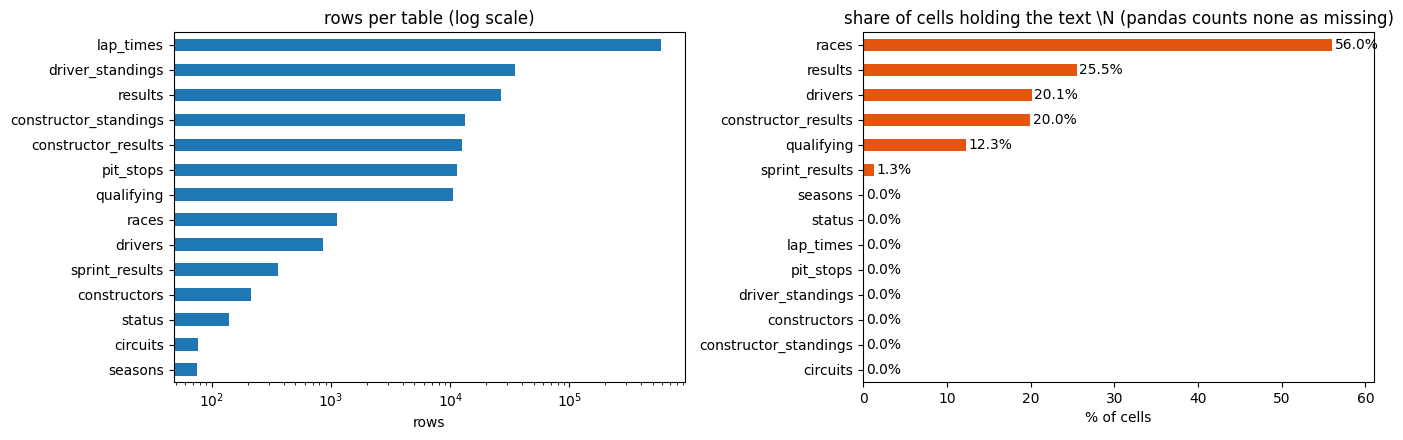

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pre_overview['rows'].sort_values().plot.barh(ax=axes[0], logx=True)
axes[0].set_title('rows per table (log scale)')
axes[0].set_xlabel('rows')

pre_share = (100 * pre_overview['cells with \\N'] / (pre_overview['rows'] * pre_overview['columns'])).sort_values()
pre_share.plot.barh(ax=axes[1], color='#e6550d')
for i, v in enumerate(pre_share):
    axes[1].text(v + 0.3, i, f'{v:.1f}%', va='center')
axes[1].set_xlim(0, pre_share.max() + 5)
axes[1].set_title('share of cells holding the text \\N (pandas counts none as missing)')
axes[1].set_xlabel('% of cells')

plt.tight_layout()
plt.show()

## 1.2 Coverage over time

For each table with a `raceId`, the share of each season's races that have at least one row in the table (1 = every race, 0 = none). The five tables without a `raceId` (circuits, constructors, drivers, seasons, status) are not about single races, and `races` is the list of races itself, so they are left out.

**Why the share of races, not the number of rows.** The number of rows depends on how many cars raced and on what one row is (a lap, a pit stop, a result). The share of races means the same thing in every table and every season.

**Why it matters.** A feature built from a table is empty in every season the table does not cover.

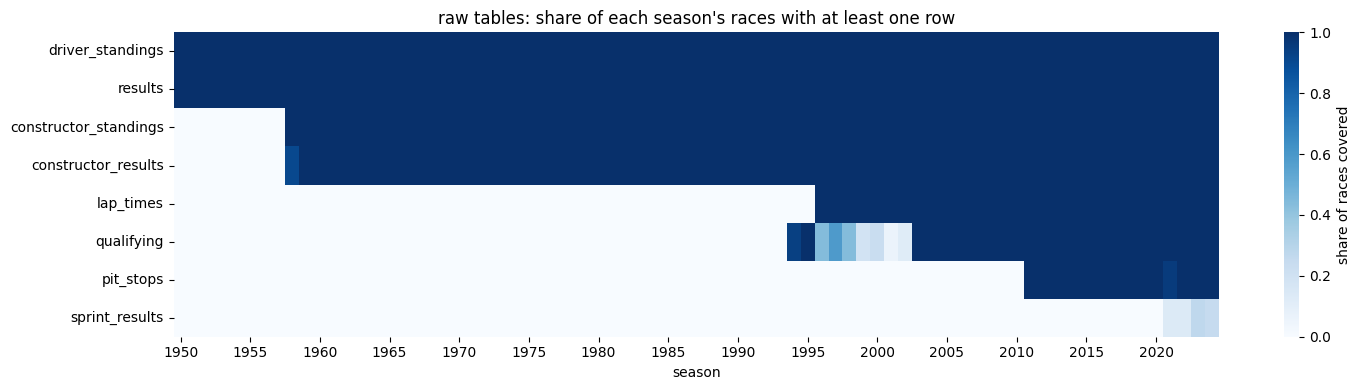

,first season
driver_standings,1950
results,1950
constructor_standings,1958
constructor_results,1958
lap_times,1996
qualifying,1994
pit_stops,2011
sprint_results,2021


qualifying, % of races covered: {1994: 94, 1995: 100, 1996: 44, 1997: 59, 1998: 44, 1999: 19, 2000: 24, 2001: 6, 2002: 12, 2003: 100}


In [8]:
# which seasons each table covers: share of a season's races with at least one row in the table
pre_races = raw_before['races'][['raceId', 'year']]
pre_per_season = pre_races.groupby('year').size()

pre_cov = pd.DataFrame({
    name: (df[['raceId']].drop_duplicates().merge(pre_races, on='raceId')
           .groupby('year').size().reindex(pre_per_season.index, fill_value=0) / pre_per_season)
    for name, df in raw_before.items() if 'raceId' in df.columns and name != 'races'}).T
pre_cov = pre_cov.loc[pre_cov.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(15, 4))
sns.heatmap(pre_cov, cmap='Blues', vmin=0, vmax=1, xticklabels=5,
            cbar_kws={'label': 'share of races covered'})
plt.title("raw tables: share of each season's races with at least one row")
plt.xlabel('season')
plt.ylabel('')
plt.tight_layout()
plt.show()

# first season with any row, per table
display(pre_cov.apply(lambda r: r[r > 0].index.min(), axis=1).rename('first season').to_frame())

# qualifying in its first seasons: % of each season's races covered
print('qualifying, % of races covered:', (100 * pre_cov.loc['qualifying', 1994:2003]).round().astype(int).to_dict())

## 1.3 The target and the grain

The target is a podium: `positionOrder` <= 3. Three checks on the raw `results`:
- how rare a podium is, overall and per decade;
- whether the table is already one row per driver per race, as the brief asks;
- whether every race has exactly 3 podium rows, as it should.

**Why these checks.** A rare target changes how the models are scored, and repeated rows or extra podium rows would give wrong labels.

result rows: 26759 | podium rows: 3397 | podium rate: 12.7%
repeated (raceId, driverId) pairs: 85 | rows in them: 176 | extra rows: 91
races by number of podium rows: {3: 1107, 4: 16, 5: 1, 7: 1}
races with more than 3 podium rows: 18 | seasons: 1950 to 1960


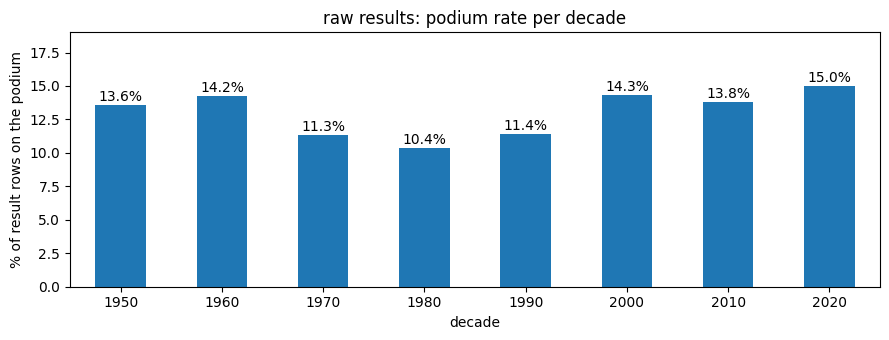

In [9]:
# the target in the raw results: how rare is a podium, is the grain already one row per driver per race,
# and does every race have exactly 3 podium rows?
pre_res = raw_before['results'].merge(raw_before['races'][['raceId', 'year']], on='raceId')
pre_res['podium'] = pre_res.positionOrder <= 3

print('result rows:', len(pre_res), '| podium rows:', int(pre_res.podium.sum()),
      f'| podium rate: {pre_res.podium.mean():.1%}')

# repeated (raceId, driverId) pairs: the rows in them, and the extra rows if one row per pair is kept
pre_pairs = pre_res.groupby(['raceId', 'driverId']).size()
print('repeated (raceId, driverId) pairs:', int((pre_pairs > 1).sum()),
      '| rows in them:', int(pre_pairs[pre_pairs > 1].sum()),
      '| extra rows:', int((pre_pairs[pre_pairs > 1] - 1).sum()))

# podium rows per race (should always be 3)
pre_pod_race = pre_res.groupby('raceId').podium.sum()
pre_more = pre_res[pre_res.raceId.isin(pre_pod_race[pre_pod_race > 3].index)]
print('races by number of podium rows:', pre_pod_race.value_counts().sort_index().to_dict())
print('races with more than 3 podium rows:', pre_more.raceId.nunique(),
      '| seasons:', pre_more.year.min(), 'to', pre_more.year.max())

pre_rate = pre_res.groupby(pre_res.year // 10 * 10).podium.mean() * 100
ax = pre_rate.plot.bar(rot=0, figsize=(9, 3.5))
for i, v in enumerate(pre_rate):
    ax.text(i, v + 0.3, f'{v:.1f}%', ha='center')
ax.set_ylim(0, pre_rate.max() + 4)
plt.xlabel('decade')
plt.ylabel('% of result rows on the podium')
plt.title('raw results: podium rate per decade')
plt.tight_layout()
plt.show()

## 1.4 What the raw data shows, and what it means for the cleaning

**Hidden missing values.** Six tables hold the text `\N` in place of a missing value: `races` (56.0% of its cells), `results` (25.5%), `drivers` (20.1%), `constructor_results` (20.0%), `qualifying` (12.3%) and `sprint_results` (1.3%). pandas counts none of them as missing, and it reads every column that contains `\N` as text, so 8 of the 9 text columns in `results` and 11 of the 14 in `races` are text only because of `\N` (the others are text by nature, such as names, dates and `positionText`). `qualifying` is the only table where pandas already sees missing values: 68 cells of `q2` and `q3`, all in 2023 and 2024, are left empty instead of holding `\N`, so the file marks a missing time in two ways. → Every table is read with `\N` as missing (`load()`), which also keeps the empty cells as missing, and the types are checked again table by table in section 2.

**Coverage over time.** `results` and `driver_standings` cover every season from 1950. The constructor tables start in 1958, `qualifying` in 1994 (94% of the races in 1994 and all of them in 1995, then only 6–59% per season until 2002, and every race from 2003), `lap_times` in 1996, `pit_stops` in 2011 and `sprint_results` in 2021, and only a few races per season have a sprint. → A feature built from one of these tables is empty before its first season, so the coverage is checked for each table in section 2 and decides the training window.

**The target.** 3,397 of the 26,759 result rows (12.7%) are podiums, between 10.4% (1980s) and 15.0% (2020s) per decade, so the positive class is rare in every era. 176 rows sit in 85 repeated (`raceId`, `driverId`) pairs, so the table is not yet one row per driver per race; keeping one row per pair removes 91 rows. Also, 18 races, all between 1950 and 1960, have more than 3 podium rows. → The duplicates are handled first, in the `results` part of section 2, which also explains the races with more than 3 podium rows (*Summary of anomaly checks*).

# 2. Audit and cleaning, table by table

Each table follows the same steps: look at the data, state the problem, decide, fix, and check the fix. Type conversions are made next to the check that showed they were needed.

Only the duplicate driver-race rows are removed in this section, because every later join needs one row per driver per race. Rows that do not belong in the modelling table (`failed_to_qualify`, `is_indy500`) are flagged here and removed in 9.1, when the modelling table is built after the history features, so they still count in a driver's history.

## `Results Table`

In [10]:
raw_before['results'].head(10)

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1
5,6,18,6,3,8,13,6,6,6,3.0,57,\N,\N,50,14,1:29.639,212.974,11
6,7,18,7,5,14,17,7,7,7,2.0,55,\N,\N,54,8,1:29.534,213.224,5
7,8,18,8,6,1,15,8,8,8,1.0,53,\N,\N,20,4,1:27.903,217.180,5
8,9,18,9,2,4,2,\N,R,9,0.0,47,\N,\N,15,9,1:28.753,215.100,4
9,10,18,10,7,12,18,\N,R,10,0.0,43,\N,\N,23,13,1:29.558,213.166,3


In [11]:
raw_before['results'].dtypes

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number              object
grid                 int64
position            object
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds        object
fastestLap          object
rank                object
fastestLapTime      object
fastestLapSpeed     object
statusId             int64
dtype: object

In [12]:
raw_before['results'].isna().sum()    

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

In [13]:
# but there are \N values in the cells, so let us count them
(raw_before['results'] == '\\N').sum()             

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

### results: types and missing values

*Hypothesis: the `\N` text is why pandas reports 0 missing values and reads some numeric columns as `object`.*

*Prediction: after reading `\N` as missing, the missing counts will equal the `\N` counts, and some `object` columns will become numeric.*

In [14]:
results = load('results')

In [15]:
before = raw_before['results']

cmp = pd.DataFrame({
    'dtype_before':   before.dtypes.astype(str),
    'dtype_after':    results.dtypes.astype(str),
    'missing_before': before.isna().sum(),          
    'sentinel_before': (before == '\\N').sum(),     
    'missing_after':  results.isna().sum(),         
})
cmp

,dtype_before,dtype_after,missing_before,sentinel_before,missing_after
resultId,int64,int64,0,0,0
raceId,int64,int64,0,0,0
driverId,int64,int64,0,0,0
constructorId,int64,int64,0,0,0
number,object,float64,0,6,6
grid,int64,int64,0,0,0
position,object,float64,0,10953,10953
positionText,object,object,0,0,0
positionOrder,int64,int64,0,0,0
points,float64,float64,0,0,0


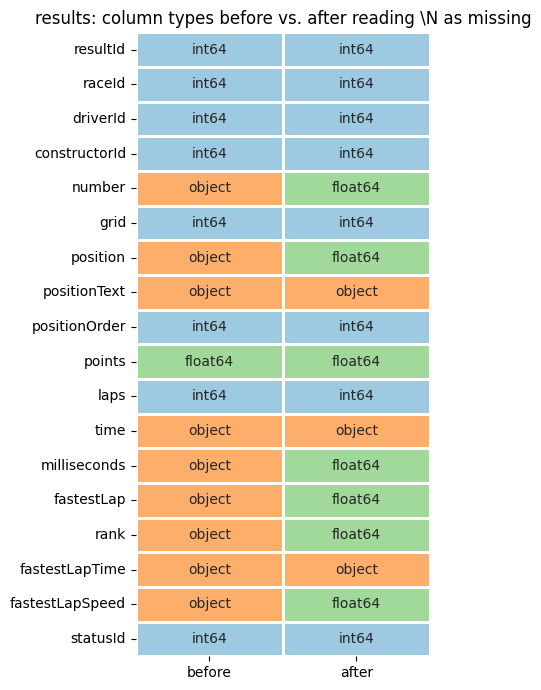

In [16]:
# more clear visualization 
before = raw_before['results'].dtypes.astype(str)
after = results.dtypes.astype(str)
types = pd.DataFrame({'before': before, 'after': after})

codes = {'int64': 0, 'float64': 1, 'object': 2}
num = types.apply(lambda s: s.map(lambda t: codes.get(t, 3)))   # 3 = any other type

plt.figure(figsize=(4.5, 7))
sns.heatmap(num, annot=types, fmt='', cbar=False, linewidths=1, linecolor='white',
            cmap=ListedColormap(['#9ecae1', '#a1d99b', '#fdae6b', '#d9d9d9']),
            vmin=0, vmax=3)
plt.title('results: column types before vs. after reading \\N as missing')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [17]:
# the missing values per column in the results table
results.isna().sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

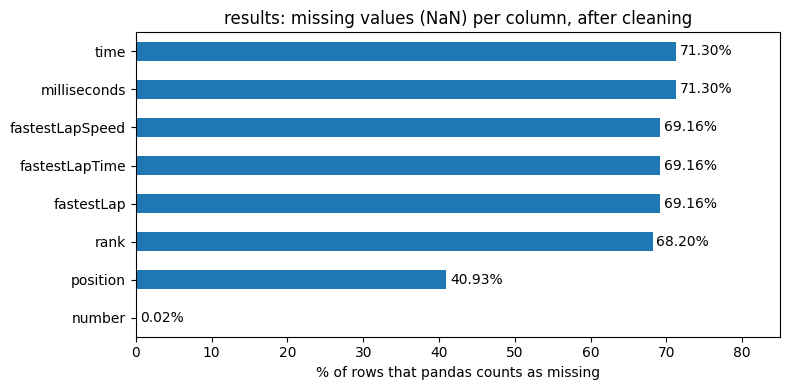

In [18]:
# visualization
pct_after = (results.isna().mean() * 100)
pct_after = pct_after[pct_after > 0].sort_values()

ax = pct_after.plot.barh(figsize=(8, 4))
for i, v in enumerate(pct_after):
    ax.text(v + 0.5, i, f'{v:.2f}%', va='center')

ax.set_xlim(0, 85)
plt.xlabel('% of rows that pandas counts as missing')
plt.title('results: missing values (NaN) per column, after cleaning')
plt.tight_layout()
plt.show()

### results: columns that are still `object` after reading `\N` as missing

After the reload, only three columns remain `object`: `positionText`, `time` and `fastestLapTime`.

- `positionText` holds codes (R, F, W, D, E, N, or a number), so text is its correct type. It is analysed separately.
- `time` and `fastestLapTime` hold durations written as strings, so they need a closer look.

**Method:** replace every digit with a `9` and count how many rows share each string pattern. This shows how many different formats a column contains without reading rows by eye.

In [19]:
for col in ['fastestLapTime', 'time']:
    shapes = (results[col].dropna()
              .str.replace(r'\d', '9', regex=True)
              .value_counts())
    print(col, '-', len(shapes), 'different shapes,', shapes.sum(), 'rows')
    print(shapes.to_string(), '\n')
    # checking if the column hold consistent format for the data
    # fastestLapTime does while time does not as mentioned in the guide
    # A leading + means a gap from winner
    # no + means the winner's full time. One column holds two different meanings.

fastestLapTime - 1 different shapes, 8252 rows
fastestLapTime
9:99.999    8252 

time - 21 different shapes, 7680 rows
time
+99.999        2973
+9:99.999      1614
9:99:99.999     765
+9.999          732
+9:99.99        281
+9:99.9         279
+99.9           259
+99.99          243
9:99:99.9       242
9:99:99.99      118
+9.9             73
+9.99            68
+99:99.99        13
+999.999         10
+99:99.9          3
+9:99.9999        2
99:99.999         1
99:99.9           1
+9:99             1
9:99.999          1
+99.9999          1 



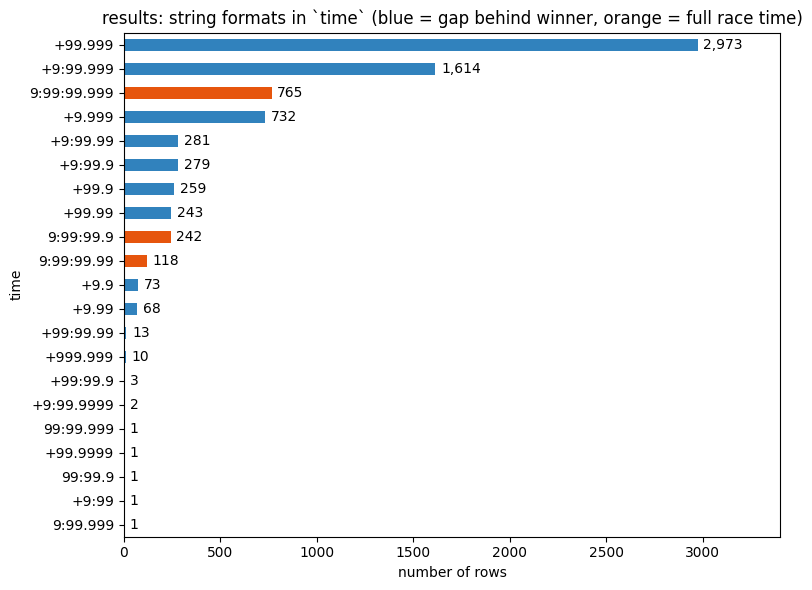

In [20]:
shapes = (results['time'].dropna()
          .str.replace(r'\d', '9', regex=True)
          .value_counts()
          .sort_values())

colors = ['#3182bd' if s.startswith('+') else '#e6550d' for s in shapes.index]

ax = shapes.plot.barh(figsize=(8, 6), color=colors)
for i, v in enumerate(shapes):
    ax.text(v + 30, i, f'{v:,}', va='center')

ax.set_xlim(0, 3400)
plt.xlabel('number of rows')
plt.title('results: string formats in `time` (blue = gap behind winner, orange = full race time)')
plt.tight_layout()
plt.show()

### `time`: what the string formats mean

**Two kinds of values share one column**
- **Leading `+` (6,552 rows):** the gap between this driver and the race winner, e.g. `+5.478` means 5.478 seconds behind.
- **No `+` (1,128 rows):** a full race time, which is the winner's total time, e.g. `1:34:50.616`.

So `time` mixes a duration and a difference in one column, which is why it cannot be treated as a single numeric field.

**Why there are 21 formats: the values are not zero-padded**
The strings are written at their natural length, so the pattern changes with the size of the number. Looking at the gaps by magnitude:
- under 10 seconds, `+9.999`: 873 rows
- 10 to 99 seconds, `+99.999`: 3,476 rows
- 1 to 9 minutes, `+9:99.999`: 2,177 rows
- 10 minutes or more, `+99:99.999`: 16 rows
- 100 seconds or more written as seconds, `+999.999`: 10 rows

Full race times follow the same logic: `9:99:99.999` has hours, while a few short races have no hours (`99:99.999`, 3 rows).

**The number of decimals also varies (0 to 4)**
Most rows have 3 decimals, but many have 1 or 2, and a handful have 0 or 4. We have not checked why. One possible explanation is that precision changed between eras, but that needs a check by season before we claim it.

**Decision**
Parsing would need a separate rule for each combination of hours, minutes, sign and decimals, and the result would duplicate `milliseconds`, which already holds the race duration as a number. We keep `time` as text and use `milliseconds`. `time` is a post-race column, so it is never used as a feature.

**Still to confirm:** that `time` and `milliseconds` are missing in the same rows, meaning they agree.

In [21]:
print('same rows missing:', (results.time.isna() == results.milliseconds.isna()).all())

same rows missing: True


**Decision:** keep `time` as text and use `milliseconds` as the numeric race duration. The dataset documentation (Kaggle) describes `milliseconds` as the finishing time in milliseconds, and `time` mixes full race times and gaps in 21 formats. Both are post-race columns and are never used as features, so we did not verify the two against each other any further.

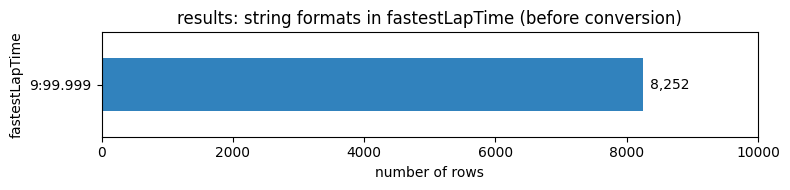

In [22]:
shapes_f = (results['fastestLapTime'].dropna()
            .str.replace(r'\d', '9', regex=True)
            .value_counts()
            .sort_values())

ax = shapes_f.plot.barh(figsize=(8, 2), color='#3182bd')
for i, v in enumerate(shapes_f):
    ax.text(v + 100, i, f'{v:,}', va='center')

ax.set_xlim(0, 10000)
plt.xlabel('number of rows')
plt.title('results: string formats in fastestLapTime (before conversion)')
plt.tight_layout()
plt.show()

### `fastestLapTime`

**Finding:** all 8,252 non-missing values share a single pattern (`9:99.999`, i.e. minutes:seconds.milliseconds, like "1:27.452"). This equals 26,759 rows minus 18,507 missing values, so no values are hidden.

**Decision:** convert it to numeric seconds in a new column, `fastestLapTime_s` (minutes × 60 + seconds). Because there is only one format, a single rule covers every row. This is the "lap-time strings to numeric seconds" step the brief asks for.

In [23]:
parts = results['fastestLapTime'].str.split(':', expand=True)
results['fastestLapTime_s'] = parts[0].astype(float) * 60 + parts[1].astype(float)

In [24]:
print('non-missing before:', results['fastestLapTime'].notna().sum())
print('non-missing after: ', results['fastestLapTime_s'].notna().sum())
results['fastestLapTime_s'].describe()

non-missing before: 8252
non-missing after:  8252


count    8252.000000
mean       90.827595
std        12.338956
min        55.404000
25%        80.848250
50%        90.267500
75%        99.476750
max       202.300000
Name: fastestLapTime_s, dtype: float64

### `positionText`

This is the last of the three columns that stayed `object` after reading `\N` as missing (the other two, `time` and `fastestLapTime`, are covered above). Its text type is correct, because it holds codes and not numbers. What makes it worth a closer look is that it seems to explain why `position` is empty in 10,953 rows (41%).

According to the course's F1 introduction, `positionText` holds the position as text, or a letter code when the driver has no official position:

| Code | Meaning |
|---|---|
| R | Retired (and not classified, see note) |
| D | Disqualified |
| E | Excluded |
| W | Withdrawn |
| F | Failed to qualify |
| N | Not classified |

**Note:** a driver can retire and still be classified, getting a numeric `position`, if they completed at least 90% of the winner's laps. So `R` only appears for retirements without an official position. We rely on the course description for this and did not verify it against `status`.

**Hypothesis:** a missing `position` always comes with a letter in `positionText`, and a filled `position` always comes with a number.

**Prediction:** a cross-tabulation of "`position` is missing" against "`positionText` is a number" will have two empty cells: missing with a number, and filled with a letter.

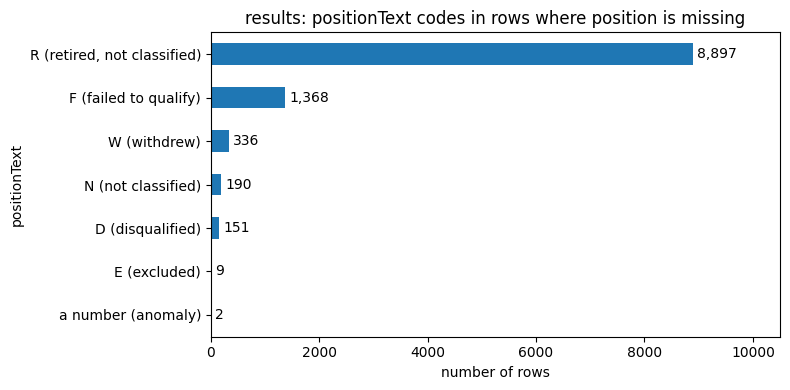

In [25]:
miss = results[results.position.isna()].copy()

def label(code):
    names = {'R': 'R (retired, not classified)', 'F': 'F (failed to qualify)', 'W': 'W (withdrew)',
             'N': 'N (not classified)', 'D': 'D (disqualified)', 'E': 'E (excluded)'}
    return names.get(code, 'a number (anomaly)')

counts = miss.positionText.map(label).value_counts().sort_values()

ax = counts.plot.barh(figsize=(8, 4))
for i, v in enumerate(counts):
    ax.text(v + 80, i, f'{v:,}', va='center')

ax.set_xlim(0, 10500)
plt.xlabel('number of rows')
plt.title('results: positionText codes in rows where position is missing')
plt.tight_layout()
plt.show()

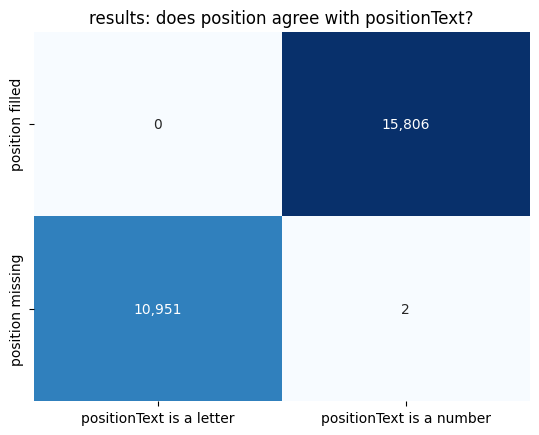

In [26]:
df = results
ct = pd.crosstab(df.position.isna(), df.positionText.str.isdigit())
ct.index = ['position filled', 'position missing']
ct.columns = ['positionText is a letter', 'positionText is a number']

sns.heatmap(ct, annot=True, fmt=',d', cmap='Blues', cbar=False)
plt.title('results: does position agree with positionText?')
plt.ylabel('')
plt.xlabel('')
plt.show()

### The 2 rows where `position` is missing but `positionText` is a number

The crosstab shows 2 rows where `position` is empty even though `positionText` holds a number.

**Question:** are these drivers classified or not?

**What we check:** their `status` (how the race ended), their `grid` (whether they took the start) and their `laps` compared with the winner's laps (the course's F1 introduction says classification requires completing at least 90% of the winner's laps).

In [27]:
odd = results[results.position.isna() & results.positionText.str.isdigit()]

winner_laps = results.groupby('raceId').laps.max()          # most laps completed in each race
out = (odd.merge(raw_before['races'][['raceId', 'year', 'name']], on='raceId')
          .merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
          .merge(raw_before['status'], on='statusId'))

out['race_laps'] = out.raceId.map(winner_laps)
out['pct_of_race'] = (100 * out.laps / out.race_laps).round(1)

out[['year', 'name', 'surname', 'status', 'grid', 'laps', 'race_laps', 'pct_of_race', 'positionText', 'positionOrder']]

,year,name,surname,status,grid,laps,race_laps,pct_of_race,positionText,positionOrder
0,2005,Australian Grand Prix,Button,+1 Lap,8,56,57,98.2,11,11
1,2005,Australian Grand Prix,Sato,+2 Laps,20,55,57,96.5,14,14


**Result:** both rows are from the 2005 Australian Grand Prix. Button (grid 8) finished 11th, one lap down (56 of 57 laps, 98.2%), and Sato (grid 20) finished 14th, two laps down (55 of 57 laps, 96.5%). Both took the start, both reached the flag with status "+1 Lap" and "+2 Laps", and both completed more than 90% of the race distance. Their `positionText` and `positionOrder` agree. They are therefore classified finishers whose `position` value is missing from the dataset, not unclassified drivers.

**Decision:** this is a data gap in `position` only. The target is built from `positionOrder`, which is complete and consistent for these rows, so the target is unaffected. We leave `position` as missing and document the two rows.

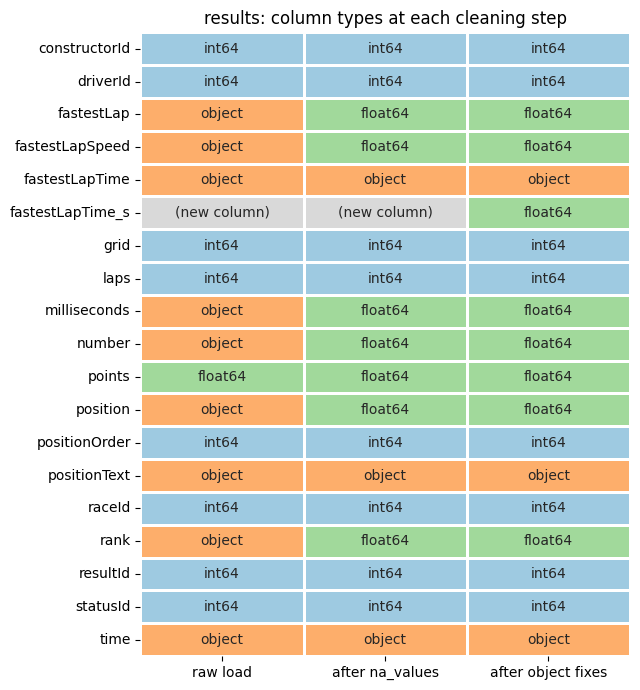

In [28]:
stage1 = raw_before['results'].dtypes.astype(str)
stage2 = results.drop(columns='fastestLapTime_s').dtypes.astype(str)   # state right after the na_values reload
stage3 = results.dtypes.astype(str)                                    # now, after the object investigation

types = pd.DataFrame({'raw load': stage1,
                      'after na_values': stage2,
                      'after object fixes': stage3}).fillna('(new column)')

codes = {'int64': 0, 'float64': 1, 'object': 2}
num = types.apply(lambda s: s.map(lambda t: codes.get(t, 3)))   # 3 = new column

plt.figure(figsize=(6.5, 7))
sns.heatmap(num, annot=types, fmt='', cbar=False, linewidths=1, linecolor='white',
            cmap=ListedColormap(['#9ecae1', '#a1d99b', '#fdae6b', '#d9d9d9']),
            vmin=0, vmax=3)
plt.title('results: column types at each cleaning step')
plt.ylabel('')
plt.tight_layout()
plt.show()

### results: remaining missing values

After reading `\N` as missing, seven columns still contain missing values: `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed` and `number`. (`position` is covered in its own section.)

**Six of them describe the outcome of the race itself** (`time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`). They are not known at the prediction cutoff (after qualifying, before the race starts), so using them would be data leakage and they cannot be features. We leave them as missing and do not fill them: filling columns we never use adds nothing, and for the race columns it would invent results that did not happen.

**`number` is different.** It is the car number, which is not an outcome of the race, so the leakage argument does not apply to it. It is missing in only 6 rows. Before deciding what to do, we look at which rows they are.

In [29]:
missing_num = results[results.number.isna()]

(missing_num.merge(raw_before['races'][['raceId', 'year', 'name']], on='raceId')
            .merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
            .merge(raw_before['constructors'][['constructorId', 'name']], on='constructorId', suffixes=('_race', '_team'))
            .merge(raw_before['status'], on='statusId')
            [['year', 'name_race', 'surname', 'name_team', 'grid', 'positionText', 'status', 'positionOrder']])

,year,name_race,surname,name_team,grid,positionText,status,positionOrder
0,1962,French Grand Prix,Marsh,BRM,0,W,Withdrew,19
1,1962,French Grand Prix,Davis,Porsche,0,W,Withdrew,20
2,1962,French Grand Prix,Abate,Lotus-Climax,0,W,Withdrew,21
3,1962,French Grand Prix,Burgess,Cooper-Climax,0,W,Withdrew,22
4,1961,French Grand Prix,Bordeu,Lotus-Climax,0,W,Withdrew,28
5,1963,South African Grand Prix,Hailwood,Lola,0,W,Withdrew,23


**Result:** the 6 rows with a missing `number` are all from the early 1960s (1961 to 1963). All have `positionText` = `W` and `status` = Withdrew, and all have `grid` = 0, even though `grid` has no `\N`. This suggests the missing `number` may be related to these drivers having withdrawn, but the data does not say why no car number was recorded.

**Next question:** `grid` normally starts at 1 (pole position), so a value of 0 is unusual. The course's F1 introduction says a `grid` of 0 may mean a pit-lane start ("verify in EDA"). The rows above are drivers who withdrew, which does not look like a pit-lane start, so we will need to investigate what `grid` = 0 means in `results` as a whole.

**Decision for `number`:** leave as missing, no fill. It is an identifier and not a feature.

### results: one row per driver per race

Each row of the modelling table is one prediction: "will this driver finish on the podium in this race?" That requires the pair (`raceId`, `driverId`) to be unique. The course material says duplicates come from shared drives in early F1 (mainly the 1950s), when drivers swapped cars mid-race, so a driver can have two result rows in one race.

**Question:** how many pairs appear more than once, and in which years?

**Method:** count the rows whose (`raceId`, `driverId`) pair occurs more than once.

,duplicated pairs,rows involved
2 rows for the same driver in one race,79,158
3 rows for the same driver in one race,6,18
Total,85,176


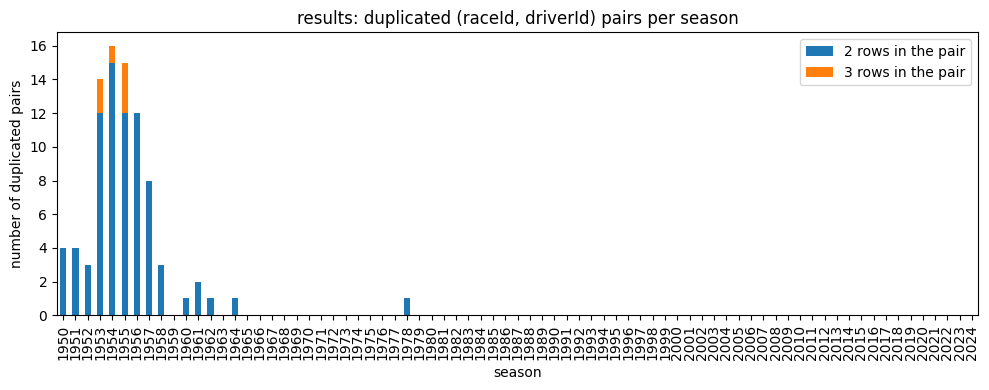

In [30]:
dup_rows = results[results.duplicated(['raceId', 'driverId'], keep=False)].merge(
    raw_before['races'][['raceId', 'year']], on='raceId')

# one line per duplicated pair, with how many rows it has
pair_size = (dup_rows.groupby(['raceId', 'driverId', 'year']).size()
                     .rename('rows_in_pair').reset_index())

# Table: how many pairs have 2 rows, how many have 3
summary = (pair_size.groupby('rows_in_pair').size().rename('duplicated pairs').to_frame()
           .assign(**{'rows involved': lambda d: d['duplicated pairs'] * d.index}))
summary.index = [f'{i} rows for the same driver in one race' for i in summary.index]
summary.loc['Total'] = summary.sum()
display(summary)

# Chart: duplicated pairs per season, split by 2 or 3 rows
per_year = pair_size.groupby(['year', 'rows_in_pair']).size().unstack(fill_value=0)
all_years = raw_before['races'].year
per_year = per_year.reindex(range(all_years.min(), all_years.max() + 1), fill_value=0)
per_year.columns = [f'{c} rows in the pair' for c in per_year.columns]

ax = per_year.plot.bar(stacked=True, figsize=(10, 4))
plt.xlabel('season')
plt.ylabel('number of duplicated pairs')
plt.title('results: duplicated (raceId, driverId) pairs per season')
plt.tight_layout()
plt.show()

In [31]:
pairs = (results[results.duplicated(['raceId', 'driverId'], keep=False)]
         .merge(raw_before['races'][['raceId', 'year']], on='raceId')
         .groupby(['raceId', 'driverId', 'year']).size()
         .rename('rows').reset_index())

print('duplicated pairs:', len(pairs), '| rows involved:', pairs.rows.sum())
print(pairs.rows.value_counts().sort_index().rename('pairs').rename_axis('rows in the pair'))

per_year = pairs.groupby('year').size()
print('pairs from 1950 to 1957:', (pairs.year <= 1957).sum())
print('pairs after 1957:       ', (pairs.year > 1957).sum())
print('peak season:', per_year.idxmax(), 'with', per_year.max(), 'pairs')

print('\npairs after 1957, per season:')
print(pairs[pairs.year > 1957].groupby('year').size().to_string())

duplicated pairs: 85 | rows involved: 176
rows in the pair
2    79
3     6
Name: pairs, dtype: int64
pairs from 1950 to 1957: 76
pairs after 1957:        9
peak season: 1954 with 16 pairs

pairs after 1957, per season:
year
1958    3
1960    1
1961    2
1962    1
1964    1
1978    1


**Result:** (`raceId`, `driverId`) is not unique in `results`: 85 pairs (176 rows) appear more than once. 79 pairs have 2 rows and 6 pairs have 3 rows (all from 1953 to 1955). 76 of the 85 pairs are from 1950 to 1957, with the peak in 1954 (16 pairs), as the course material says. The other 9 pairs are from 1958 to 1978 and are examined separately below.

**Next questions:**
1. What does a duplicated pair look like in the data (grid, laps, position, points)?
2. What are the 9 pairs after 1957, and why do they exist?

In [32]:
look = (dup_rows.merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
                .merge(raw_before['races'][['raceId', 'name']].rename(columns={'name': 'race'}), on='raceId')
                .merge(raw_before['constructors'][['constructorId', 'name']].rename(columns={'name': 'team'}), on='constructorId')
                .merge(raw_before['status'], on='statusId')
                .sort_values(['year', 'raceId', 'driverId']))

cols = ['year', 'race', 'surname', 'team', 'grid', 'laps', 'positionText', 'positionOrder', 'points', 'status']

look[cols].head(12)

,year,race,surname,team,grid,laps,positionText,positionOrder,points,status
84,1950,Indianapolis 500,Bettenhausen,Deidt,8,30,R,31,0.0,Wheel bearing
88,1950,Indianapolis 500,Bettenhausen,Kurtis Kraft,9,136,5,5,1.0,+2 Laps
85,1950,French Grand Prix,Rosier,Talbot-Lago,6,10,R,12,0.0,Overheating
89,1950,French Grand Prix,Rosier,Talbot-Lago,15,56,6,6,0.0,+8 Laps
86,1950,Italian Grand Prix,Fangio,Alfa Romeo,1,23,R,15,1.0,Gearbox
91,1950,Italian Grand Prix,Fangio,Alfa Romeo,7,34,R,13,0.0,Engine
87,1950,Italian Grand Prix,Ascari,Ferrari,2,21,R,17,0.0,Engine
90,1950,Italian Grand Prix,Ascari,Ferrari,6,80,2,2,3.0,Finished
81,1951,French Grand Prix,Fangio,Alfa Romeo,1,55,11,11,0.0,+22 Laps
92,1951,French Grand Prix,Fangio,Alfa Romeo,7,77,1,1,5.0,Finished


**What a duplicated pair looks like:** we looked at the first 12 rows (6 pairs, from 1950 and 1951). In each pair the same driver appears twice in the same race, with different `grid` slots, different `laps`, and different results. In 5 of the 6 pairs, one row has far fewer laps and a retirement or a poor finish, while the other row has many more laps and a better finish. For example, Fangio (1951 French GP) has one row with 55 laps (11th) and another with 77 laps (1st, 5 points), and Ascari (1950 Italian GP) has a retirement after 21 laps and a 2nd place after 80 laps. In the sixth pair (Fangio, 1950 Italian GP) both rows are retirements, with 23 and 34 laps.

This is consistent with the shared drives described in the course's F1 introduction, where a driver's own car stops, and he continues the race in another car, getting a better result. The data does not state this directly, so it is our reading of the pattern. It also shows that the two rows of a pair are results of two different cars, so each row has its own `grid`, `laps` and `positionOrder`, and we have to choose which one stands for the driver in that race.

**Limit:** this reading is based on 6 of the 85 pairs. The next cell checks one part of it on all 85 pairs: whether the row with the best finish is also the row with the most laps.

In [33]:
d = dup_rows.copy()
g = d.groupby(['raceId', 'driverId'])

d['best_finish'] = d.positionOrder == g.positionOrder.transform('min')
d['most_laps']   = d.laps == g.laps.transform('max')

# per pair: does the best-finish row also have the most laps?
agree = d[d.best_finish].groupby(['raceId', 'driverId', 'year']).most_laps.any().rename('same_row').reset_index()

print(agree.same_row.value_counts().rename({True: 'best finish = most laps', False: 'different rows'}))

same_row
best finish = most laps    85
Name: count, dtype: int64


**Result:** in all 85 duplicated pairs, the row with the best `positionOrder` is also the row with the most laps. The rules "keep the best finish" and "keep the most laps" therefore choose the same row in every case.

**Consequence:** the choice between these two rules does not change the table. We can use either one, and we pick the one that is easier to justify.

In [34]:
print('pairs after 1957:', (pair_size.year > 1957).sum())
look[look.year > 1957][cols]

pairs after 1957: 9


,year,race,surname,team,grid,laps,positionText,positionOrder,points,status
9,1958,Monaco Grand Prix,Flockhart,Cooper,0,0,F,17,0.0,Did not qualify
10,1958,Monaco Grand Prix,Flockhart,BRM,0,0,F,27,0.0,Did not qualify
11,1958,French Grand Prix,Brooks,Vanwall,5,16,R,18,0.0,Engine
171,1958,French Grand Prix,Brooks,Vanwall,10,35,R,14,0.0,Engine
12,1958,Italian Grand Prix,Shelby,Maserati,17,1,R,18,0.0,Handling
172,1958,Italian Grand Prix,Shelby,Maserati,11,69,4,4,0.0,+1 Lap
8,1960,Argentine Grand Prix,Moss,Cooper-Climax,1,40,R,17,0.0,Suspension
173,1960,Argentine Grand Prix,Moss,Cooper-Climax,8,80,3,3,0.0,Finished
5,1961,British Grand Prix,Moss,Ferguson,20,56,D,19,0.0,Disqualified
6,1961,British Grand Prix,Moss,Lotus-Climax,5,44,R,21,0.0,Brakes


### The 9 duplicated pairs after 1957

The course's F1 introduction says shared drives were possible until 1957, but 9 duplicated pairs fall after that. Three in 1958, one in 1960, two in 1961, one in 1962, one in 1964 and one in 1978. We read all 18 rows. They fall into two groups.

**Group 1: both rows have laps (6 pairs)**
Brooks (1958 French GP), Shelby (1958 Italian GP), Moss (1960 Argentine GP), Moss (1961 British GP), Gregory (1961 United States GP) and Clark (1964 United States GP).
- Each row has its own `grid` slot, `laps` and result, so each is the result of one car.
- In every pair, the row with more laps also has the better `positionOrder`. For example, Moss (1960) has one row with 40 laps (retired) and one with 80 laps (3rd), and Shelby (1958) has one with 1 lap (retired) and one with 69 laps (4th).
- In 5 of the 6 pairs both rows belong to the same team. The exception is Moss (1961 British GP), with one row for Ferguson and one for Lotus-Climax.
- This is the same pattern as the 1950s pairs, so these are probably shared drives that happened after 1957. The data does not state that, so it is our reading.
- Two pairs are worth a note. Moss (1961) has a row with 56 laps and the status Disqualified (`grid` 20), and a row with 44 laps and a retirement (`grid` 5). The data does not say whether the disqualification came during or after the race. Clark (1964) has `grid` 1 in both rows (102 laps, 7th, Out of fuel; 54 laps, retired, Injection). One driver cannot start from the same slot in two cars, so at least one of the two grid values is unreliable, and the data does not say which. The starting slot therefore cannot tell the two rows apart.

**Group 2: `grid` = 0 and 0 laps in both rows (3 pairs)**
Flockhart (1958 Monaco GP), Greene (1962 British GP) and Ertl (1978 Italian GP).
- Each driver appears twice with a different team: Cooper and BRM, Lotus-Climax and Gilby, ATS and Ensign.
- The statuses are Did not qualify (Flockhart, both rows), Withdrew (Greene, both rows) and Did not qualify and Did not prequalify (Ertl).
- These drivers were entered with two cars and did not start in either. They are not shared drives. This explains the 1978 pair.

**Consequence for the keep rule:** the 3 pairs in group 2 cannot be separated by laps, since both rows have 0, and the keep rule simply keeps one of the two rows. Two of the three drivers failed to qualify, so they leave the modelling table anyway (*Decision: who is removed*).

In [35]:
print('pairs with equal positionOrder:', (results[results.duplicated(['raceId', 'driverId'], keep=False)]
      .groupby(['raceId', 'driverId']).positionOrder.nunique() == 1).sum())

pairs with equal positionOrder: 0


### Keep rule for duplicated pairs

**Rule:** for each (`raceId`, `driverId`), keep the row with the best `positionOrder` (the lowest number).

**Why:**
- In all 85 duplicated pairs, the row with the best `positionOrder` is also the row with the most laps, so "best finish" and "most laps" give the same table.
- Within the 85 pairs, no two rows share the same `positionOrder` (checked), so the rule always selects exactly one row and needs no tie-breaker.
- It does not use `grid`, which is unreliable inside a pair (Clark, 1964, has `grid` 1 in both rows).
- It does not change the model or Q1 and Q3. All 85 pairs are from 1950 to 1978, so none is in the seasons the model uses (2003–2024), in Q1 (from 1980) or in Q3 (from 2014).

**Order:** the rule is applied first, before any history features are built, because a driver with two rows in one race would otherwise be counted twice. The raw `results` table is left unchanged, and the rule is applied to a copy, `results_unique`.

**The 3 non-starter pairs:** Flockhart (1958), Greene (1962) and Ertl (1978) have `grid` = 0 and 0 laps in both rows, so the rule picks one of the two rows by `positionOrder` alone, and the choice does not matter. The row that is kept is still a `grid` = 0 row, so it is handled in the next section, together with the other `grid` = 0 rows.

In [36]:
results_unique = (results
    .sort_values(['raceId', 'driverId', 'positionOrder'])
    .drop_duplicates(['raceId', 'driverId'], keep='first')
    .sort_values('resultId')
    .reset_index(drop=True))

print('rows before:', len(results))
print('rows after: ', len(results_unique))
print('removed:    ', len(results) - len(results_unique))
print('(raceId, driverId) unique?', not results_unique.duplicated(['raceId', 'driverId']).any())

rows before: 26759
rows after:  26668
removed:     91
(raceId, driverId) unique? True


**Applied:** the rule removed 91 rows (176 rows in 85 pairs became 85 rows), leaving 26,668 rows in `results_unique`, and (`raceId`, `driverId`) is now unique. From here on, the analysis uses `results_unique`.

### results: key checks

**Primary key:** `resultId` should identify each row, so it must be unique and non-null.

**Foreign keys:** `results` points to four other tables: `raceId` to `races`, `driverId` to `drivers`, `constructorId` to `constructors` and `statusId` to `status`. Each foreign key must be non-null, and every value must exist in the parent table (no orphans). The parent keys must also be unique.

**Method:** count nulls and duplicates for `resultId`, and for each foreign key count the nulls and the values missing from the parent table. 

In [37]:
parents = {
    'raceId':        ('races',        raw_before['races'].raceId),
    'driverId':      ('drivers',      raw_before['drivers'].driverId),
    'constructorId': ('constructors', raw_before['constructors'].constructorId),
    'statusId':      ('status',       raw_before['status'].statusId),
}

rows = [{'check': 'primary key', 'column': 'resultId', 'points to': '-',
         'nulls': int(results.resultId.isna().sum()),
         'duplicates': int(results.resultId.duplicated().sum()),
         'orphans': '-', 'parent key unique': '-'}]

for col, (tbl, keys) in parents.items():
    rows.append({'check': 'foreign key', 'column': col, 'points to': f'{tbl}.{col}',
                 'nulls': int(results[col].isna().sum()),
                 'duplicates': '-',
                 'orphans': int((~results[col].dropna().isin(keys)).sum()),
                 'parent key unique': keys.is_unique})

pd.DataFrame(rows)

,check,column,points to,nulls,duplicates,orphans,parent key unique
0,primary key,resultId,-,0,0,-,-
1,foreign key,raceId,races.raceId,0,-,0,True
2,foreign key,driverId,drivers.driverId,0,-,0,True
3,foreign key,constructorId,constructors.constructorId,0,-,0,True
4,foreign key,statusId,status.statusId,0,-,0,True


**Result:** all checks pass for `results`. `resultId` is unique and non-null. `raceId`, `driverId`, `constructorId` and `statusId` have no nulls, no orphans (every value exists in its parent table), and each parent key is unique. Together with the (`raceId`, `driverId`) check on `results_unique`, the table has a valid primary key, valid foreign keys and one row per driver per race.

### results: `grid`

**Question:** what does `grid` contain, and what does the value 0 mean in this data? We also look for other anomalies in the column.

**Method:**
1. Look at the distribution of `grid` values.
2. Split the `grid` = 0 rows by `positionText` and `status`.
3. Look at how they are spread over the decades.
4. Check `grid` for other anomalies.

This section uses `results_unique` (one row per driver per race).

rows: 26668
min grid: 0 | max grid: 34
negative values: 0
grid == 0: 1635


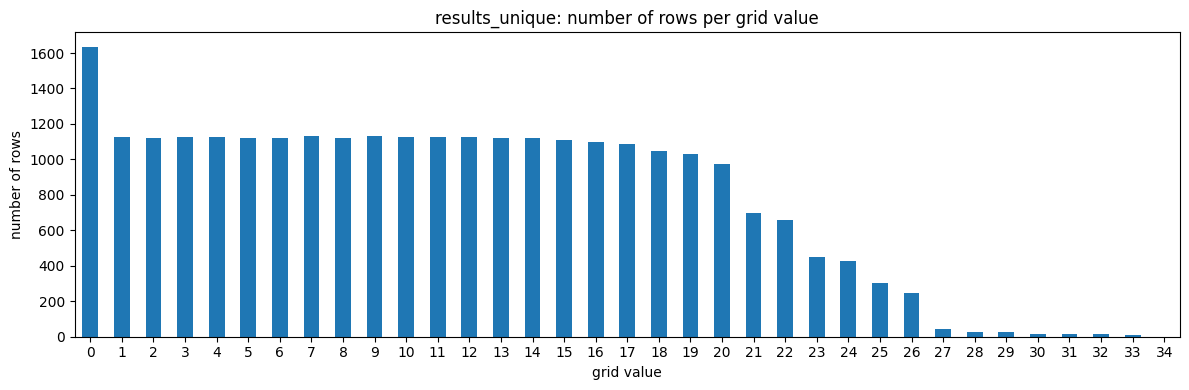

In [38]:
g = results_unique.grid

print('rows:', len(g))
print('min grid:', g.min(), '| max grid:', g.max())
print('negative values:', (g < 0).sum())
print('grid == 0:', (g == 0).sum())

counts = g.value_counts().sort_index()
ax = counts.plot.bar(figsize=(12, 4), rot=0)
plt.xlabel('grid value')
plt.ylabel('number of rows')
plt.title('results_unique: number of rows per grid value')
plt.tight_layout()
plt.show()

In [39]:
races_t   = raw_before['races'][['raceId', 'year', 'round', 'name']].copy()
drivers_t = raw_before['drivers'][['driverId', 'surname']]
constr_t  = raw_before['constructors'][['constructorId', 'name']].rename(columns={'name': 'team'})
status    = raw_before['status']

In [40]:
zero = results_unique[results_unique.grid == 0]

# one race per year: the one with the most grid==0 rows (earliest round on ties)
n_zero = (zero.groupby('raceId').size().rename('n_zero').reset_index()
              .merge(races_t, on='raceId'))
pick = (n_zero.sort_values(['year', 'n_zero', 'round'], ascending=[True, False, True])
              .drop_duplicates('year'))

rows = (zero.merge(pick[['raceId', 'year', 'round', 'name']], on='raceId')
            .merge(drivers_t, on='driverId')
            .merge(constr_t, on='constructorId')
            .merge(status, on='statusId')
            .sort_values(['year', 'positionOrder']))

cols = ['year', 'name', 'surname', 'team', 'positionOrder', 'positionText', 'grid', 'laps', 'status']

print('rows shown:', len(rows), '| years covered:', rows.year.min(), 'to', rows.year.max())
with pd.option_context('display.max_rows', None, 'display.width', 200):
    display(rows[cols])

print('years with no grid==0 at all:', sorted(set(races_t.year) - set(pick.year)))

rows shown: 311 | years covered: 1952 to 2024


,year,name,surname,team,positionOrder,positionText,grid,laps,status
276,1952,Italian Grand Prix,de Tornaco,Ferrari,25,F,0,0,Did not qualify
277,1952,Italian Grand Prix,Crespo,Maserati,26,F,0,0,Did not qualify
278,1952,Italian Grand Prix,de Graffenried,Maserati,27,F,0,0,Did not qualify
279,1952,Italian Grand Prix,Collins,HWM,28,F,0,0,Did not qualify
280,1952,Italian Grand Prix,Whitehead,Ferrari,29,F,0,0,Did not qualify
281,1952,Italian Grand Prix,Gaze,HWM,30,F,0,0,Did not qualify
282,1952,Italian Grand Prix,Aston,Aston Butterworth,31,F,0,0,Did not qualify
283,1952,Italian Grand Prix,Macklin,HWM,32,F,0,0,Did not qualify
284,1952,Italian Grand Prix,von Stuck,Ferrari,33,F,0,0,Did not qualify
285,1952,Italian Grand Prix,Dusio,Cisitalia,34,F,0,0,Did not qualify


years with no grid==0 at all: [1950, 1951, 1953, 1969, 2003, 2004, 2005, 2006, 2007, 2008, 2010, 2013, 2014]


code    D  E    F  R    W  number
decade                           
1950    0  0   48  0   19       0
1960    0  0   74  0  123       0
1970    0  0  329  0   21       0
1980    4  5  544  1   17       0
1990    2  2  342  0   11       0
2000    0  0    5  0    3       0
2010    0  0    4  7    4      13
2020    0  0    0  6    4      47


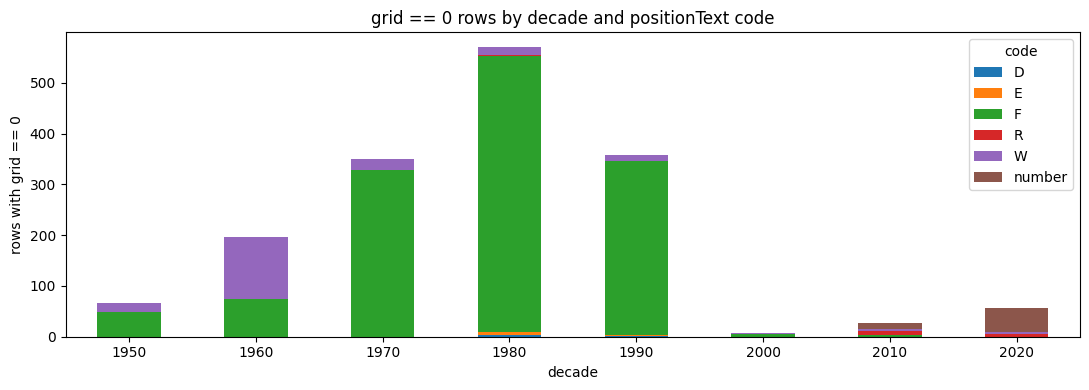

In [41]:
z = results_unique[results_unique.grid == 0].merge(raw_before['races'][['raceId', 'year']], on='raceId')

is_num = pd.to_numeric(z.positionText, errors='coerce').notna()
z['code'] = z.positionText.where(~is_num, 'number')
z['decade'] = (z.year // 10 * 10).astype(int)

ct = z.groupby(['decade', 'code']).size().unstack(fill_value=0)
print(ct)

ct.plot.bar(stacked=True, figsize=(11, 4), rot=0)
plt.xlabel('decade')
plt.ylabel('rows with grid == 0')
plt.title('grid == 0 rows by decade and positionText code')
plt.legend(title='code')
plt.tight_layout()
plt.show()

### What `grid` = 0 means

`grid` has no missing values, but 1,635 rows (about 6% of `results_unique`) have the value 0. The starting grid begins at 1 (pole position), so 0 is not a real starting slot. We looked at these rows through `positionText`, `status` and `laps`. As a sample we printed all `grid` = 0 rows for one race per year (the race with the most such rows in that year), and we counted all of them by decade and `positionText` code in the chart below.

**Observation 1: before 2000, the `grid` = 0 rows are almost all F and W.**
Of the 1,542 rows before 2000, 1,528 carry the codes F (did not qualify / did not prequalify / 107% rule / injury) or W (withdrew). The other 14 are D (disqualified), E (excluded) and one R. Every F, W, D and E row has `laps` = 0. Statuses such as "Engine" or "Accident" on W rows also show 0 laps, so these drivers never ran a lap of the race. The counts drop sharply after 1999 (8 rows in the 2000s).

**Observation 2: in the 2010s and 2020s the `grid` = 0 rows are different.**
All 60 rows with a numeric `positionText` (a classified finishing place) fall in 2010 or later, and so do 13 of the 14 R rows (retired). All 60 numeric rows have `laps` > 0, up to 78, and 12 of the 14 R rows have laps. Examples: Stroll finished 7th at the 2023 US Grand Prix with 56 laps, and Hartley retired on lap 1 at the 2018 British Grand Prix. These drivers raced, so a `grid` of 0 cannot mean "did not start" for them.

**Interpretation (hypothesis, not yet confirmed).**
The course material says a driver can start from the pit lane, which is not one of the numbered grid slots. A driver who raced with `grid` = 0 may therefore have started from the pit lane, which the dataset records as 0. The dataset has no pit-lane flag, so we cannot read this directly from `results`.

**Test: join with `qualifying`.**
`qualifying` records each driver's qualifying position separately from `grid`. If the hypothesis holds, `grid` = 0 drivers with `laps` > 0 should mostly have a qualifying position (they qualified and then started from the pit lane), while `grid` = 0 drivers with `laps` = 0 should mostly have none. `qualifying` only covers the later seasons, so we run the check on the years it covers. Older rows are judged from `laps` and `status` alone.

**Consequence for cleaning.**
Dropping every `grid` = 0 row would remove real race finishers, so `grid` = 0 alone cannot decide which rows to remove. The qualifying check below tests what the value means.

In [42]:
qual = load('qualifying')
races_t   = load('races')[['raceId', 'year', 'round', 'name']]
drivers_t = load('drivers')[['driverId', 'surname']]
status    = load('status')

# key check on qualifying before joining
print('qualifying rows:', len(qual))
print('duplicate (raceId, driverId):', qual.duplicated(['raceId', 'driverId']).sum())
print('qual position dtype:', qual.position.dtype, '| missing:', qual.position.isna().sum())

# join: qualifying.position renamed so it can't be confused with results.position
q = qual[['raceId', 'driverId', 'position']].rename(columns={'position': 'qual_pos'})
m = (results_unique
     .merge(q, on=['raceId', 'driverId'], how='left', validate='one_to_one')
     .merge(races_t[['raceId', 'year']], on='raceId'))

m['has_qual'] = m.qual_pos.notna()
print('rows after join:', len(m), '(results_unique has', len(results_unique), ')')

# is qualifying complete from a given year? share of results rows with a qualifying row, per year
cov_by_year = m.groupby('year').has_qual.mean()
print('\nshare of results rows with a qualifying row:')
print(cov_by_year[cov_by_year.index >= 1950].round(2).to_string())

qualifying rows: 10494
duplicate (raceId, driverId): 0
qual position dtype: int64 | missing: 0
rows after join: 26668 (results_unique has 26668 )

share of results rows with a qualifying row:
year
1950    0.00
1951    0.00
1952    0.00
1953    0.00
1954    0.00
1955    0.00
1956    0.00
1957    0.00
1958    0.00
1959    0.00
1960    0.00
1961    0.00
1962    0.00
1963    0.00
1964    0.00
1965    0.00
1966    0.00
1967    0.00
1968    0.00
1969    0.00
1970    0.00
1971    0.00
1972    0.00
1973    0.00
1974    0.00
1975    0.00
1976    0.00
1977    0.00
1978    0.00
1979    0.00
1980    0.00
1981    0.00
1982    0.00
1983    0.00
1984    0.00
1985    0.00
1986    0.00
1987    0.00
1988    0.00
1989    0.00
1990    0.00
1991    0.00
1992    0.00
1993    0.00
1994    0.88
1995    1.00
1996    0.44
1997    0.59
1998    0.44
1999    0.18
2000    0.24
2001    0.06
2002    0.12
2003    1.00
2004    1.00
2005    1.00
2006    1.00
2007    1.00
2008    1.00
2009    1.00
2010    1.00
2011    0.

In [43]:
QYEAR = 2003        # first year with complete qualifying coverage (see the table above)
cov = m[m.year >= QYEAR].copy()

is_num = pd.to_numeric(cov.positionText, errors='coerce').notna()
cov['code'] = cov.positionText.where(~is_num, 'number')
cov['group'] = np.select(
    [(cov.grid == 0) & (cov.laps > 0), (cov.grid == 0) & (cov.laps == 0)],
    ['grid0_raced', 'grid0_no_laps'], default='grid>0')

print(f'years {QYEAR}+ only, {len(cov)} rows')
display(cov.groupby('group').agg(rows=('resultId', 'size'),
                                 with_qual=('has_qual', 'sum'),
                                 share_with_qual=('has_qual', 'mean')).round(3))

# the same split by code, grid==0 only
display(cov[cov.grid == 0].groupby(['group', 'code']).agg(rows=('resultId', 'size'),
                                                         with_qual=('has_qual', 'sum')))

# the raced group row by row: did they qualify, and where?
raced0 = (cov[cov.group == 'grid0_raced']
          .merge(races_t[['raceId', 'name']], on='raceId')
          .merge(drivers_t, on='driverId')
          .merge(status, on='statusId')
          .sort_values(['year', 'name', 'positionOrder']))
with pd.option_context('display.max_rows', None, 'display.width', 200):
    display(raced0[['year', 'name', 'surname', 'code', 'positionOrder', 'laps', 'status', 'qual_pos']])

years 2003+ only, 8970 rows


,rows,with_qual,share_with_qual
group,,,
grid0_no_laps,14,12,0.857
grid0_raced,72,71,0.986
grid>0,8884,8863,0.998


rows  with_qual
group         code                   
grid0_no_laps F          4          4
              R          1          1
              W          9          7
grid0_raced   R         12         12
              number    60         59

,year,name,surname,code,positionOrder,laps,status,qual_pos
0,2015,Monaco Grand Prix,Sainz,number,10,78,Finished,8.0
3,2016,Austrian Grand Prix,Massa,number,20,63,Brakes,10.0
4,2016,Austrian Grand Prix,Kvyat,R,22,2,Retired,20.0
1,2016,Monaco Grand Prix,Nasr,R,17,48,Retired,22.0
2,2016,Monaco Grand Prix,Verstappen,R,18,34,Accident,21.0
5,2017,Australian Grand Prix,Ricciardo,R,17,25,Power Unit,10.0
6,2018,British Grand Prix,Hartley,R,20,1,Power Unit,20.0
13,2019,Austrian Grand Prix,Russell,number,18,69,+2 Laps,19.0
8,2019,Azerbaijan Grand Prix,Räikkönen,number,10,50,+1 Lap,19.0
9,2019,Azerbaijan Grand Prix,Kubica,number,16,49,+2 Laps,18.0


In [44]:
z0 = m[(m.grid == 0) & (m.laps == 0)].copy()
print('grid==0 and laps==0:', len(z0))

is_num = pd.to_numeric(z0.positionText, errors='coerce').notna()
z0['code'] = z0.positionText.where(~is_num, 'number')

# signs of having actually raced, even though laps == 0
checks = {
    'points > 0':              (z0.points > 0).sum(),
    'race time filled':        z0.time.notna().sum(),
    'milliseconds filled':     z0.milliseconds.notna().sum(),
    'fastestLap filled':       z0.fastestLap.notna().sum(),
    'numeric positionText':    (z0.code == 'number').sum(),
    'status Finished/+N Lap':  z0.statusId.isin(
        status[status.status.str.contains(r'^Finished$|^\+\d+ Lap', regex=True)].statusId).sum(),
}
display(pd.Series(checks, name='rows'))

# by code, with the years they cover
display(z0.groupby('code').agg(rows=('resultId', 'size'),
                               first_year=('year', 'min'),
                               last_year=('year', 'max')))

# qualified (has a qualifying row) but laps == 0: possible DNS cases, only meaningful from 2003
q0 = z0[(z0.year >= 2003) & z0.has_qual].merge(races_t[['raceId', 'name']], on='raceId') \
       .merge(drivers_t, on='driverId').merge(status, on='statusId')
print('\nlaps == 0 but has a qualifying row (2003+):', len(q0))
display(q0[['year', 'name', 'surname', 'code', 'status', 'qual_pos']])

grid==0 and laps==0: 1563


points > 0                0
race time filled          0
milliseconds filled       0
fastestLap filled         0
numeric positionText      0
status Finished/+N Lap    0
Name: rows, dtype: int64

,rows,first_year,last_year
code,,,
D,6,1984,1990
E,7,1987,1997
F,1346,1952,2012
R,2,1981,2017
W,202,1952,2023



laps == 0 but has a qualifying row (2003+): 12


,year,name,surname,code,status,qual_pos
0,2009,Hungarian Grand Prix,Massa,W,Withdrew,10.0
1,2012,Australian Grand Prix,de la Rosa,F,Did not qualify,23.0
2,2012,Australian Grand Prix,Karthikeyan,F,Did not qualify,24.0
3,2015,Australian Grand Prix,Bottas,W,Withdrew,6.0
4,2011,Australian Grand Prix,Liuzzi,F,Did not qualify,23.0
5,2011,Australian Grand Prix,Karthikeyan,F,Did not qualify,24.0
6,2011,Monaco Grand Prix,Pérez,W,Injury,10.0
7,2017,Malaysian Grand Prix,Räikkönen,R,Battery,2.0
8,2021,Italian Grand Prix,Tsunoda,W,Brakes,17.0
9,2022,Saudi Arabian Grand Prix,Schumacher,W,Withdrew,14.0


**Reading.** None of the 1,563 rows with `grid` = 0 and 0 laps has points, a race time, a fastest lap, a numeric `positionText` or a status of finished, so as far as the data shows, these drivers may have never took part in the race. They are mostly F (did not qualify) and W (withdrew), and almost all of them are from before 2000. From 2003, 12 of them have a row in `qualifying`. Four of these are F, because they set a time that was too slow to qualify (the HRT drivers at the 2011 and 2012 Australian Grands Prix). The other eight qualified and then did not start, for example Räikkönen, who qualified 2nd at the 2017 Malaysian Grand Prix, and Leclerc, who qualified 2nd at the 2023 São Paulo Grand Prix.

### Drivers with a grid slot who did not start

The check above only looks at `grid` = 0. A driver can also get a grid slot and then not take part, for example by withdrawing before the start (F1 history: the 14 cars that pulled out of the 2005 United States Grand Prix after the formation lap, or Leclerc on pole at Monaco in 2021, whose driveshaft broke on the way to the grid). No single column says whether a car started, so we look at every combination of the grid slot, the laps and the result code (`positionText`: a number = classified, R = retired, W = withdrew, F = failed to qualify, D = disqualified, E = excluded, N = not classified).

In [45]:
combo = results_unique.assign(
    slot=np.where(results_unique.grid > 0, 'grid > 0', 'grid 0'),
    ran=np.where(results_unique.laps > 0, 'laps > 0', 'laps 0'),
    code=results_unique.positionText.where(results_unique.positionText.isin(['F', 'W', 'D', 'E', 'R', 'N']), 'number'))
display(pd.crosstab([combo.slot, combo.ran], combo.code))

named = (combo[(combo.grid > 0) & combo.code.isin(['F', 'W', 'D', 'E'])]
         .merge(races_t[['raceId', 'year', 'name']], on='raceId').merge(drivers_t, on='driverId').merge(status, on='statusId'))
cols = ['year', 'name', 'surname', 'grid', 'laps', 'code', 'status']
print('F or W with a grid slot and 0 laps:', int(((named.laps == 0) & named.code.isin(['F', 'W'])).sum()))
print('\nF or W with a grid slot who ran laps:')
display(named[(named.laps > 0) & named.code.isin(['F', 'W'])][cols].sort_values('year'))
print('D or E with a grid slot and 0 laps:')
display(named[(named.laps == 0) & named.code.isin(['D', 'E'])][cols].sort_values('year'))

code                 D  E     F    N     R    W  number
slot     ran                                           
grid 0   laps 0      6  7  1346    0     2  202       0
         laps > 0    0  0     0    0    12    0      60
grid > 0 laps 0      4  1    19    0   814  128       0
         laps > 0  141  1     1  190  7991    5   15738

F or W with a grid slot and 0 laps: 147

F or W with a grid slot who ran laps:


,year,name,surname,grid,laps,code,status
248,1952,Swiss Grand Prix,Macklin,12,24,W,Withdrew
247,1952,Swiss Grand Prix,Moss,9,24,W,Withdrew
209,1970,Spanish Grand Prix,Rodríguez,5,4,W,Withdrew
194,1974,United States Grand Prix,Dolhem,26,25,W,Withdrew
176,1977,German Grand Prix,Heyer,25,9,F,Did not qualify
167,1979,Dutch Grand Prix,Lauda,9,4,W,Withdrew


D or E with a grid slot and 0 laps:


,year,name,surname,grid,laps,code,status
112,1987,British Grand Prix,Ghinzani,19,0,E,Excluded
103,1989,Canadian Grand Prix,Mansell,5,0,D,Disqualified
104,1989,Canadian Grand Prix,Nannini,13,0,D,Disqualified
96,1990,German Grand Prix,Alliot,24,0,D,Disqualified
299,2024,São Paulo Grand Prix,Hülkenberg,17,0,D,Disqualified


**Reading.** Each combination means something different:
- **`grid` = 0 and 0 laps** (any code): no slot and no lap, the drivers who did not qualify, withdrew or were excluded. They did not start (the check above).
- **`grid` = 0 and laps run:** pit-lane starters. They started.
- **A grid slot, code F or W, and 0 laps:** they officially did not take part ("did not qualify" or "withdrew") and ran no lap, so they did not start. Leclerc on pole at Monaco 2021 is one of them.
- **A grid slot, code F or W, and laps run:** they raced some laps and then left, for example Heyer at the 1977 German Grand Prix, who joined the race without having qualified (F1 history). They started.
- **A grid slot, code R, and 0 laps:** they retired before completing the first lap, mostly in first-lap collisions and accidents. They started, so 0 laps alone does not mean "did not start".
- **A grid slot, code D or E, and 0 laps:** mixed. Some of these drivers did start (F1 history: Mansell and Nannini at the 1989 Canadian Grand Prix pitted at the end of the formation lap, left the pit lane before the start was given, raced, and were then disqualified), so the code does not tell us whether they started.

**What this means for the rule.** The data shows which drivers ran no lap, but not when they dropped out. Some withdrew days before the race, others failed on the way to the grid or on the formation lap, and a few started from the pit lane or were disqualified after starting. The prediction is made the day before the race, and only a failed qualification is certain at that time. The rule below therefore flags only the drivers marked F. They stay in the cleaned table for now and are left out of the modelling table later, after the history features are built. Every other driver stays as a normal entry.

In [46]:
# failed to qualify (code F), the only drivers we know before the prediction cutoff will not race
results_unique['failed_to_qualify'] = results_unique.positionText.eq('F')
print('failed_to_qualify rows:', int(results_unique.failed_to_qualify.sum()),
      '| with grid 0:', int((results_unique.failed_to_qualify & (results_unique.grid == 0)).sum()),
      '| with a grid slot:', int((results_unique.failed_to_qualify & (results_unique.grid > 0)).sum()))

# did not take the start: no grid slot and no laps, or a grid slot but code F (did not qualify) or W (withdrew) and no laps.
# Only the data-engineering questions (section 6) use this flag, because they describe what happened in races.
no_slot = (results_unique.grid == 0) & (results_unique.laps == 0)
slot_but_no_start = (results_unique.grid > 0) & results_unique.positionText.isin(['F', 'W']) & (results_unique.laps == 0)
results_unique['did_not_start'] = no_slot | slot_but_no_start
print('did_not_start rows (used only in section 6):', int(results_unique.did_not_start.sum()),
      '| no grid slot and no laps:', int(no_slot.sum()), '| grid slot but did not start:', int(slot_but_no_start.sum()))

failed_to_qualify rows: 1366 | with grid 0: 1346 | with a grid slot: 20
did_not_start rows (used only in section 6): 1710 | no grid slot and no laps: 1563 | grid slot but did not start: 147


### Decision: who is removed (`failed_to_qualify`)

**Rule.** We remove only the drivers marked F (`positionText` = F), because they failed to qualify. That is the only case we know for sure before the prediction cutoff, the day before the race. Every other driver stays in the data as a normal entry, including drivers who withdrew, were excluded or disqualified, or retired without completing a lap. We do not know when those things happened, so at the cutoff we would have predicted for them, and their target is simply no podium. The rows are flagged `failed_to_qualify` and removed from the modelling table after the history features are built.

**Evidence.**
- The checks above show that the drivers with code F did not qualify, with one exception. Heyer at the 1977 German Grand Prix joined the race without having qualified and was disqualified (F1 history), so removing him is also correct.
- Drivers with a grid slot who withdrew (code W, 0 laps) stay in. For example, Leclerc was on pole at Monaco in 2021, and his driveshaft broke on the way to the grid. At the cutoff he was one of the most likely winners, so keeping him shows the uncertainty that remains after the cutoff.
- Räikkönen at the 2017 Malaysian Grand Prix has code R, `grid` = 0 and 0 laps. He qualified 2nd and his car lost power on the way to the grid (F1 history), so he stays in for the same reason as Leclerc.
- Lammers at the 1981 San Marino Grand Prix also has code R, `grid` = 0 and 0 laps, but race reports say he failed to qualify (F1 history), so his code in the data is wrong. We follow the codes in the data and do not correct single rows by hand, so this one row from 1981 stays in.

**Grid value.** Every row with `grid` = 0 gets a slot in `grid_clean` (the next code cell). Pit-lane starters, which have `grid` = 0 and laps run, are placed at the back of the field. For a driver who did not take the start, we look at the official grid of that race. If his qualifying slot was left empty, the grid was set with him in it, so he keeps his qualifying position. This is the case for four drivers. Räikkönen at the 2017 Malaysian Grand Prix and Leclerc at the 2023 São Paulo Grand Prix both qualified 2nd and had their cars fail on race day, and the other two had qualified last. If another driver started from his slot, the drivers behind him had moved up and the grid was set without him, so he goes to the back of the field. This is the case for the six other drivers with a qualifying position, most of whom were withdrawn after a crash or an injury in practice or qualifying. The drivers with no qualifying position, mostly from seasons before 1994 when the `qualifying` table does not exist, also go to the back of the field.

**A second flag for the data-engineering questions.** The three questions in section 6 do not predict anything. They describe what happened in races, so they count only the drivers who took the start. The flag `did_not_start` marks the drivers who did not, which are the rows with `grid` = 0 and 0 laps and the rows with a grid slot, code F or W and 0 laps (*Drivers with a grid slot who did not start*). It is used only in section 6 and never decides which rows the model predicts for.

**Why flag first.** The removed rows still carry history, so we flag them now and drop them after the features are built.

**Next.** We check `results` for other anomalies.

In [47]:
# grid 0 with laps run, flagged as a pit-lane start
results_unique['pit_lane_start'] = (results_unique.grid == 0) & (results_unique.laps > 0)
print('pit_lane_start rows:', results_unique.pit_lane_start.sum())

# grid_clean is the original grid, with every grid 0 row given a slot. `grid` itself is not changed.
# Step 1. Every grid 0 row goes to the back of the field (the highest grid slot in that race + 1).
back_of_field = results_unique.groupby('raceId').grid.transform('max') + 1
results_unique['grid_clean'] = results_unique.grid.where(results_unique.grid > 0, back_of_field)

# Step 2. A driver who did not take the start keeps his qualifying position if the official grid left that slot empty,
# because then the grid was set with him in it. If another driver started from his slot, the grid was set without him.
qual_pos = (results_unique[['raceId', 'driverId']]
            .merge(qual[['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='left')
            .position.values)                                            # same row order as results_unique
used_slots = set(zip(results_unique.raceId[results_unique.grid > 0], results_unique.grid[results_unique.grid > 0]))
no_start = ((results_unique.grid == 0) & (results_unique.laps == 0) & ~results_unique.failed_to_qualify
            & pd.notna(qual_pos))
slot_left_empty = pd.Series([(race, slot) not in used_slots for race, slot in zip(results_unique.raceId, qual_pos)],
                            index=results_unique.index)
keeps_slot = no_start & slot_left_empty
results_unique.loc[keeps_slot, 'grid_clean'] = qual_pos[keeps_slot.values].astype(int)

assert (results_unique.grid_clean > 0).all(), 'a row still has grid 0'
print('grid 0 rows:', int((results_unique.grid == 0).sum()),
      '| drivers who did not start and have a qualifying position:', int(no_start.sum()),
      '| of them, kept their qualifying position:', int(keeps_slot.sum()))

check = (results_unique[no_start].assign(qualifying_position=qual_pos[no_start.values].astype(int),
                                         slot_left_empty=slot_left_empty[no_start])
         .merge(races_t[['raceId', 'year', 'name']], on='raceId').merge(drivers_t, on='driverId')
         .sort_values('year'))
display(check[['year', 'name', 'surname', 'positionText', 'qualifying_position', 'slot_left_empty', 'grid_clean']]
        .rename(columns={'name': 'race', 'positionText': 'code'}))

pit_lane_start rows: 72
grid 0 rows: 1635 | drivers who did not start and have a qualifying position: 10 | of them, kept their qualifying position: 4


,year,race,surname,code,qualifying_position,slot_left_empty,grid_clean
1,1994,San Marino Grand Prix,Ratzenberger,W,26,True,26
0,1995,Japanese Grand Prix,Suzuki,W,13,False,24
2,2009,Hungarian Grand Prix,Massa,W,10,False,20
4,2011,Monaco Grand Prix,Pérez,W,10,False,24
3,2015,Australian Grand Prix,Bottas,W,6,False,18
5,2017,Malaysian Grand Prix,Räikkönen,R,2,True,2
6,2021,Italian Grand Prix,Tsunoda,W,17,False,20
7,2022,Saudi Arabian Grand Prix,Schumacher,W,14,False,20
8,2023,Singapore Grand Prix,Stroll,W,20,True,20
9,2023,São Paulo Grand Prix,Leclerc,W,2,True,2


In [48]:
status_t = raw_before['status'][['statusId', 'status']]
r = results_unique.merge(races_t, on='raceId')
g = r.groupby('raceId')

print('=== podium / rank integrity ===')
podium_cnt = g['positionOrder'].apply(lambda s: (s <= 3).sum())
print('races with !=3 podium rows:', (podium_cnt != 3).sum())

dup_rank = g['positionOrder'].apply(lambda s: s.duplicated().any())
print('races with a repeated positionOrder:', dup_rank.sum())
shared = r[r.duplicated(['raceId', 'positionOrder'], keep=False)]
print('shared finishing places:', shared.groupby(['raceId', 'positionOrder']).ngroups,
      '| rows in them:', len(shared), '| seasons:', shared.year.min(), 'to', shared.year.max())

# meaningful replacement for "1..N": are ranks 1,2,3 each present once?
def podium_ok(s):
    top = s[s <= 3]
    return sorted(top) == [1, 2, 3]
podium_shape = g['positionOrder'].apply(podium_ok)
print('races where podium is NOT exactly {1,2,3}:', (~podium_shape).sum())

print('\n=== points sanity ===')
print('rows with points > 0 but positionOrder > 11:', ((r.points > 0) & (r.positionOrder > 11)).sum())

print('\n=== podium but not classified-finished ===')
fin_ids = status_t[status_t.status.str.match(r'Finished|\+\d+ Lap')].statusId
print('podium rows whose status is not Finished/+N Laps:',
      ((r.positionOrder <= 3) & (~r.statusId.isin(fin_ids))).sum())

print('\n=== range checks ===')
print('grid < 0:', (r.grid < 0).sum(), '| positionOrder < 1:', (r.positionOrder < 1).sum())
over_grid = g.apply(lambda d: (d.grid > len(d)).any(), include_groups=False)
print('races with grid greater than field size:', over_grid.sum())

print('\n=== laps vs winner ===')
winner_laps = g.apply(lambda d: d.loc[d.positionOrder == 1, 'laps'].max(), include_groups=False)
r2 = r.merge(winner_laps.rename('win_laps'), on='raceId')
print('rows with more laps than the race winner:', (r2.laps > r2.win_laps).sum())

print('\n=== grain ===')
print('duplicate (raceId, driverId):', results_unique.duplicated(['raceId','driverId']).sum())

=== podium / rank integrity ===
races with !=3 podium rows: 18
races with a repeated positionOrder: 45
shared finishing places: 87 | rows in them: 184 | seasons: 1950 to 1961
races where podium is NOT exactly {1,2,3}: 18

=== points sanity ===
rows with points > 0 but positionOrder > 11: 12

=== podium but not classified-finished ===
podium rows whose status is not Finished/+N Laps: 7

=== range checks ===
grid < 0: 0 | positionOrder < 1: 0
races with grid greater than field size: 12

=== laps vs winner ===
rows with more laps than the race winner: 1

=== grain ===
duplicate (raceId, driverId): 0


rows with points > 0 but positionOrder > 11: 12

=== podium but not classified-finished ===
podium rows whose status is not Finished/+N Laps: 7

=== range checks ===
grid < 0: 0 | positionOrder < 1: 0


races with grid greater than field size: 12

=== laps vs winner ===


rows with more laps than the race winner: 1

=== grain ===


duplicate (raceId, driverId): 0


In [49]:
races_t = raw_before['races'][['raceId','year','name']]
drivers_t = raw_before['drivers'][['driverId','surname']]
constr_t = raw_before['constructors'][['constructorId','name']].rename(columns={'name':'team'})

pod = results_unique[results_unique.positionOrder <= 3].merge(races_t, on='raceId')

# races with more than 3 podium rows
counts = pod.groupby('raceId').size().rename('n_podium')
bad = counts[counts > 3].reset_index().merge(races_t, on='raceId').sort_values('year')
print('races with >3 podium rows:', len(bad))
print(bad[['year','name','n_podium']].to_string(index=False))

# one race in full, with status joined in
status_t = raw_before['status'][['statusId','status']]
rid = bad.raceId.iloc[1]
one = (results_unique[results_unique.raceId == rid]
       .merge(drivers_t, on='driverId').merge(constr_t, on='constructorId')
       .merge(status_t, on='statusId')
       .sort_values('positionOrder'))
print(races_t[races_t.raceId==rid][['year','name']].to_string(index=False))
display(one[['positionOrder','positionText','grid','surname','team','laps','milliseconds','status']])

races with >3 podium rows: 18
 year                 name  n_podium
 1950   Italian Grand Prix         4
 1951    French Grand Prix         5
 1951   Italian Grand Prix         4
 1951     Indianapolis 500         4
 1953     Dutch Grand Prix         4
 1953     Indianapolis 500         4
 1954   Italian Grand Prix         4
 1954    German Grand Prix         4
 1955     Indianapolis 500         4
 1955    Monaco Grand Prix         4
 1955 Argentine Grand Prix         5
 1956 Argentine Grand Prix         4
 1956    Monaco Grand Prix         4
 1956   British Grand Prix         4
 1956   Italian Grand Prix         4
 1956   Belgian Grand Prix         4
 1957   British Grand Prix         4
 1960 Argentine Grand Prix         4
 year              name
 1951 French Grand Prix


,positionOrder,positionText,grid,surname,team,laps,milliseconds,status
0,1,1,7,Fagioli,Alfa Romeo,77,12131000.0,Finished
21,1,1,7,Fangio,Alfa Romeo,77,12131000.0,Finished
22,2,2,6,González,Ferrari,77,12189200.0,Finished
1,2,2,6,Ascari,Ferrari,77,12189200.0,Finished
2,3,3,4,Villoresi,Ferrari,74,NaN,+3 Laps
3,4,4,9,Parnell,Ferrari,73,NaN,+4 Laps
4,5,5,2,Farina,Alfa Romeo,73,NaN,+4 Laps
5,6,6,8,Chiron,Talbot-Lago,71,NaN,+6 Laps
6,7,7,11,Cabantous,Talbot-Lago,71,NaN,+6 Laps
7,8,8,14,Chaboud,Talbot-Lago,69,NaN,+8 Laps


In [50]:
pod_rows = results_unique[results_unique.positionOrder <= 3].merge(races_t, on='raceId')
flagged = pod_rows[pod_rows.raceId.isin(bad.raceId)]

# for each race, are the >3 podium rows explained by tied (positionOrder, constructorId)?
def shared_drive_ok(g):
    # count distinct cars on the podium = distinct (positionOrder, constructorId)
    cars = g[['positionOrder','constructorId']].drop_duplicates().shape[0]
    return cars <= 3

summary = flagged.groupby(['year','name']).apply(shared_drive_ok, include_groups=False)
print('races explained by shared drives (<=3 distinct cars):', summary.sum(), 'of', len(summary))
print('\nany NOT explained:')
print(summary[~summary].to_string())

races explained by shared drives (<=3 distinct cars): 18 of 18

any NOT explained:
Series([], )


In [51]:
r = results_unique.merge(races_t, on='raceId')
g = r.groupby('raceId')

print('=== 1. points > 0 but positionOrder > 11 ===')
pts = (r[(r.points > 0) & (r.positionOrder > 11)]
       .merge(drivers_t, on='driverId')
       .sort_values(['year','positionOrder']))
print(pts[['year','name','surname','positionOrder','positionText','points','laps']].to_string(index=False))

print('\n=== 2. podium but not Finished/+N Laps ===')
fin_ids = status_t[status_t.status.str.match(r'Finished|\+\d+ Lap')].statusId
pod = (r[(r.positionOrder <= 3) & (~r.statusId.isin(fin_ids))]
       .merge(drivers_t, on='driverId').merge(status_t, on='statusId')
       .sort_values('year'))
print(pod[['year','name','surname','positionOrder','laps','status']].to_string(index=False))

print('\n=== 3. grid greater than field size ===')
field = g.size().rename('field')
over = (r.merge(field, on='raceId'))
over = over[over.grid > over.field].merge(drivers_t, on='driverId').sort_values('year')
print(over[['year','name','surname','grid','field','positionOrder']].to_string(index=False))

print('\n=== 4. laps > winner ===')
winner_laps = g.apply(lambda d: d.loc[d.positionOrder == 1, 'laps'].max(), include_groups=False)
r2 = r.merge(winner_laps.rename('win_laps'), on='raceId')
bad_laps = (r2[r2.laps > r2.win_laps]
            .merge(drivers_t, on='driverId')
            .sort_values('year'))
print(bad_laps[['year','name','surname','positionOrder','laps','win_laps']].to_string(index=False))

=== 1. points > 0 but positionOrder > 11 ===
 year               name  surname  positionOrder positionText  points  laps
 1951 British Grand Prix   Farina             14            R     1.0    75
 1952   Indianapolis 500 Vukovich             17           17     1.0   191
 1953 Belgian Grand Prix González             16            R     1.0    11
 1954  French Grand Prix Herrmann             14            R     1.0    16
 1954 Spanish Grand Prix   Ascari             19            R     1.0    10
 1955 Italian Grand Prix     Moss             14            R     1.0    27
 1955  Monaco Grand Prix   Fangio             15            R     1.0    49
 1955   Indianapolis 500 Vukovich             25            R     1.0    56
 1956 British Grand Prix     Moss             12            R     1.0    94
 1956   Indianapolis 500    Russo             33            R     1.0    21
 1958  German Grand Prix     Moss             21            R     1.0     3
 1959  French Grand Prix     Moss          

In [52]:
# 2) how far behind the winner were the non-"Finished" podium rows?
winner_laps = (r.groupby('raceId')
                 .apply(lambda d: d.loc[d.positionOrder == 1, 'laps'].max(), include_groups=False)
                 .rename('win_laps'))
chk = (r[(r.positionOrder <= 3) & (~r.statusId.isin(fin_ids))]
       .merge(winner_laps, on='raceId').merge(drivers_t, on='driverId').merge(status_t, on='statusId'))
chk['laps_behind'] = chk.win_laps - chk.laps
print(chk[['year', 'name', 'surname', 'positionOrder', 'laps', 'win_laps', 'laps_behind', 'status']].to_string(index=False))

# 4) the Dutch GP 1960 in full
t = (r[(r.year == 1960) & (r.name == 'Dutch Grand Prix')]
     .merge(drivers_t, on='driverId').merge(status_t, on='statusId').sort_values('positionOrder'))
print()
print(t[['positionOrder', 'positionText', 'surname', 'laps', 'milliseconds', 'status']].to_string(index=False))

 year                     name    surname  positionOrder  laps  win_laps  laps_behind      status
 1999     Brazilian Grand Prix   Frentzen              3    71        72            1 Out of fuel
 1984    San Marino Grand Prix de Angelis              3    59        60            1 Out of fuel
 1982        Monaco Grand Prix     Pironi              2    75        76            1 Out of fuel
 1982        Monaco Grand Prix de Cesaris              3    75        76            1 Out of fuel
 1975       British Grand Prix       Pace              2    55        56            1    Accident
 1975       British Grand Prix  Scheckter              3    55        56            1    Accident
 1966 United States Grand Prix      Rindt              2   107       108            1 Out of fuel

 positionOrder positionText     surname  laps  milliseconds       status
             1            1     Brabham    75     7307200.0     Finished
             2            2     Ireland    75     7331200.0     Finis

### Summary of anomaly checks on `results`

We tested rules that should never be broken. Four checks came back clean (no `grid` below 0, no `positionOrder` below 1, no duplicate (`raceId`, `driverId`), and every podium has a P1). Seven found rows to inspect:

**Shared drives (18 races, 45 with a repeated `positionOrder`).** In 18 races between 1950 and 1960, more than 3 rows have `positionOrder` <= 3. In all 18, the podium still has only 3 distinct cars (distinct `positionOrder` + `constructorId`), so the extra rows are drivers sharing a car and both being credited with its place, not a data error. A further 27 races have a tie lower down the field, from the same cause. Effect on the target: `podium = positionOrder <= 3` labels more than 3 drivers in these races. Shared drives end after the 1950s, so this does not occur in the modern era the model is trained and tested on. We therefore keep these rows and note the quirk. The all-seasons version tested in 10.8 keeps them as recorded too, because every model scores each row on its own and does not assume three podiums per race (cleaning summary, section 3).

**Points for a driver who finished far back (12 rows).** All 12 are from 1951 to 1959, each with exactly 1 point, and 11 of the 12 are coded R or D (3 are Indianapolis 500 rows). This is consistent with the one point for the fastest lap that existed until 1959, which did not depend on finishing, but our tables cannot confirm it (the fastest-lap columns are empty for those years). `points` is a post-race column and is never a feature, so no action.

**Podium finishers without status "Finished" (7 rows).** All 7 have "Out of fuel" or "Accident" as status (1966 to 1999). A driver can be classified after stopping if enough of the distance was completed, so the podium label is `positionOrder` <= 3 and not the status text.

**`grid` above the number of result rows (15 rows in 12 races, 1952 to 1986).** Seven of the 12 races are the German or Belgian Grand Prix. The grid numbers have gaps, so a slot such as 26 can appear in a race with only 19 result rows. Any replacement value for `grid` = 0 must therefore use the highest `grid` value of that race plus one, not the row count.

**More laps than the winner (1 row).** Taylor, 1960 Dutch Grand Prix: 7th with 78 laps, while the winner has 75 and his own status says "+5 Laps" (about 70 laps). The two drivers ahead of him have 74 laps, so 78 also breaks the rank order. It looks like a typo for 70, but we cannot confirm it. `laps` is a post-race column and the row is not affected by the `grid` = 0 rule, so we document it and leave the value unchanged.

In [53]:
# results_unique: grain and keys
assert results_unique.resultId.is_unique, 'resultId not unique'
assert not results_unique.duplicated(['raceId', 'driverId']).any(), 'duplicate driver per race'
assert results_unique.grid.min() >= 0, 'negative grid'
assert results_unique.laps.min() >= 0, 'negative laps'
assert results_unique.positionOrder.notna().all(), 'positionOrder has nulls'   # it is the target base

# no driver who failed to qualify is on the podium
assert not (results_unique.failed_to_qualify & (results_unique.positionOrder <= 3)).any(), 'a failed_to_qualify row is on the podium'

## `Qualifying Table`

In [54]:
qualifying = load('qualifying')

print(qualifying.shape)
display(qualifying.head())

(10494, 9)


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [55]:
print(qualifying.isna().sum())

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64


In [56]:
print(qualifying.dtypes)

qualifyId         int64
raceId            int64
driverId          int64
constructorId     int64
number            int64
position          int64
q1               object
q2               object
q3               object
dtype: object


In [57]:
def check_pk(df, col, name):
    print(f'{name}.{col}: nulls = {df[col].isna().sum()}, duplicates = {df[col].duplicated().sum()}')

def check_fk(child, col, parent, pcol, cname, pname):
    nulls = child[col].isna().sum()
    orphans = (~child[col].dropna().isin(parent[pcol])).sum()
    print(f'{cname}.{col} -> {pname}.{pcol}: nulls = {nulls}, orphans = {orphans}, '
          f'parent unique = {parent[pcol].is_unique}')

races_p   = raw_before['races']
drivers_p = raw_before['drivers']
constr_p  = raw_before['constructors']

# primary key
check_pk(qualifying, 'qualifyId', 'qualifying')

# foreign keys
check_fk(qualifying, 'raceId',        races_p,   'raceId',        'qualifying', 'races')
check_fk(qualifying, 'driverId',      drivers_p, 'driverId',      'qualifying', 'drivers')
check_fk(qualifying, 'constructorId', constr_p,  'constructorId', 'qualifying', 'constructors')

# natural key: one row per driver per race
print('\nduplicate (raceId, driverId):', qualifying.duplicated(['raceId', 'driverId']).sum())

qualifying.qualifyId: nulls = 0, duplicates = 0
qualifying.raceId -> races.raceId: nulls = 0, orphans = 0, parent unique = True
qualifying.driverId -> drivers.driverId: nulls = 0, orphans = 0, parent unique = True
qualifying.constructorId -> constructors.constructorId: nulls = 0, orphans = 0, parent unique = True

duplicate (raceId, driverId): 0


### qualifying: key checks

| Check | Column | Result |
|---|---|---|
| Primary key | `qualifyId` | 0 nulls, 0 duplicates ✓ |
| Foreign key | `raceId` → `races` | 0 nulls, 0 orphans, parent unique ✓ |
| Foreign key | `driverId` → `drivers` | 0 nulls, 0 orphans, parent unique ✓ |
| Foreign key | `constructorId` → `constructors` | 0 nulls, 0 orphans, parent unique ✓ |
| Natural key | (`raceId`, `driverId`) | 0 duplicates ✓ |

Every qualifying row can be joined to its race, driver and constructor, and there is one row per driver per race, so joining `qualifying` to `results` on (`raceId`, `driverId`) does not duplicate rows.

In [58]:
# 1) which text formats exist? (digits replaced by 9)
for c in ['q1', 'q2', 'q3']:
    pat = qualifying[c].dropna().str.replace(r'\d', '9', regex=True)
    print(c, pat.value_counts().to_dict())

q1 {'9:99.999': 10337, '99:99.999': 1}
q2 {'9:99.999': 5847}
q3 {'9:99.999': 3629}


In [59]:
def to_seconds(s):
    parts = s.str.split(':', expand=True)
    return parts[0].astype(float) * 60 + parts[1].astype(float)

for c in ['q1', 'q2', 'q3']:
    qualifying[c + '_s'] = to_seconds(qualifying[c])
    print(c, 'before:', qualifying[c].notna().sum(), '| after:', qualifying[c + '_s'].notna().sum(),
          '| min:', qualifying[c + '_s'].min(), '| max:', qualifying[c + '_s'].max())

q1 before: 10338 | after: 10338 | min: 53.904 | max: 1002.64
q2 before: 5847 | after: 5847 | min: 53.647 | max: 132.47
q3 before: 3629 | after: 3629 | min: 53.377 | max: 129.776


In [60]:
print(qualifying.dtypes)

qualifyId          int64
raceId             int64
driverId           int64
constructorId      int64
number             int64
position           int64
q1                object
q2                object
q3                object
q1_s             float64
q2_s             float64
q3_s             float64
dtype: object


,rows,q1,q2,q3
year,,,,
1994,392,0.00,1.00,1.00
1995,418,0.06,1.00,1.00
1996,148,0.02,1.00,1.00
1997,220,0.00,1.00,1.00
1998,153,0.01,1.00,1.00
1999,65,0.02,1.00,1.00
2000,88,0.00,1.00,1.00
2001,22,0.00,1.00,1.00
2002,42,0.00,1.00,1.00


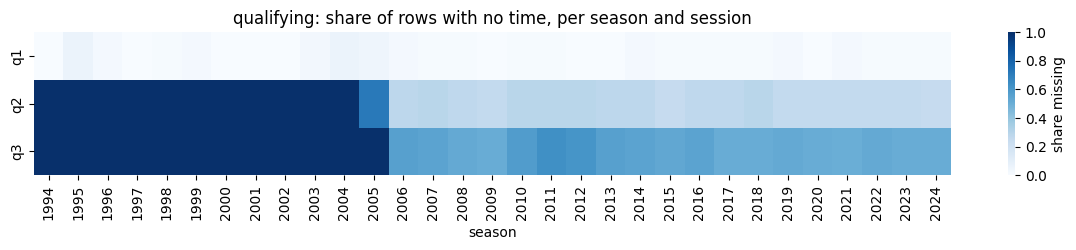

In [61]:
qq = qualifying.merge(raw_before['races'][['raceId', 'year', 'name']], on='raceId')

# share missing per year (0.00 = complete, 1.00 = all empty)
miss = qq.groupby('year')[['q1', 'q2', 'q3']].apply(lambda d: d.isna().mean().round(2))
miss.insert(0, 'rows', qq.groupby('year').size())
with pd.option_context('display.max_rows', None):
    display(miss)

# picture: the same shares as a heatmap (dark = all times missing)
plt.figure(figsize=(12, 2.6))
sns.heatmap(miss[['q1', 'q2', 'q3']].T, cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'share missing'})
plt.title('qualifying: share of rows with no time, per season and session')
plt.xlabel('season')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [62]:
# does the missing pattern follow the knockout logic?
#    a q3 time should never exist without a q2 time, and q2 never without q1
print('q3 present but q2 missing:', (qq.q3.notna() & qq.q2.isna()).sum())
print('q2 present but q1 missing:', (qq.q2.notna() & qq.q1.isna()).sum())


q3 present but q2 missing: 0
q2 present but q1 missing: 0


### qualifying: summary of checks

**Coverage.** The table has 10,494 rows and starts in 1994, so races before 1994 have no qualifying data. Features built from it will be empty for those years.

**`position`.** The qualifying position is filled in every row and is already an integer, so it needs no cleaning. It is the one qualifying column we can use directly.

**What `position` does not capture.** It only gives the order. It does not say how far apart the drivers were. A driver in 3rd place could be 0.05 seconds or 1.5 seconds behind pole. For that we need the lap times.

**Lap times `q1`, `q2`, `q3`.** These were stored as text (`object`), not numbers.
- Every non-missing value follows one format, minutes:seconds.milliseconds (for example `1:23.456`), except one `q1` value with a two-digit minute (10 minutes or more), which we check separately.
- Missing values: `q1` 156, `q2` 4,647 and `q3` 6,865 rows. The missing `q2` and `q3` are consistent with the knockout format, where a driver eliminated in Q1 has no Q2 or Q3 time, and a driver eliminated in Q2 has no Q3 time. The heatmap shows this by season: up to 2004 every `q2` and `q3` is empty, so only one session is recorded, and from 2006 about a quarter of the `q2` times and half of the `q3` times are empty every season. We therefore do not fill them in, because an empty value carries information (the driver was eliminated).
- We converted all three columns to seconds (float) in new columns `q1_s`, `q2_s` and `q3_s`, and kept the original text. The non-missing counts are the same before and after the conversion (10,338, 5,847 and 3,629).

**Features built from it.** Instead of using `q1_s`, `q2_s` and `q3_s` directly, section 7.2 builds features from them, such as each driver's gap to the fastest driver in the same session, as a percentage of the fastest time so that tracks of different lengths are comparable, and the difference between `grid` and qualifying `position`. They are `quali_gap_pct` (the gap to the fastest Q1 lap) and `grid_minus_quali`, and the ablation (10.7) tests what they add.

In [63]:
# the 156 rows with no q1 time
no_q1 = qq.merge(raw_before['drivers'][['driverId', 'surname']], on='driverId')
no_q1 = no_q1[no_q1.q1.isna()]
print('\nno q1 by year:', no_q1.year.value_counts().sort_index().to_dict())
print('of those, rows that still have q2 or q3:', (no_q1.q2.notna() | no_q1.q3.notna()).sum())
display(no_q1[['year', 'name', 'surname', 'position', 'q1', 'q2', 'q3']].head(15))


no q1 by year: {1994: 1, 1995: 24, 1996: 3, 1997: 1, 1998: 2, 1999: 1, 2003: 11, 2004: 21, 2005: 17, 2006: 8, 2007: 2, 2008: 2, 2009: 1, 2010: 4, 2011: 5, 2013: 2, 2014: 7, 2015: 3, 2016: 3, 2017: 2, 2018: 6, 2019: 9, 2020: 1, 2021: 7, 2022: 4, 2023: 5, 2024: 4}
of those, rows that still have q2 or q3: 0


,year,name,surname,position,q1,q2,q3
147,2008,Canadian Grand Prix,Vettel,20,NaN,NaN,NaN
307,2008,Singapore Grand Prix,Fisichella,20,NaN,NaN,NaN
455,2007,Spanish Grand Prix,Speed,22,NaN,NaN,NaN
477,2007,Monaco Grand Prix,Albers,22,NaN,NaN,NaN
763,2006,Bahrain Grand Prix,Räikkönen,22,NaN,NaN,NaN
873,2006,Spanish Grand Prix,Coulthard,22,NaN,NaN,NaN
894,2006,Monaco Grand Prix,Massa,21,NaN,NaN,NaN
895,2006,Monaco Grand Prix,Schumacher,22,NaN,NaN,NaN
917,2006,British Grand Prix,Trulli,22,NaN,NaN,NaN
1005,2006,German Grand Prix,Speed,22,NaN,NaN,NaN


In [64]:
# the one odd q1 value with a two-digit minute
display(qq[qq.q1.str.len() > 8])

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3,q1_s,q2_s,q3_s,year,name
2567,2569,255,87,1,7,24,16:42.640,NaN,NaN,1002.64,NaN,NaN,1995,Japanese Grand Prix


In [65]:
rid = qualifying.loc[qualifying.q1.str.len() > 8, 'raceId'].iloc[0]
display(qualifying[qualifying.raceId == rid].sort_values('position')[['position', 'q1', 'q1_s']])

,position,q1,q1_s
2544,1,1:38.023,98.023
2545,2,1:38.888,98.888
2546,3,1:38.954,98.954
2547,4,1:39.032,99.032
2548,5,1:39.040,99.040
2549,6,1:39.155,99.155
2550,7,1:39.621,99.621
2551,8,1:40.010,100.010
2552,9,1:40.349,100.349
2553,10,1:40.381,100.381


In [66]:
# before: count of real q1 times and the max (should show the ~1003s outlier)
print('q1_s non-missing before:', qualifying.q1_s.notna().sum(), '| max:', qualifying.q1_s.max())

# set the one outlier to missing: a real F1 lap is ~55-150s, so anything over 250s is not a real time
qualifying.loc[qualifying.q1_s > 250, 'q1_s'] = np.nan

# after: one fewer non-missing, and the max is now a plausible lap
print('q1_s non-missing after: ', qualifying.q1_s.notna().sum(), '| max:', qualifying.q1_s.max())

q1_s non-missing before: 10338 | max: 1002.64
q1_s non-missing after:  10337 | max: 153.885


**Missing `q1` (no time in any session).** 156 rows (1.5%) have no `q1`, `q2` or `q3` time. What we found:
- They never have a later time either, meaning every one of the 156 is missing all three sessions (0 rows have a `q2` or `q3` time without `q1`). So these are entries with no recorded lap at all, not a gap in one session.
- They span 1994 to 2024, concentrated in 1995 (24), 2004 (21), 2005 (17) and 2003 (11), and in single figures in most other years.
- In the rows inspected, the driver sits at the back of the qualifying order (`position` 19 to 22). So `position` is filled even with no lap time, which means it is not derived from the times alone.
- The data gives no reason for the missing time (no status column in this table). We therefore do not guess a cause.

We keep these rows, because `position` is valid. In the table their `q1_s`, `q2_s` and `q3_s` stay missing. If we build features from the times (such as the gap to the fastest driver), these rows will need to be filled, and a `no_quali_time` flag (1 where the time was missing, 0 otherwise) may help the model separate a filled-in value from a real one. The fill value, and whether to add the flag, are decided at the feature step, not here.

**Outlier.** One `q1` value (1995 Japanese Grand Prix) is `16:42.640`, about 1,003 seconds, roughly ten times a normal lap. We keep the original text and set its `q1_s` to missing, which puts it in the same group as the rows above, where if the times are used, it will be filled (and possibly flagged) at the feature step.

In [67]:
# the entries with no Q1 time: did they race, and how did they finish?
nt = (qq[qq.q1.isna()]
      .merge(results_unique[['raceId', 'driverId', 'grid', 'positionOrder', 'did_not_start']],
             on=['raceId', 'driverId'], how='left', validate='1:1')
      .merge(raw_before['drivers'][['driverId', 'surname']], on='driverId'))
started = nt[~nt.did_not_start]
print('entries with no Q1 time:', len(nt), '| started the race:', len(started), '| did not start:', int(nt.did_not_start.sum()))
print('of those who started: podiums', int((started.positionOrder <= 3).sum()), '| best finish', int(started.positionOrder.min()),
      '| qualifying position: median', int(started.position.median()), ', range', int(started.position.min()), 'to', int(started.position.max()))
print('1995 entries with no Q1 time:', int((nt.year == 1995).sum()), '| their qualifying positions:',
      int(nt[nt.year == 1995].position.min()), 'to', int(nt[nt.year == 1995].position.max()))
display(started[started.positionOrder <= 3].sort_values('year')[['year', 'name', 'surname', 'position', 'grid', 'positionOrder']]
        .rename(columns={'position': 'qualifying position', 'positionOrder': 'finished'}))

entries with no Q1 time: 156 | started the race: 151 | did not start: 5
of those who started: podiums 10 | best finish 1 | qualifying position: median 20 , range 1 to 24
1995 entries with no Q1 time: 24 | their qualifying positions: 1 to 24


,year,name,surname,qualifying position,grid,finished
32,1995,Australian Grand Prix,Hill,1,1,1
43,1995,Australian Grand Prix,Panis,12,12,2
44,1995,Australian Grand Prix,Morbidelli,13,13,3
12,2005,Canadian Grand Prix,Barrichello,20,20,3
14,2005,German Grand Prix,Pablo Montoya,19,20,2
4,2006,Bahrain Grand Prix,Räikkönen,22,22,3
108,2014,Hungarian Grand Prix,Hamilton,21,22,3
127,2019,German Grand Prix,Vettel,20,20,2
133,2019,Brazilian Grand Prix,Sainz,20,20,3
141,2021,Russian Grand Prix,Verstappen,20,20,2


**What happened to them in the race.** Joining these entries with `results` shows they are not all slow drivers at the back:
- 151 of the 156 started the race and 5 did not. The drivers who started usually started near the back (median qualifying position 20), but their qualifying positions run from 1 to 24.
- 10 of them reached the podium, for example Montoya at the 2005 German Grand Prix (qualified 19th, finished 2nd), Vettel at the 2019 German Grand Prix (20th, 2nd) and Verstappen at the 2021 Russian Grand Prix (20th, 2nd).
- 24 of the 156 are the whole field of the 1995 Australian Grand Prix: every driver has a qualifying position, from 1 (Hill, who also won the race) to 24, but none has a time. For this race the times are missing from the table, while the order is recorded.

**Consequence for features.** A missing Q1 time does not mean a slow car. A feature built from the times (such as the gap to the fastest lap) must not treat a missing time as a slow one; the qualifying position, which is never missing, still places these drivers.

In [68]:
# qualifying: keys and converted times
assert qualifying.qualifyId.is_unique, 'qualifyId not unique'
assert not qualifying.duplicated(['raceId', 'driverId']).any(), 'duplicate driver per race in qualifying'
assert qualifying.position.notna().all(), 'qualifying position has nulls'

## `Seasons Table`

In [69]:
seasons = load('seasons')
print('shape:', seasons.shape)

shape: (75, 2)


In [70]:
display(seasons.head())

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [71]:
print(seasons.dtypes)

year     int64
url     object
dtype: object


In [72]:
print('\nmissing per column:')
print(seasons.isna().sum())


missing per column:
year    0
url     0
dtype: int64


In [73]:
races = load('races')

# primary key
print('year: nulls =', seasons.year.isna().sum(), '| duplicates =', seasons.year.duplicated().sum())

# coverage: every year 1950-2024, no gaps
print('years 1950-2024 all present:', sorted(seasons.year) == list(range(1950, 2025)))
print('min / max year:', seasons.year.min(), '/', seasons.year.max())

# foreign key both ways with races
print('race years missing from seasons:', set(races.year) - set(seasons.year))
print('seasons without any race:', set(seasons.year) - set(races.year))

# races per season
per = races.groupby('year').size()
print('races per season: min', per.min(), '| max', per.max())

# url: unique, and what the links look like
print('url unique:', seasons.url.is_unique)
print('url all wikipedia:', seasons.url.str.contains('wikipedia').all())
print('url all follow the pattern .../<year>_Formula_One_season:',
      seasons.apply(lambda r: str(r.year) in r.url, axis=1).all())

year: nulls = 0 | duplicates = 0
years 1950-2024 all present: True
min / max year: 1950 / 2024
race years missing from seasons: set()
seasons without any race: set()
races per season: min 7 | max 24
url unique: True
url all wikipedia: True
url all follow the pattern .../<year>_Formula_One_season: True


### seasons: summary of checks

**What it is.** A reference list with one row per championship season. It has 75 rows and 2 columns: `year` and `url` (the Wikipedia page of that season). It holds no race results or points, so it is not a source of features. Its role is to be the parent table that `races` points to.

**Types and missing values.** Loaded with `na_values=['\\N']`, `year` is already an integer (`int64`) and `url` is text. Neither column has a missing value (0 and 0), so there is nothing to clean or fill.

**Order.** In the rows inspected, the table runs from 2009 downward, so it is not in chronological order. We never rely on row order and sort by `year` when order matters.

**Key checks.**

| Check | Result |
|---|---|
| Primary key `year` | 0 nulls, 0 duplicates ✓ |
| Coverage | every year from 1950 to 2024 is present, no gaps ✓ |
| Foreign key `races.year` → `seasons.year` | 0 race years missing from `seasons` ✓ |
| Reverse check | 0 seasons without a race ✓ |
| `url` | unique, every link is a Wikipedia page, and each link contains its own year ✓ |

**Season length.** Seasons have between 7 and 24 races. Raw counts per season (races, points, wins) are therefore not comparable across years, so any season-level feature must be a rate or a share, not a total.

**Cleaning decision.** None needed. We keep the table as loaded. `url` is a label only and is not used as a feature.

## `Races Table`

In [74]:
races = load('races')

print('shape:', races.shape)

shape: (1125, 18)


In [75]:
display(races.head())

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [76]:
print('\nmissing per column:')
print(races.isna().sum())


missing per column:
raceId            0
year              0
round             0
circuitId         0
name              0
date              0
time            731
url               0
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64


In [77]:
print(races.dtypes)

raceId          int64
year            int64
round           int64
circuitId       int64
name           object
date           object
time           object
url            object
fp1_date       object
fp1_time       object
fp2_date       object
fp2_time       object
fp3_date       object
fp3_time       object
quali_date     object
quali_time     object
sprint_date    object
sprint_time    object
dtype: object


In [78]:
date_cols = ['date'] + [c for c in races.columns if c.endswith('_date')]
time_cols = ['time'] + [c for c in races.columns if c.endswith('_time')]

for c in date_cols + time_cols:
    pat = races[c].dropna().str.replace(r'\d', '9', regex=True)
    print(c, pat.value_counts().to_dict())

date {'9999-99-99': 1125}
fp1_date {'9999-99-99': 90}
fp2_date {'9999-99-99': 90}
fp3_date {'9999-99-99': 72}
quali_date {'9999-99-99': 90}
sprint_date {'9999-99-99': 18}
time {'99:99:99': 394}
fp1_time {'99:99:99': 68}
fp2_time {'99:99:99': 68}
fp3_time {'99:99:99': 53}
quali_time {'99:99:99': 68}
sprint_time {'99:99:99': 15}


,dtype_before,dtype_after,filled_before,filled_after,same_count
date,object,datetime64[ns],1125,1125,True
fp1_date,object,datetime64[ns],90,90,True
fp2_date,object,datetime64[ns],90,90,True
fp3_date,object,datetime64[ns],72,72,True
quali_date,object,datetime64[ns],90,90,True
sprint_date,object,datetime64[ns],18,18,True


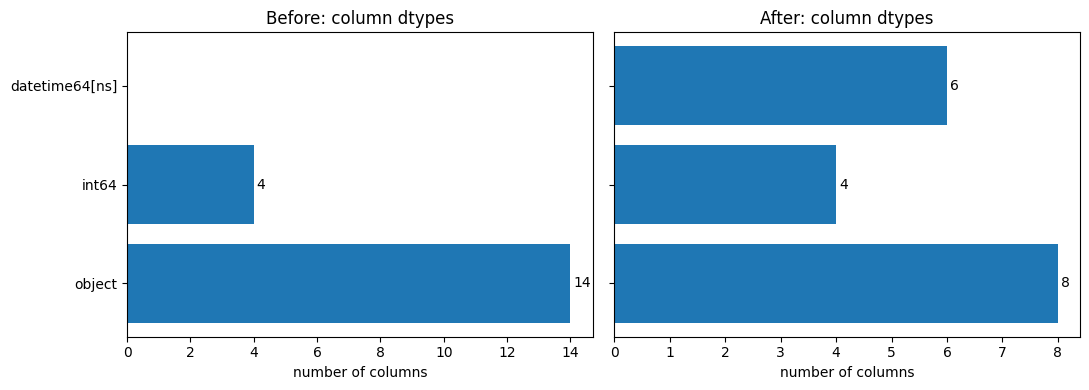

                   min        max
date        1950-05-13 2024-12-08
fp1_date    2021-03-26 2024-12-06
fp2_date    2021-03-26 2024-12-06
fp3_date    2021-03-27 2024-12-07
quali_date  2021-03-27 2024-12-07
sprint_date 2021-07-17 2024-11-30


In [79]:
races_raw = races.copy()   # before: text dates

date_cols = ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']
for c in date_cols:
    races[c] = pd.to_datetime(races[c], format='%Y-%m-%d')

# before vs after: dtype and non-missing count must not change
cmp = pd.DataFrame({
    'dtype_before':  races_raw[date_cols].dtypes.astype(str),
    'dtype_after':   races[date_cols].dtypes.astype(str),
    'filled_before': races_raw[date_cols].notna().sum(),
    'filled_after':  races[date_cols].notna().sum(),
})
cmp['same_count'] = cmp.filled_before == cmp.filled_after
display(cmp)

# visual: dtype per column, before vs after
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, df, title in [(axes[0], races_raw, 'Before'), (axes[1], races, 'After')]:
    counts = df.dtypes.astype(str).value_counts()
    bars = ax.barh(counts.index, counts.values)
    ax.bar_label(bars, padding=2)
    ax.set_title(f'{title}: column dtypes')
    ax.set_xlabel('number of columns')
plt.tight_layout()
plt.show()

print(races[date_cols].agg(['min', 'max']).T)

In [80]:
# primary key: raceId
print('raceId nulls:      ', races.raceId.isna().sum())
print('raceId duplicates: ', races.raceId.duplicated().sum())

# natural key: (year, round)
print('(year, round) duplicates:', races.duplicated(['year', 'round']).sum())

print('date duplicates:', races.duplicated(['date']).sum())

# does each date fall in its season?
print('date.year != year:       ', (races.date.dt.year != races.year).sum())

# does (year, round) order match date order?
by_round = races.sort_values(['year', 'round'])
print('dates in (year, round) order are increasing:', by_round.date.is_monotonic_increasing)

# and does raceId order match date order?
by_id = races.sort_values('raceId')
print('dates in raceId order are increasing:       ', by_id.date.is_monotonic_increasing)

# rounds run 1..n in every season with no gaps
g = races.groupby('year')['round'].agg(['min', 'max', 'count'])
print('seasons where rounds are not 1..n:', ((g['min'] != 1) | (g['max'] != g['count'])).sum())

# foreign keys and links to other tables
res_raw = raw_before['results']
sprint_raw = raw_before['sprint_results']
seasons_raw = raw_before['seasons']
circuits_raw = raw_before['circuits']

print('circuitId nulls:                      ', races.circuitId.isna().sum())
print('circuitId not found in circuits:      ', (~races.circuitId.isin(circuits_raw.circuitId)).sum())
print('races with no result rows:            ', (~races.raceId.isin(res_raw.raceId)).sum())
print('result rows with unknown raceId:      ', (~res_raw.raceId.isin(races.raceId)).sum())
print('season years differing (set() = none):', set(races.year) ^ set(seasons_raw.year))

sprint_ids = set(races.loc[races.sprint_date.notna(), 'raceId'])
print('races in sprint_results:              ', sprint_raw.raceId.nunique())
print('matches the sprint weekends:          ', set(sprint_raw.raceId) == sprint_ids)

raceId nulls:       0
raceId duplicates:  0
(year, round) duplicates: 0
date duplicates: 0
date.year != year:        0
dates in (year, round) order are increasing: True
dates in raceId order are increasing:        False
seasons where rounds are not 1..n: 0
circuitId nulls:                       0
circuitId not found in circuits:       0
races with no result rows:             0
result rows with unknown raceId:       0
season years differing (set() = none): set()
races in sprint_results:               18
matches the sprint weekends:           True


### races: data types and keys

**Format check.** Every date column has one pattern (`YYYY-MM-DD`) and every time column has one pattern (`HH:MM:SS`). No stray formats, so nothing needs cleaning in the text itself.

**What was fixed.** Six columns were stored as text (`object`) and are now real dates (`datetime64[ns]`): `date`, `fp1_date`, `fp2_date`, `fp3_date`, `quali_date`, `sprint_date`. The IDs (`raceId`, `year`, `round`, `circuitId`) were already `int64`. `name` and `url` are text, which is correct.

**Check.** Non-missing counts are identical before and after for all six columns, so the conversion lost nothing. The format was given explicitly, so a bad value would have raised an error and not turned silently into a missing value.

**Time columns left as text.** A time of day alone has no date. We combine them with the date into a timestamp only if a feature needs it.

**Date ranges after conversion.**
- `date`: 1950-05-13 to 2024-12-08, the full range of the dataset.
- All session dates start in 2021 and end in 2024. Nothing before 2021 has session dates.
- The first sprint date is 2021-07-17, in line with the sprint format being introduced in 2021.

**Primary key.** `raceId` has 0 nulls and 0 duplicates, so it is a valid primary key.

**Natural keys.** `(year, round)` is unique, and `date` is unique too (0 duplicates), so every race has its own date and either one gives a tie-free ordering. Rounds run 1 to n in every season with no gaps.

**Date vs season.** Every `date` falls in the season given by `year`, and sorting by `(year, round)` gives increasing dates, so the two orderings agree.

**Do not order by `raceId`.** In `raceId` order the dates do not increase (the first rows are 2009 races), so `raceId` is an identifier and not a timeline.

**How we use them.** We can use `date` for ordering races (it is unique and always increasing), and `year` and `round` for season structure (which season, which race of it). They both give the same order and are valid. Never use `raceId` for ordering.

**Foreign keys and links to other tables.** `circuitId` has 0 nulls and 0 orphans against `circuits`. Every race has result rows and every result row points to a known race, so the link in both directions is complete. Every season year in `races` exists in `seasons` and the other way round. The 18 races with a sprint date are exactly the races in `sprint_results`, so the sprint table lines up with the schedule.

**Why this matters.** Real dates allow date arithmetic (days since a driver's last race, month of the race), and the ordering rule above is what keeps rolling features from looking at the future.

**Next.** Why the session and time columns are missing, and what each gap means.

In [81]:
mask = races.isna()

coverage = pd.DataFrame({
    'n_missing': mask.sum(),
    'pct_missing': (mask.mean() * 100).round(1),
    'first_year_with_value': {c: races.loc[~mask[c], 'year'].min() for c in races.columns},
    'last_year_missing': {c: races.loc[mask[c], 'year'].max() for c in races.columns},
})
coverage

,n_missing,pct_missing,first_year_with_value,last_year_missing
raceId,0,0.0,1950,NaN
year,0,0.0,1950,NaN
round,0,0.0,1950,NaN
circuitId,0,0.0,1950,NaN
name,0,0.0,1950,NaN
date,0,0.0,1950,NaN
time,731,65.0,2005,2004.0
url,0,0.0,1950,NaN
fp1_date,1035,92.0,2021,2020.0
fp1_time,1057,94.0,2022,2021.0


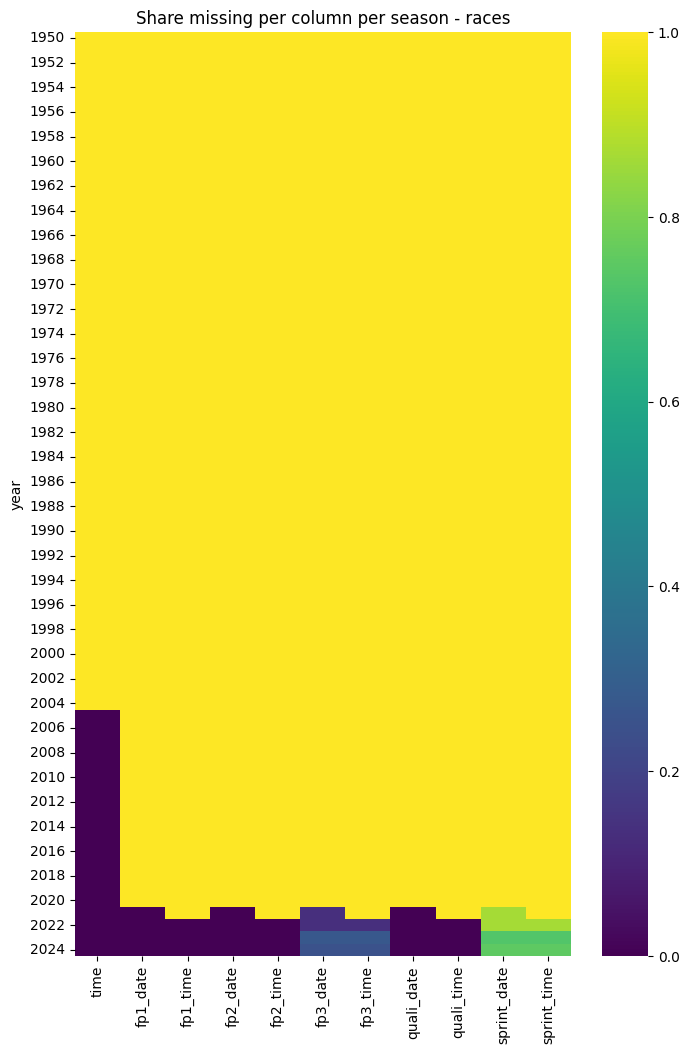

In [82]:
gap_cols = [c for c in races.columns if mask[c].any()]
share = mask[gap_cols].groupby(races.year).mean()
plt.figure(figsize=(8, 12))
sns.heatmap(share, cmap='viridis')
plt.title('Share missing per column per season - races')
plt.show()

In [83]:
# why 2021 has dates but no times
pairs = [('fp1_date', 'fp1_time'), ('quali_date', 'quali_time'),
         ('fp3_date', 'fp3_time'), ('sprint_date', 'sprint_time')]

for d, t in pairs:
    m = races[d].notna() & races[t].isna()
    print(d, '| date filled, time missing:', m.sum(), '| years:', sorted(races.loc[m, 'year'].unique()))

fp1_date | date filled, time missing: 22 | years: [np.int64(2021)]
quali_date | date filled, time missing: 22 | years: [np.int64(2021)]
fp3_date | date filled, time missing: 19 | years: [np.int64(2021)]
sprint_date | date filled, time missing: 3 | years: [np.int64(2021)]


In [84]:
# why fp3_* is still partly empty after 2021
recent = races[races.year >= 2021]
print(pd.crosstab(recent.fp3_date.isna().rename('fp3_missing'),
                  recent.sprint_date.notna().rename('has_sprint')))

has_sprint   False  True 
fp3_missing              
False           72      0
True             0     18


In [85]:
q = races[races.quali_date.notna()].copy()
q['gap'] = (q.date - q.quali_date).dt.days
q['sprint'] = q.sprint_date.notna()

print(q.gap.value_counts().sort_index())
print(pd.crosstab(q.gap, q.sprint, rownames=['days quali -> race'], colnames=['sprint weekend']))

# the exceptions: sprint with 1-day gap, or normal weekend with 2-day gap
display(q[(q.sprint & (q.gap == 1)) | (~q.sprint & (q.gap == 2))]
        [['year', 'round', 'name', 'quali_date', 'sprint_date', 'date', 'gap']])

display(races.loc[(races.year == 2023) & races.name.str.contains('Las Vegas'),
                  ['name', 'quali_date', 'quali_time', 'date', 'time']])

gap
1    77
2    13
Name: count, dtype: int64
sprint weekend      False  True 
days quali -> race              
1                      71      6
2                       1     12


,year,round,name,quali_date,sprint_date,date,gap
1099,2023,21,Las Vegas Grand Prix,2023-11-17,NaT,2023-11-19,2
1105,2024,5,Chinese Grand Prix,2024-04-20,2024-04-20,2024-04-21,1
1106,2024,6,Miami Grand Prix,2024-05-04,2024-05-04,2024-05-05,1
1111,2024,11,Austrian Grand Prix,2024-06-29,2024-06-29,2024-06-30,1
1119,2024,19,United States Grand Prix,2024-10-19,2024-10-19,2024-10-20,1
1121,2024,21,São Paulo Grand Prix,2024-11-02,2024-11-02,2024-11-03,1
1123,2024,23,Qatar Grand Prix,2024-11-30,2024-11-30,2024-12-01,1


,name,quali_date,quali_time,date,time
1099,Las Vegas Grand Prix,2023-11-17,08:00:00,2023-11-19,06:00:00


### races: missing values

**Complete columns.** `raceId`, `year`, `round`, `circuitId`, `name`, `date`, `url` have no missing values.

**Missingness follows eras, not chance.**
- `time` (race start time) is missing for 731 of 1,125 races (65%): empty up to 2004, recorded from 2005.
- Practice and qualifying dates are recorded from 2021 (1,035 missing, 92%). Their times are recorded from 2022 (1,057 missing, 94%), so 2021 has dates but no times.
- `fp3_*` and `sprint_*` stay partly empty after 2021: FP3 is missing on exactly the 18 sprint weekends and nowhere else, and sprint columns exist only on those 18 weekends.
- Every other column has a clean cut-off: its last missing season comes right before its first recorded season.

**Two meanings of missing.** *Not recorded* (sessions before 2021, race start times before 2005) is genuinely missing data. *Did not exist* (no FP3 on a sprint weekend, no sprint on a normal weekend) is a real answer and must not be imputed.

**What the columns hold.** The `fp*`, `quali_*` and `sprint_*` columns only record when each session was scheduled. Practice results are not in the dataset, and qualifying results are in the `qualifying` table. Where a qualifying date exists, it is always 1 or 2 days before the race, so using qualifying information at prediction time is allowed.

**Decision.** These columns only exist from 2021, so any training window that ends before 2021 sees them completely empty, and a model cannot learn from an empty column. They are not used as features. Columns that could be carried into the modelling table are `raceId`, `year`, `round`, `circuitId`, `name`, `date`. `time` and `url` are kept for reference only.

**One caveat.** In 2021-2022 the sprint result set the Sunday grid (per the F1 background document), so on those weekends `grid` differs from qualifying position for a reason other than penalties. The model's seasons include them (2021 is in validation and in the final training, 2022 in the test), so on these 6 sprint weekends `grid_minus_quali` partly reflects the sprint and not a penalty. They are 6 of the 428 races the model uses, so the effect is small (sprints are tested in 7.9).

count    75.000000
mean     15.000000
std       4.197812
min       7.000000
25%      11.000000
50%      16.000000
75%      17.000000
max      24.000000
dtype: float64

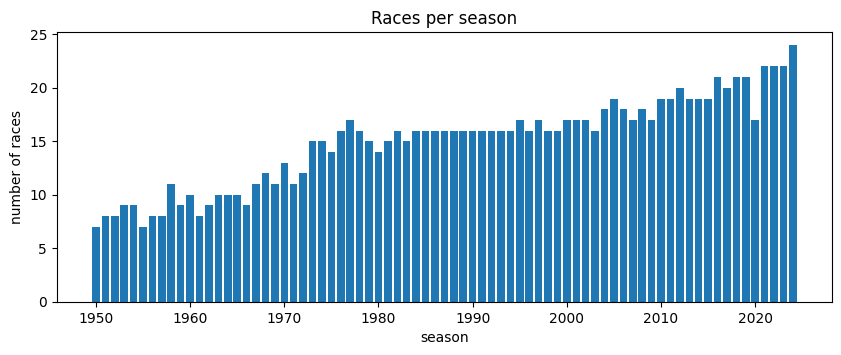

In [86]:
per_season = races.groupby('year').size()
display(per_season.describe())

plt.figure(figsize=(10, 3.5))
plt.bar(per_season.index, per_season.values)
plt.xlabel('season')
plt.ylabel('number of races')
plt.title('Races per season')
plt.show()

In [87]:
per_season = races.groupby('year').size()
by_decade = per_season.groupby(per_season.index // 10 * 10).agg(['min', 'max', 'mean'])
print(by_decade.round(1))
print('fewest races in a season:', per_season.idxmin(), per_season.min())
print('most races in a season:  ', per_season.idxmax(), per_season.max())


      min  max  mean
year                
1950    7   11   8.4
1960    8   12  10.0
1970   11   17  14.4
1980   14   16  15.6
1990   16   17  16.2
2000   16   19  17.4
2010   19   21  19.8
2020   17   24  21.4
fewest races in a season: 1950 7
most races in a season:   2024 24


### races: the calendar over the eras

**Races per season.** The calendar grew steadily. The average was 8.4 races per season in the 1950s, 14 to 16 in the 1970s and 1980s, 17 in the 2000s, 20 in the 2010s and 21 in the 2020s. The shortest season has 7 races (1950) and the longest has 24 (2024).

**Consequence for features.** Season totals are not comparable across eras, so we convert them to rates, such as points per race or share of the points available. Rolling features over the last N races are not affected.


### Indianapolis 500: what the data shows

In [88]:
indy = races[races.name.str.contains('Indianapolis', case=False)]
display(indy[['raceId', 'year', 'round', 'circuitId', 'name']])

print('races at the Indianapolis circuit:', (races.circuitId == indy.circuitId.mode()[0]).sum())
print('of those, named Indianapolis 500:  ', len(indy))


,raceId,year,round,circuitId,name
747,748,1960,3,19,Indianapolis 500
756,757,1959,2,19,Indianapolis 500
767,768,1958,4,19,Indianapolis 500
777,778,1957,3,19,Indianapolis 500
785,786,1956,3,19,Indianapolis 500
793,794,1955,3,19,Indianapolis 500
799,800,1954,2,19,Indianapolis 500
808,809,1953,2,19,Indianapolis 500
817,818,1952,2,19,Indianapolis 500
825,826,1951,2,19,Indianapolis 500


races at the Indianapolis circuit: 19
of those, named Indianapolis 500:   11


In [89]:
indy_ids = indy.raceId
print('races on circuitId 19:', (races.circuitId == 19).sum(), '| named Indianapolis 500:', len(indy))
print(races.loc[races.circuitId == 19, ['year', 'name']].query('name != "Indianapolis 500"'))

r = results_unique[results_unique.raceId.isin(indy_ids)].merge(races[['raceId', 'year']], on='raceId')

# how many drivers raced there, and how many of them raced anywhere else in F1
indy_drivers = set(r.driverId)
other = results_unique[~results_unique.raceId.isin(indy_ids)]
only_indy = indy_drivers - set(other.driverId)
print('drivers in Indy 500:', len(indy_drivers), '| who never raced a non-Indy F1 race:', len(only_indy))

# share of Indy rows held by drivers who only ever raced there
print('share of Indy result rows from Indy-only drivers:', round(r.driverId.isin(only_indy).mean(), 2))

# field size per race and statuses, to compare with normal races of the same years
print(r.groupby('year').size().rename('Indy field size'))
print(r.merge(raw_before['status'], on='statusId').status.value_counts().head(8))


races on circuitId 19: 19 | named Indianapolis 500: 11
     year                      name
41   2007  United States Grand Prix
61   2006  United States Grand Prix
78   2005  United States Grand Prix
97   2004  United States Grand Prix
121  2003  United States Grand Prix
138  2002  United States Grand Prix
155  2001  United States Grand Prix
171  2000  United States Grand Prix
drivers in Indy 500: 107 | who never raced a non-Indy F1 race: 103
share of Indy result rows from Indy-only drivers: 0.95
year
1950    34
1951    34
1952    33
1953    37
1954    42
1955    35
1956    34
1957    33
1958    33
1959    33
1960    33
Name: Indy field size, dtype: int64
status
Finished        124
Accident         43
Engine           23
Magneto          14
Spun off         12
+4 Laps          11
Oil leak         11
Transmission     10
Name: count, dtype: int64


### Indianapolis 500: decision

**What it is.** Eleven races in the table are named "Indianapolis 500", one per season from 1950 to 1960. The race counted for the world championship in those years but was run to different rules from the rest of the calendar.

**How to identify it.** We identify it by race name and not by circuit. The same circuit (`circuitId` 19) also hosted 8 races named "United States Grand Prix" between 2000 and 2007, which are normal Formula 1 races and must stay in.

**How it differs.** 107 drivers started the Indianapolis 500, and 103 of them never started any other Formula 1 race, so 95% of its result rows belong to drivers who appear nowhere else. The field was 33 to 42 cars, which is a different grid structure from the other races of the time.

**Effect on the questions.** It would distort the home-country question, because American drivers racing at Indianapolis would count as home races. For the circuit question it would add a circuit with 11 races in the old era only. The 2014 to 2024 mechanical-retirement question does not touch it.

**Decision.** We keep the 11 rows in the cleaned table and flag them, and we exclude them from the modelling table and from the home-country question. Every answer states whether it kept or excluded them.


In [90]:
indy_500_ids = races.loc[races.name == 'Indianapolis 500', 'raceId']
results_unique['is_indy500'] = results_unique.raceId.isin(indy_500_ids)
print(results_unique.is_indy500.sum(), 'result rows flagged')

381 result rows flagged


**Why we exclude them from the modelling table.** The Indianapolis 500 races follow different rules from the rest of the championship, and the data shows it. 103 of the 107 drivers who started them never started any other Formula 1 race, so 95% of their result rows come from drivers with no history anywhere else, and the history features we plan to build would be empty or meaningless for them. The fields were also much larger, 33 to 42 cars, so a grid position does not mean the same thing as in a normal race. All 11 races are from 1950 to 1960, which is far from the races we want to predict.

**Effect on the modelling table.** Excluding them removes 381 rows, about 1.4% of the 26,668 rows, and 11 of the 1,125 races. The 8 United States Grand Prix races held at the same circuit between 2000 and 2007 stay in, because we filter by race name and not by circuit. The rows are flagged with `is_indy500` in the cleaned table and removed only when the modelling table is built, after the history features, so no other driver's features are affected.


## `Circuits Table`

In [91]:
circuits = load('circuits')

print('shape:', circuits.shape)

shape: (77, 9)


In [92]:
display(circuits.head())

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [93]:
print(circuits.dtypes)

circuitId       int64
circuitRef     object
name           object
location       object
country        object
lat           float64
lng           float64
alt             int64
url            object
dtype: object


In [94]:
print('\nmissing per column:')
print(circuits.isna().sum())


missing per column:
circuitId     0
circuitRef    0
name          0
location      0
country       0
lat           0
lng           0
alt           0
url           0
dtype: int64


In [95]:
# primary key
print('circuitId nulls:     ', circuits.circuitId.isna().sum())
print('circuitId duplicates:', circuits.circuitId.duplicated().sum())

# other columns that should also be unique
print('circuitRef duplicates:', circuits.circuitRef.duplicated().sum())
print('name duplicates:      ', circuits.name.duplicated().sum())

# value ranges
print(circuits[['lat', 'lng', 'alt']].describe())
print('lat outside -90..90:  ', (~circuits.lat.between(-90, 90)).sum())
print('lng outside -180..180:', (~circuits.lng.between(-180, 180)).sum())
print('alt <= 0:             ', (circuits.alt <= 0).sum())

# countries
print(circuits.country.value_counts())

# does every circuit get used?
print('circuits with no race:', (~circuits.circuitId.isin(races.circuitId)).sum())

circuitId nulls:      0
circuitId duplicates: 0
circuitRef duplicates: 0
name duplicates:       0
             lat         lng          alt
count  77.000000   77.000000    77.000000
mean   33.442925    1.076683   247.012987
std    22.808866   65.516951   362.738469
min   -37.849700 -118.189000    -7.000000
25%    32.777400   -9.394170    18.000000
50%    40.951700    3.930830   129.000000
75%    46.958900   19.248600   332.000000
max    57.265300  144.968000  2227.000000
lat outside -90..90:   0
lng outside -180..180: 0
alt <= 0:              3
country
USA              11
France            7
Spain             6
Italy             4
Portugal          4
UK                4
Germany           3
Belgium           3
Canada            3
Japan             3
Australia         2
Austria           2
Brazil            2
South Africa      2
Malaysia          1
Bahrain           1
Hungary           1
Turkey            1
Monaco            1
United States     1
China             1
Singapore         1
A

In [96]:
print(circuits.loc[circuits.alt <= 0, ['circuitRef', 'country', 'alt']])
print(circuits.loc[circuits.country == 'United States', ['circuitRef', 'name', 'location', 'country']])

   circuitRef     country  alt
34    yeongam       Korea    0
71       baku  Azerbaijan   -7
76      miami         USA    0
   circuitRef                            name   location        country
22      vegas  Las Vegas Strip Street Circuit  Las Vegas  United States


### circuits: keys and checks

**Grain.** One row is one physical track, 77 rows and 9 columns. `circuitId` is the identifier, `circuitRef` is a short text code, and `country` and `location` say where the track is.

**Types and missing values.** The IDs and `alt` are integers, the coordinates are floats and the rest is text, so nothing needed converting. No column has missing values, and loading with `\N` as missing found none to convert.

**Primary key.** `circuitId` has 0 nulls and 0 duplicates, so it is a valid primary key. `circuitRef` and `name` are also unique.

**Foreign keys.** The table has no foreign keys of its own, because other tables point to it. The link from `races.circuitId` was checked in the races section with 0 orphans, and all 77 circuits are used by at least one race.

**Ranges.** Latitude and longitude are inside their valid ranges. Altitude runs from -7 m to 2,227 m. Three circuits are at or below 0 m, which are Baku at -7 m, which is real since the track is below sea level, and Yeongam and Miami at 0 m, which are plausible for coastal tracks. Altitude is not used as a feature.

**Country spelling.** `country` writes the United States two ways, `USA` for 11 circuits and `United States` for the Las Vegas Strip Street Circuit. Short forms such as `UK`, `UAE` and `Korea` also won't match driver nationalities directly. We make the spelling consistent on the cleaned copy in *circuits and drivers: countries and nationalities* (`United States` becomes `USA`); the CSV is not changed. The short forms are kept, and the nationality-to-country map in Q2 matches them to driver nationalities.

,circuitId,name,country,n_races,first,last
0,14,Autodromo Nazionale di Monza,Italy,74,1950,2024
1,6,Circuit de Monaco,Monaco,70,1950,2024
2,9,Silverstone Circuit,UK,59,1950,2024
3,13,Circuit de Spa-Francorchamps,Belgium,57,1950,2024
4,7,Circuit Gilles Villeneuve,Canada,43,1978,2024
5,18,Autódromo José Carlos Pace,Brazil,41,1973,2024
6,20,Nürburgring,Germany,41,1951,2020
7,11,Hungaroring,Hungary,39,1986,2024
8,70,Red Bull Ring,Austria,38,1970,2024
9,10,Hockenheimring,Germany,37,1970,2019


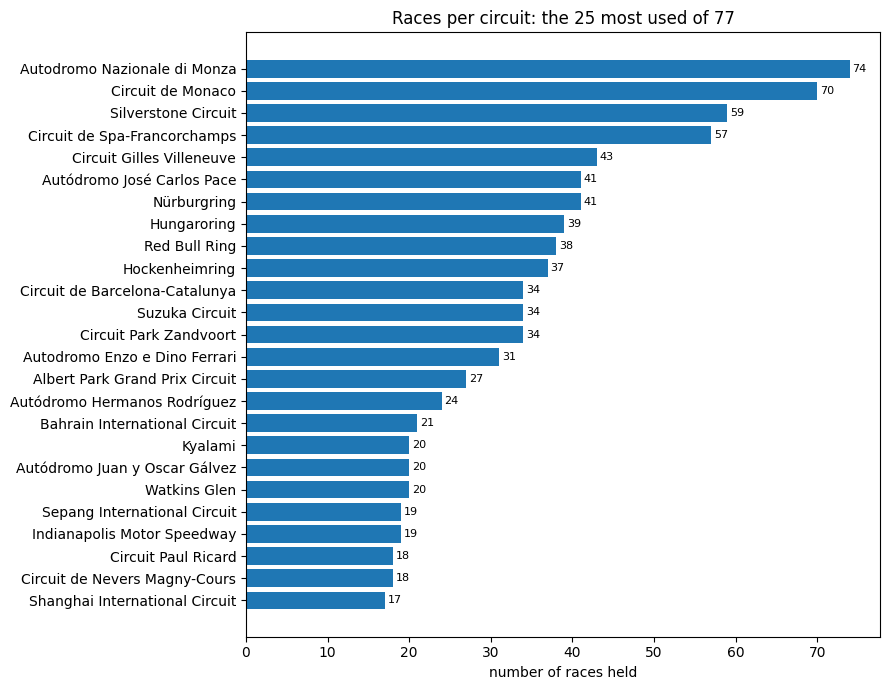

In [97]:
usage = (races.groupby('circuitId')
         .agg(n_races=('raceId', 'size'), first=('year', 'min'), last=('year', 'max')))
cu = (circuits.merge(usage, left_on='circuitId', right_index=True)
      .sort_values('n_races', ascending=False)
      [['circuitId', 'name', 'country', 'n_races', 'first', 'last']]
      .reset_index(drop=True))

with pd.option_context('display.max_rows', None):
    display(cu)

# picture: the 25 most used circuits (the full list is the table above)
top_cu = cu.head(25)[::-1]
plt.figure(figsize=(9, 7))
bars = plt.barh(top_cu.name, top_cu.n_races)
plt.bar_label(bars, padding=2, fontsize=8)
plt.xlabel('number of races held')
plt.title('Races per circuit: the 25 most used of 77')
plt.tight_layout()
plt.show()

In [98]:
# trap 1: a circuit hosting two races in one season
per_year_circuit = races.groupby(['year', 'circuitId']).size().reset_index(name='n_races')
twice = per_year_circuit[per_year_circuit.n_races > 1].merge(circuits[['circuitId', 'name']], on='circuitId')
print('circuit-seasons with more than one race:', len(twice))
display(twice)

# trap 2: a circuit with more than one Grand Prix name
names = (races.groupby('circuitId').name
         .agg(n_names='nunique', gp_names=lambda s: sorted(s.unique())))
multi = names[names.n_names > 1].merge(circuits[['circuitId', 'name']], left_index=True, right_on='circuitId')
print('circuits with more than one GP name:', len(multi))
display(multi.sort_values('n_names', ascending=False)[['name', 'n_names', 'gp_names']])


circuit-seasons with more than one race: 4


,year,circuitId,n_races,name
0,2020,3,2,Bahrain International Circuit
1,2020,9,2,Silverstone Circuit
2,2020,70,2,Red Bull Ring
3,2021,70,2,Red Bull Ring


circuits with more than one GP name: 12


,name,n_names,gp_names
19,Nürburgring,4,"[Eifel Grand Prix, European Grand Prix, German..."
20,Autodromo Enzo e Dino Ferrari,3,"[Emilia Romagna Grand Prix, Italian Grand Prix..."
2,Bahrain International Circuit,2,"[Bahrain Grand Prix, Sakhir Grand Prix]"
8,Silverstone Circuit,2,"[70th Anniversary Grand Prix, British Grand Prix]"
18,Indianapolis Motor Speedway,2,"[Indianapolis 500, United States Grand Prix]"
17,Autódromo José Carlos Pace,2,"[Brazilian Grand Prix, São Paulo Grand Prix]"
25,Circuito de Jerez,2,"[European Grand Prix, Spanish Grand Prix]"
31,Autódromo Hermanos Rodríguez,2,"[Mexican Grand Prix, Mexico City Grand Prix]"
37,Brands Hatch,2,"[British Grand Prix, European Grand Prix]"
40,Dijon-Prenois,2,"[French Grand Prix, Swiss Grand Prix]"


### circuits: usage over time

**How often each circuit was used.** The 77 circuits are very uneven. Half of them hosted 8 races or fewer, a quarter hosted 3 or fewer, and 11 hosted exactly one race. At the other end, Monza hosted 74 races, Monaco 70, Silverstone 59, Spa 57 and Gilles Villeneuve 43, and all but the last of these have been used since 1950.

**Circuits still in use.** Only 24 of the 77 circuits were used in 2024, so about two thirds of the circuits no longer appear on the calendar. The set of tracks therefore changes a lot over the decades, and a circuit-level statistic is only meaningful for tracks with enough races in the period being studied.

**Two traps for later joins.** A circuit can host two races in the same season, which happened in 2020 and 2021, so a circuit and a year do not identify a race and `raceId` should be used instead. A circuit can also host Grands Prix under several names, for example the Nürburgring under four, so grouping by race name would split one track into several groups. We identify a track by `circuitId`, never by race name.


## `Drivers Table`

In [99]:
drivers = load('drivers')
print('shape:', drivers.shape)

shape: (861, 9)


In [100]:
display(drivers.head())

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [101]:
print(drivers.dtypes)

driverId         int64
driverRef       object
number         float64
code            object
forename        object
surname         object
dob             object
nationality     object
url             object
dtype: object


In [102]:
print('\nmissing per column:')
print(drivers.isna().sum())


missing per column:
driverId         0
driverRef        0
number         802
code           757
forename         0
surname          0
dob              0
nationality      0
url              0
dtype: int64


In [103]:
# format of dob (digits replaced by 9)
print(drivers.dob.str.replace(r'\d', '9', regex=True).value_counts())

# code should always be 3 letters, number should be whole
print(drivers.code.dropna().str.len().value_counts())
print('non-whole numbers:', (drivers.number.dropna() % 1 != 0).sum())

# first and last season each driver raced
yrs = (results_unique.merge(races[['raceId', 'year']], on='raceId')
       .groupby('driverId').year.agg(first='min', last='max'))
d = drivers.merge(yrs, left_on='driverId', right_index=True, how='left')

print('drivers with no result rows:', d['first'].isna().sum())
print('\nwith a number:');    print(d.loc[d.number.notna(), ['first', 'last']].describe().loc[['min', 'max']])
print('\nwith a code:');      print(d.loc[d.code.notna(), ['first', 'last']].describe().loc[['min', 'max']])

dob
9999-99-99    861
Name: count, dtype: int64
code
3    104
Name: count, dtype: int64
non-whole numbers: 0
drivers with no result rows: 0

with a number:
      first    last
min  2000.0  2014.0
max  2024.0  2024.0

with a code:
      first    last
min  1959.0  1968.0
max  2024.0  2024.0


,drivers,with_number,with_code,number_missing_pct,code_missing_pct
debut_decade,,,,,
1950,332,0,1,100.0,99.7
1960,145,0,0,100.0,100.0
1970,135,0,0,100.0,100.0
1980,79,0,0,100.0,100.0
1990,66,0,12,100.0,81.8
2000,49,11,36,77.6,26.5
2010,41,34,41,17.1,0.0
2020,14,14,14,0.0,0.0


Drivers who debuted from 2014: 38 | with a number: 38 | with a code: 38

Debut before 1990 but with a code:
    driverRef code  debut_year
375   bianchi  BIA        1959


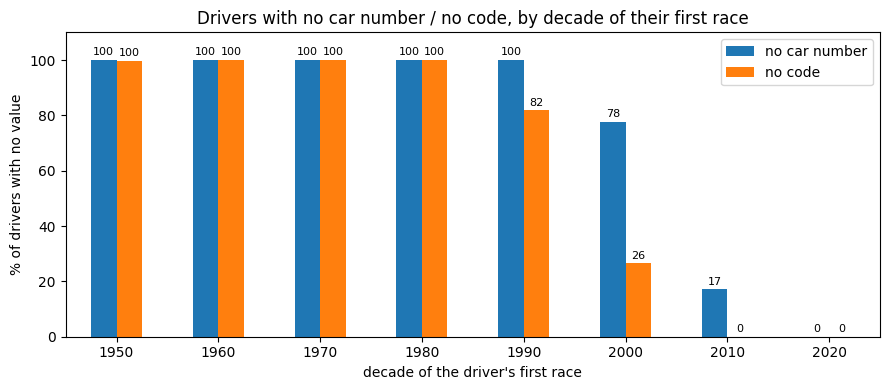

In [104]:
# first season of each driver, from the deduplicated results
debut = (results_unique.merge(races[['raceId', 'year']], on='raceId')
         .groupby('driverId').year.min())

d = drivers.assign(debut_year=drivers.driverId.map(debut))
d['debut_decade'] = d.debut_year // 10 * 10

# exact counts and percentages per decade of debut
by_decade = d.groupby('debut_decade').agg(
    drivers=('driverId', 'size'),
    with_number=('number', lambda s: int(s.notna().sum())),
    with_code=('code', lambda s: int(s.notna().sum())))
by_decade['number_missing_pct'] = ((1 - by_decade.with_number / by_decade.drivers) * 100).round(1)
by_decade['code_missing_pct'] = ((1 - by_decade.with_code / by_decade.drivers) * 100).round(1)
display(by_decade)

# drivers who debuted from 2014
recent = d[d.debut_year >= 2014]
print('Drivers who debuted from 2014:', len(recent),
      '| with a number:', int(recent.number.notna().sum()),
      '| with a code:', int(recent.code.notna().sum()))

# old drivers (debut before 1990) that do have a code
print('\nDebut before 1990 but with a code:')
print(d.loc[(d.debut_year < 1990) & d.code.notna(),
            ['driverRef', 'code', 'debut_year']].sort_values('debut_year'))

# bar chart: % of drivers with no number / no code, by decade of first race
ax = by_decade[['number_missing_pct', 'code_missing_pct']].plot.bar(
    figsize=(9, 4), rot=0,
    title="Drivers with no car number / no code, by decade of their first race")
ax.set_xlabel("decade of the driver's first race")
ax.set_ylabel('% of drivers with no value')
ax.set_ylim(0, 110)
ax.legend(['no car number', 'no code'])

# print the exact percent on each bar so rounding can't hide the exceptions
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=8, padding=2)

plt.tight_layout()
plt.show()


### drivers: structure and missing values

**Grain.** One row is one driver, 861 rows and 9 columns. `driverId` is the identifier, `driverRef` is a text code, `forename` and `surname` give the name, `dob` is the date of birth, and `nationality` is the country adjective such as British or German. Every driver appears in the results table, so there are no unused drivers.

**Format check.** `dob` has a single pattern (`YYYY-MM-DD`) in all 861 rows. Every `code` is exactly 3 letters, and every `number` is a whole number, so `number` is stored as a float only because it has missing values.

**Missing values.** Only two columns have gaps, and in both cases the gaps follow the era of the driver's first season and are not random.
- `number` is missing for 802 of 861 drivers, so only 59 have one. All 59 debuted in 2000 or later and were still racing in 2014 or later, so nobody who retired before 2014 has one.
- `code` is missing for 757 drivers, so 104 have one. Among drivers who debuted before 1990, only one has a code, Lucien Bianchi (debut 1959), so this is a single exception and not a pattern.
- All 38 drivers who debuted from 2014 have both a number and a code, so nothing is missing for the modern era.

**What missing means here.** A missing `number` or `code` means it did not exist for that driver in that era, and it does not mean the value was lost. The data shows the pattern. The likely reason, that permanent car numbers were introduced in 2014, is general Formula 1 knowledge that the data does not show.

**Decision.** `number` and `code` are labels and not performance information, so they are not used as features. We keep the missing cells as they are and do not fill them. `nationality` is complete, which matters for the home-country question.

**Next.** Convert `dob` to a real date, check the ages for impossible values, and then check the primary key and the links to other tables.

In [105]:
drivers_raw = drivers.copy()
drivers['dob'] = pd.to_datetime(drivers['dob'], format='%Y-%m-%d')

# before vs after
print('dob dtype before / after:', drivers_raw.dob.dtype, '/', drivers.dob.dtype)
print('dob filled before / after:', drivers_raw.dob.notna().sum(), '/', drivers.dob.notna().sum())
print('dob range:', drivers.dob.min().date(), 'to', drivers.dob.max().date())

# age in the first season each driver raced
yrs = (results_unique.merge(races[['raceId', 'year']], on='raceId')
       .groupby('driverId').year.agg(first='min', last='max'))
d = drivers.merge(yrs, left_on='driverId', right_index=True)
d['age_at_first_season'] = d['first'] - d.dob.dt.year
print(d.age_at_first_season.describe())

# the extremes, to look at by eye
cols = ['driverRef', 'dob', 'first', 'age_at_first_season']
print('\nyoungest at first season:'); print(d.nsmallest(5, 'age_at_first_season')[cols])
print('\noldest at first season:');   print(d.nlargest(5, 'age_at_first_season')[cols])

dob dtype before / after: object / datetime64[ns]
dob filled before / after: 861 / 861
dob range: 1896-12-28 to 2005-05-08
count    861.000000
mean      29.959350
std        6.647571
min       18.000000
25%       25.000000
50%       29.000000
75%       34.000000
max       54.000000
Name: age_at_first_season, dtype: float64

youngest at first season:
             driverRef        dob  first  age_at_first_season
451            monarch 1945-09-03   1963                   18
829     max_verstappen 1997-09-30   2015                   18
152        alguersuari 1990-03-23   2009                   19
190          thackwell 1961-03-30   1980                   19
454  ricardo_rodriguez 1942-02-14   1961                   19

oldest at first season:
     driverRef        dob  first  age_at_first_season
703      legat 1898-11-01   1952                   54
741  etancelin 1896-12-28   1950                   54
750     brudes 1899-10-15   1952                   53
760      dusio 1899-10-13   1952   

In [106]:
drivers.dtypes

driverId                int64
driverRef              object
number                float64
code                   object
forename               object
surname                object
dob            datetime64[ns]
nationality            object
url                    object
dtype: object

In [107]:
# primary key
print('driverId nulls:       ', drivers.driverId.isna().sum())
print('driverId duplicates:  ', drivers.driverId.duplicated().sum())

# other columns that look like identifiers
print('driverRef duplicates: ', drivers.driverRef.duplicated().sum())
print('code duplicates:      ', drivers.code.dropna().duplicated().sum())
print('number duplicates:    ', drivers.number.dropna().duplicated().sum())

# same person twice? (name + date of birth)
print('(forename, surname, dob) duplicates:', drivers.duplicated(['forename', 'surname', 'dob']).sum())

# links to other tables
res_raw = raw_before['results']
print('driverIds in results not found in drivers:', (~res_raw.driverId.isin(drivers.driverId)).sum())
print('drivers with no result rows:              ', (~drivers.driverId.isin(res_raw.driverId)).sum())
print('driverIds in qualifying not in drivers:   ', (~qualifying.driverId.isin(drivers.driverId)).sum())

driverId nulls:        0
driverId duplicates:   0
driverRef duplicates:  0
code duplicates:       7
number duplicates:     11
(forename, surname, dob) duplicates: 0
driverIds in results not found in drivers: 0
drivers with no result rows:               0
driverIds in qualifying not in drivers:    0


In [108]:
shared_code = drivers[drivers.code.notna() & drivers.code.duplicated(keep=False)].sort_values('code')
print(shared_code[['code', 'forename', 'surname', 'dob']])

shared_num = drivers[drivers.number.notna() & drivers.number.duplicated(keep=False)].sort_values('number')
print(shared_num[['number', 'forename', 'surname', 'dob']])


    code    forename     surname        dob
26   ALB  Christijan      Albers 1979-04-16
846  ALB   Alexander       Albon 1996-03-23
375  BIA      Lucien     Bianchi 1934-11-10
823  BIA       Jules     Bianchi 1989-08-03
37   DOO      Robert    Doornbos 1981-09-23
860  DOO        Jack      Doohan 2003-01-20
836  HAR         Rio    Haryanto 1993-01-22
841  HAR     Brendon     Hartley 1989-11-10
75   MAG         Jan   Magnussen 1973-07-04
824  MAG       Kevin   Magnussen 1992-10-05
29   MSC     Michael  Schumacher 1969-01-03
852  MSC        Mick  Schumacher 1999-03-22
817  VER   Jean-Éric      Vergne 1990-04-25
829  VER         Max  Verstappen 1997-09-30
     number  forename     surname        dob
837     2.0   Stoffel   Vandoorne 1992-03-26
856     2.0     Logan    Sargeant 2000-12-31
844     4.0     Lando      Norris 1999-11-13
819     4.0       Max     Chilton 1991-04-21
847     6.0  Nicholas      Latifi 1995-06-29
2       6.0      Nico     Rosberg 1985-06-27
827     9.0    Marcus    

### drivers: codes and numbers are not identifiers

**What we checked.** `driverId` is the only column that identifies a driver. We tested `code` and `number` to see whether they could do the same job, and neither can, because both are reused by different drivers.

**Shared codes.** 7 codes are used by two drivers each, so 14 drivers share a code. The code is built from the first letters of the surname, so drivers with the same or similar surnames collide. The pairs are Albers and Albon (ALB), Lucien and Jules Bianchi (BIA), Doornbos and Doohan (DOO), Haryanto and Hartley (HAR), Jan and Kevin Magnussen (MAG), Michael and Mick Schumacher (MSC), and Vergne and Verstappen (VER). These are different people, not duplicate rows.

**Shared numbers.** 11 numbers are used by two drivers each, so 22 drivers share a number. Examples are Kubica and Haryanto on 88, Button and Tsunoda on 22, and Rosberg and Latifi on 6. They look like the same number used by different drivers in different years, but we did not test whether any pair raced in the same season.

**Why it matters.** A join on `code` would merge Michael and Mick Schumacher into one driver, and a join on `number` would merge unrelated drivers. We use `driverId` for every join.

**No duplicate people.** `driverId` and `driverRef` have 0 duplicates, and no driver appears twice under the same forename, surname and date of birth.


In [109]:
# (a) how circuit countries are written
races_per_country = (races.merge(circuits[['circuitId', 'country']], on='circuitId')
                     .groupby('country').size().rename('races'))
country_table = (circuits.groupby('country').size().rename('circuits')
                 .to_frame().join(races_per_country))

abbreviations = [c for c in country_table.index if c.isupper() and len(c) <= 3]
print('Different country spellings:', len(country_table), '| abbreviations:', abbreviations)
display(country_table.loc[['USA', 'United States']])

usa_merged = circuits.country.replace({'United States': 'USA'})   # a copy, raw stays untouched
print("After merging 'United States' into 'USA':", usa_merged.nunique(), 'countries')

# (b) can circuit countries be matched to driver nationalities as written?
same_words = sorted(set(circuits.country) & set(drivers.nationality))
print('Circuit countries spelled exactly like a nationality:', len(same_words),
      'of', circuits.country.nunique(), '|', same_words)

# (c) the nationality column itself
print('Different nationality values:', drivers.nationality.nunique())
print('Values with stray spaces:',
      list(drivers.nationality[drivers.nationality != drivers.nationality.str.strip()].unique()))
print('Combined or historical values:',
      sorted(n for n in drivers.nationality.unique() if '-' in n or n in {'East German', 'Rhodesian'}))


Different country spellings: 35 | abbreviations: ['UAE', 'UK', 'USA']


,circuits,races
country,,
USA,11,77
United States,1,2


After merging 'United States' into 'USA': 34 countries
Circuit countries spelled exactly like a nationality: 0 of 35 | []
Different nationality values: 43
Values with stray spaces: ['Argentinian ']
Combined or historical values: ['American-Italian', 'Argentine-Italian', 'East German', 'Rhodesian']


### circuits and drivers: countries and nationalities

**What we checked.** The home-country question, and a possible home-race feature, need to match the country of a circuit with the nationality of a driver. We checked whether the two columns can be matched as they are written.

**Circuit countries.** `country` has 35 different spellings. The United States is written two ways, `USA` for 11 circuits (77 races) and `United States` for the Las Vegas circuit (2 races), and after merging them there are 34 countries. `UK`, `UAE` and `USA` are abbreviations, and `Korea` is a short form. The merge is done on the cleaned copy below; the CSV is not changed.

**They cannot be matched directly.** Circuits store a country name such as `UK` or `Germany`, while drivers store an adjective such as `British` or `German`. None of the 35 circuit countries is spelled exactly like a driver nationality, so a direct join would find no home race at all.

**Nationality values.** `nationality` has 43 different values and no missing values. One value, `Argentinian ` (one driver), has a trailing space and is the same nationality as `Argentine` (24 drivers), written another way. Four values do not map to one country, which are `American-Italian`, `Argentine-Italian`, `East German` and `Rhodesian`, because the driver has two nationalities or the country no longer exists.

**Decision.** We make the two spellings consistent on the cleaned copies (the cell below); the CSVs are not changed:
- `United States` becomes `USA` in circuits;
- `Argentinian ` becomes `Argentine` in drivers, which also removes the trailing space.

Countries and nationalities still cannot be joined directly, so Q2 builds one explicit nationality-to-country map. The model has no home-race feature, because Q2 found no detectable home advantage. A driver with two nationalities (`American-Italian`, `Argentine-Italian`) is at home in both countries. `East German` and `Rhodesian` are never at home, because those countries no longer exist. The Indianapolis 500 rows are excluded from Q2, as described above.


In [110]:
# make the two spellings consistent on the cleaned copies (the CSVs are not changed)
country_before, nationality_before = circuits.country.copy(), drivers.nationality.copy()
circuits['country'] = circuits.country.replace({'United States': 'USA'})
drivers['nationality'] = drivers.nationality.str.strip().replace({'Argentinian': 'Argentine'})

print('circuits changed:', (circuits.country != country_before).sum(),
      '| countries:', country_before.nunique(), '->', circuits.country.nunique())
print('drivers changed:', (drivers.nationality != nationality_before).sum(),
      '| nationalities:', nationality_before.nunique(), '->', drivers.nationality.nunique())
assert 'United States' not in set(circuits.country)
assert (drivers.nationality == drivers.nationality.str.strip()).all() and 'Argentinian' not in set(drivers.nationality)

circuits changed: 1 | countries: 35 -> 34
drivers changed: 1 | nationalities: 43 -> 42


## `Constructors Table`

In [111]:
constructors = load('constructors')

print('shape:', constructors.shape)
display(constructors.head())
print(constructors.dtypes)
print('\nmissing per column:')
print(constructors.isna().sum())

shape: (212, 5)


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


constructorId      int64
constructorRef    object
name              object
nationality       object
url               object
dtype: object

missing per column:
constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64


In [112]:
# primary key and other identifier-like columns
print('constructorId nulls:      ', constructors.constructorId.isna().sum())
print('constructorId duplicates: ', constructors.constructorId.duplicated().sum())
print('constructorRef duplicates:', constructors.constructorRef.duplicated().sum())
print('name duplicates:          ', constructors.name.duplicated().sum())

# nationality values
print('\ndifferent nationality values:', constructors.nationality.nunique())
print('values with stray spaces:', list(constructors.nationality[constructors.nationality != constructors.nationality.str.strip()].unique()))
print(constructors.nationality.value_counts())

# links to other tables
res_raw = raw_before['results']
print('\nconstructorIds in results not found in constructors:', (~res_raw.constructorId.isin(constructors.constructorId)).sum())
print('constructors with no result rows:                   ', (~constructors.constructorId.isin(res_raw.constructorId)).sum())
print('constructorIds in qualifying not in constructors:   ', (~qualifying.constructorId.isin(constructors.constructorId)).sum())


constructorId nulls:       0
constructorId duplicates:  0
constructorRef duplicates: 0
name duplicates:           0

different nationality values: 24
values with stray spaces: []
nationality
British          86
American         39
Italian          30
French           13
German           10
Japanese          5
Swiss             5
Dutch             3
South African     3
Russian           2
Malaysian         2
Canadian          2
Indian            1
Austrian          1
Hong Kong         1
Irish             1
Mexican           1
Brazilian         1
New Zealander     1
Australian        1
Rhodesian         1
Belgian           1
East German       1
Spanish           1
Name: count, dtype: int64

constructorIds in results not found in constructors: 0
constructors with no result rows:                    1
constructorIds in qualifying not in constructors:    0


### constructors: structure, keys and missing values

**Grain.** One row is one constructor, meaning a team entry. The table has 212 rows and 5 columns. `constructorId` is the identifier, `constructorRef` is a text code, `name` is the team name, `nationality` is the country adjective of the team, and `url` is the Wikipedia page.

**Types and missing values.** The ID is an integer and the other four columns are text, so nothing needed converting. No column has missing values, and loading with `\N` as missing found none to convert.

**Primary key.** `constructorId` has 0 nulls and 0 duplicates, so it is a valid primary key. `constructorRef` and `name` are also unique.

**Foreign keys.** The table has no foreign keys of its own. Every `constructorId` in `results` and in `qualifying` exists in `constructors`, so there are no orphans. One constructor has no result rows, which is a fact to note and not an error.

**Nationality.** `nationality` has 24 different values, no missing values and no stray spaces. `East German` and `Rhodesian` refer to countries that no longer exist, and `Hong Kong` is not a country in the circuits table, so these would need a rule if constructor nationality were ever matched to a circuit country. We do not plan to use it as a feature.

**Decision.** We keep `constructors` unchanged and use `constructorId` for every join, never `name` or `constructorRef`.

**Next.** Whether one `constructorId` is one continuous team, which matters for the mechanical-retirement question and for any team-form feature.


In [113]:
cars = (results_unique[['raceId', 'constructorId']]
        .merge(races[['raceId', 'year', 'name']].rename(columns={'name': 'race_name'}), on='raceId'))

# (a) activity per constructor
activity = cars.groupby('constructorId').agg(entries=('raceId', 'size'),
                                             first=('year', 'min'), last=('year', 'max'))
teams = constructors.merge(activity, left_on='constructorId', right_index=True, how='left')
print('constructors:', len(teams),
      '| with no result row:', int(teams.entries.isna().sum()), teams[teams.entries.isna()].name.tolist(),
      '| raced a single season only:', int((teams['first'] == teams['last']).sum()),
      '| with 100 or more entries:', int((teams.entries >= 100).sum()))


constructors: 212 | with no result row: 2 ['Eagle', 'Del Roy'] | raced a single season only: 69 | with 100 or more entries: 56


In [114]:
# (b) same Wikipedia page for several constructorIds
same_page = (constructors[constructors.url.duplicated(keep=False)]
             .groupby('url').agg(ids=('constructorId', 'size'),
                                 names=('name', lambda s: ', '.join(sorted(s)[:4]))))
print('constructors sharing a page with another:', int(constructors.url.duplicated(keep=False).sum()),
      'in', len(same_page), 'groups')
display(same_page.sort_values('ids', ascending=False).head(4))


constructors sharing a page with another: 50 in 13 groups


,ids,names
url,,
http://en.wikipedia.org/wiki/Cooper_Car_Company,11,"Cooper, Cooper-ATS, Cooper-Alfa Romeo, Cooper-BRM"
http://en.wikipedia.org/wiki/Team_Lotus,7,"Lotus-BRM, Lotus-Borgward, Lotus-Climax, Lotus..."
http://en.wikipedia.org/wiki/Brabham,6,"Brabham, Brabham-Alfa Romeo, Brabham-BRM, Brab..."
http://en.wikipedia.org/wiki/De_Tomaso,4,"De Tomaso, De Tomaso-Alfa Romeo, De Tomaso-Fer..."


In [115]:
# (c) one id covering separate periods
def longest_break(years):
    years = sorted(years)
    return max([b - a - 1 for a, b in zip(years, years[1:])], default=0)

teams['longest_break_seasons'] = teams.constructorId.map(
    cars.groupby('constructorId').year.apply(lambda s: longest_break(set(s))))
display(teams[(teams.longest_break_seasons >= 5) & (teams.entries >= 50)]
        .sort_values('entries', ascending=False)
        [['name', 'first', 'last', 'entries', 'longest_break_seasons']])

,name,first,last,entries,longest_break_seasons
31,Team Lotus,1958.0,1994.0,871.0,6.0
14,Sauber,1993.0,2024.0,837.0,5.0
3,Renault,1977.0,2020.0,787.0,16.0
33,Brabham,1962.0,1992.0,662.0,6.0
129,Mercedes,1954.0,2024.0,650.0,54.0
20,Arrows,1978.0,2002.0,590.0,6.0
49,Alfa Romeo,1950.0,2023.0,447.0,33.0
115,Aston Martin,1959.0,2024.0,191.0,60.0
25,Lola,1962.0,1997.0,165.0,9.0
52,ATS,1963.0,1984.0,162.0,14.0


In [116]:
# (d) constructors that only ever raced the Indianapolis 500
indy = cars.race_name == 'Indianapolis 500'
only_indy = set(cars[indy].constructorId) - set(cars[~indy].constructorId)
print('constructors that only raced the Indianapolis 500:', len(only_indy),
      '| their entries:', int(cars.constructorId.isin(only_indy).sum()))

constructors that only raced the Indianapolis 500: 30 | their entries: 166


### constructors: is one constructorId one continuous team

**Teams split over several ids.** 50 constructors share a Wikipedia page with another constructor, in 13 groups. The largest groups are Cooper with 11 ids, Team Lotus with 7, Brabham with 6 and De Tomaso with 4. The names, such as Cooper-ATS and Cooper-BRM, suggest that the same car maker was given a new id for each engine pairing, although the data only shows the shared page and not the reason. A team's history is therefore cut into several pieces, and this mostly affects the early decades.

**Ids covering separate periods.** Several large constructors have a long gap between two periods of racing under the same id. Mercedes raced in 1954 and 1955 and then again from 2010 to 2024, with a gap of 54 seasons in between. Aston Martin has a gap of 60 seasons, Honda 37, Alfa Romeo 33 and Renault 16. The data shows the gaps, and it is general Formula 1 knowledge, not something the table shows, that the later period is a different team under the same name.

**How active the constructors were.** Of the 212 constructors, 69 raced a single season only and 56 have 100 or more entries, so the table is made of a few long-lived teams and a long tail of short-lived ones. Team form is only meaningful for the long-lived teams.

**Consequence for features.** A rolling team-form feature that looks back over the last few races of one id would, for Mercedes' first race in 2010, reach back to 1955 and treat those results as recent form. Team form must therefore be limited to recent seasons or restarted after a long gap, and we also need to decide whether to link the ids that are split over several engine pairings.

**Constructors that only raced the Indianapolis 500.** 30 constructors raced only the Indianapolis 500, with 166 entries in total, so they disappear from the modelling table when those rows are excluded.

**Constructors with no results.** In the raw results table one constructor has no rows at all. After the duplicate rule there are two, Eagle and Del Roy. The second one had a single raw row, a 32nd place in race 809 (the 1953 Indianapolis 500), which the rule removed because the same driver has a better-placed row in that race. Removing rows can only leave more constructors empty, so the change from one to two is expected, and neither constructor affects the model.

**Decision.** We keep `constructors` unchanged and join on `constructorId`, never on `name`. The handling of long gaps and split ids is decided when the team-form feature is built.


## `Status Table`

In [117]:
status = load('status')

print('shape:', status.shape)
display(status.head(10))
print(status.dtypes)
print('\nmissing per column:')
print(status.isna().sum())

shape: (139, 2)


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
5,6,Gearbox
6,7,Transmission
7,8,Clutch
8,9,Hydraulics
9,10,Electrical


statusId     int64
status      object
dtype: object

missing per column:
statusId    0
status      0
dtype: int64


In [118]:
# primary key and label uniqueness
print('statusId nulls:       ', status.statusId.isna().sum())
print('statusId duplicates:  ', status.statusId.duplicated().sum())
print('status duplicates:    ', status.status.duplicated().sum())
print('labels with stray spaces:', list(status.status[status.status != status.status.str.strip()]))

# links to results
res_raw = raw_before['results']
print('statusIds in results not found in status:', (~res_raw.statusId.isin(status.statusId)).sum())
print('statuses never used in results:          ', (~status.statusId.isin(res_raw.statusId)).sum())


statusId nulls:        0
statusId duplicates:   0
status duplicates:     0
labels with stray spaces: []
statusIds in results not found in status: 0
statuses never used in results:           2


In [119]:
# how often each status is used (deduplicated results)
counts = (results_unique.merge(status, on='statusId')
          .groupby('status').size().sort_values(ascending=False)
          .rename('rows').to_frame())
counts['share_%'] = (counts.rows / counts.rows.sum() * 100).round(1)

with pd.option_context('display.max_rows', None):
    display(counts)

,rows,share_%
status,,
Finished,7674,28.8
+1 Lap,4036,15.1
Engine,2006,7.5
+2 Laps,1611,6.0
Accident,1053,3.9
Did not qualify,1024,3.8
Collision,854,3.2
Gearbox,804,3.0
Spun off,790,3.0


### status: structure, keys and how often each label is used

**Grain.** One row is one way a driver's race can end, 139 rows and 2 columns. `statusId` is the identifier and `status` is the label, such as `Finished`, `Engine` or `Accident`. It is a lookup table, so nothing is missing and the types need no conversion.

**Primary key.** `statusId` has 0 nulls and 0 duplicates, so it is a valid primary key, and `status` is also unique with no stray spaces.

**Foreign keys.** The table has no foreign keys of its own. Every `statusId` in `results` exists in `status`, and 2 of the 139 statuses are never used.

**What the column mixes.** The labels describe several different things in one column. Some mean the driver finished (`Finished` and the `+N Laps` labels, which are classified but lapped), some are mechanical failures, some are crashes, and some are not retirements at all, such as `Did not qualify` and `Withdrew`. The usage is a long tail. A few labels cover most rows, `Finished` alone is 28.8% and `+1 Lap` is 15.1%, while about 60 labels are used fewer than 10 times.

**Unclear labels.** `Retired`, `Not classified`, `Mechanical` and `Technical` do not say what kind of retirement it was, so they need an explicit rule before any mechanical-retirement rate is computed.

**Decision.** We keep `status` unchanged and group its labels into categories in a separate step, because the grouping is a modelling choice and not a cleaning fix.


lapped statuses: 33 | never used: ['+49 Laps', '+38 Laps'] | used 5 times or fewer: 54


,statuses,entries
group,,
finished,1,7674
"finished, laps down",33,7478
mechanical (clear),58,6217
accident or collision,5,2760
did not start,4,1610
grey zone,29,708
disqualified or excluded,3,156
driver health,6,65


period,2014-2021,2022-2024
mechanical (clear only),8.8,5.4
mechanical + grey zone,11.0,6.8
accident or collision,6.7,6.6


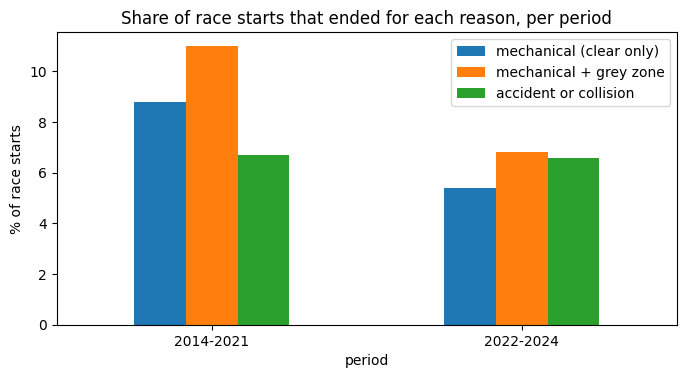

podium finishers with status finished or laps down: 99.8 %


In [120]:
res = results_unique.merge(races[['raceId', 'year']], on='raceId')

status['times_used'] = status.statusId.map(res.statusId.value_counts()).fillna(0).astype(int)
lapped = status.status.str.match(r'^\+\d+ Laps?$')
print('lapped statuses:', int(lapped.sum()),
      '| never used:', status[status.times_used == 0].status.tolist(),
      '| used 5 times or fewer:', int((status.times_used <= 5).sum()))

GROUPS = {
    'did not start': ['Did not qualify', 'Did not prequalify', '107% Rule', 'Withdrew'],
    'disqualified or excluded': ['Disqualified', 'Excluded', 'Underweight'],
    'accident or collision': ['Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident'],
    'driver health': ['Injury', 'Injured', 'Eye injury', 'Illness', 'Driver unwell', 'Physical'],
    'mechanical (clear)': ['Engine', 'Gearbox', 'Suspension', 'Transmission', 'Electrical', 'Brakes', 'Clutch',
        'Fuel system', 'Turbo', 'Hydraulics', 'Overheating', 'Ignition', 'Oil leak', 'Throttle', 'Halfshaft',
        'Oil pressure', 'Fuel pump', 'Differential', 'Fuel leak', 'Steering', 'Radiator', 'Power Unit',
        'Wheel bearing', 'Injection', 'Fuel pressure', 'Water leak', 'Alternator', 'Exhaust', 'Chassis',
        'Mechanical', 'Magneto', 'Driveshaft', 'Axle', 'Battery', 'Power loss', 'Oil pump', 'Distributor',
        'Oil pipe', 'Electronics', 'Water pressure', 'Water pump', 'ERS', 'Supercharger', 'Technical',
        'Pneumatics', 'Fuel pipe', 'Spark plugs', 'Water pipe', 'Drivetrain', 'Track rod', 'Oil line',
        'Engine fire', 'Engine misfire', 'Crankshaft', 'CV joint', 'Cooling system', 'Launch control', 'Brake duct'],
    'grey zone': ['Retired', 'Not classified', 'Out of fuel', 'Wheel', 'Wheel nut', 'Wheel rim', 'Tyre', 'Puncture',
        'Tyre puncture', 'Handling', 'Heat shield fire', 'Fire', 'Vibrations', 'Broken wing', 'Rear wing',
        'Front wing', 'Undertray', 'Damage', 'Debris', 'Fuel', 'Fuel rig', 'Refuelling', 'Stalled', 'Seat',
        'Driver Seat', 'Safety belt', 'Safety', 'Safety concerns', 'Not restarted']}
group_of = {s: g for g, members in GROUPS.items() for s in members}

status['group'] = [('finished' if s == 'Finished' else 'finished, laps down' if lapped[i] else group_of.get(s))
                   for i, s in zip(status.index, status.status)]
assert status.group.notna().all(), 'some status is not placed in a group'
display(status.groupby('group').agg(statuses=('status', 'size'), entries=('times_used', 'sum'))
        .sort_values('entries', ascending=False))

# share of race starts per Q3 period (everyone who did not start is left out: the 'did not start' group and did_not_start)
res['period'] = pd.cut(res.year, [2013, 2021, 2024], labels=['2014-2021', '2022-2024'])
starts = res.merge(status[['statusId', 'group']], on='statusId')
starts = starts[(starts.group != 'did not start') & ~starts.did_not_start & starts.period.notna()]
share = (starts.groupby('period', observed=True).group.value_counts(normalize=True).unstack(0) * 100).round(1)
rates = pd.DataFrame({'mechanical (clear only)': share.loc['mechanical (clear)'],
                      'mechanical + grey zone': share.loc['mechanical (clear)'] + share.loc['grey zone'],
                      'accident or collision': share.loc['accident or collision']})
display(rates.T)

rates.plot.bar(figsize=(8, 3.8), rot=0, title='Share of race starts that ended for each reason, per period')
plt.xlabel('period')
plt.ylabel('% of race starts')
plt.show()

# leakage check: how much of the podium does status give away?
podium = res[res.positionOrder <= 3]
podium_group = podium.statusId.map(status.set_index('statusId').group)
print('podium finishers with status finished or laps down:',
      round(podium_group.isin(['finished', 'finished, laps down']).mean() * 100, 1), '%')


### status: grouping the labels for the mechanical-retirement question

**Why a grouping is needed.** The `status` column mixes finishes, mechanical failures, crashes, driver problems and rule decisions in one list of 139 labels. The brief defines a mechanical retirement as a start that ended early because a component of the car failed, and it excludes crashes, driver causes and regulation decisions, so the labels have to be grouped before a rate can be computed.

**The draft grouping.** Every label is placed in exactly one of eight groups, and the code stops if one is missed. The groups are finished (1 label), finished but laps down (33 labels, the `+N Laps` family), clear mechanical failure (58), accident or collision (5), did not start (4), disqualified or excluded (3), driver health (6) and a grey zone (29). The grey zone holds labels that could be a failure or something else, such as `Retired`, `Not classified`, `Out of fuel`, the tyre and wheel labels and the wing labels. Two labels, `+49 Laps` and `+38 Laps`, are never used.

**How much the grey zone matters.** Counting race starts, and leaving out everyone who did not start, clear mechanical failures end 8.8% of starts in 2014 to 2021 and 5.4% in 2022 to 2024. Adding the whole grey zone gives 11.0% and 6.8%. The fall between the two periods is about the same either way, so the choices about individual grey labels do not change the comparison. Accidents and collisions stay at about 6.6% in both periods.

**Decision.** The grouping is a draft and not a cleaning fix, so `status` itself is unchanged. The question that uses it reports the clear-only rate and states the grey zone as a range.

**Not a feature.** The status of a race is only known after it ends, and 99.8% of podium finishers have a status of finished or finished laps down, so using it would give away the answer. It cannot be used as a model input.

## `Driver Standings Table`

In [121]:
driver_standings = load('driver_standings')

print('shape:', driver_standings.shape)
display(driver_standings.head())
print(driver_standings.dtypes)
print('\nmissing per column:')
print(driver_standings.isna().sum())

shape: (34863, 7)


,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


driverStandingsId      int64
raceId                 int64
driverId               int64
points               float64
position               int64
positionText          object
wins                   int64
dtype: object

missing per column:
driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
dtype: int64


In [122]:
ds_raw = driver_standings.copy()

# keys
print('driverStandingsId nulls:     ', ds_raw.driverStandingsId.isna().sum())
print('driverStandingsId duplicates:', ds_raw.driverStandingsId.duplicated().sum())
print('(raceId, driverId) duplicates:', ds_raw.duplicated(['raceId', 'driverId']).sum())

# links to other tables
print('raceIds not in races:   ', (~ds_raw.raceId.isin(races.raceId)).sum())
print('driverIds not in drivers:', (~ds_raw.driverId.isin(drivers.driverId)).sum())
print('races without any standings:', (~races.raceId.isin(ds_raw.raceId)).sum(), 'of', len(races))


driverStandingsId nulls:      0
driverStandingsId duplicates: 0
(raceId, driverId) duplicates: 0
raceIds not in races:    0
driverIds not in drivers: 0
races without any standings: 0 of 1125


In [123]:
# the rows, in season order
ds = (ds_raw.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
      .sort_values(['year', 'driverId', 'round']))

# is it a running total? points and wins should never go down inside a season
ds['added'] = ds.groupby(['year', 'driverId']).points.diff().fillna(ds.points)
ds['wins_added'] = ds.groupby(['year', 'driverId']).wins.diff().fillna(ds.wins)
print('points ever go down in a season:', int((ds.added < 0).sum()),
      '| wins ever go down:', int((ds.wins_added < 0).sum()))

points ever go down in a season: 0 | wins ever go down: 0


### driver_standings: structure, keys and what a row means

**Grain.** The table has 34,863 rows and 7 columns. One row is a driver's championship standing right after one race. `points` and `wins` are running totals for that season, and `position` is the championship rank at that moment, not the finishing position in the race. Points restart at 0 every season, so a driver's season is grouped by year and driver.

**Types and missing values.** `driverStandingsId`, `raceId`, `driverId`, `position` and `wins` are integers, `points` is a float because half points exist in some old seasons, and `positionText` is text. No column has missing values, so nothing needed converting.

**Primary key.** `driverStandingsId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, driverId)` also has 0 duplicates, so a driver has at most one standing per race.

**Foreign keys.** Every `raceId` exists in `races` and every `driverId` exists in `drivers`, so there are no orphans. Every one of the 1,125 races has standings.

**Running total check.** Inside a season, points never go down and wins never go down, which confirms that each row is a running total and not a per-race score.

**Leakage.** A row is the standing after the race, so it already contains that race's result. For a feature on a given race, we use the standing from the previous round of the same season, ordered by `(year, round)`. In round 1 there is no previous row, so the driver's final position of the previous season is used instead (7.4).

**Next.** Which race starters have no standings row, how the decimal points arise, and how points differ between seasons.


In [124]:
# starters (from deduplicated results) vs standings rows
st = (results_unique[['raceId', 'driverId', 'points']]
      .merge(races[['raceId', 'year']], on='raceId'))
has = ds[['raceId', 'driverId']].assign(has_row=1)
st = st.merge(has, on=['raceId', 'driverId'], how='left')
st['has_row'] = st.has_row.fillna(0).astype(bool)

# standings rows for a driver who has no result row in that race
rows_no_result = ds[['raceId', 'driverId']].merge(
    results_unique[['raceId', 'driverId']].assign(r=1), on=['raceId', 'driverId'], how='left')
print('standings rows with no result row in that race:', int(rows_no_result.r.isna().sum()))

# result rows with no standings row
no_row = st[~st.has_row]
print('result rows with no standings row:', len(no_row), 'of', len(st))
print('by decade (%):', ((1 - st.groupby(st.year // 10 * 10).has_row.mean()) * 100).round(1).to_dict())
print('rows that scored points but have no standings row:',
      int((~st.has_row & (st.points > 0)).sum()), 'of', int((st.points > 0).sum()))

# champion's final points per season (row of the last round, position 1)
last_round = ds.sort_values('round').groupby('year').raceId.last()
champion = ds[ds.raceId.isin(last_round) & (ds.position == 1)].set_index('year').points
print("champion's final points: 1950 =", champion[1950], '| 2009 =', champion[2009],
      '| 2010 =', champion[2010], '| 2023 =', champion[2023])


standings rows with no result row in that race: 8664
result rows with no standings row: 469 of 26668
by decade (%): {1950: 0.1, 1960: 0.1, 1970: 0.1, 1980: 0.2, 1990: 7.0, 2000: 4.1, 2010: 0.1, 2020: 0.0}
rows that scored points but have no standings row: 0 of 8165
champion's final points: 1950 = 30.0 | 2009 = 95.0 | 2010 = 256.0 | 2023 = 575.0


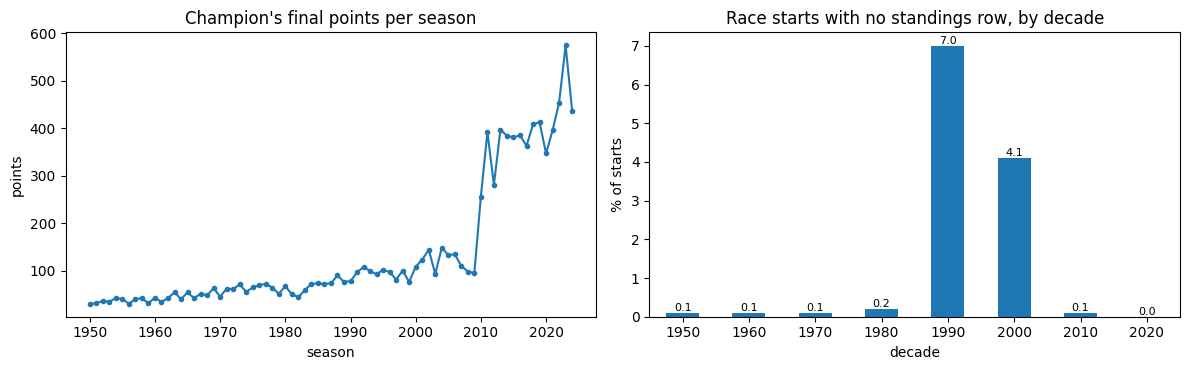

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

champion.plot(ax=axes[0], marker='o', markersize=3)
axes[0].set_title("Champion's final points per season")
axes[0].set_xlabel('season')
axes[0].set_ylabel('points')

miss = ((1 - st.groupby(st.year // 10 * 10).has_row.mean()) * 100).round(1)
miss.plot.bar(ax=axes[1], rot=0)
axes[1].set_title('Race starts with no standings row, by decade')
axes[1].set_xlabel('decade')
axes[1].set_ylabel('% of starts')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f', fontsize=8)

plt.tight_layout()
plt.show()


### driver_standings: who has a standings row

**Standings rows for drivers who did not race.** 8,664 of the 34,863 rows belong to a driver with no result row in that race.

**Starts without a standings row.** 469 of the 26,668 result rows (1.8%) have no standings row. They are concentrated in the 1990s (7.0%) and 2000s (4.1%) and are below 0.3% in every other decade. None of them scored points, so the missing rows belong to drivers with zero points. For these starts the previous-round standing is missing and gets the same fallback as round 1.

**Points are not comparable between seasons.** The champion's final total is 30 in 1950, 95 in 2009, 256 in 2010 and 575 in 2023, because of scoring changes and a longer calendar. Standings points must be turned into rates, such as points per race or share of the points available, before they are used as features.

**Next.** We now check what these 8,664 standings rows are, meaning which drivers they belong to and why they have no result row in that race.


In [126]:
no_result = ds.merge(
    results_unique[['raceId', 'driverId']].assign(r=1),
    on=['raceId', 'driverId'], how='left')
no_result = no_result[no_result.r.isna()].copy()

# did this driver have a result row in an EARLIER round of the same season?
res_year = (results_unique[['raceId', 'driverId']]
            .merge(races[['raceId', 'year', 'round']], on='raceId'))
first_round = res_year.groupby(['year', 'driverId'])['round'].min().rename('first_round')
last_round_d = res_year.groupby(['year', 'driverId'])['round'].max().rename('last_round')

no_result = (no_result.merge(first_round, on=['year', 'driverId'], how='left')
                      .merge(last_round_d, on=['year', 'driverId'], how='left'))

print('total rows with no result row:                         ', len(no_result))
print('no result row, and the driver never raced that season: ', int(no_result.first_round.isna().sum()))
print('raced earlier in the season, absent this round:        ', int((no_result['round'] > no_result.first_round).sum()))
print('raced only later in the season:                        ', int((no_result['round'] < no_result.first_round).sum()))
print('absent after their last race of the season:            ', int((no_result['round'] > no_result.last_round).sum()))


total rows with no result row:                          8664
no result row, and the driver never raced that season:  0
raced earlier in the season, absent this round:         8664
raced only later in the season:                         0
absent after their last race of the season:             6959


**What the 8,664 rows are.** All 8,664 rows belong to drivers who had a result row in an earlier round of the same season, so no row belongs to a driver who never raced that season, and none appears before the driver's first race. Of these, 6,959 (80%) come after the driver's last race of the season, so a driver stays in the table until the season ends. The other 1,705 (20%) are rounds a driver missed and then raced again later in the season. The standings therefore list every driver who has raced so far in the season, and not only the starters of that round.

In [127]:
sprint_raw = raw_before['sprint_results']

# points each driver scored per race weekend: Sunday race + Saturday sprint
scored = (results_unique[['raceId', 'driverId', 'positionOrder', 'points']]
          .rename(columns={'points': 'race_points'})
          .merge(races[['raceId', 'year', 'round']], on='raceId'))
scored = scored.merge(sprint_raw[['raceId', 'driverId', 'points']]
                      .rename(columns={'points': 'sprint_points'}),
                      on=['raceId', 'driverId'], how='left')
scored['sprint_points'] = scored.sprint_points.fillna(0)
scored['scored'] = scored.race_points + scored.sprint_points

# (a) is a row written AFTER its race?
m = ds.merge(scored[['raceId', 'driverId', 'race_points', 'sprint_points', 'scored', 'positionOrder']],
             on=['raceId', 'driverId'], how='left')
m[['race_points', 'sprint_points', 'scored']] = m[['race_points', 'sprint_points', 'scored']].fillna(0)
m['same_as_sunday'] = (m.added - m.race_points).abs() < 1e-6
m['same_as_weekend'] = (m.added - m.scored).abs() < 1e-6

print('standings rows:', len(m),
      '| points added = points scored that weekend:', int(m.same_as_weekend.sum()),
      f'({m.same_as_weekend.mean() * 100:.1f}%)')
print('drivers with no result row that add 0 points:',
      int((m.positionOrder.isna() & (m.added == 0)).sum()), 'of', int(m.positionOrder.isna().sum()))
print('agreement by decade (%):',
      (m.groupby(m.year // 10 * 10).same_as_weekend.mean() * 100).round(1).to_dict())

since_2021 = m[m.year >= 2021]
print('2021-2024: added = Sunday points only:', round(since_2021.same_as_sunday.mean() * 100, 1),
      '% | = Sunday + sprint:', round(since_2021.same_as_weekend.mean() * 100, 1), '%')
bad = m[~m.same_as_weekend]
print('rows that disagree: between', int(bad.year.min()), 'and', int(bad.year.max()), '| count:', len(bad))

# (b) the SAFE version: standings before the race = row of the previous round, same season
by_id = races.sort_values('raceId')
print('\nraceId order equals date order:',
      bool((by_id.raceId.values == races.sort_values('date').raceId.values).all()),
      '| raceIds whose date is earlier than the previous raceId:',
      int((by_id.date < by_id.date.shift(1)).sum()))

after = ds[['year', 'driverId', 'round', 'points']].rename(columns={'points': 'points_after'})
before = after.assign(round=after['round'] + 1).rename(columns={'points_after': 'points_before'})

x = scored.sort_values(['year', 'driverId', 'round']).copy()
x['scored_before'] = x.groupby(['year', 'driverId']).scored.cumsum() - x.scored
x = (x.merge(after, on=['year', 'driverId', 'round'], how='left')
      .merge(before, on=['year', 'driverId', 'round'], how='left'))
x[['points_after', 'points_before']] = x[['points_after', 'points_before']].fillna(0)

later = x[x['round'] > 1].copy()
print('race starts in round 1 (no standings before them):', int((x['round'] == 1).sum()), 'of', len(x))
print('after round 1: standings-before equals points scored in earlier races:',
      round(((later.points_before - later.scored_before).abs() < 1e-6).mean() * 100, 2), '%')


standings rows: 34863 | points added = points scored that weekend: 34778 (99.8%)
drivers with no result row that add 0 points: 8664 of 8664
agreement by decade (%): {1950: 99.3, 1960: 99.5, 1970: 99.8, 1980: 99.7, 1990: 100.0, 2000: 100.0, 2010: 100.0, 2020: 100.0}
2021-2024: added = Sunday points only: 93.2 % | = Sunday + sprint: 100.0 %
rows that disagree: between 1950 and 1990 | count: 85

raceId order equals date order: False | raceIds whose date is earlier than the previous raceId: 61
race starts in round 1 (no standings before them): 1721 of 26668
after round 1: standings-before equals points scored in earlier races: 99.7 %


### driver_standings: is a row written before or after its race

**A row is the standing after the race.** For 99.8% of the 34,863 rows, the points added since the driver's previous row equal what the driver scored that weekend, the Sunday race plus the Saturday sprint. The 85 rows that disagree are all between 1950 and 1990, and from 1990 on the agreement is 100%. Drivers with no result row in a round add 0 points in all 8,664 cases. From 2021 to 2024 the standings include sprint points, since Sunday plus sprint matches in 100% of rows while Sunday alone matches in 93.2%.

**Consequence.** Using the standing of the race being predicted would hand the model that race's result. This is a leak, and it applies to every race.

**The safe version.** The standing before a race is the driver's row from the previous round of the same season. We order by season and round, never by `raceId`, because `raceId` is not in date order (61 raceIds have a date earlier than the previous one). After round 1, the previous-round row equals the points the driver scored in earlier races in 99.7% of cases. Round 1 has no earlier row, which affects 1,721 of the 26,668 race starts. For these, the driver's final position of the previous season is used instead (7.4).


,1950,1960,1970,1980,1990,2000,2010,2020
before the race,0.35,0.33,0.36,0.40,0.42,0.48,0.61,0.60
after the race (leak),0.55,0.53,0.49,0.51,0.51,0.57,0.67,0.66


average rank correlation over all races: {'before the race': 0.46, 'after the race (leak)': 0.57}
winner leads the standings AFTER the race in 48.4 % of races, but led them BEFORE the race in 32.8 % (round 2 onward)


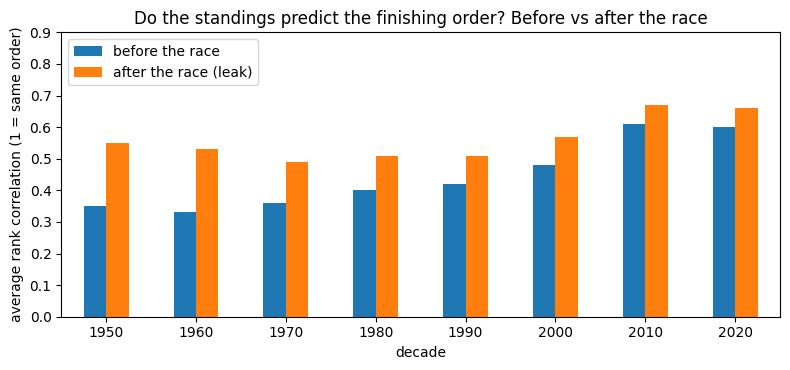

In [128]:
def rank_corr(a, b):
    return np.nan if a.nunique() < 2 or b.nunique() < 2 else a.corr(b)

# rank by points before the race, rank by points after the race, and the real finishing order
later['rank_before'] = later.groupby('raceId').points_before.rank(ascending=False)
later['rank_after'] = later.groupby('raceId').points_after.rank(ascending=False)
later['finish'] = later.groupby('raceId').positionOrder.rank()

leak = pd.DataFrame({
    'before the race': {r: rank_corr(g.rank_before, g['finish']) for r, g in later.groupby('raceId')},
    'after the race (leak)': {r: rank_corr(g.rank_after, g['finish']) for r, g in later.groupby('raceId')}
}).dropna()

year_of = races.set_index('raceId').year
by_decade = leak.groupby(leak.index.map(year_of) // 10 * 10).mean().round(2)
display(by_decade.T)
print('average rank correlation over all races:', leak.mean().round(2).to_dict())

# does the race winner lead the standings after the race, versus before it?
leader_after = ds[ds.position == 1].drop_duplicates('raceId').set_index('raceId').driverId
prev_race = (races.sort_values(['year', 'round'])
             .assign(prev=lambda t: t.groupby('year').raceId.shift(1))
             .set_index('raceId').prev)
winners = results_unique[results_unique.positionOrder == 1].groupby('raceId').driverId.agg(set)

after_ok = [leader_after[r] in winners[r] for r in winners.index if r in leader_after.index]
before_ok = [leader_after[prev_race[r]] in winners[r] for r in winners.index
             if pd.notna(prev_race[r]) and prev_race[r] in leader_after.index]
print('winner leads the standings AFTER the race in', round(np.mean(after_ok) * 100, 1),
      '% of races, but led them BEFORE the race in', round(np.mean(before_ok) * 100, 1), '% (round 2 onward)')

# figure
by_decade.plot.bar(figsize=(8, 3.8), rot=0,
                   title='Do the standings predict the finishing order? Before vs after the race')
plt.xlabel('decade')
plt.ylabel('average rank correlation (1 = same order)')
plt.ylim(0, 0.9)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


### driver_standings: how much the same-race standings would leak

**Rank correlation.** For each race we compared the ranking by championship points with the real finishing order. Averaged over all races, the correlation is 0.46 using the standings before the race and 0.57 using the standings after it. The gap is widest in the 1950s (0.35 against 0.55) and narrows to 0.06 in the 2010s (0.61 against 0.67) and in the 2020s (0.60 against 0.66).

**Winners and the standings.** The race winner leads the championship after the race in 48.4% of races, but was already leading it before the race in 32.8% of races from round 2 onward.

**Decision.** The same-race standing carries that race's result, so it is never used as a feature. The standing from the previous round of the same season is safe, and in the modern era it already tracks the finishing order closely (correlation about 0.6), so it is a useful feature.

In [129]:
season_total = scored.groupby(['year', 'driverId']).scored.sum()      # all points scored in the season
final_row = (ds.sort_values('round').groupby(['year', 'driverId']).tail(1)
             .set_index(['year', 'driverId']).points)                  # final standing points
gap = final_row - season_total.reindex(final_row.index).fillna(0)

lower = gap[gap < -1e-6]
higher = gap[gap > 1e-6]
print('driver-seasons whose final standing is LOWER than points scored:', len(lower),
      '| seasons', int(lower.index.get_level_values(0).min()), 'to', int(lower.index.get_level_values(0).max()))
print('driver-seasons whose final standing is HIGHER:', len(higher))

worst = gap.nsmallest(5).index
big = (pd.DataFrame({'points scored': season_total.reindex(worst),
                     'final standing': final_row.reindex(worst)})
       .reset_index().merge(drivers[['driverId', 'surname']], on='driverId'))
display(big[['surname', 'year', 'points scored', 'final standing']])
print('seasons with a LOWER gap:', sorted(lower.index.get_level_values(0).unique().tolist()))


driver-seasons whose final standing is LOWER than points scored: 50 | seasons 1950 to 1990
driver-seasons whose final standing is HIGHER: 3


,surname,year,points scored,final standing
0,Clark,1963,73.00,54.0
1,Prost,1988,105.00,87.0
2,Ascari,1952,53.50,36.0
3,Fangio,1954,57.14,42.0
4,Ascari,1953,45.50,34.5


seasons with a LOWER gap: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1979, 1980, 1985, 1986, 1987, 1988, 1989, 1990]


In [130]:
print(gap[gap > 1e-6].rename('standing minus scored').reset_index()
      .merge(drivers[['driverId', 'surname']], on='driverId')
      [['surname', 'year', 'standing minus scored']])

       surname  year  standing minus scored
0       Farina  1955                   1.33
1       Fangio  1950                   1.00
2  Trintignant  1955                   1.33


In [131]:
res_raw = raw_before['results']

targets = [('Farina', 1955), ('Trintignant', 1955), ('Fangio', 1950)]
for surname, yr in targets:
    did = drivers.loc[drivers.surname == surname, 'driverId'].tolist()
    rid = races.loc[races.year == yr, ['raceId', 'round', 'name']]

    raw = (res_raw[res_raw.driverId.isin(did)]
           .merge(rid, on='raceId')
           .sort_values('round'))
    kept = set(results_unique.resultId)
    raw['kept_by_dedup'] = raw.resultId.isin(kept)

    print(f'\n{surname} {yr}')
    display(raw[['round', 'name', 'constructorId', 'positionOrder', 'points', 'kept_by_dedup']])
    print('points in raw rows:   ', raw.points.sum())
    print('points in kept rows:  ', raw.loc[raw.kept_by_dedup, 'points'].sum())



Farina 1955


,round,name,constructorId,positionOrder,points,kept_by_dedup
0,1,Argentine Grand Prix,6,3,1.33,False
4,1,Argentine Grand Prix,6,2,2.00,True
1,2,Monaco Grand Prix,6,4,3.00,True
2,4,Belgian Grand Prix,6,3,4.00,True
3,7,Italian Grand Prix,6,21,0.00,True


points in raw rows:    10.33
points in kept rows:   9.0

Trintignant 1955


,round,name,constructorId,positionOrder,points,kept_by_dedup
0,1,Argentine Grand Prix,6,11,0.00,False
7,1,Argentine Grand Prix,6,3,1.33,False
6,1,Argentine Grand Prix,6,2,2.00,True
1,2,Monaco Grand Prix,6,1,8.00,True
2,4,Belgian Grand Prix,6,6,0.00,True
3,5,Dutch Grand Prix,6,12,0.00,True
4,6,British Grand Prix,6,10,0.00,True
5,7,Italian Grand Prix,6,8,0.00,True


points in raw rows:    11.33
points in kept rows:   10.0

Fangio 1950


,round,name,constructorId,positionOrder,points,kept_by_dedup
0,1,British Grand Prix,51,12,0.0,True
1,2,Monaco Grand Prix,51,1,9.0,True
2,4,Swiss Grand Prix,51,12,0.0,True
3,5,Belgian Grand Prix,51,1,8.0,True
4,6,French Grand Prix,51,1,9.0,True
5,7,Italian Grand Prix,51,15,1.0,False
6,7,Italian Grand Prix,51,13,0.0,True


points in raw rows:    27.0
points in kept rows:   26.0


**Final standings can be lower than the points scored.** For 50 driver-seasons, all between 1950 and 1990, the final standing is lower than the sum of the points the driver scored. The biggest gaps are Clark in 1963 (73 points scored, 54 in the standings), Prost in 1988 (105 and 87), and Ascari in 1952 (53.5 and 36). This fits seasons in which only a driver's best results counted toward the championship, which is general Formula 1 knowledge and not something the table shows. From 1991 on the two always agree. Three driver-seasons go the other way, with a final standing higher than the points scored, Farina and Trintignant in 1955 (1.33 points each) and Fangio in 1950 (1 point). In each case the standing counts points from a shared drive, a second row for the same driver and race, that our duplicate rule removed. The removed points match the gaps exactly, so the standings are correct and the difference comes from keeping only the row with the best finishing position.

**Points in the two tables.** `results.points` is what a driver scored in one race, and `driver_standings.points` is the running total for the season, so the standings points are the cumulative sum of the race points except in the seasons above. For this reason, features use the standings only through the previous round and never the same-race row.

**Decimal points.** `points` has decimals in some old seasons. The shared drives we checked (Farina and Trintignant in 1955, Fangio in 1950) show that a car shared between drivers split its points, which gives values such as 1.33. We may not use these seasons for modelling.


## `Constructor Standings Table`

In [132]:
constructor_standings = load('constructor_standings')

print('shape:', constructor_standings.shape)
display(constructor_standings.head())
print(constructor_standings.dtypes)
print('\nmissing per column:')
print(constructor_standings.isna().sum())

shape: (13391, 7)


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


constructorStandingsId      int64
raceId                      int64
constructorId               int64
points                    float64
position                    int64
positionText               object
wins                        int64
dtype: object

missing per column:
constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64


In [133]:
cs_raw = constructor_standings.copy()

# keys
print('constructorStandingsId nulls:      ', cs_raw.constructorStandingsId.isna().sum())
print('constructorStandingsId duplicates: ', cs_raw.constructorStandingsId.duplicated().sum())
print('(raceId, constructorId) duplicates:', cs_raw.duplicated(['raceId', 'constructorId']).sum())

# links to other tables
print('raceIds not in races:              ', (~cs_raw.raceId.isin(races.raceId)).sum())
print('constructorIds not in constructors:', (~cs_raw.constructorId.isin(constructors.constructorId)).sum())
print('races without any standings:       ', (~races.raceId.isin(cs_raw.raceId)).sum(), 'of', len(races))

# one row per race and constructor, in season order
cs = (cs_raw.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
      .sort_values(['year', 'constructorId', 'round']))

# which years have standings at all?
print('first season with standings:', cs.year.min(), '| last:', cs.year.max())
no_cs = races[~races.raceId.isin(cs_raw.raceId)]
print('seasons of the races without standings:', sorted(no_cs.year.unique().tolist()))

# is it a running total inside a season?
cs['added'] = cs.groupby(['year', 'constructorId']).points.diff().fillna(cs.points)
cs['wins_added'] = cs.groupby(['year', 'constructorId']).wins.diff().fillna(cs.wins)
print('points ever go down in a season:', int((cs.added < 0).sum()),
      '| wins ever go down:', int((cs.wins_added < 0).sum()))

constructorStandingsId nulls:       0
constructorStandingsId duplicates:  0
(raceId, constructorId) duplicates: 0
raceIds not in races:               0
constructorIds not in constructors: 0
races without any standings:        64 of 1125
first season with standings: 1958 | last: 2024
seasons of the races without standings: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957]
points ever go down in a season: 2 | wins ever go down: 0


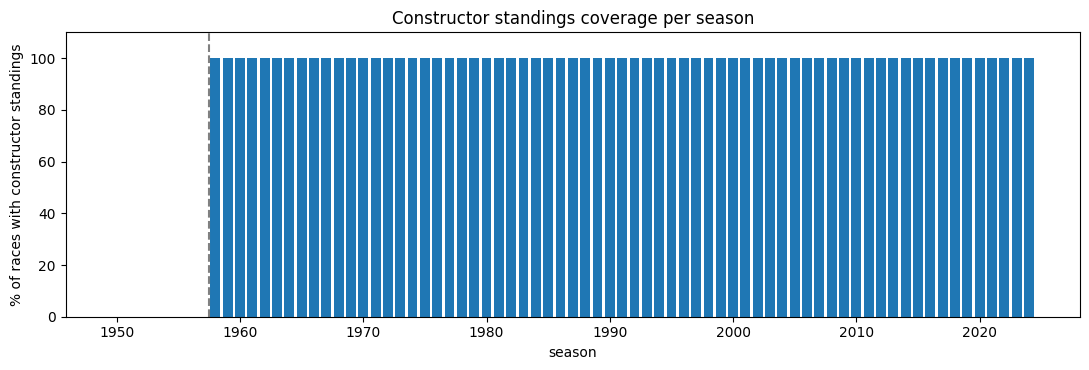

seasons with no standings: 1950 to 1957
seasons with partial coverage: []


In [134]:
cov = (races.assign(has_cs=races.raceId.isin(constructor_standings.raceId))
       .groupby('year').has_cs.mean() * 100)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(cov.index, cov.values, color=['tab:red' if y < 1958 else 'tab:blue' for y in cov.index])
ax.axvline(1957.5, linestyle='--', color='gray')
ax.set_ylim(0, 110)
ax.set_xlabel('season')
ax.set_ylabel('% of races with constructor standings')
ax.set_title('Constructor standings coverage per season')
plt.tight_layout()
plt.show()

print('seasons with no standings:', cov[cov == 0].index.min(), 'to', cov[cov == 0].index.max())
print('seasons with partial coverage:', cov[(cov > 0) & (cov < 100)].index.tolist())


In [135]:
down = cs[cs.added < 0].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_constructor'))
print(down[['year', 'round', 'name_constructor', 'points', 'added']])

# the rows around them, to see what happened
for _, r in down.iterrows():
    print(cs[(cs.constructorId == r.constructorId) & (cs.year == r.year)]
          [['round', 'points', 'position', 'wins']].to_string(index=False))


   year  round name_constructor  points  added
0  2018     13      Force India    18.0  -41.0
1  2020      5     Racing Point    41.0   -1.0
 round  points  position  wins
     1     0.0         6     0
     2     1.0         9     0
     3     1.0         9     0
     4    16.0         6     0
     5    18.0         7     0
     6    26.0         6     0
     7    28.0         6     0
     8    28.0         6     0
     9    42.0         7     0
    10    49.0         6     0
    11    59.0         5     0
    12    59.0         6     0
    13    18.0         9     0
    14    32.0         7     0
    15    32.0         7     0
    16    35.0         7     0
    17    43.0         7     0
    18    47.0         7     0
    19    47.0         7     0
    20    48.0         7     0
    21    52.0         7     0
 round  points  position  wins
     1     8.0         4     0
     2    22.0         4     0
     3    40.0         4     0
     4    42.0         5     0
     5    41.0        

### constructor_standings: structure, keys and coverage

**Grain.** The table has 13,391 rows and 7 columns. One row is a constructor's championship standing right after one race. `points` and `wins` are running totals for the season, and `position` is the championship rank at that moment, not a finishing place. It has the same structure as `driver_standings`, with `constructorId` in place of `driverId`.

**Types and missing values.** The IDs, `position` and `wins` are integers, `points` is a float and `positionText` is text. No column has missing values, so nothing needed converting.

**Primary key.** `constructorStandingsId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, constructorId)` also has 0 duplicates.

**Foreign keys.** Every `raceId` exists in `races` and every `constructorId` exists in `constructors`, so there are no orphans.

**Coverage.** Standings start in 1958. The 64 races without any constructor standings are exactly the seasons 1950 to 1957, and every race from 1958 on has standings. Features built from this table are therefore missing for those early seasons, which only matters if the training window starts before 1958.

**Running total.** Wins never go down inside a season, and points go down in only two rows (Force India 2018 and Racing Point 2020). The next section explains both.

**Leakage.** As in `driver_standings`, a row is the standing after the race. For a feature on a given race we use the row from the previous round of the same season, ordered by `(year, round)`, and never the same-race row.

**Next.** Investigate the two points drops, and check that constructor points match the sum of both cars' race points.


In [136]:
cr = raw_before['constructor_results'][['raceId', 'constructorId', 'points']].rename(columns={'points': 'race_points'})

# (b) is a row written AFTER its race? points added vs the team's points in constructor_results
m = cs.merge(cr, on=['raceId', 'constructorId'], how='left')
raced = m[m.race_points.notna()]
same = (raced.added - raced.race_points).abs() < 1e-6
print('rows of teams with a result in that race:', len(raced),
      '| points added = the team points of that race:', int(same.sum()), f'({same.mean() * 100:.1f}%)')
print('rows that disagree:', int((~same).sum()),
      '| before 1980:', int((raced[~same].year < 1980).sum()),
      '| other seasons:', sorted(raced[~same & (raced.year >= 1980)].year.unique().tolist()))

# the two points drops, next to what the team scored that race
drops = cs[cs.added < 0].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_team'))
display(drops.merge(cr, on=['raceId', 'constructorId'], how='left')
        [['year', 'round', 'name_team', 'points', 'added', 'race_points']])

# (d) the safe version: standing before the race = previous round's row
x = (cr.merge(races[['raceId', 'year', 'round']], on='raceId')
       .query('year >= 1958').sort_values(['year', 'constructorId', 'round']))
x['scored_before'] = x.groupby(['year', 'constructorId']).race_points.cumsum() - x.race_points
previous = (cs[['year', 'constructorId', 'round', 'points']]
            .assign(round=lambda t: t['round'] + 1).rename(columns={'points': 'points_before'}))
x = x.merge(previous, on=['year', 'constructorId', 'round'], how='left')
later = x[x['round'] > 1].fillna({'points_before': 0})
agree = (later.points_before - later.scored_before).abs() < 1e-6
print('team starts after round 1:', len(later),
      '| standing-before = points scored earlier:', round(agree.mean() * 100, 1), '%')
print('by decade (%):', (agree.groupby(later.year // 10 * 10).mean() * 100).round(1).to_dict())


rows of teams with a result in that race: 12497 | points added = the team points of that race: 12412 (99.3%)
rows that disagree: 85 | before 1980: 81 | other seasons: [2007, 2018, 2020]


,year,round,name_team,points,added,race_points
0,2018,13,Force India,18.0,-41.0,18.0
1,2020,5,Racing Point,41.0,-1.0,14.0


team starts after round 1: 11847 | standing-before = points scored earlier: 98.8 %
by decade (%): {1950: 94.2, 1960: 93.1, 1970: 96.5, 1980: 100.0, 1990: 100.0, 2000: 99.8, 2010: 99.6, 2020: 98.8}


In [137]:
bad = raced[~same & (raced.year >= 1980)].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_team'))
print(bad[['year', 'round', 'name_team', 'points', 'added', 'race_points']])

   year  round     name_team  points  added  race_points
0  2007     11       McLaren   138.0    0.0         15.0
1  2007     14       McLaren   192.0   26.0         11.0
2  2018     13   Force India    18.0  -41.0         18.0
3  2020      5  Racing Point    41.0   -1.0         14.0


### constructor_standings: the points drops and the check against constructor_results

**Running total.** Wins never go down inside a season. Points go down in two rows only. Force India in 2018 drops from 59 points after round 12 to 18 after round 13, and Racing Point in 2020 drops from 42 to 41 at round 5. After each drop the totals grow normally again, but from the lower number. In `constructor_results`, Force India scored 18 points in that race, which equals its new total, so the earlier points disappeared from the table, and Racing Point scored 14 points yet the total fell by 1, so about 15 points are missing. The table does not show the cause. These drops match two known events, which are general Formula 1 knowledge and not shown by the table, the change of ownership of Force India in 2018, after which the team's constructors' points were removed, and a points penalty given to Racing Point in 2020. We keep both rows, because they record what the championship table showed. Features read the previous-round points directly and do not use differences between rounds, so these rows cannot produce a negative value.

**Written after the race.** Of 12,497 standing rows with a result in that race, 12,412 (99.3%) add exactly the points the team scored, so a row is the standing after the race. The 85 that disagree are mostly before 1980 (81), where best-results rules and shared drives apply and which we do not investigate further, and the rest are in 2007, 2018 and 2020. The 2007 rows are McLaren in rounds 11 and 14. In round 11 the team scored 15 points in the race but the standing added 0, and in round 14 it scored 11 but the standing added 26, which is 15 plus 11. The points of round 11 therefore appear in the table three rounds late. The table does not show why, and we keep the rows as they are. The previous-round standing equals the points scored in earlier races in 98.8% of cases, and 100% in the 1980s and 1990s, so it is a safe pre-race value.

**What we check next.** We compare every team that started a race from 1958 on with the rows in the standings, in both directions. This is the team version of the 8,664 rows we looked at for drivers. First, standings rows for a team that did not start that race. Second, team starts with no standings row, and whether any of those teams scored points, because a missing row for a team that scored would leave a gap in the previous-round feature.

**Sprint points.** For 2021 to 2024 we also test whether the constructor standings include sprint points, by comparing the points added in each row with `constructor_results` alone, and with `constructor_results` plus the sprint points of the same weekend. For drivers the sum of Sunday and sprint matched 100% of rows, and we check whether the team table behaves the same way.



In [138]:
# team starts (1958 on) vs standings rows
team_starts = (results_unique.merge(races[['raceId', 'year']], on='raceId')
               .query('year >= 1958')[['raceId', 'constructorId']].drop_duplicates())
cmp = cs[['raceId', 'constructorId']].merge(team_starts.assign(started=1),
                                            on=['raceId', 'constructorId'], how='outer', indicator=True)
cmp = cmp[cmp.raceId.isin(races[races.year >= 1958].raceId)]
print('standings rows for a team that did not start:', int((cmp._merge == 'left_only').sum()),
      '| team starts with no standings row:', int((cmp._merge == 'right_only').sum()))

# which of those missing rows scored points?
tp = (results_unique.groupby(['raceId', 'constructorId']).points.sum().reset_index()
      .merge(races[['raceId', 'year', 'name']], on='raceId').query('year >= 1958')
      .merge(cs[['raceId', 'constructorId']].assign(has_row=1), on=['raceId', 'constructorId'], how='left'))
no_row = tp[tp.has_row.isna()]
scoring = no_row[no_row.points > 0].merge(constructors[['constructorId', 'name']], on='constructorId', suffixes=('', '_team'))
print('team starts with no standings row:', len(no_row), '| that scored points:', len(scoring))
print(scoring[['year', 'name', 'name_team', 'points']].head(10))

# sprint points, 2021-2024
sprint_team = (raw_before['sprint_results'].groupby(['raceId', 'constructorId']).points.sum()
               .rename('sprint_points').reset_index())
recent = (cs.merge(cr, on=['raceId', 'constructorId'], how='left')
            .query('year >= 2021').merge(sprint_team, on=['raceId', 'constructorId'], how='left')
            .fillna({'sprint_points': 0, 'race_points': 0}))
print('2021-2024: added = constructor_results:', round(((recent.added - recent.race_points).abs() < 1e-6).mean() * 100, 1),
      '% | = constructor_results + sprint:', round(((recent.added - recent.race_points - recent.sprint_points).abs() < 1e-6).mean() * 100, 1), '%')


standings rows for a team that did not start: 893 | team starts with no standings row: 129
team starts with no standings row: 129 | that scored points: 10
   year              name     name_team  points
0  1960  Indianapolis 500        Watson    14.0
1  1960  Indianapolis 500       Epperly     4.0
2  1960  Indianapolis 500      Phillips     3.0
3  1960  Indianapolis 500      Lesovsky     2.0
4  1960  Indianapolis 500        Trevis     1.0
5  1959  Indianapolis 500        Watson    14.0
6  1959  Indianapolis 500       Epperly     5.0
7  1959  Indianapolis 500      Lesovsky     5.0
8  1958  Indianapolis 500       Epperly    20.0
9  1958  Indianapolis 500  Kurtis Kraft     4.0
2021-2024: added = constructor_results: 100.0 % | = constructor_results + sprint: 90.9 %


### constructor_standings: who has a standings row, and sprint points

**Result.** 893 standings rows belong to a team that did not start that race, so the table keeps teams that skipped a round, as it does for drivers. 129 team starts from 1958 on have no standings row, and only 10 of them scored points. All 10 are Indianapolis 500 races from 1958 to 1960, by teams that raced nowhere else, so their points never reached the constructor standings. The Indianapolis 500 rows are excluded from the modelling table, so these gaps do not matter, and the other 119 missing rows scored no points. For 2021 to 2024, the points added match `constructor_results` in 100% of rows, and adding sprint points on top lowers the match to 90.9%. The reason is that `constructor_results` already includes the sprint points, which we confirmed in the next section, where the 82 team-races with sprint points differ from the drivers' summed race points and agree once the sprint is added. The constructor standings therefore include sprint points, in the same way as the driver standings.

## `Constructor Results Table`

In [139]:
constructor_results = load('constructor_results')

print('shape:', constructor_results.shape)
display(constructor_results.head())
print(constructor_results.dtypes)
print('\nmissing per column:')
print(constructor_results.isna().sum())

shape: (12625, 5)


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


constructorResultsId      int64
raceId                    int64
constructorId             int64
points                  float64
status                   object
dtype: object

missing per column:
constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64


In [140]:
cr_raw = constructor_results.copy()

# keys
print('constructorResultsId nulls:      ', cr_raw.constructorResultsId.isna().sum())
print('constructorResultsId duplicates: ', cr_raw.constructorResultsId.duplicated().sum())
print('(raceId, constructorId) duplicates:', cr_raw.duplicated(['raceId', 'constructorId']).sum())

# links
print('raceIds not in races:              ', (~cr_raw.raceId.isin(races.raceId)).sum())
print('constructorIds not in constructors:', (~cr_raw.constructorId.isin(constructors.constructorId)).sum())

# coverage by year
crr = cr_raw.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
no_rows = races[~races.raceId.isin(cr_raw.raceId)]
print('seasons with rows:', crr.year.min(), 'to', crr.year.max(),
      '| races with rows:', cr_raw.raceId.nunique(), 'of', len(races))
print('races with no rows: before 1958 =', int((no_rows.year < 1958).sum()),
      '| from 1958 on =', no_rows[no_rows.year >= 1958][['year', 'name']].values.tolist())

# the status column
print('\nstatus values:', cr_raw.status.value_counts(dropna=False).to_dict())
flagged = crr[crr.status.notna()].merge(constructors[['constructorId', 'name']],
                                         on='constructorId', suffixes=('', '_team'))
print(flagged[['year', 'round', 'name_team', 'points', 'status']])


constructorResultsId nulls:       0
constructorResultsId duplicates:  0
(raceId, constructorId) duplicates: 0
raceIds not in races:               0
constructorIds not in constructors: 0
seasons with rows: 1958 to 2024 | races with rows: 1060 of 1125
races with no rows: before 1958 = 64 | from 1958 on = [[1958, 'Indianapolis 500']]

status values: {nan: 12608, 'D': 17}
    year  round name_team  points status
0   2007      1   McLaren    14.0      D
1   2007      2   McLaren    18.0      D
2   2007      3   McLaren    12.0      D
3   2007      4   McLaren    14.0      D
4   2007      5   McLaren    18.0      D
5   2007      6   McLaren    12.0      D
6   2007      7   McLaren    18.0      D
7   2007      8   McLaren     8.0      D
8   2007      9   McLaren    14.0      D
9   2007     10   McLaren    10.0      D
10  2007     11   McLaren    15.0      D
11  2007     12   McLaren    10.0      D
12  2007     13   McLaren    18.0      D
13  2007     14   McLaren    11.0      D
14  2007     1

In [141]:
mc_id = flagged.constructorId.iloc[0]

res_mc = (results_unique[results_unique.constructorId == mc_id]
          .merge(races[['raceId', 'year']], on='raceId').query('year == 2007'))
print('McLaren 2007 result rows:', len(res_mc))
print(res_mc.positionText.value_counts().to_dict())

cs_mc = cs[(cs.constructorId == mc_id) & (cs.year == 2007)]
print('constructor_standings positionText in 2007:', cs_mc.positionText.value_counts().to_dict())
print('constructor_standings positionText "E" rows overall:', int((cs.positionText == 'E').sum()))

McLaren 2007 result rows: 34
{'2': 9, '1': 8, '3': 7, '7': 3, '5': 2, '4': 2, 'R': 2, '9': 1}
constructor_standings positionText in 2007: {'E': 17}
constructor_standings positionText "E" rows overall: 17


### constructor_results: structure, keys, coverage and the status column

**Grain.** The table has 12,625 rows and 5 columns. One row is one team's score in one race, so `points` is what the team scored in that race and not a running total.

**Types and missing values.** The IDs are integers, `points` is a float and `status` is text. Only `status` has missing values, 12,608 of 12,625 rows, so the column is blank except for 17 rows.

**Primary key.** `constructorResultsId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, constructorId)` also has 0 duplicates.

**Foreign keys.** Every `raceId` exists in `races` and every `constructorId` exists in `constructors`, so there are no orphans.

**Coverage.** Rows exist from 1958 to 2024 for 1,060 of the 1,125 races. The 65 races without rows are the 64 races of 1950 to 1957 and the 1958 Indianapolis 500.

**The status column.** The only value is `D`, in 17 rows, and all 17 belong to McLaren in 2007, one for each of its 17 races. The table does not say what `D` means. It is general Formula 1 knowledge, not shown by the table, that McLaren was removed from the 2007 constructors' championship, which fits a flag on every race of that team and season. In `results`, McLaren's 2007 rows are normal (8 wins, 9 second places, 7 third places), so the flag does not affect the drivers' race results. In `constructor_standings` the same 17 team-races carry `positionText` `E`, a value that appears nowhere else in that table, so `D` and `E` appear to mark the same team-season. McLaren's points still appear in both tables, so the flag, and not the points, marks the exclusion.

**Decision.** We keep the rows and do not use `status` as a feature, because it is blank apart from one team and one season. The drivers' race results of McLaren in 2007 stay in the modelling table. How team-form features treat that team-season is decided at the feature step.

team-races compared: 12617 | team score = drivers sum: 12233 (96.96%) | = drivers sum + sprint: 12315 (97.61%)
from 1979 on, not equal (with sprint): 0 of 9911
2021-2024: differences from drivers sum: 82 | team-races with sprint points: 82 | equal once sprint is added: 82
differences left: 302 | seasons 1958 to 1978 | team scored less than its drivers: 302
reasons: {'only the best car counted': 292, 'best car minus 1 point': 9, 'something else': 1}


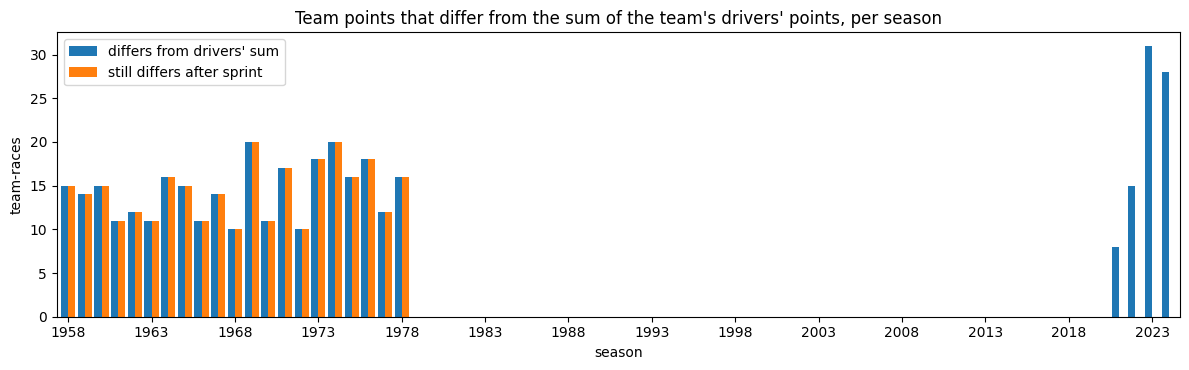

In [142]:
# drivers' side: points per team per race from the deduplicated results
drivers_side = (results_unique.groupby(['raceId', 'constructorId'])
                .agg(drivers_sum=('points', 'sum'), best_car=('points', 'max'), cars=('points', 'size'))
                .reset_index())

# sprint points per team per race
sprint_team = (raw_before['sprint_results'].groupby(['raceId', 'constructorId']).points.sum()
               .rename('sprint_points').reset_index())

j = (crr.merge(drivers_side, on=['raceId', 'constructorId'])
        .merge(sprint_team, on=['raceId', 'constructorId'], how='left')
        .fillna({'sprint_points': 0}))
j['same_as_drivers'] = (j.points - j.drivers_sum).abs() < 1e-6
j['same_with_sprint'] = (j.points - j.drivers_sum - j.sprint_points).abs() < 1e-6

print('team-races compared:', len(j),
      '| team score = drivers sum:', int(j.same_as_drivers.sum()), f'({j.same_as_drivers.mean() * 100:.2f}%)',
      '| = drivers sum + sprint:', int(j.same_with_sprint.sum()), f'({j.same_with_sprint.mean() * 100:.2f}%)')

late = j[j.year >= 1979]
print('from 1979 on, not equal (with sprint):', int((~late.same_with_sprint).sum()), 'of', len(late))

rec = j[j.year >= 2021]
print('2021-2024: differences from drivers sum:', int((~rec.same_as_drivers).sum()),
      '| team-races with sprint points:', int((rec.sprint_points > 0).sum()),
      '| equal once sprint is added:', int(rec[rec.sprint_points > 0].same_with_sprint.sum()))

# the differences that are left, and a first guess at why (old seasons)
old = j[~j.same_with_sprint]
reason = np.select([(old.points - old.best_car).abs() < 1e-6,
                    (old.points - (old.best_car - 1)).abs() < 1e-6],
                   ['only the best car counted', 'best car minus 1 point'], 'something else')
print('differences left:', len(old), '| seasons', int(old.year.min()), 'to', int(old.year.max()),
      '| team scored less than its drivers:', int((old.points < old.drivers_sum).sum()))
print('reasons:', pd.Series(reason).value_counts().to_dict())

# per-season picture
by_season = pd.DataFrame({
    "differs from drivers' sum": j[~j.same_as_drivers].groupby('year').size(),
    'still differs after sprint': j[~j.same_with_sprint].groupby('year').size()
}).reindex(range(1958, 2025), fill_value=0).fillna(0)
ax = by_season.plot.bar(figsize=(12, 3.8), width=0.85,
                        title="Team points that differ from the sum of the team's drivers' points, per season")
ax.set_xticks(range(0, len(by_season), 5))
ax.set_xticklabels(by_season.index[::5], rotation=0)
plt.xlabel('season')
plt.ylabel('team-races')
plt.tight_layout()
plt.show()


**Team score against the drivers' points.** For 12,617 team-races, the team's points in `constructor_results` equal the sum of its drivers' points in `results` in 96.96% of cases, and 97.61% once sprint points are added. From 1979 on, all 9,911 team-races agree. In 2021 to 2024, 82 team-races differ from the drivers' sum, which are exactly the 82 with sprint points, and all 82 agree once the sprint is added, so `constructor_results` already includes sprint points. The 302 remaining differences are all between 1958 and 1978, and in every one the team scored less than its drivers. In 292 of them the team score equals its best car's points, in 9 it equals the best car minus one point, and 1 is unexplained. This fits seasons in which only the best car counted for the team, which is general Formula 1 knowledge and not shown by the table.

## `Sprint Results Table`

In [143]:
sprint_results = load('sprint_results')

print('shape:', sprint_results.shape)
display(sprint_results.head())
print(sprint_results.dtypes)
print('\nmissing per column:')
print(sprint_results.isna().sum())

shape: (360, 16)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


resultId            int64
raceId              int64
driverId            int64
constructorId       int64
number              int64
grid                int64
position          float64
positionText       object
positionOrder       int64
points              int64
laps                int64
time               object
milliseconds      float64
fastestLap        float64
fastestLapTime     object
statusId            int64
dtype: object

missing per column:
resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position          15
positionText       0
positionOrder      0
points             0
laps               0
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
statusId           0
dtype: int64


In [144]:
sp = sprint_results

print('resultId nulls:', sp.resultId.isna().sum(), '| duplicates:', sp.resultId.duplicated().sum())
print('(raceId, driverId) duplicates:', sp.duplicated(['raceId', 'driverId']).sum())

print('raceIds not in races:              ', (~sp.raceId.isin(races.raceId)).sum())
print('driverIds not in drivers:          ', (~sp.driverId.isin(drivers.driverId)).sum())
print('constructorIds not in constructors:', (~sp.constructorId.isin(constructors.constructorId)).sum())
print('statusIds not in status:           ', (~sp.statusId.isin(status.statusId)).sum())

resultId nulls: 0 | duplicates: 0
(raceId, driverId) duplicates: 0
raceIds not in races:               0
driverIds not in drivers:           0
constructorIds not in constructors: 0
statusIds not in status:            0


In [145]:
spr = sp.merge(races[['raceId', 'year', 'round', 'name']], on='raceId')
per_sprint = sp.groupby('raceId').size()
print('rows:', len(sp), '| sprints:', len(per_sprint), '| rows per sprint:', per_sprint.value_counts().to_dict())
print('same sprints as races.sprint_date:', set(sp.raceId) == set(races[races.sprint_date.notna()].raceId))

cov = pd.DataFrame({'races': races[races.year >= 2021].groupby('year').size(),
                    'with a sprint': spr.groupby('year').raceId.nunique()}).fillna(0).astype(int)
cov['share %'] = (cov['with a sprint'] / cov['races'] * 100).round(0)
display(cov)

rows: 360 | sprints: 18 | rows per sprint: {20: 18}
same sprints as races.sprint_date: True


,races,with a sprint,share %
year,,,
2021,22,3,14.0
2022,22,3,14.0
2023,22,6,27.0
2024,24,6,25.0


In [146]:
order = sp.groupby('raceId').positionOrder.agg(['min', 'max', 'nunique', 'size'])
print('finishing order is exactly 1..n:',
      bool(((order['min'] == 1) & (order['max'] == order['size']) & (order['nunique'] == order['size'])).all()))

finishing order is exactly 1..n: True


In [147]:
outcome = sp.statusId.map(status.set_index('statusId').status)
empty = pd.DataFrame({c: [int(sp[c].isna().sum()), int((sp[c].isna() & (outcome == 'Finished')).sum())]
                      for c in ['position', 'time', 'milliseconds', 'fastestLap', 'fastestLapTime']},
                     index=['empty cells', 'of them for a driver who Finished']).T
display(empty)
print('time empty together with milliseconds:', bool((sp.time.isna() == sp.milliseconds.isna()).all()))
print('fastestLap empty together with fastestLapTime:', bool((sp.fastestLap.isna() == sp.fastestLapTime.isna()).all()))

,empty cells,of them for a driver who Finished
position,15,0
time,20,0
milliseconds,20,0
fastestLap,9,0
fastestLapTime,9,0


time empty together with milliseconds: True
fastestLap empty together with fastestLapTime: True


In [148]:
sd = races[races.sprint_date.notna()].assign(days_before=lambda t: (t.date - t.sprint_date).dt.days)
print('days between sprint and Sunday race:', sd.days_before.value_counts().to_dict())

days between sprint and Sunday race: {1: 18}


In [149]:
print('fastestLapTime patterns:')
print(sp.fastestLapTime.dropna().str.replace(r'\d', '9', regex=True).value_counts().to_dict())

print('\ntime patterns:')
print(sp.time.dropna().str.replace(r'\d', '9', regex=True).value_counts().to_dict())


fastestLapTime patterns:
{'9:99.999': 351}

time patterns:
{'+99.999': 259, '+9.999': 38, '+9:99.999': 25, '99:99.999': 18}


In [150]:
sp = sprint_results.copy()

parts = sp.fastestLapTime.str.split(':', expand=True)
sp['fastestLapTime_s'] = parts[0].astype(float) * 60 + parts[1].astype(float)

print('filled before / after:', sp.fastestLapTime.notna().sum(), '/', sp.fastestLapTime_s.notna().sum())
print('range (s):', sp.fastestLapTime_s.min(), 'to', sp.fastestLapTime_s.max())
display(sp[['fastestLapTime', 'fastestLapTime_s']].dropna().head())

filled before / after: 351 / 351
range (s): 68.321 to 124.76


,fastestLapTime,fastestLapTime_s
0,1:30.013,90.013
1,1:29.937,89.937
2,1:29.958,89.958
3,1:30.163,90.163
4,1:30.566,90.566


### sprint_results: structure, keys, coverage and missing values

**Grain.** The table has 360 rows and 16 columns, with the same columns as `results`. One row is one driver's result in one sprint. It covers 18 sprints with exactly 20 rows each, 3 in 2021, 3 in 2022, 6 in 2023 and 6 in 2024, which is 14% to 27% of each season's races. They are exactly the 18 races that have a `sprint_date` in `races`.

**Types.** `points` is an integer here, because sprint points are whole numbers. `position`, `milliseconds` and `fastestLap` are floats only because they have missing values. The `fastestLapTime` column is stored as text in a single `m:ss.mmm` pattern, so we converted it to seconds in a new column called `fastestLapTime_s`. All 351 filled values converted with none lost, and the values range from 68.3 to 124.8 seconds, which is realistic for a sprint lap. The original text column was kept. The `time` column is also text, and it mixes the winner's full time with gaps to the winner, so we leave it unchanged and use `milliseconds` as the numeric version of the race time instead.

**Primary key.** `resultId` has 0 nulls and 0 duplicates, so it is a valid primary key. The natural key `(raceId, driverId)` also has 0 duplicates.

**Foreign keys.** Every `raceId`, `driverId`, `constructorId` and `statusId` exists in its parent table, so there are no orphans.

**Finishing order.** `positionOrder` runs exactly from 1 to 20 in every sprint, with no repeats and no gaps.

**Timing.** All 18 sprints took place exactly 1 day before their Sunday race, so a sprint result is always known before the race starts.

**Missing values.** `position` is empty in 15 rows, `time` and `milliseconds` in 20 rows, and `fastestLap` and `fastestLapTime` in 9 rows. Each pair is empty in the same rows, and none of the empty cells belongs to a driver who finished, so they mean the driver did not finish or set no lap time and not that data was lost. `positionOrder` is always filled, as in `results`.

**Decision.** A sprint feature would be empty for about 98% of all races, and it would be constant in any training window that ends before 2021, since sprints only exist from 2021 onward. In 2021 and 2022 the sprint result also set the Sunday starting grid, so it is largely redundant with the grid position we already use. We therefore propose not to use it in the main model, and at most to test a has_sprint flag as an optional experiment.

## `Lap Times Table`

In [151]:
lap_times = load('lap_times')
lt = lap_times.copy()
print(lt.shape)
print(lt.dtypes)
display(lt.head())
print(lt.isna().sum())

(589081, 6)
raceId           int64
driverId         int64
lap              int64
position         int64
time            object
milliseconds     int64
dtype: object


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64


In [152]:
print('duplicate (raceId, driverId, lap):', lt.duplicated(['raceId', 'driverId', 'lap']).sum())
print('races covered:', lt.raceId.nunique())
print('drivers:', lt.driverId.nunique())
print('lap range:', lt.lap.min(), 'to', lt.lap.max())
print('position range:', lt.position.min(), 'to', lt.position.max())

duplicate (raceId, driverId, lap): 0
races covered: 544
drivers: 143
lap range: 1 to 87
position range: 1 to 24


first season: 1996
last season: 2024
races with lap data: 544 of 1125
races from 1996 on: 544
of them with lap data: 544
races before 1996 with lap data: 0


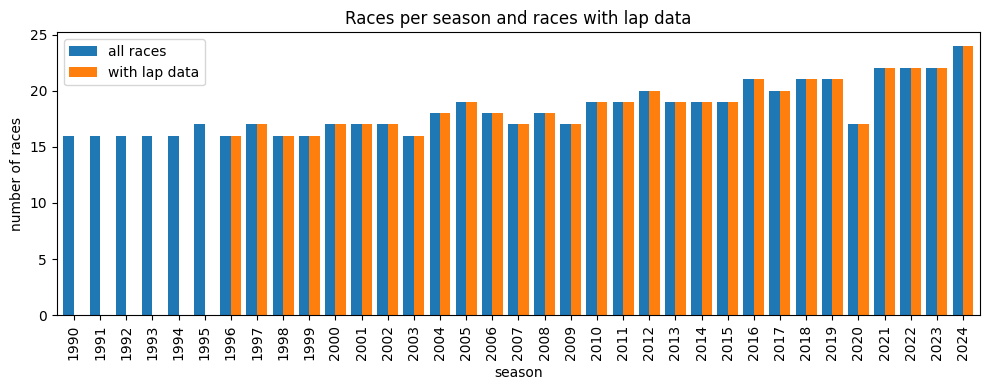

In [153]:
laps = lap_times.merge(races[['raceId', 'year']], on='raceId')
print('first season:', laps.year.min())
print('last season:', laps.year.max())
print('races with lap data:', laps.raceId.nunique(), 'of', len(races))

since_1996 = races[races.year >= 1996]
print('races from 1996 on:', len(since_1996))
print('of them with lap data:', since_1996.raceId.isin(laps.raceId).sum())
print('races before 1996 with lap data:', laps[laps.year < 1996].raceId.nunique())

per_year = races.groupby('year').size().rename('all races').to_frame()
per_year['with lap data'] = laps.groupby('year').raceId.nunique()
per_year = per_year.fillna(0)

per_year.loc[1990:].plot.bar(figsize=(10, 4), width=0.8,
    title='Races per season and races with lap data')
plt.xlabel('season')
plt.ylabel('number of races')
plt.tight_layout()
plt.show()


In [154]:
per_driver = laps.groupby(['raceId', 'driverId']).lap.agg(['min', 'max', 'nunique', 'size'])
no_gap = (per_driver['min'] == 1) & (per_driver['max'] == per_driver['nunique']) & (per_driver['nunique'] == per_driver['size'])
print('driver-races:', len(per_driver), '| laps run 1..n with no gap:', int(no_gap.sum()))

per_lap = laps.groupby(['raceId', 'lap']).position.agg(['nunique', 'size', 'max'])
print('race-laps:', len(per_lap))
print('all positions different within a lap:', int((per_lap['nunique'] == per_lap['size']).sum()))
print('positions run exactly 1..n:', int((per_lap['max'] == per_lap['size']).sum()))

driver-races: 11041 | laps run 1..n with no gap: 11041
race-laps: 33196
all positions different within a lap: 33196
positions run exactly 1..n: 33196


In [155]:
normal = laps.time.str.match(r'^\d+:\d{2}\.\d{3}$')
with_hours = laps.time.str.match(r'^\d+:\d{2}:\d{2}\.\d{3}$')
print('time looks like m:ss.mmm:', int(normal.sum()))
print('time looks like h:mm:ss.mmm:', int(with_hours.sum()))
print('any other format:', int((~normal & ~with_hours).sum()))

def lap_text_to_ms(s):
    parts = s.split(':')
    seconds, minutes = float(parts[-1]), float(parts[-2])
    hours = float(parts[-3]) if len(parts) > 2 else 0.0
    return round(((hours * 60 + minutes) * 60 + seconds) * 1000)

print('time text agrees with milliseconds:', int((laps.time.map(lap_text_to_ms) == laps.milliseconds).sum()), 'of', len(laps))

time looks like m:ss.mmm: 589038
time looks like h:mm:ss.mmm: 43
any other format: 0
time text agrees with milliseconds: 589081 of 589081


In [156]:
long_laps = laps[laps.time.str.match(r'^\d+:\d{2}:\d{2}\.\d{3}$')].merge(races[['raceId', 'name']], on='raceId')
display(long_laps.groupby(['year', 'name']).agg(rows=('lap', 'size'), first_lap=('lap', 'min'), last_lap=('lap', 'max'), shortest=('time', 'min'), longest=('time', 'max')))

,,rows,first_lap,last_lap,shortest,longest
year,name,,,,,
2011,Canadian Grand Prix,23,25,25,2:04:29.869,2:05:07.547
2014,British Grand Prix,20,1,2,1:01:07.384,1:03:23.459


In [157]:
with_names = laps.merge(races[['raceId', 'name']], on='raceId')
print('median lap (ms):', int(laps.milliseconds.median()))
print('fastest lap (ms):', laps.milliseconds.min())
print('slowest lap (ms):', laps.milliseconds.max(), '=', round(laps.milliseconds.max() / 60000, 1), 'minutes')
display(pd.concat([with_names.nsmallest(1, 'milliseconds'), with_names.nlargest(1, 'milliseconds')])[['year', 'name', 'lap', 'milliseconds']])


median lap (ms): 90608
fastest lap (ms): 55404
slowest lap (ms): 7507547 = 125.1 minutes


,year,name,lap,milliseconds
488409,2020,Sakhir Grand Prix,80,55404
8372,2011,Canadian Grand Prix,25,7507547


### lap_times: structure, keys, coverage and trust in the time column

**Grain.** The table has 589,081 rows and 6 columns. One row is one completed lap of one driver in one race, and `position` is the driver's running position at the end of that lap, not the final result.

**Types and missing values.** No column has missing values. `raceId`, `driverId`, `lap`, `position` and `milliseconds` are integers. The `time` column is text, and it is the same lap time as `milliseconds` written in another form. All 589,081 `time` values follow one of two patterns, `m:ss.mmm` in 589,038 rows and `h:mm:ss.mmm` in 43 rows, with none in any other format. Converting the text to milliseconds gives exactly the `milliseconds` column in all 589,081 rows. We therefore use `milliseconds` as the numeric lap time and leave `time` unchanged.

**Primary key.** The table has no ID column, and `(raceId, driverId, lap)` has 0 duplicates, so it is a valid natural key.

**Coverage.** Lap data covers 544 races from 1996 to 2024 and 143 drivers. All 544 races from 1996 on have lap data, and no race before 1996 has any, so the coverage is a clean cut at 1996. This is 544 of 1,125 races, which is about 48% of all races.

**Completeness.** In all 11,041 driver-races the laps run exactly 1 to n with no gap. In all 33,196 race-laps no two drivers share a position, and the positions run exactly from 1 to the number of cars. So every lap gives a proper running order. Positions go up to 24 and lap numbers up to 87.

**Long laps.** The 43 laps in `h:mm:ss.mmm` form come from two races, 23 from lap 25 of the 2011 Canadian Grand Prix (about 2 hours) and 20 from laps 1 and 2 of the 2014 British Grand Prix (about 1 hour). They are consistent with red-flag stoppages included in the lap time. They are real values and not errors, but they are extreme, since the slowest lap is 125.1 minutes while the median lap is 90.6 seconds.


In [158]:
race_median = laps.groupby('raceId').milliseconds.median() / 1000
low, middle, high = race_median.quantile([0.01, 0.5, 0.99])
print('typical lap of a race (seconds):')
print('fastest race:', round(race_median.min(), 1))
print('1% of races below:', round(low, 1))
print('median:', round(middle, 1))
print('99% of races below:', round(high, 1))
print('slowest race:', round(race_median.max(), 1))
slowest = race_median.idxmax()
print('slowest race is', races.loc[races.raceId == slowest, ['year', 'name']].values.tolist()[0],
      '| laps in lap_times:', laps[laps.raceId == slowest].lap.max())


typical lap of a race (seconds):
fastest race: 58.7
1% of races below: 70.3
median: 91.1
99% of races below: 122.2
slowest race: 225.4
slowest race is [2021, 'Belgian Grand Prix'] | laps in lap_times: 1


In [159]:
laps['relative'] = laps.milliseconds / laps.groupby('raceId').milliseconds.transform('median')
print('relative lap: median', round(laps.relative.median(), 3))
print('smallest', round(laps.relative.min(), 3), '| largest', round(laps.relative.max(), 1))
print('lap 1 (standing start) median:', round(laps[laps.lap == 1].relative.median(), 3))

slow = pd.DataFrame({'laps': {f'slower than {k} x typical': int((laps.relative > k).sum()) for k in [1.2, 1.5, 2, 3]}})
slow['% of all laps'] = (slow['laps'] / len(laps) * 100).round(2)
display(slow)

relative lap: median 1.0
smallest 0.745 | largest 72.7
lap 1 (standing start) median: 1.131


,laps,% of all laps
slower than 1.2 x typical,38875,6.60
slower than 1.5 x typical,11709,1.99
slower than 2 x typical,1092,0.19
slower than 3 x typical,723,0.12


### lap_times: extreme laps and why circuits cannot be compared

**Typical and extreme laps.** The median lap is 90,608 ms, which is about 90.6 seconds. The fastest lap is 55,404 ms, from lap 80 of the 2020 Sakhir Grand Prix, which is consistent with the short outer layout used for that race. The slowest lap is 7,507,547 ms, which is 125.1 minutes, from lap 25 of the 2011 Canadian Grand Prix, where the red-flag stoppage is included in the lap time. The slowest lap is more than 80 times the median, so a single stoppage lap would distort any plain average of lap times.

**Circuits cannot be compared on raw lap times.** Every circuit has its own length, so a lap of the same duration means something different in each race. The typical (median) lap of a race is 58.7 seconds in the fastest race and 91.1 seconds in the median race. 1% of races are below 70.3 seconds and 99% of races are below 122.2 seconds. The slowest race has a typical lap of 225.4 seconds, far outside the rest. It is the 2021 Belgian Grand Prix, which has only 1 lap in the table: the race was run behind the safety car in heavy rain (F1 history), so its one lap is very slow. The same race has no pit stops (pit_stops section). A model fed raw lap times would mostly learn which circuit it was looking at and not how fast the driver was.

**Relative lap time.** To put all races on one scale, we divide each lap by the median lap of its own race, so 1.0 is a typical lap of that race. The median relative lap is 1.0 by construction. The smallest value is 0.745 and the largest is 72.7, which is the 2011 Canadian Grand Prix stoppage lap. Lap 1 has a median of 1.131, so a first lap is about 13% slower than a typical lap, which fits the standing start.

**How common are slow laps.** Most laps are close to typical, and extreme laps are rare.

| Slower than | Laps | Share of all laps |
|---|---|---|
| 1.2 x typical | 38,875 | 6.60% |
| 1.5 x typical | 11,709 | 1.99% |
| 2 x typical | 1,092 | 0.19% |
| 3 x typical | 723 | 0.12% |

About 93% of laps are within 20% of the typical lap of their race. The reasons for the slow laps (pit stops, lap 1, safety cars, red flags) have not been checked yet, because that needs the pit_stops table.

**Decision.** Raw lap times are not used. Any pace feature built from laps uses the relative lap time, and because a few stoppage laps are extreme, it takes a median or caps the values instead of using a plain average.

In [160]:
one_row = results_unique.drop_duplicates(['raceId', 'driverId'])
count = (laps.groupby(['raceId', 'driverId']).size().rename('lap_rows').reset_index()
         .merge(one_row[['raceId', 'driverId', 'laps']], on=['raceId', 'driverId']))
count['difference'] = count.lap_rows - count.laps
different = count[count.difference != 0]
print('driver-races:', len(count))
print('lap rows = laps in results:', int((count.difference == 0).sum()))
print('different:', len(different), 'in', different.raceId.nunique(), 'of', count.raceId.nunique(), 'races')
print('differ by 1 or 2 laps:', int((different.difference.abs() <= 2).sum()))
print('differ by 10 laps or more:', int((different.difference.abs() >= 10).sum()))

driver-races: 11041
lap rows = laps in results: 10951
different: 90 in 35 of 544 races
differ by 1 or 2 laps: 71
differ by 10 laps or more: 10


In [161]:
# driver-races where lap_times and results differ by 10 laps or more
big = different[different.difference.abs() >= 10].merge(races[['raceId', 'year', 'name']], on='raceId')

cols = ['raceId', 'driverId', 'grid', 'positionOrder', 'laps', 'statusId']
check = big.merge(one_row[cols], on=['raceId', 'driverId', 'laps'])
display(check[['year', 'name', 'driverId', 'lap_rows', 'laps', 'grid', 'positionOrder', 'statusId']].sort_values(['year', 'name']))

,year,name,driverId,lap_rows,laps,grid,positionOrder,statusId
4,2001,Hungarian Grand Prix,15,75,53,5,17,9
5,2001,Hungarian Grand Prix,55,53,75,12,10,12
6,2001,Italian Grand Prix,15,52,0,5,22,4
7,2001,Japanese Grand Prix,15,5,52,8,8,11
8,2001,Japanese Grand Prix,55,52,5,11,22,4
3,2006,French Grand Prix,22,18,28,13,20,5
2,2008,British Grand Prix,21,26,16,19,17,20
0,2009,Italian Grand Prix,17,52,0,10,20,4
1,2009,Italian Grand Prix,67,19,52,19,13,11
9,2024,São Paulo Grand Prix,807,30,0,17,20,2


In [162]:
d = (different
     .merge(one_row[['raceId', 'driverId', 'grid', 'positionOrder', 'statusId']], on=['raceId', 'driverId'])
     .merge(races[['raceId', 'year', 'name']], on='raceId')
     .merge(status[['statusId', 'status']], on='statusId')
     .merge(drivers[['driverId', 'surname']], on='driverId'))

print('rows:', len(d))
print('lap_times has MORE laps than results:', int((d.difference > 0).sum()))
print('lap_times has FEWER laps than results:', int((d.difference < 0).sum()))
print('grid == 0:', int((d.grid == 0).sum()))
print(d.status.value_counts().head(8))

with pd.option_context('display.max_rows', 100):
    display(d[['year', 'name', 'surname', 'lap_rows', 'laps', 'difference', 'grid', 'positionOrder', 'status']]
            .sort_values(['year', 'name']))

rows: 90
lap_times has MORE laps than results: 37
lap_times has FEWER laps than results: 53
grid == 0: 0
status
+1 Lap        20
Accident      11
Finished      11
Collision      8
+2 Laps        5
Spun off       4
Engine         4
Hydraulics     4
Name: count, dtype: int64


,year,name,surname,lap_rows,laps,difference,grid,positionOrder,status
39,1998,Monaco Grand Prix,Frentzen,9,5,4,5,20,Collision
31,2001,Belgian Grand Prix,Trulli,36,31,5,16,14,Engine
32,2001,Belgian Grand Prix,Alesi,31,36,-5,13,6,Finished
33,2001,Belgian Grand Prix,Marques,32,31,1,22,13,+5 Laps
29,2001,Hungarian Grand Prix,Trulli,75,53,22,5,17,Hydraulics
30,2001,Hungarian Grand Prix,Alesi,53,75,-22,12,10,+2 Laps
34,2001,Italian Grand Prix,Trulli,52,0,52,5,22,Collision
37,2001,Japanese Grand Prix,Trulli,5,52,-47,8,8,+1 Lap
38,2001,Japanese Grand Prix,Alesi,52,5,47,11,22,Collision
35,2001,United States Grand Prix,Trulli,72,73,-1,8,4,Finished


In [163]:
print(d.groupby('status').difference.agg(['size', 'min', 'median', 'max']).sort_values('size', ascending=False).head(10))

            size  min  median  max
status                            
+1 Lap        20  -47     1.0    2
Accident      11   -2    -1.0   -1
Finished      11   -5     2.0    2
Collision      8   -3     1.5   52
+2 Laps        5  -22    -1.0    2
Engine         4  -10     1.0    5
Hydraulics     4   -2     1.0   22
Spun off       4   -1     0.5   10
+4 Laps        3   -2    -1.0    2
Brakes         3   -5    -4.0   -1


In [164]:
small = d[d.difference.abs() <= 2]
by_race = (small.groupby(['year', 'name']).size()
           .rename('small differences').sort_values(ascending=False))
print('rows with a 1 or 2 lap difference:', len(small))
print('races involved:', len(by_race))
print('share in the top race:', round(by_race.iloc[0] / len(small) * 100, 1), '%')
display(by_race.head(10))

rows with a 1 or 2 lap difference: 71
races involved: 24
share in the top race: 28.2 %


year  name                    
2014  Chinese Grand Prix          20
2003  Brazilian Grand Prix         9
2010  Belgian Grand Prix           7
      Monaco Grand Prix            6
2014  Hungarian Grand Prix         6
2001  United States Grand Prix     2
2005  Chinese Grand Prix           2
2012  Indian Grand Prix            2
2010  Canadian Grand Prix          2
2004  French Grand Prix            1
Name: small differences, dtype: int64

In [165]:
cn = d[(d.year == 2014) & (d.name == 'Chinese Grand Prix')]
print('drivers in that race with a difference:', len(cn))
print(cn.difference.value_counts().to_dict())
display(cn[['surname', 'lap_rows', 'laps', 'difference', 'positionOrder', 'status']].sort_values('positionOrder'))

drivers in that race with a difference: 20
{2: 20}


,surname,lap_rows,laps,difference,positionOrder,status
63,Hamilton,56,54,2,1,Finished
64,Rosberg,56,54,2,2,Finished
65,Alonso,56,54,2,3,Finished
74,Ricciardo,56,54,2,4,Finished
69,Vettel,56,54,2,5,Finished
71,Hülkenberg,56,54,2,6,Finished
78,Bottas,56,54,2,7,Finished
66,Räikkönen,56,54,2,8,Finished
73,Pérez,56,54,2,9,Finished
81,Kvyat,55,53,2,10,+1 Lap


In [166]:
cn_all = (laps[laps.raceId == cn.raceId.iloc[0]].groupby('driverId').size().rename('lap_rows').reset_index()
          .merge(one_row[['raceId', 'driverId', 'laps', 'positionOrder']], on='driverId')
          .query('raceId == @cn.raceId.iloc[0]'))
print('max laps in lap_times:', laps[laps.raceId == cn.raceId.iloc[0]].lap.max())
print('max laps in results:', cn_all.laps.max())
display(cn_all.sort_values('positionOrder').head(5))

max laps in lap_times: 56
max laps in results: 54


,driverId,lap_rows,raceId,laps,positionOrder
132,1,56,903,54,1
506,3,56,903,54,2
782,4,56,903,54,3
3245,817,56,903,54,4
2149,20,56,903,54,5


In [167]:
d['abs_diff'] = d.difference.abs()
print('differ by 3 to 9 laps:', int(d.abs_diff.between(3, 9).sum()))
display(d[(d.abs_diff >= 3) | (d.status == 'Finished')]
        [['year', 'name', 'surname', 'lap_rows', 'laps', 'difference', 'positionOrder', 'status']]
        .sort_values(['year', 'name']))

differ by 3 to 9 laps: 9


,year,name,surname,lap_rows,laps,difference,positionOrder,status
39,1998,Monaco Grand Prix,Frentzen,9,5,4,20,Collision
31,2001,Belgian Grand Prix,Trulli,36,31,5,14,Engine
32,2001,Belgian Grand Prix,Alesi,31,36,-5,6,Finished
29,2001,Hungarian Grand Prix,Trulli,75,53,22,17,Hydraulics
30,2001,Hungarian Grand Prix,Alesi,53,75,-22,10,+2 Laps
34,2001,Italian Grand Prix,Trulli,52,0,52,22,Collision
37,2001,Japanese Grand Prix,Trulli,5,52,-47,8,+1 Lap
38,2001,Japanese Grand Prix,Alesi,52,5,47,22,Collision
35,2001,United States Grand Prix,Trulli,72,73,-1,4,Finished
15,2004,United States Grand Prix,Heidfeld,43,40,3,12,Engine


In [168]:
for rid_year, rid_name in [(2003, 'Brazilian Grand Prix'), (2010, 'Belgian Grand Prix'), (2010, 'Monaco Grand Prix'), (2014, 'Hungarian Grand Prix')]:
    sub = d[(d.year == rid_year) & (d.name == rid_name)]
    print(rid_year, rid_name, '| rows:', len(sub), '| differences:', sub.difference.value_counts().to_dict())

2003 Brazilian Grand Prix | rows: 9 | differences: {-1: 9}
2010 Belgian Grand Prix | rows: 7 | differences: {-1: 5, -2: 2}
2010 Monaco Grand Prix | rows: 6 | differences: {-2: 4, -1: 2}
2014 Hungarian Grand Prix | rows: 6 | differences: {-1: 4, -2: 2}


In [169]:
fl = one_row[['raceId', 'driverId', 'fastestLapTime']].dropna(subset=['fastestLapTime']).copy()
fl = fl[fl.raceId.isin(laps.raceId)]
fl['results_ms'] = fl.fastestLapTime.map(
    lambda s: round((float(s.split(':')[0]) * 60 + float(s.split(':')[1])) * 1000))
best = laps.groupby(['raceId', 'driverId']).milliseconds.min().rename('lap_times_ms').reset_index()
fl = fl.merge(best, on=['raceId', 'driverId'])

same = fl.lap_times_ms == fl.results_ms
print('driver-races with a fastest lap in results (and lap data):', len(fl))
print('same fastest lap in both tables:', int(same.sum()), f'({same.mean() * 100:.1f}%)')
print('different:', int((~same).sum()))

driver-races with a fastest lap in results (and lap data): 8249
same fastest lap in both tables: 8039 (97.5%)
different: 210


In [170]:
bad = fl[~same].copy()
bad['gap_ms'] = bad.lap_times_ms - bad.results_ms
bad['abs_gap'] = bad.gap_ms.abs()
print('gap = lap_times minus results (ms)')
print('lap_times faster (negative):', int((bad.gap_ms < 0).sum()), '| slower (positive):', int((bad.gap_ms > 0).sum()))
print('within 10 ms:', int((bad.abs_gap <= 10).sum()), '| within 1 second:', int((bad.abs_gap <= 1000).sum()), '| over 1 second:', int((bad.abs_gap > 1000).sum()))
print(bad.abs_gap.describe().round(0))

bad = bad.merge(races[['raceId', 'year']], on='raceId')
print(bad.year.value_counts().sort_index().to_dict())

gap = lap_times minus results (ms)
lap_times faster (negative): 150 | slower (positive): 60
within 10 ms: 3 | within 1 second: 133 | over 1 second: 77
count      210.0
mean      3855.0
std       9593.0
min          1.0
25%        266.0
50%        639.0
75%       1550.0
max      71585.0
Name: abs_gap, dtype: float64
{2006: 3, 2007: 7, 2008: 3, 2009: 1, 2010: 6, 2011: 21, 2012: 17, 2013: 8, 2014: 20, 2015: 11, 2016: 5, 2017: 4, 2018: 30, 2019: 12, 2020: 13, 2021: 13, 2022: 23, 2023: 8, 2024: 5}


In [171]:
bad = bad.merge(races[['raceId', 'name']], on='raceId')
print('races involved:', bad.raceId.nunique())
print(bad.groupby(['year', 'name']).size().sort_values(ascending=False).head(8))
display(bad.sort_values('abs_gap', ascending=False).head(8)[['year', 'name', 'driverId', 'lap_times_ms', 'results_ms', 'gap_ms']])

races involved: 72
year  name                    
2011  British Grand Prix          20
2014  Australian Grand Prix       18
2018  Italian Grand Prix          13
      United States Grand Prix    11
2022  United States Grand Prix     9
2012  British Grand Prix           9
2013  British Grand Prix           8
2019  German Grand Prix            7
dtype: int64


,year,name,driverId,lap_times_ms,results_ms,gap_ms
7,2007,European Grand Prix,24,130715,202300,-71585
6,2007,European Grand Prix,26,129078,181900,-52822
17,2010,German Grand Prix,15,95768,134452,-38684
5,2007,European Grand Prix,3,133966,170950,-36984
15,2010,Monaco Grand Prix,18,98509,134285,-35776
19,2010,Japanese Grand Prix,9,127363,161378,-34015
9,2007,Brazilian Grand Prix,21,89298,122680,-33382
135,2018,United States Grand Prix,4,133811,100933,32878


In [172]:
mismatch = (count.assign(laps_mismatch=count.difference.abs() >= 3)
                 [['raceId', 'driverId', 'laps_mismatch']])

before = len(laps)
laps = laps.drop(columns='laps_mismatch', errors='ignore').merge(mismatch, on=['raceId', 'driverId'], how='left')
laps['laps_mismatch'] = laps.laps_mismatch.fillna(False).astype(bool)

print('rows unchanged:', len(laps) == before)
n_flagged = laps[laps.laps_mismatch].groupby(['raceId', 'driverId']).ngroups
assert n_flagged == int((count.difference.abs() >= 3).sum()), 'a flagged driver-race was lost in the merge'
print('flagged driver-races:', n_flagged)
print('flagged lap rows:', int(laps.laps_mismatch.sum()))

rows unchanged: True
flagged driver-races: 19
flagged lap rows: 671


### lap_times, agreement with results

**Lap counts.** We compared the number of lap rows of every driver in every race with the `laps` column in `results`. Of 11,041 driver-races, 10,951 (99.2%) have the same count in both tables. The other 90 differ and they are spread over 35 of the 544 races. Of these, 71 differ by 1 or 2 laps, 9 by 3 to 9 laps and 10 by 10 laps or more. Lap_times has more laps in 37 cases and fewer in 53, and none of the 90 drivers started from the pit lane.

**Differences of 1 or 2 laps.** These are mostly small and fall into two kinds. In the 2014 Chinese GP all 20 drivers differ by exactly +2, because lap_times runs to 56 laps and results stops at 54. The race was scheduled for 56 laps (this comes from F1 knowledge and not from the tables), so the error looks like it is in results and not in lap_times. We have not tested why. The other cases are scattered and mostly negative. All 11 Accident rows are -1 or -2, and the 2003 Brazilian, 2010 Belgian, 2010 Monaco and 2014 Hungarian races only have negative differences of 1 or 2 laps. This looks like a small counting difference at the end of a driver's race, but we have not tested it.

**Differences of 3 laps or more.** There are 19 driver-races in 14 races. Six of them come from three swaps between Trulli and Alesi in the 2001 Belgian, Hungarian and Japanese Grands Prix, where the two drivers have opposite lap counts in the two tables. They were teammates, which is F1 knowledge and makes a mix-up between the two cars plausible. A similar pair appears in the 2009 Italian GP with Webber and Buemi. In these cases the results row fits the finishing position and status, so lap_times looks like the table that is wrong. Three drivers have 30 to 52 lap rows but 0 laps in results (Trulli in the 2001 Italian GP, Webber in the 2009 Italian GP and Hülkenberg in the 2024 São Paulo GP, where the status is Disqualified). The remaining cases are single differences of 3 to 10 laps, mostly retirements, without a clear pattern. We have not confirmed any of this with an outside source.

**Fastest laps.** We compared each driver's quickest lap in lap_times with `fastestLapTime` in results, for the 8,249 driver-races that have both. The two tables agree in 8,039 cases (97.5%) and differ in 210 cases, spread over 72 races between 2006 and 2024. These differences are not rounding, since only 3 are within 10 ms, the median gap is 639 ms, 77 are over a second and the largest is about 71.6 seconds. In 150 cases lap_times has the faster lap and in 60 it has the slower one. The differences cluster partly in a few races, with eight races holding 95 of the 210. In the 2011 British Grand Prix, 20 of 24 drivers differ and in every case lap_times is faster by 0.3 to 3.3 seconds, which looks like a shift affecting the whole race. In the 2014 Australian Grand Prix, 18 of 20 drivers differ in both directions with a median gap of only 62 ms, so the two tables seem to report different laps for each driver. The largest single gaps include three drivers in the 2007 European Grand Prix whose fastest lap in results is 37 to 72 seconds slower than in lap_times. We have not confirmed which table is wrong. Because `fastestLapTime` in results is only known after the race and is not planned as a feature, this affects only possible lap-based pace features and not the target.

**Decision.** We keep all rows in lap_times. We add a flag `laps_mismatch` to the 19 driver-races that differ by 3 laps or more, and lap-based features skip them. Differences of 1 or 2 laps are not flagged, and the 210 fastest-lap differences are not flagged either, since their lap counts agree and the doubt is only about one lap. The 2014 Chinese GP is noted as a likely error in `results.laps`, which we do not use as a feature.

## `Pit Stops Table`

In [173]:
pit_stops = load('pit_stops')

ps = pit_stops.copy()
print(ps.shape)
print(ps.dtypes)
display(ps.head())
print(ps.isna().sum())
print('duplicate (raceId, driverId, stop):', ps.duplicated(['raceId', 'driverId', 'stop']).sum())
print('races:', ps.raceId.nunique(), '| drivers:', ps.driverId.nunique())
ps = ps.merge(races[['raceId', 'year']], on='raceId')
print('first season:', ps.year.min(), '| last season:', ps.year.max())

(11371, 7)
raceId           int64
driverId         int64
stop             int64
lap              int64
time            object
duration        object
milliseconds     int64
dtype: object


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


raceId          0
driverId        0
stop            0
lap             0
time            0
duration        0
milliseconds    0
dtype: int64
duplicate (raceId, driverId, stop): 0
races: 285 | drivers: 76
first season: 2011 | last season: 2024


In [174]:
since_2011 = races[races.year >= 2011]
print('races from 2011 on:', len(since_2011), '| with pit stop data:', since_2011.raceId.isin(ps.raceId).sum())
print('races before 2011 with pit stops:', int((ps.year < 2011).sum()))

print('duration formats:', ps.duration.str.match(r'^\d+\.\d{3}$').sum(), 'plain seconds |',
      ps.duration.str.match(r'^\d+:\d{2}\.\d{3}$').sum(), 'm:ss.mmm |',
      (~ps.duration.str.match(r'^\d+(:\d{2})?\.\d{3}$')).sum(), 'other')

def dur_to_ms(s):
    parts = s.split(':')
    return round((float(parts[-1]) + (float(parts[-2]) * 60 if len(parts) > 1 else 0)) * 1000)

print('duration agrees with milliseconds:', int((ps.duration.map(dur_to_ms) == ps.milliseconds).sum()), 'of', len(ps))
print('milliseconds: min', ps.milliseconds.min(), '| median', int(ps.milliseconds.median()), '| max', ps.milliseconds.max())

races from 2011 on: 286 | with pit stop data: 285
races before 2011 with pit stops: 0
duration formats: 10854 plain seconds | 517 m:ss.mmm | 0 other
duration agrees with milliseconds: 11371 of 11371
milliseconds: min 12897 | median 23606 | max 3069017


In [175]:
print('duration:')
print(ps.duration.str.len().value_counts().to_dict())
print(ps.duration.head(5).tolist())
print(ps[ps.duration.str.contains(':')].duration.head(5).tolist())

print('time:')
print(ps.time.str.len().value_counts().to_dict())
print(ps.time.head(5).tolist())

duration:
{6: 10854, 9: 460, 8: 57}
['26.898', '25.021', '23.426', '23.251', '23.842']
['16:44.718', '2:03.124', '1:29.401', '1:44.833', '1:14.026']
time:
{8: 11371}
['17:05:23', '17:05:52', '17:20:48', '17:22:34', '17:24:10']


In [176]:
before_types = pit_stops.dtypes.astype(str)

def dur_to_s(s):
    parts = s.split(':')
    return float(parts[-1]) + (float(parts[-2]) * 60 if len(parts) > 1 else 0)

before_dur = ps.duration.notna().sum()
ps['duration_s'] = ps.duration.map(dur_to_s)

print('duration filled before / after:', before_dur, '/', ps.duration_s.notna().sum())
print('duration matches milliseconds:', int((ps.duration_s.round(3) == (ps.milliseconds / 1000).round(3)).sum()), 'of', len(ps))
print('duration range (s):', ps.duration_s.min(), 'to', ps.duration_s.max())
display(ps[['duration', 'duration_s']].head())

after_types = pd.Series({
    'raceId': 'int64', 'driverId': 'int64', 'stop': 'int64', 'lap': 'int64',
    'time': 'object (kept, time of day)',
    'duration': 'object (kept)', 'duration_s': 'float64', 'milliseconds': 'int64'})

comparison = pd.DataFrame({'before': before_types, 'after': after_types}).fillna('new column')
display(comparison)

duration filled before / after: 11371 / 11371
duration matches milliseconds: 11371 of 11371
duration range (s): 12.897 to 3069.017


,duration,duration_s
0,26.898,26.898
1,25.021,25.021
2,23.426,23.426
3,23.251,23.251
4,23.842,23.842


,before,after
driverId,int64,int64
duration,object,object (kept)
duration_s,new column,float64
lap,int64,int64
milliseconds,int64,int64
raceId,int64,int64
stop,int64,int64
time,object,"object (kept, time of day)"


In [177]:
missing = races[(races.year >= 2011) & ~races.raceId.isin(ps.raceId)]
print(missing[['year', 'name', 'date']].values.tolist())

[[2021, 'Belgian Grand Prix', Timestamp('2021-08-29 00:00:00')]]


In [178]:
ru = results_unique.merge(races[['raceId', 'year']], on='raceId')
ru = ru[ru.raceId.isin(ps.raceId)].merge(status[['statusId', 'status']], on='statusId')
stops = ps.groupby(['raceId', 'driverId']).size().rename('stops').reset_index()
ru = ru.merge(stops, on=['raceId', 'driverId'], how='left').fillna({'stops': 0})
fin = ru[ru.status.eq('Finished') | ru.status.str.match(r'^\+\d+ Laps?$')]

print('race starts in races with pit data:', len(ru), '| with at least one stop:', int((ru.stops > 0).sum()))
print('finishers:', len(fin), '| finishers with NO stop:', int((fin.stops == 0).sum()))

race starts in races with pit data: 5960 | with at least one stop: 5575
finishers: 4922 | finishers with NO stop: 3


In [179]:
odd = fin[fin.stops == 0].merge(races[['raceId', 'name']], on='raceId').merge(drivers[['driverId', 'surname']], on='driverId')
display(odd[['year', 'name', 'surname', 'laps', 'positionOrder', 'status']])

,year,name,surname,laps,positionOrder,status
0,2011,Malaysian Grand Prix,Karthikeyan,14,23,+42 Laps
1,2019,Abu Dhabi Grand Prix,Gasly,53,18,+2 Laps
2,2021,Turkish Grand Prix,Ocon,57,10,+1 Lap


In [180]:
num = ps.groupby(['raceId', 'driverId']).stop.agg(['min', 'max', 'nunique', 'size'])
ok = (num['min'] == 1) & (num['max'] == num['size']) & (num['nunique'] == num['size'])
print('stops numbered exactly 1..n:', int(ok.sum()), 'of', len(num))
print('highest stop number:', ps.stop.max(), '| highest lap:', ps.lap.max())

stops numbered exactly 1..n: 5567 of 5575
highest stop number: 70 | highest lap: 78


In [181]:
bad_num = num[~ok].reset_index()
detail = (ps.merge(bad_num[['raceId', 'driverId']], on=['raceId', 'driverId'])
            .merge(races[['raceId', 'name']], on='raceId'))
display(detail[['year', 'name', 'driverId', 'stop', 'lap', 'duration']]
        .sort_values(['year', 'name', 'driverId', 'lap']))

,year,name,driverId,stop,lap,duration
0,2014,British Grand Prix,820,2,2,23.154
1,2014,British Grand Prix,820,3,29,29.737
2,2019,Singapore Grand Prix,832,2,35,30.623
4,2024,Monaco Grand Prix,1,1,1,39:35.369
12,2024,Monaco Grand Prix,1,51,2,24.232
7,2024,Monaco Grand Prix,822,1,1,39:54.053
9,2024,Monaco Grand Prix,822,15,2,24.239
3,2024,Monaco Grand Prix,830,1,1,39:32.670
13,2024,Monaco Grand Prix,830,52,2,23.813
5,2024,Monaco Grand Prix,840,1,1,39:43.588


In [182]:
start = races.set_index('raceId').time
first_stop = ps.groupby('raceId').time.min()
offset = ((pd.to_timedelta(first_stop) - pd.to_timedelta(start.reindex(first_stop.index))).dt.total_seconds() / 3600).round()
print('first stop minus race start, in whole hours:', offset.dropna().astype(int).value_counts().head(6).to_dict())
print('races compared:', int(offset.notna().sum()), 'of', len(first_stop))

first stop minus race start, in whole hours: {2: 101, 3: 32, 8: 28, 4: 24, 1: 18, 9: 16}
races compared: 285 of 285


duration (s): min 12.9 | median 23.6 | 90% 31.6 | 99% 1848.2 | max 3069.0


,stops,races
longer than 30 s,1664,235
longer than 60 s,517,50
longer than 120 s,481,29
longer than 180 s,478,26
longer than 300 s,478,26


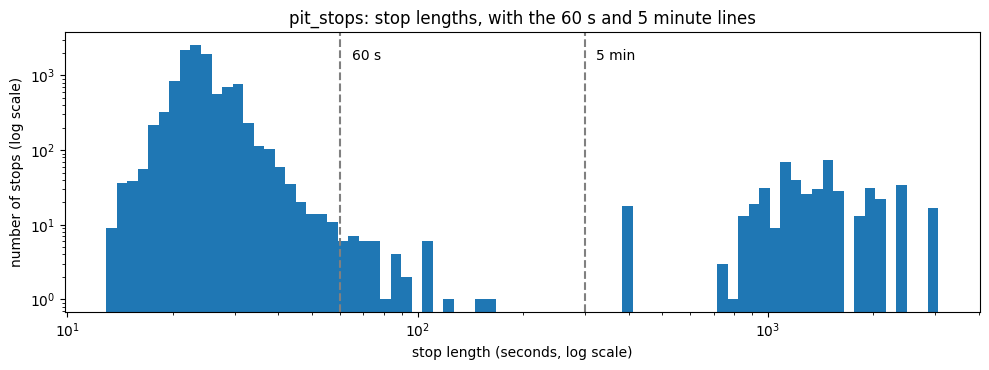

stops by kind: {'normal': 10854, 'red-flag pause': 478, 'very slow stop': 39}


,stops,median_drivers_together,with_4_or_more_others
kind,,,
red-flag pause,478,17.0,461
very slow stop,39,1.0,10


driver-races where the count changes: 404 | left with 0 stops: 41


In [183]:
sec = ps.milliseconds / 1000
print('duration (s): min', round(sec.min(), 1), '| median', round(sec.median(), 1),
      '| 90%', round(sec.quantile(0.90), 1), '| 99%', round(sec.quantile(0.99), 1), '| max', round(sec.max(), 1))

cut = pd.DataFrame({'stops': {f'longer than {k} s': int((sec > k).sum()) for k in [30, 60, 120, 180, 300]},
                    'races': {f'longer than {k} s': ps[sec > k].raceId.nunique() for k in [30, 60, 120, 180, 300]}})
display(cut)

# picture: every stop length on a log scale, with the 60 s and 5 minute lines
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(sec, bins=np.logspace(np.log10(sec.min()), np.log10(sec.max()), 80))
ax.set_xscale('log')
ax.set_yscale('log')
for x, label in [(60, '60 s'), (300, '5 min')]:
    ax.axvline(x, linestyle='--', color='gray')
    ax.text(x * 1.08, 0.9, label, transform=ax.get_xaxis_transform())
ax.set_xlabel('stop length (seconds, log scale)')
ax.set_ylabel('number of stops (log scale)')
ax.set_title('pit_stops: stop lengths, with the 60 s and 5 minute lines')
plt.tight_layout()
plt.show()

ps['kind'] = np.select([sec > 300, sec > 60], ['red-flag pause', 'very slow stop'], 'normal')
print('stops by kind:', ps.kind.value_counts().to_dict())

long = ps[sec > 60].assign(together=lambda t: t.groupby(['raceId', 'lap']).driverId.transform('nunique'))
display(long.groupby('kind').together.agg(stops='size', median_drivers_together='median',
                                          with_4_or_more_others=lambda s: int((s >= 5).sum())))

raw = ps.groupby(['raceId', 'driverId']).size()
clean = ps[ps.kind != 'red-flag pause'].groupby(['raceId', 'driverId']).size().reindex(raw.index).fillna(0).astype(int)
print('driver-races where the count changes:', int((raw != clean).sum()), '| left with 0 stops:', int((clean == 0).sum()))

### pit_stops, structure, keys, coverage, types and long stops

**Grain.** The table has 11,371 rows and 7 columns. One row is one pit stop of one driver in one race, where `stop` is the number of that stop within the race and `lap` is the lap it happened on.

**Primary key.** The table has no ID column, and `(raceId, driverId, stop)` has 0 duplicates, so it is a valid natural key.

**Missing values.** No column has any missing value.

**Coverage.** Pit stop data covers 2011 to 2024, with 285 races and 76 drivers, which is about 25% of all 1,125 races. No race before 2011 has any data, so the coverage is a clean cut at 2011. Of the 286 races from 2011 on, only the 2021 Belgian Grand Prix has no rows, which is consistent with a race that was abandoned without any racing.

**Completeness.** Of 5,960 race starts in races with pit data, 5,575 have at least one stop. The missing ones are mostly retirements that ended before a stop was needed, and of 4,922 classified finishers only 3 have no stop recorded. One of them, Karthikeyan in the 2011 Malaysian GP, was classified after only 14 laps, so a race without a stop is plausible. The other two, Gasly in the 2019 Abu Dhabi GP and Ocon in the 2021 Turkish GP, ran nearly the full distance, so at most two rows are missing in the whole table.

**Types.** Following the rule that durations become numbers, we converted one text column and kept the original. The `duration` column holds a stop length in two written forms, plain seconds such as 26.898 in 10,854 rows and minutes with seconds such as 1:29.401 in 517 rows, with none in any other form. We converted it to seconds in a new column `duration_s`, and all 11,371 values converted with none lost. It matches the `milliseconds` column in all 11,371 rows, so the two columns carry the same information. The `time` column is the clock time of the stop, always written as hh:mm:ss. Like the start times in `races`, it is kept as text, because a time of day alone has no date. This clock does not agree with the race start time in `races`, and the difference varies from race to race between 1 and 9 whole hours, so the stop times are probably local while the race start is stored in UTC. We do not use either column. The remaining five columns are already integers.

**Stop numbering.** In 5,567 of the 5,575 driver-races the stops are numbered exactly 1 to n, and 8 are not. Six of them are at the 2024 Monaco GP, where each driver has a stop of about 39 minutes on lap 1 and then a normal stop of about 24 seconds on lap 2 numbered 15, 42, 51, 52, 57 or 70. These numbers are labels gone wrong and not real stop counts, since no driver has more than 7 stop rows in a race. In the 2014 British GP and the 2019 Singapore GP one driver each starts at stop 2, so their first stop is missing. We therefore do not trust `stop` as a count and recount stops by sorting on `lap`.

**Long stops.** A real stop is fast, with a median of 23.6 seconds and 90% under 31.6 seconds, but the longest is 3,069 seconds, which is about 51 minutes. 517 stops are longer than 60 seconds, spread over 50 races. Of these, 478 are longer than 5 minutes and 39 are between 1 and 5 minutes. The 5 minute line is supported by the data, because only 3 stops last between 2 and 5 minutes and none between 3 and 5 minutes (see the histogram), so any cutoff in that range gives the same 478 rows. These 478 are made together by the whole field, with a median of 17 drivers stopping on the same lap of the same race and 461 of them alongside at least 4 other drivers, which is what a stoppage of the whole race looks like. The 39 slower stops have a median of 1 driver, so they are single slow stops.

**Decision.** A stop up to 60 seconds is a real pit stop. The 478 rows longer than 5 minutes are red-flag pauses, so they are removed from stop counts and from any duration figure, which changes the count in 404 of 5,575 driver-races and leaves 41 with no stops. The 39 very slow stops are kept as stops and flagged, and stop durations are summarised with medians rather than averages.

## Key checks for all 14 tables

The keys were checked table by table above. This cell repeats the check for all 14 tables in one place: is each table's key unique and never empty, and does every id point to a row that exists in its parent table (no orphans)? `lap_times` and `pit_stops` have no id column, so their key is a combination of columns.

In [184]:
# every table: is its key unique and complete, and does every id point to an existing row?
keys = {'results': (results_unique, ['resultId']), 'qualifying': (qualifying, ['qualifyId']),
        'seasons': (seasons, ['year']), 'races': (races, ['raceId']), 'circuits': (circuits, ['circuitId']),
        'drivers': (drivers, ['driverId']), 'constructors': (constructors, ['constructorId']),
        'status': (status, ['statusId']), 'driver_standings': (driver_standings, ['driverStandingsId']),
        'constructor_standings': (constructor_standings, ['constructorStandingsId']),
        'constructor_results': (constructor_results, ['constructorResultsId']),
        'sprint_results': (sprint_results, ['resultId']),
        'lap_times': (lap_times, ['raceId', 'driverId', 'lap']), 'pit_stops': (pit_stops, ['raceId', 'driverId', 'stop'])}
parents = {'raceId': races.raceId, 'driverId': drivers.driverId, 'constructorId': constructors.constructorId,
           'circuitId': circuits.circuitId, 'statusId': status.statusId, 'year': seasons.year}

rows = []
for name, (df, key) in keys.items():
    fks = [c for c in parents if c in df.columns and [c] != key]
    rows.append({'table': name, 'rows': len(df), 'key': ', '.join(key),
                 'key nulls': int(df[key].isna().any(axis=1).sum()), 'key duplicates': int(df.duplicated(key).sum()),
                 'foreign keys': ', '.join(fks),
                 'orphans': int(sum((~df[c].dropna().isin(parents[c])).sum() for c in fks))})
key_checks = pd.DataFrame(rows)
display(key_checks)
assert (key_checks[['key nulls', 'key duplicates', 'orphans']] == 0).all().all(), 'a key check failed'

,table,rows,key,key nulls,key duplicates,foreign keys,orphans
0,results,26668,resultId,0,0,"raceId, driverId, constructorId, statusId",0
1,qualifying,10494,qualifyId,0,0,"raceId, driverId, constructorId",0
2,seasons,75,year,0,0,,0
3,races,1125,raceId,0,0,"circuitId, year",0
4,circuits,77,circuitId,0,0,,0
5,drivers,861,driverId,0,0,,0
6,constructors,212,constructorId,0,0,,0
7,status,139,statusId,0,0,,0
8,driver_standings,34863,driverStandingsId,0,0,"raceId, driverId",0
9,constructor_standings,13391,constructorStandingsId,0,0,"raceId, constructorId",0


**Result:** all 14 tables pass. Every key is unique and never empty, and no foreign key has an orphan. This includes `lap_times` and `pit_stops`, whose links to `races` and `drivers` were not checked in their own sections.

# 3. Cleaning summary: decisions and findings

This section gathers the decisions taken across all 14 tables, grouped by the kind of decision rather than by table, because the same finding often appears in several tables and leads to one rule.

## 1. What the modelling table is

One row is one driver in one race, and the target is whether the finishing position (`positionOrder`) is 3 or less. The base table is `results` after deduplication, and every other table is joined onto it on `raceId` and `driverId`, or through `raceId` for race-level and circuit-level information, or on `constructorId` for team information.

Two tables hold many rows per driver-race, so they cannot be joined directly: `lap_times` (one row per lap) and `pit_stops` (one row per stop). `lap_times` is summarised to one value per driver and race before it is used (the pace feature, 7.8). `pit_stops` is cleaned but not used as a feature.

## 2. Rows we remove or mark

Several tables pointed to the same small set of rows that do not belong in the modelling table.

| Rows | Where it came from | What we do |
|---|---|---|
| 91 extra rows in 85 duplicate driver-races | results has repeated rows, mostly from shared drives (1950 to 1964), plus 3 drivers entered in two cars who started in neither | Keep the lowest `positionOrder` per driver and race |
| 87 shared finishing places in 45 races, 1950 to 1961 | results, two drivers of the same team credited with one car's `positionOrder` (shared drives); in 18 of these races more than 3 rows have a podium place | Keep as recorded, so both drivers of a shared car keep its result. The model scores every row on its own and does not assume three podiums per race (10.8). Q2 leaves these cars out, because their result is two drivers' effort |
| 1,366 rows of drivers who failed to qualify (code F) | results | Flag as `failed_to_qualify`, build history features first, then drop. Every other driver stays as a normal entry, because only a failed qualification is known before the prediction cutoff. A second flag, `did_not_start`, marks every driver who did not take the start, and only the data-engineering questions use it |
| 381 rows from 11 Indianapolis 500 races | results, races, constructors and constructor_standings all treat it differently | Flag as `is_indy500` and exclude from the modelling table |
| Rows with grid 0 (72 pit-lane starts with laps run, and the drivers kept in the data who did not take a grid slot) | results | Keep, flag the pit-lane starts as `pit_lane_start`, and put every grid 0 row at the back of the field in `grid_clean`, except a driver who did not start and whose qualifying slot the official grid left empty, who keeps his qualifying position (`grid` itself is unchanged) |

The Indianapolis races are identified by race name and not by `circuitId`, because the same circuit also hosted the United States Grand Prix from 2000 to 2007. They are excluded because 103 of their 107 drivers never raced another Formula One race, because the fields of 33 to 42 cars make grid position mean something different, because 30 constructors entered only this race, and because the constructor tables record it inconsistently.

## 3. Features that must look backwards only

Several tables record a race after it has been run, so using the row of the race itself would leak the result into the features. The same rule solves all of them.

- The driver and constructor standings rows of a race are written after that race, confirmed by 99.8% (drivers) and 99.3% (constructors) of rows matching the points scored that weekend. We therefore use the previous round, ordered by year and round and not by `raceId`. Round 1 has no previous round, so the previous season's final position is used instead (decided in 7.4).
- The status of a driver is only known after the race, and 99.8% of podium finishers are either Finished or classified laps down, so status is never used as a feature.
- The fastest lap and the finishing time in results are only known afterwards and are not used.
- Lap times and pit stops belong to the race itself, so they can only feed history features built from earlier races.

## 4. Numbers that are not comparable across eras

The rules of the sport changed often, so several raw numbers mean different things in different seasons. In every case the answer is to use a rate or a relative value rather than a raw total.

- Points are not comparable, since a champion scored 30 points in 1950, 95 in 2009, 256 in 2010 and 575 in 2023. Season totals become points per race or a share of the points available.
- The calendar grew from 7 races in 1950 to 24 in 2024, so any season total becomes a rate.
- Raw lap times cannot be compared between races, because the typical lap of a race ranges from 58.7 to 225.4 seconds. Each lap is divided by the median lap of its own race.
- Before 1979 a team's points often equal only its best car's points, and before 1991 some final standings are lower than the points scored. This fits the old rules that counted only the best car and only a driver's best results (F1 history; the tables show the gaps, not the rules). So standings and constructor points of those eras do not equal the sum of the race points.

## 5. Columns converted to proper types

The project requires dates and durations to be stored as real objects rather than text, so the same conversion was applied wherever a column held a date or a duration written as a string. In each case the original column was kept and the converted value was added beside it.

| Column | Table | Converted to |
|---|---|---|
| `date` and the five session date columns | races | datetime |
| `dob` | drivers | datetime |
| `q1`, `q2`, `q3` | qualifying | seconds |
| `fastestLapTime` | results and sprint_results | seconds |
| `duration` | pit_stops | seconds |

Clock times of day (the race start times in races and the stop times in pit_stops) stay as text, because a time of day alone has no date.

Where a numeric version of a column already existed, the text version was left alone rather than converted twice. This applies to `time` and `milliseconds` in results, sprint_results and lap_times, where `milliseconds` is used and the text column is kept unchanged.

**Spellings made consistent.** Two values were written two ways and are fixed on the cleaned copies: `United States` becomes `USA` in circuits (1 circuit), and `Argentinian ` becomes `Argentine` in drivers (1 driver; the value also had a trailing space).

## 6. Missing values: what we fill, what we leave, and when

Cleaning turns every `\N` into a proper missing value and fills nothing. Each kind of missing value is handled where its decision belongs:

| Kind of missing value | Example | Decision | Reason |
|---|---|---|---|
| **The value does not exist** | `time` for a driver who retired, `q2` and `q3` for a driver knocked out earlier, FP3 on a sprint weekend | **Never filled** | The missing value *is* the answer. Any number put there would be invented. |
| **Known only after the race** | `time`, `milliseconds`, `fastestLap`, `fastestLapTime`, `points`, `laps`, `status` | **Not filled** | These describe the race itself, so they cannot be model inputs at the prediction cutoff (leakage). |
| **Not recorded in older seasons** | qualifying times before 2003, session times before 2021 | **Filled later, in preprocessing, only if used as a feature** | Filled **after the train/validation/test split, using the training data only** (for example the training median), so nothing from the test seasons leaks into training. Each feature has its own fill rule (9.2), and the order of the steps is tested in the preprocessing-order experiments (9.6). |

Each table's section explains its own missing values (for example results, *remaining missing values*; qualifying, *summary of checks*; races, *missing values*).

## 7. Data quality flags

Three checks found a small number of rows that are real but unreliable, and in every case the row is kept and marked rather than deleted, so the table still matches the source and the decision stays visible.

- `laps_mismatch` marks 19 driver-races in lap_times whose lap count differs from results by 3 laps or more, including three swaps between teammates. Any lap-based feature skips them.
- `kind` marks the 478 pit stop rows longer than 5 minutes as red-flag pauses and the 39 rows between 1 and 5 minutes as very slow stops. The pauses are removed from stop counts and durations.
- The `stop` number in pit_stops is not trusted as a count, because 8 driver-races are numbered wrongly, so stops are recounted by sorting on lap.

## 8. Keys, joins and two more fixes

- **Keys.** Every table's key is unique and never empty, and no foreign key has an orphan (*Key checks for all 14 tables*, at the end of section 2).
- **Join only on ids.** Drivers are joined on `driverId`, never on `code` or `number`, which other drivers reuse. Teams are joined on `constructorId`, never on the name. Circuits are found by `circuitId`, never by the race name, because one circuit can host races under several names. Races are found by `raceId`, never by circuit and year, because a circuit hosted two races in one season in 2020 and 2021.
- **One impossible qualifying time.** A Q1 time of 1,002.6 seconds (1995 Japanese Grand Prix) is set to missing in `q1_s`. The text is kept.
- **Team history.** Some teams have several ids (Cooper has 11), and some ids cover separate periods (Mercedes in 1954–1955 and again from 2010). Team features follow `constructorId` and restart after a break of five seasons or more (decided in 7.5).

# 4. EDA after cleaning

This section compares the cleaned tables with `raw_before`, to show what the cleaning changed and to check that it did not change anything it should not have.

## 4.1 Rows at each step

How many rows of `results` are left after each cleaning step. This shows how much each step removes.

,rows,removed
raw results,26759,0
one row per driver per race,26668,91
without drivers who failed to qualify,25302,1366
without them and without the Indy 500 (modelling rows),24921,381


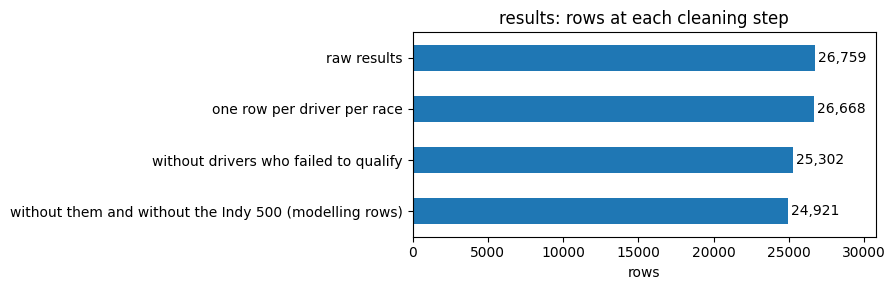

In [185]:
# rows of results at each step, down to the rows of the modelling table
post_model = results_unique[~results_unique.failed_to_qualify & ~results_unique.is_indy500]

post_steps = pd.Series({
    'raw results': len(raw_before['results']),
    'one row per driver per race': len(results_unique),
    'without drivers who failed to qualify': int((~results_unique.failed_to_qualify).sum()),
    'without them and without the Indy 500 (modelling rows)': len(post_model),
})
display(post_steps.to_frame('rows').assign(removed=lambda d: -d.rows.diff().fillna(0).astype(int)))

ax = post_steps[::-1].plot.barh(figsize=(9, 3))
for i, v in enumerate(post_steps[::-1]):
    ax.text(v + 200, i, f'{v:,}', va='center')
ax.set_xlim(0, post_steps.max() * 1.15)
plt.xlabel('rows')
plt.title('results: rows at each cleaning step')
plt.tight_layout()
plt.show()

## 4.2 Missing values

The missing values before and after cleaning, first for all 14 tables, then column by column for `results`. Cleaning fills nothing, so after cleaning a table should have as many missing values as it had `\N` cells (plus the empty cells pandas already saw).

,missing seen by pandas (raw),\N in the raw file,missing after cleaning
results,0,122887,122260
qualifying,68,11600,11668
seasons,0,0,0
races,0,11349,11349
circuits,0,0,0
drivers,0,1559,1559
constructors,0,0,0
status,0,0,0
driver_standings,0,0,0
constructor_standings,0,0,0


,missing seen by pandas (raw),\N in the raw file,missing after cleaning
number,0,6,6
position,0,10953,10872
rank,0,18249,18158
fastestLap,0,18507,18416
fastestLapTime,0,18507,18416
fastestLapSpeed,0,18507,18416
milliseconds,0,19079,18988
time,0,19079,18988


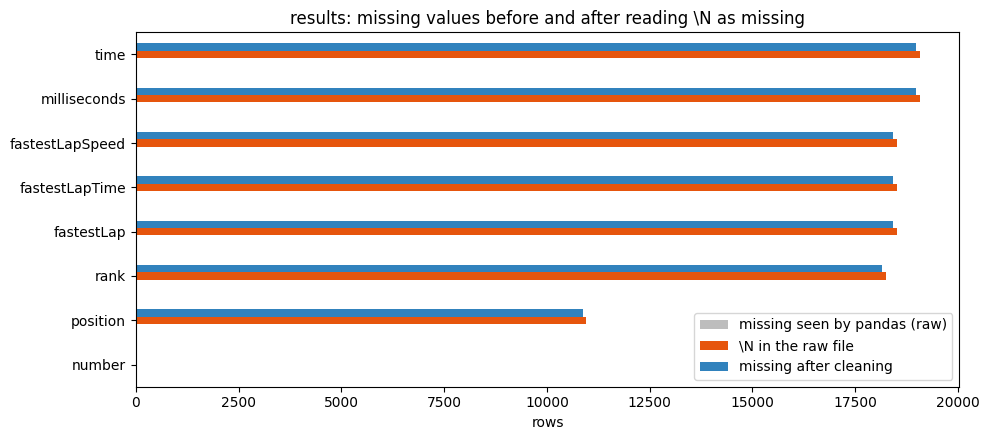

In [186]:
# the cleaned version of every table, next to raw_before
post_clean = {'results': results_unique, 'qualifying': qualifying, 'seasons': seasons, 'races': races,
              'circuits': circuits, 'drivers': drivers, 'constructors': constructors, 'status': status,
              'driver_standings': driver_standings, 'constructor_standings': constructor_standings,
              'constructor_results': constructor_results, 'sprint_results': sp,
              'lap_times': lap_times, 'pit_stops': ps}

# every table: missing values as pandas saw them in the raw file, the \N cells, and after cleaning
post_all = pd.DataFrame({
    'missing seen by pandas (raw)': {n: int(raw_before[n].isna().sum().sum()) for n in post_clean},
    '\\N in the raw file': {n: int((raw_before[n] == '\\N').sum().sum()) for n in post_clean},
    'missing after cleaning': {n: int(df[raw_before[n].columns].isna().sum().sum()) for n, df in post_clean.items()},
})
display(post_all)

# results: missing values as pandas saw them in the raw file, the real ones (\N), and after cleaning
post_raw = raw_before['results']
post_miss = pd.DataFrame({
    'missing seen by pandas (raw)': post_raw.isna().sum(),
    '\\N in the raw file': (post_raw == '\\N').sum(),
    'missing after cleaning': results_unique[post_raw.columns].isna().sum(),
})
post_miss = post_miss[post_miss.sum(axis=1) > 0].sort_values('\\N in the raw file')
display(post_miss)

post_miss.plot.barh(figsize=(10, 4.5), color=['#bdbdbd', '#e6550d', '#3182bd'])
plt.xlabel('rows')
plt.title('results: missing values before and after reading \\N as missing')
plt.tight_layout()
plt.show()

## 4.3 Column types

The number of text columns in each table before and after cleaning, and which columns changed type or were added. This shows the text that became numbers and dates.

,text before,text after,retyped,added
table,,,,
results,9,3,"number, position, milliseconds, fastestLap, rank, fastestLapSpeed","fastestLapTime_s, failed_to_qualify, did_not_start, pit_lane_start, grid_clean, is_indy500"
qualifying,3,3,,"q1_s, q2_s, q3_s"
seasons,1,1,,
races,14,8,"date, fp1_date, fp2_date, fp3_date, quali_date, sprint_date",
circuits,5,5,,
drivers,8,6,"number, dob",
constructors,4,4,,
status,1,1,,"times_used, group"
driver_standings,1,1,,


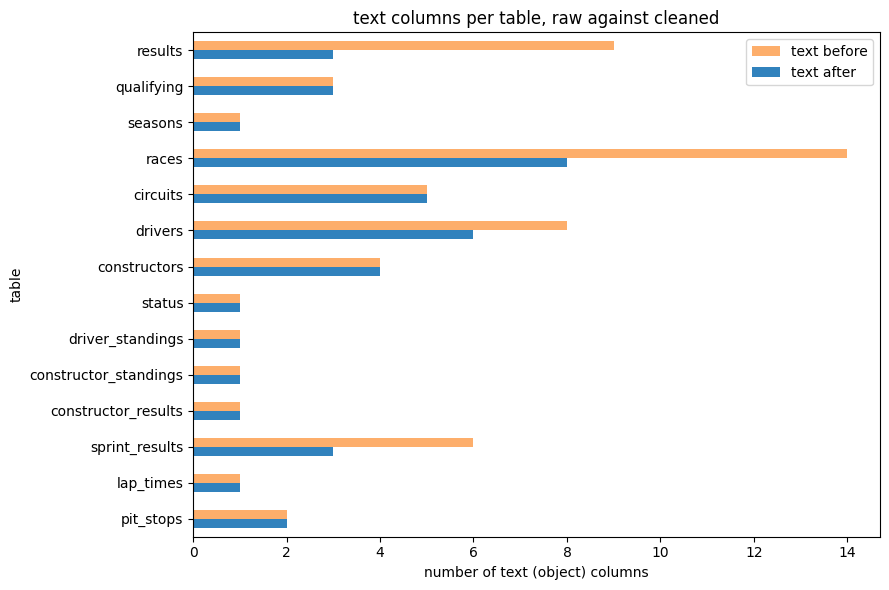

In [187]:
# column types of every table, raw against cleaned (columns added in cleaning are listed separately)

def kind(dtype):
    if pd.api.types.is_datetime64_any_dtype(dtype):
        return 'date'
    if pd.api.types.is_numeric_dtype(dtype) or pd.api.types.is_bool_dtype(dtype):
        return 'number'
    return 'text'


post_rows = []
for name, clean in post_clean.items():
    raw = raw_before[name]
    before = raw.dtypes.map(kind)
    after = clean[raw.columns].dtypes.map(kind)
    post_rows.append({'table': name,
                      'text before': int((before == 'text').sum()),
                      'text after': int((after == 'text').sum()),
                      'retyped': ', '.join(c for c in raw.columns if before[c] != after[c]),
                      'added': ', '.join(c for c in clean.columns if c not in raw.columns and c != 'year')})
post_types = pd.DataFrame(post_rows).set_index('table')
with pd.option_context('display.max_colwidth', None):
    display(post_types)

post_types[['text before', 'text after']].plot.barh(figsize=(9, 6), color=['#fdae6b', '#3182bd'])
plt.gca().invert_yaxis()
plt.xlabel('number of text (object) columns')
plt.title('text columns per table, raw against cleaned')
plt.tight_layout()
plt.show()

## 4.4 The target and the grid

The podium rate and the grid, before and after cleaning. They show what removing rows did to the target, and how `grid` = 0 was handled.

raw results                    12.69
one row per driver per race    12.73
modelling rows                 13.48


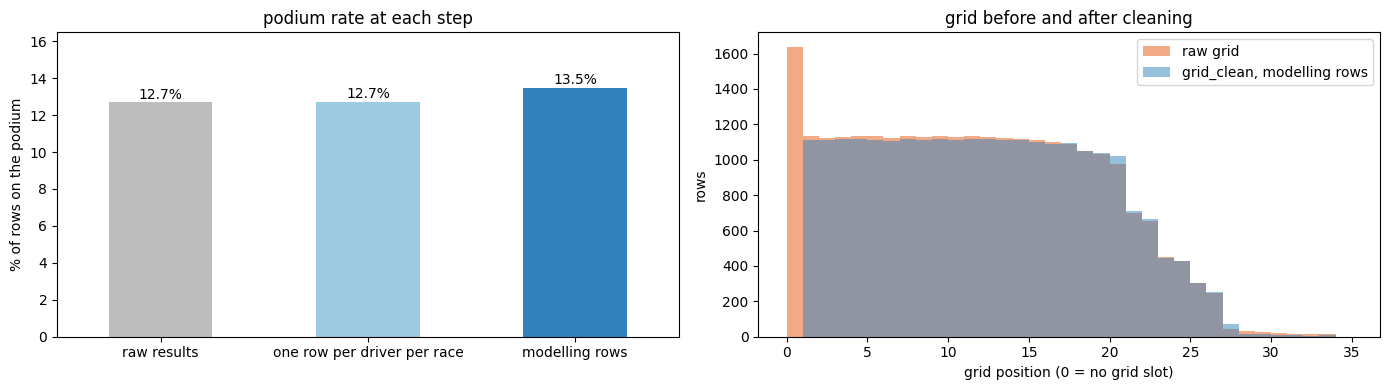

rows with grid 0, raw: 1638 | modelling rows with grid_clean 0: 0
podiums among failed_to_qualify rows: 0 | among Indy 500 rows: 36


In [188]:
# the target and the grid, raw against the modelling rows
post_rate = pd.Series({
    'raw results': (raw_before['results'].positionOrder <= 3).mean() * 100,
    'one row per driver per race': (results_unique.positionOrder <= 3).mean() * 100,
    'modelling rows': (post_model.positionOrder <= 3).mean() * 100,
})
print(post_rate.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

post_rate.plot.bar(ax=axes[0], rot=0, color=['#bdbdbd', '#9ecae1', '#3182bd'])
for i, v in enumerate(post_rate):
    axes[0].text(i, v + 0.2, f'{v:.1f}%', ha='center')
axes[0].set_ylim(0, post_rate.max() + 3)
axes[0].set_ylabel('% of rows on the podium')
axes[0].set_title('podium rate at each step')

bins = range(0, int(raw_before['results'].grid.max()) + 2)
axes[1].hist(raw_before['results'].grid, bins=bins, alpha=0.5, label='raw grid', color='#e6550d')
axes[1].hist(post_model.grid_clean, bins=bins, alpha=0.5, label='grid_clean, modelling rows', color='#3182bd')
axes[1].set_xlabel('grid position (0 = no grid slot)')
axes[1].set_ylabel('rows')
axes[1].set_title('grid before and after cleaning')
axes[1].legend()

plt.tight_layout()
plt.show()

print('rows with grid 0, raw:', int((raw_before['results'].grid == 0).sum()),
      '| modelling rows with grid_clean 0:', int((post_model.grid_clean == 0).sum()))
print('podiums among failed_to_qualify rows:', int((results_unique.failed_to_qualify & (results_unique.positionOrder <= 3)).sum()),
      '| among Indy 500 rows:', int((results_unique.is_indy500 & (results_unique.positionOrder <= 3)).sum()))

## 4.5 What the cleaning changed

**Rows.** `results` goes from 26,759 rows to 26,668 after keeping one row per driver per race (91 duplicate rows removed), and to 24,921 modelling rows once the 1,366 `failed_to_qualify` rows and the 381 Indianapolis 500 rows are left out. Those two groups are only flagged so far, and they are removed in 9.1, when the modelling table is built after the history features.

**Missing values.** In the raw file pandas saw no missing value in `results` (the grey bars are all 0), while 122,887 cells held `\N`. After cleaning, each column's missing count is its `\N` count, lower by at most 91 because of the duplicate rows removed. All of these columns except `number` describe the race outcome, so they are not features (section 2, results). In the other 13 tables nothing changes: the missing values after cleaning are exactly the `\N` cells, plus the 68 cells `qualifying` already had empty.

**Types.** Text columns fall from 9 to 3 in `results`, 14 to 8 in `races`, 8 to 6 in `drivers` and 6 to 3 in `sprint_results`. The columns that were text only because of `\N` are numbers again, the six race dates and `dob` are dates, and the duration strings have numeric versions beside them (`fastestLapTime_s`, `q1_s` to `q3_s`, `duration_s`). `qualifying` and `pit_stops` keep the same number of text columns because the converted values are added next to the original text. The text columns left are names, codes, URLs and the time columns kept as text on purpose (section 2).

**Target.** The podium rate rises from 12.7% in the raw results to 13.5% in the modelling rows. None of the 1,366 `failed_to_qualify` rows is a podium and the Indianapolis 500 rows hold 36, so 1,747 rows are removed but only 36 podiums.

**Grid.** The raw results have 1,638 rows with `grid` = 0 and the modelling rows have none in `grid_clean`. Every grid 0 row, the 72 pit-lane starters and the drivers kept in the data who did not take a slot, is set to the back of the field (the highest grid slot in that race + 1), which shows as the extra bar around grid 20. The exception is a driver who did not start and whose qualifying slot the official grid left empty, who keeps his qualifying position (results section, *Decision: who is removed*).

# 5. Modelling table, phase 1: the base table

The cleaned tables are joined onto the deduplicated results: one row per driver per race, with the target and the flags. This is the first phase of the modelling table, and section 7 takes the columns it needs from it. The next phases are:
1. **Feature engineering** (section 7): add the feature columns, built from earlier races only. The flagged rows (`failed_to_qualify`, `is_indy500`) are still here, so a driver's history counts every race.
2. **Drop rows and pick columns** (9.1 and 9.7): remove the `failed_to_qualify` and Indianapolis 500 rows, keep the seasons 2003–2024, and keep only the features and the target (the flags are helpers, not model inputs).
3. **Split** (section 8) into training, validation and test seasons.
4. **Preprocessing** (section 9): fill missing feature values and scale, learned on the training data only (cleaning summary, *Missing values*).

In [189]:
# all the cleaned tables in one table: one row per driver per race, with the target and the flags
print('start:', len(results_unique))

base = (results_unique
        .merge(races[['raceId', 'year', 'round', 'circuitId', 'date', 'name']], on='raceId', how='left')
        .merge(circuits[['circuitId', 'country', 'alt']], on='circuitId', how='left')
        .merge(drivers[['driverId', 'surname', 'dob', 'nationality']].rename(columns={'nationality': 'driver_nat'}), on='driverId', how='left')
        .merge(constructors[['constructorId', 'name', 'nationality']].rename(columns={'name': 'team', 'nationality': 'team_nat'}), on='constructorId', how='left')
        .merge(status[['statusId', 'status']], on='statusId', how='left'))
base['podium'] = (base.positionOrder <= 3).astype(int)    # the target, never a feature

print('after merges:', len(base), '| row count unchanged:', len(base) == len(results_unique))
print('duplicate (raceId, driverId):', base.duplicated(['raceId', 'driverId']).sum())
print('missing after merge:', base[['year', 'country', 'surname', 'team', 'status']].isna().sum().to_dict())
print(base.shape)

start: 26668
after merges: 26668 | row count unchanged: True
duplicate (raceId, driverId): 0
missing after merge: {'year': 0, 'country': 0, 'surname': 0, 'team': 0, 'status': 0}
(26668, 38)


# 6. Data-engineering questions

The three data-engineering questions of the brief. Each one starts from the cleaned tables built above (sections 2 to 5): `results_unique` with its flags (`did_not_start`, `pit_lane_start`, `grid_clean`, `is_indy500`), `races`, `circuits`, `drivers`, `constructors`, `status` (with its `group` column) and `qualifying`. No question loads or cleans the data again, and no question changes these tables.

Run the notebook from the top: some settings (for example `K_VALUES`) are defined again by each question.

The questions describe what happened in races, so they count only the drivers who took the start (`did_not_start`, results section). The model is different. It predicts the day before the race, so it keeps every driver except those who failed to qualify (`failed_to_qualify`).

## Q1: Which circuits turn a front-row start into a podium, and did that change after 2014?

A **front-row start** is starting the race from position 1 or 2. **Converting** it means finishing on the podium (1st, 2nd or 3rd). So for each circuit we ask: *when a driver starts on the front row here, how often do they finish on the podium?*

The question has three parts, answered in this order:
1. **Qualifying or grid?** Which number decides who started on the front row.
2. **Which circuits convert most often?**
3. **Did that change after 2014**, when Formula 1 moved to hybrid engines?

**Grain:** one front-row starter in one race (two rows per race). **Pre-race cutoff:** the grid is fixed before the race starts, so a front-row start is known at prediction time, and the podium is the outcome we count. **Missingness:** every race should have one car in slot 1 and one in slot 2, checked in 1.

### 0. Setup

Settings and small helper functions. The helpers (`table`, `md`, `savefig`, `wilson`, `bayes_avg`, `pct_range`) are also used by Q2 and Q3.

In [190]:
PRE_START = 1980        # first season of the earlier period (explained in 2.3)
HYBRID_START = 2014     # first season of the hybrid era
LAST_SEASON = 2024      # the brief covers seasons up to 2024
QUALI_START = QYEAR     # first season with complete qualifying records, set in the results section
K_MAIN = 10             # pretend front-row starts added to every circuit (2.2)
K_VALUES = [5, 10, 20]  # other numbers of pretend starts we try (2.5)
MIN_N = 10              # a circuit needs at least this many front-row starts to be ranked (about 5 races)
MIN_N_VALUES = [6, 10, 14]
TOP = 5                 # size of the top group
N_RESAMPLES = 2000      # pretend worlds in the luck test (3.3)
SEED = 42

ERA_PRE, ERA_POST = f"{PRE_START}–{HYBRID_START - 1}", f"{HYBRID_START}–{LAST_SEASON}"
ERAS = [ERA_PRE, ERA_POST]
ERA_COLORS = {ERA_PRE: "#4C72B0", ERA_POST: "#DD8452"}
GREY = "#8C8C8C"
FIG_DIR = os.path.join("report", "figures", "q1")
os.makedirs(FIG_DIR, exist_ok=True)

In [191]:
from scipy import stats                          # not imported in section 0
from IPython.display import display, Markdown

def table(df, pct=(), pct1=(), dec1=(), dec2=(), caption=None):
    """Show a DataFrame as a formatted table (pct: whole percent, pct1: one decimal)."""
    fmt = {c: "{:.0%}" for c in pct}
    fmt.update({c: "{:.1%}" for c in pct1})
    fmt.update({c: "{:.1f}" for c in dec1})
    fmt.update({c: "{:.2f}" for c in dec2})
    s = df.style.format(fmt, na_rep="–").hide(axis="index")
    if caption:
        s = s.set_caption(caption).set_table_styles([{"selector": "caption", "props": [
            ("caption-side", "top"), ("font-weight", "bold"), ("text-align", "left"), ("font-size", "110%")]}])
    display(s)

def md(text):
    """Show a result as formatted text."""
    display(Markdown(text))

def savefig(name):
    """Save the current figure (into this question's FIG_DIR) so it can be reused in the report."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

def wilson(successes, n, z=1.96):
    """95% Wilson range for a rate of `successes` out of `n` (stays inside 0–100% for small samples)."""
    k, n = np.asarray(successes, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.minimum(centre - half, p), np.maximum(centre + half, p)   # min/max only removes rounding errors

def bayes_avg(events, starts, prior_rate, k):
    """Bayesian average: k pretend starts at `prior_rate`, plus the real results."""
    return (events + k * prior_rate) / (starts + k)

def pct_range(lo, hi, digits=0):
    """Format two arrays of rates as '57% – 90%' strings."""
    return [f"{a:.{digits}%} – {b:.{digits}%}" for a, b in zip(lo, hi)]

def short(name):
    """Shorter circuit names for figures."""
    if name == "Circuit of the Americas":
        return "Americas (COTA)"
    for w in ["Autodromo Nazionale di ", "Autodromo Internazionale ", "Autódromo ", "Autodromo ",
              "Circuit de ", "Circuito de ", "Circuit ", " Circuit", " International", " Internacional"]:
        name = name.replace(w, "")
    return name.strip()

def pct_axis(axis):
    """Show an axis in percent."""
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

### 1. The data

We start from `results_unique` without the drivers who did not take the start (`did_not_start`) and without the Indianapolis 500. From the earlier sections:
- **Duplicates** (shared drives) end in 1978 and the **Indianapolis 500** in 1960, both before our seasons.
- **Drivers who did not take the start are left out** (`did_not_start`, results section). Q1 describes what happened in races, so a front-row car that failed before the start, for example Leclerc on pole at Monaco 2021, is not a front-row start. Pit-lane starters (`grid` = 0 with laps) can never be slot 1 or 2.
- A circuit is identified by `circuitId`, so a track keeps one record under all its Grand Prix names.
- `qualifying` has one row per driver per race, so joining it adds no rows.

**Missing data check:** every race should have exactly one car in slot 1 and one in slot 2.

In [192]:
starters = results_unique[~results_unique.did_not_start & ~results_unique.is_indy500]
q1_base = (starters[["raceId", "driverId", "grid", "positionOrder"]]
           .merge(races[["raceId", "year", "circuitId"]], on="raceId", how="left", validate="m:1")
           .merge(circuits[["circuitId", "name"]].rename(columns={"name": "circuit_name"}),
                  on="circuitId", how="left", validate="m:1")
           .merge(qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
                  on=["raceId", "driverId"], how="left", validate="1:1"))
q1_base = q1_base[q1_base.year.between(PRE_START, LAST_SEASON)].copy()
assert q1_base[["year", "circuit_name"]].notna().all().all()
q1_base["podium"] = (q1_base.positionOrder <= 3).astype(int)
q1_base["era"] = np.where(q1_base.year < HYBRID_START, ERA_PRE, ERA_POST)

fr = q1_base[q1_base.grid.isin([1, 2])].copy()   # one row per front-row start

race_era = q1_base.groupby("raceId").era.first()
fr_slots = (fr.groupby(["raceId", "grid"]).size().unstack(fill_value=0)
              .reindex(index=race_era.index, columns=[1, 2], fill_value=0))
table(pd.DataFrame({
    "races": race_era.value_counts(),
    "both front-row slots recorded": ((fr_slots[1] == 1) & (fr_slots[2] == 1)).groupby(race_era).mean(),
    "races with a slot held twice": ((fr_slots[1] > 1) | (fr_slots[2] > 1)).groupby(race_era).sum(),
    "front-row starts": fr.era.value_counts(),
    "share on the podium": fr.groupby("era").podium.mean(),
}).reindex(ERAS).rename_axis("period").reset_index(), pct=["both front-row slots recorded", "share on the podium"],
      caption="Front-row starts per period")

period,races,both front-row slots recorded,races with a slot held twice,front-row starts,share on the podium
1980–2013,569,99%,0,1133,60%
2014–2024,228,99%,0,453,76%


**Reading.** No slot is ever held twice. The few races without both slots are races where a front-row car did not take the start (it failed, crashed or withdrew before the start, for example Leclerc on pole at Monaco 2021). Those races count fewer front-row starts.

### Part 1: Qualifying or grid?

Two numbers could say who was on the front row:
- the **qualifying position**: where the driver qualified on Saturday;
- the **grid slot** (`grid`): where the car **actually started** on Sunday.

They are usually the same, but not always: a driver can qualify 1st, get a penalty (for example for changing an engine) and start 10th. In 2021 and 2022 a sprint race also set the grid.

**What we check:** from 2003 (the first season with complete qualifying records, see the results section), how often do front-row drivers finish on the podium in each case? The bars have an **error bar** (a "95% Wilson range"): the range the true rate is probably in. It is wide when there are few cases, narrow when there are many.

case,starts,podiums,podium rate,95% Wilson range
Qualified and started on the front row,815,594,73%,70% – 76%
Started on the front row without qualifying there,36,23,64%,48% – 78%
"Qualified on the front row, started further back",36,11,31%,18% – 47%


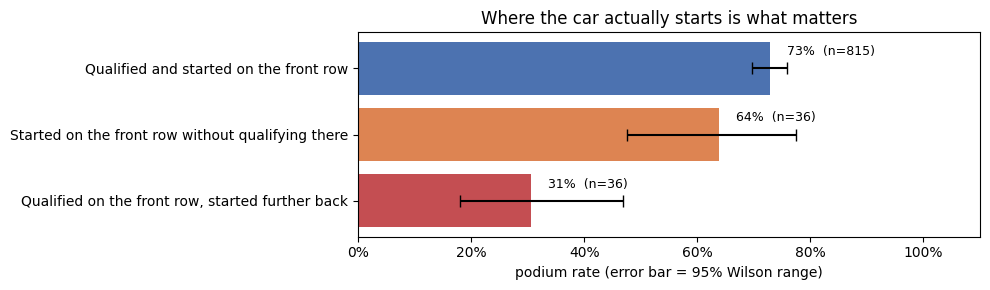

In [193]:
qa = q1_base[q1_base.year >= QUALI_START].copy()
fr_quali, fr_grid = qa.quali_pos.isin([1, 2]), qa.grid.isin([1, 2])
CASES = ["Qualified and started on the front row",
         "Started on the front row without qualifying there",
         "Qualified on the front row, started further back"]
qa["case"] = np.select([fr_quali & fr_grid, ~fr_quali & fr_grid, fr_quali & ~fr_grid], CASES, default="")

cases = (qa[qa.case != ""].groupby("case").agg(starts=("podium", "size"), podiums=("podium", "sum"))
           .reindex(CASES).reset_index())
cases["podium rate"] = cases.podiums / cases.starts
cases["ci_lo"], cases["ci_hi"] = wilson(cases.podiums, cases.starts)
table(cases.assign(**{"95% Wilson range": pct_range(cases.ci_lo, cases.ci_hi)}).drop(columns=["ci_lo", "ci_hi"]),
      pct=["podium rate"], caption=f"Podium rate by front-row case, {QUALI_START}–{LAST_SEASON}")

fig, ax = plt.subplots(figsize=(10, 3))
c = cases.iloc[::-1]
ax.barh(c.case, c["podium rate"], color=["#C44E52", "#DD8452", "#4C72B0"],
        xerr=[c["podium rate"] - c.ci_lo, c.ci_hi - c["podium rate"]], capsize=4)
for i, (rate, n) in enumerate(zip(c["podium rate"], c.starts)):
    ax.text(rate + 0.03, i + 0.25, f"{rate:.0%}  (n={n})", va="center", fontsize=9)
ax.set(xlim=(0, 1.1), xlabel="podium rate (error bar = 95% Wilson range)",
       title="Where the car actually starts is what matters")
pct_axis(ax.xaxis)
plt.tight_layout(); savefig("q1_01_quali_vs_grid"); plt.show()

In [194]:
kept, promoted, pushed = (cases.set_index("case").loc[x] for x in CASES)
md(f"""**Part 1 answer:**
- The two numbers agree in **{kept.starts / fr_grid.sum():.0%}** of front-row starts.
- When they disagree, it matters: drivers who qualified on the front row but **started further back** reached the podium
  only **{pushed['podium rate']:.0%}** of the time (n = {int(pushed.starts)}), against **{kept['podium rate']:.0%}** for drivers
  who kept their slot. Drivers moved **up** onto the front row converted **{promoted['podium rate']:.0%}** (n = {int(promoted.starts)}).
- **So we use the grid slot:** a front-row start means `grid` = 1 or 2. Using the qualifying position would count
  penalised drivers as front-row starters although they never started there.""")

**Part 1 answer:**
- The two numbers agree in **96%** of front-row starts.
- When they disagree, it matters: drivers who qualified on the front row but **started further back** reached the podium
  only **31%** of the time (n = 36), against **73%** for drivers
  who kept their slot. Drivers moved **up** onto the front row converted **64%** (n = 36).
- **So we use the grid slot:** a front-row start means `grid` = 1 or 2. Using the qualifying position would count
  penalised drivers as front-row starters although they never started there.

### Part 2: Which circuits convert a front-row start most often?

#### 2.1 The basic count

For each circuit: **podiums ÷ front-row starts**. For example, if a circuit had 18 front-row starts and 16 of them finished on the podium, its rate is 16 ÷ 18 = 89%. The table shows the highest rates since 2014, counting every circuit.

In [195]:
raw = (fr[fr.era == ERA_POST].groupby("circuit_name")
         .agg(races=("raceId", "nunique"), **{"front-row starts": ("podium", "size"), "podiums": ("podium", "sum")})
         .reset_index().rename(columns={"circuit_name": "circuit"}))
raw["rate"] = raw.podiums / raw["front-row starts"]
table(raw.sort_values(["rate", "front-row starts"], ascending=False).head(8), pct=["rate"],
      caption=f"The basic count, {ERA_POST}: highest rates")

circuit,races,front-row starts,podiums,rate
Miami International Autodrome,3,6,6,100%
Autódromo Internacional do Algarve,2,4,4,100%
Las Vegas Strip Street Circuit,2,4,4,100%
Autodromo Internazionale del Mugello,1,2,2,100%
Circuit de Monaco,10,19,17,89%
Suzuka Circuit,9,18,16,89%
Circuit Park Zandvoort,4,8,7,88%
Jeddah Corniche Circuit,4,8,7,88%


**Reading:** the top of the list is full of circuits that hosted only one to three races. A circuit with one race where both front-row cars reached the podium gets 100%. Ranking by this number has **two problems**, fixed in 2.2 and 2.3.

#### 2.2 Problem 1: a few races can be luck

Mugello hosted **one** race (2020). Both front-row cars reached the podium, so its rate is 2 ÷ 2 = 100%. Suzuka had 16 out of 18. That does not show Mugello is the better circuit because one race proves very little.

**The fix: pretend starts.** Every circuit gets **10 pretend front-row starts at the normal rate**, and then its real results are added:

> adjusted rate = (podiums + 10 × normal rate) ÷ (front-row starts + 10)

A circuit with many real races barely moves, because its real data outweighs the 10 pretend starts. A circuit with one race is pulled most of the way back to normal. Since 2014 the normal rate is about 76%:

In [196]:
normal_post = fr[fr.era == ERA_POST].podium.mean()
ex = raw[raw.circuit.isin(["Autodromo Internazionale del Mugello", "Suzuka Circuit"])].copy()
ex["normal rate"] = normal_post
ex[f"adjusted rate ({K_MAIN} pretend starts)"] = bayes_avg(ex.podiums, ex["front-row starts"], normal_post, K_MAIN)
table(ex, pct=["rate", "normal rate", f"adjusted rate ({K_MAIN} pretend starts)"],
      caption="Pretend starts: one race against nine")

circuit,races,front-row starts,podiums,rate,normal rate,adjusted rate (10 pretend starts)
Autodromo Internazionale del Mugello,1,2,2,100%,76%,80%
Suzuka Circuit,9,18,16,89%,76%,84%


**Reading:** Mugello drops from 100% to about 80%, Suzuka only from 89% to about 84%, so Suzuka now ranks above Mugello. On top of this, a circuit needs at least **10 front-row starts** (about 5 races) to appear in the ranking at all. Review sites use the same idea, so that a film with one perfect review cannot beat one with a thousand good reviews.

#### 2.3 Problem 2: some circuits raced in "easy" years

In the 1980s cars broke down very often, so even drivers starting first often did not finish. Later, cars became reliable. The chart shows the share of front-row starters who reached the podium in every season.

**Why 1980:** from the 1980 season the staggered two-wide grid was standard in every race, so grid 1–2 is always the front row. Earlier grids were often three or four cars wide (for example 4-3-4 or 3-2-3 in the 1950s and 1960s), so "grid 1–2" would not mean "the front row". This comes from F1 history, not from the data: Ergast does not store how many cars stood in each row.

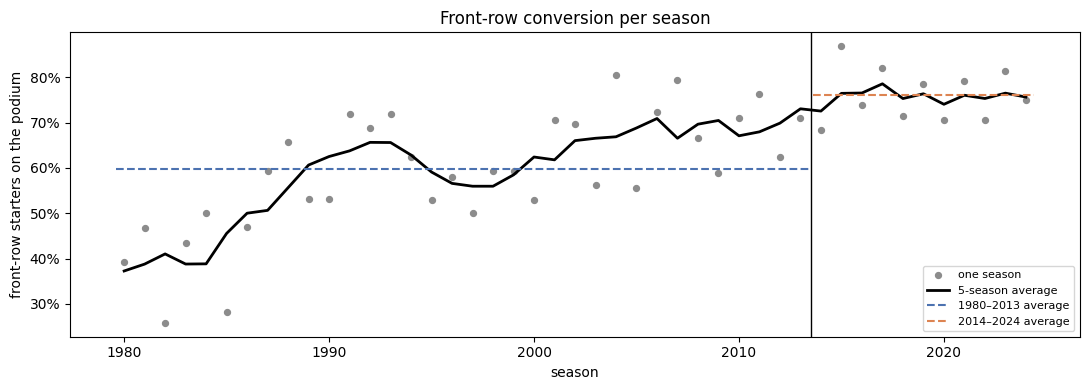

**Reading:**
- Before 2014 conversion rises from about **41%** in
  1980–1984 to about **68%** in
  2009–2013. The rise is not smooth (it dips in the late 1990s), and there is no single year
  where it jumps.
- After 2014 it is nearly flat: the 5-season average stays between **73%** and
  **79%**.
- So a circuit used mostly in later seasons looks better **just because of its years**. Across the 1980–2013 circuits,
  the correlation between the middle year a circuit was used and its rate is **0.54**.

In [197]:
season = fr.groupby("year").podium.agg(starts="size", rate="mean")
season["5-season average"] = season.rate.rolling(5, center=True, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(season.index, season.rate, color=GREY, s=18, label="one season")
ax.plot(season.index, season["5-season average"], color="black", lw=2, label="5-season average")
for e, (a, b) in {ERA_PRE: (PRE_START, HYBRID_START - 1), ERA_POST: (HYBRID_START, LAST_SEASON)}.items():
    ax.hlines(fr[fr.era == e].podium.mean(), a - 0.4, b + 0.4, color=ERA_COLORS[e], ls="--", label=f"{e} average")
ax.axvline(HYBRID_START - 0.5, color="black", lw=1)
ax.set(xlabel="season", ylabel="front-row starters on the podium", title="Front-row conversion per season")
pct_axis(ax.yaxis); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("q1_02_conversion_by_season"); plt.show()

pre = fr[fr.era == ERA_PRE].groupby("circuitId").agg(mid_year=("year", "median"), rate=("podium", "mean"),
                                                      n=("podium", "size"))
pre = pre[pre.n >= MIN_N]
r_year = np.corrcoef(pre.mid_year, pre.rate)[0, 1]
roll = season["5-season average"]
md(f"""**Reading:**
- Before 2014 conversion rises from about **{season.loc[PRE_START:PRE_START + 4].rate.mean():.0%}** in
  {PRE_START}–{PRE_START + 4} to about **{season.loc[HYBRID_START - 5:HYBRID_START - 1].rate.mean():.0%}** in
  {HYBRID_START - 5}–{HYBRID_START - 1}. The rise is not smooth (it dips in the late 1990s), and there is no single year
  where it jumps.
- After 2014 it is nearly flat: the 5-season average stays between **{roll.loc[HYBRID_START:].min():.0%}** and
  **{roll.loc[HYBRID_START:].max():.0%}**.
- So a circuit used mostly in later seasons looks better **just because of its years**. Across the 1980–2013 circuits,
  the correlation between the middle year a circuit was used and its rate is **{r_year:.2f}**.""")

**The fix: compare each circuit with what was normal in its own years.**

**How the normal rate is calculated**, in two steps:
1. **For every season**, take all front-row starters of that season, at every circuit, and compute the share who reached the podium. These are the grey dots in the chart above. For example, in 2005 there were 36 front-row starts and 20 podiums, so 2005's rate is 56%.
2. **For a circuit**, look up the rate of each season it was used in and take the average (each season counts once for every front-row start the circuit had in it).

Istanbul Park, worked out:

In [198]:
season_rate = fr.groupby("year").podium.agg(**{"front-row starts (all circuits)": "size",
                                               "podiums (all circuits)": "sum", "season rate": "mean"})
ist_years = fr[(fr.circuit_name == "Istanbul Park") & (fr.era == ERA_PRE)].groupby("year").size().rename("Istanbul front-row starts")
ist_table = season_rate.loc[ist_years.index].join(ist_years).reset_index()
ist_normal = np.average(ist_table["season rate"], weights=ist_table["Istanbul front-row starts"])
table(ist_table, pct=["season rate"], caption=f"Istanbul Park's normal rate: the average of its seasons = {ist_normal:.0%}")

year,front-row starts (all circuits),podiums (all circuits),season rate,Istanbul front-row starts
2005,36,20,56%,2
2006,36,26,72%,2
2007,34,27,79%,2
2008,36,24,67%,2
2009,34,20,59%,2
2010,38,27,71%,2
2011,38,29,76%,2


**Then:**
- the pretend starts from 2.2 are given at this normal rate, and
- the circuit's **score = adjusted rate − normal rate for its years**, in percentage points: *how much better than normal the front row does at this circuit.*

**Circuits are ranked by this score.** The table shows four circuits: Mugello and Suzuka from 2.2, and two circuits from the earlier period that raced in very different years.

In [199]:
def circuit_table(starts, min_n=MIN_N, k_values=K_VALUES):
    """One row per circuit and period: raw rate, Wilson range, normal rate for its years, scores and ranks.

    `starts` has one row per front-row start, with columns era, year, circuitId, circuit_name, raceId, podium.
    Each season's rate is computed over ALL front-row starts of the season, before the minimum-sample filter.
    """
    season_rate = starts.groupby("year")["podium"].mean()
    t = (starts.assign(expected=starts.year.map(season_rate))
               .groupby(["era", "circuitId"])
               .agg(circuit=("circuit_name", "first"), first=("year", "min"), last=("year", "max"),
                    races=("raceId", "nunique"), starts=("podium", "size"), podiums=("podium", "sum"),
                    expected=("expected", "mean"))
               .reset_index())
    t["raw rate"] = t.podiums / t.starts
    t["ci_lo"], t["ci_hi"] = wilson(t.podiums, t.starts)
    for k in k_values:
        t[f"score_k{k}"] = bayes_avg(t.podiums, t.starts, t.expected, k) - t.expected
    t = t[t.starts >= min_n].copy()
    for k in k_values:
        t[f"rank_k{k}"] = t.groupby("era")[f"score_k{k}"].rank(ascending=False, method="min").astype(int)
    sort_k = K_MAIN if K_MAIN in k_values else k_values[0]
    return t.sort_values(["era", f"rank_k{sort_k}"]).reset_index(drop=True)

RANK_COLS = [f"rank_k{k}" for k in K_VALUES]

def top_group(t, top=TOP):
    """Circuits that are in the top `top` under every value of k."""
    return t[(t[RANK_COLS] <= top).all(axis=1)]

def circuit_rows(t):
    """The circuit table in readable form (k = K_MAIN)."""
    return pd.DataFrame({
        "circuit": t.circuit,
        "seasons": [f"{a}" if a == b else f"{a}–{b}" for a, b in zip(t["first"], t["last"])],
        "front-row starts": t.starts, "podiums": t.podiums, "raw rate": t["raw rate"],
        "95% Wilson range": pct_range(t.ci_lo, t.ci_hi), "normal for its years": t.expected,
        f"adjusted rate (+{K_MAIN} pretend starts)": t.expected + t[f"score_k{K_MAIN}"],
        "score: adjusted − normal (points)": t[f"score_k{K_MAIN}"] * 100})

examples = circuit_table(fr, min_n=1, k_values=[K_MAIN])
EXAMPLES = [(ERA_POST, "Autodromo Internazionale del Mugello"), (ERA_POST, "Suzuka Circuit"),
            (ERA_PRE, "Istanbul Park"), (ERA_PRE, "Brands Hatch")]
examples = examples.set_index(["era", "circuit"]).loc[EXAMPLES].reset_index()
table(circuit_rows(examples).assign(period=examples.era.values),
      pct=["raw rate", "normal for its years", f"adjusted rate (+{K_MAIN} pretend starts)"], dec1=["score: adjusted − normal (points)"],
      caption="The score on four circuits")

circuit,seasons,front-row starts,podiums,raw rate,95% Wilson range,normal for its years,adjusted rate (+10 pretend starts),score: adjusted − normal (points),period
Autodromo Internazionale del Mugello,2020,2,2,100%,34% – 100%,71%,75%,4.9,2014–2024
Suzuka Circuit,2014–2024,18,16,89%,67% – 97%,76%,84%,8.0,2014–2024
Istanbul Park,2005–2011,14,11,79%,52% – 92%,69%,74%,5.8,1980–2013
Brands Hatch,1980–1986,12,3,25%,9% – 53%,39%,31%,-7.6,1980–2013


In [200]:
mug, suz, ist, bra = (examples.iloc[i] for i in range(4))
md(f"""**Reading:**
- **Istanbul Park** ({ist['first']}–{ist['last']}) raced in reliable years, where normal was {ist.expected:.0%}. It got
  {ist['raw rate']:.0%}, a score of {ist[f'score_k{K_MAIN}'] * 100:+.1f} points.
- **Brands Hatch** ({bra['first']}–{bra['last']}) raced when cars broke down often, where normal was {bra.expected:.0%}.
  It got {bra['raw rate']:.0%}, a score of {bra[f'score_k{K_MAIN}'] * 100:+.1f} points.
- Both are judged against their own years, not one average for 1980–2013.
- **Mugello** ({mug[f'score_k{K_MAIN}'] * 100:+.1f}) stays below **Suzuka** ({suz[f'score_k{K_MAIN}'] * 100:+.1f}), as in 2.2.""")

**Reading:**
- **Istanbul Park** (2005–2011) raced in reliable years, where normal was 69%. It got
  79%, a score of +5.8 points.
- **Brands Hatch** (1980–1986) raced when cars broke down often, where normal was 39%.
  It got 25%, a score of -7.6 points.
- Both are judged against their own years, not one average for 1980–2013.
- **Mugello** (+4.9) stays below **Suzuka** (+8.0), as in 2.2.

#### 2.4 The ranking

The top 10 circuits of each period by score (at least 10 front-row starts). The figure shows the 12 best. For each circuit, the **grey dot** is the normal rate for its years and the **coloured dot** is its adjusted rate; the line between them is the score, written on the right. The longer the line, the more the front row beats normal at that circuit.

rank,circuit,seasons,front-row starts,podiums,raw rate,95% Wilson range,normal for its years,adjusted rate (+10 pretend starts),score: adjusted − normal (points)
1,Circuit de Nevers Magny-Cours,1991–2008,35,29,83%,67% – 92%,65%,79%,14.2
2,Circuit Paul Ricard,1980–1990,18,12,67%,44% – 84%,46%,59%,13.2
3,Autódromo Hermanos Rodríguez,1986–1992,14,10,71%,45% – 88%,60%,67%,6.8
4,Kyalami,1980–1993,14,8,57%,33% – 79%,47%,53%,6.1
5,Autódromo do Estoril,1984–1996,26,17,65%,46% – 81%,57%,63%,6.0
6,Istanbul Park,2005–2011,14,11,79%,52% – 92%,69%,74%,5.8
7,Indianapolis Motor Speedway,2000–2007,14,11,79%,52% – 92%,69%,75%,5.7
8,Suzuka Circuit,1987–2013,50,35,70%,56% – 81%,63%,69%,5.5
9,Circuito de Jerez,1986–1997,14,9,64%,39% – 84%,56%,61%,4.9
10,Autódromo Juan y Oscar Gálvez,1980–1998,12,7,58%,32% – 81%,51%,55%,4.0


rank,circuit,seasons,front-row starts,podiums,raw rate,95% Wilson range,normal for its years,adjusted rate (+10 pretend starts),score: adjusted − normal (points)
1,Circuit de Monaco,2014–2024,19,17,89%,69% – 97%,77%,85%,8.4
2,Suzuka Circuit,2014–2024,18,16,89%,67% – 97%,76%,84%,8.0
3,Yas Marina Circuit,2014–2024,22,19,86%,67% – 95%,76%,83%,7.0
4,Circuit de Barcelona-Catalunya,2014–2024,22,18,82%,61% – 93%,76%,80%,3.9
4,Circuit de Spa-Francorchamps,2014–2024,22,18,82%,61% – 93%,76%,80%,3.9
6,Sochi Autodrom,2014–2021,16,13,81%,57% – 93%,76%,79%,3.0
7,Circuit of the Americas,2014–2024,20,16,80%,58% – 92%,77%,79%,2.2
8,Autódromo José Carlos Pace,2014–2024,19,15,79%,57% – 91%,76%,78%,1.6
9,Shanghai International Circuit,2014–2024,14,11,79%,52% – 92%,77%,78%,1.2
10,Circuit Gilles Villeneuve,2014–2024,18,14,78%,55% – 91%,76%,77%,0.9


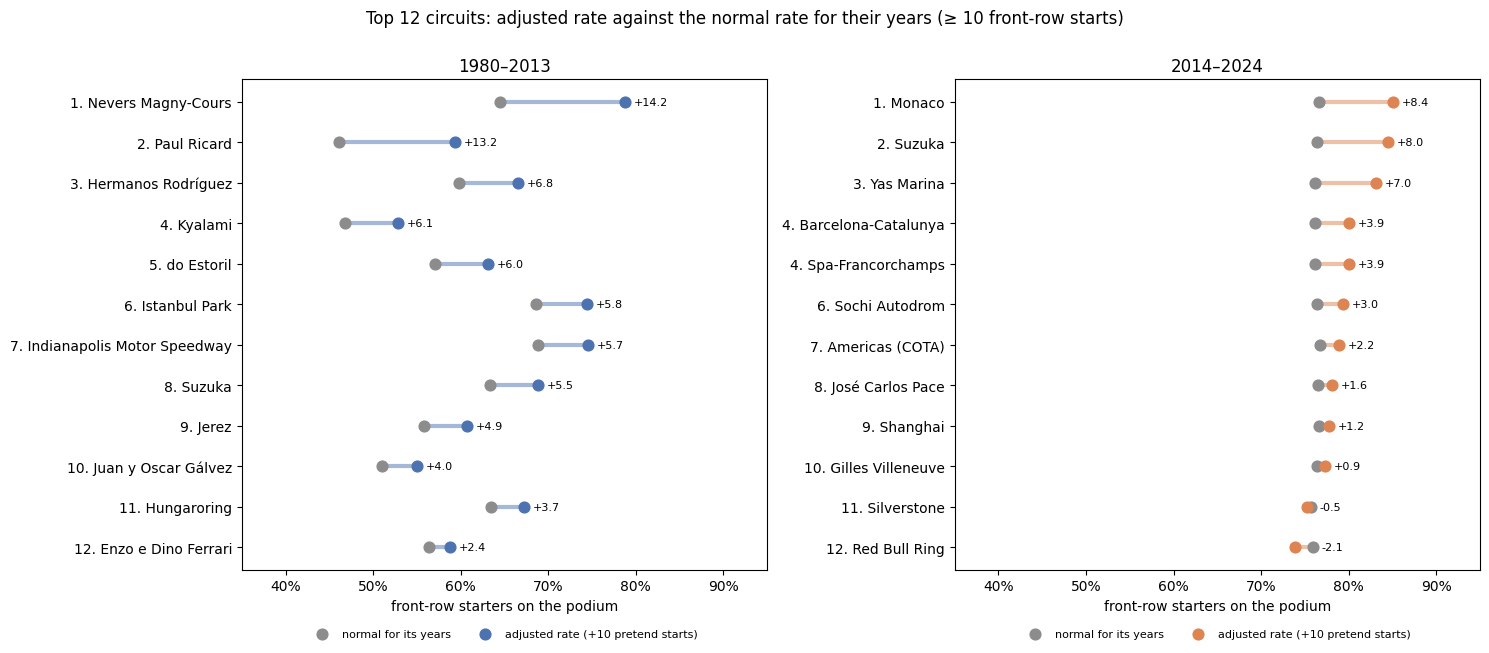

In [201]:
ct = circuit_table(fr)
for e in ERAS:
    t = ct[ct.era == e]
    top10 = circuit_rows(t.head(10))
    top10.insert(0, "rank", t.head(10)[f"rank_k{K_MAIN}"].values)
    table(top10, pct=["raw rate", "normal for its years", f"adjusted rate (+{K_MAIN} pretend starts)"], dec1=["score: adjusted − normal (points)"],
          caption=f"{e}: top 10 of {len(t)} ranked circuits")

TOP_FIG = 12
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, e in zip(axes, ERAS):
    t = ct[ct.era == e].head(TOP_FIG).iloc[::-1]
    y = np.arange(len(t))
    adjusted = t.expected + t[f"score_k{K_MAIN}"]
    ax.hlines(y, t.expected, adjusted, color=ERA_COLORS[e], lw=3, alpha=0.5)
    ax.scatter(t.expected, y, color=GREY, s=60, zorder=3, label="normal for its years")
    ax.scatter(adjusted, y, color=ERA_COLORS[e], s=60, zorder=4, label=f"adjusted rate (+{K_MAIN} pretend starts)")
    for yi, a, x, sc in zip(y, adjusted, t.expected, t[f"score_k{K_MAIN}"]):
        ax.text(max(a, x) + 0.01, yi, f"{sc * 100:+.1f}", va="center", fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{r}. {short(n)}" for r, n in zip(t[f"rank_k{K_MAIN}"], t.circuit)])
    ax.set(title=e, xlabel="front-row starters on the podium", xlim=(0.35, 0.95))
    pct_axis(ax.xaxis)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
fig.suptitle(f"Top {TOP_FIG} circuits: adjusted rate against the normal rate for their years (≥ {MIN_N} front-row starts)", y=1.0)
plt.tight_layout(); savefig("q1_03_top_circuits"); plt.show()

#### 2.5 Does the answer depend on our choices?

We chose **10** pretend starts and a minimum of **10** front-row starts. Neither number is "correct", so we also tried **5 and 20** pretend starts and a minimum of **6 and 14**. Because neighbouring circuits are very close, we do not trust exact ranks; we report the **top group**: circuits in the top 5 with 5, 10 **and** 20 pretend starts.

In [202]:
rob_rows, groups = [], {}
for m in MIN_N_VALUES:
    t_m = circuit_table(fr, min_n=m)
    for e in ERAS:
        g = top_group(t_m[t_m.era == e])
        groups[(e, m)] = set(g.circuitId)
        rob_rows.append({"period": e, "minimum front-row starts": m, "circuits ranked": int((t_m.era == e).sum()),
                         f"top group (top {TOP} with 5, 10 and 20 pretend starts)": ", ".join(g.circuit) or "none"})
table(pd.DataFrame(rob_rows).sort_values(["period", "minimum front-row starts"]), caption="The top group under each choice")

period,minimum front-row starts,circuits ranked,"top group (top 5 with 5, 10 and 20 pretend starts)"
1980–2013,6,40,"Circuit de Nevers Magny-Cours, Circuit Paul Ricard, Zolder, Autódromo Hermanos Rodríguez"
1980–2013,10,34,"Circuit de Nevers Magny-Cours, Circuit Paul Ricard, Autódromo Hermanos Rodríguez"
1980–2013,14,28,"Circuit de Nevers Magny-Cours, Circuit Paul Ricard, Autódromo Hermanos Rodríguez"
2014–2024,6,27,"Miami International Autodrome, Circuit de Monaco, Suzuka Circuit, Yas Marina Circuit, Circuit Park Zandvoort, Jeddah Corniche Circuit"
2014–2024,10,19,"Circuit de Monaco, Suzuka Circuit, Yas Marina Circuit, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps"
2014–2024,14,19,"Circuit de Monaco, Suzuka Circuit, Yas Marina Circuit, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps"


#### 2.6 Part 2 answer

In [203]:
robust_ids = {e: set.intersection(*(groups[(e, m)] for m in MIN_N_VALUES)) for e in ERAS}
lines = []
for e in ERAS:
    t = top_group(ct[ct.era == e])
    desc = "; ".join(f"**{c}**{' ✓' if cid in robust_ids[e] else ''} ({p}/{n}, normal {x:.0%}, {s * 100:+.0f} points)"
                     for cid, c, p, n, x, s in zip(t.circuitId, t.circuit, t.podiums, t.starts, t.expected,
                                                   t[f"score_k{K_MAIN}"])) or "none"
    lines.append(f"- **{e}:** {desc}.")
md("**The circuits that convert a front-row start most often** (podiums/front-row starts, normal rate for its years, "
   "score):\n" + "\n".join(lines) +
   f"\n\n✓ = in the top group under every choice we tried, so it does not depend on our choices. The others drop out "
   f"only when the minimum is lowered to {MIN_N_VALUES[0]} and circuits with three or four races enter.")

**The circuits that convert a front-row start most often** (podiums/front-row starts, normal rate for its years, score):
- **1980–2013:** **Circuit de Nevers Magny-Cours** ✓ (29/35, normal 65%, +14 points); **Circuit Paul Ricard** ✓ (12/18, normal 46%, +13 points); **Autódromo Hermanos Rodríguez** ✓ (10/14, normal 60%, +7 points).
- **2014–2024:** **Circuit de Monaco** ✓ (17/19, normal 77%, +8 points); **Suzuka Circuit** ✓ (16/18, normal 76%, +8 points); **Yas Marina Circuit** ✓ (19/22, normal 76%, +7 points); **Circuit de Barcelona-Catalunya** (18/22, normal 76%, +4 points); **Circuit de Spa-Francorchamps** (18/22, normal 76%, +4 points).

✓ = in the top group under every choice we tried, so it does not depend on our choices. The others drop out only when the minimum is lowered to 6 and circuits with three or four races enter.

### Part 3: Did the ranking change after 2014?

**The hybrid era.** In 2014 Formula 1 replaced its engines: the fuel-only V8s were replaced by smaller 1.6-litre V6 turbo engines with electric motors and batteries that store and reuse energy (called power units). The cars behaved very differently, and some teams adapted much better than others. The question asks whether this change also changed **which circuits** the front row converts best at.

#### 3.1 Which circuits can be compared?

**Why only circuits used in both periods.** The two top lists in Part 2 are completely different, but mostly because **the calendar changed**: Magny-Cours stopped hosting F1 in 2008, so it cannot appear after 2014, and Yas Marina started in 2009, so it had few races before. Comparing those two lists would show the calendar change, not the effect of the hybrid era. To see whether the hybrid era changed the ranking, we compare **the same circuits** before and after 2014, so that only the period differs.

A circuit is compared if it has at least 10 front-row starts before 2014 **and** after.

In [204]:
counts = (fr.groupby(["circuitId", "era"]).size().unstack(fill_value=0)
            .reindex(columns=ERAS, fill_value=0))
names = fr.groupby("circuitId").circuit_name.first()
STATUSES = ["compared", f"raced in both periods, but fewer than {MIN_N} front-row starts in one",
            f"only raced in {ERA_PRE}", f"only raced in {ERA_POST}"]

def comparison_status(row):
    pre, post = row[ERA_PRE], row[ERA_POST]
    if pre >= MIN_N and post >= MIN_N: return STATUSES[0]
    if pre > 0 and post > 0: return STATUSES[1]
    return STATUSES[2] if post == 0 else STATUSES[3]

counts["status"] = counts.apply(comparison_status, axis=1)

def compared_ids(m):
    return list(counts.index[(counts[ERA_PRE] >= m) & (counts[ERA_POST] >= m)])

comp_ids = compared_ids(MIN_N)
table(pd.DataFrame([{"status": s, "circuits": int((counts.status == s).sum()),
                     "which (front-row starts before / after 2014)":
                         ", ".join(f"{names[c]} ({counts.loc[c, ERA_PRE]} / {counts.loc[c, ERA_POST]})"
                                   for c in counts.index[counts.status == s])}
                    for s in STATUSES]),
      caption="Which circuits enter the before/after comparison")

status,circuits,which (front-row starts before / after 2014)
compared,16,"Albert Park Grand Prix Circuit (36 / 18), Bahrain International Circuit (18 / 24), Circuit de Barcelona-Catalunya (45 / 22), Circuit de Monaco (68 / 19), Circuit Gilles Villeneuve (64 / 18), Silverstone Circuit (60 / 24), Hungaroring (56 / 22), Circuit de Spa-Francorchamps (56 / 22), Autodromo Nazionale di Monza (66 / 22), Marina Bay Street Circuit (12 / 18), Shanghai International Circuit (20 / 14), Autódromo José Carlos Pace (50 / 19), Suzuka Circuit (50 / 18), Yas Marina Circuit (10 / 22), Autódromo Hermanos Rodríguez (14 / 18), Red Bull Ring (30 / 26)"
"raced in both periods, but fewer than 10 front-row starts in one",8,"Sepang International Circuit (30 / 7), Istanbul Park (14 / 4), Hockenheimring (57 / 8), Nürburgring (36 / 2), Autodromo Enzo e Dino Ferrari (54 / 8), Circuit Paul Ricard (18 / 8), Circuit Park Zandvoort (12 / 8), Circuit of the Americas (4 / 20)"
only raced in 1980–2013,24,"Circuit de Nevers Magny-Cours (35 / 0), Valencia Street Circuit (10 / 0), Fuji Speedway (4 / 0), Indianapolis Motor Speedway (14 / 0), Autódromo Juan y Oscar Gálvez (12 / 0), Circuito de Jerez (14 / 0), Autódromo do Estoril (26 / 0), Okayama International Circuit (4 / 0), Adelaide Street Circuit (22 / 0), Kyalami (14 / 0), Donington Park (2 / 0), Phoenix street circuit (6 / 0), Korean International Circuit (8 / 0), Autódromo Internacional Nelson Piquet (18 / 0), Detroit Street Circuit (14 / 0), Brands Hatch (12 / 0), Zolder (8 / 0), Dijon-Prenois (6 / 0), Fair Park (2 / 0), Long Beach (8 / 0), Las Vegas Street Circuit (4 / 0), Jarama (2 / 0), Watkins Glen (2 / 0), Buddh International Circuit (6 / 0)"
only raced in 2014–2024,8,"Sochi Autodrom (0 / 16), Baku City Circuit (0 / 16), Autódromo Internacional do Algarve (0 / 4), Autodromo Internazionale del Mugello (0 / 2), Jeddah Corniche Circuit (0 / 8), Losail International Circuit (0 / 6), Miami International Autodrome (0 / 6), Las Vegas Strip Street Circuit (0 / 4)"


#### 3.2 The two rankings side by side

The compared circuits are ranked among themselves by their score, before and after 2014. The score already compares each circuit with what was normal in its own years, so the general rise in conversion after 2014 does not move circuits around; only circuit-specific changes do.

To measure how similar the two rankings are we use one number, the **similarity score ρ** (Spearman rank correlation): **1** means exactly the same order, **0** means the two orders are unrelated.

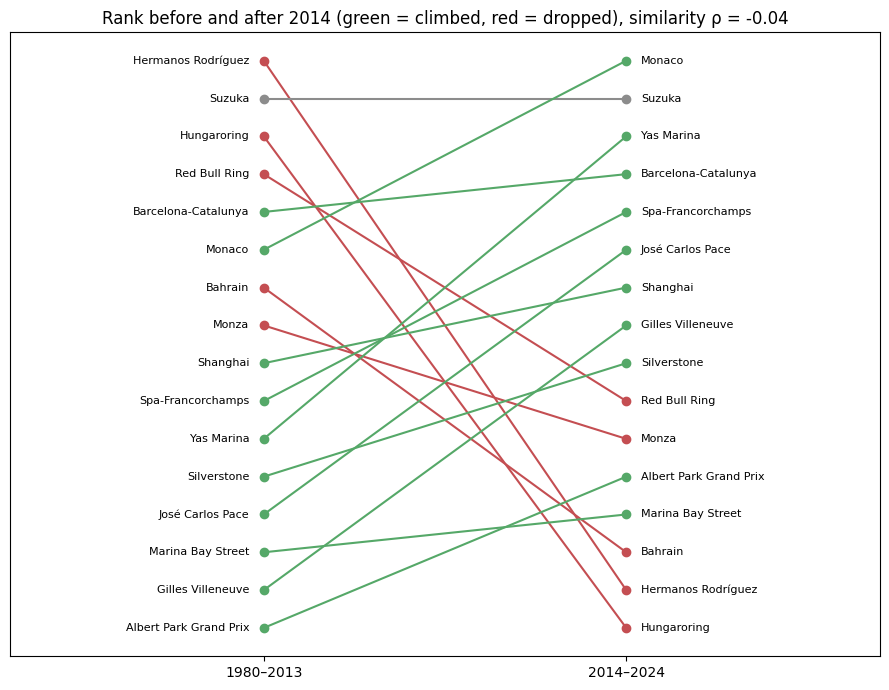

**Reading:** the two rankings look very different. The similarity score is **ρ = -0.04**, close to 0.
Biggest climbers: Yas Marina (11→3), Gilles Villeneuve (15→8), José Carlos Pace (13→6). Biggest fallers: Hermanos Rodríguez (1→15), Hungaroring (3→16), Bahrain (7→14).

In [205]:
def era_compare(k, ids):
    """Scores of the compared circuits in both periods, ranked among themselves."""
    t = circuit_table(fr, min_n=1, k_values=[k])
    w = t[t.circuitId.isin(ids)].pivot(index="circuitId", columns="era", values=f"score_k{k}")[ERAS]
    w["rank before"] = w[ERA_PRE].rank(ascending=False, method="min").astype(int)
    w["rank after"] = w[ERA_POST].rank(ascending=False, method="min").astype(int)
    w["change"] = w["rank before"] - w["rank after"]          # positive = climbed after 2014
    w["circuit"] = names.reindex(w.index).map(short)
    return w

w = era_compare(K_MAIN, comp_ids)
rho_main = stats.spearmanr(w[ERA_PRE], w[ERA_POST])[0]

s = w.assign(y0=w[ERA_PRE].rank(ascending=False, method="first"),      # tie-free positions so labels do not overlap
             y1=w[ERA_POST].rank(ascending=False, method="first")).sort_values("y0")
fig, ax = plt.subplots(figsize=(9, 7))
for name, r0, r1 in zip(s.circuit, s.y0, s.y1):
    col = "#55A868" if r1 < r0 else ("#C44E52" if r1 > r0 else GREY)
    ax.plot([0, 1], [r0, r1], color=col, marker="o")
    ax.text(-0.04, r0, name, ha="right", va="center", fontsize=8)
    ax.text(1.04, r1, name, ha="left", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xticks([0, 1]); ax.set_xticklabels(ERAS); ax.set_xlim(-0.7, 1.7)
ax.set_yticks([]); ax.grid(False)
ax.set_title(f"Rank before and after 2014 (green = climbed, red = dropped), similarity ρ = {rho_main:.2f}")
plt.tight_layout(); savefig("q1_04_before_after_ranks"); plt.show()

up, down = w.sort_values("change", ascending=False).head(3), w.sort_values("change").head(3)
fmt_moves = lambda d: ", ".join(f"{c} ({a}→{b})" for c, a, b in zip(d.circuit, d["rank before"], d["rank after"]))
md(f"""**Reading:** the two rankings look very different. The similarity score is **ρ = {rho_main:.2f}**, close to 0.
Biggest climbers: {fmt_moves(up)}. Biggest fallers: {fmt_moves(down)}.""")

#### 3.3 Could this change be luck?

**The idea, with a coin.** Flip a normal coin 10 times and you may get 7 heads; flip it again and you may get 4. The coin did not change: with only 10 flips, luck moves the result a lot. Our circuits are like that coin: each has only about 10 races per period. So a circuit can move up or down the ranking **even if nothing about it changed**.

**The experiment.** We build a **pretend world where no circuit changed** after 2014 and let the computer play it many times:
1. **Each circuit gets one fixed quality**: its score before and after 2014 averaged together (weighted by front-row starts). In the pretend world the circuit is exactly this good in both periods.
2. **The chance of a podium** in each period = the normal rate for that period's seasons, plus the circuit's fixed quality.
3. **The computer "flips a coin"** for every front-row start, with that chance, using the real number of front-row starts per circuit and period.
4. It **scores and ranks** the pretend results exactly like the real ones and computes the similarity score ρ.
5. Steps 3–4 are **repeated 2,000 times**.

This gives 2,000 similarity scores from a world where nothing changed. If our real ρ is lower than almost all of them (fewer than 5%), luck cannot explain the change. If it is lower than many of them, luck can.

**One circuit, step by step:** Hungaroring, with its real numbers and five pretend runs.

In [206]:
def logit(p):
    return np.log(p / (1 - p))

def expit(x):
    return 1 / (1 + np.exp(-x))

def no_change_chances(ids, k):
    """Each circuit's podium chance per period in the pretend world (same quality in both periods)."""
    t = circuit_table(fr, min_n=1, k_values=[k])
    t = t[t.circuitId.isin(ids)].copy()
    t["gap"] = logit(t.expected + t[f"score_k{k}"]) - logit(t.expected)     # quality in each period (odds scale)
    quality = (t.gap * t.starts).groupby(t.circuitId).sum() / t.starts.groupby(t.circuitId).sum()
    t["chance"] = expit(logit(t.expected) + t.circuitId.map(quality))         # same quality in both periods
    return t

hung = no_change_chances(comp_ids, K_MAIN)
hung = hung[hung.circuit == "Hungaroring"].set_index("era").loc[ERAS]
rng = np.random.default_rng(SEED)
fake = {e: rng.binomial(hung.loc[e, "starts"], hung.loc[e, "chance"], size=5) for e in ERAS}
table(pd.DataFrame({
    "period": ERAS, "front-row starts": hung.starts.values, "real podiums": hung.podiums.values,
    "normal for its years": hung.expected.values,
    "real: points vs normal": (hung["raw rate"] - hung.expected).values * 100,
    "pretend world: podium chance": hung.chance.values,
    "five pretend runs (podiums)": [", ".join(str(x) for x in fake[e]) for e in ERAS],
}), pct=["normal for its years", "pretend world: podium chance"], dec1=["real: points vs normal"],
    caption="Hungaroring: real result and the pretend world where it did not change")

period,front-row starts,real podiums,normal for its years,real: points vs normal,pretend world: podium chance,five pretend runs (podiums)
1980–2013,56,38,63%,4.4,62%,"32, 36, 31, 33, 40"
2014–2024,22,13,76%,-17.1,75%,"12, 15, 15, 19, 17"


In [207]:
pre_h, post_h = hung.loc[ERA_PRE], hung.loc[ERA_POST]
pick = int(np.argmax(fake[ERA_PRE] / pre_h.starts - fake[ERA_POST] / post_h.starts))   # the run that looks most like a drop
md(f"""**Reading:** in reality Hungaroring did {(pre_h['raw rate'] - pre_h.expected) * 100:+.0f} points vs normal before 2014
and {(post_h['raw rate'] - post_h.expected) * 100:+.0f} after, so it looks like it got worse. In the pretend world it is
exactly as good in both periods: about normal ({pre_h.chance:.0%} before, {post_h.chance:.0%} after, the normal rate of each
period). Still, one pretend run gives {fake[ERA_PRE][pick]} podiums out of {pre_h.starts} before
({(fake[ERA_PRE][pick] / pre_h.starts - pre_h.expected) * 100:+.0f} points vs normal) and {fake[ERA_POST][pick]} out of
{post_h.starts} after ({(fake[ERA_POST][pick] / post_h.starts - post_h.expected) * 100:+.0f} points): a circuit that did not
change can look as if it did, just by luck.""")

**Reading:** in reality Hungaroring did +4 points vs normal before 2014
and -17 after, so it looks like it got worse. In the pretend world it is
exactly as good in both periods: about normal (62% before, 75% after, the normal rate of each
period). Still, one pretend run gives 32 podiums out of 56 before
(-6 points vs normal) and 12 out of
22 after (-22 points): a circuit that did not
change can look as if it did, just by luck.

**All circuits, 2,000 times.** The computer does the same for all compared circuits at once and records the similarity score of each pretend world. We run it with every choice from 2.5 (5, 10 and 20 pretend starts; minimum 6, 10 and 14), so the answer does not depend on them.

**Limitation:** the coin flips treat the two front-row cars of a race as independent, although teammates often share the front row. The real spread of luck is therefore slightly wider, which would make a change even easier to explain by luck.

pretend starts,minimum front-row starts,circuits compared,real ρ,typical ρ in the pretend world,share of pretend worlds as shuffled as reality
5,10,16,-0.06,0.15,21%
10,10,16,-0.04,0.12,29%
20,10,16,-0.06,0.09,31%
10,6,21,-0.11,0.11,17%
10,14,14,-0.10,0.11,23%


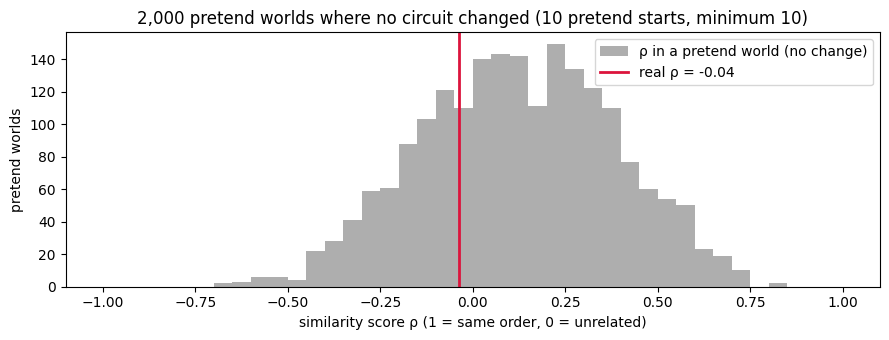

In [208]:
def spearman_rows(a, b):
    """Spearman ρ between matching rows of two (simulations × circuits) arrays."""
    ra, rb = stats.rankdata(a, axis=1), stats.rankdata(b, axis=1)
    ra, rb = ra - ra.mean(axis=1, keepdims=True), rb - rb.mean(axis=1, keepdims=True)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))

def no_change_rho(ids, k, B=N_RESAMPLES, seed=SEED):
    """Similarity score ρ in B pretend worlds where no circuit changed."""
    rng = np.random.default_rng(seed)
    t = no_change_chances(ids, k)
    sim = {}
    for e in ERAS:
        te = t[t.era == e].set_index("circuitId").loc[ids]
        pods = rng.binomial(te.starts.values, te.chance.values, size=(B, len(ids)))               # the coin flips
        sim[e] = bayes_avg(pods, te.starts.values, te.expected.values, k) - te.expected.values   # scored like the real data
    return spearman_rows(sim[ERA_PRE], sim[ERA_POST])

versions = [(k, MIN_N) for k in K_VALUES] + [(K_MAIN, m) for m in MIN_N_VALUES if m != MIN_N]
luck_rows = []
for k, m in versions:
    ids = compared_ids(m)
    wk = era_compare(k, ids)
    rho = stats.spearmanr(wk[ERA_PRE], wk[ERA_POST])[0]
    null = no_change_rho(ids, k)
    if (k, m) == (K_MAIN, MIN_N):
        null_main = null
    luck_rows.append({"pretend starts": k, "minimum front-row starts": m, "circuits compared": len(ids),
                      "real ρ": rho, "typical ρ in the pretend world": np.median(null),
                      "share of pretend worlds as shuffled as reality": np.mean(null <= rho)})
luck = pd.DataFrame(luck_rows)
table(luck, dec2=["real ρ", "typical ρ in the pretend world"], pct=["share of pretend worlds as shuffled as reality"],
      caption="How often does a world with no change look as shuffled as reality?")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(null_main, bins=np.linspace(-1, 1, 41), color=GREY, alpha=0.7, label="ρ in a pretend world (no change)")
ax.axvline(rho_main, color="crimson", lw=2, label=f"real ρ = {rho_main:.2f}")
ax.set(xlabel="similarity score ρ (1 = same order, 0 = unrelated)", ylabel="pretend worlds",
       title=f"{N_RESAMPLES:,} pretend worlds where no circuit changed ({K_MAIN} pretend starts, minimum {MIN_N})")
ax.legend(); plt.tight_layout(); savefig("q1_05_luck_test"); plt.show()

**How to read the histogram:** the grey bars are the similarity scores of pretend worlds where nothing changed. The red line is reality. If the red line were far to the left of almost all grey bars, luck could not explain the change. If it sits among them, luck can.

#### 3.4 Part 3 answer

In [209]:
main = luck[(luck["pretend starts"] == K_MAIN) & (luck["minimum front-row starts"] == MIN_N)].iloc[0]
share = main["share of pretend worlds as shuffled as reality"]
lo, hi = luck["share of pretend worlds as shuffled as reality"].min(), luck["share of pretend worlds as shuffled as reality"].max()
if share < 0.05:
    verdict = (f"**Yes.** Only {share:.0%} of the pretend worlds where nothing changed are as shuffled as reality, "
               "so luck alone is very unlikely to explain the change.")
else:
    verdict = (f"**On the numbers the ranking changed a lot, but this change could easily happen by luck.** "
               f"In {share:.0%} of the pretend worlds where no circuit changed, the ranking shuffled as much as in "
               f"reality or more (between {lo:.0%} and {hi:.0%} across all our choices). This experiment shows that "
               "the change can be explained by luck; it does not prove that nothing changed. The pretend world is an "
               "assumption we built to compare against, and with about 10 races per circuit and period the data is "
               "simply too small to show a real change.")
md(f"**Part 3 answer ({len(comp_ids)} circuits compared):** {verdict}")

**Part 3 answer (16 circuits compared):** **On the numbers the ranking changed a lot, but this change could easily happen by luck.** In 29% of the pretend worlds where no circuit changed, the ranking shuffled as much as in reality or more (between 17% and 31% across all our choices). This experiment shows that the change can be explained by luck; it does not prove that nothing changed. The pretend world is an assumption we built to compare against, and with about 10 races per circuit and period the data is simply too small to show a real change.

### Summary and limitations

In [210]:
best = {e: ", ".join(f"{c}{' ✓' if cid in robust_ids[e] else ''}" for cid, c in
                     zip(top_group(ct[ct.era == e]).circuitId, top_group(ct[ct.era == e]).circuit)) or "none"
        for e in ERAS}
table(pd.DataFrame([
    {"part": "1. Qualifying or grid?",
     "answer": f"Grid. Drivers pushed back from a front-row qualifying position reached the podium only "
               f"{pushed['podium rate']:.0%} of the time, against {kept['podium rate']:.0%} for those who kept their slot."},
    {"part": f"2. Best circuits {ERA_PRE}", "answer": best[ERA_PRE]},
    {"part": f"2. Best circuits {ERA_POST}", "answer": best[ERA_POST]},
    {"part": "3. Did the ranking change after 2014?",
     "answer": ("Yes, more than luck explains" if share < 0.05 else
                f"It looks very different (ρ = {rho_main:.2f}), but a world with no change looks this shuffled "
                f"{share:.0%} of the time, so it could easily be luck")},
]), caption="Q1 answers (✓ = in the top group under every choice we tried)")

part,answer
1. Qualifying or grid?,"Grid. Drivers pushed back from a front-row qualifying position reached the podium only 31% of the time, against 73% for those who kept their slot."
2. Best circuits 1980–2013,"Circuit de Nevers Magny-Cours ✓, Circuit Paul Ricard ✓, Autódromo Hermanos Rodríguez ✓"
2. Best circuits 2014–2024,"Circuit de Monaco ✓, Suzuka Circuit ✓, Yas Marina Circuit ✓, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps"
3. Did the ranking change after 2014?,"It looks very different (ρ = -0.04), but a world with no change looks this shuffled 29% of the time, so it could easily be luck"


**Limitations:**
- **Teams are mixed into circuit results.** A circuit's rate partly reflects which team held its front row (for example Mercedes 2014–2020, Red Bull 2022–2023). The normal rate removes what was normal in each season, not which team was strong.
- **The periods are unequal:** 34 seasons before 2014 and 11 after, so rates before 2014 are more precise.
- **The two front-row cars are not independent.** Teammates often share the front row, so the error bars and the luck test are slightly too narrow.
- **Layout changes are not separated.** A circuit keeps its `circuitId` when its layout changes (for example Yas Marina in 2021).
- **Sprint weekends (2021–2022)** set the grid with a sprint race. They are included, because the grid is still fixed before the main race.
- **Judgment calls:** the 1980 start (from F1 history, not checkable in Ergast), the 10 pretend starts and the minimum of 10 front-row starts. The last two are tested with other values in 2.5 and 3.3.
- **Descriptive only:** these are associations. Nothing here shows *why* a circuit converts more often.

## Q2: Do drivers podium more often at home, after controlling for starting position?

In plain words: **does racing at home help a driver reach the podium?** For example, does a British driver do better at Silverstone than at other circuits?

A start is a **home start** when the circuit is in the driver's country: Hamilton (British) at Silverstone is at home, Hamilton at Monza is away.

**"After controlling for starting position"** means we only compare drivers who started from the same place on the grid, because where a driver starts decides most of their chance of a podium.

**How we answer it, step by step:**
1. The simple comparison: home vs away podium rate.
2. Why it is misleading: home drivers start further back.
3. Home vs away from the same starting slot.
4. All slots combined into one number.
5. Each driver compared with themselves (the main result).
6. How big a home advantage could still be.
7. Checks with other choices.

**Grain:** one driver entering one race. **Pre-race cutoff:** the starting position and the home flag are both known before the race; the podium is the outcome we count. **Missingness:** drivers who never started have no starting position, so they are left out (1.2); no season, circuit country or nationality is missing (checked in 1.1).

### 0. Setup

Q2 reuses the helper functions from Q1 (`table`, `md`, `savefig`, `wilson`, `pct_range`) and its `LAST_SEASON`, `SEED` and `GREY`.

In [211]:
GRID_BINS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, np.inf]          # starting-slot groups (step 3)
GRID_LABELS = ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11–12", "P13–15", "P16–20", "P21+"]
SENS_STARTS = [1980, 2000, 2014]   # later first seasons tried in the checks (step 7)
N_BOOT = 1000                      # redraws of drivers for the ranges (also used by Q3)

HOME_COLOR, AWAY_COLOR = "#DD8452", "#4C72B0"
FIG_DIR = os.path.join("report", "figures", "q2")
os.makedirs(FIG_DIR, exist_ok=True)

def or_text(o, lo, hi):
    """Format an odds ratio with its range."""
    return f"{o:.2f} ({lo:.2f} – {hi:.2f})"

def verdict(lo, hi):
    """Plain-language reading of an odds-ratio range."""
    return "home advantage" if lo > 1 else ("home disadvantage" if hi < 1 else "no detectable difference")

### 1. The data

We start from `results_unique` (one row per driver per race) and join the season, the circuit's country and the driver's nationality. From the earlier sections:
- **Drivers who did not take the start** (`did_not_start`) are left out, because they had no starting position. Q2 describes what happened in races, so only the drivers who took the start count.
- **Pit-lane starters** raced, so they stay, with `grid_clean` placing them at the back of the field.
- **The Indianapolis 500** is left out, as decided in the races section: almost all its drivers never raced another Grand Prix, and it would fill the sample with American "home" starts. Step 7 shows what including it changes.
- **Shared cars (1950–1961):** where two drivers shared one car (one started it, the other took over during the race), both have the same grid slot and result. That result is two drivers' effort, not one driver's, so it cannot tell us how a single driver does at home or away. Both drivers of every shared car are left out.
- **Seasons:** all of 1950–2024, to keep as many home starts as possible. Step 7 checks later first seasons.

In [212]:
q2_base = (results_unique[["resultId", "raceId", "driverId", "constructorId", "grid", "grid_clean", "positionOrder",
                           "did_not_start", "is_indy500"]]
           .merge(races[["raceId", "year", "circuitId", "name"]].rename(columns={"name": "race_name"}),
                  on="raceId", how="left", validate="m:1")
           .merge(circuits[["circuitId", "country"]].rename(columns={"country": "circuit_country"}),
                  on="circuitId", how="left", validate="m:1")
           .merge(drivers[["driverId", "forename", "surname", "nationality"]].rename(columns={"nationality": "driver_nationality"}),
                  on="driverId", how="left", validate="m:1"))
q2_base = q2_base[q2_base.year <= LAST_SEASON].copy()
q2_base["podium"] = (q2_base.positionOrder <= 3).astype(int)
q2_base["driver"] = q2_base.forename + " " + q2_base.surname
assert q2_base[["year", "circuit_country", "driver_nationality"]].notna().all().all()

#### 1.1 Which starts are home starts?

Circuits store a **country** (`UK`) and drivers a **nationality** (`British`), so the two cannot be matched directly. The cleaning section (*circuits and drivers: countries and nationalities*) already made the spellings consistent (`United States` → `USA`, `Argentinian ` → `Argentine`) and set the rules used here:
1. **Every nationality is mapped explicitly** to its country; anything without a mapping is shown, not silently dropped.
2. **Two nationalities mean two home countries:** `American-Italian` drivers are at home in the USA and in Italy. This affects only 2 starts, and step 7 shows it changes nothing.
3. **Countries that no longer exist** (`East German`, `Rhodesian`) are never at home.

In [213]:
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China",
    "Colombian": "Colombia", "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands",
    "Finnish": "Finland", "French": "France", "German": "Germany",
    "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia",
    "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan", "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal", "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
DUAL_HOME = {"American-Italian": ["USA", "Italy"], "Argentine-Italian": ["Argentina", "Italy"]}   # rule 2
NOT_HOME = ["East German", "Rhodesian"]                                                          # rule 3

present = set(q2_base.driver_nationality)
unmapped = sorted(present - set(NATIONALITY_TO_COUNTRY) - set(DUAL_HOME) - set(NOT_HOME))
home_countries = set(NATIONALITY_TO_COUNTRY.values()) | {c for cs in DUAL_HOME.values() for c in cs}
table(pd.DataFrame([
    {"check": "missing values in season, circuit country and nationality (should be 0)",
     "result": str(q2_base[["year", "circuit_country", "driver_nationality"]].isna().sum().sum())},
    {"check": "nationalities without a mapping (should be none)", "result": ", ".join(unmapped) or "none"},
    {"check": "two nationalities, at home in both countries", "result": ", ".join(n for n in DUAL_HOME if n in present) or "none"},
    {"check": "countries that no longer exist, never at home", "result": ", ".join(n for n in NOT_HOME if n in present) or "none"},
    {"check": "host countries with no driver of that nationality (no home race possible)",
     "result": ", ".join(sorted(set(q2_base.circuit_country) - home_countries)) or "none"},
]), caption="Nationality-to-country map: checks")

single = q2_base.driver_nationality.map(NATIONALITY_TO_COUNTRY) == q2_base.circuit_country
dual = [isinstance(h, list) and c in h for h, c in zip(q2_base.driver_nationality.map(DUAL_HOME), q2_base.circuit_country)]
q2_base["home"] = (single | np.array(dual)).astype(int)    # the home flag used everywhere in Q2
q2_base["home_without_dual"] = single.astype(int)          # rule 2 switched off: only for the check in step 7

check,result
"missing values in season, circuit country and nationality (should be 0)",0
nationalities without a mapping (should be none),none
"two nationalities, at home in both countries","American-Italian, Argentine-Italian"
"countries that no longer exist, never at home","East German, Rhodesian"
host countries with no driver of that nationality (no home race possible),"Azerbaijan, Bahrain, Korea, Morocco, Qatar, Saudi Arabia, Singapore, Turkey, UAE"


#### 1.2 The sample

In [214]:
SHARED_CAR = ["raceId", "positionOrder", "constructorId"]   # one car's finishing place in one race

def shared_car_rows(d):
    """Index of every driver of a shared car: two or more drivers credited with one car's finishing place."""
    return d.index[d.duplicated(SHARED_CAR, keep=False)]

def q2_frame(df, include_indy=False, year_from=None):
    """The Q2 sample: drivers who started, Indy 500 optional, optional later first season, no shared cars."""
    d = df[~df.did_not_start]
    if not include_indy:
        d = d[~d.is_indy500]
    if year_from:
        d = d[d.year >= year_from]
    d = d.drop(index=shared_car_rows(d)).copy()              # both drivers of every shared car
    d["grid"] = d.grid_clean                                     # pit-lane starters at the back of the field
    d["grid_slot"] = pd.cut(d.grid, GRID_BINS, labels=GRID_LABELS)
    d["decade"] = (d.year // 10 * 10).astype(int)
    return d

q2 = q2_frame(q2_base)
steps = [("all driver–race entries 1950–2024", q2_base),
         ("minus drivers who did not take the start", q2_base[~q2_base.did_not_start]),
         ("minus the Indianapolis 500", q2_base[~q2_base.did_not_start & ~q2_base.is_indy500]),
         ("minus both drivers of every shared car (the Q2 sample)", q2)]
table(pd.DataFrame([{"step": s, "starts": len(d), "home starts": int(d.home.sum()),
                     "share at home": d.home.mean()} for s, d in steps]),
      pct=["share at home"], caption="Building the Q2 sample")

step,starts,home starts,share at home
all driver–race entries 1950–2024,26668,2488,9%
minus drivers who did not take the start,24958,2305,9%
minus the Indianapolis 500,24577,1925,8%
minus both drivers of every shared car (the Q2 sample),24448,1887,8%


### Step 1: The simple comparison

In [215]:
raw_cmp = (q2.groupby("home").agg(starts=("podium", "size"), podiums=("podium", "sum"),
                                  **{"average starting slot": ("grid", "mean")})
             .rename(index={0: "away", 1: "home"}).reset_index().rename(columns={"home": "where"}))
raw_cmp["podium rate"] = raw_cmp.podiums / raw_cmp.starts
table(raw_cmp, pct1=["podium rate"], dec1=["average starting slot"], caption="Home vs away, no control")
raw_home, raw_away = raw_cmp.set_index("where").loc["home"], raw_cmp.set_index("where").loc["away"]
md(f"""**Reading:** home drivers reach the podium **{'less' if raw_home['podium rate'] < raw_away['podium rate'] else 'more'}**
often ({raw_home['podium rate']:.1%} vs {raw_away['podium rate']:.1%}). But they also start further back on average
(slot {raw_home['average starting slot']:.1f} vs {raw_away['average starting slot']:.1f}). Step 2 shows why that matters.""")

where,starts,podiums,average starting slot,podium rate
away,22561,3106,11.7,13.8%
home,1887,220,12.7,11.7%


**Reading:** home drivers reach the podium **less**
often (11.7% vs 13.8%). But they also start further back on average
(slot 12.7 vs 11.7). Step 2 shows why that matters.

### Step 2: Why the simple comparison is misleading

**Left:** the podium rate from each starting slot, for all drivers. **Right:** where home and away drivers start.

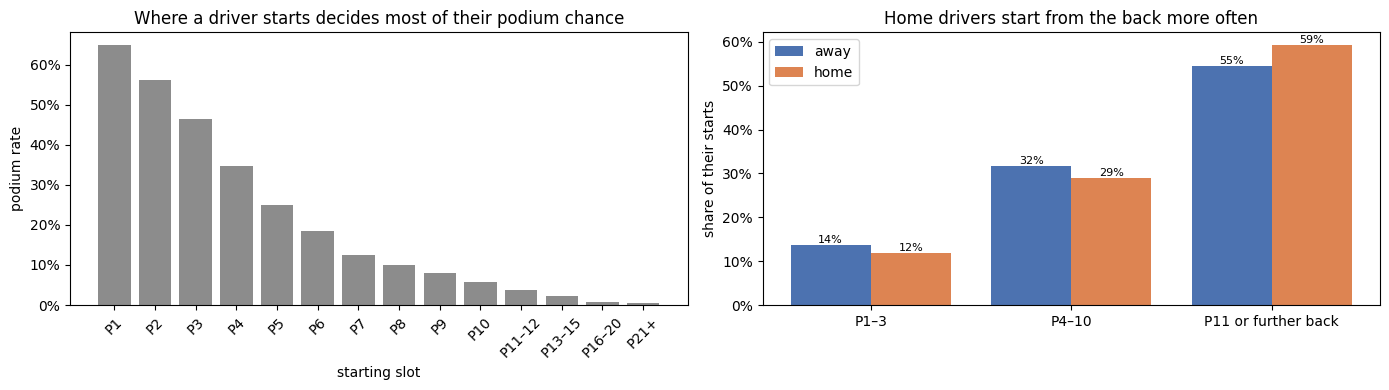

**Reading:** a P1 starter reaches the podium 65% of the time, a P10 starter 6%.
Home drivers start from P1–3 in 12% of their starts, away drivers in 14%, and
home drivers start from P11 or further back more often. So the simple comparison mixes **being at home** with
**starting further back**. One reason: in the early decades many local drivers in slow cars entered only their home
Grand Prix. To be fair, we only compare drivers who started from the same place.

In [216]:
BANDS = ["P1–3", "P4–10", "P11 or further back"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

rate_by_slot = q2.groupby("grid_slot", observed=True).podium.mean().reindex(GRID_LABELS)
axes[0].bar(GRID_LABELS, rate_by_slot.values, color=GREY)
axes[0].set(title="Where a driver starts decides most of their podium chance", xlabel="starting slot",
            ylabel="podium rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].tick_params(axis="x", rotation=45)

bands = pd.cut(q2.grid, [0, 3, 10, np.inf], labels=BANDS)
share = pd.crosstab(q2.home, bands, normalize="index").rename(index={0: "away", 1: "home"})
x = np.arange(len(BANDS))
for off, where, col in [(-0.2, "away", AWAY_COLOR), (0.2, "home", HOME_COLOR)]:
    bars = axes[1].bar(x + off, share.loc[where].values, width=0.4, color=col, label=where)
    axes[1].bar_label(bars, labels=[f"{v:.0%}" for v in share.loc[where].values], fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(BANDS)
axes[1].set(title="Home drivers start from the back more often", ylabel="share of their starts")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
plt.tight_layout(); savefig("q2_01_why_control"); plt.show()

md(f"""**Reading:** a P1 starter reaches the podium {rate_by_slot['P1']:.0%} of the time, a P10 starter {rate_by_slot['P10']:.0%}.
Home drivers start from P1–3 in {share.loc['home', 'P1–3']:.0%} of their starts, away drivers in {share.loc['away', 'P1–3']:.0%}, and
home drivers start from P11 or further back more often. So the simple comparison mixes **being at home** with
**starting further back**. One reason: in the early decades many local drivers in slow cars entered only their home
Grand Prix. To be fair, we only compare drivers who started from the same place.""")

### Step 3: Home vs away from the same starting slot

For each starting slot, the podium rate of home starters and of away starters. Slots behind P10 are grouped, because podiums from there are very rare. The error bar is the range the true rate is probably in (95% Wilson range): wide when there are few starts.

starting slot,away starts,away podium rate,home starts,home podium rate,better
P1,1022,65%,79,61%,away
P2,1030,56%,75,56%,same
P3,1036,46%,70,53%,home
P4,1039,35%,71,38%,home
P5,1031,24%,70,33%,home
P6,1021,19%,79,11%,away
P7,1026,12%,75,13%,home
P8,1023,10%,76,7%,away
P9,1015,8%,94,9%,home
P10,1012,6%,81,0%,away


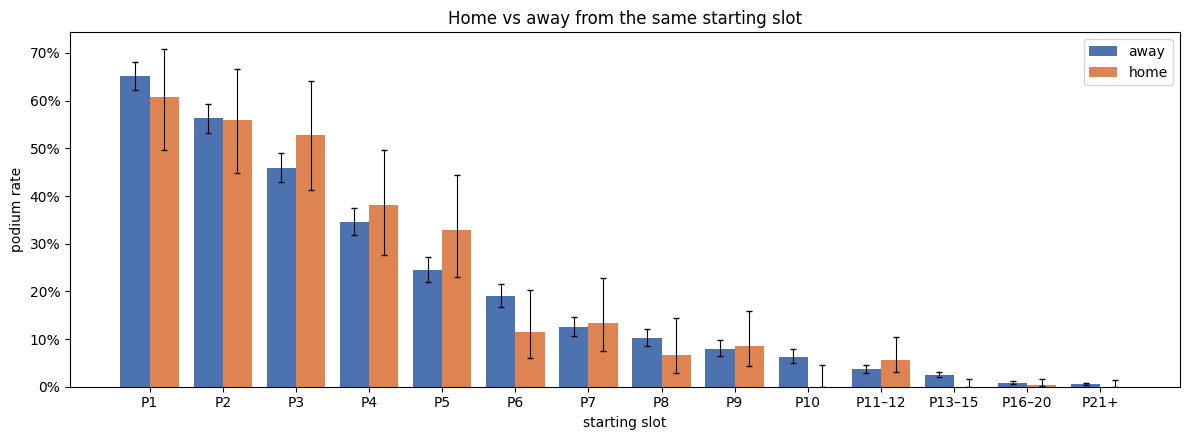

**Reading:** in P1–P10, home is better in 5 slots, away in 4
and they are equal in 1. There is no clear pattern: if being at home helped, home would be better
in almost every slot. Each slot also has only about 75 home starts, so the home bars move a
lot by luck (wide error bars). Step 4 combines all slots into one number.

In [217]:
strat = (q2.groupby(["grid_slot", "home"], observed=True)
           .agg(n=("podium", "size"), podiums=("podium", "sum")).reset_index())
strat["rate"] = strat.podiums / strat.n
strat["ci_lo"], strat["ci_hi"] = wilson(strat.podiums, strat.n)
home_s = strat[strat.home == 1].set_index("grid_slot").reindex(GRID_LABELS)
away_s = strat[strat.home == 0].set_index("grid_slot").reindex(GRID_LABELS)

slot_table = pd.DataFrame({"starting slot": GRID_LABELS,
                           "away starts": away_s.n.astype(int).values, "away podium rate": away_s.rate.values,
                           "home starts": home_s.n.astype(int).values, "home podium rate": home_s.rate.values})
home_pct, away_pct = (slot_table["home podium rate"] * 100).round(), (slot_table["away podium rate"] * 100).round()
slot_table["better"] = np.select([home_pct > away_pct, home_pct < away_pct], ["home", "away"], default="same")   # whole percent
table(slot_table.head(10), pct=["away podium rate", "home podium rate"], caption="Home vs away from the same slot (P1–P10)")

fig, ax = plt.subplots(figsize=(12, 4.5))
xs = np.arange(len(GRID_LABELS))
for off, s, col, lab in [(-0.2, away_s, AWAY_COLOR, "away"), (0.2, home_s, HOME_COLOR, "home")]:
    ax.bar(xs + off, s.rate, width=0.4, color=col, label=lab,
           yerr=[s.rate - s.ci_lo, s.ci_hi - s.rate], capsize=2, error_kw={"lw": 0.8})
ax.set_xticks(xs); ax.set_xticklabels(GRID_LABELS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(ylabel="podium rate", xlabel="starting slot", title="Home vs away from the same starting slot")
ax.legend(); plt.tight_layout(); savefig("q2_02_by_slot"); plt.show()

top10 = slot_table.head(10)
md(f"""**Reading:** in P1–P10, home is better in {(top10.better == 'home').sum()} slots, away in {(top10.better == 'away').sum()}
and they are equal in {(top10.better == 'same').sum()}. There is no clear pattern: if being at home helped, home would be better
in almost every slot. Each slot also has only about {int(top10['home starts'].median())} home starts, so the home bars move a
lot by luck (wide error bars). Step 4 combines all slots into one number.""")

### Step 4: All slots combined into one number

**How:**
1. Split all starts into groups of the **same starting slot in the same decade**, for example "P3 starters in the 1990s". The decade matters for the same reason as in Q1: in the 1950s cars broke down constantly and a P8 starter often reached the podium by surviving, which rarely happens today.
2. **Inside each group**, compare home with away.
3. **Combine all groups into one number.** Bigger groups count more, and groups where nobody (or everybody) reached the podium carry no information. This standard method is called Mantel–Haenszel.

**The number is an odds ratio:**
- **1** = home and away are the same;
- **above 1** = home is better (1.20 means about 20% better odds of a podium);
- **below 1** = home is worse.

**Its range:** the same driver appears in many starts, with the same skill and often the same car, so their starts are not independent. The range is therefore found by redrawing whole drivers 1,000 times (each time some drivers are drawn twice and some not at all) and keeping the middle 95% of the results. **If the range includes 1, the data cannot tell home and away apart.**

In [218]:
def stratum_counts(d, strata):
    """The four counts for every group: a = home podium, b = home no podium, c = away podium, dd = away no podium."""
    t = d.assign(a=d.home * d.podium, b=d.home * (1 - d.podium),
                 c=(1 - d.home) * d.podium, dd=(1 - d.home) * (1 - d.podium))
    return t.groupby(strata, observed=True)[["a", "b", "c", "dd"]].sum().reset_index()

def mh_or(a, b, c, d):
    """Mantel–Haenszel odds ratio over the last axis (works for one table or many redraws at once)."""
    a, b, c, d = (np.asarray(x, dtype=float) for x in (a, b, c, d))
    n = a + b + c + d
    n = np.where(n == 0, np.nan, n)
    with np.errstate(divide="ignore", invalid="ignore"):     # a redraw with no informative group gives inf/nan
        return np.nansum(a * d / n, axis=-1) / np.nansum(b * c / n, axis=-1)

def driver_resample_range(d, strata, B=N_BOOT, seed=SEED):
    """95% range of the odds ratio when whole drivers (with all their starts) are redrawn B times."""
    rng = np.random.default_rng(seed)
    cnt = stratum_counts(d, ["driverId"] + [s for s in strata if s != "driverId"])   # counts per driver and group
    cnt["group"] = cnt.groupby(strata, observed=True).ngroup()
    ids = pd.Index(cnt.driverId.unique())
    rows, cols = ids.get_indexer(cnt.driverId), cnt.group.values
    mats = []
    for x in ["a", "b", "c", "dd"]:                           # drivers × groups matrix for each count
        m = np.zeros((len(ids), cols.max() + 1))
        np.add.at(m, (rows, cols), cnt[x].values)
        mats.append(m)
    draws = rng.multinomial(len(ids), np.full(len(ids), 1 / len(ids)), size=B)   # times each driver is drawn
    sims = mh_or(*(draws @ m for m in mats))
    return np.nanpercentile(sims, [2.5, 97.5])

def informative_home_starts(cnt):
    """Home starts in groups that have a home and an away start and at least one podium and one non-podium."""
    keep = (cnt.a + cnt.b > 0) & (cnt.c + cnt.dd > 0) & (cnt.a + cnt.c > 0) & (cnt.b + cnt.dd > 0)
    return int((cnt.a + cnt.b)[keep].sum())

def home_effect(d, strata, B=N_BOOT, seed=SEED):
    """Odds ratio, its range (drivers redrawn) and the home starts that carry information."""
    cnt = stratum_counts(d, strata)
    lo, hi = driver_resample_range(d, strata, B=B, seed=seed)
    return {"or": float(mh_or(cnt.a, cnt.b, cnt.c, cnt.dd)), "lo": lo, "hi": hi, "home used": informative_home_starts(cnt)}

between = home_effect(q2, ["grid_slot", "decade"])
md(f"""**Result:** home vs away, same slot and decade: odds ratio **{between['or']:.2f}**, range {between['lo']:.2f} to {between['hi']:.2f}.
The range includes 1, so: **{verdict(between['lo'], between['hi'])}**.""")

**Result:** home vs away, same slot and decade: odds ratio **0.92**, range 0.73 to 1.13.
The range includes 1, so: **no detectable difference**.

### Step 5: Each driver compared with themselves (the main result)

**The hidden unfairness in step 4:** even inside "P3 starters in the 1990s", the home group and the away group can be **different kinds of drivers**. In the early decades many home starts came from local drivers who entered only their home Grand Prix, often in old cars. The table shows how many.

In [219]:
per_driver = (q2.groupby(["driverId", "driver", "driver_nationality", "home"])
                .agg(starts=("podium", "size"), rate=("podium", "mean"), grid=("grid", "mean"))
                .unstack("home"))
per_driver.columns = [f"{a}_{'home' if b else 'away'}" for a, b in per_driver.columns]
per_driver = per_driver.reset_index().fillna({"starts_home": 0, "starts_away": 0})
per_driver["type"] = np.select([(per_driver.starts_home > 0) & (per_driver.starts_away > 0), per_driver.starts_home > 0],
                               ["raced at home and away", "only ever raced at home"], default="never raced at home")
who = (q2.merge(per_driver[["driverId", "type"]], on="driverId")
         .groupby("type").agg(drivers=("driverId", "nunique"), starts=("podium", "size"),
                              **{"home starts": ("home", "sum"), "podium rate": ("podium", "mean"),
                                 "average starting slot": ("grid", "mean")})
         .reindex(["raced at home and away", "only ever raced at home", "never raced at home"], fill_value=0)
         .rename_axis("type").reset_index())
table(who, pct1=["podium rate"], dec1=["average starting slot"], caption="Three kinds of drivers")
only_home = who.set_index("type").loc["only ever raced at home"]
md(f"""**Reading:** **{int(only_home['home starts']):,}** home starts ({only_home['home starts'] / q2.home.sum():.0%} of all home starts)
come from drivers who **never raced anywhere else**. They reached the podium {only_home['podium rate']:.1%} of the time and
started on average from slot {only_home['average starting slot']:.0f}.""")

type,drivers,starts,home starts,podium rate,average starting slot
raced at home and away,388,20172,1743,14.3%,11.5
only ever raced at home,106,144,144,0.0%,19.0
never raced at home,183,4132,0,10.9%,12.8


**Reading:** **144** home starts (8% of all home starts)
come from drivers who **never raced anywhere else**. They reached the podium 0.0% of the time and
started on average from slot 19.

**The fix:** compare **each driver with themselves**: their home starts against their own away starts, from the **same slot in the same decade**. For example, *Alonso starting P3 in Spain* against *Alonso starting P3 elsewhere*. Same driver, so the only difference is home or away. Drivers who only raced at home drop out automatically, because they have nothing to compare with.

It is the same calculation as step 4, but a group is now **one driver, from one slot, in one decade**. The table shows the drivers with the most home starts (raw numbers, not yet matched by slot): some do better at home, some worse.

In [220]:
top = per_driver.sort_values("starts_home", ascending=False).head(10)
table(pd.DataFrame({"driver": top.driver, "nationality": top.driver_nationality,
                    "home starts": top.starts_home.astype(int), "home podium rate": top.rate_home,
                    "away starts": top.starts_away.astype(int), "away podium rate": top.rate_away}),
      pct=["home podium rate", "away podium rate"], caption="Drivers with the most home starts (raw)")

WITHIN = ["driverId", "grid_slot", "decade"]     # main: same driver, same slot, same decade
within = home_effect(q2, WITHIN)

effects = pd.DataFrame([
    {"comparison": "Step 4: home vs other drivers, same slot and decade", "home starts used": between["home used"],
     "odds ratio": between["or"], "lo": between["lo"], "hi": between["hi"]},
    {"comparison": "Step 5: each driver vs themselves, same slot and decade (MAIN)", "home starts used": within["home used"],
     "odds ratio": within["or"], "lo": within["lo"], "hi": within["hi"]}])
table(effects.assign(**{"range": [f"{l:.2f} – {h:.2f}" for l, h in zip(effects.lo, effects.hi)],
                        "verdict": [verdict(l, h) for l, h in zip(effects.lo, effects.hi)]}).drop(columns=["lo", "hi"]),
      dec2=["odds ratio"], caption="Home effect on podium odds")

driver,nationality,home starts,home podium rate,away starts,away podium rate
Riccardo Patrese,Italian,29,14%,227,15%
Michael Schumacher,German,28,54%,279,50%
Andrea de Cesaris,Italian,27,0%,181,3%
Fernando Alonso,Spanish,26,35%,376,26%
Giancarlo Fisichella,Italian,24,4%,205,9%
Jarno Trulli,Italian,24,0%,228,5%
Michele Alboreto,Italian,23,17%,171,11%
Ralf Schumacher,German,20,15%,160,15%
Mario Andretti,American,19,16%,109,15%
Rubens Barrichello,Brazilian,19,5%,303,22%


comparison,home starts used,odds ratio,range,verdict
"Step 4: home vs other drivers, same slot and decade",1727,0.92,0.73 – 1.13,no detectable difference
"Step 5: each driver vs themselves, same slot and decade (MAIN)",558,1.00,0.77 – 1.27,no detectable difference


**How to read the figure:** the dot is the best guess, the line is the range, and the red line is **1 = no difference**. A line that crosses the red line means the data cannot tell home and away apart. Right of the red line would be a home advantage, left a home disadvantage.

"Home starts used" counts only the home starts that carry information: those in a group with a matching away start and at least one podium and one non-podium. Starts from the back of the grid (almost never a podium) drop out.

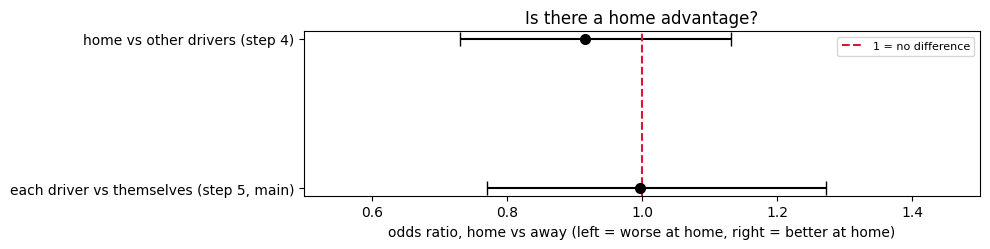

**Reading:** compared with themselves, drivers reach the podium about as often at home as away: odds ratio
**1.00**, range 0.77 to 1.27. The range includes 1: **no detectable difference**.

In [221]:
fig, ax = plt.subplots(figsize=(10, 2.6))
y = np.arange(len(effects))[::-1]
ax.errorbar(effects["odds ratio"], y, xerr=[effects["odds ratio"] - effects.lo, effects.hi - effects["odds ratio"]],
            fmt="o", color="black", capsize=5, ms=7)
ax.axvline(1, color="crimson", ls="--", lw=1.5, label="1 = no difference")
ax.set_yticks(y); ax.set_yticklabels(["home vs other drivers (step 4)", "each driver vs themselves (step 5, main)"])
ax.set(xlim=(0.5, 1.5), xlabel="odds ratio, home vs away (left = worse at home, right = better at home)",
       title="Is there a home advantage?")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); savefig("q2_03_home_effect"); plt.show()
md(f"""**Reading:** compared with themselves, drivers reach the podium about as often at home as away: odds ratio
**{within['or']:.2f}**, range {within['lo']:.2f} to {within['hi']:.2f}. The range includes 1: **{verdict(within['lo'], within['hi'])}**.""")

### Step 6: How big could a home advantage still be?

The best guess is "no difference", but the range goes up to its top value, the **largest home advantage the data still allows**. The table turns that value into podium chances: for a driver whose away podium chance from a slot is X%, what would it be at home?

In [222]:
def apply_or(p, o):
    """Podium chance after multiplying the odds of chance p by odds ratio o."""
    odds = p / (1 - p) * o
    return odds / (1 + odds)

away_rate = q2[q2.home == 0].groupby("grid_slot", observed=True).podium.mean()
show_slots = ["P1", "P2", "P3", "P5", "P8"]
rule = pd.DataFrame({"starting slot": show_slots, "away podium chance": away_rate.reindex(show_slots).values})
rule["home, best guess"] = apply_or(rule["away podium chance"], within["or"])
rule["home, largest advantage still possible"] = apply_or(rule["away podium chance"], within["hi"])
rule["largest possible gain (points)"] = (rule["home, largest advantage still possible"] - rule["away podium chance"]) * 100
table(rule, pct=["away podium chance", "home, best guess", "home, largest advantage still possible"],
      dec1=["largest possible gain (points)"], caption="What the main result means in podium chances")

best = rule.loc[rule["largest possible gain (points)"].idxmax()]
md(f"""**Reading:** even if there is a home advantage, it is **small**. In the most generous case the data allows, a
{best['starting slot']} starter would go from {best['away podium chance']:.0%} away to
{best['home, largest advantage still possible']:.0%} at home: at most about **{best['largest possible gain (points)']:.0f} percentage points**.
A large home advantage is ruled out.""")

starting slot,away podium chance,"home, best guess","home, largest advantage still possible",largest possible gain (points)
P1,65%,65%,70%,5.2
P2,56%,56%,62%,5.8
P3,46%,46%,52%,6.0
P5,24%,24%,29%,4.7
P8,10%,10%,13%,2.4


**Reading:** even if there is a home advantage, it is **small**. In the most generous case the data allows, a
P3 starter would go from 46% away to
52% at home: at most about **6 percentage points**.
A large home advantage is ruled out.

### Step 7: Checks with other choices

We repeat the main comparison (each driver vs themselves) with other choices:
- **including the Indianapolis 500**;
- **starting in 1980, 2000 or 2014** instead of 1950;
- **any decade:** the same driver and slot at any point in their career (requiring the same decade can split a career, for example 2008 and 2011);
- **two nationalities never at home:** rule 2 switched off.

The more versions we check, the more likely one of them looks unusual by chance, so a single different version is a hint, not a finding.

version,home starts,odds ratio (range),verdict
main (1950–2024),1887,1.00 (0.77 – 1.27),no detectable difference
including the Indianapolis 500,2212,1.00 (0.78 – 1.26),no detectable difference
from 1980,1043,0.96 (0.70 – 1.32),no detectable difference
from 2000,434,0.71 (0.33 – 1.19),no detectable difference
from 2014,144,0.90 (0.29 – 2.38),no detectable difference
any decade (same driver and slot),1887,1.00 (0.77 – 1.29),no detectable difference
two nationalities never at home,1885,1.00 (0.77 – 1.27),no detectable difference


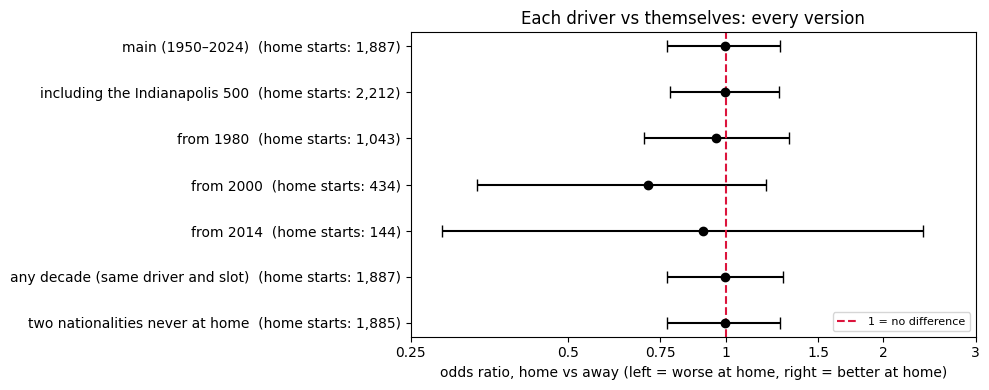

**Reading:** **no detectable difference** in 7 of 7 versions. With fewer seasons there are fewer home starts, so the ranges get wider, but every range still includes 1.

In [223]:
versions = {"main (1950–2024)": (q2, WITHIN),
            "including the Indianapolis 500": (q2_frame(q2_base, include_indy=True), WITHIN)}
for y in SENS_STARTS:
    versions[f"from {y}"] = (q2_frame(q2_base, year_from=y), WITHIN)
versions["any decade (same driver and slot)"] = (q2, ["driverId", "grid_slot"])
versions["two nationalities never at home"] = (q2.assign(home=q2.home_without_dual), WITHIN)

sens = pd.DataFrame([{"version": name, "home starts": int(d.home.sum()), **home_effect(d, strata)}
                     for name, (d, strata) in versions.items()])
sens["verdict"] = [verdict(l, h) for l, h in zip(sens.lo, sens.hi)]
table(pd.DataFrame({"version": sens.version, "home starts": sens["home starts"],
                    "odds ratio (range)": [or_text(o, l, h) for o, l, h in zip(sens["or"], sens.lo, sens.hi)],
                    "verdict": sens.verdict}), caption="Each driver vs themselves under every version")

fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(sens))[::-1]
ax.errorbar(sens["or"], y, xerr=[sens["or"] - sens.lo.clip(lower=0.2), sens.hi.clip(upper=3) - sens["or"]],
            fmt="o", color="black", capsize=4)
ax.axvline(1, color="crimson", ls="--", lw=1.5, label="1 = no difference")
ax.set_yticks(y); ax.set_yticklabels([f"{v}  (home starts: {n:,})" for v, n in zip(sens.version, sens["home starts"])])
ax.set_xscale("log")
ticks = [0.25, 0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(ticks); ax.set_xticklabels([f"{t:g}" for t in ticks]); ax.minorticks_off()
ax.set(xlabel="odds ratio, home vs away (left = worse at home, right = better at home)",
       title="Each driver vs themselves: every version")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); savefig("q2_04_checks"); plt.show()

counts = sens.verdict.value_counts()
md("**Reading:** " + ", ".join(f"**{v}** in {n} of {len(sens)} versions" for v, n in counts.items()) +
   ". With fewer seasons there are fewer home starts, so the ranges get wider, but every range still includes 1.")

### Answer and limitations

In [224]:
table(pd.DataFrame([
    {"step": "1. Simple comparison (no control)",
     "result": f"home {raw_home['podium rate']:.1%} vs away {raw_away['podium rate']:.1%}",
     "meaning": "misleading: home drivers start further back"},
    {"step": "4. Home vs other drivers, same slot and decade",
     "result": f"odds ratio {or_text(between['or'], between['lo'], between['hi'])}", "meaning": verdict(between["lo"], between["hi"])},
    {"step": "5. Each driver vs themselves (main)",
     "result": f"odds ratio {or_text(within['or'], within['lo'], within['hi'])}", "meaning": verdict(within["lo"], within["hi"])},
    {"step": "6. Largest home advantage still possible",
     "result": f"about {best['largest possible gain (points)']:.0f} points for a {best['starting slot']} starter", "meaning": "a large advantage is ruled out"},
    {"step": "7. Checks", "result": f"{int((sens.verdict == verdict(within['lo'], within['hi'])).sum())} of {len(sens)} versions agree",
     "meaning": "the answer does not depend on our choices"},
]), caption="Q2: from the simple comparison to the answer")

main_verdict = verdict(within["lo"], within["hi"])
if main_verdict == "no detectable difference":
    answer = (f"**No detectable home advantage.** Compared with themselves, from the same starting slot in the same decade, "
              f"drivers reach the podium about as often at home as elsewhere (odds ratio {or_text(within['or'], within['lo'], within['hi'])}). "
              f"Even if there is a home advantage, it is small: at most about {best['largest possible gain (points)']:.0f} "
              f"percentage points of podium chance for a {best['starting slot']} starter.")
else:
    answer = (f"**A {main_verdict}.** Compared with themselves, from the same starting slot in the same decade, drivers' podium "
              f"odds at home are {or_text(within['or'], within['lo'], within['hi'])} times their odds elsewhere.")
md("**Q2 answer:** " + answer)

step,result,meaning
1. Simple comparison (no control),home 11.7% vs away 13.8%,misleading: home drivers start further back
"4. Home vs other drivers, same slot and decade",odds ratio 0.92 (0.73 – 1.13),no detectable difference
5. Each driver vs themselves (main),odds ratio 1.00 (0.77 – 1.27),no detectable difference
6. Largest home advantage still possible,about 6 points for a P3 starter,a large advantage is ruled out
7. Checks,7 of 7 versions agree,the answer does not depend on our choices


**Q2 answer:** **No detectable home advantage.** Compared with themselves, from the same starting slot in the same decade, drivers reach the podium about as often at home as elsewhere (odds ratio 1.00 (0.77 – 1.27)). Even if there is a home advantage, it is small: at most about 6 percentage points of podium chance for a P3 starter.

**Limitations:**
- **Nationality stands in for "home".** Ergast stores one nationality per driver, so a driver who grew up in another country is mapped to their nationality's country.
- **Several Grands Prix share a country.** All of them count as home (for example Monza and Imola for Italians), although a driver may feel at home at only one.
- **A home advantage could work through qualifying.** The question asks about podiums *after* controlling for the starting slot, so any advantage that shows up as a better grid slot at home is deliberately not counted.
- **The evidence comes mostly from the top 10.** Podiums from P11 and further back are so rare that those starts carry almost no information.
- **Comparing each driver with themselves uses fewer starts:** only home starts with a matching away start by the same driver, slot and decade count. This is the price of a fairer comparison.
- **Shared cars (1950–1961) are left out:** their result is two drivers' effort, not one driver's. This removes 129 starts from 1950–1961.
- **Descriptive only:** these are associations, not causes.

## Q3: Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

In plain words: **which teams' cars broke down most often**, in two periods: **2014–2021** (the first hybrid-engine period) and **2022–2024** (after the 2022 rule change).

- **Constructor** = the team, as entered in the data (Ferrari, Mercedes, Toro Rosso, ...).
- **Mechanical retirement** = a race **start** that ended early because **a part of the car failed**. Following the brief, it does not include crashes, driver causes (for example illness) or decisions by the stewards.

**How we answer it, step by step:**
1. Which race endings count as a mechanical failure.
2. The rate: mechanical retirements ÷ starts.
3. The ranking per period (Part A), made fair in the same two ways as Q1.
4. Extra context: did cars become more reliable, and was it because of the 2022 rules? (Part B)
5. Extra context: did the same team break down less after 2022? (Part C)

**Grain:** one car (one driver) entering one race, 2014–2024. **Timing:** the reason a race ended is only known after the race, so it is never a model input; here it is the answer to a descriptive question. **Missingness:** no season, status, status group or constructor is missing (checked in 1); cars that never started are not counted as starts (step 1).

### 0. Setup

Q3 reuses the helpers from Q1 (`table`, `md`, `savefig`, `wilson`, `bayes_avg`, `pct_range`) and `N_BOOT` from Q2.

In [225]:
FIRST_SEASON, SPLIT = 2014, 2022    # the two periods: 2014–2021 and 2022–2024
K_VALUES = [10, 20, 40]             # pretend starts: a quarter, half and one season of a two-car team
K_MAIN = 20
MIN_STARTS = 20                     # a team needs this many starts in a period to be ranked (about half a season)
MIN_STARTS_VALUES = [10, 20, 40]
TOP = 3                             # size of the top group
LATE_PRE = 2019                     # 2019–2021: the three seasons just before the 2022 rules (Part B)

P1, P2 = f"{FIRST_SEASON}–{SPLIT - 1}", f"{SPLIT}–{LAST_SEASON}"
PERIODS = [P1, P2]
P_COLORS = {P1: "#C44E52", P2: "#DD8452"}
FIG_DIR = os.path.join("report", "figures", "q3")
os.makedirs(FIG_DIR, exist_ok=True)

### 1. The data

Q3 starts from `results_unique` for 2014–2024 and joins the season, the status with its group, the constructor and the driver's surname. From the earlier sections:
- **Shared drives and the Indianapolis 500** end long before 2014, so they do not touch Q3.
- **Status groups:** every status label already sits in one of eight groups (status section, *grouping the labels for the mechanical-retirement question*). Q3 uses them as they are.
- **Constructors:** Q3 joins on `constructorId`. Inside 2014–2024 each id is one continuous entry; renamed teams have separate ids, which Part C handles.

In [226]:
q3_base = (results_unique[["raceId", "driverId", "constructorId", "statusId", "did_not_start"]]
           .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left", validate="m:1")
           .merge(status[["statusId", "status", "group"]], on="statusId", how="left", validate="m:1")
           .merge(constructors[["constructorId", "constructorRef", "name"]].rename(columns={"name": "constructor"}),
                  on="constructorId", how="left", validate="m:1")
           .merge(drivers[["driverId", "surname"]], on="driverId", how="left", validate="m:1"))
q3_base = q3_base[q3_base.year.between(FIRST_SEASON, LAST_SEASON)].copy()
q3_base["period"] = np.where(q3_base.year < SPLIT, P1, P2)
assert q3_base[["year", "status", "group", "constructor"]].notna().all().all()

table(q3_base.groupby("period").agg(seasons=("year", "nunique"), races=("raceId", "nunique"),
                                    constructors=("constructorId", "nunique"), entries=("driverId", "size")).reset_index(),
      caption="The data by period")
md(f"**Missing values** in season, status, status group and constructor: "
   f"{q3_base[['year', 'status', 'group', 'constructor']].isna().sum().sum()}.")

period,seasons,races,constructors,entries
2014–2021,8,160,19,3267
2022–2024,3,68,12,1359


**Missing values** in season, status, status group and constructor: 0.

### Step 1: Which race endings count as a mechanical failure?

Every result has a **status**: the reason the race ended for that car (`Finished`, `+1 Lap`, `Engine`, `Accident`, ...). The status section sorted all 139 labels into groups. Q3 uses them like this:

| Group (status section) | Examples | Counts as a mechanical retirement? |
|---|---|---|
| `mechanical (clear)` | `Engine`, `Gearbox`, `Hydraulics` | **yes**: the main answer |
| `grey zone` | `Retired` (no reason given), `Puncture`, `Wheel nut` | **only in the upper bound** ("at most this much") |
| `finished` | `Finished` | no |
| `finished, laps down` | `+1 Lap`, `+2 Laps` | no |
| `accident or collision` | `Accident`, `Collision` | no: a crash |
| `driver health` | `Driver unwell`, `Injury` | no: the driver |
| `disqualified or excluded` | `Disqualified` | no: a stewards' decision |
| `did not start` | `Did not qualify`, `Withdrew` | not a start: left out |

**A start** = not in the `did not start` group **and** not `did_not_start`, the cleaning section's flag for drivers who did not start (no grid slot and no laps, or a grid slot but withdrew or did not qualify without running a lap). The second condition matters for the cars below: their status names a failure or another reason, but they never started the race, so they cannot retire from it. The evidence is in the data (no laps, and no grid slot or the code W); for several of them F1 race reports confirm it, for example Leclerc on pole at Monaco 2021 (driveshaft failure on the way to the grid) and Vettel at Bahrain 2016 (engine failure on the formation lap).

A retirement means the car took the start and then stopped, so Q3 counts only the cars that took the start. A car that failed before the start, for example Leclerc on the way to the grid at Monaco in 2021, did not retire from the race. This differs from the model, which keeps such drivers because their failure was not known the day before the race.

In [227]:
ns = q3_base[q3_base.did_not_start & (q3_base.group != "did not start")].sort_values("year")
table(ns[["year", "race_name", "surname", "constructor", "status"]].rename(columns={"race_name": "race"}),
      caption="Did not start, although the status is not 'did not start': left out of the starts")

q3_base["started"] = ((q3_base.group != "did not start") & ~q3_base.did_not_start).astype(int)
q3_base["mech"] = (q3_base.group == "mechanical (clear)").astype(int)
q3_base["mech_upper"] = q3_base.group.isin(["mechanical (clear)", "grey zone"]).astype(int)   # upper bound
starts = q3_base[q3_base.started == 1].copy()                                                # one row per start

year,race,surname,constructor,status
2014,Singapore Grand Prix,Kobayashi,Caterham,Power Unit
2015,Malaysian Grand Prix,Stevens,Manor Marussia,Fuel system
2015,Bahrain Grand Prix,Button,McLaren,ERS
2015,British Grand Prix,Nasr,Sauber,Gearbox
2015,Belgian Grand Prix,Hülkenberg,Force India,Power loss
2016,Australian Grand Prix,Kvyat,Red Bull,Retired
2016,Bahrain Grand Prix,Vettel,Ferrari,Engine
2016,Bahrain Grand Prix,Palmer,Renault,Hydraulics
2017,Russian Grand Prix,Alonso,McLaren,Power Unit
2017,Malaysian Grand Prix,Räikkönen,Ferrari,Battery


**The unclear labels.** Some placements are judgment calls. The table lists those that occur in 2014–2024, the group they are in and why; the upper bound shows how much they could matter.

In [228]:
EDGE_CASES = [
    ("Retired", "No reason given: could be a failure, damage or a strategic retirement to save parts."),
    ("Wheel nut", "Usually a pit-stop error by the crew, not a failed part."),
    ("Wheel", "A wheel coming loose can be a failed part or a pit-stop error."),
    ("Puncture", "Usually debris or contact, sometimes a tyre failure."),
    ("Withdrew", "Can be a car failure before the start, but the car never started, so it cannot retire."),
    ("Disqualified", "The car started (and often finished); a stewards' decision, not a failure."),
    ("Brakes", "Counted as a failed part, although overheated brakes can come from how the car is driven."),
    ("Overheating", "Counted as a failed part, although debris in a radiator can cause it."),
    ("Undertray", "Could be a failed part or damage from kerbs."),
    ("Vibrations", "Could be a failing part or worn tyres."),
    ("Seat", "A failed part, though not a powertrain one."),
]
edge = pd.DataFrame(EDGE_CASES, columns=["status", "why it is a judgment call"])
edge.insert(1, "group", edge.status.map(status.set_index("status").group))
edge["entries 2014–2024"] = edge.status.map(q3_base.status.value_counts()).fillna(0).astype(int)
table(edge[edge["entries 2014–2024"] > 0], caption="Judgment calls that occur in 2014–2024")

status,group,why it is a judgment call,entries 2014–2024
Retired,grey zone,"No reason given: could be a failure, damage or a strategic retirement to save parts.",50
Wheel nut,grey zone,"Usually a pit-stop error by the crew, not a failed part.",3
Wheel,grey zone,A wheel coming loose can be a failed part or a pit-stop error.,11
Puncture,grey zone,"Usually debris or contact, sometimes a tyre failure.",7
Withdrew,did not start,"Can be a car failure before the start, but the car never started, so it cannot retire.",14
Disqualified,disqualified or excluded,"The car started (and often finished); a stewards' decision, not a failure.",11
Brakes,mechanical (clear),"Counted as a failed part, although overheated brakes can come from how the car is driven.",49
Overheating,mechanical (clear),"Counted as a failed part, although debris in a radiator can cause it.",8
Undertray,grey zone,Could be a failed part or damage from kerbs.,4
Vibrations,grey zone,Could be a failing part or worn tyres.,2


### Step 2: The rate

> **mechanical-retirement rate = mechanical retirements ÷ starts**

We divide by **starts**, not races, because a team has two cars in every race. For example, McLaren in 2014–2021 had 315 starts and 40 of them ended with a failed part: 40 ÷ 315 = 12.7%.

In [229]:
overall = starts.groupby("period").agg(starts=("mech", "size"), **{"mechanical retirements": ("mech", "sum")},
                                       upper=("mech_upper", "mean"), rate=("mech", "mean")).reset_index()
table(overall[["period", "starts", "mechanical retirements", "rate", "upper"]]
      .rename(columns={"upper": "upper bound (grey zone counted)"}),
      pct1=["rate", "upper bound (grey zone counted)"], caption="Mechanical-retirement rate, all teams")

period,starts,mechanical retirements,rate,upper bound (grey zone counted)
2014–2021,3243,286,8.8%,11.0%
2022–2024,1351,73,5.4%,6.8%


### Step 3: Which constructors break down most often? (Part A)

#### 3.1 Two problems, the same as in Q1

**Problem 1: a team with few starts can look extreme by luck.** Caterham raced only in 2014 (33 starts). **Fix: pretend starts.** Every team gets **20 pretend starts at the normal rate** (about half a season for a two-car team), then its real starts are added. A team with several seasons barely moves; a team with one season is pulled towards normal.

**Problem 2: some seasons were worse for everyone.** The chart shows the rate per season: 2014, the first season of the new hybrid engines, was bad for every team, and by 2024 almost nothing broke.

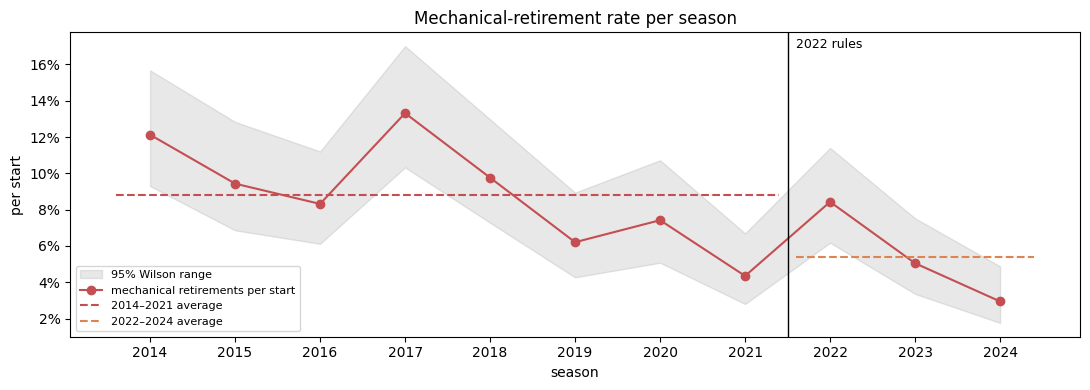

season,starts,mechanical retirements,rate
2014,404,49,12.1%
2015,371,35,9.4%
2016,457,38,8.3%
2017,398,53,13.3%
2018,420,41,9.8%
2019,419,26,6.2%
2020,337,25,7.4%
2021,437,19,4.3%
2022,439,37,8.4%
2023,436,22,5.0%


In [230]:
season = starts.groupby("year").agg(starts=("mech", "size"), mech=("mech", "sum")).reset_index()
season["rate"] = season.mech / season.starts
season["ci_lo"], season["ci_hi"] = wilson(season.mech, season.starts)

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(season.year, season.ci_lo, season.ci_hi, color=GREY, alpha=0.2, label="95% Wilson range")
ax.plot(season.year, season.rate, marker="o", color="#C44E52", label="mechanical retirements per start")
for p, (a, b) in {P1: (FIRST_SEASON, SPLIT - 1), P2: (SPLIT, LAST_SEASON)}.items():
    s = season[season.year.between(a, b)]
    ax.hlines(s.mech.sum() / s.starts.sum(), a - 0.4, b + 0.4, color=P_COLORS[p], ls="--", label=f"{p} average")
ax.axvline(SPLIT - 0.5, color="black", lw=1); ax.text(SPLIT - 0.4, ax.get_ylim()[1] * 0.95, f"{SPLIT} rules", fontsize=9)
ax.set(xlabel="season", ylabel="per start", title="Mechanical-retirement rate per season")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xticks(season.year); ax.legend(fontsize=8)
plt.tight_layout(); savefig("q3_01_rate_by_season"); plt.show()

table(pd.DataFrame({"season": season.year, "starts": season.starts, "mechanical retirements": season.mech,
                    "rate": season.rate}), pct1=["rate"], caption="Mechanical-retirement rate per season")

A team that raced only in 2014 would look unreliable partly because of the year, and a team that raced only in 2024 would look reliable partly because of the year. **Fix: compare each team with what was normal in its own seasons**, as in Q1: the **normal rate for its seasons** is the average of the seasons in which its starts took place (each season's rate is computed over all teams). The pretend starts are given at this normal rate, and

> **score = adjusted rate − normal rate for its seasons**, in percentage points: *how much more often than normal this team's cars broke down.*

**Teams are ranked by this score.** For teams that raced in every season of a period (Mercedes, Ferrari, ...), the normal rate is simply the period's rate; it only matters for teams that raced in part of a period.

In [231]:
def constructor_table(d, event="mech", min_n=MIN_STARTS, k_values=K_VALUES):
    """One row per constructor and period: raw rate, Wilson range, normal rate for its seasons, scores and ranks."""
    season_rate = d.groupby("year")[event].mean()                 # over ALL teams, before the minimum-sample filter
    t = (d.assign(expected=d.year.map(season_rate))
           .groupby(["period", "constructorId"])
           .agg(constructor=("constructor", "first"), first=("year", "min"), last=("year", "max"),
                starts=(event, "size"), events=(event, "sum"), expected=("expected", "mean"))
           .reset_index())
    t["raw rate"] = t.events / t.starts
    t["ci_lo"], t["ci_hi"] = wilson(t.events, t.starts)
    for k in k_values:
        t[f"score_k{k}"] = bayes_avg(t.events, t.starts, t.expected, k) - t.expected
    t = t[t.starts >= min_n].copy()
    for k in k_values:
        t[f"rank_k{k}"] = t.groupby("period")[f"score_k{k}"].rank(ascending=False, method="min").astype(int)
    sort_k = K_MAIN if K_MAIN in k_values else k_values[0]
    return t.sort_values(["period", f"rank_k{sort_k}"]).reset_index(drop=True)

RANK_COLS = [f"rank_k{k}" for k in K_VALUES]

def top_group(t, top=TOP):
    """Constructors in the top `top` under every value of k."""
    return t[(t[RANK_COLS] <= top).all(axis=1)]

ct = constructor_table(starts)
ct_upper = constructor_table(starts, event="mech_upper")    # upper bound: grey-zone statuses counted

#### 3.2 The ranking

In [232]:
for p in PERIODS:
    t = ct[ct.period == p]
    up = ct_upper[ct_upper.period == p].set_index("constructorId")["raw rate"]
    table(pd.DataFrame({
        "rank": t[f"rank_k{K_MAIN}"], "constructor": t.constructor,
        "seasons": [f"{a}" if a == b else f"{a}–{b}" for a, b in zip(t["first"], t["last"])],
        "starts": t.starts, "mechanical retirements": t.events, "raw rate": t["raw rate"],
        "95% Wilson range": pct_range(t.ci_lo, t.ci_hi, digits=1), "normal for its seasons": t.expected,
        f"adjusted rate (+{K_MAIN} pretend starts)": t.expected + t[f"score_k{K_MAIN}"],
        "score: adjusted − normal (points)": t[f"score_k{K_MAIN}"] * 100,
        "upper bound (grey zone counted)": t.constructorId.map(up),
    }), pct1=["raw rate", "normal for its seasons", f"adjusted rate (+{K_MAIN} pretend starts)", "upper bound (grey zone counted)"],
        dec1=["score: adjusted − normal (points)"], caption=f"{p}: mechanical-retirement ranking")

rank,constructor,seasons,starts,mechanical retirements,raw rate,95% Wilson range,normal for its seasons,adjusted rate (+20 pretend starts),score: adjusted − normal (points),upper bound (grey zone counted)
1,Toro Rosso,2014–2019,242,39,16.1%,12.0% – 21.3%,9.8%,15.6%,5.8,18.2%
2,Caterham,2014,33,7,21.2%,10.7% – 37.8%,12.1%,17.8%,5.7,30.3%
3,Lotus F1,2014–2015,75,13,17.3%,10.4% – 27.4%,10.8%,16.0%,5.2,24.0%
4,McLaren,2014–2021,315,40,12.7%,9.5% – 16.8%,8.8%,12.5%,3.7,15.2%
5,Renault,2016–2020,199,26,13.1%,9.1% – 18.5%,9.0%,12.7%,3.7,16.1%
6,AlphaTauri,2020–2021,77,7,9.1%,4.5% – 17.6%,5.7%,8.4%,2.7,10.4%
7,Red Bull,2014–2021,318,34,10.7%,7.8% – 14.6%,8.8%,10.6%,1.8,11.6%
8,Alpine F1 Team,2021,44,3,6.8%,2.3% – 18.2%,4.3%,6.0%,1.7,9.1%
9,Racing Point,2019–2020,75,6,8.0%,3.7% – 16.4%,6.7%,7.7%,1.0,9.3%
10,Sauber,2014–2018,199,21,10.6%,7.0% – 15.6%,10.6%,10.6%,-0.0,13.1%


rank,constructor,seasons,starts,mechanical retirements,raw rate,95% Wilson range,normal for its seasons,adjusted rate (+20 pretend starts),score: adjusted − normal (points),upper bound (grey zone counted)
1,Alfa Romeo,2022–2023,88,11,12.5%,7.1% – 21.0%,6.7%,11.4%,4.7,12.5%
2,Alpine F1 Team,2022–2024,135,14,10.4%,6.3% – 16.7%,5.4%,9.7%,4.3,10.4%
3,RB F1 Team,2024,48,2,4.2%,1.2% – 14.0%,2.9%,3.8%,0.9,10.4%
4,AlphaTauri,2022–2023,88,6,6.8%,3.2% – 14.1%,6.7%,6.8%,0.1,8.0%
5,Williams,2022–2024,134,7,5.2%,2.6% – 10.4%,5.4%,5.3%,-0.2,8.2%
6,Sauber,2024,48,1,2.1%,0.4% – 10.9%,2.9%,2.3%,-0.6,6.2%
7,Ferrari,2022–2024,134,6,4.5%,2.1% – 9.4%,5.4%,4.6%,-0.8,6.7%
8,Haas F1 Team,2022–2024,135,6,4.4%,2.1% – 9.4%,5.4%,4.6%,-0.8,5.2%
9,Mercedes,2022–2024,136,6,4.4%,2.0% – 9.3%,5.4%,4.5%,-0.9,4.4%
10,McLaren,2022–2024,136,5,3.7%,1.6% – 8.3%,5.4%,3.9%,-1.5,3.7%


**Same team, different names.** The ranking uses the constructor names as entered, as the question asks about constructors. Some teams changed name inside a period, so the same factory can appear twice: in 2022–2024, **Alfa Romeo** (2022–2023) and **Sauber** (2024) are the same team, as are **AlphaTauri** (2022–2023) and **RB F1 Team** (2024). Part C groups them by factory.

**The figure:** for each team, the **grey dot** is the normal rate for its seasons and the **coloured dot** its adjusted rate; the number is the score. Teams at the top broke down more often than normal, teams at the bottom less often.

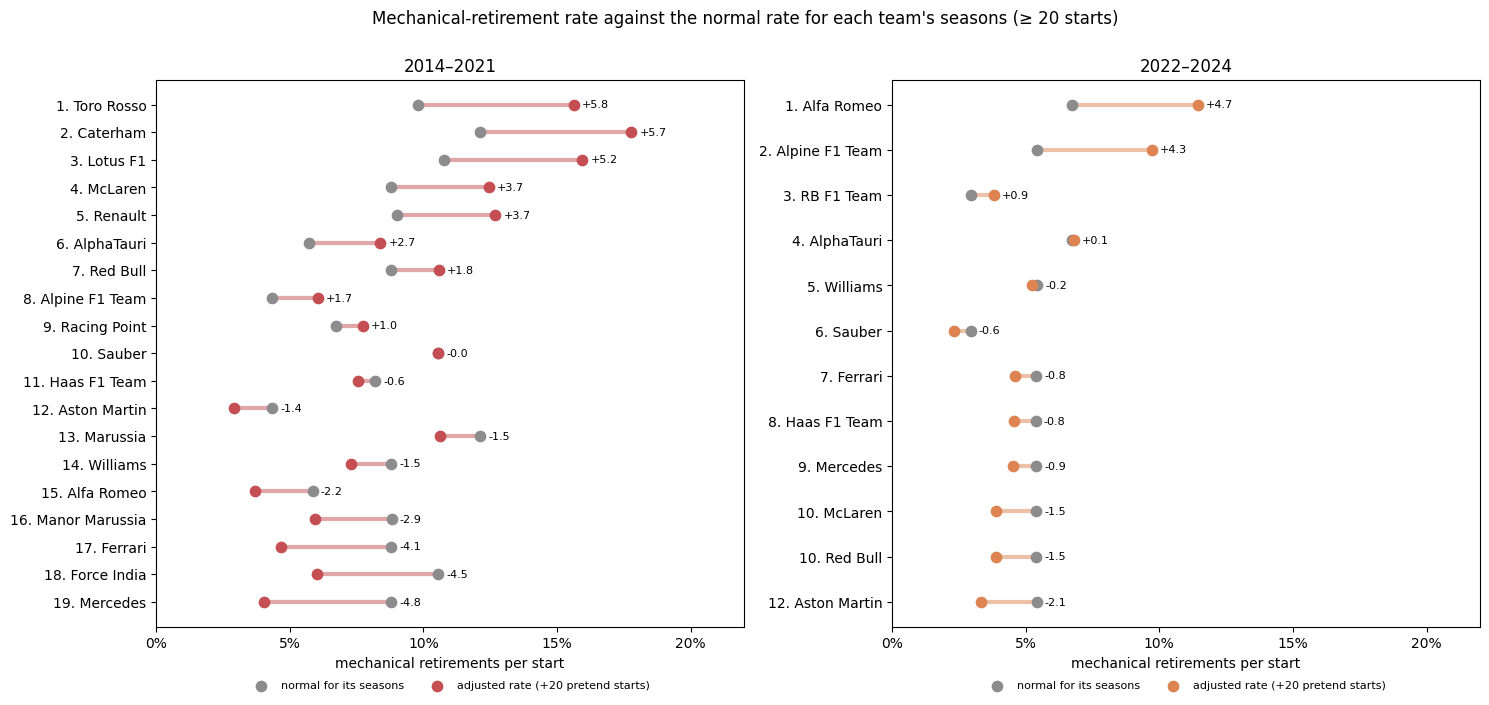

In [233]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, p in zip(axes, PERIODS):
    t = ct[ct.period == p].iloc[::-1]
    y = np.arange(len(t))
    adjusted = t.expected + t[f"score_k{K_MAIN}"]
    ax.hlines(y, t.expected, adjusted, color=P_COLORS[p], lw=3, alpha=0.5)
    ax.scatter(t.expected, y, color=GREY, s=55, zorder=3, label="normal for its seasons")
    ax.scatter(adjusted, y, color=P_COLORS[p], s=55, zorder=4, label=f"adjusted rate (+{K_MAIN} pretend starts)")
    for yi, a, x, sc in zip(y, adjusted, t.expected, t[f"score_k{K_MAIN}"]):
        ax.text(max(a, x) + 0.003, yi, f"{sc * 100:+.1f}", va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels([f"{r}. {c}" for r, c in zip(t[f"rank_k{K_MAIN}"], t.constructor)])
    ax.set(title=p, xlabel="mechanical retirements per start", xlim=(0, 0.22))
    ax.set_xticks(np.arange(0, 0.21, 0.05))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
fig.suptitle(f"Mechanical-retirement rate against the normal rate for each team's seasons (≥ {MIN_STARTS} starts)", y=1.0)
plt.tight_layout(); savefig("q3_02_ranking"); plt.show()

#### 3.3 Does the answer depend on our choices?

We chose **20** pretend starts, a minimum of **20** starts, and only the clear mechanical statuses. So we also tried **10 and 40** pretend starts, a minimum of **10 and 40** starts, and counting the **grey zone** as mechanical. As in Q1 we report a **top group**: teams in the top 3 with 10, 20 **and** 40 pretend starts.

In [234]:
rob_rows, groups = [], {}
for m in MIN_STARTS_VALUES:
    t_m = constructor_table(starts, min_n=m)
    for p in PERIODS:
        g = top_group(t_m[t_m.period == p])
        groups[(p, m)] = set(g.constructorId)
        rob_rows.append({"period": p, "version": f"minimum {m} starts", "teams ranked": int((t_m.period == p).sum()),
                         f"top group (top {TOP} with 10, 20 and 40 pretend starts)": ", ".join(g.constructor) or "none"})
for p in PERIODS:
    g = top_group(ct_upper[ct_upper.period == p])
    rob_rows.append({"period": p, "version": "grey zone counted as mechanical", "teams ranked": int((ct_upper.period == p).sum()),
                     f"top group (top {TOP} with 10, 20 and 40 pretend starts)": ", ".join(g.constructor) or "none"})
table(pd.DataFrame(rob_rows).sort_values("period", kind="stable"), caption="The top group under each choice")

period,version,teams ranked,"top group (top 3 with 10, 20 and 40 pretend starts)"
2014–2021,minimum 10 starts,19,"Toro Rosso, Caterham, Lotus F1"
2014–2021,minimum 20 starts,19,"Toro Rosso, Caterham, Lotus F1"
2014–2021,minimum 40 starts,17,"Toro Rosso, Lotus F1"
2014–2021,grey zone counted as mechanical,19,"Caterham, Lotus F1, Toro Rosso"
2022–2024,minimum 10 starts,12,"Alfa Romeo, Alpine F1 Team, RB F1 Team"
2022–2024,minimum 20 starts,12,"Alfa Romeo, Alpine F1 Team, RB F1 Team"
2022–2024,minimum 40 starts,12,"Alfa Romeo, Alpine F1 Team, RB F1 Team"
2022–2024,grey zone counted as mechanical,12,"RB F1 Team, Alfa Romeo, Alpine F1 Team"


#### 3.4 Part A answer

In [235]:
robust_ids = {p: set.intersection(*(groups[(p, m)] for m in MIN_STARTS_VALUES)) for p in PERIODS}
lines = []
for p in PERIODS:
    t = ct[ct.period == p]
    g = top_group(t)
    desc = "; ".join(f"**{c}**{' ✓' if cid in robust_ids[p] else ''} ({e}/{n} starts, normal {x:.1%}, {s * 100:+.1f} points)"
                     for cid, c, e, n, x, s in zip(g.constructorId, g.constructor, g.events, g.starts, g.expected,
                                                   g[f"score_k{K_MAIN}"])) or f"no constructor is in the top {TOP} under every k"
    low = t.nsmallest(2, f"score_k{K_MAIN}")
    lines.append(f"- **{p}:** {desc}. Most reliable: "
                 + ", ".join(f"{c} ({s * 100:+.1f} points)" for c, s in zip(low.constructor, low[f"score_k{K_MAIN}"])) + ".")
close = [(p, c, s) for p in PERIODS for c, s in zip(top_group(ct[ct.period == p]).constructor,
                                                    top_group(ct[ct.period == p])[f"score_k{K_MAIN}"]) if s < 0.01]
note = "".join(f"\n\n**{c}** ({p}) is in the top group, but only {s * 100:+.1f} points above normal: it is in the top {TOP} "
               "because few teams in that period broke down more often than normal, not because it stands out." for p, c, s in close)
md(f"**Highest mechanical-retirement rate** (top group: top {TOP} with 10, 20 and 40 pretend starts, minimum {MIN_STARTS} "
   "starts; mechanical retirements/starts, normal rate for its seasons, score):\n" + "\n".join(lines) +
   f"\n\n✓ = also in the top group with a minimum of {MIN_STARTS_VALUES[0]} and {MIN_STARTS_VALUES[-1]} starts. "
   "The table in 3.3 shows which teams change when the grey zone is counted." + note)

**Highest mechanical-retirement rate** (top group: top 3 with 10, 20 and 40 pretend starts, minimum 20 starts; mechanical retirements/starts, normal rate for its seasons, score):
- **2014–2021:** **Toro Rosso** ✓ (39/242 starts, normal 9.8%, +5.8 points); **Caterham** (7/33 starts, normal 12.1%, +5.7 points); **Lotus F1** ✓ (13/75 starts, normal 10.8%, +5.2 points). Most reliable: Mercedes (-4.8 points), Force India (-4.5 points).
- **2022–2024:** **Alfa Romeo** ✓ (11/88 starts, normal 6.7%, +4.7 points); **Alpine F1 Team** ✓ (14/135 starts, normal 5.4%, +4.3 points); **RB F1 Team** ✓ (2/48 starts, normal 2.9%, +0.9 points). Most reliable: Aston Martin (-2.1 points), McLaren (-1.5 points).

✓ = also in the top group with a minimum of 10 and 40 starts. The table in 3.3 shows which teams change when the grey zone is counted.

**RB F1 Team** (2022–2024) is in the top group, but only +0.9 points above normal: it is in the top 3 because few teams in that period broke down more often than normal, not because it stands out.

### Step 4: Did cars become more reliable, and was it because of 2022? (Part B)

The chart in 3.1 shows the rate falling over time. Two comparisons:
- **2014–2021 vs 2022–2024**, the question's periods;
- **2019–2021 vs 2022–2024**: the three seasons just before the new rules against the three under them. If the 2022 rules made the difference, this change should also be clear.

**The range of a change:** a team's two cars share the same engine and parts all season, so their failures go together. The range is found by redrawing whole **team-seasons** (for example "McLaren 2015", both cars and every race) 1,000 times and keeping the middle 95%. A change is **clear** when its range does not include 0.

In [236]:
team_season = (starts.groupby(["constructorId", "year"])
                     .agg(mech=("mech", "sum"), n=("mech", "size")).reset_index())

def team_season_range(a0, a1, b0, b1, B=N_BOOT, seed=SEED):
    """Rate before, rate after, and the 95% range of the change (points) when whole team-seasons are redrawn."""
    rng = np.random.default_rng(seed)
    wa, wb = team_season[team_season.year.between(a0, a1)], team_season[team_season.year.between(b0, b1)]
    ia, ib = rng.integers(0, len(wa), size=(B, len(wa))), rng.integers(0, len(wb), size=(B, len(wb)))
    ra = wa.mech.values[ia].sum(axis=1) / wa.n.values[ia].sum(axis=1)
    rb = wb.mech.values[ib].sum(axis=1) / wb.n.values[ib].sum(axis=1)
    lo, hi = np.percentile((rb - ra) * 100, [2.5, 97.5])
    return wa.mech.sum() / wa.n.sum(), wb.mech.sum() / wb.n.sum(), lo, hi

cmp_rows = []
for name, a, b in [(f"the question's periods: {P1} vs {P2}", (FIRST_SEASON, SPLIT - 1), (SPLIT, LAST_SEASON)),
                   (f"just before vs after: {LATE_PRE}–{SPLIT - 1} vs {P2}", (LATE_PRE, SPLIT - 1), (SPLIT, LAST_SEASON))]:
    ra, rb, lo, hi = team_season_range(*a, *b)
    cmp_rows.append({"comparison": name, "rate before": ra, "rate after": rb, "change (points)": (rb - ra) * 100,
                     "95% range of the change": f"{lo:+.1f} to {hi:+.1f}", "clear change?": "yes" if (hi < 0 or lo > 0) else "no",
                     "_lo": lo, "_hi": hi})
cmp = pd.DataFrame(cmp_rows)
table(cmp.drop(columns=["_lo", "_hi"]), pct1=["rate before", "rate after"], dec1=["change (points)"],
      caption="Change in the mechanical-retirement rate (negative = fewer failures)")

main, late = cmp.iloc[0], cmp.iloc[1]
when = (f"Against the three seasons just before the rules the change is also clear ({late['rate before']:.1%} → "
        f"{late['rate after']:.1%}), so the 2022 period really is more reliable than the end of the previous rules."
        if late["clear change?"] == "yes" else
        f"Against the three seasons just before the rules the change is **not clear** ({late['rate before']:.1%} → "
        f"{late['rate after']:.1%}, range {late['_lo']:+.1f} to {late['_hi']:+.1f} points). Most of the improvement "
        "had already happened before 2022, so the data does not show that the 2022 rules caused it.")
md(f"""**Part B answer:** cars did become more reliable: {main['rate before']:.1%} → {main['rate after']:.1%}
({main['change (points)']:+.1f} points, range {main['_lo']:+.1f} to {main['_hi']:+.1f}, {'clear of zero' if main['clear change?'] == 'yes' else 'includes zero'}).
{when}""")

comparison,rate before,rate after,change (points),95% range of the change,clear change?
the question's periods: 2014–2021 vs 2022–2024,8.8%,5.4%,-3.4,-5.3 to -1.5,yes
just before vs after: 2019–2021 vs 2022–2024,5.9%,5.4%,-0.5,-2.5 to +1.4,no


**Part B answer:** cars did become more reliable: 8.8% → 5.4%
(-3.4 points, range -5.3 to -1.5, clear of zero).
Against the three seasons just before the rules the change is **not clear** (5.9% → 5.4%, range -2.5 to +1.4 points). Most of the improvement had already happened before 2022, so the data does not show that the 2022 rules caused it.

### Step 5: Did the same team break down less after 2022? (Part C)

Several teams changed name while keeping the same factory and staff: Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Lotus F1 → Renault → Alpine, Sauber ↔ Alfa Romeo, Marussia → Manor. The data gives each name its own `constructorId`. To compare **the same team** before and after 2022, the names are grouped by factory here; Part A keeps the names as entered.

In [237]:
LINEAGE = {
    "toro_rosso": "Faenza (Toro Rosso / AlphaTauri / RB)", "alphatauri": "Faenza (Toro Rosso / AlphaTauri / RB)",
    "rb": "Faenza (Toro Rosso / AlphaTauri / RB)",
    "force_india": "Silverstone (Force India / Racing Point / Aston Martin)",
    "racing_point": "Silverstone (Force India / Racing Point / Aston Martin)",
    "aston_martin": "Silverstone (Force India / Racing Point / Aston Martin)",
    "lotus_f1": "Enstone (Lotus F1 / Renault / Alpine)", "renault": "Enstone (Lotus F1 / Renault / Alpine)",
    "alpine": "Enstone (Lotus F1 / Renault / Alpine)",
    "sauber": "Hinwil (Sauber / Alfa Romeo)", "alfa": "Hinwil (Sauber / Alfa Romeo)",
    "marussia": "Banbury (Marussia / Manor)", "manor": "Banbury (Marussia / Manor)",
}
starts["team"] = starts.constructorRef.map(LINEAGE).fillna(starts.constructor)

names_used = starts.groupby(["team", "constructor"]).year.agg(["min", "max"]).reset_index()
names_used["label"] = names_used.constructor + " (" + names_used["min"].astype(str) + "–" + names_used["max"].astype(str) + ")"
renamed = names_used.groupby("team").filter(lambda g: len(g) > 1).groupby("team").label.agg(", ".join)
table(renamed.rename("names used (seasons)").reset_index(), caption="Teams that raced under more than one name, 2014–2024")

team,names used (seasons)
Banbury (Marussia / Manor),"Manor Marussia (2015–2016), Marussia (2014–2014)"
Enstone (Lotus F1 / Renault / Alpine),"Alpine F1 Team (2021–2024), Lotus F1 (2014–2015), Renault (2016–2020)"
Faenza (Toro Rosso / AlphaTauri / RB),"AlphaTauri (2020–2023), RB F1 Team (2024–2024), Toro Rosso (2014–2019)"
Hinwil (Sauber / Alfa Romeo),"Alfa Romeo (2019–2023), Sauber (2014–2024)"
Silverstone (Force India / Racing Point / Aston Martin),"Aston Martin (2021–2024), Force India (2014–2018), Racing Point (2019–2020)"


For every team that raced in both periods, we compare its rate before and after 2022. With only three seasons after 2022, the range is found by redrawing the team's **races** (both cars together) 1,000 times; this does not capture problems that last a whole season, so these ranges are somewhat narrow. A change is **clear** when its range does not include 0.

team,rate 2014–2021,rate 2022–2024,change (points),95% range,clear change?
McLaren,12.7%,3.7%,-9.0,-14.5 to -3.8,"yes, fewer failures"
Faenza (Toro Rosso / AlphaTauri / RB),14.4%,5.9%,-8.5,-13.6 to -2.9,"yes, fewer failures"
Red Bull,10.7%,3.7%,-7.0,-11.6 to -2.0,"yes, fewer failures"
Haas F1 Team,7.5%,4.4%,-3.1,-8.3 to +1.7,no
Enstone (Lotus F1 / Renault / Alpine),13.2%,10.4%,-2.8,-9.2 to +3.5,no
Silverstone (Force India / Racing Point / Aston Martin),5.7%,3.0%,-2.7,-6.7 to +2.0,no
Williams,7.2%,5.2%,-2.0,-6.6 to +2.8,no
Ferrari,4.4%,4.5%,0.1,-4.2 to +5.0,no
Mercedes,3.8%,4.4%,0.7,-3.1 to +5.0,no
Hinwil (Sauber / Alfa Romeo),7.8%,8.8%,1.0,-4.3 to +7.2,no


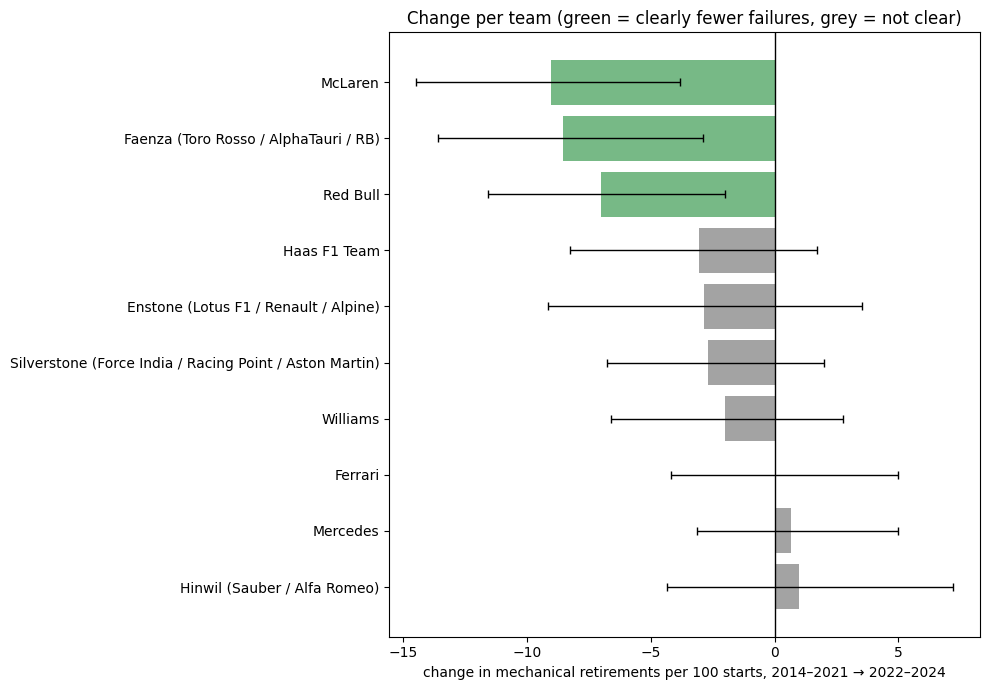

**Part C answer:** clearly fewer failures after 2022: **McLaren, Faenza (Toro Rosso / AlphaTauri / RB), Red Bull**. Clearly more: **none**. For the other teams the change is not clear.

In [238]:
team_race = starts.groupby(["team", "period", "raceId"]).agg(mech=("mech", "sum"), n=("mech", "size")).reset_index()

def team_change(team, B=N_BOOT, seed=SEED):
    """Change in one team's rate (points) between the periods, with a range from redrawing its races."""
    rng = np.random.default_rng(seed)
    out, sims = {"team": team}, []
    for p in PERIODS:
        g = team_race[(team_race.team == team) & (team_race.period == p)]
        idx = rng.integers(0, len(g), size=(B, len(g)))
        out[p] = g.mech.sum() / g.n.sum()
        sims.append(g.mech.values[idx].sum(axis=1) / g.n.values[idx].sum(axis=1))
    out["change (points)"] = (out[P2] - out[P1]) * 100
    out["lo"], out["hi"] = np.percentile((sims[1] - sims[0]) * 100, [2.5, 97.5])
    return out

both = team_race.groupby("team").period.nunique()
lineage_teams = [t for t in both.index[both == 2]
                 if team_race[team_race.team == t].groupby("period").n.sum().min() >= MIN_STARTS]
lin = pd.DataFrame([team_change(t) for t in lineage_teams]).sort_values("change (points)")
lin["clear change?"] = np.where(lin.hi < 0, "yes, fewer failures", np.where(lin.lo > 0, "yes, more failures", "no"))
table(pd.DataFrame({"team": lin.team, f"rate {P1}": lin[P1], f"rate {P2}": lin[P2],
                    "change (points)": lin["change (points)"],
                    "95% range": [f"{a:+.1f} to {b:+.1f}" for a, b in zip(lin.lo, lin.hi)],
                    "clear change?": lin["clear change?"]}),
      pct1=[f"rate {P1}", f"rate {P2}"], dec1=["change (points)"], caption="Change per team (negative = fewer failures)")

fig, ax = plt.subplots(figsize=(10, 0.55 * len(lin) + 1.5))
d = lin.sort_values("change (points)", ascending=False)
y = np.arange(len(d))
colors = ["#55A868" if h < 0 else ("#C44E52" if l > 0 else GREY) for l, h in zip(d.lo, d.hi)]
ax.barh(y, d["change (points)"], color=colors, alpha=0.8)
ax.errorbar(d["change (points)"], y, xerr=[d["change (points)"] - d.lo, d.hi - d["change (points)"]],
            fmt="none", ecolor="black", capsize=3, lw=1)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y); ax.set_yticklabels(d.team)
ax.set(xlabel=f"change in mechanical retirements per 100 starts, {P1} → {P2}",
       title="Change per team (green = clearly fewer failures, grey = not clear)")
plt.tight_layout(); savefig("q3_03_team_change"); plt.show()

better = ", ".join(lin.loc[lin.hi < 0, "team"]) or "none"
worse = ", ".join(lin.loc[lin.lo > 0, "team"]) or "none"
md(f"**Part C answer:** clearly fewer failures after 2022: **{better}**. Clearly more: **{worse}**. "
   "For the other teams the change is not clear.")

### Answer and limitations

In [239]:
best = {p: ", ".join(f"{c}{' ✓' if cid in robust_ids[p] else ''}" for cid, c in
                     zip(top_group(ct[ct.period == p]).constructorId, top_group(ct[ct.period == p]).constructor)) or "none"
        for p in PERIODS}
table(pd.DataFrame([
    {"part": f"A. Highest mechanical-retirement rate {P1}", "answer": best[P1]},
    {"part": f"A. Highest mechanical-retirement rate {P2}", "answer": best[P2]},
    {"part": "B. Did cars become more reliable?",
     "answer": f"{main['rate before']:.1%} → {main['rate after']:.1%} ({main['change (points)']:+.1f} points, "
               f"range {main['_lo']:+.1f} to {main['_hi']:+.1f})"},
    {"part": "B. Did the drop come with the 2022 rules?",
     "answer": "yes: also clear against 2019–2021" if late["clear change?"] == "yes"
               else "mostly before 2022: no clear change against 2019–2021"},
    {"part": "C. Teams with clearly fewer failures after 2022", "answer": better},
    {"part": "C. Teams with clearly more failures after 2022", "answer": worse},
]), caption="Q3 answers (✓ = in the top group under every minimum sample)")

part,answer
A. Highest mechanical-retirement rate 2014–2021,"Toro Rosso ✓, Caterham, Lotus F1 ✓"
A. Highest mechanical-retirement rate 2022–2024,"Alfa Romeo ✓, Alpine F1 Team ✓, RB F1 Team ✓"
B. Did cars become more reliable?,"8.8% → 5.4% (-3.4 points, range -5.3 to -1.5)"
B. Did the drop come with the 2022 rules?,mostly before 2022: no clear change against 2019–2021
C. Teams with clearly fewer failures after 2022,"McLaren, Faenza (Toro Rosso / AlphaTauri / RB), Red Bull"
C. Teams with clearly more failures after 2022,none


**Limitations:**
- **Engine supplier is mixed into team reliability.** Many failures come from the power unit, which several teams buy from the same supplier (for example McLaren's 2015–2017 Honda engines). Ergast does not store the engine supplier.
- **The status gives only the official reason.** `Retired` hides the cause; the upper bound shows how much the grey zone could matter.
- **The status groups contain judgment calls** (step 1).
- **Team names vs factories.** Part A follows the names as entered, so a renamed team can appear twice in one period; Part C groups them by factory.
- **2022–2024 is only three seasons,** so rates in that period are less precise.
- **The per-team ranges in Part C redraw races, not seasons,** so they do not capture season-long problems and are somewhat narrow.
- **Sprint races are not in `results`,** so they are not counted.
- **Descriptive only:** the analysis does not show *why* reliability changed.

# 7. Feature engineering

Each row of the modelling table is one prediction: *will this driver finish on the podium in this race?* This section adds the **features**, the information the model gets for each row. Every feature has to pass two tests:
1. **Known before the race starts** (after qualifying). Anything written after the race (results, points, laps, status, the standings of that race) is never a feature (cleaning summary, *Features that must look backwards only*).
2. **Backed by evidence:** a chart or a number showing how it relates to the podium.

**How strongly a feature relates to the podium** is measured in the same way for every group, with the **AUC**: take one random start that ended on the podium and one that did not; the AUC is the chance that the feature gives the podium start the better value. 0.5 means the feature is no better than a coin flip, 1 means it always separates them. The AUC judges one feature on its own, so a feature that only helps together with another one can score low; the "same starting area" checks cover that case.

The features are built in **groups**, so that the ablation can later remove one group at a time. We start with the grid and add the other groups (qualifying, driver form, team form, standings, ...) one by one.

**Rules from the cleaning, used throughout:**
- Features that look at history are computed on **all** rows, so a driver's history counts every race. The `failed_to_qualify` and Indianapolis 500 rows are removed only afterwards, when the final modelling table is built.
- Races are ordered by `(year, round)`, never by `raceId`.
- Season totals become rates, because points and calendar length changed across eras.
- Missing feature values are not filled here; they are filled in preprocessing, using the training seasons only.


In [240]:
# the feature table: the columns it needs from the base table (section 5), in race order
fe = (base[['resultId', 'raceId', 'driverId', 'constructorId', 'grid', 'grid_clean', 'pit_lane_start',
            'positionOrder', 'failed_to_qualify', 'is_indy500', 'year', 'round', 'circuitId', 'podium']]
      .sort_values(['year', 'round', 'positionOrder'])
      .reset_index(drop=True))
model_rows = ~fe.failed_to_qualify & ~fe.is_indy500           # the rows the model will be trained and tested on

def auc(feature, target):
    """Chance that a random podium start has a higher feature value than a random non-podium start (0.5 = no better than chance)."""
    known = feature.notna()
    f, t = feature[known], target[known]
    return stats.mannwhitneyu(f[t == 1], f[t == 0]).statistic / ((t == 1).sum() * (t == 0).sum())

print('rows:', len(fe), '| model rows:', int(model_rows.sum()), '| podium rate in model rows:',
      f'{fe.loc[model_rows, "podium"].mean():.1%}')


rows: 26668 | model rows: 24921 | podium rate in model rows: 13.5%


## 7.1 Grid

**Hypothesis.** Where a driver starts decides most of their chance of a podium. Q1 and Q2 already showed it: a P1 starter reaches the podium about 64% of the time and a P10 starter about 6%.

**Features.**
- `grid_clean`: the starting slot, with pit-lane starters placed at the back of the field (results section, *pit-lane starts*).
- `pit_lane_start`: 1 when the driver started from the pit lane.

**Valid at the cutoff.** The grid is fixed before the race starts, after qualifying and any grid penalties, so both features are known at prediction time.

**Evidence:** the podium rate for every starting slot, on the model rows.


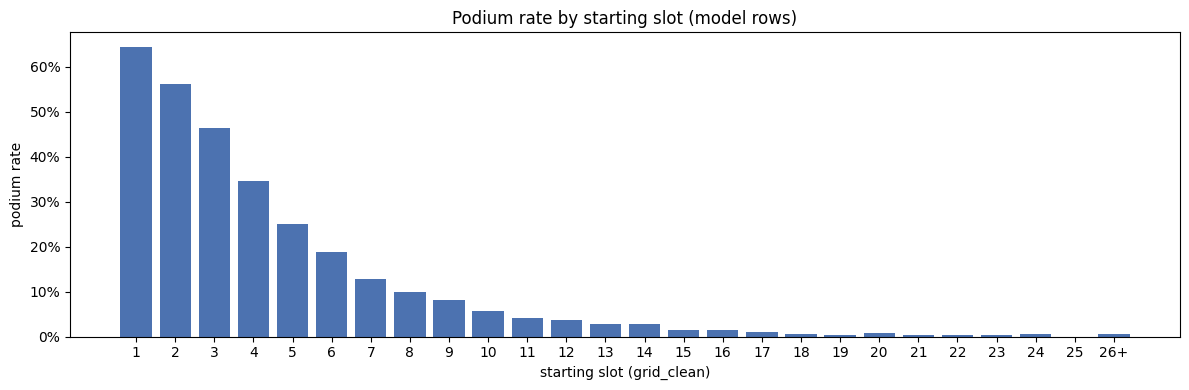

Spearman correlation between grid_clean and podium: -0.46 | AUC: 0.887
podium rate in slots 1-3: 56% | slots 4-10: 16% | slot 11 or further back: 1.6%


,starts,podiums,podium_rate
pit_lane_start,,,
started from a grid slot,24849,3359,0.135176
started from the pit lane,72,0,0.000000


In [241]:
g = fe[model_rows]
by_slot = (g.assign(slot=g.grid_clean.clip(upper=26))          # slots behind 26 are very rare: grouped as 26+
             .groupby('slot').agg(starts=('podium', 'size'), podiums=('podium', 'sum')))
by_slot['podium rate'] = by_slot.podiums / by_slot.starts

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(by_slot.index, by_slot['podium rate'], color='#4C72B0')
ax.set_xticks(by_slot.index)
ax.set_xticklabels([str(s) if s < 26 else '26+' for s in by_slot.index])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='starting slot (grid_clean)', ylabel='podium rate', title='Podium rate by starting slot (model rows)')
plt.tight_layout(); plt.show()

rho = stats.spearmanr(g.grid_clean, g.podium)[0]
pit = g.groupby('pit_lane_start').agg(starts=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'))
print(f'Spearman correlation between grid_clean and podium: {rho:.2f} | AUC: {auc(-g.grid_clean, g.podium):.3f}')   # minus: a smaller slot is better
print('podium rate in slots 1-3:', f"{g[g.grid_clean <= 3].podium.mean():.0%}",
      '| slots 4-10:', f"{g[g.grid_clean.between(4, 10)].podium.mean():.0%}",
      '| slot 11 or further back:', f"{g[g.grid_clean >= 11].podium.mean():.1%}")
display(pit.rename(index={False: 'started from a grid slot', True: 'started from the pit lane'}))


**Reading.** The podium rate falls steeply with the starting slot: about 65% from P1, 47% from P3, 6% from P10 and almost none from P15 back. Drivers starting in the top 3 reach the podium 56% of the time, from slots 4 to 10 16%, and from slot 11 or further back only 1.6%. The Spearman correlation between `grid_clean` and podium is −0.46 and its AUC is 0.887. The relation is strong but not a straight line: most of the change happens in the first ten slots, which the encoding has to respect (decided in preprocessing).

**Pit-lane starts.** The flag finds 72 pit-lane starts, all from 2015 on, and none reached the podium (the best finish is 5th). Before 2015 the data does not record a pit-lane start as `grid` = 0 but gives it a slot at the back of the grid, so those starts cannot be flagged. Pit-lane starters have reached the podium in that period: race reports (F1 history, not the data) name Trulli at the 2009 Australian Grand Prix, Vettel at the 2012 Abu Dhabi Grand Prix and Hamilton at the 2014 Hungarian Grand Prix, all third, and the data records them from grid slots 20, 24 and 22.

**Decision.** `grid_clean` is kept as the main grid feature: it places every pit-lane starter at the back of the field, before and after 2015. `pit_lane_start` is not used as a feature, because it only exists from 2015, covers 72 rows, and its information is already in `grid_clean`.


## 7.2 Qualifying

### 1. Hypothesis

The grid already contains most of qualifying, because drivers usually start where they qualified. Qualifying can still add two things the grid does not have:
- **(a) A fast car that was moved back.** A driver who qualified 3rd but starts 15th after a grid penalty still has a fast car. Q1 showed that drivers who qualified on the front row but started further back reached the podium 31% of the time, against 73% for those who kept their slot.
- **(b) How much faster.** Two drivers next to each other on the grid can be 0.01 seconds or a full second apart. The position does not show this, but the lap time does.

### 2. Candidate features

- `quali_pos`: the qualifying position, the obvious candidate.
- `grid_minus_quali`: `grid_clean` − `quali_pos`, for idea (a). Positive means the driver starts further back than they qualified (a penalty or a pit-lane start), negative means they were moved up.
- `quali_gap_pct`: how much slower the driver's Q1 lap was than the fastest Q1 lap of that race, in percent, for idea (b). Q1 is used because every driver takes part in it, while Q2 and Q3 only exist for the drivers who reached them. A percentage makes circuits of different lengths comparable.

### 3. Valid at the cutoff, and coverage

Qualifying takes place one or two days before the race (races section, *missing values*), so all three are known at prediction time.

The qualifying table starts in 1994. It is complete in 1994–1995 and from 2003, and only partly filled in 1996–2002 (results section, *What `grid` = 0 means*). Q1 times are also missing for 156 entries, where a missing time does not mean a slow car (qualifying section, *What happened to them in the race*). Missing values are left here and filled in preprocessing.

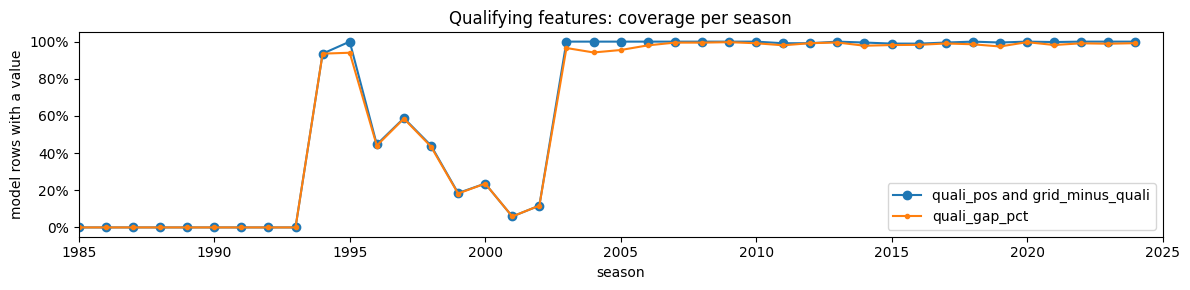

model rows with quali_pos, 2003-2024: 99.7% | with quali_gap_pct: 98.3%


In [242]:
q = qualifying[['raceId', 'driverId', 'position', 'q1_s']].rename(columns={'position': 'quali_pos'})
fe = fe.drop(columns=['quali_pos', 'q1_s', 'grid_minus_quali', 'quali_gap_pct'], errors='ignore')   # safe to rerun
fe = fe.merge(q, on=['raceId', 'driverId'], how='left', validate='1:1')
fe['grid_minus_quali'] = fe.grid_clean - fe.quali_pos
fe['quali_gap_pct'] = (fe.q1_s / fe.groupby('raceId').q1_s.transform('min') - 1) * 100

g = fe[model_rows]
cov = g.groupby('year')[['quali_pos', 'quali_gap_pct']].apply(lambda d: d.notna().mean())
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cov.index, cov.quali_pos, marker='o', label='quali_pos and grid_minus_quali')
ax.plot(cov.index, cov.quali_gap_pct, marker='.', label='quali_gap_pct')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlim=(1985, 2025), xlabel='season', ylabel='model rows with a value', title='Qualifying features: coverage per season')
ax.legend(); plt.tight_layout(); plt.show()

print('model rows with quali_pos, 2003-2024:', f"{g[g.year >= 2003].quali_pos.notna().mean():.1%}",
      '| with quali_gap_pct:', f"{g[g.year >= 2003].quali_gap_pct.notna().mean():.1%}")

### 4. Evidence

All three checks use the model rows from 2003, where qualifying is complete.

**4a. `quali_pos`: is it different from the grid?** If drivers almost always start where they qualified, `quali_pos` repeats `grid_clean`.

In [243]:
g = fe[model_rows & (fe.year >= 2003) & fe.quali_pos.notna()]
print(f'Spearman correlation between quali_pos and grid_clean: {stats.spearmanr(g.quali_pos, g.grid_clean)[0]:.2f}',
      f'| start where they qualified: {(g.grid_minus_quali == 0).mean():.1%}',
      f'| moved up: {(g.grid_minus_quali < 0).mean():.1%}',
      f'| moved back: {(g.grid_minus_quali > 0).mean():.1%}')
print(f'AUC 2003-2024: quali_pos {auc(-g.quali_pos, g.podium):.3f} | grid_clean {auc(-g.grid_clean, g.podium):.3f}')

Spearman correlation between quali_pos and grid_clean: 0.96 | start where they qualified: 72.6% | moved up: 21.1% | moved back: 6.4%
AUC 2003-2024: quali_pos 0.912 | grid_clean 0.909


**4b. `grid_minus_quali`: does a car moved back by a penalty still do better?** Drivers who start from the **same part of the grid** are compared: those who qualified in the top 5 and were moved back, against the others.

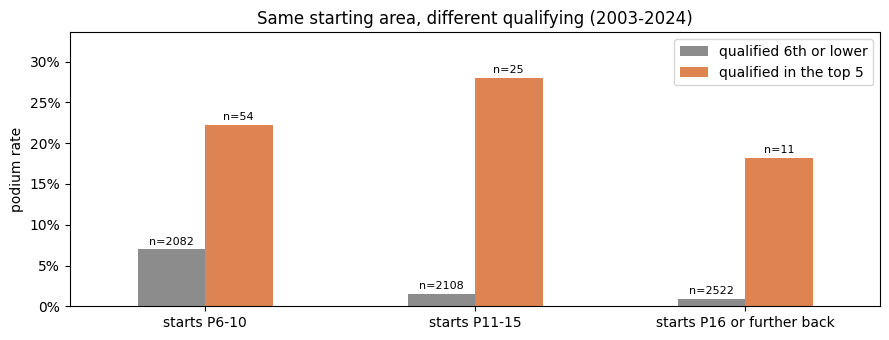

AUC of grid_minus_quali on its own: 0.549


In [244]:
g = fe[model_rows & (fe.year >= 2003) & fe.quali_pos.notna()]
back = g[g.grid_clean >= 6].assign(qualified=lambda d: np.where(d.quali_pos <= 5, 'qualified in the top 5', 'qualified 6th or lower'))
bands = pd.cut(back.grid_clean, [5, 10, 15, np.inf], labels=['starts P6-10', 'starts P11-15', 'starts P16 or further back'])
tab = (back.groupby([bands, 'qualified'], observed=True).podium.agg(starts='size', podium_rate='mean')
          .reset_index().rename(columns={'grid_clean': 'starting area', 'podium_rate': 'podium rate'}))
rates = tab.pivot(index='starting area', columns='qualified', values='podium rate')
sizes = tab.pivot(index='starting area', columns='qualified', values='starts')

fig, ax = plt.subplots(figsize=(9, 3.5))
rates.plot.bar(ax=ax, rot=0, color=['#8C8C8C', '#DD8452'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=8, padding=2)
ax.set_ylim(0, rates.max().max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same starting area, different qualifying (2003-2024)')
ax.legend(title=''); plt.tight_layout(); plt.show()

print(f'AUC of grid_minus_quali on its own: {auc(g.grid_minus_quali, g.podium):.3f}')

**4c. `quali_gap_pct`: does the size of the gap matter?** The podium rate by how far behind the fastest Q1 lap a driver was.

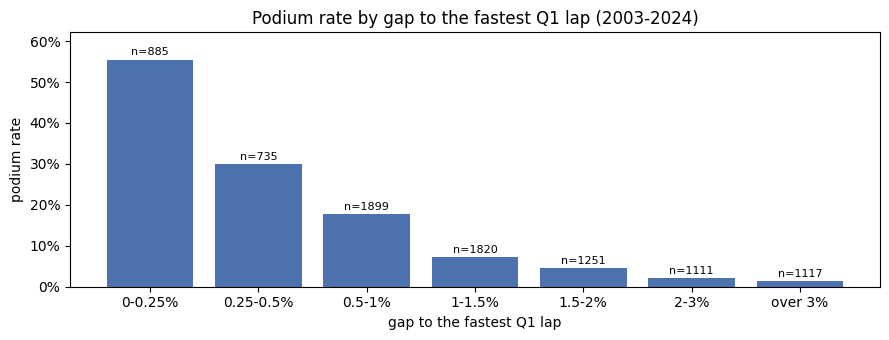

Spearman correlation with podium: quali_gap_pct -0.40 | AUC: 0.827


In [245]:
g = fe[model_rows & (fe.year >= 2003) & fe.quali_gap_pct.notna()]
gap_bins = pd.cut(g.quali_gap_pct, [-0.01, 0.25, 0.5, 1, 1.5, 2, 3, np.inf],
                  labels=['0-0.25%', '0.25-0.5%', '0.5-1%', '1-1.5%', '1.5-2%', '2-3%', 'over 3%'])
by_gap = g.groupby(gap_bins, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_gap.index.astype(str), by_gap['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_gap['size'], by_gap['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_gap['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='gap to the fastest Q1 lap', ylabel='podium rate', title='Podium rate by gap to the fastest Q1 lap (2003-2024)')
plt.tight_layout(); plt.show()

print(f'Spearman correlation with podium: quali_gap_pct {stats.spearmanr(g.quali_gap_pct, g.podium)[0]:.2f} '
      f'| AUC: {auc(-g.quali_gap_pct, g.podium):.3f}')   # minus: a smaller gap is better

### 5. Reading and decision

- **Coverage:** from 2003, 99.7% of the model rows have a qualifying position and 98.3% a Q1 gap. Before 2003 the features are mostly or completely missing, which matters for the choice of training seasons.
- **4a.** Qualifying position and grid are almost the same (Spearman 0.96): 72.6% of drivers start where they qualified, 21.1% are moved up (usually because a car ahead was penalised or did not start) and 6.4% are moved back. On their own they are about equally strong (AUC 0.912 for `quali_pos`, 0.909 for `grid_clean` from 2003).
- **4b.** A car moved back still does better. Among drivers starting from P11–15, those who had qualified in the top 5 reached the podium 28% of the time, against 1.5% for the others; from P6–10 it is 22% against 7%. These groups are small (11 to 54 starts), but the pattern holds in every starting area. On its own `grid_minus_quali` is almost a coin flip (AUC 0.55): being moved back says little without knowing where the car starts, so it only helps together with `grid_clean`.
- **4c.** The gap matters: within 0.25% of the fastest Q1 lap, 56% reach the podium; at 0.5–1%, 18%; over 3%, about 1% (Spearman −0.40, AUC 0.827).

**Decision.** The qualifying group is `grid_minus_quali` and `quali_gap_pct`. `quali_pos` is not kept as a separate feature: it equals `grid_clean` − `grid_minus_quali`, so with those two in the model it adds no information and makes the three columns depend exactly on each other. Missing values (before 2003, and the entries with no Q1 time) are filled in preprocessing.

## 7.3 Driver form

### 1. Hypothesis

A driver who has reached the podium in recent races is likely to keep doing so a few races later: the same skill, the same car and the same team are still there. The cleaning already showed that recent results carry information: the standings before a race follow its finishing order with a rank correlation of about 0.6 in the modern seasons (driver_standings section, *how much the same-race standings would leak*).

Standings and form are related but not the same. The standings count every race of the current season and restart at zero every season; form looks at a fixed number of recent races and carries over from one season to the next. The overlap between the two is checked when the standings are built.

### 2. Candidate features

Each past race gives several numbers about the driver. Two of them are summarised over the driver's last N starts:
- `form_podium_rate`: the share of podiums in the last N starts.
- `form_avg_finish`: the average finishing position (`positionOrder`) in the last N starts. It is more detailed (a 4th place counts for something), but a driver who crashed on lap 1 gets a position near the back even if the car was fast.

And one about how much history there is:
- `career_starts`: how many starts the driver made before this race (0 for a debut). It tells how much the form value can be trusted, and experience may matter on its own.

Other numbers are left out on purpose: **points**, because the points system changed across eras (cleaning summary, *Numbers that are not comparable across eras*); **laps**, because races have different lengths; **places gained** (grid minus finish), because a driver starting on pole cannot gain any; and the **reason a race ended**, which belongs to a reliability group.

### 3. Valid at the cutoff

- **Only earlier races.** For each race, the window looks at the driver's starts **before** it, ordered by `(year, round)`. The race itself is never part of its own window. The check below proves it.
- **Every entry counts.** Every race the driver entered counts, including races where the car failed before the start, because at the prediction cutoff these were normal entries. Only the races where the driver failed to qualify and the Indianapolis 500 are left out.
- **The window crosses seasons.** At round 1 the window holds the last races of the previous season.
- **A debut has no history**, so its form value is missing and filled in preprocessing; `career_starts` is 0.

In [246]:
hist = fe[model_rows].sort_values(['driverId', 'year', 'round'])     # each driver's real starts, in race order
by_driver = hist.groupby('driverId')

def past_mean(col, n):
    """Mean of `col` over the driver's previous n starts (the current start is excluded by shift)."""
    return by_driver[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())

fe = fe.drop(columns=['form_podium_rate', 'career_starts'], errors='ignore')     # safe to rerun
fe['form_podium_rate'] = past_mean('podium', 10)                               # aligned on the index of fe
fe['career_starts'] = by_driver.cumcount().astype('Int64')

# leakage check: the same value computed in a second, independent way from cumulative sums
cum = by_driver.podium.cumsum() - hist.podium                                  # podiums before this start
check = (cum - cum.groupby(hist.driverId).shift(10).fillna(0)) / fe.loc[hist.index, 'career_starts'].clip(upper=10)
assert np.allclose(check[fe.loc[hist.index, 'career_starts'] > 0], fe.loc[hist.index, 'form_podium_rate'].dropna()), 'form uses the current race'
assert fe.loc[hist.index][fe.loc[hist.index, 'career_starts'] == 0].form_podium_rate.isna().all(), 'a debut has a form value'

# one driver, start by start: the value only changes after a race
ham = (fe.loc[hist.index].merge(drivers[['driverId', 'forename', 'surname']], on='driverId')
         .query("forename == 'Lewis' and surname == 'Hamilton'").sort_values(['year', 'round']).head(5))
table(ham[['year', 'round', 'positionOrder', 'podium', 'career_starts', 'form_podium_rate']]
      .rename(columns={'positionOrder': 'finished'}), pct=['form_podium_rate'],
      caption="Lewis Hamilton's first five starts: the form value only uses the races before")

year,round,finished,podium,career_starts,form_podium_rate
2007,1,3,1,0,–
2007,2,2,1,1,100%
2007,3,2,1,2,100%
2007,4,2,1,3,100%
2007,5,2,1,4,100%


### 4. Evidence

**4a. Which window N, and which summary?** There is no obvious N, so both summaries are tried for N = 3, 5, 10, 20, 30 and 50 starts and compared with the AUC. This trial is kept here, as the brief asks for empirical choices.

In [247]:
g = fe[model_rows]
trial = []
for n in [3, 5, 10, 20, 30, 50]:
    rate, finish = past_mean('podium', n), past_mean('positionOrder', n)
    trial.append({'last N starts': n, 'AUC podium rate': auc(rate, hist.podium),
                  'AUC average finish': auc(-finish, hist.podium)})      # minus: a smaller position is better
display(pd.DataFrame(trial).style.format({'AUC podium rate': '{:.3f}', 'AUC average finish': '{:.3f}'}).hide(axis='index')
        .set_caption('Driver form: which window and which summary? (AUC, model rows)'))
print(f"correlation between the two summaries at N = 10: {stats.spearmanr(past_mean('podium', 10), past_mean('positionOrder', 10), nan_policy='omit')[0]:.2f}")

last N starts,AUC podium rate,AUC average finish
3,0.780,0.780
5,0.815,0.801
10,0.838,0.813
20,0.844,0.811
30,0.839,0.805
50,0.831,0.795


correlation between the two summaries at N = 10: -0.72


**4b. `form_podium_rate`: does recent form go with the podium?** The podium rate in a race, by the driver's podium rate over the previous 10 starts.

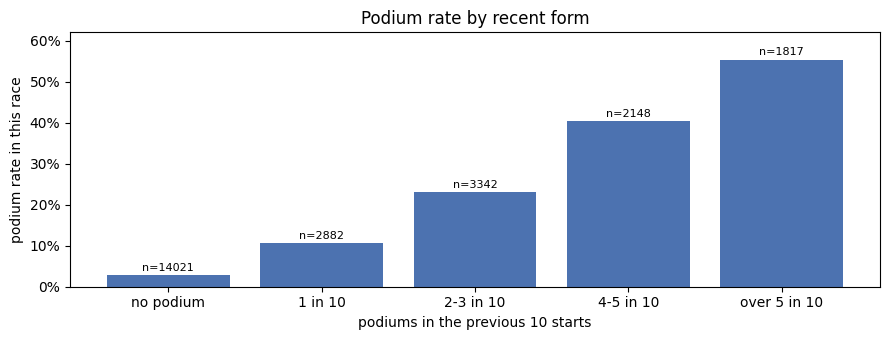

AUC of form_podium_rate: 0.838


In [248]:
g = fe[model_rows & fe.form_podium_rate.notna()]
levels = pd.cut(g.form_podium_rate, [-0.01, 0, 0.1, 0.3, 0.5, 1],
                labels=['no podium', '1 in 10', '2-3 in 10', '4-5 in 10', 'over 5 in 10'])
by_form = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_form.index.astype(str), by_form['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_form['size'], by_form['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_form['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='podiums in the previous 10 starts', ylabel='podium rate in this race', title='Podium rate by recent form')
plt.tight_layout(); plt.show()
print(f'AUC of form_podium_rate: {auc(g.form_podium_rate, g.podium):.3f}')

**4c. Does form add anything once the grid is known?** A fast driver usually also starts near the front, so form could just repeat the grid. Drivers who start from the **same part of the grid** are compared by their recent form.

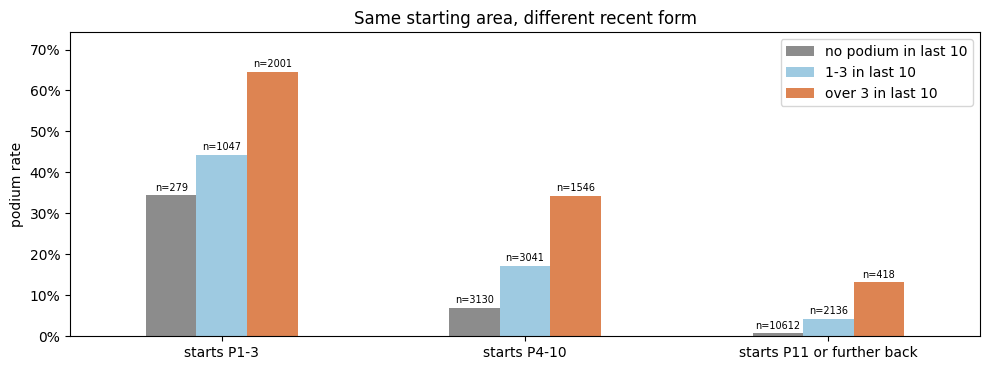

In [249]:
g = fe[model_rows & fe.form_podium_rate.notna()]
area = pd.cut(g.grid_clean, [0, 3, 10, np.inf], labels=['starts P1-3', 'starts P4-10', 'starts P11 or further back'])
form = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['no podium in last 10', '1-3 in last 10', 'over 3 in last 10'])
tab = g.groupby([area, form], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='grid_clean', columns='form_podium_rate', values='rate')
sizes = tab.pivot(index='grid_clean', columns='form_podium_rate', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#8C8C8C', '#9ecae1', '#DD8452'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same starting area, different recent form')
ax.legend(title=''); plt.tight_layout(); plt.show()

**4d. `career_starts`: does experience matter, and does it change how far the form value can be trusted?** First the podium rate by the number of starts before the race, then the same form value split by whether it rests on a full window of 10 starts.

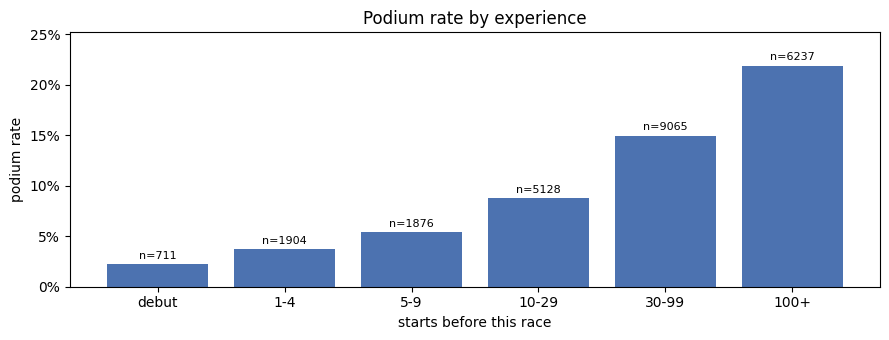

AUC of career_starts: 0.661


form_podium_rate,fewer than 10 starts: starts,full window (10 starts): starts,fewer than 10 starts: podium rate,full window (10 starts): podium rate
up to 20%,217,4682,11.1%,14.4%
20-50%,199,3274,24.6%,36.7%
over 50%,54,1763,46.3%,55.7%


In [250]:
g = fe[model_rows]
exp = pd.cut(g.career_starts, [-1, 0, 4, 9, 29, 99, np.inf], labels=['debut', '1-4', '5-9', '10-29', '30-99', '100+'])
by_exp = g.groupby(exp, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_exp.index.astype(str), by_exp['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_exp['size'], by_exp['mean'])):
    ax.text(i, r + 0.005, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_exp['mean'].max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='starts before this race', ylabel='podium rate', title='Podium rate by experience')
plt.tight_layout(); plt.show()
print(f'AUC of career_starts: {auc(g.career_starts, g.podium):.3f}')

w = g[g.form_podium_rate > 0]
trust = (w.assign(window=np.where(w.career_starts >= 10, 'full window (10 starts)', 'fewer than 10 starts'),
                  form=pd.cut(w.form_podium_rate, [0, 0.2, 0.5, 1], labels=['up to 20%', '20-50%', 'over 50%']))
          .groupby(['form', 'window'], observed=True).podium.agg(['size', 'mean']).unstack())
trust.columns = [f'{b}: {"starts" if a == "size" else "podium rate"}' for a, b in trust.columns]
table(trust.reset_index().rename(columns={'form': 'form_podium_rate'}),
      pct1=[c for c in trust.columns if 'rate' in c], caption='The same form value, on a full or a short window')

### 5. Reading and decision

- **4a. Window and summary.** The podium rate beats the average finish for every window (for example 0.838 against 0.813 at N = 10), and the two overlap strongly (Spearman −0.72), so only the podium rate is kept. Its AUC rises from 0.780 at N = 3 to 0.838 at N = 10 and 0.844 at N = 20, then falls (0.831 at N = 50): very short windows are noisy, very long ones reach back to old cars and seasons. **N = 10 is chosen**: it is within 0.006 of the best, still describes recent form (about half a season) rather than a career average, reacts faster when a driver changes team or car, and overlaps less with the standings, which already cover the whole season.
- **4b.** Recent form goes with the podium: with no podium in the previous 10 starts, 2.8% reach the podium; with 1 in 10, 10.7%; 2–3, 23.1%; 4–5, 40.6%; more than 5, 55.5% (AUC 0.838).
- **4c.** Form adds information beyond the grid. From the same starting area, drivers in strong form (more than 3 podiums in the last 10) reach the podium about twice as often as drivers with none: 64.7% against 34.3% from P1–3, 34.3% against 7.0% from P4–10, 13.4% against 0.7% from P11 or further back.
- **4d.** Experience matters: the podium rate rises from 2.6% on a debut to 22.1% after 100 or more starts (AUC 0.661). It also tells how far the form value can be trusted: the same form value means less on a short window, for example over 50% gives a podium 46.3% of the time with fewer than 10 past starts, against 55.7% on a full window.

**Decision.** The driver form group is `form_podium_rate` (podium rate over the previous 10 starts) and `career_starts` (starts before this race). `form_avg_finish` is not kept. The form value is missing at every debut; it is filled in preprocessing, and `career_starts` = 0 marks these rows.

## 7.4 Driver standings

### 1. Hypothesis

The championship table shows who has been strongest over the whole season so far. A driver high in the standings has a fast car and is scoring regularly, so they are more likely to reach the podium in the next race. The cleaning showed that the standings before a race follow its finishing order with a rank correlation of about 0.6 in the modern seasons (driver_standings section, *how much the same-race standings would leak*).

Driver form (7.3) also measures recent results, so the two overlap. The difference is the window: the standings count every race of the current season and are weighted by points, while form counts podiums in the last 10 starts across seasons. Section 4 checks whether the standings add anything once form is known.

### 2. Candidate features

Each standings row gives three numbers about the driver after a race:
- `position`: the championship rank (1st, 2nd, ...). It is not the average finishing position: it is decided by points, so wins count much more than steady 5th places.
- `points`: the season total. Raw points are not comparable across eras (cleaning summary, *Numbers that are not comparable across eras*), so it is turned into a **points share**: the driver's points divided by the leader's points (1 = leading, 0.5 = half the leader's points).
- `wins`: the number of wins so far, also tried as a win rate (wins per race so far).

### 3. Valid at the cutoff

- **Only the previous round.** A standings row is written after its race and already contains that race's result (driver_standings section, *is a row written before or after its race*). For a race in round r, the row of round r − 1 of the same season is used. Rounds run 1 to n with no gaps in every season (races section), so round r − 1 is always the race before.
- **Round 1 has no previous round.** For round 1, the driver's final position in the previous season is used instead: the last standing that is known before the new season starts.
- **No row in the previous round.** Some drivers have no standings row before a race, for example when their first race of a season comes after round 1. They also get last season's final position if they raced last season; otherwise the value is missing and filled in preprocessing.

In [251]:
stand = driver_standings[['raceId', 'driverId', 'position', 'points', 'wins']].merge(
    races[['raceId', 'year', 'round']], on='raceId', how='left', validate='m:1')
stand['points_share'] = stand.points / stand.groupby('raceId').points.transform('max').replace(0, np.nan)

# the row of round r - 1 is the standing before round r
before = (stand.assign(round=stand['round'] + 1)
               [['year', 'round', 'driverId', 'position', 'points_share', 'wins']]
               .rename(columns={'position': 'pos_before', 'points_share': 'share_before', 'wins': 'wins_before'}))
# the final standing of a season, used for the next season
last = stand[stand['round'] == stand.groupby('year')['round'].transform('max')]
last_season = (last.assign(year=last.year + 1)[['year', 'driverId', 'position']]
                   .rename(columns={'position': 'last_season_pos'}))

sd = (fe[['year', 'round', 'driverId', 'podium']]
        .merge(before, on=['year', 'round', 'driverId'], how='left', validate='m:1')
        .merge(last_season, on=['year', 'driverId'], how='left', validate='m:1'))
sd.index = fe.index

fe = fe.drop(columns=['champ_pos'], errors='ignore')                         # safe to rerun
fe['champ_pos'] = sd.pos_before.fillna(sd.last_season_pos).astype('Int64')

# leakage check: one driver, race by race; the value used is the standing after the previous race
ham = (fe.merge(drivers[['driverId', 'forename', 'surname']], on='driverId')
         .query("forename == 'Lewis' and surname == 'Hamilton' and year == 2008").sort_values('round').head(5)
         .merge(stand[['raceId', 'driverId', 'position']].rename(columns={'position': 'standing after this race'}),
                on=['raceId', 'driverId'], how='left'))
table(ham[['year', 'round', 'positionOrder', 'standing after this race', 'champ_pos']]
      .rename(columns={'positionOrder': 'finished', 'champ_pos': 'champ_pos (used)'}),
      caption='Lewis Hamilton, 2008: champ_pos is the standing after the previous race (round 1: final 2007 position)')

g = fe[model_rows]
print('model rows with champ_pos:', f'{g.champ_pos.notna().mean():.1%}',
      '| from the previous round:', f"{sd.loc[g.index, 'pos_before'].notna().mean():.1%}",
      '| from last season:', f"{(sd.loc[g.index, 'pos_before'].isna() & g.champ_pos.notna()).mean():.1%}")

year,round,finished,standing after this race,champ_pos (used)
2008,1,1,1,2
2008,2,5,1,1
2008,3,13,3,1
2008,4,3,2,3
2008,5,2,3,2


model rows with champ_pos: 96.3% | from the previous round: 88.0% | from last season: 8.4%


### 4. Evidence

**4a. Which standings number?** The candidates are compared with the AUC on the rows where they exist (all model rows after round 1 with a previous-round row).

In [252]:
m = sd.loc[fe.index[model_rows]].dropna(subset=['pos_before'])
m = m.assign(win_rate=m.wins_before / (m['round'] - 1))
display(pd.DataFrame([
    {'candidate': 'championship position', 'AUC': auc(-m.pos_before, m.podium)},          # minus: a smaller position is better
    {'candidate': 'points share', 'AUC': auc(m.share_before, m.podium)},
    {'candidate': 'wins so far', 'AUC': auc(m.wins_before, m.podium)},
    {'candidate': 'win rate so far', 'AUC': auc(m.win_rate, m.podium)},
]).style.format({'AUC': '{:.3f}'}).hide(axis='index').set_caption('Driver standings: which number? (AUC, previous round)'))
print(f'overlap: position vs points share {stats.spearmanr(m.pos_before, m.share_before)[0]:.2f} | '
      f'points share vs wins {stats.spearmanr(m.share_before, m.wins_before)[0]:.2f}')

candidate,AUC
championship position,0.842
points share,0.837
wins so far,0.723
win rate so far,0.725


overlap: position vs points share -0.93 | points share vs wins 0.62


**4b. `champ_pos`: does the championship position go with the podium?** The podium rate by the driver's championship position before the race.

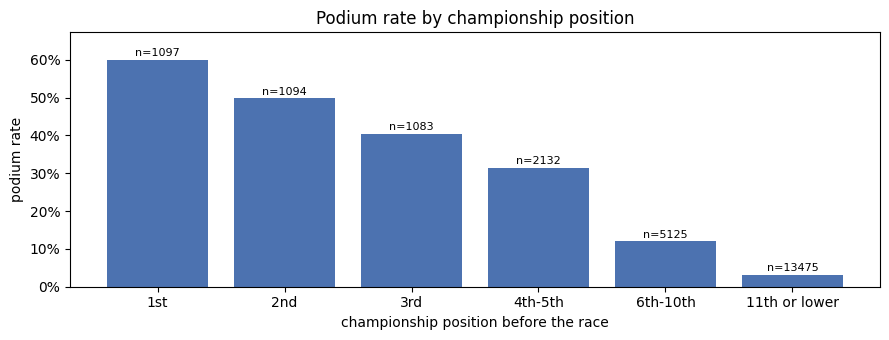

AUC of champ_pos: 0.841


In [253]:
g = fe[model_rows & fe.champ_pos.notna()]
levels = pd.cut(g.champ_pos, [0, 1, 2, 3, 5, 10, np.inf], labels=['1st', '2nd', '3rd', '4th-5th', '6th-10th', '11th or lower'])
by_pos = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_pos.index.astype(str), by_pos['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_pos['size'], by_pos['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_pos['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='championship position before the race', ylabel='podium rate', title='Podium rate by championship position')
plt.tight_layout(); plt.show()
print(f'AUC of champ_pos: {auc(-g.champ_pos, g.podium):.3f}')

**4c. Do the standings add anything once form is known?** Form and standings overlap, so drivers with the **same recent form** are compared by their championship position.

overlap of champ_pos and form_podium_rate: Spearman -0.75


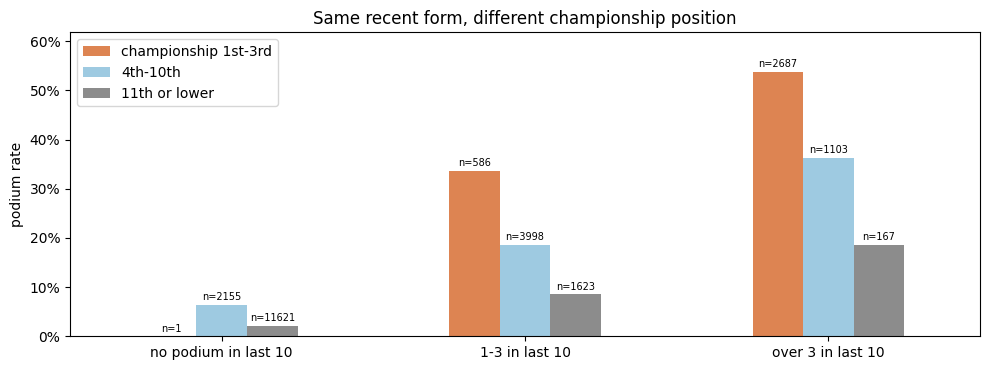

In [254]:
g = fe[model_rows & fe.champ_pos.notna() & fe.form_podium_rate.notna()]
print(f'overlap of champ_pos and form_podium_rate: Spearman {stats.spearmanr(g.champ_pos, g.form_podium_rate)[0]:.2f}')
form = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['no podium in last 10', '1-3 in last 10', 'over 3 in last 10'])
pos = pd.cut(g.champ_pos, [0, 3, 10, np.inf], labels=['championship 1st-3rd', '4th-10th', '11th or lower'])
tab = g.groupby([form, pos], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='form_podium_rate', columns='champ_pos', values='rate')
sizes = tab.pivot(index='form_podium_rate', columns='champ_pos', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#DD8452', '#9ecae1', '#8C8C8C'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=['' if pd.isna(n) else f'n={int(n)}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same recent form, different championship position')
ax.legend(title=''); plt.tight_layout(); plt.show()

**4d. Round 1: is last season's final position a good stand-in?** At round 1 there is no standing yet in the new season.

In [255]:
r1 = fe[model_rows & (fe['round'] == 1)]
print('round-1 starts:', len(r1), '| with last season\'s final position:', f'{r1.champ_pos.notna().mean():.0%}',
      f'| AUC of last season\'s final position at round 1: {auc(-r1.champ_pos, r1.podium):.3f}',
      f'| AUC of form at round 1: {auc(r1.form_podium_rate, r1.podium):.3f}')

round-1 starts: 1631 | with last season's final position: 84% | AUC of last season's final position at round 1: 0.805 | AUC of form at round 1: 0.789


### 5. Reading and decision

- **Coverage:** 96.3% of the model rows have a value: 88.0% from the previous round and 8.4% from last season's final position.
- **4a. Which number?** The championship position (AUC 0.842) and the points share (0.837) are about equally strong and say almost the same thing (Spearman −0.93), so only one is needed; the position is kept because it is simpler and comparable across eras without any conversion. The number of wins is clearly weaker (0.723, the win rate 0.725) and is already part of the points, so it is not used.
- **4b.** The championship position goes with the podium: 60.4% of the drivers leading the championship reach the podium, 50.1% in 2nd, 40.6% in 3rd, 31.5% in 4th–5th, 12.1% in 6th–10th and 3.1% from 11th or lower (AUC 0.841).
- **4c.** The standings overlap with form (Spearman −0.75) but add information: with the same recent form, a higher championship position still means more podiums. With 1–3 podiums in the last 10 starts, 33.8% of drivers in the top 3 of the championship reach the podium, against 18.6% in 4th–10th and 8.6% from 11th; with more than 3 it is 54.0%, 36.6% and 18.0%.
- **4d.** At round 1, last season's final position is available for 84% of the starts and works as a stand-in (AUC 0.805, slightly better than form at round 1, 0.789).

**Decision.** The standings group is `champ_pos`: the driver's championship position after the previous round, and at round 1 (or without a previous-round row) the final position of the previous season. The points share and the wins are not used. The 3.7% of model rows with no value (drivers in their first season with no previous-round row) are filled in preprocessing. The team's standings are left for the team group.

## 7.5 Team form

### 1. Hypothesis

Whether a driver reaches the podium depends mainly on two things: the driver and the car. Sections 7.3 and 7.4 describe the driver. This group describes the **car**: how strong the team has been recently, measured on both of its cars. It can differ from the driver's own record, for example for a new driver in a top team, or a driver whose own results suffered from bad luck while the teammate shows the car is fast.

### 2. Candidate features

Two ways of describing the team's strength:
- **The constructor standings** after the previous round: the team's championship `position`, or its **points share** (the team's points divided by the leader's points). As for the drivers, the number of wins is not tried again: it is part of the points.
- **Team form** (`team_form`): the share of the team's starts that ended on the podium over the team's last N races. Both cars of a race count, so a team with one podium from two cars in a race scores 50% for that race.

`constructor_results` (the team's points in each race) is not used as a separate source: its points are not comparable across eras, and the same races are already in `results`, where the team's points equal the sum of its drivers' points in about 97% of team-races (constructor_results section).

### 3. Valid at the cutoff

- **Only earlier races.** The constructor standings are taken from the previous round, like the driver standings. Team form looks at the team's races **before** the current one, ordered by `(year, round)`; both cars of a race enter the window together.
- **Renamed teams are separate constructors.** A new name usually comes with a new owner or a new car (constructors section, *is one constructorId one continuous team*), so each `constructorId` keeps its own history. A team's first races under a new name have no team form yet.
- **History restarts after a long break.** Some constructor ids cover separate periods, for example Mercedes in 1954–1955 and again from 2010 (constructors section). The team's history restarts after a break of five seasons or more, so Mercedes' first race in 2010 does not look back to 1955.
- Every entry counts except the drivers who failed to qualify and the Indianapolis 500, as for driver form.

In [256]:
team_races = (fe[model_rows].groupby(['constructorId', 'year', 'round', 'raceId'])
                .agg(cars=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
                .sort_values(['constructorId', 'year', 'round']))
gap = team_races.year - team_races.groupby('constructorId').year.shift(1)           # seasons since the team's previous race
team_races['period'] = (gap >= 5).groupby(team_races.constructorId).cumsum()        # a new period after a 5-season break
by_team = team_races.groupby(['constructorId', 'period'])

def team_past(n):
    """Podiums per car start over the team's previous n races (the current race is excluded by shift)."""
    pods = by_team.podiums.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    cars = by_team.cars.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    return pods / cars

team_races['team_form'] = team_past(10)
fe = fe.drop(columns=['team_form'], errors='ignore')                                # safe to rerun
fe = fe.merge(team_races[['raceId', 'constructorId', 'team_form']], on=['raceId', 'constructorId'], how='left', validate='m:1')

# leakage and break check: Mercedes in 2010, its first races after the 1955 period
merc = constructors.loc[constructors.name == 'Mercedes', 'constructorId'].iloc[0]
table(team_races[(team_races.constructorId == merc) & (team_races.year == 2010)].head(4)
      [['year', 'round', 'cars', 'podiums', 'team_form']], pct=['team_form'],
      caption='Mercedes, 2010: no team form at its first race (history restarted), then only earlier races count')
print('team-races that start a new period after a break of 5+ seasons:', int((gap >= 5).sum()),
      '| model rows with team_form:', f'{fe.loc[model_rows, "team_form"].notna().mean():.1%}')

year,round,cars,podiums,team_form
2010,1,2,0,–
2010,2,2,0,0%
2010,3,2,1,0%
2010,4,2,1,17%


team-races that start a new period after a break of 5+ seasons: 23 | model rows with team_form: 98.7%


### 4. Evidence

**4a. Constructor standings or team form?** The candidates are compared with the AUC. Team form is tried for N = 5, 10 and 20 races.

In [257]:
cstand = constructor_standings[['raceId', 'constructorId', 'position', 'points']].merge(
    races[['raceId', 'year', 'round']], on='raceId', how='left', validate='m:1')
cstand['points_share'] = cstand.points / cstand.groupby('raceId').points.transform('max').replace(0, np.nan)
cbefore = cstand.assign(round=cstand['round'] + 1)[['year', 'round', 'constructorId', 'position', 'points_share']]

tc = fe[model_rows][['year', 'round', 'raceId', 'constructorId', 'podium']].merge(
    cbefore, on=['year', 'round', 'constructorId'], how='left', validate='m:1')
for n in [5, 10, 20]:
    tc = tc.merge(team_races.assign(**{f'form_{n}': team_past(n)})[['raceId', 'constructorId', f'form_{n}']],
                  on=['raceId', 'constructorId'], how='left', validate='m:1')
rows = [{'candidate': 'team championship position (previous round)', 'AUC': auc(-tc.position, tc.podium), 'has a value': tc.position.notna().mean()},
        {'candidate': 'team points share (previous round)', 'AUC': auc(tc.points_share, tc.podium), 'has a value': tc.points_share.notna().mean()}]
rows += [{'candidate': f'team form, last {n} races', 'AUC': auc(tc[f'form_{n}'], tc.podium), 'has a value': tc[f'form_{n}'].notna().mean()} for n in [5, 10, 20]]
display(pd.DataFrame(rows).style.format({'AUC': '{:.3f}', 'has a value': '{:.0%}'}).hide(axis='index')
        .set_caption('The team: which description? (AUC, model rows)'))
both = tc[['form_10', 'points_share']].dropna()
print(f'overlap of team form (10) and team points share: Spearman {stats.spearmanr(both.form_10, both.points_share)[0]:.2f}')

# why the championship table can mislead: McLaren 2007, excluded from the constructors' championship
mcl = constructors.loc[constructors.name == 'McLaren', 'constructorId'].iloc[0]
end07 = cstand[(cstand.year == 2007) & (cstand['round'] == cstand[cstand.year == 2007]['round'].max())].sort_values('points', ascending=False)
print('2007 final constructor table, by points:', ', '.join(f"{constructors.set_index('constructorId').name[c]} {p:.0f} pts (position {int(pos)})"
      for c, p, pos in zip(end07.constructorId.head(3), end07.points.head(3), end07.position.head(3))))

candidate,AUC,has a value
team championship position (previous round),0.833,88%
team points share (previous round),0.841,88%
"team form, last 5 races",0.833,99%
"team form, last 10 races",0.845,99%
"team form, last 20 races",0.845,99%


overlap of team form (10) and team points share: Spearman 0.83
2007 final constructor table, by points: McLaren 218 pts (position 11), Ferrari 204 pts (position 1), BMW Sauber 101 pts (position 2)


**4b. `team_form`: does a strong team go with the podium?** The podium rate by the team's podium rate over its previous 10 races.

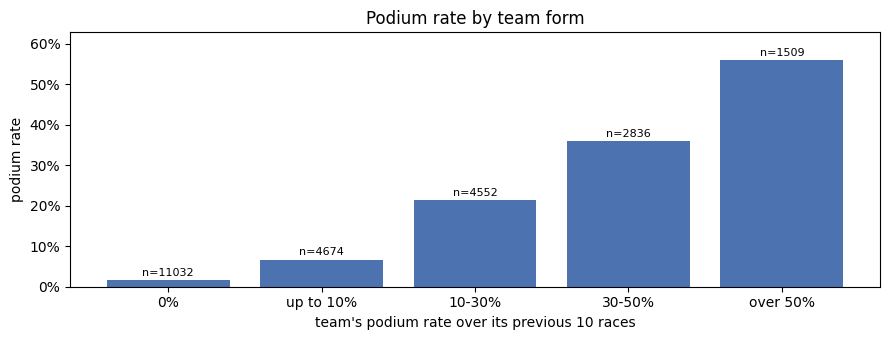

AUC of team_form: 0.845


In [258]:
g = fe[model_rows & fe.team_form.notna()]
levels = pd.cut(g.team_form, [-0.01, 0, 0.1, 0.3, 0.5, 1], labels=['0%', 'up to 10%', '10-30%', '30-50%', 'over 50%'])
by_team_form = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_team_form.index.astype(str), by_team_form['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_team_form['size'], by_team_form['mean'])):
    ax.text(i, r + 0.01, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_team_form['mean'].max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel="team's podium rate over its previous 10 races", ylabel='podium rate', title='Podium rate by team form')
plt.tight_layout(); plt.show()
print(f'AUC of team_form: {auc(g.team_form, g.podium):.3f}')

**4c. Does the team add anything once the driver's form is known?** Drivers with the **same recent form** are compared by the form of their team.

overlap of team_form and form_podium_rate: Spearman 0.79


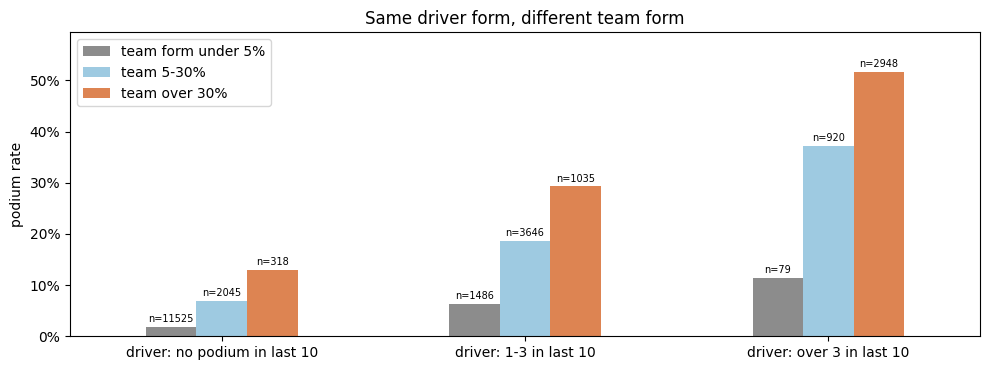

In [259]:
g = fe[model_rows & fe.team_form.notna() & fe.form_podium_rate.notna()]
print(f'overlap of team_form and form_podium_rate: Spearman {stats.spearmanr(g.team_form, g.form_podium_rate)[0]:.2f}')
dform = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['driver: no podium in last 10', 'driver: 1-3 in last 10', 'driver: over 3 in last 10'])
tform = pd.cut(g.team_form, [-0.01, 0.05, 0.3, 1], labels=['team form under 5%', 'team 5-30%', 'team over 30%'])
tab = g.groupby([dform, tform], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='form_podium_rate', columns='team_form', values='rate')
sizes = tab.pivot(index='form_podium_rate', columns='team_form', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#8C8C8C', '#9ecae1', '#DD8452'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same driver form, different team form')
ax.legend(title=''); plt.tight_layout(); plt.show()

### 5. Reading and decision

- **Coverage:** 98.7% of the model rows have a team form value. The ones without are a team's first race (or its first race after a break of five seasons or more, which happens 23 times).
- **4a. Standings or form?** The team's points share (AUC 0.841) and its team form over the last 10 races (0.845) are about equally strong and say much the same thing (Spearman 0.83), so only one is kept. Team form is chosen because it is slightly stronger, it has a value for 99% of the model rows against 88% for the standings (it carries over from one season to the next, so round 1 needs no stand-in, and it exists before the constructor standings start in 1958), and it is built from race results, so it is not misled by the championship table. McLaren in 2007 shows why since it scored the most points of any team (218, ahead of Ferrari's 204) but was excluded from the constructors' championship, so the standings place it 11th and last. The window of 10 races is chosen because it is as strong as 20 (both 0.845) and stronger than 5 (0.833).
- **4b.** A strong team goes with the podium: 1.7% of drivers in a team with no podium in its last 10 races reach the podium, against 6.8% (up to 10%), 21.1% (10–30%), 36.1% (30–50%) and 56.1% (over 50%) (AUC 0.845).
- **4c.** The team adds information beyond the driver. Team form and driver form overlap (Spearman 0.79), but with the same driver form a stronger team still means more podiums: for drivers with no podium in their last 10 starts, 1.8% in a weak team against 13.8% in a strong one; with 1–3 podiums, 6.3% against 29.5%; with more than 3, 12.3% against 51.6%.

**Decision.** The team group is `team_form`, which is the share of the team's starts that ended on the podium over its previous 10 races, with each renamed team as its own constructor and the history restarting after a break of five seasons or more. The constructor standings are not used. The value is missing for a team's first race and is filled in preprocessing.

## 7.6 Reliability

### 1. Hypothesis

A car that breaks down cannot reach the podium, however fast it is. Team form (7.5) already contains some of this, because a car that broke did not score a podium, but the two are not the same: a fast but fragile car has a high podium rate when it finishes and often does not finish, while a slow but reliable car rarely breaks and rarely reaches the podium.

Reliability changed a lot over the years: in the 1980s cars broke down very often, and by 2024 almost never (Q3: from 12% of starts in 2014 to 3% in 2024). A failure rate of 10% means an unreliable car in 2024 but an average one in the 1980s, so the team's rate may need to be compared with the rest of the field at the time.

### 2. Candidate features

A **mechanical failure** is a start that ended in the `mechanical (clear)` group of the status grouping (status section, *grouping the labels for the mechanical-retirement question*), the same definition as Q3. The grey zone (for example `Retired` with no reason given) is not counted.
- **Team failure rate:** the share of the team's starts that ended in a mechanical failure over its last N races (both cars), tried for N = 5, 10 and 20.
- **Relative to the field:** the team's rate minus the failure rate of **all** cars over the last N races of the calendar.
- **Driver failure rate** over the driver's last 10 starts, raw and relative, and the **driver crash rate** (`accident or collision` group) over the last 10 starts.

### 3. Valid at the cutoff

- **Only earlier races.** Like team form, the windows look at races **before** the current one, ordered by `(year, round)`; the field's rate uses the previous races of the calendar. The way a race ended is only known afterwards, so the current race is never part of its own window.
- **The same team rules as team form:** renamed teams are separate constructors, and the history restarts after a break of five seasons or more.
- Every entry counts except the drivers who failed to qualify and the Indianapolis 500, as for driver form.

In [260]:
group_of_status = status.set_index('statusId').group
fe = fe.drop(columns=['statusId', 'mech', 'crash', 'team_mech_rel'], errors='ignore')     # safe to rerun
fe = fe.merge(results_unique[['resultId', 'statusId']], on='resultId', how='left', validate='1:1')
fe['mech'] = (fe.statusId.map(group_of_status) == 'mechanical (clear)').astype(int)           # outcome of the race: never a feature
fe['crash'] = (fe.statusId.map(group_of_status) == 'accident or collision').astype(int)

starts = fe[model_rows]
team_rel = (starts.groupby(['constructorId', 'year', 'round', 'raceId'])
                  .agg(cars=('mech', 'size'), fails=('mech', 'sum')).reset_index()
                  .sort_values(['constructorId', 'year', 'round']))
team_gap = team_rel.year - team_rel.groupby('constructorId').year.shift(1)
team_rel['period'] = (team_gap >= 5).groupby(team_rel.constructorId).cumsum()       # same restart rule as team form
by_team_rel = team_rel.groupby(['constructorId', 'period'])

field = (starts.groupby(['year', 'round', 'raceId']).agg(cars=('mech', 'size'), fails=('mech', 'sum'))
               .reset_index().sort_values(['year', 'round']))

def team_fail(n):
    """Mechanical failures per car start over the team's previous n races."""
    f = by_team_rel.fails.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    c = by_team_rel.cars.transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())
    return f / c

def field_fail(n):
    """Mechanical failures per car start over all cars in the previous n races of the calendar."""
    return (field.fails.shift(1).rolling(n, min_periods=1).sum() / field.cars.shift(1).rolling(n, min_periods=1).sum())

team_rel = team_rel.merge(field.assign(field_20=field_fail(20))[['raceId', 'field_20']], on='raceId', how='left')
team_rel['team_20'] = team_fail(20)
team_rel['team_mech_rel'] = team_rel.team_20 - team_rel.field_20
fe = fe.merge(team_rel[['raceId', 'constructorId', 'team_mech_rel']], on=['raceId', 'constructorId'], how='left', validate='m:1')

# example: McLaren at the start of 2016; its previous 20 races cover the 2015 season
mcl = constructors.loc[constructors.name == 'McLaren', 'constructorId'].iloc[0]
table(team_rel[(team_rel.constructorId == mcl) & (team_rel.year == 2016)].head(4)
      [['year', 'round', 'cars', 'fails', 'team_20', 'field_20', 'team_mech_rel']],
      pct1=['team_20', 'field_20', 'team_mech_rel'],
      caption='McLaren, start of 2016: its failure rate over the previous 20 races (mostly 2015) against the field (positive = fails more often)')
print('model rows with team_mech_rel:', f'{fe.loc[model_rows, "team_mech_rel"].notna().mean():.1%}')

year,round,cars,fails,team_20,field_20,team_mech_rel
2016,1,2,0,20.0%,10.3%,9.7%
2016,2,2,1,20.0%,10.5%,9.5%
2016,3,2,0,22.5%,10.6%,11.9%
2016,4,2,0,17.5%,9.9%,7.6%


model rows with team_mech_rel: 98.7%


### 4. Evidence

**4a. Which version?** The candidates are compared with the AUC. A failure rate is better when it is **lower**, so the rates are entered with a minus sign.

In [261]:
tc = fe[model_rows][['raceId', 'constructorId', 'driverId', 'year', 'round', 'podium', 'mech', 'crash']]
for n in [5, 10, 20]:
    t = team_rel[['raceId', 'constructorId']].assign(**{f'team_{n}': team_fail(n)})
    t = t.merge(field.assign(**{f'field_{n}': field_fail(n)})[['raceId', f'field_{n}']], on='raceId')
    tc = tc.merge(t, on=['raceId', 'constructorId'], how='left', validate='m:1')
tc = tc.sort_values(['driverId', 'year', 'round'])
by_drv = tc.groupby('driverId')
tc['driver_10'] = by_drv.mech.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
tc['crash_10'] = by_drv.crash.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())

rows = [{'candidate': f'team failure rate, last {n} races', 'AUC raw': auc(-tc[f'team_{n}'], tc.podium),
         'AUC relative to the field': auc(-(tc[f'team_{n}'] - tc[f'field_{n}']), tc.podium)} for n in [5, 10, 20]]
rows += [{'candidate': 'driver failure rate, last 10 starts', 'AUC raw': auc(-tc.driver_10, tc.podium),
          'AUC relative to the field': auc(-(tc.driver_10 - tc.field_10), tc.podium)},
         {'candidate': 'driver crash rate, last 10 starts', 'AUC raw': auc(-tc.crash_10, tc.podium), 'AUC relative to the field': np.nan}]
display(pd.DataFrame(rows).style.format({'AUC raw': '{:.3f}', 'AUC relative to the field': '{:.3f}'}, na_rep='–')
        .hide(axis='index').set_caption('Reliability: which version? (AUC, model rows)'))
both = tc[['team_10', 'driver_10']].dropna()
print(f'overlap of the team and the driver failure rate (last 10): Spearman {stats.spearmanr(both.team_10, both.driver_10)[0]:.2f}')

candidate,AUC raw,AUC relative to the field
"team failure rate, last 5 races",0.605,0.630
"team failure rate, last 10 races",0.611,0.651
"team failure rate, last 20 races",0.615,0.668
"driver failure rate, last 10 starts",0.588,0.612
"driver crash rate, last 10 starts",0.568,–


overlap of the team and the driver failure rate (last 10): Spearman 0.75


**4b. `team_mech_rel`: do teams that break down more often than the field reach the podium less?** The podium rate by the team's failure rate relative to the field (last 20 races).

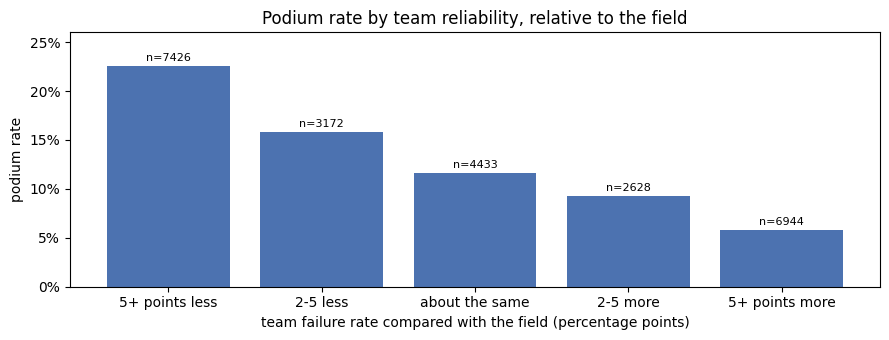

AUC of team_mech_rel: 0.668


In [262]:
g = fe[model_rows & fe.team_mech_rel.notna()]
levels = pd.cut(g.team_mech_rel, [-1, -0.05, -0.02, 0.02, 0.05, 1],
                labels=['5+ points less', '2-5 less', 'about the same', '2-5 more', '5+ points more'])
by_rel = g.groupby(levels, observed=True).podium.agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_rel.index.astype(str), by_rel['mean'], color='#4C72B0')
for i, (n, r) in enumerate(zip(by_rel['size'], by_rel['mean'])):
    ax.text(i, r + 0.005, f'n={n}', ha='center', fontsize=8)
ax.set_ylim(0, by_rel['mean'].max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='team failure rate compared with the field (percentage points)', ylabel='podium rate',
       title='Podium rate by team reliability, relative to the field')
plt.tight_layout(); plt.show()
print(f'AUC of team_mech_rel: {auc(-g.team_mech_rel, g.podium):.3f}')

**4c. Does reliability add anything once team form is known?** Teams with the **same team form** are compared by their reliability.

overlap of team_mech_rel and team_form: Spearman -0.40


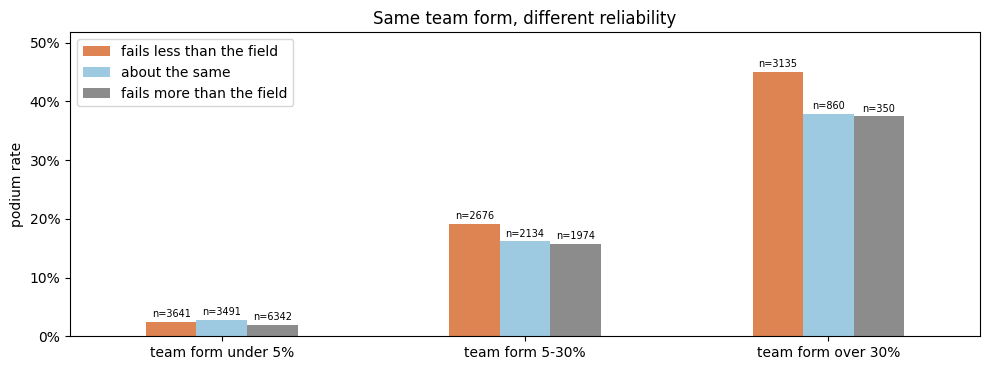

In [263]:
g = fe[model_rows & fe.team_mech_rel.notna() & fe.team_form.notna()]
print(f'overlap of team_mech_rel and team_form: Spearman {stats.spearmanr(g.team_mech_rel, g.team_form)[0]:.2f}')
tform = pd.cut(g.team_form, [-0.01, 0.05, 0.3, 1], labels=['team form under 5%', 'team form 5-30%', 'team form over 30%'])
rel = pd.cut(g.team_mech_rel, [-1, -0.03, 0.03, 1], labels=['fails less than the field', 'about the same', 'fails more than the field'])
tab = g.groupby([tform, rel], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='team_form', columns='team_mech_rel', values='rate')
sizes = tab.pivot(index='team_form', columns='team_mech_rel', values='starts')

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#DD8452', '#9ecae1', '#8C8C8C'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same team form, different reliability')
ax.legend(title=''); plt.tight_layout(); plt.show()

### 5. Reading and decision

- **Coverage:** 98.7% of the model rows have a value; the others are a team's first race (or its first race after a long break).
- **4a. Which version?** Reliability is much weaker on its own than the other groups (AUC about 0.6–0.67 against 0.84 for team form): a breakdown is only one of many ways to miss the podium. Comparing the team with the field always helps (0.651 against 0.611 at N = 10), which confirms that raw failure rates mean different things in different eras. The longest window is the strongest (0.668 for 20 races), because failures are rare and a short window holds only a few of them. The driver's own failure rate is weaker (0.612 relative) and mostly repeats the team's (Spearman 0.75), and the crash rate is weak (0.568), so the driver-level versions are not used.
- **4b.** Teams that break down less than the field reach the podium more often: 22.6% when the team fails at least 5 percentage points less often than the field, 11.6% when it is about the same, and 5.8% when it fails at least 5 points more often (AUC 0.668).
- **4c.** Reliability overlaps only partly with team form (Spearman −0.40) and adds a little for the stronger teams: with team form over 30%, 45.2% of drivers in a team that fails less than the field reach the podium, against 36.8% in a team that fails more; with team form of 5–30%, 18.9% against 15.9%. For weak teams it makes no difference (2.5% against 2.0%).

**Decision.** The reliability group is `team_mech_rel`: the team's mechanical-failure rate over its previous 20 races minus the failure rate of all cars over the previous 20 races of the calendar, with the same team rules as team form. It is weak on its own and adds only a little beyond team form, so the ablation will show whether it is worth keeping in the model. The value is missing for a team's first race and is filled in preprocessing. The columns `mech` and `crash` describe how the race ended and are only used to build this feature; they are never model inputs.

## 7.7 Circuit history (tested, not used)

### 1. Hypothesis

Some drivers suit some circuits. A driver who has reached the podium at a circuit before may do so again there, beyond what their general form says.

### 2. Candidate features

The driver's record at **this circuit** in their previous visits: the podium rate over all past visits, the podium rate over the last 3 visits, the finishing position at the last visit, and whether the last visit ended on the podium.

### 3. Valid at the cutoff

Only the driver's earlier starts at the same circuit (`circuitId`) count, ordered by `(year, round)`; the race itself is never included. Every entry counts except failed qualifications and the Indianapolis 500, as for driver form. A driver's first visit to a circuit has no history.

### 4. Evidence

In [264]:
ch = fe[model_rows][['driverId', 'circuitId', 'year', 'round', 'podium', 'positionOrder', 'form_podium_rate']].sort_values(['driverId', 'year', 'round'])
by_visit = ch.groupby(['driverId', 'circuitId'])
ch['rate_all'] = by_visit.podium.transform(lambda s: s.shift(1).expanding().mean())
ch['rate_last3'] = by_visit.podium.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
ch['last_finish'] = by_visit.positionOrder.shift(1)
ch['last_podium'] = by_visit.podium.shift(1)

display(pd.DataFrame([
    {'candidate': 'podium rate here, all past visits', 'AUC': auc(ch.rate_all, ch.podium)},
    {'candidate': 'podium rate here, last 3 visits', 'AUC': auc(ch.rate_last3, ch.podium)},
    {'candidate': 'finishing position last time here', 'AUC': auc(-ch.last_finish, ch.podium)},     # minus: a smaller position is better
    {'candidate': 'podium last time here', 'AUC': auc(ch.last_podium, ch.podium)},
]).style.format({'AUC': '{:.3f}'}).hide(axis='index').set_caption('Circuit history: which version? (AUC, rows with a past visit)'))
both = ch[['rate_all', 'form_podium_rate']].dropna()
print(f"model rows with a past visit to the circuit: {ch.last_finish.notna().mean():.0%} | "
      f"overlap with driver form: Spearman {stats.spearmanr(both.rate_all, both.form_podium_rate)[0]:.2f}")

# does it add anything once driver form is known?
g = ch.dropna(subset=['rate_all', 'form_podium_rate'])
form = pd.cut(g.form_podium_rate, [-0.01, 0, 0.3, 1], labels=['no podium in last 10', '1-3 in last 10', 'over 3 in last 10'])
here = pd.cut(g.rate_all, [-0.01, 0, 0.5, 1], labels=['never on the podium here', 'up to half the visits', 'over half the visits'])
tab = g.groupby([form, here], observed=True).podium.mean().unstack()
display(tab.rename_axis(index='driver form', columns='podium rate at this circuit before')
           .style.format('{:.1%}').set_caption('Podium rate: same driver form, different record at this circuit'))

candidate,AUC
"podium rate here, all past visits",0.672
"podium rate here, last 3 visits",0.669
finishing position last time here,0.656
podium last time here,0.623


model rows with a past visit to the circuit: 70% | overlap with driver form: Spearman 0.45


podium rate at this circuit before,never on the podium here,up to half the visits,over half the visits
driver form,,,
no podium in last 10,3.0%,4.6%,8.1%
1-3 in last 10,15.5%,20.8%,24.9%
over 3 in last 10,41.1%,48.6%,53.5%


### 5. Reading and decision

- The podium rate over all past visits is the strongest version (AUC 0.672); the last result alone is noisier (0.656 for the finishing position, 0.623 for the podium), because a single race can end in a crash or a breakdown.
- It is much weaker than the main groups (driver form 0.838), and only 70% of the model rows have a past visit to the circuit: every first visit is missing.
- It overlaps only partly with driver form (Spearman 0.45) and adds a little beyond it: with more than 3 podiums in the last 10 starts, drivers who were on the podium in over half their visits to the circuit reach it 53.5% of the time, against 41.1% for drivers who never were.

**Decision.** Circuit history is **not used**. Its gain beyond driver form is small, and it would leave 30% of the rows to be filled in preprocessing. Reliability (7.6) is about as strong on its own but is kept, because it describes the team, which matters more for the podium than the circuit, and it has a value for 99% of the rows. The trial is kept here, as the brief asks.

## 7.8 Pace

### 1. Hypothesis

Driver form and team form only see how a race ended: a podium or not. A driver who was fast but crashed or broke down scores nothing there. Lap times show the **speed** in every race, also in races that ended badly, so a driver's recent race pace may add something the result-based features miss.

### 2. Candidate feature

`pace_form`: the driver's typical lap in each race, compared with the rest of the field, averaged over the previous 10 starts. The typical lap of a driver in a race is the **median** of their relative lap times, where each lap is divided by the median lap of that race (lap_times section, *extreme laps and why circuits cannot be compared*). The median ignores the few laps slowed by a pit stop, lap 1 or a red flag. Below 1 means faster than the typical lap of the race.

### 3. Valid at the cutoff

- Only the driver's **earlier** starts count, ordered by `(year, round)`; the race itself is never included.
- Dividing by the median lap of the same race compares the driver with the same cars, track and weather, so races at different circuits become comparable.
- The 19 driver-races flagged `laps_mismatch` in cleaning are skipped.
- **A race only counts if the driver completed at least 10 laps.** With only 1 or 2 laps, the "typical lap" is just lap 1 (a standing start) or a lap with a red flag, so the value is meaningless. For example, Stroll retired after 2 laps at Bahrain 2020, and one of them included the 22-minute stop after Grosjean's fire; his race pace came out as 7.8, nearly 8 times the typical lap. The next code cell shows how the race pace depends on the number of laps completed.
- **Coverage:** lap times only exist from 1996, so the feature is missing before that.

In [265]:
MIN_LAPS = 10                                                            # fewer laps: no typical lap to measure
per_race = (laps[~laps.laps_mismatch].groupby(['raceId', 'driverId'])
                .agg(laps_done=('relative', 'size'), race_pace=('relative', 'median')).reset_index())

# why the minimum: with few laps the median is lap 1 or a red-flag lap
by_laps = pd.cut(per_race.laps_done, [0, 2, 4, 9, 19, np.inf], labels=['1-2', '3-4', '5-9', '10-19', '20 or more'])
display(per_race.groupby(by_laps, observed=True).race_pace.describe(percentiles=[0.5, 0.99])[['count', '50%', '99%', 'max']]
        .rename(columns={'count': 'driver-races', '50%': 'median', '99%': 'worst 1%'}).rename_axis('laps completed')
        .style.format('{:.2f}').format('{:.0f}', subset=['driver-races']).set_caption('Race pace by the number of laps completed'))
print(f'driver-races with fewer than {MIN_LAPS} laps, not used:', int((per_race.laps_done < MIN_LAPS).sum()), 'of', len(per_race))

race_pace = per_race.loc[per_race.laps_done >= MIN_LAPS, ['raceId', 'driverId', 'race_pace']]   # the driver's typical relative lap in a race
fe = fe.drop(columns=['race_pace', 'pace_form'], errors='ignore')        # safe to rerun
fe = fe.merge(race_pace, on=['raceId', 'driverId'], how='left', validate='1:1')    # outcome of the race: never a feature

hist = fe[model_rows].sort_values(['driverId', 'year', 'round'])
fe.loc[hist.index, 'pace_form'] = (hist.groupby('driverId').race_pace
                                       .transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean()))

g = fe[model_rows]
print('model rows with pace_form:', f'{g.pace_form.notna().mean():.0%}',
      '| from 1997 on:', f'{g[g.year >= 1997].pace_form.notna().mean():.0%}',
      '| before 1996:', f'{g[g.year < 1996].pace_form.notna().mean():.0%}')

,driver-races,median,worst 1%,max
laps completed,,,,
1-2,173,1.17,4.41,7.78
3-4,60,1.08,1.93,2.27
5-9,235,1.03,1.61,1.70
10-19,376,1.02,1.46,1.68
20 or more,10178,1.00,1.05,1.35


driver-races with fewer than 10 laps, not used: 468 of 11022
model rows with pace_form: 45% | from 1997 on: 99% | before 1996: 0%


### 4. Evidence

**4a. Strength and overlap.** The AUC on the rows that have a pace value (from 1996), next to driver form and team form on the same rows. A smaller pace value is faster, so it is entered with a minus sign.

In [266]:
g = fe[model_rows & fe.pace_form.notna()]
print(f'AUC on these rows: pace_form {auc(-g.pace_form, g.podium):.3f} | form_podium_rate {auc(g.form_podium_rate, g.podium):.3f} '
      f'| team_form {auc(g.team_form, g.podium):.3f}')
for col in ['form_podium_rate', 'team_form']:
    both = g[['pace_form', col]].dropna()
    print(f'overlap of pace_form and {col}: Spearman {stats.spearmanr(both.pace_form, both[col])[0]:.2f}')

AUC on these rows: pace_form 0.858 | form_podium_rate 0.871 | team_form 0.880
overlap of pace_form and form_podium_rate: Spearman -0.74
overlap of pace_form and team_form: Spearman -0.74


**4b. Does pace add anything once driver form and team form are known?** The drivers are split into three groups by their form and their team's form; inside each group they are split into thirds by their past pace.

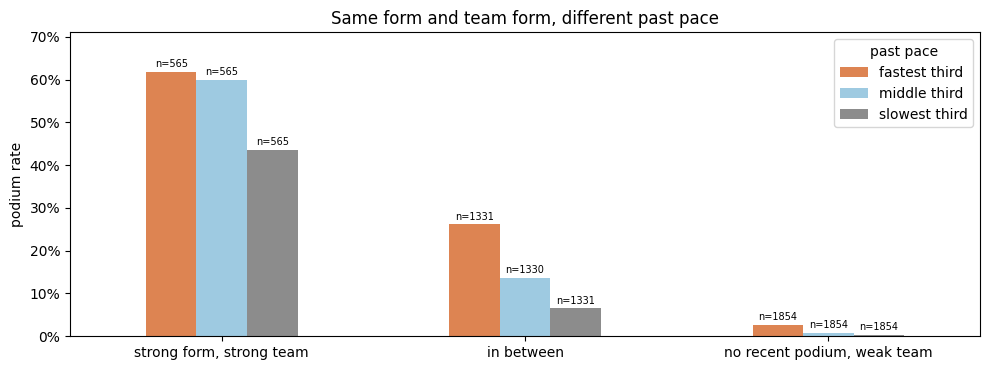

pace,fastest third,middle third,slowest third
group,,,
"strong form, strong team",61.8%,60.0%,43.5%
in between,26.1%,13.7%,6.5%
"no recent podium, weak team",2.8%,0.8%,0.4%


In [267]:
g = fe[model_rows].dropna(subset=['pace_form', 'form_podium_rate', 'team_form'])
grp = np.select([(g.form_podium_rate > 0.3) & (g.team_form > 0.3), (g.form_podium_rate == 0) & (g.team_form < 0.05)],
                ['strong form, strong team', 'no recent podium, weak team'], default='in between')
third = g.groupby(grp).pace_form.transform(lambda s: pd.qcut(s, 3, labels=['fastest third', 'middle third', 'slowest third']))
tab = g.assign(group=grp, pace=third).groupby(['group', 'pace'], observed=True).podium.agg(starts='size', rate='mean').reset_index()
rates = tab.pivot(index='group', columns='pace', values='rate').loc[['strong form, strong team', 'in between', 'no recent podium, weak team']]
sizes = tab.pivot(index='group', columns='pace', values='starts').loc[rates.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
rates.plot.bar(ax=ax, rot=0, color=['#DD8452', '#9ecae1', '#8C8C8C'])
for container, col in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f'n={n}' for n in sizes[col]], fontsize=7, padding=2)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='', ylabel='podium rate', title='Same form and team form, different past pace')
ax.legend(title='past pace'); plt.tight_layout(); plt.show()
display(rates.style.format('{:.1%}').set_caption('Podium rate by group and past pace'))

### 5. Reading and decision

- **Coverage:** 45% of all model rows have a pace value, because lap times start in 1996; from 1997 on, 99% have one.
- **4a.** On the rows that have it, pace is strong on its own (AUC 0.858; driver form 0.871 and team form 0.880 on the same rows) and overlaps with both only partly (Spearman −0.74 with each).
- **4b.** Pace adds clear information beyond driver form and team form. Among drivers in strong form in a strong team, the fastest third reach the podium 61.8% of the time against 43.5% for the slowest third; in the middle group it is 26.1% against 6.5%. Pace shows how fast a driver was even in races that ended in a crash or a breakdown, which the result-based features cannot see.

**Decision.** `pace_form` is kept as a **candidate**. It is strong and adds information, but it only exists from 1996, so whether it stays depends on the training seasons chosen with the split: if training starts in 1997 or later, it has a value for almost every row; if it starts earlier, it would be missing for most of the older seasons. Training then starts in 2003 (8.1), and the ablation keeps it (10.7). The column `race_pace` describes the race itself and is only used to build this feature; it is never a model input.

## 7.9 Sprints (tested, not used)

**Hypothesis.** On a sprint weekend, the result of the Saturday sprint shows how fast a car is in race conditions, one day before the race.

**What the data allows.** There are 18 sprint weekends, from 2021 to 2024 (sprint_results section). In 2021 and 2022 the sprint result **set** the Sunday grid, so on those weekends the grid already contains it. From 2023 the Sunday grid comes from the normal qualifying, so only the 12 sprint weekends of 2023–2024 can show whether the sprint adds anything beyond the grid. The sprint is held the day before the race, so it would be valid at the cutoff.

In [268]:
spr = sprint_results[['raceId', 'driverId', 'positionOrder']].rename(columns={'positionOrder': 'sprint_pos'})
sw = fe[model_rows].merge(spr, on=['raceId', 'driverId'], how='left', validate='1:1')
print(f'model rows with a sprint result: {sw.sprint_pos.notna().mean():.1%}')

a = sw[sw.sprint_pos.notna() & sw.year.between(2021, 2022)]
print(f'2021-2022 (the sprint set the grid): Spearman correlation between sprint position and Sunday grid {stats.spearmanr(a.sprint_pos, a.grid_clean)[0]:.2f}')

b = sw[sw.sprint_pos.notna() & (sw.year >= 2023)]
print(f'2023-2024: {len(b)} starts, {int(b.podium.sum())} podiums | Spearman sprint position vs grid {stats.spearmanr(b.sprint_pos, b.grid_clean)[0]:.2f}')
area = pd.cut(b.grid_clean, [0, 3, 10, np.inf], labels=['starts P1-3', 'starts P4-10', 'starts P11 or further back'])
sprint = pd.Series(np.where(b.sprint_pos <= 3, 'sprint top 3', 'sprint 4th or lower'), index=b.index, name='sprint result')
table(b.groupby([area.rename('starting area'), sprint], observed=True).podium.agg(starts='size', podium_rate='mean')
       .reset_index().rename(columns={'podium_rate': 'podium rate'}),
      pct=['podium rate'], caption='2023-2024 sprint weekends: same starting area, different sprint result')

model rows with a sprint result: 1.4%
2021-2022 (the sprint set the grid): Spearman correlation between sprint position and Sunday grid 0.93
2023-2024: 240 starts, 36 podiums | Spearman sprint position vs grid 0.59


starting area,sprint result,starts,podium rate
starts P1-3,sprint 4th or lower,15,40%
starts P1-3,sprint top 3,21,57%
starts P4-10,sprint 4th or lower,72,11%
starts P4-10,sprint top 3,12,58%
starts P11 or further back,sprint 4th or lower,117,2%
starts P11 or further back,sprint top 3,3,33%


**Reading and decision.**
- Only 1.4% of the model rows have a sprint result.
- In 2021–2022 the sprint position and the Sunday grid are almost the same (Spearman 0.93), because the sprint set the grid.
- In 2023–2024 the sprint is separate from the grid (Spearman 0.59). The table suggests it may add something: from P4–10, drivers who finished the sprint in the top 3 reached the podium 58% of the time, against 11% for the others. But there are only 240 starts and 36 podiums, and the groups with a sprint top 3 hold between 3 and 21 drivers, so this cannot be relied on.

The sprint result is **not used**: in 2021–2022 it is the grid itself, from 2023 there are far too few sprint weekends to measure its effect, and it would be missing for 98.6% of the rows.

## 7.10 Summary of the features

The table lists every feature that goes forward, with the evidence behind it. The AUC is measured on the model rows that have a value (`grid_minus_quali` only helps together with `grid_clean`, see 7.2). Features that were tested and not used: `pit_lane_start`, `quali_pos`, the average finish, the standings points share and wins, the constructor standings, the driver-level reliability rates, circuit history and the sprint result.

In [269]:
FEATURES = {
    'grid_clean':       ('grid',             'starting slot, pit-lane starters at the back',          'the grid is fixed before the start', -1),
    'grid_minus_quali': ('qualifying',       'grid slot minus qualifying position',                  'qualifying is before the race', 1),
    'quali_gap_pct':    ('qualifying',       'gap to the fastest Q1 lap, in %',                       'qualifying is before the race', -1),
    'form_podium_rate': ('driver form',      'podium rate over the previous 10 starts',               'earlier starts only', 1),
    'career_starts':    ('driver form',      'starts before this race',                               'earlier starts only', 1),
    'champ_pos':        ('driver standings', 'championship position after the previous round',        'previous round; round 1: last season', -1),
    'team_form':        ('team form',        "team's podium rate over its previous 10 races",         'earlier races only', 1),
    'team_mech_rel':    ('reliability',      "team's failure rate minus the field's, previous 20 races", 'earlier races only', -1),
    'pace_form':        ('pace (candidate)', 'relative lap pace over the previous 10 starts',         'earlier starts only', -1),
}
g = fe[model_rows]
display(pd.DataFrame([{'group': grp, 'feature': f, 'what it is': what, 'why valid before the race': why,
                       'AUC': auc(sign * g[f].astype(float), g.podium), 'has a value': g[f].notna().mean()}
                      for f, (grp, what, why, sign) in FEATURES.items()])
        .style.format({'AUC': '{:.3f}', 'has a value': '{:.0%}'}).hide(axis='index').set_caption('The features that go forward'))

group,feature,what it is,why valid before the race,AUC,has a value
grid,grid_clean,"starting slot, pit-lane starters at the back",the grid is fixed before the start,0.887,100%
qualifying,grid_minus_quali,grid slot minus qualifying position,qualifying is before the race,0.541,42%
qualifying,quali_gap_pct,"gap to the fastest Q1 lap, in %",qualifying is before the race,0.826,41%
driver form,form_podium_rate,podium rate over the previous 10 starts,earlier starts only,0.838,97%
driver form,career_starts,starts before this race,earlier starts only,0.661,100%
driver standings,champ_pos,championship position after the previous round,previous round; round 1: last season,0.841,96%
team form,team_form,team's podium rate over its previous 10 races,earlier races only,0.845,99%
reliability,team_mech_rel,"team's failure rate minus the field's, previous 20 races",earlier races only,0.668,99%
pace (candidate),pace_form,relative lap pace over the previous 10 starts,earlier starts only,0.858,45%


**How each feature is calculated.** "Previous" always means races before the one being predicted, ordered by season and round. The current race is left out with `shift(1)`, so no value uses the race's own result. All history features count every entry except failed qualifications and the Indianapolis 500 (the model rows).

- **`grid_clean`** (7.1): the grid slot from `results`. Pit-lane starters (`grid` = 0 but laps run) are put at the back: the highest grid slot of that race + 1.
- **`grid_minus_quali`** (7.2): `grid_clean` − qualifying position. 0 = started where they qualified; positive = moved back (penalty or pit-lane start); negative = moved up. Missing when there is no qualifying row.
- **`quali_gap_pct`** (7.2): (driver's Q1 time ÷ fastest Q1 time of that race − 1) × 100. 0 = fastest in Q1; 1.5 = 1.5% slower. Missing when there is no qualifying row or no Q1 time.
- **`form_podium_rate`** (7.3): podiums ÷ starts over the driver's previous 10 starts (fewer if the driver has made fewer than 10). Example: 3 podiums in the last 10 starts = 30%. Missing at a driver's first start.
- **`career_starts`** (7.3): the number of starts the driver made before this race. 0 at the first start, never missing.
- **`champ_pos`** (7.4): the driver's championship position after the previous round of the same season (from `driver_standings`). At round 1, or if the driver has no standing yet, the final position of last season is used. Missing for a driver with neither (usually a new driver early in their first season).
- **`team_form`** (7.5): podiums ÷ car starts of the team over its previous 10 races. Example: 5 podiums from 20 car starts = 25%. If the team was away for 5 or more seasons, its history starts again. Missing at the team's first race.
- **`team_mech_rel`** (7.6): team failure rate − field failure rate, both over the previous 20 races. The team rate is clear mechanical failures ÷ the team's car starts; the field rate is the same for all cars. Example: team 7.5%, field 6.0% → +1.5 points, so the team breaks down more than normal for its time. Same restart rule as `team_form`. Missing at the team's first race.
- **`pace_form`** (7.8, candidate): every lap time is divided by the median lap time of its race (1.00 = a typical lap). The driver's pace in a race is the median of their relative laps; `pace_form` is the mean of that over the driver's previous 10 starts. Lower = faster. Missing before 1996 (no lap times) and at a driver's first start.

**Two extra features for a start before 2003.** Before 2003 the qualifying and pace features are missing because the data does not exist, not because of something about the driver. If the training seasons start earlier, two yes/no features are added so the model can tell a filled value from a real one.
- **`has_quali_data`**: 1 if the race has qualifying data in the `qualifying` table, 0 if it has none. It is 0 for every race before 1994 and for many races in 1996–2002.
- **`has_pace_data`**: 1 if the race has lap times in the `lap_times` table, 0 if it has none. It is 0 for every race before 1996.

Both are known before the race, because they only say which data the race has. A driver who misses a value for a personal reason (a first start, no Q1 time) still gets 1, so the flag only marks the seasons without data.

In [270]:
# the two extra features for a start before 2003: does the race have qualifying data, and lap times?
FLAGS = ['has_quali_data', 'has_pace_data']
quali_t = load('qualifying')
fe['has_quali_data'] = fe.raceId.isin(quali_t.raceId).astype(int)
fe['has_pace_data'] = fe.raceId.isin(load('lap_times').raceId).astype(int)

# is qualifying data missing for whole races, or only for some drivers of a race?
g = fe[model_rows]
in_quali = g[['year', 'raceId', 'driverId']].merge(quali_t[['raceId', 'driverId']].drop_duplicates().assign(in_quali=1),
                                                  on=['raceId', 'driverId'], how='left').fillna({'in_quali': 0})
per_race = in_quali.groupby(['year', 'raceId']).in_quali.mean()
cover = per_race.groupby('year').agg(**{'races': 'size',
                                        'races with no qualifying row': lambda s: int((s == 0).sum()),
                                        'races with some drivers missing': lambda s: int(((s > 0) & (s < 1)).sum()),
                                        'races with every driver': lambda s: int((s == 1).sum())})
cover['races with lap times'] = g[g.has_pace_data == 1].groupby('year').raceId.nunique().reindex(cover.index).fillna(0).astype(int)
table(cover.loc[1990:2004].reset_index(), caption='Qualifying data and lap times per race, 1990-2004')

year,races,races with no qualifying row,races with some drivers missing,races with every driver,races with lap times
1990,16,16,0,0,0
1991,16,16,0,0,0
1992,16,16,0,0,0
1993,16,16,0,0,0
1994,16,1,1,14,0
1995,17,0,0,17,0
1996,16,9,0,7,16
1997,17,7,0,10,17
1998,16,9,0,7,16
1999,16,13,0,3,16


**Reading.** Qualifying data is missing for **whole races**, not for single drivers. In 1996–2002, between 7 and 16 races of each season have no qualifying row at all, and every other race has a row for every driver. The only exception is one race in 1994 in which one driver has no row. So `has_quali_data` is set per race. Lap times exist for every race from 1996 and for none before, so `has_pace_data` is 0 for every race before 1996 and 1 after.

### Which seasons each feature covers

The chart shows, for every season, the share of the model rows that have a value for each feature (dark = complete). The table gives the first season from which each feature stays complete (at least 95% of the rows in every later season). This is what limits the first season of the training data.

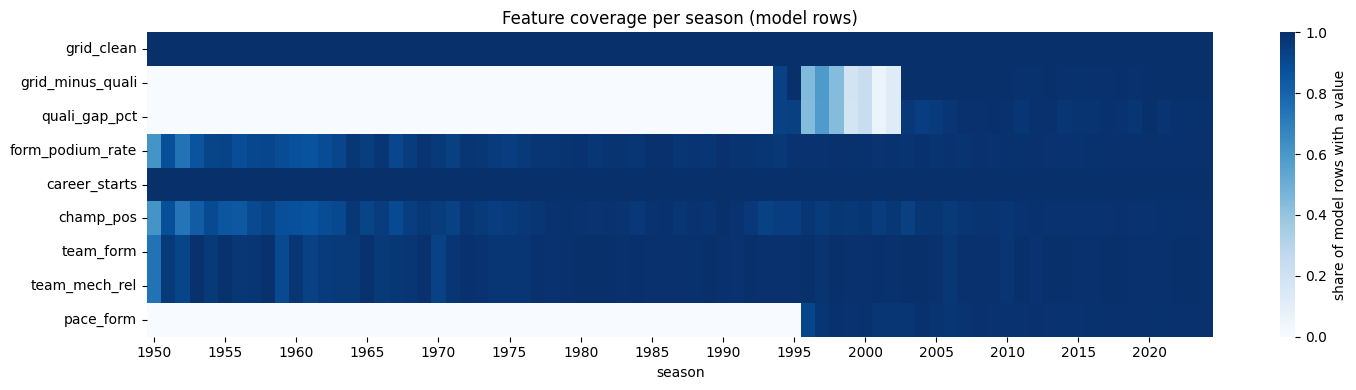

feature,group,complete from (95%+ every later season)
grid_clean,grid,1950
grid_minus_quali,qualifying,2003
quali_gap_pct,qualifying,2005
form_podium_rate,driver form,1976
career_starts,driver form,1950
champ_pos,driver standings,2004
team_form,team form,1971
team_mech_rel,reliability,1971
pace_form,pace (candidate),1997


year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007
grid_minus_quali,94%,100%,45%,59%,44%,19%,24%,6%,12%,100%,100%,100%,100%,100%
quali_gap_pct,94%,94%,44%,59%,44%,18%,24%,6%,12%,97%,94%,95%,98%,99%
champ_pos,95%,94%,98%,95%,97%,97%,98%,95%,97%,94%,98%,98%,96%,98%
pace_form,0%,0%,91%,98%,99%,99%,99%,98%,98%,98%,99%,98%,98%,98%


In [271]:
cov = g.groupby('year')[list(FEATURES)].apply(lambda d: d.notna().mean()).T

fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(cov, cmap='Blues', vmin=0, vmax=1, xticklabels=5, cbar_kws={'label': 'share of model rows with a value'}, ax=ax)
ax.set(xlabel='season', ylabel='', title='Feature coverage per season (model rows)')
plt.tight_layout(); plt.show()

def complete_from(row, level=0.95):
    """First season from which the coverage stays at or above `level` in every later season."""
    ok = row >= level
    later_all_ok = ok[::-1].cummin()[::-1]
    return int(later_all_ok.idxmax()) if later_all_ok.any() else None

table(pd.DataFrame({'feature': cov.index, 'group': [FEATURES[f][0] for f in cov.index],
                    'complete from (95%+ every later season)': [complete_from(cov.loc[f]) for f in cov.index]}),
      caption='First season each feature is complete')

display(cov.loc[['grid_minus_quali', 'quali_gap_pct', 'champ_pos', 'pace_form'], 1994:2007]
        .style.format('{:.0%}').set_caption('Coverage of the late-starting features around the possible start seasons'))

**Reading: which seasons have problems.**
- **No problem at any time:** `grid_clean`, `career_starts`, `team_form` and `team_mech_rel` (complete from 1950–1971; the team features only miss a team's first race).
- **`form_podium_rate`:** complete from 1976. Before that, many drivers made only a few starts, so many rows are debuts with no form.
- **`pace_form`:** no lap times before 1996, complete from 1997.
- **Qualifying (`grid_minus_quali`, `quali_gap_pct`):** this is the real limit. Complete in 1994–1995, then only 6–59% filled in 1996–2002, and complete again from **2003**.
- **`champ_pos`:** 94–98% in every season. The missing rows are drivers in their first season at round 1, so this is not a season problem.
- The table says 2004 for `champ_pos` and 2005 for `quali_gap_pct` only because single seasons sit at 94%, just under the 95% line. They have the same small gaps as later seasons.

**Possible first seasons.** From 2003, every feature has a value for at least 94% of the rows in every season, and the few gaps left can be filled in preprocessing. Starting earlier means filling most qualifying values in 1996–2002, and every qualifying and pace value before that, with guesses, or leaving these features out. The next table shows the gaps season by season.

### How much of each feature is missing, season by season

The table has one row per season and one column per feature. Each cell is the share of that season's model rows that have no value for the feature, so 0% means the feature is complete and 100% means it does not exist in that season. The first column gives the number of model rows in the season, and the last column gives the share of rows that miss at least one feature. Dark red marks the gaps.

In [272]:
F = list(FEATURES)
missing = g.groupby('year')[F].apply(lambda d: d.isna().mean())
missing.insert(0, 'model rows', g.groupby('year').size())
missing['rows missing any feature'] = g.groupby('year')[F].apply(lambda d: d.isna().any(axis=1).mean())
shares = F + ['rows missing any feature']
with pd.option_context('display.max_rows', None):
    display(missing.style.format('{:.0%}', subset=shares)
            .background_gradient(cmap='Reds', vmin=0, vmax=1, subset=shares)
            .set_caption('Share of model rows missing each feature, per season'))

shared = g.duplicated(['raceId', 'positionOrder', 'constructorId'], keep=False)
print("shared-car rows (two drivers credited with one car's result):", int(shared.sum()),
      '| seasons', int(g[shared].year.min()), 'to', int(g[shared].year.max()))

,model rows,grid_clean,grid_minus_quali,quali_gap_pct,form_podium_rate,career_starts,champ_pos,team_form,team_mech_rel,pace_form,rows missing any feature
year,,,,,,,,,,,
1950,122,0%,100%,100%,39%,0%,39%,25%,25%,100%,100%
1951,141,0%,100%,100%,12%,0%,12%,4%,4%,100%,100%
1952,168,0%,100%,100%,26%,0%,26%,8%,8%,100%,100%
1953,193,0%,100%,100%,13%,0%,17%,1%,1%,100%,100%
1954,170,0%,100%,100%,8%,0%,10%,4%,4%,100%,100%
1955,124,0%,100%,100%,7%,0%,15%,1%,1%,100%,100%
1956,143,0%,100%,100%,11%,0%,15%,3%,3%,100%,100%
1957,125,0%,100%,100%,9%,0%,10%,2%,2%,100%,100%
1958,191,0%,100%,100%,8%,0%,7%,1%,1%,100%,100%


shared-car rows (two drivers credited with one car's result): 129 | seasons 1950 to 1961


**Reading.**
- **Before 1994 the two qualifying features are missing in every row**, because the `qualifying` table starts in 1994. `pace_form` is missing in every row before 1996, because lap times start in 1996. So every row before 1996 misses at least one feature.
- **In 1996–2002 the qualifying features are still missing** for 41% to 94% of the rows.
- **From 2003 no feature is missing for more than 6% of the rows** in any season, and only 2% to 9% of the rows miss any feature. These gaps are drivers at their first start and teams at their first race.
- **The other features exist in every era.** `grid_clean` and `career_starts` are never missing. Driver form, the championship position and the two team features miss more in the 1950s (up to 39% in 1950, when almost every driver and team was new) and less than 10% from the 1960s on.
- **The 129 shared-car rows** (two drivers credited with one car's result) are all in 1950–1961.

**Fill, do not drop.** The gaps from 2003 are drivers' debuts and new teams. If those rows were dropped, the model would never see a rookie, but it must still predict for one. Missing values are filled in preprocessing, using the training data only.

**What this means for the first season.** The qualifying and pace features are the only reason not to start earlier. Starting in 2003 keeps all nine features nearly complete. Starting in 1950 adds more than 50 seasons, and can be done in two ways. The qualifying and pace features can be left out, or they can be kept, filled where the data does not exist and marked with the two extra features. These three options are set out in 8.1.

### How much the features overlap

Spearman correlation between every pair of features, on the model rows where both have a value. Values close to ±1 would mean two features say the same thing.

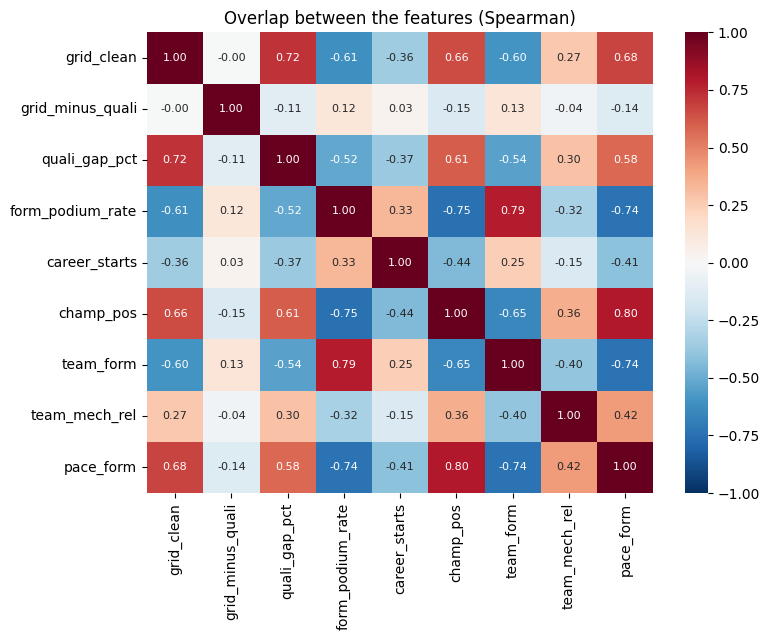

In [273]:
corr = g[list(FEATURES)].astype(float).corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Overlap between the features (Spearman)')
plt.tight_layout(); plt.show()

**Reading.** No two features say the same thing: the strongest overlaps are past pace with the championship position (0.80), driver form with team form (0.79), and driver form with the championship position (−0.75). All are below the 0.96 that led us to drop `quali_pos` in 7.2. A good driver usually sits in a good car, but the two can differ (a strong driver in a weak team), so all features are kept, and the ablation in the modelling section tests which ones the model really needs. `grid_minus_quali` overlaps with nothing, because it is only non-zero for the few drivers moved by a penalty.

# 8. Training seasons and split

## 8.1 Training seasons options

The data covers 1950–2024, but not every feature exists in every season (7.10). The grid, driver form, the championship position, team form and reliability exist from 1950. The two qualifying features need the `qualifying` table, which is only 6–59% filled in 1996–2002 and complete from 2003. The pace feature needs lap times, which start in 1996. So the first training season decides which features the model can use and how many seasons it learns from. Three options are tested.

| Option | Training seasons | Features |
|---|---|---|
| A | 2003–2018 | the 9 features |
| B | 1950–2018 | the 6 features that exist in every season, without the qualifying and pace features |
| C | 1950–2018 | the 9 features, with the missing qualifying and pace values filled, and two extra features that say whether a row has qualifying data and pace data |

**What each option gains and loses.**
- **A, starting in 2003.** Every feature has a real value for almost every row. From 2003, every feature has a value for at least 94% of the rows in every season, and the few gaps are mostly drivers at their first start and teams at their first race. The shared cars (two drivers credited with one car's result) end in 1961, so none are left. The price is that the model learns from 16 seasons and never sees the more than 50 seasons before them.
- **B, starting in 1950 with 6 features.** The model learns from every season, with more than three times as many rows. The price is that it loses the qualifying and pace features. The older seasons also come from very different eras, in which cars broke down far more often and the fields were larger and less even. The 1950–1961 seasons hold the shared cars, which stay as the records give them, so both drivers of a shared car keep its result.
- **C, starting in 1950 with 9 features.** The model learns from every season and keeps every feature. The price is that the qualifying and pace values are missing for most rows before 2003, so they have to be filled with guesses. The two extra features let the model tell a filled value from a real one.

**The same in every option.** Only the drivers who failed to qualify are removed (results section, *Decision: who is removed*). Every other driver stays as a normal entry, so the data keeps cases such as Leclerc, on pole at Monaco 2021, whose car failed on the way to the grid.

The first season only decides which rows the model **learns from**. The history features of a race still look back at earlier seasons (for example, a driver's form at the first race of 2003 uses their 2002 starts). That is allowed, because those races happened before the race being predicted.

The three options are compared on the same validation seasons (8.2). The table shows the training part of each one.

In [274]:
QUALI_PACE = ['grid_minus_quali', 'quali_gap_pct', 'pace_form']
SIX = [f for f in FEATURES if f not in QUALI_PACE]

g = fe[model_rows & (fe.year <= 2018)]
rows = []
for option, first, feats in [('A', 2003, list(FEATURES)), ('B', 1950, SIX), ('C', 1950, list(FEATURES) + FLAGS)]:
    t = g[g.year >= first]
    rows.append({'option': option, 'training seasons': f'{first}-2018', 'seasons': t.year.nunique(), 'races': t.raceId.nunique(),
                 'training rows': len(t), 'podiums': int(t.podium.sum()), 'podium rate': t.podium.mean(), 'features': len(feats),
                 'rows missing any of its features': t[feats].isna().any(axis=1).mean()})
table(pd.DataFrame(rows), pct1=['podium rate', 'rows missing any of its features'],
      caption='The training part of each option (model rows, before filling)')

option,training seasons,seasons,races,training rows,podiums,podium rate,features,rows missing any of its features
A,2003-2018,16,300,6407,900,14.0%,9,4.2%
B,1950-2018,69,986,22362,2975,13.3%,6,5.0%
C,1950-2018,69,986,22362,2975,13.3%,11,69.6%


**Reading.** Options B and C learn from 69 seasons and 986 races, against 16 seasons and 300 races for option A, so they have 3.5 times as many training rows (22,362 against 6,407). Their podium rate is a little lower (13.3% against 14.0%), because the older races had more cars. The big difference between B and C is the missing values. Option B misses at least one of its 6 features in 5.0% of its training rows, close to option A's 4.2%. Option C misses at least one of its features in 69.6% of its training rows, because the qualifying and pace values do not exist for most races before 2003.

## 8.2 The split: the options

The seasons **2022–2024 are the test part** in every option. New car rules started in 2022, so testing on these seasons shows whether the model still works on cars it has never seen, which is the hardest and most honest test. The test part is only used at the end. The seasons before 2022 are divided into a training part and a validation part, which is used to choose between models and settings. Two ways of dividing them are tested.

**In both ways, a race stays together.** Only 3 drivers of a race can finish on the podium, so the rows of one race depend on each other. If some drivers of a race were in training and the others in validation, the model would partly know the answer. So every race is put whole into one part.

**Option 1, by time.**

| Part | Seasons | Used for |
|---|---|---|
| Training | from the first season (8.1) to 2018 | learning the model |
| Validation | 2019–2021 | choosing between models and settings, and the ablation |
| Test | 2022–2024 | the final scores, at the end |

This is like real use. The model predicts future races from past ones, so it is always checked on seasons after the ones it learned from.

**Option 2, random whole races.** The races before 2022 are shuffled and divided at random into training and validation, with as many validation races as in option 1. The test part stays 2022–2024. This is a common way to split, but here the model learns from races that come after some of its validation races, for example the end of a season whose first races are in validation. Testing it shows whether such a split makes the validation score look better than what the model really does on new seasons. It is built for the options that are carried forward after the comparison of the models (10.6), with their training seasons and features, so the split is the only change.

**No leakage in either way.** Every value learned from the data (the fill values, the capping limits and the scaling) is learned from the training races only. The history features only look at earlier races, so a feature never uses the result of the race it describes.

**Why validation is 2019–2021, not 2020–2021.** We also considered ending training in 2019. Moving 2019 changes the two parts very differently (table below, with training from 2003):
- **Training** grows by only about 7%. With 9 features, the model already has thousands of rows, so one more season changes little.
- **Validation** shrinks by about a third. Validation scores are estimates, and their error depends mostly on the number of podiums. Models we compare will often differ by only 0.01–0.02 in AUC, so with a smaller validation set a difference of that size is more often just luck.
- **2020 was an unusual season.** It had COVID, 17 races, two races in a row at the same circuit and several one-off circuits. Without 2019, it would be a third of the validation set.

**Training again on the validation seasons.** Once the settings are chosen, the validation seasons could also be used for training, because they are the closest to the test seasons. Whether training again on all the seasons before 2022 improves the scores on the test seasons is tested at the end (10.9).

In [275]:
TRAIN = (2003, 2018)
VAL = (2019, 2021)
TEST = (2022, 2024)

fe['split'] = pd.Series(pd.NA, index=fe.index, dtype='string')
for name, (a, b) in [('train', TRAIN), ('validation', VAL), ('test', TEST)]:
    fe.loc[model_rows & fe.year.between(a, b), 'split'] = name

def auc_error(auc_value, pos, neg):
    """Approximate standard error of a ROC-AUC (Hanley and McNeil, 1982)."""
    q1, q2 = auc_value / (2 - auc_value), 2 * auc_value**2 / (1 + auc_value)
    return np.sqrt((auc_value * (1 - auc_value) + (pos - 1) * (q1 - auc_value**2) + (neg - 1) * (q2 - auc_value**2)) / (pos * neg))

g = fe[model_rows]
rows = []
for option, tr, va in [('train 2003-2018, validation 2019-2021 (chosen)', (2003, 2018), (2019, 2021)),
                       ('train 2003-2019, validation 2020-2021', (2003, 2019), (2020, 2021))]:
    t, v = g[g.year.between(*tr)], g[g.year.between(*va)]
    rows.append({'option': option, 'training rows': len(t), 'validation races': v.raceId.nunique(),
                 'validation podiums': int(v.podium.sum()),
                 'AUC error (if AUC = 0.90)': auc_error(0.90, v.podium.sum(), (1 - v.podium).sum())})
display(pd.DataFrame(rows).style.format({'AUC error (if AUC = 0.90)': '±{:.3f}'}).hide(axis='index')
        .set_caption('Moving 2019 from validation to training'))

option,training rows,validation races,validation podiums,AUC error (if AUC = 0.90)
"train 2003-2018, validation 2019-2021 (chosen)",6407,60,180,±0.016
"train 2003-2019, validation 2020-2021",6827,39,117,±0.019


## 8.3 Checks on the split

Each part should have enough races and podiums, a similar podium rate and few missing values. The validation and test parts are the same in options A, B and C, so only the training part changes. The missing values are counted over the features each option uses.

In [276]:
OPTIONS = {'A': (2003, list(FEATURES)), 'B': (1950, SIX), 'C': (1950, list(FEATURES) + FLAGS)}
g = fe[model_rows]

rows = []
for option, (first, feats) in OPTIONS.items():
    for part, (a, b) in [('train', (first, TRAIN[1])), ('validation', VAL), ('test', TEST)]:
        d = g[g.year.between(a, b)]
        rows.append({'option': option, 'part': part, 'seasons': f'{a}-{b}', 'races': d.raceId.nunique(), 'rows': len(d),
                     'podiums': int(d.podium.sum()), 'podium rate': d.podium.mean(),
                     'rows missing any of its features': d[feats].isna().any(axis=1).mean()})
table(pd.DataFrame(rows), pct1=['podium rate', 'rows missing any of its features'], caption='The three parts of each option')

parts = {'train 2003-2018': (2003, TRAIN[1]), 'train 1950-2018': (1950, TRAIN[1]), 'validation': VAL, 'test': TEST}
missing = pd.DataFrame({name: g[g.year.between(a, b)][list(FEATURES)].isna().mean() for name, (a, b) in parts.items()})
table(missing.reset_index().rename(columns={'index': 'feature'}), pct1=list(parts),
      caption='Share of rows missing each feature, per part (option B does not use the qualifying and pace features)')

option,part,seasons,races,rows,podiums,podium rate,rows missing any of its features
A,train,2003-2018,300,6407,900,14.0%,4.2%
A,validation,2019-2021,60,1200,180,15.0%,3.7%
A,test,2022-2024,68,1359,204,15.0%,2.1%
B,train,1950-2018,986,22362,2975,13.3%,5.0%
B,validation,2019-2021,60,1200,180,15.0%,1.9%
B,test,2022-2024,68,1359,204,15.0%,1.1%
C,train,1950-2018,986,22362,2975,13.3%,69.6%
C,validation,2019-2021,60,1200,180,15.0%,3.7%
C,test,2022-2024,68,1359,204,15.0%,2.1%


feature,train 2003-2018,train 1950-2018,validation,test
grid_clean,0.0%,0.0%,0.0%,0.0%
grid_minus_quali,0.3%,64.5%,0.2%,0.0%
quali_gap_pct,1.8%,65.1%,1.7%,1.0%
form_podium_rate,1.1%,3.1%,0.8%,0.6%
career_starts,0.0%,0.0%,0.0%,0.0%
champ_pos,1.9%,4.0%,1.2%,0.8%
team_form,0.7%,1.4%,0.8%,0.3%
team_mech_rel,0.7%,1.4%,0.8%,0.3%
pace_form,1.3%,60.8%,0.8%,0.6%


**Reading.**
- **Validation and test are the same in every option.** Validation has 60 races, 1,200 rows and 180 podiums, and test has 68 races, 1,359 rows and 204 podiums.
- **Each race has 3 podiums, so the podium rate depends on how many cars start.** In option A's training part (300 races, 900 podiums) the rate is 14.0%, against 15.0% in validation and test, because 2003–2018 includes seasons with up to 24 cars. In the training part of B and C it is 13.3%, because the older races had even larger fields. Its 986 races have 2,975 podiums, 17 more than 3 per race, because both drivers of a shared car on the podium are counted (9.1).
- **About 1 row in 7 is a podium in every part.** This imbalance is why the models are also scored with PR-AUC and F1, not only accuracy.
- **Missing values.** In option A, 2–4% of the rows miss any feature in every part, and no feature misses more than 1.9%. Option B misses a little more in training (5.0%), mostly the championship position (4.0%) and driver form (3.1%) of the early seasons, and less in validation and test (1.9% and 1.1%), because it does not use the qualifying and pace features. In option C, 69.6% of the training rows miss a value, because the qualifying features are missing for about 65% of the 1950–2018 rows and `pace_form` for 61%. Its validation and test parts miss as little as option A's. All these values are filled in 9.2, with values learned from the training part only.

## 8.4 What is tested

| Version | Training seasons | Split of training and validation | Features | What changes |
|---|---|---|---|---|
| A | 2003–2018 | by time | the 9 features | nothing, this is the version the others are compared with |
| B | 1950–2018 | by time | the 6 features of every season | the first season and the features, compared with A |
| C | 1950–2018 | by time | the 9 features and the two extra features | the first season, compared with A |
| D | the seasons of each option carried forward (10.6) | random whole races | the features of that option | only the split, compared with the same option |

A, B and C are compared on the same validation races (2019–2021), and the options to carry forward are chosen there. D has different validation races, so it is not compared with them on validation. It is compared with the same option by how close each validation score is to its test score, and by how well the model each split chooses does on the test seasons. Every version is scored on the same test seasons, 2022–2024.

# 9. Preprocessing

This section turns the features of section 7 into the **modelling table**, which is one row per driver per race in the seasons of the option (8.1), a value for every feature, and nothing learned from the validation or test seasons.

The steps are done in this order.

| Step | What it does | Learned from data? |
|---|---|---|
| 9.1 Rows | keeps every driver except those who failed to qualify, in the seasons of the option | no |
| 9.2 Filling | gives every missing feature value a value | some fill values, from the training part only |
| 9.3 Capping | limits a few extreme but misleading values | some limits, from the training part only |
| 9.4 Effect | shows what filling and capping changed | – |
| 9.5 Scaling | puts every feature on the same scale | mean and spread, from the training part only |
| 9.6 Order experiments | tests what happens if the steps are done in another order | – |
| 9.7 The modelling table | the final table, checked | – |

**The rule for every step.** A value that is learned from data (a median, a limit, a mean) is learned from the **training part only**, then applied unchanged to validation and test. This is how the model will be used for real, because a race can only be predicted from what was known before it. If validation or test seasons helped choose these values, the scores in section 10 could be slightly too optimistic.

## 9.1 Rows

The modelling rows were decided in the earlier sections. Each removal has a reason.
- **One row per driver per race** (results section, *duplicates*). The 91 duplicate rows were removed in cleaning, so each row is one prediction of whether this driver finishes on the podium in this race.
- **Drivers who failed to qualify** (`failed_to_qualify`, results section and 8.1). They are the only drivers we know before the cutoff will not race, so there is no race to predict for them. Every other driver stays as a normal entry.
- **The Indianapolis 500** (races section). It was part of the championship until 1960, but it is a different race with different drivers.

**Shared cars are kept.** In 1950–1961, two drivers were sometimes credited with one car's result (129 rows, 7.10). Both drivers keep the row as the records give it, so both have the car's finishing position. These rows only exist in the options that start in 1950.

No row is removed because of a missing feature value. Those values are filled in 9.2.

In [277]:
steps = pd.DataFrame({'step': ['results, one row per driver per race', 'minus drivers who failed to qualify', 'minus the Indianapolis 500'],
                      'rows left': [len(fe), (~fe.failed_to_qualify).sum(), model_rows.sum()]})
steps['rows removed'] = (-steps['rows left'].diff()).fillna(0).astype(int)
table(steps, caption='From the results table to the model rows (all seasons)')

g = fe[model_rows]
shared = g.duplicated(['raceId', 'positionOrder', 'constructorId'], keep=False)
rows = []
for option, (first, feats) in OPTIONS.items():
    r = {'option': option, 'seasons': f'{first}-{TEST[1]}'}
    for part, (a, b) in [('train', (first, TRAIN[1])), ('validation', VAL), ('test', TEST)]:
        r[f'{part} rows'] = int(g.year.between(a, b).sum())
    r['shared-car rows'] = int((shared & g.year.between(first, TEST[1])).sum())
    rows.append(r)
table(pd.DataFrame(rows), caption='Rows per part in each option (8.2)')

step,rows left,rows removed
"results, one row per driver per race",26668,0
minus drivers who failed to qualify,25302,1366
minus the Indianapolis 500,24921,381


option,seasons,train rows,validation rows,test rows,shared-car rows
A,2003-2024,6407,1200,1359,0
B,1950-2024,22362,1200,1359,129
C,1950-2024,22362,1200,1359,129


## 9.2 Filling the missing values

**Why fill instead of dropping.** From 2003, only a few percent of the rows miss a feature (7.10). Most of them are a driver's **first start** (no form, no pace, no championship position yet) or a team's **first race** (no team history). If these rows were dropped, the model would never see a rookie or a new team, but it must still predict for them. So every row is kept and every gap is filled. The options that start in 1950 have more of these gaps, because almost every driver and team was new in the first seasons. In option C, the qualifying and pace values are also missing for every race that has no qualifying data or no lap times (7.10), which is most races before 2003.

**The rules.** Each feature gets the rule that matches *why* its value is missing (8.3 and the missing-value check in this section).

| Feature | Missing when | Filled with | Why this value |
|---|---|---|---|
| `grid_minus_quali` | the driver has no qualifying row (set no lap, or was excluded from qualifying), or the race has no qualifying data (option C) | **0** | "not moved from qualifying". Their grid slot already shows where they start. |
| `quali_gap_pct` | no Q1 time, no qualifying row, or the race has no qualifying data (option C) | the driver's **median gap over their previous 10 starts**, and if they have none, the **training median** | the driver's own recent qualifying speed is the best guess for this weekend. Before 1994 no driver has an earlier gap, so these rows get the training median. |
| `form_podium_rate` | the driver's first start | **0** | true, because the driver has no podium yet. `career_starts` = 0 tells the model that this 0 is a debut, not a bad run. |
| `pace_form` | the driver's first start, no earlier race with 10+ laps, or the race is before 1996 (option C) | the **training median** | no earlier pace exists, so the driver is treated as typical |
| `champ_pos` | no standing this season and none last season (debut, or back after a season out) | the **worst `champ_pos` in the same race + 1**, and the **training median** if nobody in the race has a standing (the first race of 1950) | the driver has no points, so they are behind everyone. It is the same idea as pit-lane starters in `grid_clean`, and it only uses other drivers' pre-race standings. |
| `team_form` | the team's first race (a new team, a new name, or a return after 5+ seasons) | the **training median** | no history, so the team is treated as typical |
| `team_mech_rel` | the team's first race | the **training median** | the same |
| `has_quali_data`, `has_pace_data` | never missing (option C only) | – | – |

**Which option uses which rule.** Option A uses the rules for its 9 features. Option B has no qualifying or pace features, so it only fills driver form, the championship position and the two team features. Option C uses every rule, and many more of its values are filled, because the qualifying and pace values are missing for most races before 2003. Its two extra features tell the model which of those values are filled and which are real. Each option learns its fill values from its own training part.

**Why new team names are not linked to the old name.** Most "new" teams are renamed teams (Red Bull 2005 was Jaguar, Brawn 2009 was Honda). Their history was not carried over, because a new name often means a new owner and a different car. Honda had 1 podium in 2008, but as Brawn the same factory won 6 of the first 7 races of 2009. The other features of the row (the grid slot and the gap in qualifying) already show how fast the new car is that weekend.

**Why the median, and why only training.** The median is the middle value, so a few extreme values cannot pull it. It is computed on the training rows only and used for every part, so a test row is never filled with information from the test seasons.

In [278]:
# the driver's median Q1 gap over their previous 10 starts (the current race is left out)
hist = fe[model_rows].sort_values(['driverId', 'year', 'round'])
fe = fe.drop(columns=['quali_prev_median'], errors='ignore')                  # safe to rerun
fe.loc[hist.index, 'quali_prev_median'] = (hist.groupby('driverId').quali_gap_pct
                                               .transform(lambda s: s.shift(1).rolling(10, min_periods=1).median()))

ID_COLS = ['raceId', 'driverId', 'constructorId', 'year', 'round', 'split']
F = list(FEATURES)
all_rows = fe.loc[model_rows & fe.year.between(1950, TEST[1]), ID_COLS[:-1] + F + FLAGS + ['quali_prev_median', 'podium']].copy()
all_rows[F] = all_rows[F].astype(float)

def split_of(d, first):
    """The time split of 8.2 for an option whose training starts in `first`."""
    s = pd.Series(pd.NA, index=d.index, dtype='string')
    for name, (a, b) in [('train', (first, TRAIN[1])), ('validation', VAL), ('test', TEST)]:
        s[d.year.between(a, b)] = name
    return s

def fit_fill(rows):
    """The fill values learned from data: the medians of the given rows."""
    return {f: rows[f].median() for f in ['quali_gap_pct', 'pace_form', 'champ_pos', 'team_form', 'team_mech_rel']}

def apply_fill(d, learned):
    """Fill every missing feature value with the rules above."""
    d = d.copy()
    d['grid_minus_quali'] = d.grid_minus_quali.fillna(0)
    d['quali_gap_pct'] = d.quali_gap_pct.fillna(d.quali_prev_median).fillna(learned['quali_gap_pct'])
    d['form_podium_rate'] = d.form_podium_rate.fillna(0)
    d['champ_pos'] = d.champ_pos.fillna(d.groupby('raceId').champ_pos.transform('max') + 1).fillna(learned['champ_pos'])
    for f in ['pace_form', 'team_form', 'team_mech_rel']:
        d[f] = d[f].fillna(learned[f])
    return d

# every option: its own rows, its own split, its fill values learned from its own training part
opt_data, opt_learned, opt_filled = {}, {}, {}
for option, (first, feats) in OPTIONS.items():
    d = all_rows[all_rows.year >= first].copy()
    d['split'] = split_of(d, first)
    opt_data[option] = d
    opt_learned[option] = fit_fill(d[d.split == 'train'])
    opt_filled[option] = apply_fill(d, opt_learned[option])
    assert opt_filled[option][feats].notna().all().all(), f'option {option}: a feature value is still missing'

# option A keeps the names used in the rest of this section
data, learned, filled = opt_data['A'], opt_learned['A'], opt_filled['A']
train_mask = data.split == 'train'

fill_values = pd.DataFrame({o: {f: v for f, v in opt_learned[o].items() if f in OPTIONS[o][1]} for o in OPTIONS})
display(fill_values.rename_axis('feature').style.format('{:.4f}', na_rep='–')
        .set_caption('Fill values learned from the training part of each option (– = the option does not use the feature)'))

for o, d in opt_data.items():
    tr = d.split == 'train'
    line = f'option {o}: team_form = 0 in {(d.loc[tr, "team_form"] == 0).mean():.0%} of the training rows'
    if 'quali_gap_pct' in OPTIONS[o][1]:
        q_miss = d.quali_gap_pct.isna()
        line += (f" | quali_gap_pct filled with the driver's previous median: {int((q_miss & d.quali_prev_median.notna()).sum())}"
                 f', with the training median: {int((q_miss & d.quali_prev_median.isna()).sum())}')
    print(line)

rows = []
for o, (first, feats) in OPTIONS.items():
    d = opt_data[o]
    for f in F + FLAGS:
        r = {'feature': f, 'option': o}
        if f in feats:
            for p in ['train', 'validation', 'test']:
                r[f'missing before, {p}'] = int(d.loc[d.split == p, f].isna().sum())
            r['missing after'] = int(opt_filled[o][f].isna().sum())
        rows.append(r)
missing_check = pd.DataFrame(rows).pivot(index='feature', columns='option').reindex(F + FLAGS)
missing_check.columns = [f'{o} {c}' for c, o in missing_check.columns]
missing_check = missing_check[[f'{o} {c}' for o in OPTIONS for c in ['missing before, train', 'missing before, validation',
                                                                         'missing before, test', 'missing after']]]
display(missing_check.style.format('{:.0f}', na_rep='–')
        .set_caption('Missing values before and after filling, per option (– = the option does not use the feature)'))

,A,B,C
feature,,,
quali_gap_pct,1.3571,–,1.5318
pace_form,1.0000,–,1.0002
champ_pos,11.0000,12.0000,12.0000
team_form,0.0000,0.0500,0.0500
team_mech_rel,-0.0091,-0.0063,-0.0063


option A: team_form = 0 in 52% of the training rows | quali_gap_pct filled with the driver's previous median: 145, with the training median: 3
option B: team_form = 0 in 43% of the training rows
option C: team_form = 0 in 43% of the training rows | quali_gap_pct filled with the driver's previous median: 1620, with the training median: 12970


,"A missing before, train","A missing before, validation","A missing before, test",A missing after,"B missing before, train","B missing before, validation","B missing before, test",B missing after,"C missing before, train","C missing before, validation","C missing before, test",C missing after
feature,,,,,,,,,,,,
grid_clean,0,0,0,0,0,0,0,0,0,0,0,0
grid_minus_quali,21,3,0,0,–,–,–,–,14432,3,0,0
quali_gap_pct,115,20,13,0,–,–,–,–,14557,20,13,0
form_podium_rate,72,9,8,0,694,9,8,0,694,9,8,0
career_starts,0,0,0,0,0,0,0,0,0,0,0,0
champ_pos,124,15,11,0,889,15,11,0,889,15,11,0
team_form,42,10,4,0,304,10,4,0,304,10,4,0
team_mech_rel,42,10,4,0,304,10,4,0,304,10,4,0
pace_form,81,10,8,0,–,–,–,–,13597,10,8,0


**Reading.**
- **Every feature value is now filled in every option** (the "missing after" columns are 0 everywhere), and no row was removed.
- **Option A fills few values.** At most 150 of its 8,966 rows for one feature (`champ_pos`), and only 24 for `grid_minus_quali`. For `quali_gap_pct`, 145 of the 148 gaps get the driver's own recent median, and only 3 drivers with no earlier Q1 time get the training median.
- **Option B fills more, but still a small share.** Its training part (1950–2018) misses 889 `champ_pos` values, 694 for driver form and 304 for the two team features, which is at most 4% of its 22,362 training rows. These are the debuts and new teams of the early seasons. Its validation and test parts are the same rows as in option A, so they get the same gaps.
- **Option C fills most of its qualifying and pace values.** In its training part, 14,432 `grid_minus_quali`, 14,557 `quali_gap_pct` and 13,597 `pace_form` values are filled, about 60–65% of the rows. Only 1,620 of the `quali_gap_pct` gaps can use the driver's own recent median (drivers who had qualifying data in an earlier race), and the other 12,970 get the training median. These rows carry `has_quali_data` = 0 or `has_pace_data` = 0, so the model can tell them apart from real values.
- **The fill values differ a little between the options.** The training median of `quali_gap_pct` is 1.36% in option A and 1.53% in option C, because the gaps of 1994–2002 were larger. The median of `champ_pos` is 11 in option A and 12 in B and C. The median of `pace_form` is 1.000 in every option, which is a typical lap.
- **The training median of `team_form` is 0 in option A and 0.05 in B and C.** In option A, 52% of the training rows belong to teams with no podium in their previous 10 races, so a team at its first race is filled as "no recent podium", which is true of the typical team. In the older seasons fewer rows have a team without a recent podium (43%), so the median is just above 0. Brawn in 2009 is the exception, and its grid slots show the car's speed.
- **The training median of `team_mech_rel` is about −0.01 in option A and −0.006 in B and C**, almost exactly "as reliable as the field" in every option.

## 9.3 Capping extreme values

Three features have a few values that are real but do not mean what the feature is meant to measure.

- **`quali_gap_pct`.** A normal gap to the fastest Q1 lap is 0–5%. A few drivers are 10–45% slower, because their only Q1 lap had a problem (a spin, a crash, a car failure or rain at the end of the session). That lap does not show the car's speed. These values are **capped at 7%**, so anything above becomes 7%. The limit comes from the sport's own **107% rule**. A car more than 7% slower than the fastest lap in qualifying is not considered to be at racing speed (it may be refused a start). The limit is a fixed rule, so nothing is learned from data.
- **`team_mech_rel`.** A normal value is between about −0.1 and +0.1. At a team's first few races the rate is based on very few cars. If both cars break down in the team's first race, the team has a 100% failure rate from 2 starts. In the older seasons cars broke down far more often, so the values spread more widely, and the options that start in 1950 learn wider limits. The values are **capped at the 1st and 99th percentiles of the training part**, so the 1% most extreme values at each end are pulled in to that limit.
- **`pace_form`.** A normal value is between about 0.98 and 1.05. The problem is the same as for reliability. At a driver's first few starts, the average covers only one or two races, and a single chaotic race can dominate it. Justin Wilson's race pace at the wet, red-flagged Brazilian GP 2003 was 1.44, which kept his `pace_form` near 1.1–1.2 for the next races. It is **capped at the 1st and 99th percentiles of the training part**, like `team_mech_rel`.

**What a percentile is.** Line up all the training values of the feature from smallest to largest. The **1st percentile** is the value with 1% of the rows below it, and the **99th percentile** the value with 1% of the rows above it (the 50th percentile is the median). Capping at these two values changes only the most extreme 1% at each end. A value above the 99th percentile becomes the 99th percentile, a value below the 1st becomes the 1st, and the other 98% of the rows are not touched. In option A, the limits of `team_mech_rel` are about −0.165 and +0.356, so Caterham's 0.92 at the second race of 2012 becomes 0.356. It is still the most unreliable value in the data, but no longer ten times a normal one.

**The limits are learned from the real values only.** The percentiles are computed from the training values that were there before filling (9.2), and the limits are then applied after filling. In option C, every race before 1996 has its `pace_form` filled with the same training median, which is most of its training rows. If those filled values were counted, the 1st and 99th percentiles would move towards the median and much more than 1% of the real values would be cut at each end. Using only the real values keeps the cap at the most extreme 1% in every option. The table below shows both versions of the limits.

**Which option caps what.** Options A and C cap all three features. Option B has no qualifying or pace features, so it only caps `team_mech_rel`. Each option learns its limits from its own training part.

**Why cap.** For logistic regression and the neural network, one extreme value stretches the scale (9.5) and pulls the model towards a few unusual rows. Trees are not affected, because they only compare values with a threshold. Capping keeps the row and keeps its order (the value is still the most extreme), and it only shortens the distance.

The other features have no misleading extremes. Grid slots, positions and podium rates have fixed ranges, and `career_starts` is a count.

In [279]:
QUALI_CAP = 7.0                                                                # the 107% rule

def fit_caps(rows, feats=('team_mech_rel', 'pace_form')):
    """The capping limits learned from data: the 1st and 99th percentiles of the real values (missing values are skipped)."""
    return {f: tuple(rows[f].quantile([0.01, 0.99])) for f in feats}

def apply_caps(d, caps):
    """Cap quali_gap_pct at 7%, and the other features at the learned limits."""
    d = d.copy()
    d['quali_gap_pct'] = d.quali_gap_pct.clip(upper=QUALI_CAP)
    for f, limits in caps.items():
        d[f] = d[f].clip(*limits)
    return d

# every option: limits learned from the real values of its own training part, applied after filling
opt_caps, opt_capped = {}, {}
for o, (first, feats) in OPTIONS.items():
    d = opt_data[o]
    opt_caps[o] = fit_caps(d[d.split == 'train'], [f for f in ['team_mech_rel', 'pace_form'] if f in feats])
    opt_capped[o] = apply_caps(opt_filled[o], opt_caps[o])

# option A keeps the names used in the rest of this section
caps, capped = opt_caps['A'], opt_capped['A']

rows = []
for o in OPTIONS:
    tr_filled = opt_filled[o][opt_filled[o].split == 'train']
    for f, (lo, hi) in opt_caps[o].items():
        lo_f, hi_f = tr_filled[f].quantile([0.01, 0.99])
        rows.append({'option': o, 'feature': f, 'low limit': lo, 'high limit': hi,
                     'low limit if filled values counted': lo_f, 'high limit if filled values counted': hi_f})
display(pd.DataFrame(rows).style.format('{:.3f}', subset=pd.IndexSlice[:, ['low limit', 'high limit', 'low limit if filled values counted', 'high limit if filled values counted']])
        .hide(axis='index').set_caption('Capping limits learned from the training part of each option'))

rows = []
for o, (first, feats) in OPTIONS.items():
    d = opt_filled[o]
    for p in ['train', 'validation', 'test']:
        in_p = d.split == p
        r = {'option': o, 'part': p, 'rows': int(in_p.sum())}
        r['quali_gap_pct above 7%'] = int((in_p & (d.quali_gap_pct > QUALI_CAP)).sum()) if 'quali_gap_pct' in feats else None
        for f in ['team_mech_rel', 'pace_form']:
            if f in opt_caps[o]:
                lo, hi = opt_caps[o][f]
                r[f'{f} outside the limits'] = int((in_p & ((d[f] < lo) | (d[f] > hi))).sum())
            else:
                r[f'{f} outside the limits'] = None
        rows.append(r)
changed = pd.DataFrame(rows)
display(changed.style.format('{:.0f}', na_rep='–', subset=list(changed.columns[3:])).hide(axis='index')
        .set_caption('Rows changed by capping, per option (– = the option does not use the feature)'))

for o, (first, feats) in OPTIONS.items():
    if 'quali_gap_pct' in feats:
        over = opt_filled[o].quali_gap_pct > QUALI_CAP
        print(f'option {o}: podium rate of the rows above 7% in qualifying: {opt_filled[o][over].podium.mean():.1%} '
              f'({int(opt_filled[o][over].podium.sum())} of {over.sum()})')

# examples, from option C, which has every season and every feature
ex, ex_caps = opt_filled['C'], opt_caps['C']
over = ex.quali_gap_pct > QUALI_CAP
names = (ex[over].nlargest(6, 'quali_gap_pct')
           .merge(drivers[['driverId', 'forename', 'surname']], on='driverId').merge(races[['raceId', 'name']], on='raceId'))
table(names.assign(driver=names.forename + ' ' + names.surname, grid_clean=names.grid_clean.astype(int))
           [['year', 'name', 'driver', 'quali_gap_pct', 'grid_clean', 'podium']]
           .rename(columns={'name': 'race', 'grid_clean': 'grid'}), dec1=['quali_gap_pct'],
      caption='The largest gaps in qualifying, 1950-2024 (before capping)')

lo, hi = ex_caps['team_mech_rel']
teams = (ex[(ex.team_mech_rel < lo) | (ex.team_mech_rel > hi)].drop_duplicates(['raceId', 'constructorId'])
           .nlargest(6, 'team_mech_rel').merge(constructors[['constructorId', 'name']], on='constructorId'))
table(teams[['year', 'round', 'name', 'team_mech_rel']].rename(columns={'name': 'team'}), dec2=['team_mech_rel'],
      caption='The largest team_mech_rel values, 1950-2024 (before capping)')

lo, hi = ex_caps['pace_form']
slow = (ex[(ex.pace_form < lo) | (ex.pace_form > hi)].nlargest(6, 'pace_form')
          .merge(drivers[['driverId', 'forename', 'surname']], on='driverId'))
table(slow.assign(driver=slow.forename + ' ' + slow.surname, career_starts=slow.career_starts.astype(int))
          [['year', 'round', 'driver', 'career_starts', 'pace_form']], dec2=['pace_form'],
      caption='The largest pace_form values, 1996-2024 (before capping)')

option,feature,low limit,high limit,low limit if filled values counted,high limit if filled values counted
A,team_mech_rel,-0.165,0.356,-0.165,0.356
A,pace_form,0.979,1.054,0.979,1.054
B,team_mech_rel,-0.272,0.417,-0.271,0.414
C,team_mech_rel,-0.272,0.417,-0.271,0.414
C,pace_form,0.979,1.058,0.981,1.041


option,part,rows,quali_gap_pct above 7%,team_mech_rel outside the limits,pace_form outside the limits
A,train,6407,90,126,128
A,validation,1200,14,4,0
A,test,1359,3,0,0
B,train,22362,–,441,–
B,validation,1200,–,4,–
B,test,1359,–,0,–
C,train,22362,193,441,176
C,validation,1200,14,4,0
C,test,1359,3,0,0


option A: podium rate of the rows above 7% in qualifying: 6.5% (7 of 107)
option C: podium rate of the rows above 7% in qualifying: 3.3% (7 of 210)


year,race,driver,quali_gap_pct,grid,podium
2023,Saudi Arabian Grand Prix,Logan Sargeant,44.8,20,0
2004,San Marino Grand Prix,Zsolt Baumgartner,33.3,19,0
1995,British Grand Prix,Andrea Montermini,27.5,24,0
2005,Australian Grand Prix,Michael Schumacher,26.6,19,0
2003,Italian Grand Prix,Fernando Alonso,24.0,20,0
1995,British Grand Prix,Mika Salo,23.3,23,0


year,round,team,team_mech_rel
2012,2,Caterham,0.92
2010,2,Sauber,0.91
2010,2,Virgin,0.91
2010,3,Virgin,0.90
1997,2,Stewart,0.75
1977,14,Renault,0.74


year,round,driver,career_starts,pace_form
2002,2,Takuma Sato,1,1.42
2002,3,Takuma Sato,2,1.22
2003,4,Justin Wilson,3,1.19
2010,3,Lucas di Grassi,2,1.15
2003,5,Justin Wilson,4,1.15
2002,4,Takuma Sato,3,1.14


**Reading.**
- **`quali_gap_pct`.** In option A, 107 rows are above 7% (90 in training, 14 in validation and 3 in test). Option C also has the races of 1994–2002 with qualifying data, so it has 210 (193 in training). The largest gaps are problem laps, not slow cars. For example, Michael Schumacher in a Ferrari, 26.6% off in Australia 2005, was caught by rain in qualifying. Only 7 of these 210 drivers reached the podium (3.3%), and all 7 are in option A's seasons, so a huge gap usually means a lost lap, not a car that is 10–45% slower.
- **`team_mech_rel`.** In option A, the limits are −0.165 and +0.356, and 126 training rows are changed (1% at each end, by design), 4 in validation and none in test. Options B and C learn wider limits from 1950–2018 (−0.272 and +0.417) and change 441 training rows. The largest values still come from a team's first races, where very few cars count, such as Caterham in 2012, Sauber and Virgin in 2010 and Stewart in 1997.
- **`pace_form`.** In option A, the limits are 0.979 and 1.054, and 128 training rows are changed, none in validation or test. Option C learns 0.979 and 1.058 from its real values and changes 176 training rows. If its filled values were counted, the upper limit would drop to 1.041 and many more real values would be cut, which is why the limits are learned from the real values only. For option A the two versions are the same, because it has few filled values. The largest values belong to drivers in their first few starts, such as Takuma Sato in 2002 (1.42 at his second start), Justin Wilson in 2003 and Lucas di Grassi in 2010, whose average still contained a chaotic race.
- **Validation and test are almost untouched** in every option, at most 14 rows for one feature, because they are capped with the limits of the training part.
- Every row is kept, and a capped row is still the most extreme in its race. Capping only shortens how far out it is.

## 9.4 Effect of filling and capping

Filling and capping change some feature values, so this check makes sure they did not weaken the features. For each option and each feature that was filled or capped, the table gives the share of training values that were filled, and the feature's **AUC** (how well it separates podiums from the rest, 7.1) at three stages. The first is on the real values only, the second after filling and the third after filling and capping. If the AUC stays about the same, the filled and capped values separate podiums from the rest as well as the real values did. Everything is measured on the training part of each option.

In [280]:
CHANGED = ['grid_minus_quali', 'quali_gap_pct', 'form_podium_rate', 'champ_pos', 'team_form', 'team_mech_rel', 'pace_form']
SIGN = {f: FEATURES[f][3] for f in F}

rows = []
for f in CHANGED:
    r = {'feature': f}
    for o, (first, feats) in OPTIONS.items():
        if f not in feats:
            continue
        tr = opt_data[o].split == 'train'
        real, fil, cap = opt_data[o].loc[tr, f], opt_filled[o].loc[tr, f], opt_capped[o].loc[tr, f]
        y = opt_data[o].loc[tr, 'podium']
        known = real.notna()
        r[f'{o} filled'] = 1 - known.mean()
        r[f'{o} AUC real'] = auc(SIGN[f] * real[known], y[known])
        r[f'{o} AUC filled'] = auc(SIGN[f] * fil, y)
        r[f'{o} AUC filled and capped'] = auc(SIGN[f] * cap, y)
    rows.append(r)
effect = pd.DataFrame(rows)
effect = effect[['feature'] + [f'{o} {c}' for o in OPTIONS for c in ['filled', 'AUC real', 'AUC filled', 'AUC filled and capped']]]
shares = [c for c in effect.columns if c.endswith('filled') and 'AUC' not in c]
aucs = [c for c in effect.columns if 'AUC' in c]
display(effect.style.format('{:.1%}', subset=shares, na_rep='–').format('{:.3f}', subset=aucs, na_rep='–').hide(axis='index')
        .set_caption('Training part of each option: share of values filled, and the AUC before and after filling and capping (– = the option does not use the feature)'))

feature,A filled,A AUC real,A AUC filled,A AUC filled and capped,B filled,B AUC real,B AUC filled,B AUC filled and capped,C filled,C AUC real,C AUC filled,C AUC filled and capped
grid_minus_quali,0.3%,0.555,0.555,0.555,–,–,–,–,64.5%,0.544,0.515,0.515
quali_gap_pct,1.8%,0.829,0.830,0.830,–,–,–,–,65.1%,0.830,0.678,0.678
form_podium_rate,1.1%,0.872,0.872,0.872,3.1%,0.832,0.833,0.833,3.1%,0.832,0.833,0.833
champ_pos,1.9%,0.887,0.887,0.887,4.0%,0.834,0.835,0.835,4.0%,0.834,0.835,0.835
team_form,0.7%,0.878,0.878,0.878,1.4%,0.839,0.839,0.839,1.4%,0.839,0.839,0.839
team_mech_rel,0.7%,0.703,0.703,0.703,1.4%,0.673,0.674,0.674,1.4%,0.673,0.674,0.674
pace_form,1.3%,0.853,0.853,0.853,–,–,–,–,60.8%,0.852,0.680,0.680


**Reading.**
- **How to read a row.** "Filled" is the share of the option's training rows that had no value and were filled in 9.2. "AUC real" uses only the rows with a real value, and the next two columns use every row after filling, then after filling and capping. 0.5 means the feature cannot separate podiums from the rest, and 1.0 means it separates them perfectly.
- **In options A and B, filling and capping do not weaken any feature.** At most 4% of the values are filled, and every AUC stays the same within 0.001. For example, `quali_gap_pct` in option A goes from 0.829 to 0.830.
- **In option C, filling weakens the qualifying and pace features a lot.** About 61–65% of their training values are filled, and the AUC of `quali_gap_pct` drops from 0.830 to 0.678, of `pace_form` from 0.852 to 0.680 and of `grid_minus_quali` from 0.544 to 0.515. In the races without qualifying data or lap times, every driver gets the same filled value, so the race winner and the last car look the same. This is the cost of keeping these features from 1950.
- **The table looks at each feature alone.** The model also sees `has_quali_data` and `has_pace_data`, so it can learn to rely less on these values when they are filled. Whether that brings the strength back is only shown when option C is trained.
- **Capping never changes the AUC** (the last two columns are always equal), because it keeps the order of the values, and the AUC only depends on the order.
- **The features are weaker over 1950–2018 even on their real values.** For example, the AUC of `champ_pos` is 0.834 in options B and C, against 0.887 in option A, and `team_form` 0.839 against 0.878. Over the older seasons, these features separate podiums a little less well.

## 9.5 Scaling

The features are on very different ranges. `career_starts` goes from 0 to over 300, `form_podium_rate` from 0 to 1, and `team_mech_rel` from about −0.17 to +0.36 in option A (−0.27 to +0.42 in options B and C). Each feature is **standardised** with the mean and spread of the option's own training part.

**scaled value = (value − training mean) ÷ training standard deviation**

For example, in option A the training mean of `grid_clean` is about 11.2 and its standard deviation about 6.3, so pole position (grid 1) becomes (1 − 11.2) ÷ 6.3 ≈ −1.6, grid 11 becomes about 0, and grid 20 becomes about +1.4. After scaling, every feature in the training part has mean 0 and standard deviation 1.

**The two extra features of option C** (`has_quali_data` and `has_pace_data`, 0 or 1) are scaled like the others. Scaling only moves 0 and 1 to two other numbers, so they still say the same thing.

**Why scale.**
- **Logistic regression** (with the usual regularisation) shrinks all weights by the same rule, so a feature measured on a large range would be treated differently from one on a small range only because of its unit.
- **The neural network** learns slowly and unevenly when its inputs are on very different scales.
- **Trees** only compare a value with a threshold, so scaling changes nothing for them. The same scaled table can be used for every model.

**Why standardisation and not min-max** (squeezing each feature into 0–1). Min-max uses the single smallest and largest value, so one extreme row decides the scale of the whole feature. Standardisation uses the mean and spread of all rows, and the extremes were already capped in 9.3.

**Why only the training part.** Validation and test are scaled with the training mean and spread, so their means are not exactly 0. That is expected, because it shows how the later seasons differ from the training seasons (for example, drivers in 2022–2024 have more career starts on average).

,A training mean,A training spread,A validation mean after,A test mean after,B training mean,B training spread,B validation mean after,B test mean after,C training mean,C training spread,C validation mean after,C test mean after
feature,,,,,,,,,,,,
grid_clean,11.24,6.26,-0.11,-0.12,12.06,6.89,-0.22,-0.22,12.06,6.89,-0.22,-0.22
grid_minus_quali,0.00,1.54,0.02,0.01,–,–,–,–,0.00,0.83,0.05,0.02
quali_gap_pct,1.77,1.52,-0.28,-0.48,–,–,–,–,1.75,1.09,-0.37,-0.65
form_podium_rate,0.14,0.23,0.04,0.05,0.13,0.21,0.09,0.10,0.13,0.21,0.09,0.10
career_starts,92.61,79.37,0.30,0.68,60.65,61.08,0.91,1.40,60.65,61.08,0.91,1.40
champ_pos,11.55,6.64,-0.13,-0.13,14.74,11.96,-0.34,-0.34,14.74,11.96,-0.34,-0.34
team_form,0.14,0.22,0.02,0.04,0.13,0.18,0.07,0.09,0.13,0.18,0.07,0.09
team_mech_rel,0.00,0.08,-0.08,-0.09,0.00,0.12,-0.04,-0.04,0.00,0.12,-0.04,-0.04
pace_form,1.00,0.01,-0.14,-0.15,–,–,–,–,1.00,0.01,-0.05,-0.08


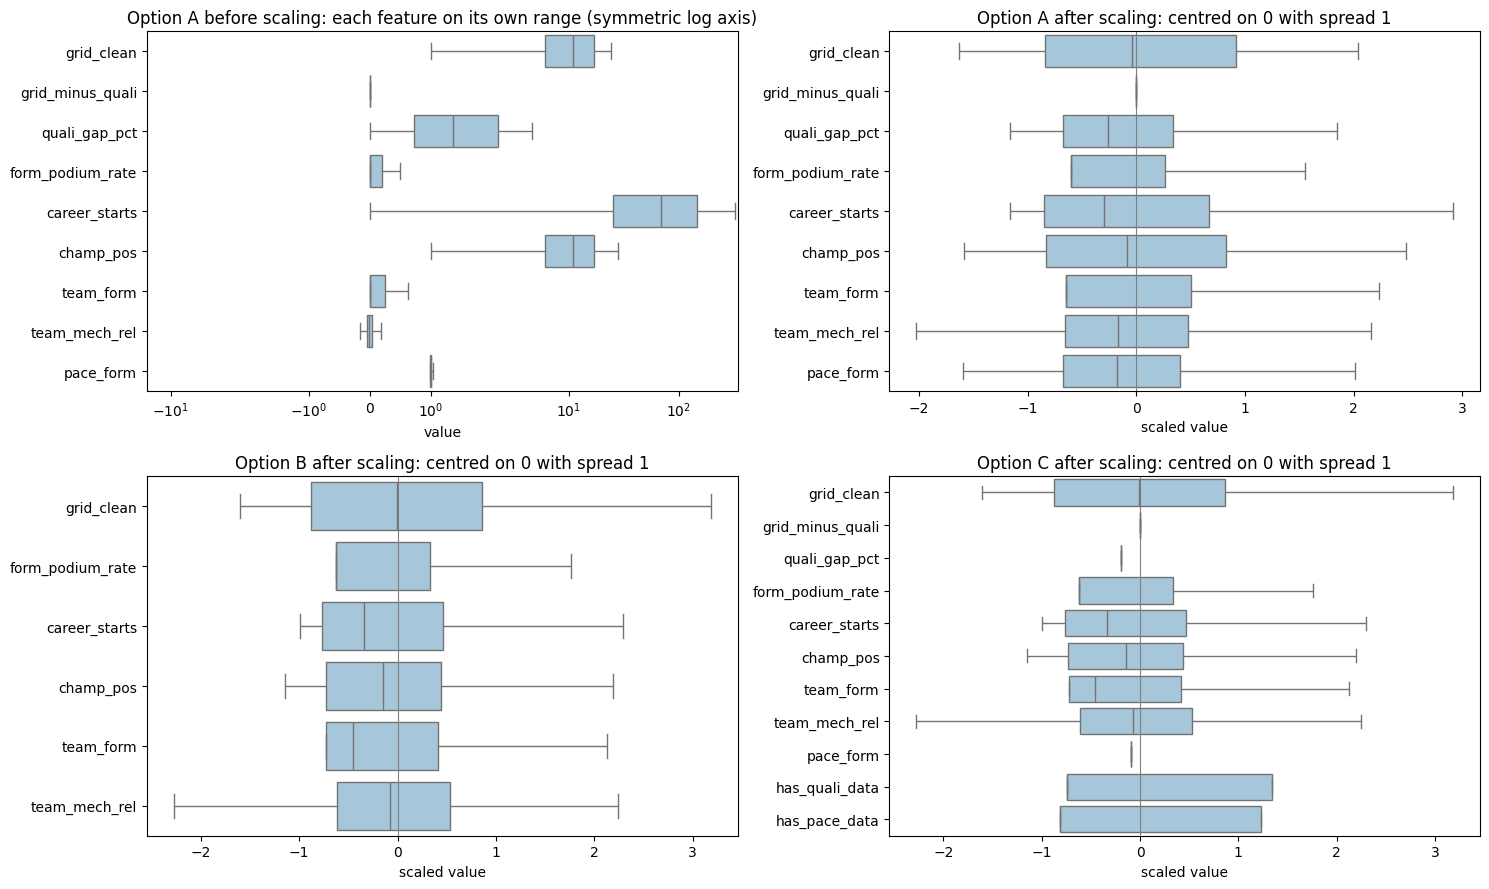

In [281]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# every option: mean and spread learned from its own training part
opt_scaler, opt_scaled = {}, {}
for o, (first, feats) in OPTIONS.items():
    d = opt_capped[o].copy()
    d[feats] = d[feats].astype(float)
    opt_scaler[o] = StandardScaler().fit(d.loc[d.split == 'train', feats])
    d[feats] = opt_scaler[o].transform(d[feats])
    opt_scaled[o] = d

# option A keeps the names used in the rest of this section
scaler, scaled = opt_scaler['A'], opt_scaled['A']

rows = []
for o, (first, feats) in OPTIONS.items():
    sc, d = opt_scaler[o], opt_scaled[o]
    for k, f in enumerate(feats):
        rows.append({'feature': f, 'option': o, 'training mean': sc.mean_[k], 'training spread': sc.scale_[k],
                     'validation mean after': d.loc[d.split == 'validation', f].mean(),
                     'test mean after': d.loc[d.split == 'test', f].mean()})
sc_table = pd.DataFrame(rows).pivot(index='feature', columns='option').reindex(F + FLAGS)
sc_table.columns = [f'{o} {c}' for c, o in sc_table.columns]
sc_table = sc_table[[f'{o} {c}' for o in OPTIONS for c in ['training mean', 'training spread', 'validation mean after', 'test mean after']]]
display(sc_table.style.format('{:.2f}', na_rep='–')
        .set_caption('Scaling learned from the training part of each option, and the scaled means of validation and test (– = the option does not use the feature)'))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
long_before = capped.loc[train_mask, F].melt(var_name='feature', value_name='value')
sns.boxplot(data=long_before, x='value', y='feature', orient='h', showfliers=False, color='#9ecae1', ax=axes[0, 0])
axes[0, 0].set_xscale('symlog'); axes[0, 0].set(title='Option A before scaling: each feature on its own range (symmetric log axis)', xlabel='value', ylabel='')
for ax, o in zip([axes[0, 1], axes[1, 0], axes[1, 1]], OPTIONS):
    d, feats = opt_scaled[o], OPTIONS[o][1]
    long_after = d.loc[d.split == 'train', feats].melt(var_name='feature', value_name='value')
    sns.boxplot(data=long_after, x='value', y='feature', orient='h', showfliers=False, color='#9ecae1', ax=ax)
    ax.axvline(0, color='grey', lw=0.8); ax.set(title=f'Option {o} after scaling: centred on 0 with spread 1', xlabel='scaled value', ylabel='')
plt.tight_layout(); plt.show()

**Reading.**
- **How to read the table.** The training mean and spread are the values scaling learned from each option's training part. After scaling, the training part of every option has mean 0 and spread 1 (the boxes in the charts sit around 0). The validation and test means after scaling show how far the later seasons are from the training average, counted in spreads. Close to 0 means the later seasons look like the training seasons, and far from 0 (beyond about ±0.5) means they look different from what the model learns from.
- **The shape does not change.** Scaling only shifts and stretches each feature, so the order of the rows, the skew and the AUC stay exactly the same.
- **`career_starts` shows the biggest difference.** In option A the average training driver had made 93 starts, and validation and test are 0.30 and 0.68 spreads above that, so today's drivers are a little more experienced. In options B and C the average training driver had made only 61 starts, because careers were short in the early seasons, so validation and test are 0.91 and 1.40 spreads above it. To a model trained on 1950–2018, today's drivers look unusually experienced.
- **The flags of option C.** The training mean of `has_quali_data` is 0.36 and that of `has_pace_data` 0.40, so only 36–40% of option C's training rows have real qualifying and pace data. Every validation and test row has both, so they sit at 1.35 and 1.23. Option C mostly learns from races without this data, but it is scored only on races with it.
- **Qualifying gaps are smaller today.** The test mean of `quali_gap_pct` is −0.48 in option A and −0.65 in option C, so the field is closer together in qualifying than in the training seasons.
- **The other features are close in every option.** `grid_clean`, `champ_pos`, driver and team form and reliability stay within about ±0.35. The validation and test means of `grid_clean` and `champ_pos` are a little below 0 in options B and C (−0.22 and −0.34), because the older races had larger fields.
- **Overall, validation and test are closest to option A's training part** and further from the training part of B and C. This is one possible reason for the 1950 options to do worse, which section 10 tests.

## 9.6 Preprocessing-order experiments

The steps above are done in the order **fill, cap, scale**. We chose this order because each step needs the one before it.
- **Fill before scaling.** The fill rules have a meaning in the original units. A `form_podium_rate` of 0 means "no podium yet", and the worst `champ_pos` + 1 means "one place behind everyone". After scaling, 0 means "an average podium rate" and +1 means "one spread behind".
- **Cap before scaling.** The mean and spread are pulled by extreme values. If the scaling is learned first, a few problem laps and new teams stretch the scale of the whole feature.
- **Fill before capping** matters little here, because the limits are learned from the real values (9.3) and the fill values sit inside them.

Two experiments test the two orders that break these reasons.

| Order | What it tests |
|---|---|
| fill → cap → scale | our order |
| Experiment 1, fill → scale → cap | the scaling is learned with the extreme values still in. The capping limits are then learned on the scaled values, and the 7% qualifying limit is converted to scaled units. |
| Experiment 2, cap → scale → fill | the fill rules are applied to scaled values, so the same rule gives a different value |

Each experiment prepares the data of every option (A, B and C) in the other order, trains two models on the training part and scores them on the validation part. The models are logistic regression and gradient boosting with their default settings, because the settings are only chosen in section 10. The test part is not used.

**How sure is a difference?** The validation part has only 60 races and 180 podiums, so a small difference in PR-AUC can be luck. To measure this, the 60 races are **redrawn 1,000 times** (each time some races are drawn twice and some not at all, always with all their drivers), the difference between two orders is computed on every redraw, and the middle 95% is kept. A difference is **clear** when this range does not include 0. Whole races are redrawn because the drivers of one race depend on each other, as only 3 of them can finish on the podium.

In [282]:
from sklearn.ensemble import HistGradientBoostingClassifier

def race_redraws(rows, n=1000, seed=0):
    """n random redraws of the races in `rows`, each race with all its drivers (lists of row positions)."""
    rng = np.random.default_rng(seed)
    races = [np.flatnonzero(rows.raceId.values == r) for r in rows.raceId.unique()]
    return [np.concatenate([races[i] for i in rng.integers(0, len(races), len(races))]) for _ in range(n)]

def change_range(y, p_a, p_b, redraws):
    """95% range of the change in PR-AUC from model A to model B (B minus A) over the redraws."""
    y = np.asarray(y)
    changes = [average_precision_score(y[r], p_b[r]) - average_precision_score(y[r], p_a[r]) for r in redraws]
    return np.percentile(changes, [2.5, 97.5])

def preprocess(learn_from):
    """Our order for option A (fill, cap, scale), with all values learned from the rows in learn_from. Used again in 10.9."""
    learned = fit_fill(data[learn_from])
    f = apply_fill(data, learned)
    caps = fit_caps(data[learn_from])                                     # from the real values, as in 9.3
    f = apply_caps(f, caps)
    sc = StandardScaler().fit(f.loc[learn_from, F])
    f[F] = sc.transform(f[F])
    return learned, caps, sc, f

def fill_scale_cap(o):
    """Experiment 1: fill, then scale (learned with the extreme values still in), then cap."""
    feats = OPTIONS[o][1]
    d = opt_filled[o].copy()
    d[feats] = d[feats].astype(float)
    tr = d.split == 'train'
    sc = StandardScaler().fit(d.loc[tr, feats])
    d[feats] = sc.transform(d[feats])
    for f in [f for f in ['team_mech_rel', 'pace_form'] if f in feats]:
        lo, hi = d.loc[tr & opt_data[o][f].notna(), f].quantile([0.01, 0.99])   # limits from the real values, now in scaled units
        d[f] = d[f].clip(lo, hi)
    if 'quali_gap_pct' in feats:
        k = feats.index('quali_gap_pct')
        d['quali_gap_pct'] = d.quali_gap_pct.clip(upper=(QUALI_CAP - sc.mean_[k]) / sc.scale_[k])   # 7% in scaled units
    return d, sc

def cap_scale_fill(o):
    """Experiment 2: cap, then scale (missing values are skipped), then fill with the same rules on the scaled values."""
    feats = OPTIONS[o][1]
    d = apply_caps(opt_data[o], opt_caps[o])
    d[feats] = d[feats].astype(float)
    tr = d.split == 'train'
    sc = StandardScaler().fit(d.loc[tr, feats])
    d[feats] = sc.transform(d[feats])
    if 'quali_gap_pct' in feats:
        k = feats.index('quali_gap_pct')
        d['quali_prev_median'] = (d.quali_prev_median.clip(upper=QUALI_CAP) - sc.mean_[k]) / sc.scale_[k]
    d = apply_fill(d, fit_fill(d[tr]))
    return d, sc

orders = {o: {'fill, cap, scale (ours)': opt_scaled[o], 'fill, scale, cap (experiment 1)': fill_scale_cap(o)[0],
              'cap, scale, fill (experiment 2)': cap_scale_fill(o)[0]} for o in OPTIONS}
for o, (first, feats) in OPTIONS.items():
    for name, d in orders[o].items():
        assert d[feats].notna().all().all(), f'option {o}, {name}: a value is missing'

In [283]:
def val_probs(d, feats):
    """Logistic regression and gradient boosting (default settings) trained on the training part, probabilities on the validation part."""
    tr, va = d[d.split == 'train'], d[d.split == 'validation']
    lr = LogisticRegression(max_iter=5000).fit(tr[feats], tr.podium)
    gb = HistGradientBoostingClassifier(early_stopping=False, random_state=0).fit(tr[feats], tr.podium)
    return {'logistic regression': lr.predict_proba(va[feats])[:, 1], 'gradient boosting': gb.predict_proba(va[feats])[:, 1]}

val_part = opt_data['A'][opt_data['A'].split == 'validation']           # the same validation rows in every option
order_redraws = race_redraws(val_part)
y_va = val_part.podium.values

rows = []
for o, (first, feats) in OPTIONS.items():
    probs = {name: val_probs(d, feats) for name, d in orders[o].items()}
    for model in ['logistic regression', 'gradient boosting']:
        ours = probs['fill, cap, scale (ours)'][model]
        for name in orders[o]:
            p = probs[name][model]
            r = {'option': o, 'model': model, 'order': name,
                 'ROC-AUC': roc_auc_score(y_va, p), 'PR-AUC': average_precision_score(y_va, p)}
            if name != 'fill, cap, scale (ours)':
                lo, hi = change_range(y_va, ours, p, order_redraws)
                r['change in PR-AUC'] = r['PR-AUC'] - average_precision_score(y_va, ours)
                r['95% range of the change'] = f'{lo:+.3f} to {hi:+.3f}'
                r['clear?'] = 'yes' if (lo > 0 or hi < 0) else 'no'
            rows.append(r)
order_results = pd.DataFrame(rows)
display(order_results.style.format({'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}', 'change in PR-AUC': '{:+.3f}'}, na_rep='–')
        .hide(axis='index').set_caption('Validation part (2019-2021): each order, option and model'))

option,model,order,ROC-AUC,PR-AUC,change in PR-AUC,95% range of the change,clear?
A,logistic regression,"fill, cap, scale (ours)",0.932,0.717,–,–,–
A,logistic regression,"fill, scale, cap (experiment 1)",0.932,0.717,+0.000,-0.000 to +0.001,no
A,logistic regression,"cap, scale, fill (experiment 2)",0.932,0.716,-0.001,-0.002 to +0.001,no
A,gradient boosting,"fill, cap, scale (ours)",0.928,0.700,–,–,–
A,gradient boosting,"fill, scale, cap (experiment 1)",0.928,0.698,-0.002,-0.017 to +0.014,no
A,gradient boosting,"cap, scale, fill (experiment 2)",0.929,0.703,+0.003,-0.013 to +0.019,no
B,logistic regression,"fill, cap, scale (ours)",0.927,0.702,–,–,–
B,logistic regression,"fill, scale, cap (experiment 1)",0.927,0.702,-0.000,-0.000 to +0.000,no
B,logistic regression,"cap, scale, fill (experiment 2)",0.927,0.702,-0.000,-0.001 to +0.001,no
B,gradient boosting,"fill, cap, scale (ours)",0.933,0.722,–,–,–


In [284]:
# experiment 1: the spread learned with and without the extreme values, and the spread left after capping
rows = []
for o, (first, feats) in OPTIONS.items():
    d1, sc1 = fill_scale_cap(o)
    tr = d1.split == 'train'
    for f in [f for f in ['quali_gap_pct', 'team_mech_rel', 'pace_form'] if f in feats]:
        k = feats.index(f)
        rows.append({'option': o, 'feature': f, 'spread learned, our order (capped first)': opt_scaler[o].scale_[k],
                     'spread learned, experiment 1 (extremes in)': sc1.scale_[k],
                     'spread of the training part after scaling, experiment 1': d1.loc[tr, f].std()})
spreads = pd.DataFrame(rows)
display(spreads.style.format('{:.3f}', subset=list(spreads.columns[2:])).hide(axis='index')
        .set_caption('Experiment 1: the extreme values stretch the scale'))

# experiment 2: the same fill rule gives a different value, shown in original units
def back_to_units(v, f, sc, feats):
    k = feats.index(f)
    return v * sc.scale_[k] + sc.mean_[k]

rows = []
for o, (first, feats) in OPTIONS.items():
    d2, sc2 = cap_scale_fill(o)
    debut, no_standing = opt_data[o].form_podium_rate.isna(), opt_data[o].champ_pos.isna()
    rows.append({'option': o, 'value': 'form_podium_rate of a first start',
                 'our order': opt_filled[o].loc[debut, 'form_podium_rate'].mean(),
                 'experiment 2': back_to_units(d2.loc[debut, 'form_podium_rate'].mean(), 'form_podium_rate', sc2, feats)})
    rows.append({'option': o, 'value': 'champ_pos of a driver with no standing (average)',
                 'our order': opt_filled[o].loc[no_standing, 'champ_pos'].mean(),
                 'experiment 2': back_to_units(d2.loc[no_standing, 'champ_pos'].mean(), 'champ_pos', sc2, feats)})
display(pd.DataFrame(rows).style.format('{:.2f}', subset=['our order', 'experiment 2']).hide(axis='index')
        .set_caption('Experiment 2: the same fill rule gives a different value (original units)'))

option,feature,"spread learned, our order (capped first)","spread learned, experiment 1 (extremes in)","spread of the training part after scaling, experiment 1"
A,quali_gap_pct,1.524,1.854,0.822
A,team_mech_rel,0.084,0.092,0.913
A,pace_form,0.015,0.016,0.936
B,team_mech_rel,0.121,0.128,0.941
C,quali_gap_pct,1.093,1.294,0.844
C,team_mech_rel,0.121,0.128,0.941
C,pace_form,0.009,0.011,0.885


option,value,our order,experiment 2
A,form_podium_rate of a first start,0.00,0.14
A,champ_pos of a driver with no standing (average),22.45,27.95
B,form_podium_rate of a first start,0.00,0.13
B,champ_pos of a driver with no standing (average),40.14,49.04
C,form_podium_rate of a first start,0.00,0.13
C,champ_pos of a driver with no standing (average),40.14,49.04


**Reading.**

**The scores (first table).** No order makes a clear difference, for any option or either model. Every 95% range includes 0.
- **Logistic regression** changes by at most 0.001 in PR-AUC in both experiments and every option.
- **Gradient boosting** does not change in experiment 1 for options B and C, because trees only look at the order of the values, and scaling and capping keep that order. Option A moves by −0.002, a tiny difference that is not clear.
- **Experiment 2 moves gradient boosting the most**, by −0.018 in option B and +0.013 in option C. The two changes go in opposite directions and both ranges include 0, so there is no pattern.

**The values (second and third tables).** The two other orders put wrong values into the data.
- **Experiment 1 lets the extreme values stretch the scale.** In option A, the spread of `quali_gap_pct` learned with the extreme laps still in is 1.85, against 1.52 when they are capped first. After capping, the normal drivers are squeezed together, with a spread of 0.82 instead of 1. The other capped features show the same effect, only smaller.
- **Experiment 2 changes the meaning of the fill rules.** A driver at their first start gets a `form_podium_rate` of 0.14 instead of 0 in option A, so every rookie looks like a driver with a podium in 1 of every 7 races. A driver with no standing is placed about 28th on average instead of about 22nd, because "+1" now means one spread (about 6 places) instead of one place. Options B and C show the same, with 0.13 instead of 0 and about 49th instead of 40th.

**With the tuned models.** The same two orders are tried again with the models carried forward, at the end of 10.6.

**Why the scores barely move.** Only a few rows get these wrong values, mostly first starts, drivers with no standing and a few extreme laps, so the models change little.

**Decision.** The order fill, cap, scale is kept. It does not score clearly better, but it is the only one of the three in which every filled value means what its rule says, and in which the scale is not decided by a few extreme rows.

## 9.7 The modelling table

The result of this section is one modelling table per option, with one row per driver per race in the option's seasons, the option's features with no missing value, and the target `podium`. The tables keep the filled and capped values in their original units (easy to read and to explain). The models use the scaled copies, all scaled with the values of the option's training part (`X_train`, `X_val` and `X_test` for option A, and `opt_X` for every option).

The checks below make sure that no value is missing, that no driver appears twice in a race, and that every race has 3 podiums. The only races with more than 3 are those in which a shared car finished on the podium (9.1), because both of its drivers are counted.

In [285]:
g = fe[model_rows]
shared_rows = g.index[g.duplicated(['raceId', 'positionOrder', 'constructorId'], keep=False)]

opt_table, rows = {}, []
for o, (first, feats) in OPTIONS.items():
    t = opt_capped[o][ID_COLS + feats + ['podium']]
    assert t[feats + ['podium']].notna().all().all(), f'option {o}: a value is missing'
    assert not t.duplicated(['raceId', 'driverId']).any(), f'option {o}: a driver appears twice in a race'
    podiums = t.groupby('raceId').podium.sum()
    shared_podium_races = set(t.loc[t.index.isin(shared_rows) & (t.podium == 1), 'raceId'])
    assert (podiums >= 3).all(), f'option {o}: a race has fewer than 3 podiums'
    assert set(podiums[podiums > 3].index) <= shared_podium_races, f'option {o}: extra podiums that are not shared cars'
    if 'quali_gap_pct' in feats:
        assert t.quali_gap_pct.max() <= QUALI_CAP
    opt_table[o] = t
    for part in ['train', 'validation', 'test']:
        p = t[t.split == part]
        rows.append({'option': o, 'part': part, 'seasons': f'{p.year.min()}-{p.year.max()}', 'races': p.raceId.nunique(),
                     'rows': len(p), 'podiums': int(p.podium.sum()), 'podium rate': p.podium.mean(), 'features': len(feats),
                     'races with more than 3 podiums': int((podiums[p.raceId.unique()] > 3).sum())})
table(pd.DataFrame(rows), pct1=['podium rate'], caption='The modelling table of each option (all checks passed)')

# option A keeps the name used later
model_table = opt_table['A'].reset_index(drop=True)

example = (model_table.merge(drivers[['driverId', 'surname']], on='driverId')
                      .query("year == 2018 and round == 1").sort_values('grid_clean').head(5))
whole = ['grid_clean', 'grid_minus_quali', 'career_starts', 'champ_pos']
display(example[['year', 'round', 'surname'] + F + ['podium']]
        .style.format({f: '{:.0f}' if f in whole else '{:.3f}' for f in F})
        .hide(axis='index').set_caption('Example from option A: the first five on the grid, Australia 2018'))

# the scaled inputs of the models, for every option
opt_X = {}
for o, (first, feats) in OPTIONS.items():
    d = opt_scaled[o]
    opt_X[o] = {part: (d.loc[d.split == part, feats], d.loc[d.split == part, 'podium']) for part in ['train', 'validation', 'test']}
    print(f'option {o}: scaled inputs ' + ' | '.join(f'{part} {opt_X[o][part][0].shape}' for part in opt_X[o]))

# option A keeps the names used in section 10
(X_train, y_train), (X_val, y_val), (X_test, y_test) = opt_X['A']['train'], opt_X['A']['validation'], opt_X['A']['test']

option,part,seasons,races,rows,podiums,podium rate,features,races with more than 3 podiums
A,train,2003-2018,300,6407,900,14.0%,9,0
A,validation,2019-2021,60,1200,180,15.0%,9,0
A,test,2022-2024,68,1359,204,15.0%,9,0
B,train,1950-2018,986,22362,2975,13.3%,6,15
B,validation,2019-2021,60,1200,180,15.0%,6,0
B,test,2022-2024,68,1359,204,15.0%,6,0
C,train,1950-2018,986,22362,2975,13.3%,11,15
C,validation,2019-2021,60,1200,180,15.0%,11,0
C,test,2022-2024,68,1359,204,15.0%,11,0


year,round,surname,grid_clean,grid_minus_quali,quali_gap_pct,form_podium_rate,career_starts,champ_pos,team_form,team_mech_rel,pace_form,podium


option A: scaled inputs train (6407, 9) | validation (1200, 9) | test (1359, 9)
option B: scaled inputs train (22362, 6) | validation (1200, 6) | test (1359, 6)
option C: scaled inputs train (22362, 11) | validation (1200, 11) | test (1359, 11)


# 10. Models

Three models are trained for each option of the data (8.4). Within one option, the three models use the same modelling table (9.7), with the same rows, features and split, so their scores can be compared directly.

| Model | Type | Role |
|---|---|---|
| Logistic regression | statistical | the **baseline**, the simplest reasonable model |
| Gradient boosting | statistical (trees) | a more flexible model. Does it earn its extra complexity? |
| Shallow neural network (PyTorch) | neural network, 1–2 hidden layers | the same question for a network |

**The options.** Options A, B and C use the time split, with the same validation seasons (2019–2021) and the same test seasons (2022–2024). They differ in the training seasons and the features (2003 with the 9 features, 1950 with 6 features, and 1950 with the 9 features and the two extra features). Option D uses the training seasons and features of each option carried forward (10.6), but divides training and validation into random whole races.

All choices (settings, threshold, number of training rounds) are made on the **validation part** of the option. The test part (2022–2024) is only used at the end.

## 10.1 How the models are scored

Every model outputs a **probability of a podium** for each driver in each race. The scores:

| Score | What it measures | Needs a threshold? |
|---|---|---|
| **ROC-AUC** | How well the probabilities separate podium and non-podium drivers overall: the chance that a random podium driver gets a higher probability than a random non-podium driver. 0.5 = guessing, 1 = perfect. | no |
| **PR-AUC** | How well the podium drivers are ranked at the top. It looks only at the podium class, so it is more informative than ROC-AUC when podiums are rare (about 15% of rows). Guessing gives about 0.15. | no |
| **F1** | Turns the probabilities into yes/no with a threshold, then balances precision (of the drivers predicted on the podium, how many were) and recall (of the real podium drivers, how many were found). | yes |
| **Top-3 per race** | In each race, take the 3 drivers with the highest probability and count how many really finished on the podium. Not required, but it is the most natural question for F1 racing. | no |

**Main score for choosing settings: PR-AUC.** Podiums are the rare class we care about, and PR-AUC needs no threshold. **Second score: F1**, the quality of the yes/no answers at the chosen threshold. Both choices are explained with evidence in 10.10.

**The threshold for F1** is chosen on the validation part, as the probability cut-off that gives the best F1 there, and will be reused unchanged on the test part. A threshold of 0.5 is not used, because with 15% podiums it would predict too few.

**Reference: the grid.** The rule "the top 3 on the grid finish on the podium" needs no model at all. It is not one of the three models, but it shows how much the models add beyond the starting grid.

**Step 1: libraries and the parts of each option.** `opt_rows` holds the scaled training, validation and test rows of every option (9.7). `train_rows` and `val_rows` are those of option A.

In [286]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, log_loss,
                             precision_recall_curve, roc_curve, confusion_matrix)

opt_rows = {o: {part: opt_scaled[o][opt_scaled[o].split == part] for part in ['train', 'validation', 'test']} for o in OPTIONS}
train_rows, val_rows = opt_rows['A']['train'], opt_rows['A']['validation']

**Step 2: the scoring functions.** `best_threshold` finds the F1 cut-off on the validation part, `top3_hits` computes the top-3 per race score, and `scores` computes every score of one model on one part. `train_and_validation_scores` puts the scores of one model of one option on its training and validation part in a table, and `show_table` shows a table.

In [287]:
def best_threshold(y, p):
    """The probability cut-off with the best F1 on these rows."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return thr[np.argmax(f1[:-1])]

def top3_hits(rows, p):
    """Share of each race's 3 highest probabilities that finished on the podium."""
    d = rows[['raceId', 'podium']].assign(p=np.asarray(p))
    d['rank'] = d.groupby('raceId').p.rank(ascending=False, method='first')
    return d.loc[d['rank'] <= 3, 'podium'].mean()

def scores(rows, p, threshold):
    y, pred = rows.podium, (np.asarray(p) >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'F1': f1_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred),
            'top-3 per race': top3_hits(rows, p)}

def train_and_validation_scores(train_prob, val_prob, threshold, option='A'):
    """The scores of one model of one option on its training and validation part, as a table."""
    return pd.DataFrame({'train': scores(opt_rows[option]['train'], train_prob, threshold),
                         'validation': scores(opt_rows[option]['validation'], val_prob, threshold)}).T

def show_table(df, caption, decimals=4):
    display(df.style.format(precision=decimals).hide(axis='index').set_caption(caption))

**Step 3: the grid reference.** The rule "the top 3 on the grid finish on the podium", scored like a model. The scoring functions expect "higher = more likely on the podium", so the grid slot is made negative (P1 becomes −1), and the threshold −3 means grid 1, 2 or 3. It is scored for every option. Options A, B and C have the same validation rows, so the grid gets the same validation score in all three, and only the training score differs.

In [288]:
# the grid slot, turned negative so that a higher value means "more likely on the podium": P1 -> -1, P20 -> -20
# threshold -3: "predicted podium" = a value of -3 or more = grid 1, 2 or 3
opt_grid, rows = {}, []
for o in OPTIONS:
    opt_grid[o] = {part: -opt_capped[o].loc[opt_rows[o][part].index, 'grid_clean'].values for part in ['train', 'validation']}
    for part in ['train', 'validation']:
        rows.append({'option': o, 'part': part, **scores(opt_rows[o][part], opt_grid[o][part], -3)})
display(pd.DataFrame(rows).style.format('{:.3f}', subset=['ROC-AUC', 'PR-AUC', 'F1', 'precision', 'recall', 'top-3 per race'])
        .hide(axis='index').set_caption('Reference: "the top 3 on the grid finish on the podium", for each option'))

# option A keeps the names used later
train_grid, val_grid = opt_grid['A']['train'], opt_grid['A']['validation']
grid_score = {'train': train_grid, 'validation': val_grid}
grid_results = {'train': scores(train_rows, train_grid, -3), 'validation': scores(val_rows, val_grid, -3)}

option,part,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
A,train,0.907,0.617,0.638,0.638,0.638,0.638
A,validation,0.917,0.676,0.717,0.717,0.717,0.717
B,train,0.883,0.493,0.538,0.540,0.536,0.540
B,validation,0.917,0.676,0.717,0.717,0.717,0.717
C,train,0.883,0.493,0.538,0.540,0.536,0.540
C,validation,0.917,0.676,0.717,0.717,0.717,0.717


**Reading.**
- **Every row asks one question.** If we predicted that the drivers starting P1, P2 and P3 finish on the podium, how often would we be right? The top-3 per race score is the share of these top-3 starters who really finished on the podium.
- **In recent seasons the grid is a strong predictor.** In the validation seasons (2019–2021), 71.7% of the top-3 starters finished on the podium, about 2 of every 3. Its PR-AUC there is 0.676 and its ROC-AUC 0.917. These are the scores the models have to beat.
- **In the older seasons the grid predicted the podium less well.** In option A's training seasons (2003–2018), 63.8% of the top-3 starters reached the podium, and in the training seasons of B and C (1950–2018) only 54.0%. Cars broke down far more often in the early decades, so a front-row start guaranteed much less. This is another way in which the old seasons differ from today.
- **The validation rows are the same in options A, B and C**, so the grid gets the same validation scores in all three.
- **Why F1, precision, recall and top-3 are the same number for option A.** The rule always predicts exactly 3 drivers per race, and every race has exactly 3 podiums. Precision (of the 3 picked, how many were right) and recall (of the 3 real podium finishers, how many were picked) then divide the same number of right answers by 3, so they are equal, and F1 and the top-3 score equal them too. In the training part of B and C they differ a little (0.540 against 0.536), because of the shared-car races with more than 3 podiums.

## 10.2 Baseline: logistic regression

**How it works.** Logistic regression gives each feature a weight. For a driver it adds up *weight × feature value* over the features of the option, plus a constant, and turns the total into a probability between 0 and 1 with the logistic (S-shaped) curve. A positive weight means a higher value raises the podium probability. Training finds the weights that make the observed podiums as likely as possible. Because the features are scaled (9.5), the weights can be compared with each other. A bigger weight (in absolute value) means a bigger effect for a one-standard-deviation change.

**Setting to choose: `C`, the regularisation strength.** Regularisation keeps the weights small, so the model does not lean too heavily on any feature. A small `C` means strong regularisation (simpler model), a large `C` means weak regularisation. For each option, each value is trained on the option's training part and scored on its validation part, and each option keeps its own best `C`.

**Step 1: try settings.** For each option, one model per value of `C`, trained on the option's training part and scored on its validation part.

In [289]:
results = []
for o in OPTIONS:
    X_tr, y_tr = opt_X[o]['train']
    X_va, y_va = opt_X[o]['validation']
    for C in [0.001, 0.01, 0.1, 1, 10, 100, 200]:
        model = LogisticRegression(C=C, max_iter=5000)
        model.fit(X_tr, y_tr)
        train_prob = model.predict_proba(X_tr)[:, 1]       # probability of a podium, for each training row
        val_prob = model.predict_proba(X_va)[:, 1]
        results.append({'option': o, 'C': C,
                        'train PR-AUC': average_precision_score(y_tr, train_prob),
                        'validation PR-AUC': average_precision_score(y_va, val_prob),
                        'validation ROC-AUC': roc_auc_score(y_va, val_prob)})

lr_tuning = pd.DataFrame(results)
show_table(lr_tuning, 'Logistic regression: choosing C for each option')

option,C,train PR-AUC,validation PR-AUC,validation ROC-AUC
A,0.0010,0.6200,0.6730,0.9256
A,0.0100,0.6551,0.6972,0.9301
A,0.1000,0.6724,0.7129,0.9318
A,1.0000,0.6751,0.7167,0.9320
A,10.0000,0.6754,0.7170,0.9320
A,100.0000,0.6754,0.7171,0.9320
A,200.0000,0.6754,0.7171,0.9320
B,0.0010,0.5401,0.6745,0.9278
B,0.0100,0.5575,0.6951,0.9272
B,0.1000,0.5599,0.7018,0.9273


**Step 2: train the models**, one per option, each with its best `C` and on its own training part.

In [290]:
opt_lr_c, opt_lr = {}, {}
for o in OPTIONS:
    tuning = lr_tuning[lr_tuning.option == o]
    opt_lr_c[o] = tuning.loc[tuning['validation PR-AUC'].idxmax(), 'C']          # the C with the best validation PR-AUC
    X_tr, y_tr = opt_X[o]['train']
    opt_lr[o] = LogisticRegression(C=opt_lr_c[o], max_iter=5000).fit(X_tr, y_tr)   # the training happens here
    print(f'option {o}: logistic regression with C = {opt_lr_c[o]:g}, trained on {len(X_tr)} rows')

# option A keeps the names used later
LR_C, lr = opt_lr_c['A'], opt_lr['A']

option A: logistic regression with C = 100, trained on 6407 rows
option B: logistic regression with C = 1, trained on 22362 rows
option C: logistic regression with C = 1, trained on 22362 rows


**Step 3: scores** of each option on its training and validation part. Each option gets its own F1 threshold, chosen on its validation part (10.1).

In [291]:
opt_p_lr, opt_lr_threshold, opt_lr_results = {}, {}, {}
for o in OPTIONS:
    p = {part: opt_lr[o].predict_proba(opt_X[o][part][0])[:, 1] for part in ['train', 'validation']}
    opt_p_lr[o] = p
    opt_lr_threshold[o] = best_threshold(opt_X[o]['validation'][1], p['validation'])     # chosen on validation
    opt_lr_results[o] = train_and_validation_scores(p['train'], p['validation'], opt_lr_threshold[o], option=o)

all_results = pd.concat({o: r for o, r in opt_lr_results.items()}, names=['option', 'part']).reset_index()
all_results.insert(2, 'F1 threshold', all_results.option.map(opt_lr_threshold))
display(all_results.style.format('{:.3f}', subset=list(all_results.columns[2:])).hide(axis='index')
        .set_caption('Logistic regression: training and validation scores of each option'))

# option A keeps the names used later
p_lr, lr_threshold, lr_results = opt_p_lr['A'], opt_lr_threshold['A'], opt_lr_results['A']

option,part,F1 threshold,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
A,train,0.368,0.927,0.675,0.652,0.612,0.698,0.642
A,validation,0.368,0.932,0.717,0.730,0.679,0.789,0.678
B,train,0.367,0.898,0.560,0.561,0.552,0.570,0.547
B,validation,0.367,0.927,0.702,0.738,0.693,0.789,0.694
C,train,0.319,0.900,0.563,0.577,0.525,0.642,0.549
C,validation,0.319,0.930,0.709,0.725,0.664,0.800,0.700


**Step 4: chart.** The learned weight of each feature, for each option.

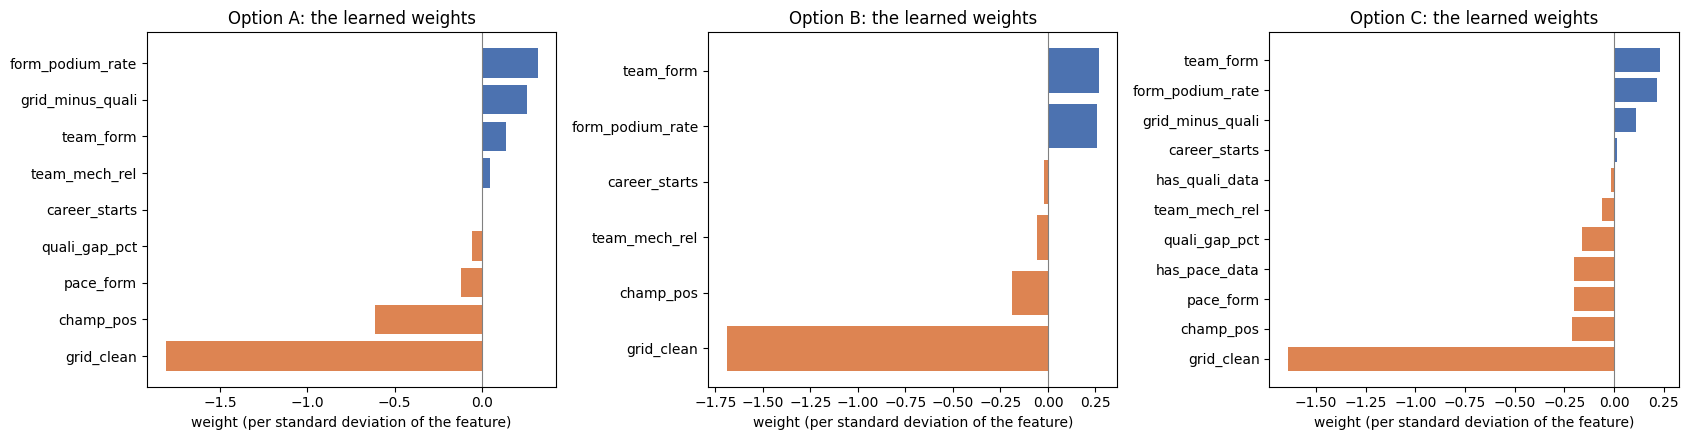

In [292]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, o in zip(axes, OPTIONS):
    weights = pd.Series(opt_lr[o].coef_[0], index=OPTIONS[o][1]).sort_values()
    ax.barh(weights.index, weights.values, color=np.where(weights.values > 0, '#4C72B0', '#DD8452'))
    ax.axvline(0, color='grey', lw=0.8)
    ax.set(xlabel='weight (per standard deviation of the feature)', title=f'Option {o}: the learned weights')
plt.tight_layout(); plt.show()

**Reading.**
- **`C` barely matters** once it is 0.1 or more, in every option (validation PR-AUC 0.713–0.717 in option A, 0.702 in B and 0.708–0.709 in C). Option A chooses 100 and options B and C choose 1, but the differences are in the fourth decimal. With few features and thousands of training rows, the model has little room to overfit, so it needs almost no regularisation.
- **Option A scores best on PR-AUC** (0.717, against 0.702 for B and 0.709 for C), and the ROC-AUC is about the same in all three (0.927–0.932). On F1 and the top-3 per race, B and C are a little higher (top-3 0.694 and 0.700 against 0.678). The differences are small, and whether they are clear or luck is tested when the options are compared.
- **The validation scores are higher than the training scores**, most of all in B and C (PR-AUC 0.717 against 0.675 in option A, and about 0.70 against 0.56 in B and C). This is not a mistake. 2019–2021 were easier seasons to predict (Mercedes and then Red Bull won most races), and their podium share is a little higher, which raises PR-AUC by itself. The older seasons of B and C are harder still, because the grid predicted the podium much less well there (10.1). The grid reference shows the same pattern.
- **The grid is still hard to beat on the top-3 per race.** Picking the top 3 on the grid gets 0.717 on validation, more than logistic regression in every option. Logistic regression is better on PR-AUC (0.702–0.717 against 0.676), so it ranks all the drivers better, but it does not pick the 3 podium finishers of a race more often.
- **The weights** confirm section 7 in every option:
  - The grid slot has by far the largest effect (about −1.7 per spread in every option).
  - In option A the championship position comes next (about −0.6), followed by recent form and team form. In B and C the championship position matters much less (about −0.2), and driver form and team form (about +0.2 to +0.3 each) take its place. Over 1950–2018, the standings say less about the next race.
  - `grid_minus_quali` is positive in A and C. Of two drivers starting from the same slot, the one who qualified higher and was moved back has the better chance, as found in 7.2.
  - A smaller `pace_form` and a smaller `quali_gap_pct` (faster) raise the probability.
  - `team_mech_rel` has a small positive weight in option A but a small negative one in B and C, where breakdowns were far more common. In A its information overlaps with team form and the championship position, so its own weight is small and hard to read.
  - In option C, `has_pace_data` has a negative weight of about −0.2 and `has_quali_data` almost none. A straight-line model can only use a flag to add or subtract a fixed amount, not to ignore a filled value, so the flags help it little.

**Limitations of logistic regression.**
- **Straight-line effects only.** Each feature adds a fixed amount per step, so moving from P2 to P1 counts the same as moving from P16 to P15, although the first matters much more for a podium.
- **No interactions.** It cannot learn that a front-row start matters more in a strong team, or that a filled qualifying gap should be ignored, unless such a combination is added by hand as a new feature.
- **Each row is scored on its own.** The model does not know that a race has exactly 3 podiums, so the probabilities within a race do not add up to 3. This is true of all three models.
- **Correlated features make single weights hard to read**, as `team_mech_rel` shows.

## 10.3 Gradient boosting

**How it works.** A decision tree asks a few yes/no questions about the features ("grid slot ≤ 3?", "team form > 0.4?") and gives each group of drivers at the end of the questions a score. Gradient boosting builds many small trees **one after another**. Each new tree is trained to correct the mistakes the previous trees still make, and the final prediction adds up all the trees. Unlike logistic regression it can learn **interactions** (for example, that a front-row start matters more in a strong team) and **non-linear** effects (for example, that the difference between P1 and P3 matters more than between P15 and P17). We use scikit-learn's `HistGradientBoostingClassifier`.

**Settings to choose.**
- `max_depth`: how many questions each tree may ask (deeper trees learn more detailed patterns, but can memorise the training data).
- `learning_rate`: how much each new tree may correct (smaller is more careful but needs more trees).
- `max_iter`: the number of trees.

For each option, every combination is trained on the option's training part and scored on its validation part, and each option keeps its own best combination.

**Step 1: try settings.** For each option, one model per combination, trained on the option's training part and scored on its validation part.

In [293]:
settings = [(depth, rate, trees) for depth in [2, 3, 5] for rate in [0.03, 0.1] for trees in [100, 300]]

results = []
for o in OPTIONS:
    X_tr, y_tr = opt_X[o]['train']
    X_va, y_va = opt_X[o]['validation']
    for depth, rate, trees in settings:
        model = HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate, max_iter=trees,
                                               early_stopping=False, random_state=0)
        model.fit(X_tr, y_tr)
        train_prob = model.predict_proba(X_tr)[:, 1]
        val_prob = model.predict_proba(X_va)[:, 1]
        results.append({'option': o, 'max_depth': depth, 'learning_rate': rate, 'max_iter': trees,
                        'train PR-AUC': average_precision_score(y_tr, train_prob),
                        'validation PR-AUC': average_precision_score(y_va, val_prob),
                        'validation ROC-AUC': roc_auc_score(y_va, val_prob)})

gb_tuning = pd.DataFrame(results).sort_values(['option', 'validation PR-AUC'], ascending=[True, False])
show_table(gb_tuning, 'Gradient boosting: choosing the settings for each option (best first)')

option,max_depth,learning_rate,max_iter,train PR-AUC,validation PR-AUC,validation ROC-AUC
A,2,0.0300,300,0.7139,0.7473,0.9403
A,3,0.0300,300,0.7538,0.7472,0.9401
A,3,0.0300,100,0.7149,0.7453,0.9381
A,3,0.1000,100,0.7604,0.7408,0.9399
A,2,0.0300,100,0.6934,0.7402,0.9389
A,3,0.1000,300,0.8450,0.7370,0.9384
A,5,0.0300,100,0.7883,0.7369,0.9377
A,2,0.1000,300,0.7646,0.7350,0.9396
A,2,0.1000,100,0.7176,0.7341,0.9392
A,5,0.0300,300,0.8533,0.7252,0.9351


**Step 2: train the models**, one per option, each with its best settings and on its own training part. Settings whose validation PR-AUC is the same to three decimals count as a tie, and the tie goes to the smaller model (shallower trees, then fewer trees), so a tiny difference between computers cannot change the choice.

In [294]:
opt_gb_params, opt_gb = {}, {}
for o in OPTIONS:
    t = gb_tuning[gb_tuning.option == o].assign(score=lambda d: d['validation PR-AUC'].round(3))
    best = t.sort_values(['score', 'max_depth', 'max_iter'], ascending=[False, True, True]).iloc[0]
    opt_gb_params[o] = dict(max_depth=int(best['max_depth']), learning_rate=float(best['learning_rate']), max_iter=int(best['max_iter']))
    X_tr, y_tr = opt_X[o]['train']
    opt_gb[o] = HistGradientBoostingClassifier(**opt_gb_params[o], early_stopping=False, random_state=0).fit(X_tr, y_tr)   # the training happens here
    print(f'option {o}: gradient boosting with {opt_gb_params[o]}, trained on {len(X_tr)} rows')

# option A keeps the names used later
GB_PARAMS, gb = opt_gb_params['A'], opt_gb['A']

option A: gradient boosting with {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}, trained on 6407 rows
option B: gradient boosting with {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}, trained on 22362 rows
option C: gradient boosting with {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}, trained on 22362 rows


**Step 3: scores** of each option on its training and validation part, with each option's own F1 threshold chosen on its validation part.

In [295]:
opt_p_gb, opt_gb_threshold, opt_gb_results = {}, {}, {}
for o in OPTIONS:
    p = {part: opt_gb[o].predict_proba(opt_X[o][part][0])[:, 1] for part in ['train', 'validation']}
    opt_p_gb[o] = p
    opt_gb_threshold[o] = best_threshold(opt_X[o]['validation'][1], p['validation'])     # chosen on validation
    opt_gb_results[o] = train_and_validation_scores(p['train'], p['validation'], opt_gb_threshold[o], option=o)

all_results = pd.concat({o: r for o, r in opt_gb_results.items()}, names=['option', 'part']).reset_index()
all_results.insert(2, 'F1 threshold', all_results.option.map(opt_gb_threshold))
display(all_results.style.format('{:.3f}', subset=list(all_results.columns[2:])).hide(axis='index')
        .set_caption('Gradient boosting: training and validation scores of each option'))

# option A keeps the names used later
p_gb, gb_threshold, gb_results = opt_p_gb['A'], opt_gb_threshold['A'], opt_gb_results['A']

option,part,F1 threshold,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
A,train,0.345,0.941,0.714,0.688,0.638,0.747,0.676
A,validation,0.345,0.940,0.747,0.731,0.673,0.800,0.706
B,train,0.351,0.904,0.565,0.574,0.544,0.608,0.561
B,validation,0.351,0.936,0.735,0.740,0.696,0.789,0.706
C,train,0.362,0.904,0.568,0.567,0.551,0.585,0.561
C,validation,0.362,0.935,0.744,0.740,0.701,0.783,0.706


**Step 4: chart.** The loss after each added tree, on the training and the validation part, for each option.

option A: validation loss lowest 0.2078 after 264 trees | 0.2079 after 300 trees
option B: validation loss lowest 0.2284 after 100 trees | 0.2284 after 100 trees
option C: validation loss lowest 0.2282 after 100 trees | 0.2282 after 100 trees


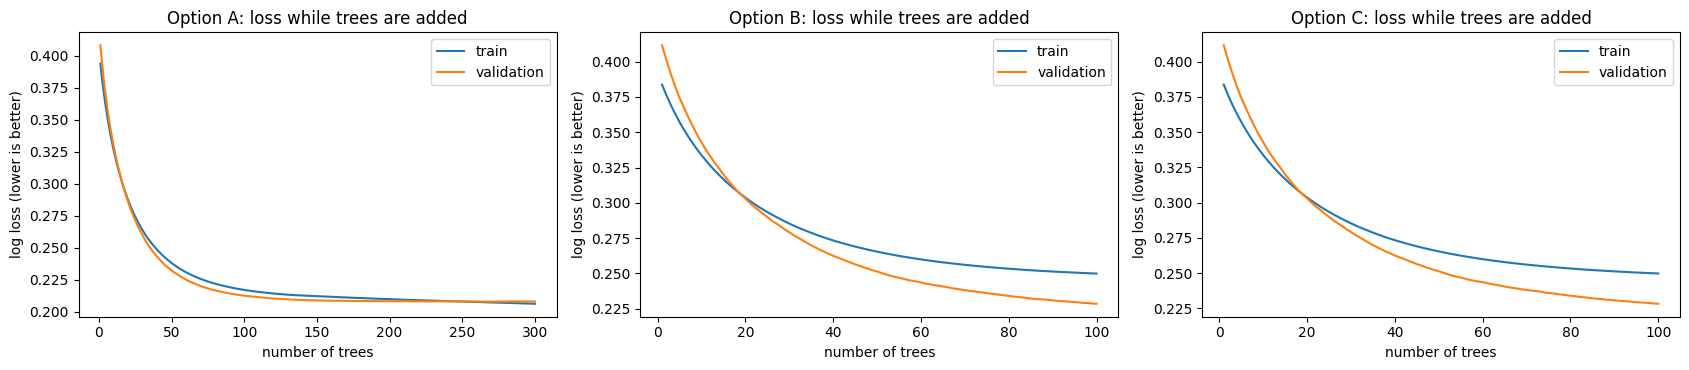

In [296]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, o in zip(axes, OPTIONS):
    (X_tr, y_tr), (X_va, y_va) = opt_X[o]['train'], opt_X[o]['validation']
    # staged_predict_proba gives the predictions after 1 tree, after 2 trees, ... after all trees
    train_loss = [log_loss(y_tr, p[:, 1]) for p in opt_gb[o].staged_predict_proba(X_tr)]
    val_loss = [log_loss(y_va, p[:, 1]) for p in opt_gb[o].staged_predict_proba(X_va)]
    n_trees = range(1, len(train_loss) + 1)
    ax.plot(n_trees, train_loss, label='train')
    ax.plot(n_trees, val_loss, label='validation')
    ax.set(xlabel='number of trees', ylabel='log loss (lower is better)', title=f'Option {o}: loss while trees are added')
    ax.legend()
    best_trees = int(np.argmin(val_loss)) + 1
    print(f'option {o}: validation loss lowest {min(val_loss):.4f} after {best_trees} trees | {val_loss[-1]:.4f} after {len(val_loss)} trees')
plt.tight_layout(); plt.show()

**Reading.**
- **Small trees work best in every option.** Every option chooses trees of depth 2 with a learning rate of 0.03. Option A uses 300 trees, and B and C use 100. In option A, depth 2 and depth 3 are tied (validation PR-AUC 0.7473 against 0.7472), so the rule of Step 2 takes the smaller trees.
- **Deep trees memorise the training data.** With depth 5, rate 0.1 and 300 trees, the training PR-AUC of option A reaches 0.979, but its validation PR-AUC falls to 0.684, below logistic regression. Options B and C overfit less with the same settings (training 0.77–0.78, validation 0.69–0.70), because they have more than three times as many training rows.
- **The chosen models do not overfit.** In option A the two loss curves fall together and the validation loss is lowest after 264 trees (0.2078), then flat. In options B and C the validation loss is still falling slowly at 100 trees. More trees would lower the loss a little, but on validation PR-AUC the versions with 300 trees score lower (0.728 against 0.736 in option B), so 100 trees are kept.
- **Gradient boosting beats logistic regression in every option**, by about 0.03 in validation PR-AUC (0.747 against 0.717 in option A, 0.735 against 0.702 in B, and 0.744 against 0.709 in C), and also on ROC-AUC (0.935–0.940 against 0.927–0.932). Being able to learn curved effects and interactions is worth something here.
- **Option C gains the most from the trees.** With logistic regression, option C was 0.008 below option A. With gradient boosting, it is only 0.003 below (0.744 against 0.747), while option B stays 0.012 below. A tree could use the two flags to treat a filled qualifying or pace value differently from a real one, which a straight-line model cannot do, but section 11.2 shows that option C's model never splits on them. Its gain comes from the features that have real values in every season (the grid, team form, driver form and the standings), whose curved effects a straight-line model cannot learn (11.2). Whether these differences between the options are clear or luck is tested when the options are compared.
- **The grid is still not beaten on the top-3 per race.** All three options pick 70.6% of the podium finishers with their top 3, against 71.7% for the grid. As with logistic regression, the model ranks all the drivers better (PR-AUC 0.735–0.747 against 0.676), but it does not pick the 3 podium finishers of a race more often.

**Limitations of gradient boosting.**
- **Harder to explain.** The prediction is the sum of 100 or 300 trees, so there is no single weight per feature. Section 11 (explainability) is needed to see what it relies on.
- **It cannot go beyond the training values.** A tree splits at values it has seen, so a driver with more career starts than anyone in the training seasons is treated like the most experienced training driver. This matters most for options B and C, whose training drivers have far fewer starts than today's (9.5).
- **More settings to choose,** and choosing them on the validation part makes the validation score slightly optimistic.
- **Each row is scored on its own,** as with logistic regression.

## 10.4 Shallow neural network

**How it works.** A feed-forward neural network passes the features of the option through one or two **hidden layers** of small units. Each unit computes a weighted sum of its inputs and applies a simple non-linear function (ReLU: keep positive values, set negative values to 0). The last layer combines the hidden units into one number, which is turned into a probability with the logistic curve, as in logistic regression. With no hidden layer, the network would *be* a logistic regression; therefore, the hidden layers let it learn non-linear effects and interactions, like gradient boosting.

**Training.** The weights start random and are adjusted in small steps (the Adam optimiser, learning rate 0.001, batches of 256 rows) to reduce the **log loss** on the training part. One pass over all training rows is an **epoch**. After every epoch the loss on the validation part is measured. Training stops when the validation loss has not improved for 25 epochs (**early stopping**), and the weights of the best epoch are kept. This stops the network from memorising the training data.

**Settings to choose.**
- The **architecture**: one hidden layer of 16 or 32 units, or two layers (32 then 16). All are "shallow".
- **Weight decay**: a penalty on large weights (the same idea as `C` in logistic regression).

As for the other models, each option tries every setting on its own training and validation part and keeps its own best one.

The random start makes results vary a little between runs, so the chosen network of each option is also trained with 5 different random seeds to show how stable its score is.

**Note: the network's exact numbers depend on the computer.** Even with fixed random seeds, the low-level maths libraries round slightly differently on different computers, and early stopping can then stop at another epoch. The text in this section therefore gives rounded values that held on every computer we ran the notebook on. The exact numbers of this run are in the outputs. Logistic regression and gradient boosting gave exactly the same numbers everywhere.

**The network.** A class with the layers (`__init__`) and what happens to a batch of rows (`forward`). The output is one number per row; the sigmoid turns it into a probability when predicting.

In [297]:
torch.set_num_threads(1)

class Net(nn.Module):
    def __init__(self, hidden, n_in=len(F)):
        super().__init__()
        layers = []
        for n_units in hidden:                     # e.g. hidden = (32, 16): two hidden layers
            layers.append(nn.Linear(n_in, n_units))
            layers.append(nn.ReLU())
            n_in = n_units
        layers.append(nn.Linear(n_in, 1))          # 1 number comes out
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x).squeeze(1)

print(Net((32, 16)))

Net(
  (layers): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


**The data as tensors.** PyTorch works with tensors. For each option, `TensorDataset` pairs each training row with its label, and the `DataLoader` (inside the training below) serves it in shuffled batches of 256 rows.

In [298]:
def to_tensors(o):
    """The training and validation rows of one option as tensors, and the training rows as a dataset."""
    (X_tr, y_tr), (X_va, y_va) = opt_X[o]['train'], opt_X[o]['validation']
    t = {'X_train': torch.tensor(X_tr.values, dtype=torch.float32), 'y_train': torch.tensor(y_tr.values, dtype=torch.float32),
         'X_val': torch.tensor(X_va.values, dtype=torch.float32), 'y_val': torch.tensor(y_va.values, dtype=torch.float32)}
    t['train_data'] = TensorDataset(t['X_train'], t['y_train'])
    return t

opt_tensors = {o: to_tensors(o) for o in OPTIONS}
for o, t in opt_tensors.items():
    print(f'option {o}: training rows {len(t["train_data"])} | validation rows {len(t["X_val"])} | features {t["X_train"].shape[1]}')

# option A keeps the names used later
X_train_t, y_train_t, X_val_t, y_val_t, train_data = (opt_tensors['A'][k] for k in ['X_train', 'y_train', 'X_val', 'y_val', 'train_data'])

option A: training rows 6407 | validation rows 1200 | features 9
option B: training rows 22362 | validation rows 1200 | features 6
option C: training rows 22362 | validation rows 1200 | features 11


**One epoch of training, the loss, and predictions.** `train_one_epoch` is the usual training loop, where for every batch, compute the loss, work out how each weight should change (`backward`) and change it a little (`step`). `evaluate` measures the loss without changing anything, and `predict` gives the probabilities.

In [299]:
loss_fn = nn.BCEWithLogitsLoss()                    # log loss for a yes/no target

def train_one_epoch(model, loader, optimizer):
    model.train()
    for X_batch, y_batch in loader:
        optimizer.zero_grad()                       # forget the previous step
        loss = loss_fn(model(X_batch), y_batch)     # how wrong the model is on this batch
        loss.backward()                             # how each weight should change
        optimizer.step()                            # change the weights a little

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        return loss_fn(model(X), y).item()

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X.values, dtype=torch.float32))).numpy()

**The full training: epochs with early stopping.** `fit_network` trains one network on the rows of one option. It repeats `train_one_epoch`, measures the loss on both parts after every epoch, remembers the weights of the best epoch, and stops when the validation loss has not improved for 25 epochs. With `show=True` it prints the progress every 20 epochs. It is a function because it is used three times: to try the settings, to train the final network and to check other random seeds.

In [300]:
def fit_network(hidden, weight_decay, option='A', seed=0, max_epochs=400, patience=25, show=False):
    t = opt_tensors[option]
    torch.manual_seed(seed)                          # the same random start every time
    model = Net(hidden, n_in=t['X_train'].shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)
    loader = DataLoader(t['train_data'], batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(seed))

    history = []
    best_loss, best_epoch, best_weights = float('inf'), 0, None
    for epoch in range(1, max_epochs + 1):
        train_one_epoch(model, loader, optimizer)
        train_loss = evaluate(model, t['X_train'], t['y_train'])
        val_loss = evaluate(model, t['X_val'], t['y_val'])
        history.append({'epoch': epoch, 'train': train_loss, 'validation': val_loss})
        if show and (epoch == 1 or epoch % 20 == 0):
            print(f'epoch {epoch:3d}: train loss {train_loss:.4f} | validation loss {val_loss:.4f}')

        # early stopping
        if val_loss < best_loss - 1e-5:              # a new best epoch: remember its weights
            best_loss, best_epoch, best_weights = val_loss, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:         # no improvement for `patience` epochs: stop
            break

    if show:
        print(f'stopped after epoch {epoch}. Keeping the weights of epoch {best_epoch} (validation loss {best_loss:.4f}).')
    model.load_state_dict(best_weights)
    return model, best_epoch, pd.DataFrame(history).set_index('epoch')

**Step 1: try settings.** For each option, one network per combination, trained on the option's training part and scored on its validation part.

In [301]:
results = []
for o in OPTIONS:
    X_tr, y_tr = opt_X[o]['train']
    X_va, y_va = opt_X[o]['validation']
    for hidden in [(16,), (32,), (32, 16)]:
        for weight_decay in [0, 1e-3]:
            model, best_epoch, _ = fit_network(hidden, weight_decay, option=o)
            train_prob = predict(model, X_tr)
            val_prob = predict(model, X_va)
            results.append({'option': o, 'hidden layers': hidden, 'weight decay': weight_decay, 'best epoch': best_epoch,
                            'train PR-AUC': average_precision_score(y_tr, train_prob),
                            'validation PR-AUC': average_precision_score(y_va, val_prob),
                            'validation ROC-AUC': roc_auc_score(y_va, val_prob)})
    print(f'option {o}: done')

nn_tuning = pd.DataFrame(results).sort_values(['option', 'validation PR-AUC'], ascending=[True, False])
show_table(nn_tuning, 'Neural network: choosing the settings for each option (best first)')

option A: done
option B: done
option C: done


option,hidden layers,weight decay,best epoch,train PR-AUC,validation PR-AUC,validation ROC-AUC
A,"(32,)",0.0000,215,0.7032,0.7466,0.9377
A,"(32, 16)",0.0010,127,0.7002,0.7443,0.9363
A,"(16,)",0.0000,278,0.7008,0.7428,0.9354
A,"(32,)",0.0010,244,0.6994,0.7401,0.9368
A,"(16,)",0.0010,244,0.6959,0.7381,0.9353
A,"(32, 16)",0.0000,105,0.7028,0.7300,0.9353
B,"(16,)",0.0010,57,0.5710,0.7306,0.9330
B,"(16,)",0.0000,69,0.5723,0.7302,0.9348
B,"(32,)",0.0000,124,0.5778,0.7282,0.9349
B,"(32, 16)",0.0000,69,0.5811,0.7268,0.9348


**Step 2: train the networks**, one per option, each with its best settings and on its own training part. The progress is printed while each one learns. Both losses should go down, and training stops once the validation loss stops improving.

In [302]:
opt_nn_settings, opt_nn, opt_nn_epochs, opt_nn_history = {}, {}, {}, {}
for o in OPTIONS:
    best = nn_tuning[nn_tuning.option == o].iloc[0]
    opt_nn_settings[o] = (best['hidden layers'], best['weight decay'])
    print(f'option {o}: hidden layers {best["hidden layers"]}, weight decay {best["weight decay"]:g}')
    opt_nn[o], opt_nn_epochs[o], opt_nn_history[o] = fit_network(*opt_nn_settings[o], option=o, show=True)   # the training happens here
    print()

# option A keeps the names used later
(NN_HIDDEN, NN_WD), nn_model, NN_EPOCHS, nn_history = opt_nn_settings['A'], opt_nn['A'], opt_nn_epochs['A'], opt_nn_history['A']

option A: hidden layers (32,), weight decay 0
epoch   1: train loss 0.6388 | validation loss 0.6495
epoch  20: train loss 0.2369 | validation loss 0.2349
epoch  40: train loss 0.2249 | validation loss 0.2246
epoch  60: train loss 0.2204 | validation loss 0.2208
epoch  80: train loss 0.2175 | validation loss 0.2185
epoch 100: train loss 0.2151 | validation loss 0.2163
epoch 120: train loss 0.2136 | validation loss 0.2152
epoch 140: train loss 0.2124 | validation loss 0.2141
epoch 160: train loss 0.2116 | validation loss 0.2131
epoch 180: train loss 0.2111 | validation loss 0.2130
epoch 200: train loss 0.2103 | validation loss 0.2124
epoch 220: train loss 0.2098 | validation loss 0.2128
epoch 240: train loss 0.2094 | validation loss 0.2121
stopped after epoch 240. Keeping the weights of epoch 215 (validation loss 0.2116).

option B: hidden layers (16,), weight decay 0.001
epoch   1: train loss 0.4476 | validation loss 0.4610
epoch  20: train loss 0.2493 | validation loss 0.2242
epoch  40

**Step 3: scores** of each option on its training and validation part, with each option's own F1 threshold chosen on its validation part.

In [303]:
opt_p_nn, opt_nn_threshold, opt_nn_results = {}, {}, {}
for o in OPTIONS:
    p = {part: predict(opt_nn[o], opt_X[o][part][0]) for part in ['train', 'validation']}
    opt_p_nn[o] = p
    opt_nn_threshold[o] = best_threshold(opt_X[o]['validation'][1], p['validation'])     # chosen on validation
    opt_nn_results[o] = train_and_validation_scores(p['train'], p['validation'], opt_nn_threshold[o], option=o)

all_results = pd.concat({o: r for o, r in opt_nn_results.items()}, names=['option', 'part']).reset_index()
all_results.insert(2, 'F1 threshold', all_results.option.map(opt_nn_threshold))
display(all_results.style.format('{:.3f}', subset=list(all_results.columns[2:])).hide(axis='index')
        .set_caption('Neural network: training and validation scores of each option'))

# option A keeps the names used later
p_nn, nn_threshold, nn_results = opt_p_nn['A'], opt_nn_threshold['A'], opt_nn_results['A']

option,part,F1 threshold,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race
A,train,0.369,0.938,0.703,0.671,0.628,0.721,0.660
A,validation,0.369,0.938,0.747,0.735,0.684,0.794,0.700
B,train,0.425,0.902,0.571,0.557,0.562,0.553,0.552
B,validation,0.425,0.933,0.731,0.738,0.698,0.783,0.694
C,train,0.414,0.909,0.591,0.570,0.573,0.567,0.563
C,validation,0.414,0.935,0.741,0.733,0.693,0.778,0.694


**Step 4: chart.** The loss after every epoch, on the training and the validation part, for each option.

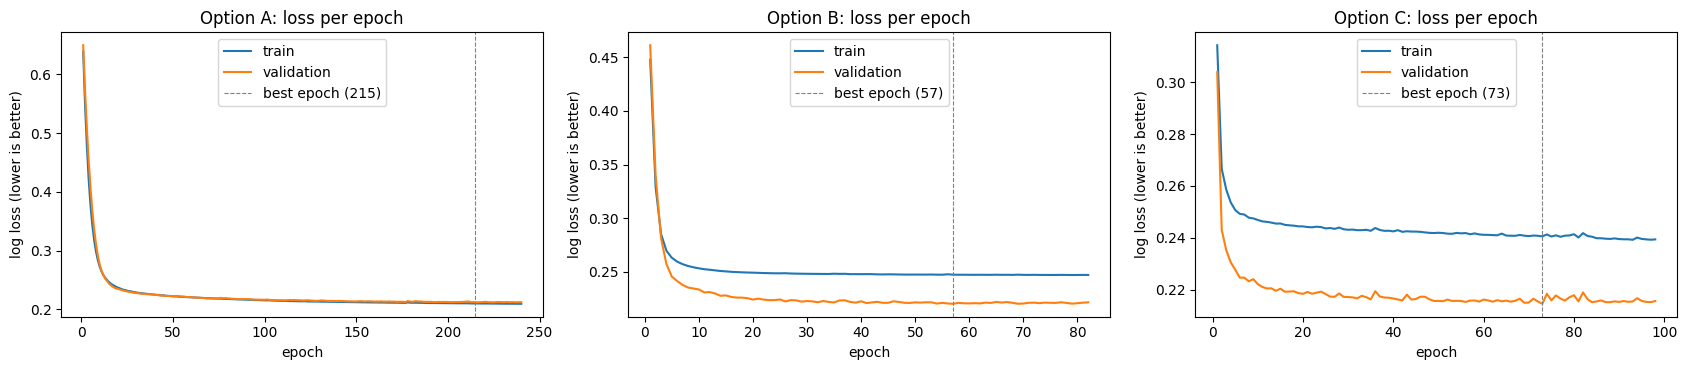

In [304]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, o in zip(axes, OPTIONS):
    opt_nn_history[o].plot(ax=ax)
    ax.axvline(opt_nn_epochs[o], color='grey', ls='--', lw=0.8, label=f'best epoch ({opt_nn_epochs[o]})')
    ax.set(xlabel='epoch', ylabel='log loss (lower is better)', title=f'Option {o}: loss per epoch')
    ax.legend()
plt.tight_layout(); plt.show()

**Step 5: how stable is it?** The chosen network of each option trained with 5 different random starts.

In [305]:
opt_seed_scores = {}
for o in OPTIONS:
    X_va, y_va = opt_X[o]['validation']
    opt_seed_scores[o] = []
    for seed in range(5):
        model, _, _ = fit_network(*opt_nn_settings[o], option=o, seed=seed)
        opt_seed_scores[o].append(average_precision_score(y_va, predict(model, X_va)))
    print(f'option {o}: validation PR-AUC ' + ', '.join(f'{s:.4f}' for s in opt_seed_scores[o])
          + f' | mean {np.mean(opt_seed_scores[o]):.4f} ± {np.std(opt_seed_scores[o], ddof=1):.4f}')

# option A keeps the name used later
seed_scores = opt_seed_scores['A']

option A: validation PR-AUC 0.7466, 0.7387, 0.7374, 0.7298, 0.7289 | mean 0.7363 ± 0.0073
option B: validation PR-AUC 0.7306, 0.7159, 0.7247, 0.7193, 0.7281 | mean 0.7237 ± 0.0061
option C: validation PR-AUC 0.7408, 0.6989, 0.7529, 0.7363, 0.7368 | mean 0.7331 ± 0.0203


**Reading.**
- **The settings differ between the options, but the networks are close within each option.** Option A chooses one hidden layer of 32 units with no weight decay, option B one layer of 16 units with weight decay 0.001, and option C two layers (32 then 16) with no weight decay. Within an option, the six networks are within about 0.013–0.024 of each other in validation PR-AUC, so the exact shape matters little.
- **The networks of B and C stop much earlier** (best epoch 57 and 73, against 215 in option A). Each of their epochs goes through more than three times as many rows, so they learn as much in fewer epochs.
- **No overfitting.** In option A the training and validation losses fall together and stay together. In options B and C the validation loss is below the training loss the whole time, because the older training seasons are harder to predict than 2019–2021 (as in 10.2 and 10.3), not because of a mistake.
- **The network scores about as well as gradient boosting.** Its validation PR-AUC is 0.747 in option A (gradient boosting 0.747), 0.731 in B (0.735) and 0.741 in C (0.744), and both are clearly above logistic regression. Like gradient boosting, it does not beat the grid on the top-3 per race (0.694–0.700 against 0.717).
- **The score depends on the random start.** Over 5 seeds the mean validation PR-AUC is 0.736 ± 0.007 in option A, 0.724 ± 0.006 in B and 0.733 ± 0.020 in C. The settings were chosen with seed 0, and in options A and B seed 0 happens to be the best of the five, so the chosen run is a little lucky. A typical run lies between logistic regression and gradient boosting. Option C varies the most (from 0.699 to 0.753), so a single run of it says little.

**Limitations of the neural network.**
- **Results vary between runs** because of the random start and the random order of the batches, so one run does not give an exact score.
- **A black box.** Its weights cannot be read like those of logistic regression, and section 11 is needed to explain it.
- **It needs scaled inputs** and more choices than the other models (layers, units, weight decay, learning rate, epochs, batch size).
- **Little to gain on a small table.** With 6 to 11 features and 6,000 to 22,000 training rows, a network has no advantage over gradient boosting, which usually does at least as well on tables like this.
- **Each row is scored on its own,** as with the other models.

## 10.5 Comparing the models on the validation part

Every model of every option is scored on the same validation rows (2019–2021), together with the grid reference. The table also gives the gap between the training and the validation PR-AUC, which would be large if a model memorised its training data, and, for the network, the mean over its 5 random starts (10.4).

option,model,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race,F1 threshold,train minus validation PR-AUC,"network PR-AUC, mean of 5 seeds"
–,the top 3 on the grid (reference),0.917,0.676,0.717,0.717,0.717,0.717,–,–,–
A,logistic regression,0.932,0.717,0.730,0.679,0.789,0.678,0.368,-0.042,–
A,gradient boosting,0.940,0.747,0.731,0.673,0.800,0.706,0.345,-0.033,–
A,neural network,0.938,0.747,0.735,0.684,0.794,0.700,0.369,-0.043,0.736
B,logistic regression,0.927,0.702,0.738,0.693,0.789,0.694,0.367,-0.142,–
B,gradient boosting,0.936,0.735,0.740,0.696,0.789,0.706,0.351,-0.170,–
B,neural network,0.933,0.731,0.738,0.698,0.783,0.694,0.425,-0.160,0.724
C,logistic regression,0.930,0.709,0.725,0.664,0.800,0.700,0.319,-0.146,–
C,gradient boosting,0.935,0.744,0.740,0.701,0.783,0.706,0.362,-0.176,–
C,neural network,0.935,0.741,0.733,0.693,0.778,0.694,0.414,-0.150,0.733


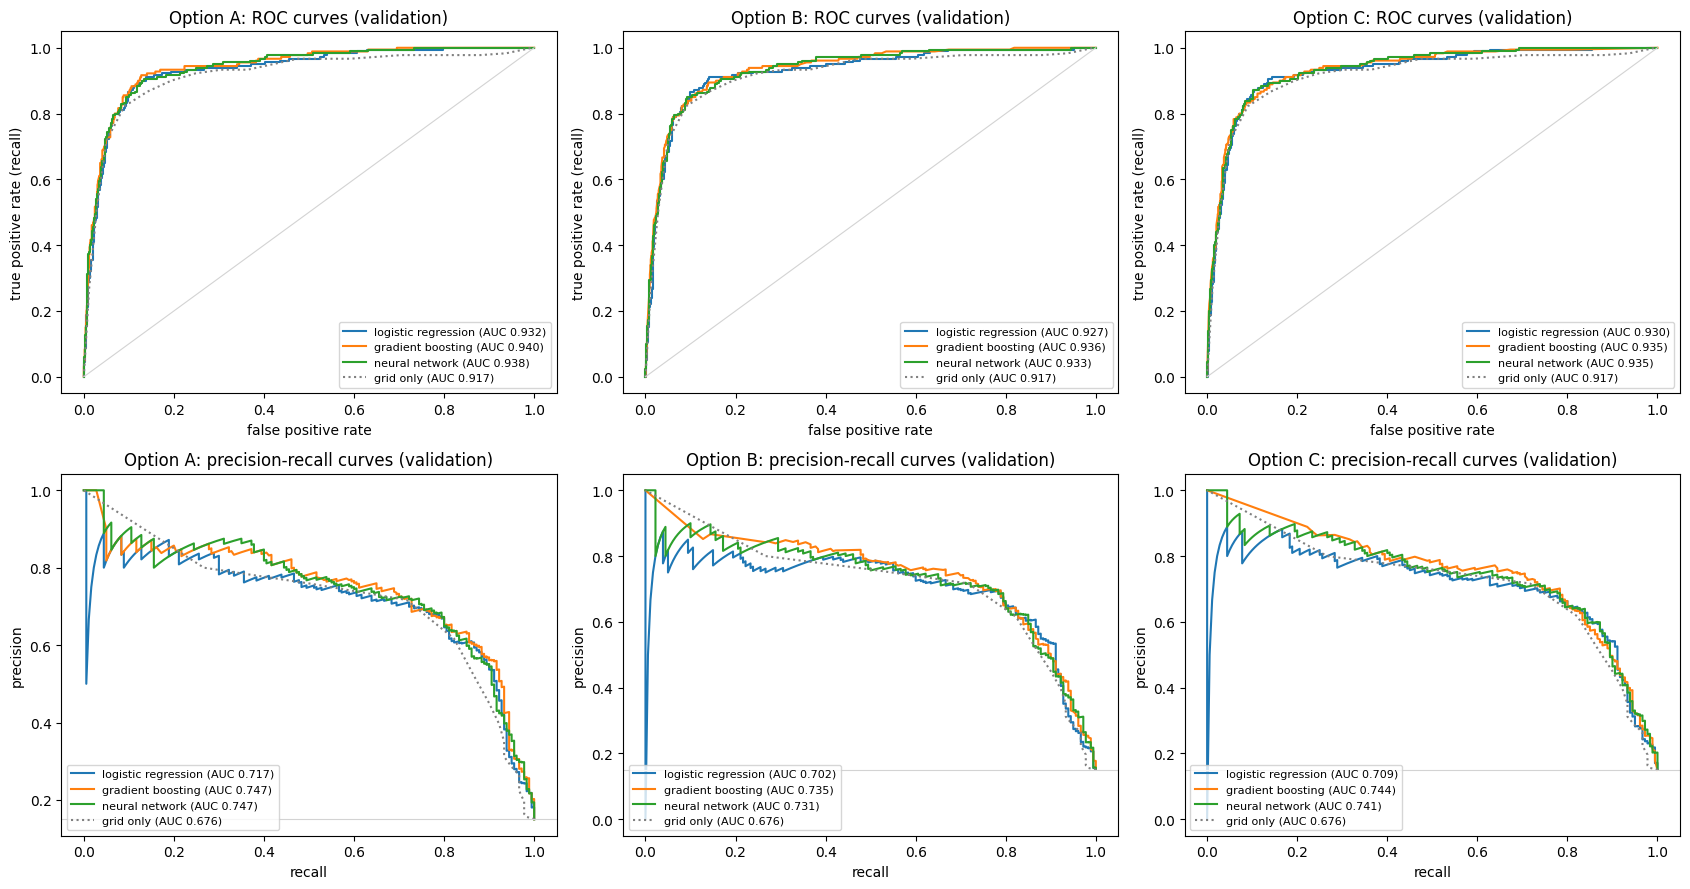

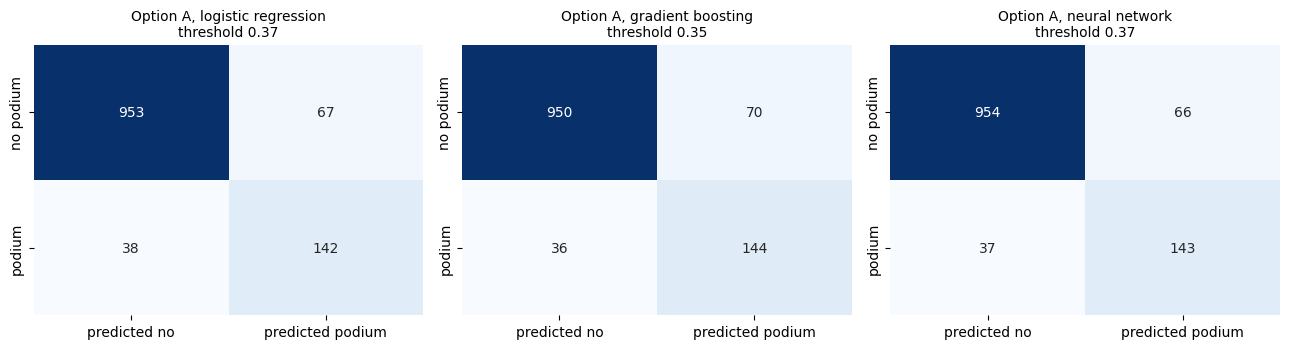

In [306]:
MODELS = {'logistic regression': (opt_p_lr, opt_lr_threshold, opt_lr_results),
          'gradient boosting': (opt_p_gb, opt_gb_threshold, opt_gb_results),
          'neural network': (opt_p_nn, opt_nn_threshold, opt_nn_results)}

rows = [{'option': '–', 'model': 'the top 3 on the grid (reference)', **grid_results['validation']}]
for o in OPTIONS:
    for m, (p, thr, res) in MODELS.items():
        rows.append({'option': o, 'model': m, **res[o].loc['validation'], 'F1 threshold': thr[o],
                     'train minus validation PR-AUC': res[o].loc['train', 'PR-AUC'] - res[o].loc['validation', 'PR-AUC'],
                     'network PR-AUC, mean of 5 seeds': np.mean(opt_seed_scores[o]) if m == 'neural network' else np.nan})
all_compare = pd.DataFrame(rows)
num = list(all_compare.columns[2:])
display(all_compare.style.format('{:.3f}', subset=num, na_rep='–')
        .format('{:+.3f}', subset=['train minus validation PR-AUC'], na_rep='–').hide(axis='index')
        .set_caption('Validation part (2019-2021): every model of every option'))

# option A in the layout used again in 10.10
compare = pd.DataFrame({'the top 3 on the grid (reference)': {**grid_results['validation'], 'threshold': np.nan},
                        'logistic regression (baseline)': {**lr_results.loc['validation'], 'threshold': lr_threshold},
                        'gradient boosting': {**gb_results.loc['validation'], 'threshold': gb_threshold},
                        'neural network': {**nn_results.loc['validation'], 'threshold': nn_threshold}}).T

# ROC and precision-recall curves, one column per option
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for col, o in enumerate(OPTIONS):
    y_va = opt_X[o]['validation'][1]
    for m, (p, thr, res) in MODELS.items():
        pv = p[o]['validation']
        fpr, tpr, _ = roc_curve(y_va, pv)
        axes[0, col].plot(fpr, tpr, label=f'{m} (AUC {roc_auc_score(y_va, pv):.3f})')
        prec, rec, _ = precision_recall_curve(y_va, pv)
        axes[1, col].plot(rec, prec, label=f'{m} (AUC {average_precision_score(y_va, pv):.3f})')
    g_va = opt_grid[o]['validation']
    fpr, tpr, _ = roc_curve(y_va, g_va)
    axes[0, col].plot(fpr, tpr, color='grey', ls=':', label=f'grid only (AUC {roc_auc_score(y_va, g_va):.3f})')
    prec, rec, _ = precision_recall_curve(y_va, g_va)
    axes[1, col].plot(rec, prec, color='grey', ls=':', label=f'grid only (AUC {average_precision_score(y_va, g_va):.3f})')
    axes[0, col].plot([0, 1], [0, 1], color='lightgrey', lw=0.8)
    axes[1, col].axhline(y_va.mean(), color='lightgrey', lw=0.8)
    axes[0, col].set(xlabel='false positive rate', ylabel='true positive rate (recall)', title=f'Option {o}: ROC curves (validation)')
    axes[1, col].set(xlabel='recall', ylabel='precision', title=f'Option {o}: precision-recall curves (validation)')
    axes[0, col].legend(fontsize=8, loc='lower right'); axes[1, col].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

# confusion matrices of option A at each model's threshold
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (m, (p, thr, res)) in zip(axes, MODELS.items()):
    cm = confusion_matrix(y_val, (p['A']['validation'] >= thr['A']).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['predicted no', 'predicted podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'Option A, {m}\nthreshold {thr["A"]:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

**Reading.**
- **Every model of every option beats the grid on the ranking scores.** The validation PR-AUC is 0.702–0.747 against 0.676 for the grid, and the ROC-AUC 0.927–0.940 against 0.917. Over all races, the models rank podium drivers above the rest better than the starting order alone, because they also use form, team and championship information.
- **Gradient boosting and the network are ahead of logistic regression in every option**, by about 0.03 in PR-AUC. The highest scores are gradient boosting and the network in option A (both 0.747), then gradient boosting in option C (0.744). The network's mean over 5 random starts is lower than its chosen run (0.736 in option A, 0.733 in C and 0.724 in B).
- **Option B is the lowest for every model** (0.702–0.735), and options A and C are close to each other.
- **The ROC curves of all models lie on top of each other**, together with the grid's. Most non-podium drivers start far back and are easy to rank, so ROC-AUC barely separates the models (10.10). The precision-recall curves show the differences better. The grid is lowest in the middle of the curve, and gradient boosting and the network are a little above logistic regression.
- **F1 is almost the same for all nine** (0.725–0.740). In option A, logistic regression finds 142 of the 180 podium finishers with 67 false alarms, gradient boosting 144 with 70, and the network 143 with 66 (confusion matrices).
- **No model memorises its training data.** The training PR-AUC is below the validation PR-AUC for every model, by about 0.03–0.04 in option A and 0.14–0.18 in options B and C, because the training seasons are harder to predict than 2019–2021 (10.2).
- **Picking exactly 3 drivers per race, the grid is still as good as the models.** Its top 3 are right 71.7% of the time, and the best models 70.6%. The models are better at ranking drivers across all races, but within one race the grid order is already very strong, and the models do not know that each race has exactly 3 podiums.
- **These scores are slightly optimistic**, because the settings, the thresholds and the stopping epoch were all chosen on this validation part. The honest score is the one on the unseen test part.

## 10.6 The models carried forward

Sections 10.2–10.4 trained three models for each option, and 10.5 compared them on the validation part. Before the ablation and the test, the best combinations of an option and a model are chosen to carry forward. They are the models we would use to predict a race, and the ones that the ablation (10.7) is about. The test part is still unseen, so the choice uses the validation part only. Options A, B and C have the same validation rows, so all nine combinations can be compared directly.

**How sure is a difference?** The validation part has only 60 races and 180 podiums, so a small difference in PR-AUC can be luck. The 60 races are redrawn 1,000 times as in 9.6, the difference between two models is computed on every redraw, and the middle 95% is kept. A difference is **clear** when this range does not include 0.

**Step 1: the redraws.** `race_redraws` makes the 1,000 redraws of a set of races, and `change_range` gives the 95% range of the difference between two models. Both were written for the order experiments (9.6) and are used again in 10.7, 10.8 and 10.9.

In [307]:
val_redraws = race_redraws(val_rows)
print(f'{len(val_redraws)} redraws of the {val_rows.raceId.nunique()} validation races')

1000 redraws of the 60 validation races


**Step 2: the best combination against every other one** on the validation part, and against the grid reference.

In [308]:
val_y = opt_X['A']['validation'][1].values
assert all((opt_X[o]['validation'][1].values == val_y).all() for o in OPTIONS), 'the options have different validation rows'

candidates = {(o, m): MODELS[m][0][o]['validation'] for o in OPTIONS for m in MODELS}
pr_auc = {k: average_precision_score(val_y, p) for k, p in candidates.items()}
best = max(pr_auc, key=pr_auc.get)
print(f'best validation PR-AUC: option {best[0]}, {best[1]} ({pr_auc[best]:.3f})')

rows = []
others = sorted([k for k in candidates if k != best], key=lambda k: -pr_auc[k])
for k in others + ['grid']:
    p, name = (opt_grid['A']['validation'], 'the top 3 on the grid (reference)') if k == 'grid' else (candidates[k], f'option {k[0]}, {k[1]}')
    lo, hi = change_range(val_y, p, candidates[best], val_redraws)
    rows.append({'compared with': name, 'its PR-AUC': average_precision_score(val_y, p),
                 'best minus it': pr_auc[best] - average_precision_score(val_y, p),
                 '95% range': f'{lo:+.3f} to {hi:+.3f}', 'clear difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
display(pd.DataFrame(rows).style.format({'its PR-AUC': '{:.3f}', 'best minus it': '{:+.3f}'}).hide(axis='index')
        .set_caption(f'Validation part: option {best[0]}, {best[1]} against every other combination'))

best validation PR-AUC: option A, gradient boosting (0.747)


compared with,its PR-AUC,best minus it,95% range,clear difference?
"option A, neural network",0.747,+0.001,-0.021 to +0.022,no
"option C, gradient boosting",0.744,+0.003,-0.025 to +0.032,no
"option C, neural network",0.741,+0.006,-0.018 to +0.031,no
"option B, gradient boosting",0.735,+0.012,-0.007 to +0.032,no
"option B, neural network",0.731,+0.017,-0.009 to +0.043,no
"option A, logistic regression",0.717,+0.030,-0.005 to +0.062,no
"option C, logistic regression",0.709,+0.038,-0.001 to +0.073,no
"option B, logistic regression",0.702,+0.045,+0.004 to +0.081,yes
the top 3 on the grid (reference),0.676,+0.071,+0.043 to +0.103,yes


**Reading and decision: gradient boosting in options A and C goes forward.**
- **Option A with gradient boosting has the highest validation PR-AUC** (0.747). It is clearly better than the grid (+0.071, range +0.043 to +0.103) and than logistic regression in option B (+0.045, range +0.004 to +0.081).
- **Against every other combination the difference is not clear.** The network in option A (+0.001), gradient boosting in option C (+0.003) and the network in option C (+0.006) are practically tied with it, and even logistic regression in options A and C (+0.030 and +0.038) has a range that includes 0. With 60 validation races, the data cannot pick a single winner.
- **Gradient boosting is preferred over the network**, because it gives the same model every time it is trained. The network's score moves with its random start, and its chosen run in option A was the best of five (mean 0.736 against 0.747).
- **Options A and C are both carried forward.** They are tied with gradient boosting (0.747 against 0.744, range −0.025 to +0.032), and they answer the question of the training seasons in two different ways. Option A learns from 2003–2018 with real values for almost every feature. Option C learns from 1950–2018 with every feature, but about 60% of its training rows have filled qualifying and pace values, marked by the two extra features (9.2). Option B scores lower with every model and is not carried forward.

From here, the ablation (10.7) and the random split (option D) are done for **gradient boosting in options A and C**. Every model of every option is still scored on the unseen test part, because the brief asks for the test score of every model, and no choice is made from the test scores.

### The preprocessing order with the models carried forward

The order experiments of 9.6 used logistic regression and gradient boosting with their default settings, because the settings were not chosen yet. Here the same two other orders (fill, scale, cap and cap, scale, fill) are tried with the two models carried forward, gradient boosting in options A and C with their own settings (10.3). Each order prepares the data as in 9.6, the model is trained on the training part and scored on the validation part, and the change against our order comes with a 95% range from the redraws of 10.6.

In [309]:
rows = []
for o in ['A', 'C']:
    feats = OPTIONS[o][1]
    probs = {}
    for name, d in orders[o].items():                                   # the three orders of 9.6
        tr, va = d[d.split == 'train'], d[d.split == 'validation']
        model = HistGradientBoostingClassifier(**opt_gb_params[o], early_stopping=False, random_state=0)
        probs[name] = model.fit(tr[feats], tr.podium).predict_proba(va[feats])[:, 1]
    ours = probs['fill, cap, scale (ours)']
    for name, p in probs.items():
        r = {'option': o, 'settings': str(opt_gb_params[o]), 'order': name,
             'ROC-AUC': roc_auc_score(val_y, p), 'PR-AUC': average_precision_score(val_y, p)}
        if name != 'fill, cap, scale (ours)':
            lo, hi = change_range(val_y, ours, p, val_redraws)
            r['change in PR-AUC'] = r['PR-AUC'] - average_precision_score(val_y, ours)
            r['95% range of the change'] = f'{lo:+.3f} to {hi:+.3f}'
            r['clear?'] = 'yes' if (lo > 0 or hi < 0) else 'no'
        rows.append(r)
order_final = pd.DataFrame(rows)
display(order_final.style.format({'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}', 'change in PR-AUC': '{:+.3f}'}, na_rep='–')
        .hide(axis='index').set_caption('Validation part: each order with the models carried forward (gradient boosting, options A and C)'))

option,settings,order,ROC-AUC,PR-AUC,change in PR-AUC,95% range of the change,clear?
A,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}","fill, cap, scale (ours)",0.940,0.747,–,–,–
A,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}","fill, scale, cap (experiment 1)",0.940,0.747,+0.000,+0.000 to +0.000,no
A,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}","cap, scale, fill (experiment 2)",0.940,0.746,-0.002,-0.008 to +0.003,no
C,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}","fill, cap, scale (ours)",0.935,0.744,–,–,–
C,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}","fill, scale, cap (experiment 1)",0.935,0.744,+0.000,+0.000 to +0.000,no
C,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}","cap, scale, fill (experiment 2)",0.936,0.745,+0.001,-0.000 to +0.003,no


**Reading.**
- **With the tuned models, the order makes no clear difference either.** The validation PR-AUC of our order is 0.747 in option A and 0.744 in option C. The other two orders change it by at most 0.002 in either direction, and every range includes 0.
- **Experiment 1 (fill, scale, cap) gives exactly the same scores** in both options (+0.000). Trees only look at the order of the values, and scaling and capping keep that order, so the model splits the rows in the same way. This confirms what 9.6 found with the default settings.
- **Experiment 2 (cap, scale, fill) moves the score by only −0.002 in option A and +0.001 in option C.** The wrong fill values of experiment 2 (9.6) are given to few rows, mostly first starts and drivers with no standing, so the tuned models barely notice them.
- **The decision of 9.6 stands.** The order fill, cap, scale is kept because it is the only one in which every filled value means what its rule says, not because it scores better.

## 10.7 Feature-group ablation

**What an ablation is.** Section 7 chose each feature **before** training, with evidence from the data. The ablation measures what each group of features **actually contributes after training**. A group is removed, the model is trained again without it, and the validation score shows how much was lost.

**Two experiments.** Removing one group at a time is the brief's ablation and our main experiment. On its own it can mislead when groups overlap. If two groups carry the same information, removing either one costs almost nothing, because the model uses the other (7.10 showed overlaps of up to 0.80 between features). So each group is also tried on its own.

| Experiment | Models trained, per option | Question it answers |
|---|---|---|
| 1. One group removed | 7, each without one group | How much does the model lose without this group? |
| 2. One group alone | 7, each with one group only | How much does this group know on its own? |

**Which models.** The ablation is done for the two models carried forward in 10.6, gradient boosting in option A and in option C, each with its own settings of 10.3. The neural network is left out, because its score moves with its random start (10.4) by about as much as most group effects, so its ablation could not be read without many repeated runs.

**How a change is judged.** Every model is trained on the option's training part and scored on the validation part with PR-AUC (the main score). The range of a change comes from redrawing the validation races, as in 10.6.

**The rule for the features, set before the experiments.** A group is removed only if the model is **clearly better without it**. A group whose removal makes no clear difference is kept. It was chosen with evidence in section 7, it is valid at the cutoff, and a change smaller than the luck of 60 races is not a reason to drop it.

**The groups.** The 9 features were built in 7 groups in section 7 (the `group` column of `FEATURES`, 7.10). In option C, each of the two extra features joins the group it describes, so `has_quali_data` is part of qualifying and `has_pace_data` part of pace. Removing a group then removes its values and the flag that says whether they are real.

In [310]:
import itertools

GROUPS = {}
for f, (group, *_) in FEATURES.items():
    GROUPS.setdefault(group, []).append(f)

OPT_GROUPS = {'A': GROUPS,
              'C': {g: fs + (['has_quali_data'] if g == 'qualifying' else ['has_pace_data'] if g.startswith('pace') else [])
                    for g, fs in GROUPS.items()}}
assert sorted(sum(OPT_GROUPS['C'].values(), [])) == sorted(OPTIONS['C'][1]), 'option C: a feature is missing from the groups'

table(pd.DataFrame({'group': list(GROUPS), 'features in option A': [', '.join(fs) for fs in OPT_GROUPS['A'].values()],
                    'features in option C': [', '.join(fs) for fs in OPT_GROUPS['C'].values()]}),
      caption='The 7 feature groups')

group,features in option A,features in option C
grid,grid_clean,grid_clean
qualifying,"grid_minus_quali, quali_gap_pct","grid_minus_quali, quali_gap_pct, has_quali_data"
driver form,"form_podium_rate, career_starts","form_podium_rate, career_starts"
driver standings,champ_pos,champ_pos
team form,team_form,team_form
reliability,team_mech_rel,team_mech_rel
pace (candidate),pace_form,"pace_form, has_pace_data"


**Helper functions.** One model is trained per set of features, with the option's settings and rows every time. Only the columns change.

In [311]:
def features_without(*groups, option='A'):
    """The feature columns of the option left after removing the given groups."""
    return [f for f in OPTIONS[option][1] if not any(f in OPT_GROUPS[option][g] for g in groups)]

def features_of(*groups, option='A'):
    """The feature columns of the given groups only."""
    return [f for g in groups for f in OPT_GROUPS[option][g]]

def gb_val_prob(cols, option='A'):
    """Gradient boosting with the option's settings of 10.3, trained on its training part with these columns only."""
    (X_tr, y_tr), (X_va, _) = opt_X[option]['train'], opt_X[option]['validation']
    model = HistGradientBoostingClassifier(**opt_gb_params[option], early_stopping=False, random_state=0)
    return model.fit(X_tr[cols], y_tr).predict_proba(X_va[cols])[:, 1]

ABLATION_OPTIONS = ['A', 'C']

### Experiment 1: one group removed

For each option and each group, train gradient boosting without the group, and compare the validation PR-AUC with the model that has all of the option's features. A negative change means the model is worse without the group.

In [312]:
p_all, pr_all, rows = {}, {}, []
for o in ABLATION_OPTIONS:
    p_all[o] = gb_val_prob(OPTIONS[o][1], option=o)
    pr_all[o] = average_precision_score(y_val, p_all[o])
    print(f'option {o}, all {len(OPTIONS[o][1])} features: gradient boosting PR-AUC {pr_all[o]:.3f}')
    for g in GROUPS:
        p_without = gb_val_prob(features_without(g, option=o), option=o)
        pr = average_precision_score(y_val, p_without)
        lo, hi = change_range(y_val, p_all[o], p_without, val_redraws)
        rows.append({'option': o, 'group removed': g, 'PR-AUC': pr, 'change': pr - pr_all[o], 'lo': lo, 'hi': hi})
leave_one = pd.DataFrame(rows)
leave_one['clear change?'] = np.where(leave_one.hi < 0, 'yes, worse', np.where(leave_one.lo > 0, 'yes, better', 'no'))
leave_one['95% range of the change'] = [f'{a:+.3f} to {b:+.3f}' for a, b in zip(leave_one.lo, leave_one.hi)]

display(leave_one.sort_values(['option', 'change'])
        [['option', 'group removed', 'PR-AUC', 'change', '95% range of the change', 'clear change?']]
        .style.format({'PR-AUC': '{:.3f}', 'change': '{:+.3f}'})
        .hide(axis='index').set_caption('Experiment 1: one group removed (gradient boosting, validation part)'))

option A, all 9 features: gradient boosting PR-AUC 0.747
option C, all 11 features: gradient boosting PR-AUC 0.744


option,group removed,PR-AUC,change,95% range of the change,clear change?
A,grid,0.674,-0.074,-0.120 to -0.033,"yes, worse"
A,pace (candidate),0.736,-0.011,-0.023 to +0.003,no
A,driver standings,0.737,-0.010,-0.023 to +0.003,no
A,qualifying,0.739,-0.008,-0.023 to +0.008,no
A,reliability,0.741,-0.006,-0.016 to +0.005,no
A,team form,0.748,+0.000,-0.008 to +0.010,no
A,driver form,0.756,+0.009,-0.001 to +0.019,no
C,grid,0.686,-0.059,-0.091 to -0.022,"yes, worse"
C,qualifying,0.739,-0.006,-0.033 to +0.019,no
C,driver standings,0.740,-0.004,-0.021 to +0.011,no


**Chart.** The change for each group, for each option. The black line on each bar is its 95% range.

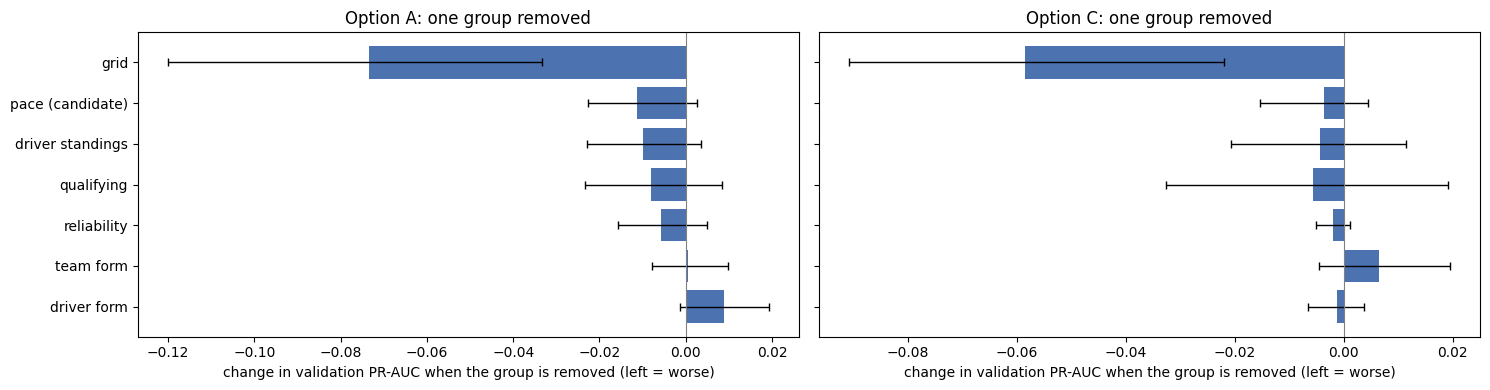

In [313]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
order = leave_one[leave_one.option == 'A'].sort_values('change', ascending=False)['group removed'].tolist()
for ax, o in zip(axes, ABLATION_OPTIONS):
    d = leave_one[leave_one.option == o].set_index('group removed').loc[order]
    ax.barh(range(len(d)), d.change, color='#4C72B0', xerr=[d.change - d.lo, d.hi - d.change], error_kw={'lw': 1, 'capsize': 3})
    ax.axvline(0, color='grey', lw=0.8)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
    ax.set(xlabel='change in validation PR-AUC when the group is removed (left = worse)', title=f'Option {o}: one group removed')
plt.tight_layout(); plt.show()

**Reading.**
- **The grid is the only group that is clearly needed, in both options.** Without it, the validation PR-AUC of gradient boosting falls from 0.747 to 0.674 in option A (−0.074, range −0.120 to −0.033) and from 0.744 to 0.686 in option C (−0.059, range −0.091 to −0.022). No other group can replace the starting slot.
- **No other group has a clear effect when it is removed.** In option A, removing pace (−0.011), the championship position (−0.010), qualifying (−0.008) or reliability (−0.006) lowers the score a little, team form changes nothing (+0.000), and removing driver form even raises it (+0.009). In option C, every change is between −0.006 and +0.007. All these ranges include 0, so none of the changes is more than the luck of 60 races.
- **Driver form in option A is the closest call.** The model scores 0.009 higher without it, and the range (−0.001 to +0.019) only just includes 0. By the rule set before the experiments, it is kept.
- **A small change does not mean that a group knows little.** When two groups carry the same information, removing either one costs almost nothing, because the model uses the other. Experiment 2 tests this by training each group on its own.
- **Option C depends a little less on the grid than option A** (−0.059 against −0.074). It learned from the older seasons as well, in which the grid predicted the podium much less well (10.1), so it relies a little more on the other groups.

### Experiment 2: one group alone

Each group on its own, where gradient boosting is trained with only that group's features. For comparison, the table repeats the change from experiment 1.

In [314]:
rows = []
for o in ABLATION_OPTIONS:
    removed = leave_one[leave_one.option == o].set_index('group removed')['change']
    for g in GROUPS:
        rows.append({'option': o, 'group': g,
                     'PR-AUC with this group only': average_precision_score(y_val, gb_val_prob(features_of(g, option=o), option=o)),
                     'change when it is removed (experiment 1)': removed[g]})
alone = pd.DataFrame(rows).sort_values(['option', 'PR-AUC with this group only'], ascending=[True, False])
display(alone.style.format({'PR-AUC with this group only': '{:.3f}', 'change when it is removed (experiment 1)': '{:+.3f}'})
        .hide(axis='index').set_caption('Experiment 2: each group on its own (gradient boosting, validation part)'))

option,group,PR-AUC with this group only,change when it is removed (experiment 1)
A,grid,0.677,-0.074
A,driver standings,0.629,-0.010
A,pace (candidate),0.595,-0.011
A,team form,0.590,+0.000
A,driver form,0.570,+0.009
A,qualifying,0.495,-0.008
A,reliability,0.236,-0.006
C,grid,0.676,-0.059
C,driver standings,0.631,-0.004
C,driver form,0.613,-0.001


**Chart.** The dashed line is the model with all of the option's features, and the dotted line is guessing (the share of podiums in the validation part).

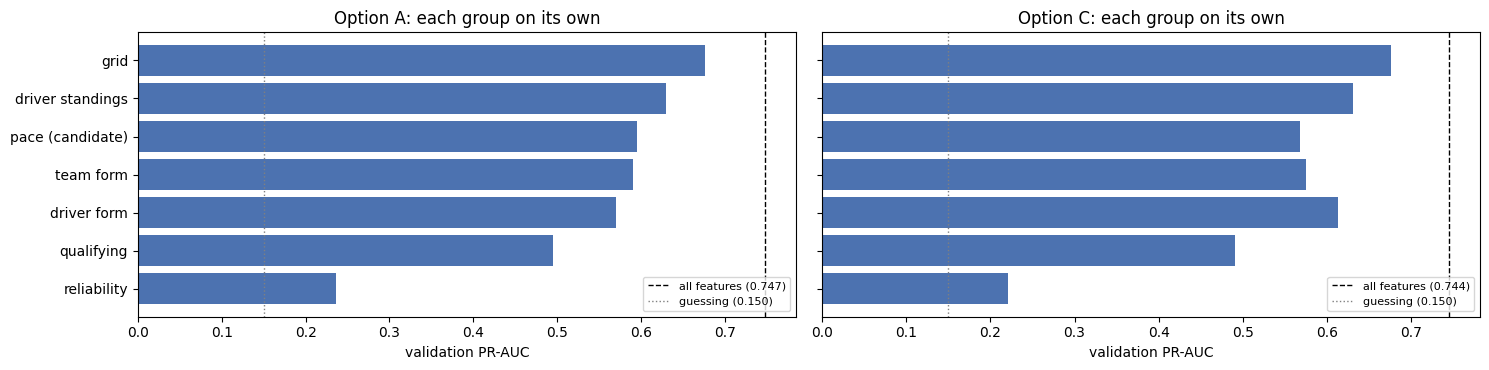

In [315]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
order = alone[alone.option == 'A'].group.tolist()[::-1]
for ax, o in zip(axes, ABLATION_OPTIONS):
    d = alone[alone.option == o].set_index('group').loc[order]
    ax.barh(d.index, d['PR-AUC with this group only'], color='#4C72B0')
    ax.axvline(pr_all[o], color='black', ls='--', lw=1, label=f'all features ({pr_all[o]:.3f})')
    ax.axvline(y_val.mean(), color='grey', ls=':', lw=1, label=f'guessing ({y_val.mean():.3f})')
    ax.set(xlabel='validation PR-AUC', title=f'Option {o}: each group on its own')
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

**Reading.**
- **Every group except reliability is strong on its own, in both options.** In option A, the grid alone reaches a validation PR-AUC of 0.677, the championship position 0.629, pace 0.595, team form 0.590, driver form 0.570 and qualifying 0.495, all far above guessing (0.150). Option C gives nearly the same picture. Reliability alone reaches only 0.236 in option A and 0.222 in C, so it is weak on its own, as found in 7.6.
- **The grid alone is about as good as the grid reference** (0.677 against 0.676 in 10.1). Everything the full model gains over the starting grid (0.747 in option A) comes from adding the other groups to it.
- **Strong alone, but little lost when removed.** Team form alone reaches 0.590 in option A, yet removing it from the full model changes nothing (+0.000). Driver form alone reaches 0.570, yet the model is not worse without it (+0.009). The other groups carry the same information. A driver in good form is usually high in the championship and in a strong team (7.10). So a small change in experiment 1 means that a group can be **replaced** by the others, not that it is **useless**.
- **The two options differ where their data differs.** Driver form alone is stronger in option C (0.613 against 0.570), which learns it from many more seasons. Pace alone is weaker in option C (0.568 against 0.595), because about 60% of its training rows have no real pace value (9.2).

### Decision: the features

**All 7 groups are kept, in both options.**
- **No group makes the model clearly better when it is removed** (experiment 1), so by the rule set before the experiments, none is dropped.
- **Only the grid is clearly needed.** Without it, both options lose 0.06–0.07 in PR-AUC, and no other group can replace it.
- **The other groups are kept although their removal makes no clear difference.** Most of them are strong on their own (experiment 2), but they share their information with each other, so the model loses little when any one of them is missing. They were chosen with evidence in section 7 and are valid at the cutoff, and a change smaller than the luck of 60 races is not a reason to drop them.
- **Driver form in option A is the closest call** (+0.009 when removed, range −0.001 to +0.019). It is kept by the rule. Its information is shared with the championship position and team form rather than missing.
- **Pace is no longer a candidate.** In 7.8 it was kept as a candidate, to be decided with the training seasons and the ablation. It is strong on its own (0.595 in option A) and its removal costs a little (−0.011), so it stays.
- **Reliability is kept.** It is weak on its own and its removal makes no clear difference, so by the rule it stays.

## 10.8 The random split (option D)

**The question.** Options A, B and C divide training and validation **by time**, with validation in 2019–2021, after every training season (8.2). A common alternative is to divide the races **at random**. Option D tests whether a random split gives a validation score that is too optimistic, a score that the model does not reach on new seasons.

**The two versions.** D is built for both options carried forward in 10.6, and each version changes only the split.

| Version | Seasons before the test | Features | Training and validation |
|---|---|---|---|
| D-A | 2003–2021, as option A | the 9 features of option A | random whole races |
| D-C | 1950–2021, as option C | the 11 features of option C | random whole races |

**How D is built.**
- **Whole races.** The races before 2022 are shuffled, and 60 of them (as many as in the time split) form the validation part. All the drivers of a race stay in the same part, for the reason given in 8.2.
- **The test part stays 2022–2024**, the same as for every other version, and is not used here.
- **The preprocessing is learned again** from D's own training races, with the same steps and order as section 9 (fill, cap, scale).
- **The settings of gradient boosting are chosen again** on D's own validation races, with the same 12 combinations and the same tie rule as 10.3.

**What to expect.** In D, the model learns from races that come after many of its validation races, often from the same season. A validation race then looks a lot like races the model has already seen (the same cars, the same drivers in the same form). If this makes the validation score too optimistic, D's score will drop more than the time split's when both are scored on the unseen test seasons (10.9). Because D is scored on different validation races than A and C, its validation score alone cannot be compared with theirs.

**Step 1: the random split and the preprocessing.** `random_race_split` draws the 60 validation races at random from the seasons before 2022. Each version is then filled, capped and scaled with values learned from its own training races only.

In [316]:
N_VAL_RACES = opt_rows['A']['validation'].raceId.nunique()                 # 60, as in the time split

def random_race_split(d, n_val, seed=0):
    """train / validation drawn at random as whole races from the seasons before the test, and the test seasons."""
    before_test = d.year <= VAL[1]
    races = np.sort(d.loc[before_test, 'raceId'].unique())
    val_races = np.random.default_rng(seed).choice(races, n_val, replace=False)
    s = pd.Series(pd.NA, index=d.index, dtype='string')
    s[before_test] = 'train'
    s[before_test & d.raceId.isin(val_races)] = 'validation'
    s[d.year.between(*TEST)] = 'test'
    return s

D_OPTIONS = ['A', 'C']
d_data, d_scaled, d_prep = {}, {}, {}
for o in D_OPTIONS:
    feats = OPTIONS[o][1]
    d = opt_data[o].copy()
    d['split'] = random_race_split(d, N_VAL_RACES)
    tr = d.split == 'train'
    learned_d = fit_fill(d[tr])
    caps_d = fit_caps(d[tr], [f for f in ['team_mech_rel', 'pace_form'] if f in feats])
    s = apply_caps(apply_fill(d, learned_d), caps_d)
    s[feats] = s[feats].astype(float)
    scaler_d = StandardScaler().fit(s.loc[tr, feats])
    s[feats] = scaler_d.transform(s[feats])
    assert s[feats].notna().all().all(), f'D-{o}: a value is missing'
    assert not set(s.loc[s.split == 'train', 'raceId']) & set(s.loc[s.split == 'validation', 'raceId']), 'a race is in both parts'
    d_data[o], d_scaled[o], d_prep[o] = d, s, (learned_d, caps_d, scaler_d)

rows = []
for o in D_OPTIONS:
    s = d_scaled[o]
    for part in ['train', 'validation', 'test']:
        p = s[s.split == part]
        rows.append({'version': f'D-{o}', 'part': part, 'first and last season': f'{p.year.min()}-{p.year.max()}',
                     'different seasons': p.year.nunique(), 'races': p.raceId.nunique(),
                     'rows': len(p), 'podium rate': p.podium.mean(),
                     'races from 2019-2021': p.loc[p.year.between(*VAL), 'raceId'].nunique()})
table(pd.DataFrame(rows), pct1=['podium rate'], caption='The parts of D-A and D-C')

version,part,first and last season,different seasons,races,rows,podium rate,races from 2019-2021
D-A,train,2003-2021,19,300,6340,14.2%,53
D-A,validation,2004-2021,18,60,1267,14.2%,7
D-A,test,2022-2024,3,68,1359,15.0%,0
D-C,train,1950-2021,72,986,22226,13.4%,56
D-C,validation,1950-2021,41,60,1336,13.5%,4
D-C,test,2022-2024,3,68,1359,15.0%,0


**Chart.** Where the 60 validation races come from, season by season, for the time split (orange) and the random split (blue). The time split takes every race of 2019–2021, and the random split takes a few races from almost every season.

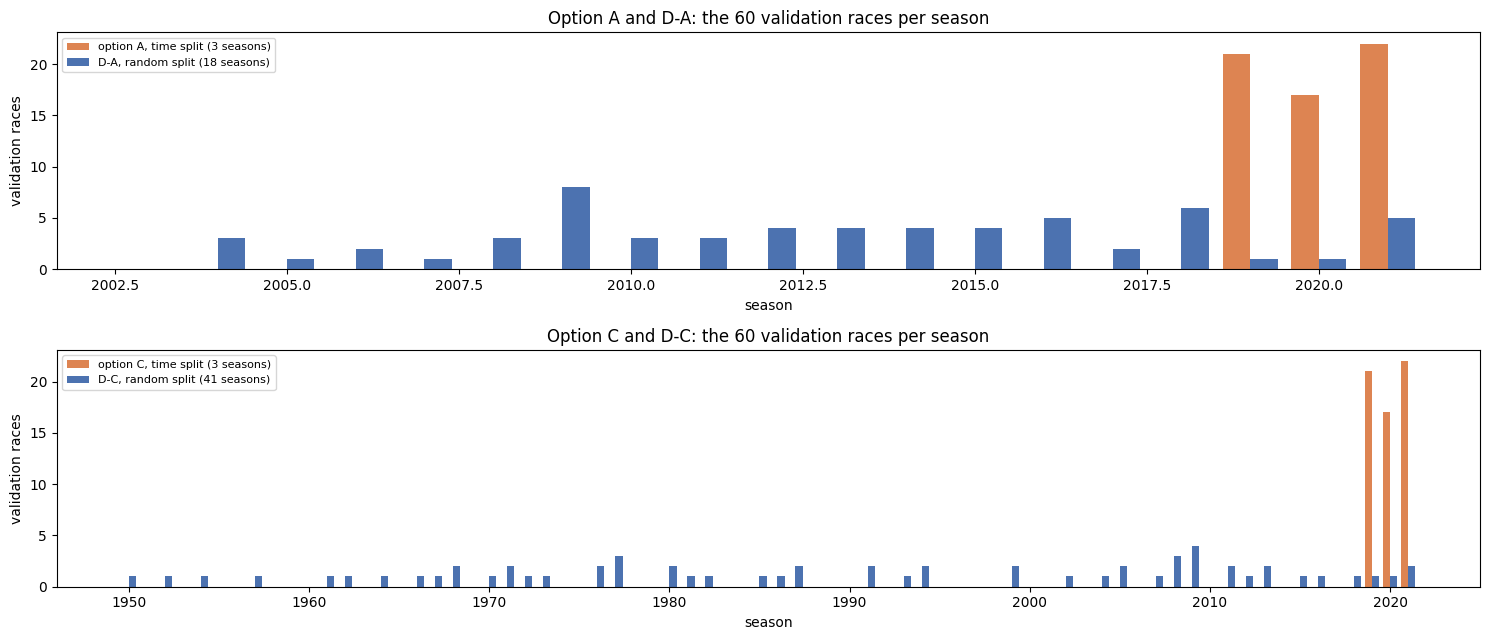

In [317]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6.5))
for ax, o in zip(axes, D_OPTIONS):
    years = np.arange(OPTIONS[o][0], VAL[1] + 1)
    time_val = opt_rows[o]['validation'].groupby('year').raceId.nunique().reindex(years, fill_value=0)
    d_val = d_scaled[o][d_scaled[o].split == 'validation'].groupby('year').raceId.nunique().reindex(years, fill_value=0)
    ax.bar(years - 0.2, time_val, width=0.4, color='#DD8452', label=f'option {o}, time split ({time_val.gt(0).sum()} seasons)')
    ax.bar(years + 0.2, d_val, width=0.4, color='#4C72B0', label=f'D-{o}, random split ({d_val.gt(0).sum()} seasons)')
    ax.set(xlabel='season', ylabel='validation races', title=f'Option {o} and D-{o}: the 60 validation races per season')
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

**Step 2: choose the settings** of gradient boosting for each version on its own validation races, with the same combinations as 10.3.

In [318]:
results = []
for o in D_OPTIONS:
    feats, s = OPTIONS[o][1], d_scaled[o]
    tr, va = s[s.split == 'train'], s[s.split == 'validation']
    for depth, rate, trees in settings:
        model = HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate, max_iter=trees, early_stopping=False, random_state=0)
        p = model.fit(tr[feats], tr.podium).predict_proba(va[feats])[:, 1]
        results.append({'version': f'D-{o}', 'max_depth': depth, 'learning_rate': rate, 'max_iter': trees,
                        'validation PR-AUC': average_precision_score(va.podium, p)})
d_tuning = pd.DataFrame(results)

d_params, d_gb, d_threshold, d_val_prob = {}, {}, {}, {}
for o in D_OPTIONS:
    t = d_tuning[d_tuning.version == f'D-{o}'].assign(score=lambda x: x['validation PR-AUC'].round(3))
    best = t.sort_values(['score', 'max_depth', 'max_iter'], ascending=[False, True, True]).iloc[0]
    d_params[o] = dict(max_depth=int(best['max_depth']), learning_rate=float(best['learning_rate']), max_iter=int(best['max_iter']))
    feats, s = OPTIONS[o][1], d_scaled[o]
    tr, va = s[s.split == 'train'], s[s.split == 'validation']
    d_gb[o] = HistGradientBoostingClassifier(**d_params[o], early_stopping=False, random_state=0).fit(tr[feats], tr.podium)
    d_val_prob[o] = d_gb[o].predict_proba(va[feats])[:, 1]
    d_threshold[o] = best_threshold(va.podium, d_val_prob[o])                  # kept for the test (10.9)
    print(f'D-{o}: gradient boosting with {d_params[o]}')

D-A: gradient boosting with {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}
D-C: gradient boosting with {'max_depth': 5, 'learning_rate': 0.1, 'max_iter': 300}


**Step 3: validation scores** of D-A and D-C, next to gradient boosting with the time split in options A and C (10.3). The two kinds of split are scored on different validation races.

In [319]:
rows = []
for o in D_OPTIONS:
    va = d_scaled[o][d_scaled[o].split == 'validation']
    rows.append({'version': f'D-{o} (random races)', 'validation races': va.raceId.nunique(),
                 **scores(va, d_val_prob[o], d_threshold[o]), 'F1 threshold': d_threshold[o]})
    rows.append({'version': f'{o} (time split, 2019-2021)', 'validation races': opt_rows[o]['validation'].raceId.nunique(),
                 **opt_gb_results[o].loc['validation'], 'F1 threshold': opt_gb_threshold[o]})
d_compare = pd.DataFrame(rows)
display(d_compare.style.format('{:.3f}', subset=list(d_compare.columns[2:])).hide(axis='index')
        .set_caption('Validation scores of gradient boosting: random split (D) and time split'))

version,validation races,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race,F1 threshold
D-A (random races),60,0.930,0.720,0.661,0.627,0.700,0.661,0.360
"A (time split, 2019-2021)",60,0.940,0.747,0.731,0.673,0.800,0.706,0.345
D-C (random races),60,0.909,0.630,0.623,0.516,0.783,0.594,0.249
"C (time split, 2019-2021)",60,0.935,0.744,0.740,0.701,0.783,0.706,0.362


**Reading.**
- **The split is random, as intended.** The 60 validation races of D-A come from 18 different seasons, and only 7 of them from 2019–2021. Those of D-C come from 41 seasons, and only 4 from 2019–2021. The rest of 2019–2021 is now in the training part.
- **The random split chooses a much bigger model for option C.** D-A chooses the same settings as option A (depth 2, rate 0.03, 300 trees). D-C chooses the largest combination of all, depth 5, rate 0.1 and 300 trees, which was the worst choice for option C with the time split (10.3), because there it memorised the training seasons. With a random split, each validation race sits in a season that the model also trains on, with the same cars and drivers. A model that memorises the patterns of each season can then look good on validation, although these patterns will not carry over to new seasons. Whether this choice holds up on 2022–2024 is tested in 10.9.
- **The validation scores of D are lower than those of the time split** (PR-AUC 0.720 against 0.747 for option A, and 0.630 against 0.744 for option C). This is not because D's models are worse, but because they are scored on other races. D's validation races are spread over older seasons, in which podiums were much harder to predict (10.1), while 2019–2021 were unusually predictable. D-C's validation races reach back to the 1950s, so its score is the lowest. As said above, these validation scores cannot be compared with each other. What matters is how far each version's validation score is from its score on the unseen test seasons (10.9).

## 10.9 The final test

The test part (2022–2024) has not been used so far. Every setting, threshold and feature was chosen on the training and validation parts. It is now used for the scores below.

**Fixed before the test.**
- The features of each option, all groups kept (10.7).
- The settings of every model and its F1 threshold, chosen on the validation part (10.2–10.4 for options A, B and C, 10.8 for D) and used unchanged.
- The two models carried forward, gradient boosting in options A and C (10.6). Every model is scored, because the brief asks for every model's score on the unseen test part, but no choice is made from the test scores.

**What is tested.** Each part below has its own table.
- **Every model on the test part**, exactly as it was trained and chosen.
- **Validation and test side by side**, to see which models held up on new seasons.
- **How sure the differences on the test are**, for the main models.
- **The split experiment.** For gradient boosting with the time split (options A and C) and with the random split (D-A and D-C), how far the validation score is from the test score.
- **Whether training again on the validation seasons helps.** Gradient boosting in options A and C is trained again on all the seasons before 2022 and scored on the test part again.

### Every model on the test part

Every model as trained in 10.2–10.4 and 10.8, each with the threshold chosen on its validation part. Nothing is trained here.

In [320]:
test_rows = opt_rows['A']['test']                                       # the same test rows in every option and in D
y_test_final = test_rows.podium
for o in OPTIONS:
    assert (opt_rows[o]['test'].podium.values == y_test_final.values).all()
grid_test = -opt_capped['A'].loc[test_rows.index, 'grid_clean'].values  # reference: a smaller grid slot = a higher "probability"

test_prob, test_threshold = {}, {}
for o in OPTIONS:
    X_te = opt_X[o]['test'][0]
    test_prob[(o, 'logistic regression')] = opt_lr[o].predict_proba(X_te)[:, 1]
    test_prob[(o, 'gradient boosting')] = opt_gb[o].predict_proba(X_te)[:, 1]
    test_prob[(o, 'neural network')] = predict(opt_nn[o], X_te)
    for m, thr in [('logistic regression', opt_lr_threshold), ('gradient boosting', opt_gb_threshold), ('neural network', opt_nn_threshold)]:
        test_threshold[(o, m)] = thr[o]
for o in D_OPTIONS:
    s = d_scaled[o]
    test_prob[(f'D-{o}', 'gradient boosting')] = d_gb[o].predict_proba(s.loc[test_rows.index, OPTIONS[o][1]])[:, 1]
    test_threshold[(f'D-{o}', 'gradient boosting')] = d_threshold[o]

rows = [{'version': '–', 'model': 'the top 3 on the grid (reference)', **scores(test_rows, grid_test, -3)}]
for (v, m), p in test_prob.items():
    rows.append({'version': v, 'model': m, **scores(test_rows, p, test_threshold[(v, m)]), 'F1 threshold': test_threshold[(v, m)]})
all_test = pd.DataFrame(rows)
display(all_test.style.format('{:.3f}', subset=list(all_test.columns[2:]), na_rep='–').hide(axis='index')
        .set_caption('Test part (2022-2024): every model, as trained and chosen on the validation part'))

# option A in the layout used again in 10.10 and section 11
lr_name, gb_name, nn_name = 'logistic regression (baseline)', 'gradient boosting', 'neural network'
p_test = {lr_name: test_prob[('A', 'logistic regression')], gb_name: test_prob[('A', 'gradient boosting')],
          nn_name: test_prob[('A', 'neural network')]}
thresholds = {lr_name: lr_threshold, gb_name: gb_threshold, nn_name: nn_threshold}
test_results = pd.DataFrame({'the top 3 on the grid (reference)': {**scores(test_rows, grid_test, -3), 'threshold': np.nan},
                             **{name: {**scores(test_rows, p, thresholds[name]), 'threshold': thresholds[name]}
                                for name, p in p_test.items()}}).T

version,model,ROC-AUC,PR-AUC,F1,precision,recall,top-3 per race,F1 threshold
–,the top 3 on the grid (reference),0.913,0.645,0.647,0.647,0.647,0.647,–
A,logistic regression,0.937,0.716,0.674,0.642,0.711,0.657,0.368
A,gradient boosting,0.939,0.717,0.665,0.629,0.706,0.652,0.345
A,neural network,0.933,0.702,0.670,0.626,0.721,0.657,0.369
B,logistic regression,0.932,0.712,0.645,0.616,0.676,0.657,0.367
B,gradient boosting,0.936,0.705,0.650,0.603,0.706,0.647,0.351
B,neural network,0.934,0.704,0.636,0.604,0.672,0.642,0.425
C,logistic regression,0.936,0.715,0.674,0.605,0.760,0.652,0.319
C,gradient boosting,0.937,0.704,0.659,0.618,0.706,0.642,0.362
C,neural network,0.933,0.706,0.656,0.636,0.676,0.647,0.414


**Reading.**
- **Every model beats the grid on the ranking scores.** The test PR-AUC is 0.652–0.717 against 0.645 for the grid, and the ROC-AUC 0.918–0.939 against 0.913. Form, team and championship information add something beyond the starting order, also with the new 2022 cars.
- **The models are very close to each other.** The highest PR-AUC is gradient boosting in option A (0.717), but logistic regression in options A and C is practically the same (0.716 and 0.715). Gradient boosting in option C reaches 0.704.
- **On F1 and the top-3 per race, the models are only a little better than the grid, or not at all.** The grid's F1 and top-3 are both 0.647. The models reach an F1 of 0.627–0.674 and a top-3 of 0.598–0.662, so some are above the grid and some below it.
- **D-C is the weakest model** (PR-AUC 0.652), the only one close to the grid. It is the large model chosen by the random split (10.8).

### Validation and test side by side

For every model, the validation score (10.5 and 10.8) next to the test score. A model that holds up on new seasons keeps about the same score.

In [321]:
val_scores = {}
for o in OPTIONS:
    for m, (p, thr, res) in MODELS.items():
        val_scores[(o, m)] = res[o].loc['validation']
for o in D_OPTIONS:
    va = d_scaled[o][d_scaled[o].split == 'validation']
    val_scores[(f'D-{o}', 'gradient boosting')] = pd.Series(scores(va, d_val_prob[o], d_threshold[o]))

rows = []
for (v, m), p in test_prob.items():
    te = scores(test_rows, p, test_threshold[(v, m)])
    va = val_scores[(v, m)]
    row = {'version': v, 'model': m}
    for metric in ['PR-AUC', 'F1', 'top-3 per race']:
        row[f'{metric}, validation'] = va[metric]
        row[f'{metric}, test'] = te[metric]
        row[f'{metric}, test minus validation'] = te[metric] - va[metric]
    rows.append(row)
side_by_side = pd.DataFrame(rows)
diff_cols = [c for c in side_by_side.columns if c.endswith('minus validation')]
display(side_by_side.style.format('{:.3f}', subset=[c for c in side_by_side.columns[2:] if c not in diff_cols])
        .format('{:+.3f}', subset=diff_cols).hide(axis='index')
        .set_caption('Every model: validation score and test score'))

version,model,"PR-AUC, validation","PR-AUC, test","PR-AUC, test minus validation","F1, validation","F1, test","F1, test minus validation","top-3 per race, validation","top-3 per race, test","top-3 per race, test minus validation"
A,logistic regression,0.717,0.716,-0.001,0.730,0.674,-0.056,0.678,0.657,-0.021
A,gradient boosting,0.747,0.717,-0.030,0.731,0.665,-0.066,0.706,0.652,-0.054
A,neural network,0.747,0.702,-0.044,0.735,0.670,-0.066,0.700,0.657,-0.043
B,logistic regression,0.702,0.712,+0.010,0.738,0.645,-0.093,0.694,0.657,-0.038
B,gradient boosting,0.735,0.705,-0.030,0.740,0.650,-0.089,0.706,0.647,-0.058
B,neural network,0.731,0.704,-0.026,0.738,0.636,-0.102,0.694,0.642,-0.052
C,logistic regression,0.709,0.715,+0.006,0.725,0.674,-0.052,0.700,0.652,-0.048
C,gradient boosting,0.744,0.704,-0.040,0.740,0.659,-0.081,0.706,0.642,-0.063
C,neural network,0.741,0.706,-0.034,0.733,0.656,-0.077,0.694,0.647,-0.047
D-A,gradient boosting,0.720,0.702,-0.018,0.661,0.670,+0.008,0.661,0.662,+0.001


**Reading.**
- **Logistic regression keeps its validation score, gradient boosting and the network do not.** In option A, logistic regression goes from 0.717 to 0.716, gradient boosting from 0.747 to 0.717 (−0.030) and the network from 0.747 to 0.702 (−0.044). Options B and C show the same pattern. Logistic regression stays within ±0.010, and the other two lose 0.026–0.044.
- **The reason is the choice of settings.** Gradient boosting and the network had many settings chosen on the validation part, so their validation scores were a little flattering, as warned in 10.5. Logistic regression has almost nothing to choose, so its validation score was already honest. On new seasons, the advantage of the more flexible models disappears.
- **F1 drops for every model of A, B and C** (by 0.05–0.10). The thresholds chosen on validation fit the test seasons less well, and 2022–2024 were harder to predict than 2019–2021 for the grid too (its F1 falls from 0.717 to 0.647).
- **The two D versions barely change** between validation and test. This is discussed in the split experiment below.

### How sure are the differences on the test?

The 68 test races are redrawn 1,000 times, as in 10.6, for the comparisons between the main models.

In [322]:
test_redraws = race_redraws(test_rows)
comparisons = [('option A, gradient boosting minus the grid', grid_test, test_prob[('A', 'gradient boosting')]),
               ('option C, gradient boosting minus the grid', grid_test, test_prob[('C', 'gradient boosting')]),
               ('option C minus option A, gradient boosting', test_prob[('A', 'gradient boosting')], test_prob[('C', 'gradient boosting')]),
               ('option A, gradient boosting minus logistic regression', test_prob[('A', 'logistic regression')], test_prob[('A', 'gradient boosting')]),
               ('option C, gradient boosting minus logistic regression', test_prob[('C', 'logistic regression')], test_prob[('C', 'gradient boosting')])]
rows = []
for name, p_a, p_b in comparisons:
    lo, hi = change_range(y_test_final, p_a, p_b, test_redraws)
    rows.append({'comparison': name,
                 'PR-AUC difference': average_precision_score(y_test_final, p_b) - average_precision_score(y_test_final, p_a),
                 '95% range': f'{lo:+.3f} to {hi:+.3f}', 'clear difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
display(pd.DataFrame(rows).style.format({'PR-AUC difference': '{:+.3f}'}).hide(axis='index')
        .set_caption('Test part: how sure are the differences?'))

comparison,PR-AUC difference,95% range,clear difference?
"option A, gradient boosting minus the grid",+0.072,+0.041 to +0.102,yes
"option C, gradient boosting minus the grid",+0.059,+0.017 to +0.096,yes
"option C minus option A, gradient boosting",-0.013,-0.034 to +0.007,no
"option A, gradient boosting minus logistic regression",+0.002,-0.022 to +0.027,no
"option C, gradient boosting minus logistic regression",-0.011,-0.037 to +0.015,no


**Reading.**
- **Both models carried forward clearly beat the grid on the test.** Gradient boosting in option A is 0.072 above the grid (range +0.041 to +0.102), and in option C 0.059 above it (range +0.017 to +0.096).
- **Options A and C are not clearly different** (C is 0.013 lower, range −0.034 to +0.007), as on validation.
- **Gradient boosting is not clearly better than logistic regression** in either option (+0.002 in option A, −0.011 in option C, both ranges include 0). On the test seasons, the simple baseline does as well as the more flexible model.

### The split experiment: does a random split give an honest validation score?

For gradient boosting with the time split and with the random split, the validation score next to the test score of the same model. A validation score that is far above the test score was too optimistic.

In [323]:
val_pr = {'A': pr_auc[('A', 'gradient boosting')], 'C': pr_auc[('C', 'gradient boosting')],
          'D-A': average_precision_score(d_scaled['A'].loc[d_scaled['A'].split == 'validation', 'podium'], d_val_prob['A']),
          'D-C': average_precision_score(d_scaled['C'].loc[d_scaled['C'].split == 'validation', 'podium'], d_val_prob['C'])}
rows = []
for v, split_name in [('A', 'time'), ('D-A', 'random races'), ('C', 'time'), ('D-C', 'random races')]:
    test_pr = average_precision_score(y_test_final, test_prob[(v, 'gradient boosting')])
    rows.append({'version': v, 'split': split_name, 'settings': str(d_params[v[-1]] if v.startswith('D') else opt_gb_params[v]),
                 'validation PR-AUC': val_pr[v], 'test PR-AUC': test_pr, 'test minus validation': test_pr - val_pr[v]})
split_test = pd.DataFrame(rows)
display(split_test.style.format({'validation PR-AUC': '{:.3f}', 'test PR-AUC': '{:.3f}', 'test minus validation': '{:+.3f}'})
        .hide(axis='index').set_caption('Gradient boosting: validation score against test score, time split and random split'))

version,split,settings,validation PR-AUC,test PR-AUC,test minus validation
A,time,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}",0.747,0.717,-0.030
D-A,random races,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}",0.720,0.702,-0.018
C,time,"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}",0.744,0.704,-0.040
D-C,random races,"{'max_depth': 5, 'learning_rate': 0.1, 'max_iter': 300}",0.630,0.652,+0.022


**Reading.**
- **The random split did not give a too optimistic validation score.** The expectation in 10.8 was that a random split would look better on validation than on new seasons. The opposite happened. With the time split, gradient boosting loses 0.030 (option A) and 0.040 (option C) from validation to test. With the random split, D-A loses only 0.018 and D-C even gains 0.022. The random validation races are spread over many seasons, including harder ones, while 2019–2021 were unusually predictable, so the time split's validation score was the more flattering one here.
- **But the random split chose a worse model.** D-A chose the same settings as option A, and its test score is close (0.702 against 0.717). D-C chose the largest model (depth 5, rate 0.1, 300 trees), which reaches only 0.652 on the test, against 0.704 for option C's model chosen with the time split. The random split rewarded a model that learns patterns specific to each season, because its validation races share their seasons with the training races. These patterns did not carry over to 2022–2024.
- **So the time split is kept, for a different reason than expected.** Its validation score is not more accurate, but it chooses models that do better on new seasons, which is what the model is for. This result comes from one random split, so the exact numbers would change with another draw.

**Is it the settings or the training races?** D-C differs from option C in two ways, its random training races and the large model it chose. To separate them, gradient boosting is trained on D-C's training races with **option C's settings** (depth 2, rate 0.03, 100 trees), and scored on D-C's validation races and on the test part.

In [324]:
feats, s = OPTIONS['C'][1], d_scaled['C']
tr, va = s[s.split == 'train'], s[s.split == 'validation']
dc_c_settings = HistGradientBoostingClassifier(**opt_gb_params['C'], early_stopping=False, random_state=0).fit(tr[feats], tr.podium)
p_val_cs = dc_c_settings.predict_proba(va[feats])[:, 1]
p_test_cs = dc_c_settings.predict_proba(s.loc[test_rows.index, feats])[:, 1]

rows = []
for name, settings_used, p_val, y_v, p_te in [
        ('C (time split)', opt_gb_params['C'], None, None, test_prob[('C', 'gradient boosting')]),          # validation score from 10.6
        ('D-C, its own settings', d_params['C'], d_val_prob['C'], va.podium, test_prob[('D-C', 'gradient boosting')]),
        ("D-C, option C's settings", opt_gb_params['C'], p_val_cs, va.podium, p_test_cs)]:
    val = pr_auc[('C', 'gradient boosting')] if p_val is None else average_precision_score(y_v, p_val)
    rows.append({'version': name, 'settings': str(settings_used), 'validation PR-AUC': val,
                 'test PR-AUC': average_precision_score(y_test_final, p_te)})
dc_check = pd.DataFrame(rows)
dc_check['test minus validation'] = dc_check['test PR-AUC'] - dc_check['validation PR-AUC']
display(dc_check.style.format({'validation PR-AUC': '{:.3f}', 'test PR-AUC': '{:.3f}', 'test minus validation': '{:+.3f}'})
        .hide(axis='index').set_caption("D-C with its own settings and with option C's settings"))

for name, p_a, p_b in [("D-C with option C's settings minus D-C with its own settings", test_prob[('D-C', 'gradient boosting')], p_test_cs),
                       ("D-C with option C's settings minus option C", test_prob[('C', 'gradient boosting')], p_test_cs)]:
    lo, hi = change_range(y_test_final, p_a, p_b, test_redraws)
    diff = average_precision_score(y_test_final, p_b) - average_precision_score(y_test_final, p_a)
    print(f'{name}: test PR-AUC {diff:+.3f} (95% range {lo:+.3f} to {hi:+.3f})')

version,settings,validation PR-AUC,test PR-AUC,test minus validation
C (time split),"{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}",0.744,0.704,-0.040
"D-C, its own settings","{'max_depth': 5, 'learning_rate': 0.1, 'max_iter': 300}",0.630,0.652,+0.022
"D-C, option C's settings","{'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}",0.614,0.702,+0.088


D-C with option C's settings minus D-C with its own settings: test PR-AUC +0.050 (95% range +0.014 to +0.087)
D-C with option C's settings minus option C: test PR-AUC -0.002 (95% range -0.017 to +0.008)


**Reading.**
- **It is the settings, not the training races.** Trained on D-C's random training races with option C's settings, gradient boosting reaches 0.702 on the test part, practically the same as option C (0.704, difference −0.002, range −0.017 to +0.008) and clearly better than D-C with its own settings (+0.050, range +0.014 to +0.087). The random training races are not the problem.
- **The random validation races chose the wrong settings.** On D-C's own validation races, option C's settings score lower than the large model (0.614 against 0.630), so the random split picked the large model. On the test seasons the order is reversed (0.702 against 0.652). The time split chose the settings that do better on new seasons.
- **Validation scores from different splits cannot be compared, but test scores can.** The same model scores 0.614 on the random validation races and 0.702 on the test, because the random validation races include older seasons that are harder to predict. All the versions are scored on the same test seasons, so their test scores are the fair comparison.

### Does training again on the validation seasons help?

Gradient boosting in options A and C is trained again on all the seasons before 2022 (training and validation together), with the same settings. The preprocessing (fill values, capping limits and scaling) is learned again from those seasons. Both versions are scored on the same test part, with the threshold chosen on validation.

In [325]:
def prepare(o, learn_from):
    """Fill, cap and scale the rows of option o, with every value learned from the rows in learn_from."""
    feats, d = OPTIONS[o][1], opt_data[o]
    learned_o = fit_fill(d[learn_from])
    caps_o = fit_caps(d[learn_from], [f for f in ['team_mech_rel', 'pace_form'] if f in feats])
    s = apply_caps(apply_fill(d, learned_o), caps_o)
    s[feats] = s[feats].astype(float)
    scaler_o = StandardScaler().fit(s.loc[learn_from, feats])
    s[feats] = scaler_o.transform(s[feats])
    return learned_o, caps_o, scaler_o, s

retrained, rows = {}, []
for o in ['A', 'C']:
    feats = OPTIONS[o][1]
    before_test = opt_data[o].split.isin(['train', 'validation'])
    learned_o, caps_o, scaler_o, s = prepare(o, before_test)
    model = HistGradientBoostingClassifier(**opt_gb_params[o], early_stopping=False, random_state=0)
    model.fit(s.loc[before_test, feats], s.loc[before_test, 'podium'])          # the training happens here
    p_after = model.predict_proba(s.loc[test_rows.index, feats])[:, 1]
    p_before = test_prob[(o, 'gradient boosting')]
    retrained[o] = dict(model=model, learned=learned_o, caps=caps_o, scaler=scaler_o, scaled=s, mask=before_test, p_test=p_after)
    lo, hi = change_range(y_test_final, p_before, p_after, test_redraws)
    s_before, s_after = scores(test_rows, p_before, opt_gb_threshold[o]), scores(test_rows, p_after, opt_gb_threshold[o])
    rows.append({'option': o, 'trained on': f'{OPTIONS[o][0]}-{TRAIN[1]} / {OPTIONS[o][0]}-{VAL[1]}',
                 'PR-AUC before': s_before['PR-AUC'], 'PR-AUC after': s_after['PR-AUC'],
                 'change': s_after['PR-AUC'] - s_before['PR-AUC'], '95% range': f'{lo:+.3f} to {hi:+.3f}',
                 'clear?': 'yes' if (lo > 0 or hi < 0) else 'no', 'F1 before': s_before['F1'], 'F1 after': s_after['F1'],
                 'top-3 before': s_before['top-3 per race'], 'top-3 after': s_after['top-3 per race']})
retrain_test = pd.DataFrame(rows)
fmt = {c: '{:.3f}' for c in retrain_test.columns if c not in ('option', 'trained on', '95% range', 'clear?')}
fmt['change'] = '{:+.3f}'
display(retrain_test.style.format(fmt).hide(axis='index')
        .set_caption('Test part: gradient boosting before and after training again on the validation seasons'))

# option A, trained again (kept for reference: sections 11 and 12 use the models trained on the training part only)
r = retrained['A']
gb_final, final_fill, final_caps, final_scaler, final_scaled, final_mask = r['model'], r['learned'], r['caps'], r['scaler'], r['scaled'], r['mask']
X_final, y_final = final_scaled.loc[final_mask, F], final_scaled.loc[final_mask, 'podium']
X_test_final = final_scaled.loc[test_rows.index, F]

option,trained on,PR-AUC before,PR-AUC after,change,95% range,clear?,F1 before,F1 after,top-3 before,top-3 after
A,2003-2018 / 2003-2021,0.717,0.704,-0.014,-0.025 to -0.002,yes,0.665,0.676,0.652,0.667
C,1950-2018 / 1950-2021,0.704,0.698,-0.006,-0.011 to +0.001,no,0.659,0.659,0.642,0.642


**Reading.**
- **Training again on 2019–2021 did not help the ranking.** In option A, the test PR-AUC falls from 0.717 to 0.704, and the drop is clear (range −0.025 to −0.002). In option C it falls from 0.704 to 0.698, which is not clear. The F1 and the top-3 per race of option A rise a little (F1 0.665 to 0.676, top-3 0.652 to 0.667), and those of option C do not change.
- **More recent seasons are not automatically better.** One possible reason is that 2019–2021 were dominated by one team at a time (Mercedes, then Red Bull), so a model that learns from them may trust the front of the grid even more. On the test seasons, the most confident misses are indeed pole-sitters (see the most confident picks below). This explanation is not tested here.
- **The models scored above are the ones trained without the validation seasons.** The plan in 8.2 was to train again before the test, but this test shows that it does not improve the ranking, so the scores of the models as chosen on validation are reported.

### Charts

The precision-recall curves on the test part for gradient boosting in every version, with the grid as a reference, and the confusion matrices of the two models carried forward.

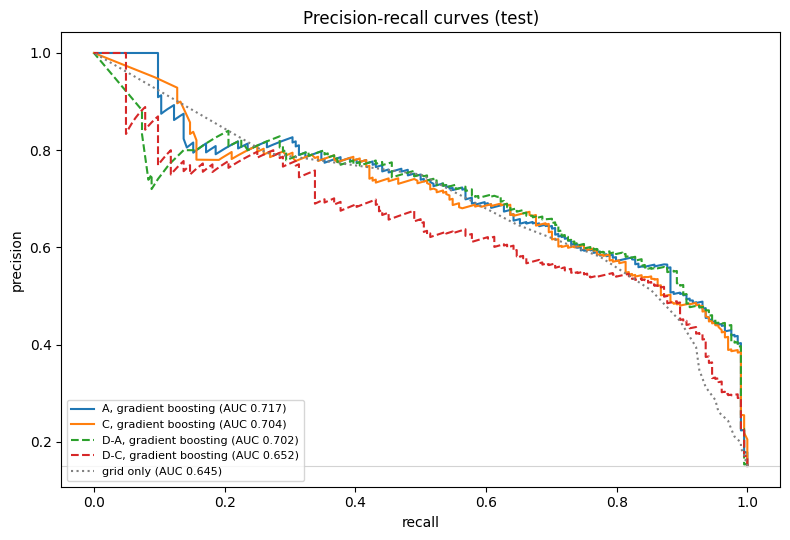

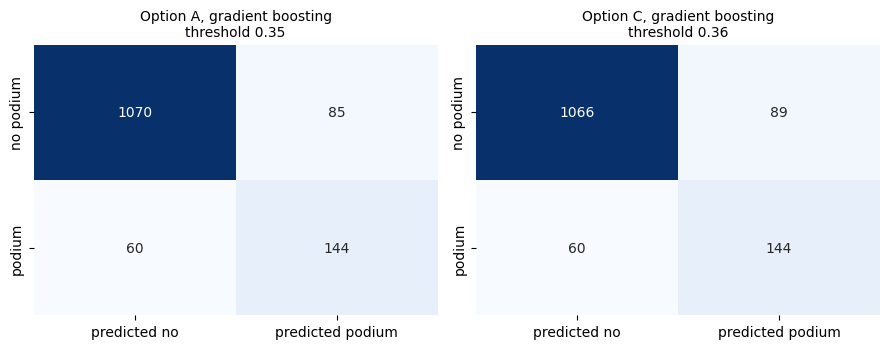

In [326]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for v in ['A', 'C', 'D-A', 'D-C']:
    p = test_prob[(v, 'gradient boosting')]
    prec, rec, _ = precision_recall_curve(y_test_final, p)
    ax.plot(rec, prec, ls='--' if v.startswith('D') else '-', label=f'{v}, gradient boosting (AUC {average_precision_score(y_test_final, p):.3f})')
prec, rec, _ = precision_recall_curve(y_test_final, grid_test)
ax.plot(rec, prec, color='grey', ls=':', label=f'grid only (AUC {average_precision_score(y_test_final, grid_test):.3f})')
ax.axhline(y_test_final.mean(), color='lightgrey', lw=0.8)
ax.set(xlabel='recall', ylabel='precision', title='Precision-recall curves (test)')
ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, o in zip(axes, ['A', 'C']):
    cm = confusion_matrix(y_test_final, (test_prob[(o, 'gradient boosting')] >= opt_gb_threshold[o]).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['predicted no', 'predicted podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'Option {o}, gradient boosting\nthreshold {opt_gb_threshold[o]:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

**Reading.**
- **The precision-recall curves of A, C and D-A lie close together** and above the grid for most of the curve. D-C's curve is lower, close to the grid's.
- **Options A and C find the same number of podiums.** At their thresholds, both find 144 of the 204 podium finishers of 2022–2024 and miss 60. Option A gives 85 false alarms and option C 89.

### The most confident picks

PR-AUC depends most on the top of the ranking, so the highest probabilities show where the models differ.

In [327]:
table(pd.DataFrame([{'version': v, 'model': m, 'podiums among its 25 highest probabilities': int(y_test_final.values[np.argsort(-p)[:25]].sum())}
                    for (v, m), p in test_prob.items()]), caption='Test part: the 25 most confident picks of each model')

misses = (test_rows[['raceId', 'driverId', 'year', 'podium']]
          .assign(grid=opt_capped['A'].loc[test_rows.index, 'grid_clean'].astype(int).values,
                  a=test_prob[('A', 'gradient boosting')], c=test_prob[('C', 'gradient boosting')])
          .query('podium == 0').nlargest(6, 'a')
          .merge(drivers[['driverId', 'surname']], on='driverId').merge(races[['raceId', 'name']], on='raceId'))
table(misses[['year', 'name', 'surname', 'grid', 'a', 'c']]
      .rename(columns={'name': 'race', 'a': 'option A, gradient boosting', 'c': 'option C, gradient boosting'}),
      dec2=['option A, gradient boosting', 'option C, gradient boosting'],
      caption='Test part: the 6 most confident picks of option A (gradient boosting) that missed the podium')

version,model,podiums among its 25 highest probabilities
A,logistic regression,24
A,gradient boosting,22
A,neural network,23
B,logistic regression,24
B,gradient boosting,21
B,neural network,23
C,logistic regression,23
C,gradient boosting,23
C,neural network,23
D-A,gradient boosting,18


year,race,surname,grid,"option A, gradient boosting","option C, gradient boosting"
2024,Australian Grand Prix,Verstappen,1,0.84,0.62
2024,Austrian Grand Prix,Verstappen,1,0.84,0.63
2024,São Paulo Grand Prix,Norris,1,0.84,0.61
2022,Monaco Grand Prix,Leclerc,1,0.82,0.61
2022,Spanish Grand Prix,Leclerc,1,0.81,0.61
2022,Azerbaijan Grand Prix,Leclerc,1,0.81,0.62


**Reading.**
- **What a "most confident pick" is.** Each model gives every driver a probability. Its most confident picks are the drivers with the highest probabilities, the ones it was surest would finish on the podium.
- **The top of the ranking is very reliable.** Among their 25 most confident picks, most models have 21–24 real podium finishers. Logistic regression in options A and B has 24 of 25. D-A has the fewest (18).
- **The most confident misses are pole-sitters who did not finish on the podium.** Gradient boosting in option A gave them 0.81–0.84. Among them are Verstappen in Australia 2024, who retired with a brake failure, and Leclerc in Spain and Azerbaijan 2022, who retired with engine failures. Failures like these cannot be known the day before the race, so the high probabilities were reasonable.
- **Option C is less confident about the same drivers** (0.61–0.63). It learned from older seasons, in which a pole position led to a podium much less often (10.1).

## 10.10 Primary and secondary metric

The brief asks for ROC-AUC, PR-AUC and F1 for every model (all reported above, together with precision, recall and top-3 per race), and for a **primary** and a **secondary** metric, with a justification.

| | Metric | In one sentence |
|---|---|---|
| **Primary** | **PR-AUC** | How well the podium finishers are ranked above everyone else, without choosing a threshold. |
| **Secondary** | **F1**, at the threshold chosen on validation | How good the final yes/no answers are. |

**Primary, PR-AUC.**
- **Podiums are the rare class** (about 15% of the rows), and they are what we want to find. Precision and recall are both about the podium class, so PR-AUC measures exactly how well the podium finishers are found and ranked at the top.
- **It needs no threshold**, so it judges the model itself, not a cut-off. This is why it was used to choose every setting (10.2–10.4), the models carried forward (10.6) and the feature groups (10.7).

**Secondary, F1.**
- **In use, the model gives a yes/no answer** for each driver, on the podium or not. PR-AUC scores the ranking over all possible thresholds, and F1 scores the answers at the one threshold that is actually used. Together they cover the ranking and the final answers.
- **Like PR-AUC, it is about the podium class.** It counts the missed podium finishers and the false alarms, and ignores the many easy, correct "no podium" answers.
- **Its threshold was chosen on the validation part only,** so the test F1 is an honest score of the answers the model would give.
- **Its weakness is the threshold.** A threshold chosen on 2019–2021 does not fit 2022–2024 as well, so F1 drops more from validation to test than PR-AUC does (10.9). This is part of what using the model for real would look like, so it is a fair thing to measure.

**Not chosen as primary or secondary.**
- **ROC-AUC** stays in every table, but it adds little as a second score. It also ranks without a threshold, like PR-AUC, and it compares every podium driver with every non-podium driver. Most non-podium drivers start far back and are easy to rank (below), so ROC-AUC is high for every model and even for the grid alone.
- **Accuracy** would be misleading, because answering "no podium" for every driver is already right about 85% of the time.
- **Top-3 per race** is the most natural score for F1 racing and stays as an extra check, but it is not one of the brief's metrics, and it only looks at the order inside each race.

**The evidence.** The table puts the three metrics side by side for the grid and every model (10.5 and 10.9). The prints show why ROC-AUC is high for everyone, and what accuracy would give, for gradient boosting in options A and C.

In [328]:
rows = []
for part, results in [('validation', all_compare), ('test', all_test)]:
    grid_row, models = results.iloc[0], results.iloc[1:]                 # the first row is the grid reference
    for metric in ['PR-AUC', 'F1', 'ROC-AUC']:
        rows.append({'part': part, 'metric': metric, 'the grid': grid_row[metric],
                     'models (lowest)': models[metric].min(), 'models (highest)': models[metric].max(),
                     'best model minus the grid': models[metric].max() - grid_row[metric]})
display(pd.DataFrame(rows).style.format({c: '{:.3f}' for c in ['the grid', 'models (lowest)', 'models (highest)']} |
                                        {'best model minus the grid': '{:+.3f}'})
        .hide(axis='index').set_caption('The three metrics for the grid and every model'))

for o in ['A', 'C']:
    for part, rows_, p in [('validation', opt_rows[o]['validation'], opt_p_gb[o]['validation']),
                           ('test', test_rows, test_prob[(o, 'gradient boosting')])]:
        no_podium = (rows_.podium == 0).values
        far_back = (opt_capped['A'].loc[rows_.index, 'grid_clean'] >= 11).values
        predicted_podium = p >= opt_gb_threshold[o]
        print(f'option {o}, {part}: {(no_podium & far_back).sum() / no_podium.sum():.0%} of the non-podium rows start P11 or further back, '
              f'and gradient boosting gives them {p[no_podium & far_back].mean():.1%} on average | accuracy of answering "no podium" '
              f'for everyone {no_podium.mean():.1%}, of gradient boosting at its threshold {(predicted_podium == ~no_podium).mean():.1%}')

part,metric,the grid,models (lowest),models (highest),best model minus the grid
validation,PR-AUC,0.676,0.702,0.747,+0.071
validation,F1,0.717,0.725,0.740,+0.023
validation,ROC-AUC,0.917,0.927,0.940,+0.023
test,PR-AUC,0.645,0.652,0.717,+0.072
test,F1,0.647,0.627,0.674,+0.027
test,ROC-AUC,0.913,0.918,0.939,+0.025


option A, validation: 58% of the non-podium rows start P11 or further back, and gradient boosting gives them 1.3% on average | accuracy of answering "no podium" for everyone 85.0%, of gradient boosting at its threshold 91.2%
option A, test: 58% of the non-podium rows start P11 or further back, and gradient boosting gives them 2.0% on average | accuracy of answering "no podium" for everyone 85.0%, of gradient boosting at its threshold 89.3%
option C, validation: 58% of the non-podium rows start P11 or further back, and gradient boosting gives them 2.3% on average | accuracy of answering "no podium" for everyone 85.0%, of gradient boosting at its threshold 91.8%
option C, test: 58% of the non-podium rows start P11 or further back, and gradient boosting gives them 2.6% on average | accuracy of answering "no podium" for everyone 85.0%, of gradient boosting at its threshold 89.0%


**Reading.**
- **ROC-AUC is high for everyone.** On the test part, the grid alone reaches 0.913 and the models 0.918–0.939. The reason is in the prints. 58% of the non-podium drivers start P11 or further back, and the models give them very low probabilities. Every comparison between a podium driver and one of them is easy, and these comparisons make up more than half of ROC-AUC.
- **PR-AUC shows the most difference between the grid and the models** (+0.071 on validation, +0.072 on test), because it only looks at how cleanly the podium finishers come out on top.
- **F1 shows what the yes/no answers are worth, and it is the hardest test.** The best model's F1 is above the grid's on validation (0.740 against 0.717) and on test (0.674 against 0.647), but on the test part some models are below the grid (lowest 0.627), because their thresholds fit the test seasons less well.
- **Accuracy is misleading.** Answering "no podium" for every driver already gets 85.0%, and gradient boosting gets only a few points more (prints). Most of its correct answers are the easy "no podium" rows, so accuracy says little about how well the podium finishers are found.

## 10.11 Summary of every version

Every version tested in this section, with the primary metric (PR-AUC) and the secondary metric (F1), on its validation part and on the test part. No single model is chosen. The table states what each version is and how it scored. Options A, B and C share the same validation races (2019–2021). D-A and D-C are scored on their own random validation races, so their validation scores cannot be compared with the others. Every version is scored on the same test seasons (2022–2024), so the test columns can be compared across all of them.

In [329]:
DESCRIPTION = {'A': 'trained on 2003-2018, time split, 9 features',
               'B': 'trained on 1950-2018, time split, 6 features',
               'C': 'trained on 1950-2018, time split, 9 features and the two extra features',
               'D-A': 'seasons 2003-2021, random split of whole races, 9 features',
               'D-C': 'seasons 1950-2021, random split of whole races, 9 features and the two extra features'}

rows = [{'version': '–', 'model': 'the top 3 on the grid (reference)', 'data': 'no model, the starting grid only',
         'validation races': '2019-2021', 'PR-AUC, validation': grid_results['validation']['PR-AUC'],
         'F1, validation': grid_results['validation']['F1'], 'PR-AUC, test': all_test.iloc[0]['PR-AUC'], 'F1, test': all_test.iloc[0]['F1']}]
for (v, m), p in test_prob.items():
    te = scores(test_rows, p, test_threshold[(v, m)])
    rows.append({'version': v, 'model': m, 'data': DESCRIPTION[v], 'validation races': 'random' if v.startswith('D') else '2019-2021',
                 'PR-AUC, validation': val_scores[(v, m)]['PR-AUC'], 'F1, validation': val_scores[(v, m)]['F1'],
                 'PR-AUC, test': te['PR-AUC'], 'F1, test': te['F1']})
summary = pd.DataFrame(rows)
display(summary.style.format('{:.3f}', subset=['PR-AUC, validation', 'F1, validation', 'PR-AUC, test', 'F1, test'])
        .hide(axis='index').set_caption('Every version: primary metric (PR-AUC) and secondary metric (F1)'))

version,model,data,validation races,"PR-AUC, validation","F1, validation","PR-AUC, test","F1, test"
–,the top 3 on the grid (reference),"no model, the starting grid only",2019-2021,0.676,0.717,0.645,0.647
A,logistic regression,"trained on 2003-2018, time split, 9 features",2019-2021,0.717,0.730,0.716,0.674
A,gradient boosting,"trained on 2003-2018, time split, 9 features",2019-2021,0.747,0.731,0.717,0.665
A,neural network,"trained on 2003-2018, time split, 9 features",2019-2021,0.747,0.735,0.702,0.670
B,logistic regression,"trained on 1950-2018, time split, 6 features",2019-2021,0.702,0.738,0.712,0.645
B,gradient boosting,"trained on 1950-2018, time split, 6 features",2019-2021,0.735,0.740,0.705,0.650
B,neural network,"trained on 1950-2018, time split, 6 features",2019-2021,0.731,0.738,0.704,0.636
C,logistic regression,"trained on 1950-2018, time split, 9 features and the two extra features",2019-2021,0.709,0.725,0.715,0.674
C,gradient boosting,"trained on 1950-2018, time split, 9 features and the two extra features",2019-2021,0.744,0.740,0.704,0.659
C,neural network,"trained on 1950-2018, time split, 9 features and the two extra features",2019-2021,0.741,0.733,0.706,0.656


**Reading.**
- **Every model beats the grid on the primary metric**, on validation (0.702–0.747 against 0.676) and on test (0.652–0.717 against 0.645). Gradient boosting in options A and C, the two models carried forward, beat it clearly on the test (10.9).
- **On the test seasons, the versions are very close.** Gradient boosting and logistic regression in option A and logistic regression in option C all reach about 0.715–0.717, and none of the differences between the main models is clear (10.9). The validation advantage of gradient boosting and the network over logistic regression (about 0.03) did not carry over to the test.
- **The training seasons matter little.** Options A (from 2003) and C (from 1950, with filled values) are tied on both parts. Option B (from 1950, without the qualifying and pace features) is the lowest on validation, but close to the others on test.
- **The random split chose a worse model.** D-C is the lowest version on the test (0.652), because its random validation races led it to a large model (10.8 and 10.9). With option C's settings, the same training races reach 0.702.
- **On the secondary metric, the models are only a little better than the grid on test** (F1 0.627–0.674 against 0.647), because the thresholds chosen on validation fit the test seasons less well.

# 11. Explainability (XAI)

This section shows **what the two models carried forward rely on** to make their predictions (10.6).

**The models:** gradient boosting in **option A** (`opt_gb['A']`: trained on 2003–2018, the 9 features) and in **option C** (`opt_gb['C']`: trained on 1950–2018, the 9 features and the two extra features `has_quali_data` and `has_pace_data`). These are the models exactly as reported in 10.9, not the versions trained again on 2019–2021, which did worse on the test (10.9). Every method is applied to both, so the two explanations can also be compared with each other.

**The rows:** the 1,359 rows of the test part (2022–2024), the same for both models. Neither model has seen them. Nothing is chosen in this section, so using the test part here does not change any decision.

| Method | Global or local | Question it answers |
|---|---|---|
| 11.1 Permutation importance | global | How much worse is the model when one feature, or a whole group of features, is scrambled? |
| 11.2 SHAP | global | How much does each feature push the predictions up or down, on average? |
| 11.3 Comparison | global | Do these two and the ablation (10.7) agree, do they hold in each test season, what does the baseline rely on, and can the probabilities be read as chances? |
| 11.4 SHAP waterfall | local | Why did the model give **this** driver **this** probability, also when it was wrong? |
| 11.5 LIME | local | The same question with a second method |
| 11.6 A whole race | local | What do the models say about every driver of one race? |

**Important:** these methods explain **the models**, not Formula 1. A feature that is important to a model is not proof that it **causes** podium finishes (11.7).

**The rows to explain.** The models work on scaled values (9.5), each with the scaler of its own option. The plots show the same rows in their original units (after filling and capping, 9.2–9.3), so that "grid_clean = 1" means pole position. The first check confirms that both models give exactly the test probabilities of 10.9.

In [330]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')      # a harmless message from shap's progress bar
import importlib.util, subprocess, sys
for pkg in ['shap', 'lime']:                                            # not always installed (for example on Kaggle)
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)
import shap
from sklearn.inspection import permutation_importance

XAI = ['A', 'C']                                                         # the two models carried forward (10.6)
xai_model = {o: opt_gb[o] for o in XAI}                                  # as reported in 10.9 (not trained again)
xai_F = {o: OPTIONS[o][1] for o in XAI}                                  # 9 features in A, 11 in C
X_explain = {o: opt_X[o]['test'][0] for o in XAI}                        # the test part, scaled, as each model sees it
X_explain_units = {o: opt_capped[o].loc[test_rows.index, xai_F[o]].astype(float) for o in XAI}   # the same rows in original units
xai_prob = {o: test_prob[(o, 'gradient boosting')] for o in XAI}
group_of = {o: {f: g for g, fs in OPT_GROUPS[o].items() for f in fs} for o in XAI}

for o in XAI:
    assert (X_explain[o].index == test_rows.index).all(), f'option {o}: the test rows differ'
    assert np.allclose(opt_scaler[o].inverse_transform(X_explain[o]), X_explain_units[o]), f'option {o}: the original units differ'
    assert np.allclose(xai_model[o].predict_proba(X_explain[o])[:, 1], xai_prob[o]), f'option {o}: not the model of 10.9'
    print(f'option {o}: gradient boosting {opt_gb_params[o]}, {len(xai_F[o])} features, '
          f'test PR-AUC {average_precision_score(y_test_final, xai_prob[o]):.3f}')
print(f'both models are explained on the same {len(test_rows)} test rows (2022-2024)')

FIG_DIR = os.path.join('report', 'figures', 'xai')                     # the figures are also saved for the report
os.makedirs(FIG_DIR, exist_ok=True)
def fig_name(name, o):
    """Figure file name: option A keeps the plain name, option C gets '_C'."""
    return name if o == 'A' else f'{name}_C'

option A: gradient boosting {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300}, 9 features, test PR-AUC 0.717
option C: gradient boosting {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 100}, 11 features, test PR-AUC 0.704
both models are explained on the same 1359 test rows (2022-2024)


## 11.1 Permutation importance

**How it works.** Take the test rows and **shuffle one feature's column**: every driver gets another driver's value, so the feature no longer says anything about that driver. Then score the trained model again. If PR-AUC drops a lot, the model relies on that feature. This is repeated 20 times per feature with different shuffles; the table shows the average drop and its spread. The model is not trained again: this measures what the **trained** model uses. Option C's two extra features have no value in option A (–).

In [331]:
perm = {o: permutation_importance(xai_model[o], X_explain[o], y_test_final, scoring='average_precision', n_repeats=20, random_state=0)
        for o in XAI}
perm_table = pd.concat({o: pd.DataFrame({'PR-AUC drop': perm[o].importances_mean, 'spread': perm[o].importances_std}, index=xai_F[o])
                        for o in XAI}, axis=1)
perm_table.columns = [f'{o}: {c}' for o, c in perm_table.columns]
perm_table = perm_table.reindex(xai_F['C']).sort_values('A: PR-AUC drop', ascending=False, na_position='last')
perm_table.insert(0, 'group', [group_of['C'][f] for f in perm_table.index])
display(perm_table.rename_axis('feature').style.format('{:.3f}', subset=list(perm_table.columns[1:]), na_rep='–')
        .set_caption('Permutation importance on the test part (PR-AUC before shuffling: '
                     + ', '.join(f'option {o} {average_precision_score(y_test_final, xai_prob[o]):.3f}' for o in XAI) + ')'))

,group,A: PR-AUC drop,A: spread,C: PR-AUC drop,C: spread
feature,,,,,
grid_clean,grid,0.353,0.023,0.350,0.023
champ_pos,driver standings,0.017,0.009,0.020,0.010
form_podium_rate,driver form,0.013,0.008,0.016,0.008
quali_gap_pct,qualifying,0.009,0.006,0.005,0.007
pace_form,pace (candidate),0.006,0.006,0.008,0.003
career_starts,driver form,0.005,0.004,0.000,0.000
team_mech_rel,reliability,0.004,0.004,0.001,0.003
team_form,team form,0.004,0.006,0.047,0.015
grid_minus_quali,qualifying,0.000,0.001,0.000,0.000


**Chart.** The black line on each bar is the spread over the 20 shuffles.

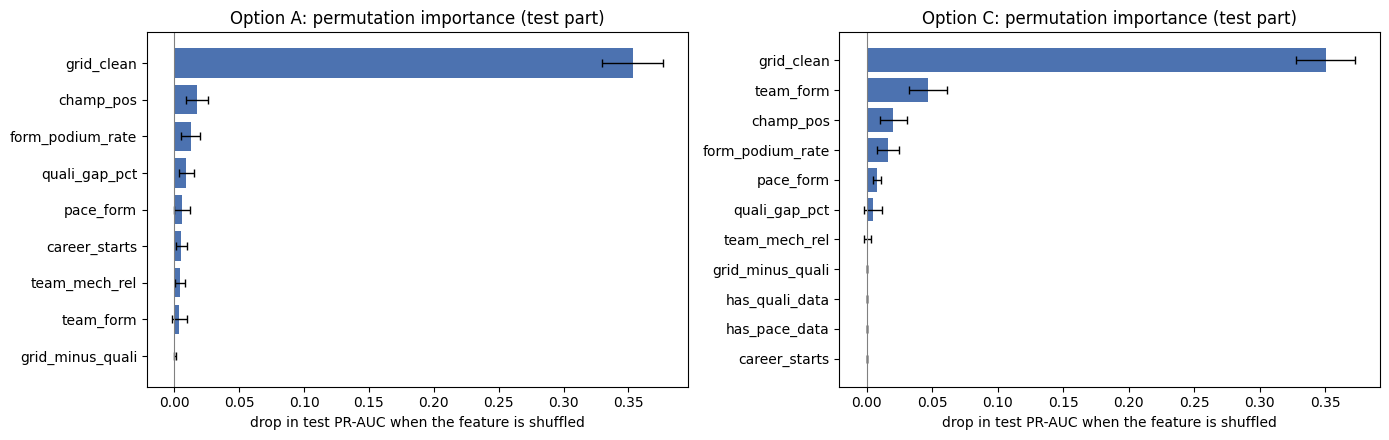

In [332]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, o in zip(axes, XAI):
    d = perm_table[f'{o}: PR-AUC drop'].dropna().sort_values()
    ax.barh(d.index, d, xerr=perm_table.loc[d.index, f'{o}: spread'], color='#4C72B0', error_kw={'lw': 1, 'capsize': 3})
    ax.axvline(0, color='grey', lw=0.8)
    ax.set(xlabel='drop in test PR-AUC when the feature is shuffled', title=f'Option {o}: permutation importance (test part)')
plt.tight_layout(); savefig('xai_01_permutation_importance'); plt.show()

**Reading.**
- **Both models rely on the grid slot far more than on anything else.** Shuffling `grid_clean` lowers the test PR-AUC by 0.353 in option A (from 0.717 to about 0.36) and by 0.350 in option C (from 0.704 to about 0.35).
- **After the grid, the two models lean on different features.**
  - **Option A** spreads its reliance over many features, each small: the championship position (0.017), driver form (0.013) and the qualifying gap (0.009), then pace, career starts, reliability and team form (0.004 to 0.006).
  - **Option C** relies on **team form** much more than anything else after the grid (0.047, against 0.004 in option A), then the championship position (0.020) and driver form (0.016).
- **Option C does not use some features at all.** For `career_starts`, `grid_minus_quali` and its two extra features the drop is exactly 0.000, with no spread: shuffling them changes no prediction, so its trees never split on them. SHAP confirms this (11.2).
- **`grid_minus_quali` changes nothing in option A either** (0.000): it is 0 for most drivers.
- **Why so small for features that are strong on their own** (10.7, experiment 2)? When one of them is shuffled, the model still has the others, which carry much of the same information (form, standings, team and pace overlap, 7.10). Permutation importance shows what a feature adds **on top of** the others; the next part shuffles them together.

### Shuffling a whole group at once

**Why.** Many features say much the same thing (7.10): past pace and the championship position overlap by 0.80, driver form and team form by 0.79. When only **one** of them is shuffled, the model still gets most of that information from the others, so each one looks unimportant on its own.

**How it works.** The same as above, but the columns of a whole **set of features are shuffled together**, with the same new order for all of them, so each driver gets another driver's whole set. The model is not trained again. The sets are:
- the 7 feature groups of the ablation (10.7). In option C, each extra feature is shuffled with its group (`has_quali_data` with qualifying, `has_pace_data` with pace), as in the ablation;
- driver form, the championship position, team form and pace together: the four groups that overlap the most (7.10);
- every feature except the grid: everything the model knows about the driver and the team besides the starting slot.

The last column adds up the single-feature drops of 11.1 for the same features. A set whose drop is much **larger** than that sum holds information that its features share with each other.

In [333]:
def shuffled_drop(o, cols, repeats=20, seed=0):
    """Average drop (and spread) in the test PR-AUC of option o's model when these columns are shuffled together."""
    rng = np.random.default_rng(seed)
    X = X_explain[o]
    base = average_precision_score(y_test_final, xai_prob[o])
    drops = []
    for _ in range(repeats):
        X_shuffled = X.copy()
        X_shuffled[cols] = X[cols].values[rng.permutation(len(X))]       # each driver gets another driver's values for the whole set
        drops.append(base - average_precision_score(y_test_final, xai_model[o].predict_proba(X_shuffled)[:, 1]))
    return np.mean(drops), np.std(drops)

overlapping = [FEATURES[f][0] for f in ['form_podium_rate', 'champ_pos', 'team_form', 'pace_form']]   # the four groups that overlap the most (7.10)
rows = []
for o in XAI:
    sets = dict(OPT_GROUPS[o])
    sets['driver form + standings + team form + pace'] = features_of(*overlapping, option=o)
    sets['every feature except the grid'] = features_without('grid', option=o)
    single_drop = perm_table[f'{o}: PR-AUC drop']
    for name, cols in sets.items():
        mean, std = shuffled_drop(o, cols)
        rows.append({'option': o, 'shuffled together': name, 'features': len(cols), 'PR-AUC drop (mean)': mean, 'spread (std)': std,
                     'sum of the single-feature drops (11.1)': single_drop[cols].sum()})
group_perm = pd.DataFrame(rows)
display(group_perm.style.format({'PR-AUC drop (mean)': '{:.3f}', 'spread (std)': '{:.3f}', 'sum of the single-feature drops (11.1)': '{:.3f}'})
        .hide(axis='index').set_caption('Permutation importance of groups of features (test part, 20 shuffles each)'))

option,shuffled together,features,PR-AUC drop (mean),spread (std),sum of the single-feature drops (11.1)
A,grid,1,0.366,0.020,0.353
A,qualifying,2,0.012,0.006,0.010
A,driver form,2,0.018,0.013,0.018
A,driver standings,1,0.019,0.011,0.017
A,team form,1,0.006,0.004,0.004
A,reliability,1,0.004,0.005,0.004
A,pace (candidate),1,0.006,0.006,0.006
A,driver form + standings + team form + pace,5,0.134,0.022,0.045
A,every feature except the grid,8,0.193,0.027,0.059
C,grid,1,0.360,0.019,0.350


**Chart.** The blue bar is the drop when the set is shuffled together, with its spread; the black dot is the sum of the single-feature drops of the same features.

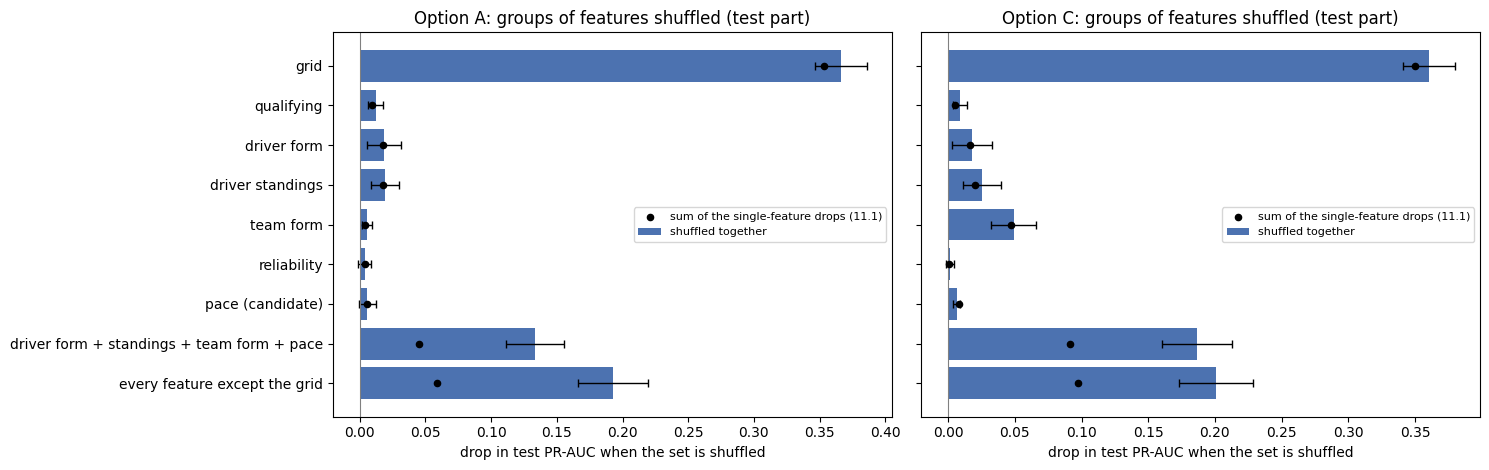

In [334]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, o in zip(axes, XAI):
    d = group_perm[group_perm.option == o].iloc[::-1]
    y = np.arange(len(d))
    ax.barh(y, d['PR-AUC drop (mean)'], xerr=d['spread (std)'], color='#4C72B0', error_kw={'lw': 1, 'capsize': 3}, label='shuffled together')
    ax.scatter(d['sum of the single-feature drops (11.1)'], y, color='black', zorder=3, s=20, label='sum of the single-feature drops (11.1)')
    ax.axvline(0, color='grey', lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels(d['shuffled together'])
    ax.set(xlabel='drop in test PR-AUC when the set is shuffled', title=f'Option {o}: groups of features shuffled (test part)')
    ax.legend(fontsize=8, loc='center right')
plt.tight_layout(); savefig('xai_08_group_permutation'); plt.show()

**Reading.**
- **Groups with one feature repeat 11.1**, as expected: the grid lowers the test PR-AUC by 0.366 in option A and 0.360 in option C. Team form is the only other single group above 0.02 (0.049, option C).
- **The groups with two or three features are about as strong as their features added up** (for example driver form 0.018 against 0.018 in option A, qualifying 0.009 against 0.005 in option C).
- **The overlapping groups are much stronger together.**
  - Shuffling driver form, the championship position, team form and pace at once lowers the PR-AUC by **0.134** in option A, **three times** the sum of their single drops (0.045), and by **0.187** in option C, **twice** the sum (0.091).
  - Every feature except the grid together lowers it by **0.193** (A) and **0.201** (C), against 0.059 and 0.097 for the sums.
- **What this means:** the history features are not unimportant. One at a time each looks almost useless, because the others carry the same information (7.10). Taken together they are the second source of information after the grid in both models: shuffling them costs about half as much as shuffling the grid (0.193 against 0.366 in A, 0.201 against 0.360 in C).
- **In option C the overlap is smaller**, because one feature, team form, carries most of this information on its own. Its other features add almost nothing: all of them except the grid (0.201) cost only a little more than the four overlapping groups (0.187).

## 11.2 SHAP: what pushes the predictions up or down

**How SHAP works.** For one driver in one race, SHAP splits the model's score into one part per feature:

> **score = starting score + contribution of `grid_clean` + contribution of `champ_pos` + … (one for each feature: 9 in option A, 11 in option C)**

- The **starting score** is the same for every driver: the model's average score.
- A **positive** contribution pushes the driver towards the podium, a **negative** one away from it. The bigger the number, the bigger the push.
- The **score** is the model's output before it is turned into a probability (log-odds, as in logistic regression, 10.2): probability = 1 ÷ (1 + e^(−score)). A score of 0 is a probability of 50%; a higher score is a higher probability.
- For tree models, SHAP's `TreeExplainer` computes the contributions exactly. The code checks that they add up to the model's score.

The **global** view is the average size of each feature's contributions over the 1,359 test rows.

In [335]:
shap_values = {}
for o in XAI:
    raw = shap.TreeExplainer(xai_model[o])(X_explain[o])
    shap_values[o] = shap.Explanation(raw.values, raw.base_values, data=X_explain_units[o].values, feature_names=xai_F[o])   # the plots show original units
    error = np.abs(shap_values[o].values.sum(axis=1) + shap_values[o].base_values - xai_model[o].decision_function(X_explain[o])).max()
    print(f'option {o}: SHAP values {shap_values[o].values.shape[0]} rows x {shap_values[o].values.shape[1]} features | '
          f'starting score {shap_values[o].base_values[0]:.2f} | check, starting score + contributions = the model score: '
          f'largest difference {error:.1e}')

shap_size = pd.DataFrame({f'option {o}': pd.Series(np.abs(shap_values[o].values).mean(axis=0), index=xai_F[o]) for o in XAI}).reindex(xai_F['C'])
shap_size = shap_size.sort_values('option A', ascending=False, na_position='last')

for f in FLAGS:                                                          # option C's extra features on the test part
    k = xai_F['C'].index(f)
    print(f"option C, {f}: value {sorted(X_explain_units['C'][f].unique().astype(int))} on the test part, "
          f"contribution {shap_values['C'].values[:, k].min():+.3f} to {shap_values['C'].values[:, k].max():+.3f}")

option A: SHAP values 1359 rows x 9 features | starting score -3.44 | check, starting score + contributions = the model score: largest difference 7.1e-15
option C: SHAP values 1359 rows x 11 features | starting score -2.76 | check, starting score + contributions = the model score: largest difference 3.6e-15
option C, has_quali_data: value [np.int64(1)] on the test part, contribution +0.000 to +0.000
option C, has_pace_data: value [np.int64(1)] on the test part, contribution +0.000 to +0.000


**Chart 1: the average size of each feature's contribution** (positive and negative pushes both count), for both models on the same rows.

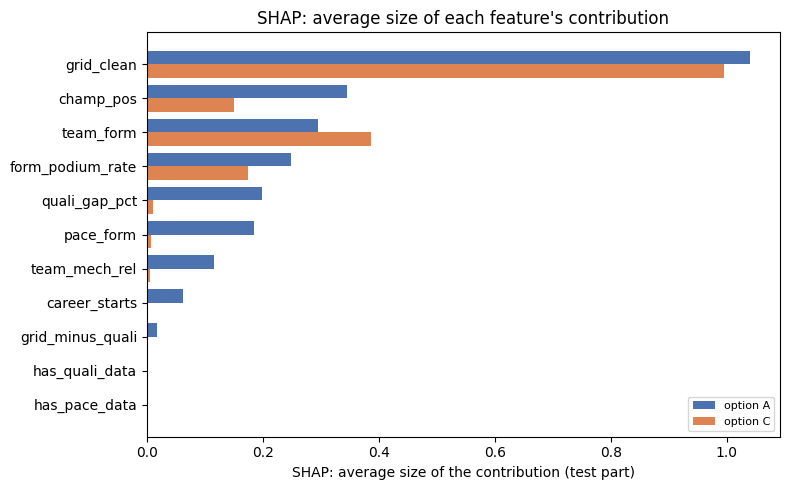

,option A,option C
feature,,
grid_clean,1.04,1.00
champ_pos,0.34,0.15
team_form,0.30,0.39
form_podium_rate,0.25,0.17
quali_gap_pct,0.20,0.01
pace_form,0.18,0.01
team_mech_rel,0.12,0.01
career_starts,0.06,0.00
grid_minus_quali,0.02,0.00


In [336]:
d = shap_size.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(y + 0.2, d['option A'].fillna(0), height=0.4, color='#4C72B0', label='option A')
ax.barh(y - 0.2, d['option C'], height=0.4, color='#DD8452', label='option C')
ax.set_yticks(y); ax.set_yticklabels(d.index)
ax.set(xlabel='SHAP: average size of the contribution (test part)', title="SHAP: average size of each feature's contribution")
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); savefig('xai_02_shap_bar'); plt.show()
display(shap_size.rename_axis('feature').style.format('{:.2f}', na_rep='–').set_caption('SHAP: average size of the contribution (test part)'))

**Chart 2: every test row.** Each dot is one driver in one race. Its position is the feature's contribution (right = towards the podium), and its colour is the feature's value (red = high, blue = low).

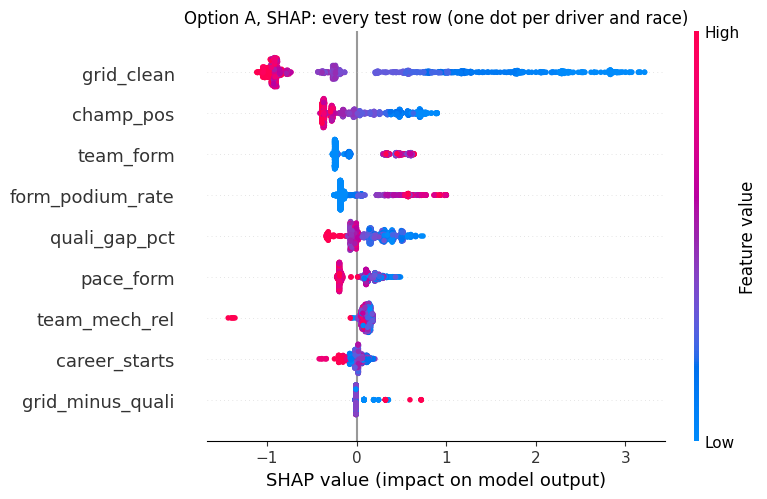

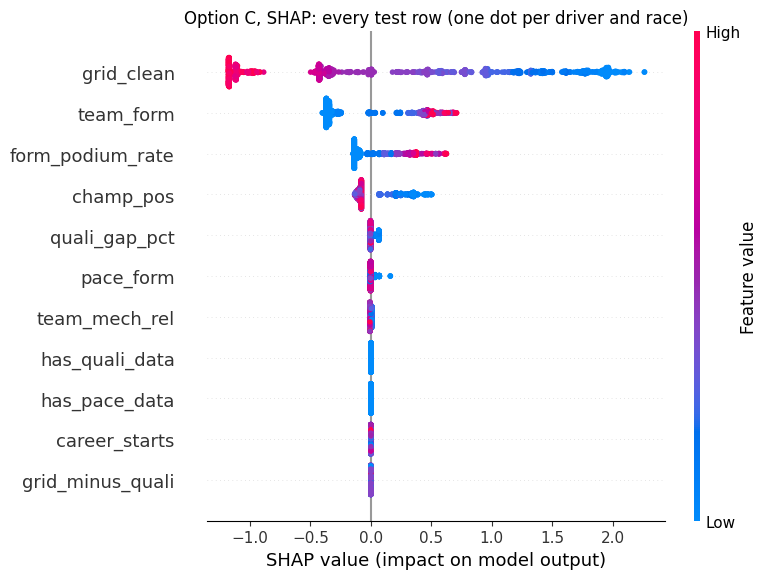

In [337]:
for o in XAI:
    shap.plots.beeswarm(shap_values[o], max_display=len(xai_F[o]), show=False)
    plt.title(f'Option {o}, SHAP: every test row (one dot per driver and race)')
    plt.tight_layout(); savefig(fig_name('xai_03_shap_beeswarm', o)); plt.show()

**Reading.**
- **`grid_clean` moves the score the most in both models** (average size 1.04 in option A, 1.00 in option C). After it, the two models are very different.
- **Option A uses all 9 features:** the championship position (0.34), team form (0.30), driver form (0.25), the qualifying gap (0.20) and pace (0.18), then reliability (0.12), career starts (0.06) and `grid_minus_quali` (0.02).
- **Option C uses only 4 of its 11 features:** the grid, team form (0.39), driver form (0.17) and the championship position (0.15). The qualifying gap, pace and reliability move the score by 0.01 at most, and career starts, `grid_minus_quali` and the two extra features by 0.00 (never used).
- **Why option C uses so few features.** Two reasons, both visible earlier in the notebook:
  - **Its model is small and stops early.** Its settings (10.3) are the smallest in the grid: 100 trees of depth 2 with a learning rate of 0.03 (option B has the same; option A has 300 trees). Each tree has at most three splits, and the loss chart of 10.3 shows that option C's validation loss is still falling at its 100th tree, so the model ends before it has learned from the weaker features.
  - **Its qualifying and pace values are mostly filled.** In its training part (1950–2018), 65% of the qualifying gaps and 61% of the pace values are filled (9.2), and filling lowers their AUC from 0.830 to 0.678 and from 0.852 to 0.680 (9.4). Team form, driver form and the championship position have a real value in almost every season and keep their AUC (0.839, 0.833 and 0.835), so they win the splits.
- **Option C's probabilities are also less extreme.** With few small trees, its scores stay closer to its starting score (−2.76, against −3.44 for option A), so it rarely gives very high or very low probabilities (for example 0.62 against 0.84 for the same pole-sitter, 11.4). The calibration check in 11.3 shows that this makes it under-confident.
- **The directions match section 7, in both models:**
  - a low grid slot (blue, near the front) pushes up, by up to about +3.2 in option A and +2.2 in option C;
  - a high championship position number (red, far down the standings) pushes down;
  - high team form and high driver form (red) push up;
  - in option A, a slow pace and a large gap in qualifying (red, high values) push down.
- **Smaller patterns in option A:**
  - **`grid_minus_quali`** is 0 for most drivers, so its contribution is about 0. The few drivers moved back by a penalty (red dots) get a push up of up to about +0.7, as found in 7.2.
  - **`team_mech_rel`:** a few red dots at about −1.4. They are teams that broke down far more often than the field, and the model pushes them down strongly.
  - **`career_starts`:** very long careers (red) push down, to about −0.5. Once form, standings and team are known, a driver with many starts who is not doing well at the moment is probably in a slower car (a likely reading, not checked here); it does not mean that experience slows a driver down.

**Chart 3: how the grid slot is used.** One dot per test row: the grid slot against its SHAP contribution, for each model.

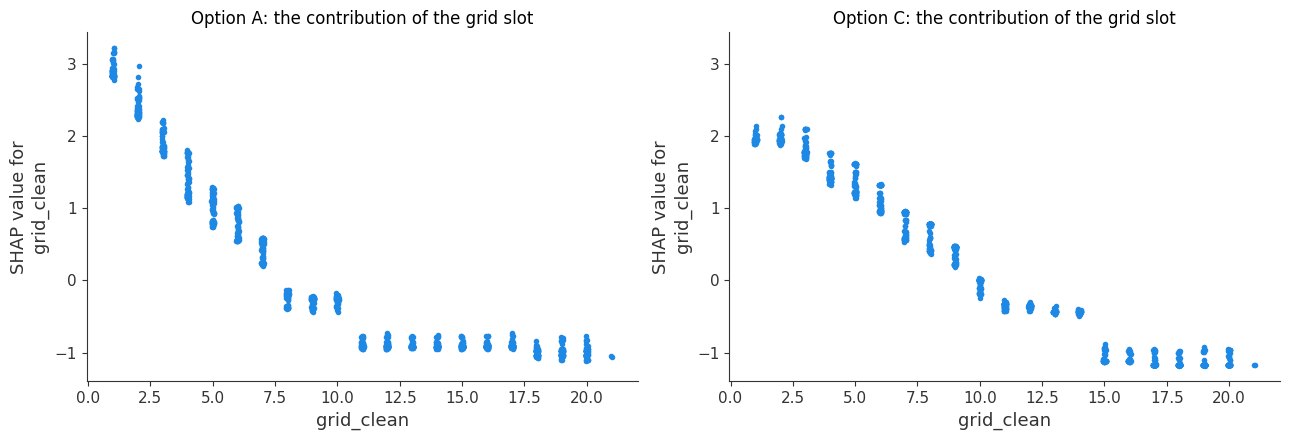

values,option A,option C,rows
P1,+2.90,+1.95,68
P2,+2.39,+1.97,68
P3,+1.90,+1.81,68
P4-5,+1.18,+1.41,136
P6-7,+0.59,+0.94,136
P8-9,-0.25,+0.53,135
P10-11,-0.58,-0.19,135
P12-15,-0.90,-0.58,271
P16+,-0.96,-1.14,342


In [338]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, o in zip(axes, XAI):
    shap.plots.scatter(shap_values[o][:, 'grid_clean'], ax=ax, hist=False, show=False)
    ax.set_title(f'Option {o}: the contribution of the grid slot')
plt.tight_layout(); savefig('xai_04_shap_grid'); plt.show()

grid_bins, grid_labels = [0, 1, 2, 3, 5, 7, 9, 11, 15, 30], ['P1', 'P2', 'P3', 'P4-5', 'P6-7', 'P8-9', 'P10-11', 'P12-15', 'P16+']
def shap_by_value(f, bins, labels):
    """Average SHAP contribution of feature f for groups of its values (original units), for both models."""
    out = {}
    for o in XAI:
        k = xai_F[o].index(f)
        g = pd.DataFrame({'values': pd.cut(X_explain_units[o][f], bins, labels=labels), 'c': shap_values[o].values[:, k]})
        out[f'option {o}'] = g.groupby('values', observed=True).c.mean()
    out['rows'] = g.groupby('values', observed=True).size()
    return pd.DataFrame(out).reset_index()

display(shap_by_value('grid_clean', grid_bins, grid_labels).style.format({f'option {o}': '{:+.2f}' for o in XAI})
        .hide(axis='index').set_caption('grid_clean: average contribution by grid slot'))

**Reading.**
- **Option A's effect is curved.** Pole position adds +2.90 on average and 2nd place +2.39. The push then falls by about 0.5 per place to P7 (+0.59 for P6–7), is below 0 from P8, and from P11 to the back it is flat at about −0.9: P12 and P20 are treated the same.
- **Option C's effect is a staircase.** Pole, 2nd and 3rd get almost the same push (+1.95, +1.97 and +1.81), so it hardly separates the front row. From P4 the push falls by about 0.4 per place to about 0 at P10, stays at about −0.4 from P11 to P14, and drops to about −1.1 from P15 to the back. Its few small trees (11.2) can only split the grid at a few places, which gives these steps.
- **The curved effect of option A is one that logistic regression cannot learn.** In logistic regression, moving from P2 to P1 counts the same as moving from P16 to P15 (10.2).
- **At each grid slot the dots are close together** in both models: the contribution of the grid depends almost only on the grid slot itself.

**Chart 4: how the championship position and driver form are used**, the next two features after the grid. As in chart 3, one dot per test row. The tables below give the average contribution for groups of values, so the shapes can be read as numbers.

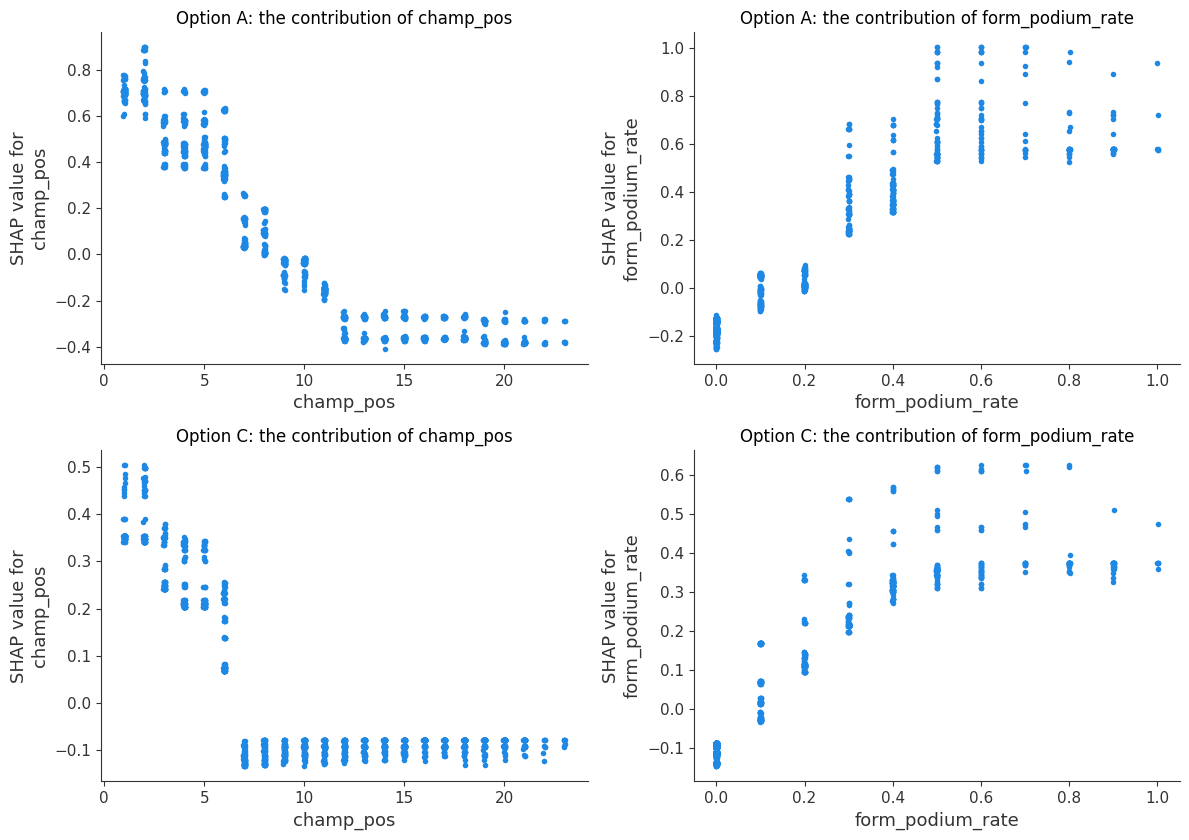

values,option A,option C,rows
1,+0.71,+0.37,68
2,+0.74,+0.39,68
3,+0.50,+0.28,67
4-6,+0.48,+0.21,204
7-10,+0.03,-0.10,271
11+,-0.32,-0.09,681


values,option A,option C,rows
0,-0.17,-0.12,822
up to 0.2,+0.01,+0.09,192
0.2-0.4,+0.39,+0.30,161
0.4-0.6,+0.69,+0.39,111
0.6-0.8,+0.67,+0.41,41
0.8-1,+0.62,+0.38,32


In [339]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
for row_axes, o in zip(axes, XAI):
    for ax, f in zip(row_axes, ['champ_pos', 'form_podium_rate']):
        shap.plots.scatter(shap_values[o][:, f], ax=ax, hist=False, show=False)   # no background histogram: it stretches the axis
        ax.set_title(f'Option {o}: the contribution of {f}')
plt.tight_layout(); savefig('xai_09_shap_champ_form'); plt.show()

for f, bins, labels in [('champ_pos', [0, 1, 2, 3, 6, 10, 100], ['1', '2', '3', '4-6', '7-10', '11+']),
                        ('form_podium_rate', [-0.01, 0, 0.2, 0.4, 0.6, 0.8, 1], ['0', 'up to 0.2', '0.2-0.4', '0.4-0.6', '0.6-0.8', '0.8-1'])]:
    display(shap_by_value(f, bins, labels).style.format({f'option {o}': '{:+.2f}' for o in XAI})
            .hide(axis='index').set_caption(f'{f}: average contribution by value'))

**Reading.**
- **The championship position works in steps, in both models.** Leading the championship and being 2nd give the same push (option A +0.71 and +0.74, option C +0.37 and +0.39): neither model separates the top two. 3rd to 6th give about +0.5 in option A and +0.2 to +0.3 in option C, 7th to 10th about 0, and from 11th on the push is negative in option A (−0.32) and about −0.1 in option C.
- **Driver form saturates.** No podium in the last 10 starts pushes down a little (−0.17 in A, −0.12 in C; the most common case: 822 of the 1,359 rows). One or two podiums are about neutral, and from about four on the push stops growing (option A about +0.65, option C about +0.4): five podiums in ten starts count as much as ten.
- **Option C's pushes are about half as large for both features**, because it puts more of the same information into team form (11.2).
- **Both shapes match section 7** (7.3 and 7.4): more podiums and a better championship position mean a higher chance, with the largest steps at the top.

**Chart 5: an interaction, the grid slot and team form.** Gradient boosting was chosen partly because it can learn **interactions** (10.3): the effect of one feature can depend on another. The clearest candidate is the grid and the car: is a front-row start worth more in a strong team? The chart repeats chart 3, with each dot coloured by the driver's team form (red = strong team, blue = weak team). If the grid's contribution at the same slot differs by colour, the model has learned an interaction. The table gives the average contribution of the grid for groups of grid slots and team form, with the number of rows in brackets.

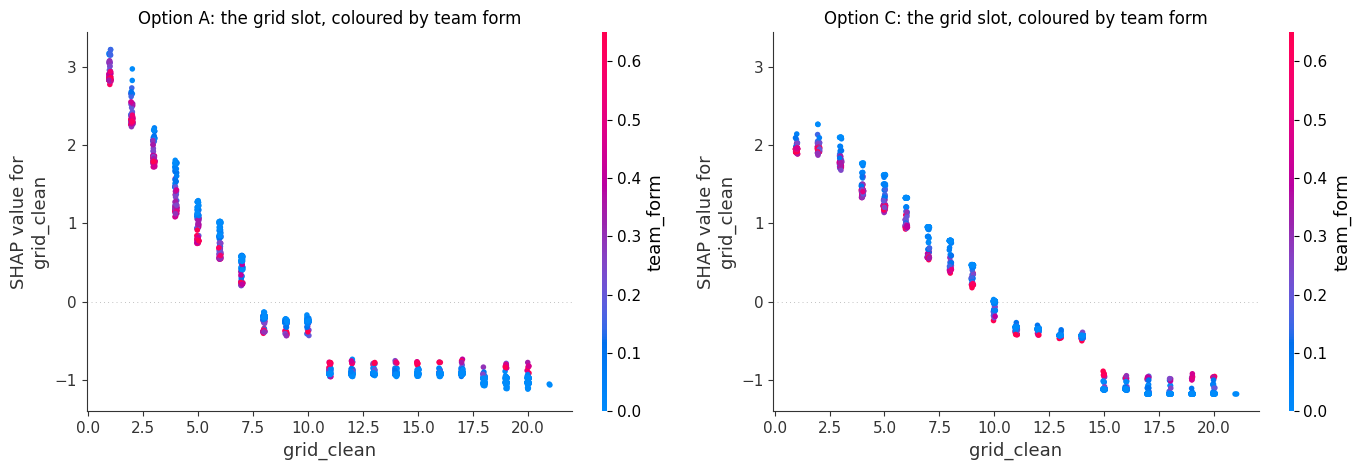

team form,weak team (up to 0.2),middle (0.2-0.5),strong team (above 0.5)
grid,,,
P1-3,+2.43 (44),+2.31 (91),+2.50 (69)
P4-6,+1.16 (90),+0.95 (87),+0.90 (27)
P7-10,-0.07 (211),-0.08 (45),-0.28 (14)
P11+,-0.94 (618),-0.84 (37),-0.80 (26)


team form,weak team (up to 0.2),middle (0.2-0.5),strong team (above 0.5)
grid,,,
P1-3,+1.97 (44),+1.88 (91),+1.91 (69)
P4-6,+1.40 (90),+1.23 (87),+1.22 (27)
P7-10,+0.48 (211),+0.39 (45),+0.29 (14)
P11+,-0.85 (618),-0.73 (37),-0.65 (26)


In [340]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, o in zip(axes, XAI):
    shap.plots.scatter(shap_values[o][:, 'grid_clean'], color=shap_values[o][:, 'team_form'], ax=ax, hist=False, show=False)
    ax.set_title(f'Option {o}: the grid slot, coloured by team form')
plt.tight_layout(); savefig('xai_13_grid_team_interaction'); plt.show()

grid_groups = ([0, 3, 6, 10, 30], ['P1-3', 'P4-6', 'P7-10', 'P11+'])
team_groups = ([-0.01, 0.2, 0.5, 1], ['weak team (up to 0.2)', 'middle (0.2-0.5)', 'strong team (above 0.5)'])
for o in XAI:
    u, k = X_explain_units[o], xai_F[o].index('grid_clean')
    d = pd.DataFrame({'grid': pd.cut(u.grid_clean, grid_groups[0], labels=grid_groups[1]), 'team form': pd.cut(u.team_form, team_groups[0], labels=team_groups[1]),
                      'contribution': shap_values[o].values[:, k]})
    t = d.groupby(['grid', 'team form'], observed=True).contribution.agg(['mean', 'size'])
    t = t.apply(lambda r: f"{r['mean']:+.2f} ({int(r['size'])})", axis=1).unstack('team form')
    display(t.style.set_caption(f"Option {o}: average contribution of grid_clean, by grid slot and team form (rows)"))

**Reading.**
- **Both models learned a small interaction, and the grid matters a little less for a strong team.** At the same grid slot from P1 to about P7, the drivers of weak teams (blue) get a larger push from the grid than those of strong teams (red), by up to about 0.5 in option A (at P5, about +1.3 against +0.8) and up to about 0.3 in option C. Behind P11 the order flips: a strong team loses a little less from a bad slot (about 0.1–0.2).
- **What it means.** A strong team already gets a large push from team form (and, in option A, from the championship position), so the model needs less from the grid to reach a high probability. For a weak team, a front slot is almost the only sign of a podium. And a strong car starting far back is not counted as completely out of contention. The two pieces of information overlap, so together they add up to a little less than their sum.
- **It is small next to the grid itself.** The grid's push spans about 4 points from pole to the back, and the interaction moves it by 0.5 at most. Both models are close to additive: the effect of the grid plus the effect of each history feature.
- **The table mixes slots, so it shows the pattern less clearly.** In P1–3, the strong teams sit mostly on pole, where the push is largest, so their average (+2.50 in option A) is not below that of the weak teams (+2.43). From P4 on, strong teams get less in both models (P4–6: +0.90 against +1.16 in A, +1.22 against +1.40 in C), and behind P11 they lose less (−0.80 against −0.94 in A, −0.65 against −0.85 in C).
- **So the advantage of the trees over logistic regression comes mainly from curved effects** (the shape of the grid's push, chart 3), and only a little from interactions.

## 11.3 Do the explanations agree?

The three measures answer slightly different questions. The ablation (10.7) removed whole groups, so the comparison is made **per group**, for each model:

| Measure | Question | Rows |
|---|---|---|
| Permutation importance, group shuffled (11.1) | How much worse is the **trained** model when the group is scrambled? | test |
| SHAP, group (11.2) | How much does the group move the model's score, on average? (the contributions of its features added up for each row, then the average size) | test |
| Ablation, experiment 1 (10.7) | How much is lost when the model is **trained again** without the group? | validation |

In [341]:
rows = []
for o in XAI:
    sv = pd.DataFrame(shap_values[o].values, columns=xai_F[o])
    removed = leave_one[leave_one.option == o].set_index('group removed')
    shuffled = group_perm[group_perm.option == o].set_index('shuffled together')
    for g, cols in OPT_GROUPS[o].items():
        rows.append({'option': o, 'group': g, 'features': len(cols),
                     'permutation: PR-AUC drop': shuffled.loc[g, 'PR-AUC drop (mean)'],
                     'SHAP: average size': sv[cols].sum(axis=1).abs().mean(),          # SHAP values add up, so a group's contribution is their sum
                     'ablation: change when removed': removed.loc[g, 'change'], 'ablation: clear?': removed.loc[g, 'clear change?']})
agree = pd.DataFrame(rows)
by = agree.groupby('option')
agree['rank (permutation)'] = by['permutation: PR-AUC drop'].rank(ascending=False).astype(int)
agree['rank (SHAP)'] = by['SHAP: average size'].rank(ascending=False).astype(int)
agree['rank (ablation)'] = by['ablation: change when removed'].rank().astype(int)      # the biggest loss is rank 1
display(agree.sort_values(['option', 'rank (SHAP)']).style
        .format({'permutation: PR-AUC drop': '{:.3f}', 'SHAP: average size': '{:.2f}', 'ablation: change when removed': '{:+.3f}'})
        .hide(axis='index').set_caption('Three ways to measure the importance of each group'))
for o in XAI:
    a = agree[agree.option == o]
    print(f'option {o}, rank agreement (Spearman): permutation-SHAP {a["rank (permutation)"].corr(a["rank (SHAP)"], method="spearman"):.2f} | '
          f'permutation-ablation {a["rank (permutation)"].corr(a["rank (ablation)"], method="spearman"):.2f} | '
          f'SHAP-ablation {a["rank (SHAP)"].corr(a["rank (ablation)"], method="spearman"):.2f}')

option,group,features,permutation: PR-AUC drop,SHAP: average size,ablation: change when removed,ablation: clear?,rank (permutation),rank (SHAP),rank (ablation)
A,grid,1,0.366,1.04,-0.074,"yes, worse",1,1,1
A,driver standings,1,0.019,0.34,-0.010,no,2,2,3
A,team form,1,0.006,0.30,+0.000,no,6,3,6
A,driver form,2,0.018,0.25,+0.009,no,3,4,7
A,qualifying,2,0.012,0.20,-0.008,no,4,5,4
A,pace (candidate),1,0.006,0.18,-0.011,no,5,6,2
A,reliability,1,0.004,0.12,-0.006,no,7,7,5
C,grid,1,0.360,1.00,-0.059,"yes, worse",1,1,1
C,team form,1,0.049,0.39,+0.007,no,2,2,7
C,driver form,2,0.018,0.17,-0.001,no,4,3,6


option A, rank agreement (Spearman): permutation-SHAP 0.79 | permutation-ablation 0.46 | SHAP-ablation 0.29
option C, rank agreement (Spearman): permutation-SHAP 0.96 | permutation-ablation 0.18 | SHAP-ablation 0.07


**Reading.**
- **They agree on the top, in both models:** the grid is first in all three measures. Removing it is also the largest loss in the ablation (−0.074 in option A, −0.059 in option C), and the only clear one.
- **Permutation importance and SHAP agree closely** (Spearman 0.79 in A, 0.96 in C). Both are measured on the same trained model and the same test rows. In option A the championship position is 2nd in both; in option C team form is 2nd in both.
- **The ablation agrees with them much less** (Spearman 0.07 to 0.46). Apart from the grid, its changes are small (between −0.011 and +0.009) and none is clear (10.7), because they come from training a new model and scoring it on 60 validation races. So its order of the middle groups is mostly chance.
- **The clearest example is team form in option C:** 2nd in permutation importance and SHAP, but last in the ablation (+0.007, the model trained without it is not worse). A model trained again without team form gets the same information from driver form and the championship position, which overlap with it (0.79, 7.10). The trained model with all features happens to use team form for it.
- **Driver form in option A** is similar: 3rd and 4th in the other two, but the model trained without it scores slightly higher (+0.009, not clear).
- **Why the measures differ:** these are the overlapping features (7.10), and each measure treats overlap differently. SHAP shares the credit between features that say the same thing, permutation importance keeps the other features in place, and the ablation lets the model train again and use the others instead.
- **In short:** both models are mostly grid models, corrected by the history of the driver and the team. Option A spreads the correction over all its features, with the championship position first. Option C puts most of it into team form.

### Do the importances hold in each test season?

The SHAP average size of 11.2, computed separately for 2022, 2023 and 2024, for each model. If the order of the features stays the same, the explanation does not depend on one season.

In [342]:
season_shap = {}
for o in XAI:
    season_shap[o] = (pd.DataFrame(np.abs(shap_values[o].values), columns=xai_F[o]).assign(season=test_rows.year.values)
                      .groupby('season').mean().T)
    season_rank = season_shap[o].rank(ascending=False).astype(int)
    season_table = season_shap[o].join(season_rank.add_prefix('rank ')).sort_values(season_shap[o].columns[0], ascending=False)
    display(season_table.style.format({y: '{:.2f}' for y in season_shap[o].columns}).set_caption(f'Option {o}: SHAP average size in each test season'))
    print(f'option {o}, rank agreement between seasons (Spearman):',
          ' | '.join(f'{a}-{b}: {season_shap[o][a].corr(season_shap[o][b], method="spearman"):.2f}'
                     for a, b in itertools.combinations(season_shap[o].columns, 2)))

season,2022,2023,2024,rank 2022,rank 2023,rank 2024
grid_clean,1.04,1.05,1.03,1,1,1
champ_pos,0.36,0.34,0.33,2,2,2
team_form,0.29,0.29,0.30,3,3,3
form_podium_rate,0.26,0.24,0.24,4,4,4
pace_form,0.18,0.19,0.18,5,6,6
quali_gap_pct,0.15,0.21,0.24,6,5,5
team_mech_rel,0.12,0.11,0.11,7,7,7
career_starts,0.06,0.06,0.06,8,8,8
grid_minus_quali,0.03,0.01,0.01,9,9,9


option A, rank agreement between seasons (Spearman): 2022-2023: 0.98 | 2022-2024: 0.98 | 2023-2024: 1.00


season,2022,2023,2024,rank 2022,rank 2023,rank 2024
grid_clean,1.01,0.99,0.99,1,1,1
team_form,0.39,0.38,0.39,2,2,2
form_podium_rate,0.18,0.17,0.18,3,3,3
champ_pos,0.15,0.15,0.15,4,4,4
quali_gap_pct,0.01,0.01,0.01,5,5,5
pace_form,0.01,0.01,0.00,6,7,7
team_mech_rel,0.01,0.01,0.01,7,6,6
grid_minus_quali,0.00,0.00,0.00,9,9,9
career_starts,0.00,0.00,0.00,9,9,9
has_quali_data,0.00,0.00,0.00,9,9,9


option C, rank agreement between seasons (Spearman): 2022-2023: 0.99 | 2022-2024: 0.99 | 2023-2024: 1.00


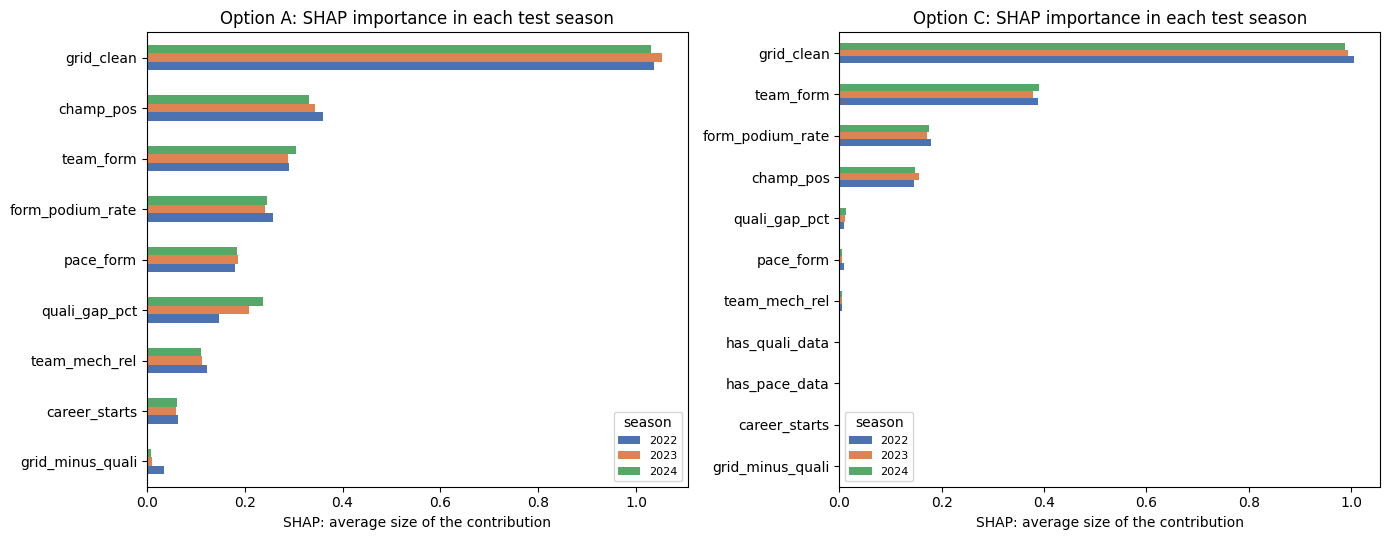

In [343]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, o in zip(axes, XAI):
    d = season_shap[o].sort_values(season_shap[o].columns[0]).iloc[:, :3]
    d.plot.barh(ax=ax, color=['#4C72B0', '#DD8452', '#55A868'])
    ax.set(xlabel='SHAP: average size of the contribution', title=f'Option {o}: SHAP importance in each test season')
    ax.legend(title='season', fontsize=8)
plt.tight_layout(); savefig('xai_12_shap_by_season'); plt.show()

**Reading.**
- **The order of the features is almost the same in every season, in both models** (Spearman 0.98 to 1.00 in option A, 0.99 to 1.00 in option C).
- **The sizes barely change:** the grid stays at 1.03–1.05 in option A and 0.99–1.01 in option C, the second feature at 0.33–0.36 (championship position, A) and 0.38–0.39 (team form, C).
- **The largest change is the qualifying gap in option A**, which grows from 0.15 in 2022 to 0.24 in 2024 and swaps 5th and 6th place with pace. In option C, the top four keep the same order in every season.
- **The explanations of 11.2 are not driven by one season**, such as Red Bull's dominant 2023.

### The baseline: what does logistic regression rely on?

On the test part, logistic regression scores as well as gradient boosting (0.716 against 0.717 in option A, 0.715 against 0.704 in option C, 10.9), so it is worth checking whether the baseline relies on the same features. For a straight-line model, the contribution of a feature to the score is simply its weight times its scaled value (the training average of every scaled feature is 0), in the same log-odds units as SHAP. So the average size of the contributions can be compared directly with the SHAP sizes of gradient boosting (11.2), on the same test rows.

In [344]:
rows = []
for o in XAI:
    w = pd.Series(opt_lr[o].coef_[0], index=xai_F[o])
    lr_size = (X_explain[o] * w).abs().mean()                         # weight x scaled value, the exact contribution of a linear model
    gb_size = pd.Series(np.abs(shap_values[o].values).mean(axis=0), index=xai_F[o])
    rows.append(pd.DataFrame({'option': o, 'feature': xai_F[o], 'logistic regression: weight': w.values,
                              'logistic regression: average size': lr_size.values, 'gradient boosting: average size (SHAP)': gb_size.values,
                              'rank (logistic regression)': lr_size.rank(ascending=False, method='min').astype(int).values,
                              'rank (gradient boosting)': gb_size.rank(ascending=False, method='min').astype(int).values}))
    print(f'option {o}: rank agreement (Spearman) {lr_size.corr(gb_size, method="spearman"):.2f} | test PR-AUC: logistic regression '
          f'{average_precision_score(y_test_final, test_prob[(o, "logistic regression")]):.3f}, gradient boosting {average_precision_score(y_test_final, xai_prob[o]):.3f}')
lr_vs_gb = pd.concat(rows)
display(lr_vs_gb.sort_values(['option', 'rank (gradient boosting)']).style
        .format({'logistic regression: weight': '{:+.2f}', 'logistic regression: average size': '{:.2f}', 'gradient boosting: average size (SHAP)': '{:.2f}'})
        .hide(axis='index').set_caption('Average size of each feature\'s contribution: logistic regression and gradient boosting (test part)'))

option A: rank agreement (Spearman) 0.70 | test PR-AUC: logistic regression 0.716, gradient boosting 0.717
option C: rank agreement (Spearman) 0.59 | test PR-AUC: logistic regression 0.715, gradient boosting 0.704


option,feature,logistic regression: weight,logistic regression: average size,gradient boosting: average size (SHAP),rank (logistic regression),rank (gradient boosting)
A,grid_clean,-1.81,1.45,1.04,1,1
A,champ_pos,-0.61,0.48,0.34,2,2
A,team_form,+0.14,0.12,0.30,5,3
A,form_podium_rate,+0.32,0.26,0.25,3,4
A,quali_gap_pct,-0.06,0.03,0.20,7,5
A,pace_form,-0.12,0.05,0.18,6,6
A,team_mech_rel,+0.05,0.02,0.12,8,7
A,career_starts,+0.00,0.00,0.06,9,8
A,grid_minus_quali,+0.26,0.13,0.02,4,9
C,grid_clean,-1.64,1.22,1.00,1,1


**Reading.**
- **Both models put the grid first, and in option A the championship position second.** Logistic regression relies on them even more: an average size of 1.45 and 0.48 in option A, against 1.04 and 0.34 for gradient boosting.
- **Option A: the two models agree fairly well** (Spearman 0.70). Logistic regression uses `grid_minus_quali` much more (0.13, 4th, against 0.02, last), because a straight line gives every driver moved back by a penalty the same push. Gradient boosting uses team form, the qualifying gap, pace and reliability more (0.12–0.30 against 0.02–0.12), in the curved ways a straight line cannot follow.
- **Option C: they agree less** (Spearman 0.59). Logistic regression still uses the qualifying gap and pace (0.14 each), which gradient boosting ignores (11.2), because a straight-line model cannot ignore a filled value. It also gives `has_pace_data` the second largest contribution (0.25): on the test part every row has real pace data, so this is the same shift for every driver and changes no ranking.
- **Different routes, the same result.** Both models reach about the same test PR-AUC (option A 0.716 against 0.717, option C 0.715 against 0.704) while leaning on the features in different amounts. The history features overlap so much (7.10) that several combinations of them work equally well, as the ablation also showed (10.7). This is another reason why an important feature is a description of the model, not of Formula 1 (11.7).

### Can the probabilities be read as chances?

The explanations above, and the local ones below, read a probability such as 0.84 as "about 84 of 100 such drivers reach the podium". That is only true if the model is **calibrated**. The test rows are grouped by their predicted probability, and in each group the average prediction is compared with the share of drivers who really reached the podium, with its 95% range (Wilson, as in section 5). On a calibrated model the points lie on the diagonal. The prints also compare the expected number of podiums (the sum of the probabilities) with the real 204, and give the Brier score (the average squared error of the probabilities; lower is better) and the sum of the probabilities per race, which should be 3.

option A: expected podiums 205 (real 204) | Brier score 0.0690 | sum of the probabilities per race: mean 3.02, from 2.57 to 3.41
option C: expected podiums 205 (real 204) | Brier score 0.0737 | sum of the probabilities per race: mean 3.02, from 2.67 to 3.30


option,predicted probability,rows,average prediction,actual podium rate,95% range
A,"(-0.001, 0.05]",811,1%,0%,0% to 1%
A,"(0.05, 0.1]",77,7%,4%,1% to 11%
A,"(0.1, 0.2]",114,15%,16%,10% to 24%
A,"(0.2, 0.3]",91,24%,26%,18% to 36%
A,"(0.3, 0.4]",68,34%,38%,28% to 50%
A,"(0.4, 0.5]",42,44%,45%,31% to 60%
A,"(0.5, 0.6]",39,55%,56%,41% to 71%
A,"(0.6, 0.7]",45,65%,69%,54% to 80%
A,"(0.7, 0.8]",34,75%,82%,66% to 92%
A,"(0.8, 1.0]",38,84%,82%,67% to 91%


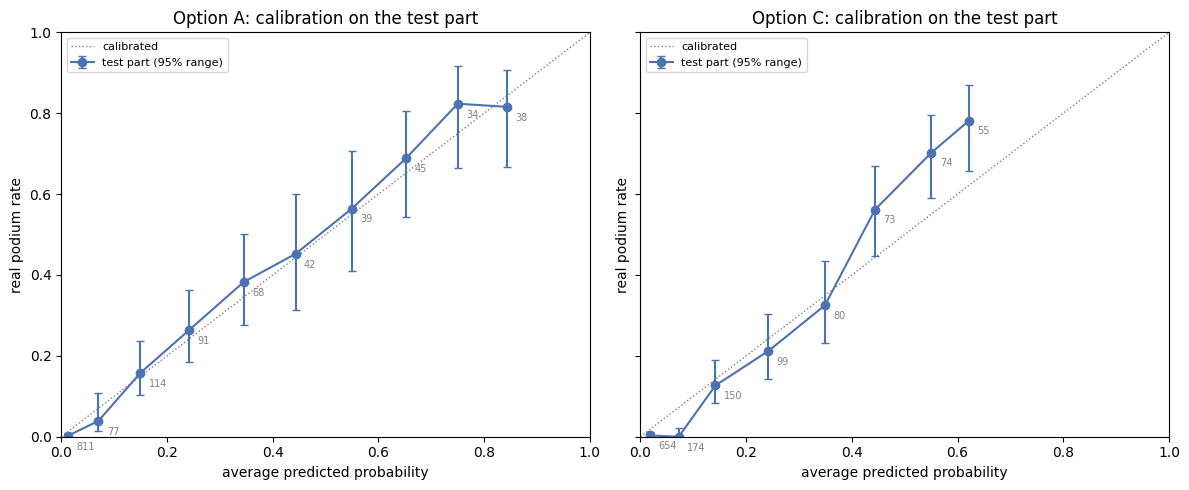

In [345]:
from sklearn.metrics import brier_score_loss

edges = [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
calib, y = [], y_test_final.values
for o in XAI:
    p = xai_prob[o]
    g = (pd.DataFrame({'predicted probability': pd.cut(p, edges, include_lowest=True), 'p': p, 'y': y})
         .groupby('predicted probability', observed=True).agg(rows=('y', 'size'), average_prediction=('p', 'mean'), podiums=('y', 'sum')))
    g['actual podium rate'] = g.podiums / g.rows
    g['lo'], g['hi'] = wilson(g.podiums, g.rows)
    calib.append(g.reset_index().assign(option=o))
    race_sum = pd.Series(p, index=test_rows.index).groupby(test_rows.raceId).sum()
    print(f'option {o}: expected podiums {p.sum():.0f} (real {int(y.sum())}) | Brier score {brier_score_loss(y, p):.4f} | '
          f'sum of the probabilities per race: mean {race_sum.mean():.2f}, from {race_sum.min():.2f} to {race_sum.max():.2f}')
calib = pd.concat(calib)
display(calib.assign(**{'95% range': [f'{a:.0%} to {b:.0%}' for a, b in zip(calib.lo, calib.hi)]})
        [['option', 'predicted probability', 'rows', 'average_prediction', 'actual podium rate', '95% range']]
        .rename(columns={'average_prediction': 'average prediction'})
        .style.format({'average prediction': '{:.0%}', 'actual podium rate': '{:.0%}'}).hide(axis='index')
        .set_caption('Test part: predicted probability against the real podium rate'))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, o in zip(axes, XAI):
    d = calib[calib.option == o]
    ax.plot([0, 1], [0, 1], color='grey', ls=':', lw=1, label='calibrated')
    ax.errorbar(d.average_prediction, d['actual podium rate'], yerr=[d['actual podium rate'] - d.lo, d.hi - d['actual podium rate']],
                fmt='o-', color='#4C72B0', capsize=3, label='test part (95% range)')
    for x, yy, n in zip(d.average_prediction, d['actual podium rate'], d.rows):
        ax.annotate(str(n), (x, yy), textcoords='offset points', xytext=(6, -10), fontsize=7, color='grey')
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='average predicted probability', ylabel='real podium rate', title=f'Option {o}: calibration on the test part')
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); savefig('xai_14_calibration'); plt.show()

**Reading.**
- **Option A's probabilities can be read as chances.** In every group, the real podium rate is within the 95% range of the average prediction: for example 15% predicted against 16% real, 44% against 45%, and 84% against 82% for its most confident predictions. Over the test part it expects 205 podiums, against 204 real.
- **Option C is under-confident at the top.** From about 0.4 up, its drivers reach the podium more often than it predicts: 44% predicted against 56% real, 55% against 70%, and 62% against 78%, all outside the 95% range. At the bottom it is a little over-confident (7% predicted, none of 174 drivers on the podium). Its highest predictions are only about 0.63, so it never says "very likely".
- **This confirms 11.2.** With few small trees, option C's scores stay close to the average, so its probabilities are squeezed towards the middle. Its ranking is still good (test PR-AUC 0.704), because the order of the drivers is right; only the size of its probabilities is too cautious. Its Brier score is also worse (0.0737 against 0.0690).
- **The probabilities of a race add up to about 3 on average in both models** (3.02), although nothing forces it; single races range from about 2.6 to 3.4.
- **For reading the local explanations below:** a probability of 0.84 from option A means that about 4 in 5 such drivers reach the podium; a probability of about 0.6 from option C means closer to 4 in 5 than 3 in 5.

## 11.4 One prediction explained with SHAP

**Which predictions.** For each model, two test rows chosen by a rule rather than by hand: the **pole-sitter** the model was **least** sure about, and the driver starting from **P5 or further back** it was **most** sure about. The table also gives the other model's probability for the same driver, so the two models can be compared on the same rows.

In [346]:
units = {o: X_explain_units[o].assign(probability=xai_prob[o], podium=y_test_final.values, raceId=test_rows.raceId.values,
                                      driverId=test_rows.driverId.values, year=test_rows.year.values) for o in XAI}
pole = {o: units[o][units[o].grid_clean == 1].probability.idxmin() for o in XAI}          # the pole-sitter the model was least sure about
from_back = {o: units[o][units[o].grid_clean >= 5].probability.idxmax() for o in XAI}     # the driver from P5 or further back it was most sure about

surname, race_name_of = drivers.set_index('driverId').surname, races.set_index('raceId').name
def describe_row(i):
    """'Driver, race year' for a test row."""
    r = units['A'].loc[i]
    return f'{surname[r.driverId]}, {race_name_of[r.raceId]} {int(r.year)}'

rows = []
for o in XAI:
    for rule, i in [('pole, least sure', pole[o]), ('P5 or further back, most sure', from_back[o])]:
        rows.append({'chosen by': f'option {o}', 'rule': rule, 'driver and race': describe_row(i), 'grid': int(units[o].loc[i, 'grid_clean']),
                     'probability, option A': units['A'].loc[i, 'probability'], 'probability, option C': units['C'].loc[i, 'probability'],
                     'podium': int(units[o].loc[i, 'podium'])})
display(pd.DataFrame(rows).style.format({'probability, option A': '{:.2f}', 'probability, option C': '{:.2f}'})
        .hide(axis='index').set_caption('Test predictions to explain'))

chosen by,rule,driver and race,grid,"probability, option A","probability, option C",podium
option A,"pole, least sure","Russell, Canadian Grand Prix 2024",1,0.45,0.25,1
option A,"P5 or further back, most sure","Verstappen, United States Grand Prix 2023",6,0.50,0.37,1
option C,"pole, least sure","Russell, Canadian Grand Prix 2024",1,0.45,0.25,1
option C,"P5 or further back, most sure","Leclerc, Spanish Grand Prix 2024",5,0.41,0.42,0


**How to read a waterfall.** It starts at the bottom from the starting score, E[f(X)], which is the same for every driver. Each bar adds the contribution of one feature (red = towards the podium, blue = away), with the driver's value of that feature on the left. The top, f(x), is the driver's score, which gives the probability in the title.

**The pole-sitter**, for each model.

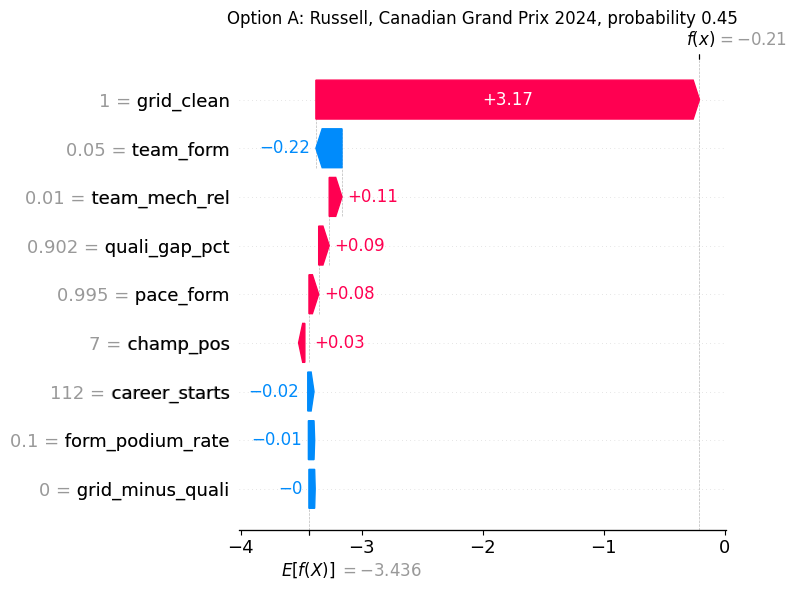

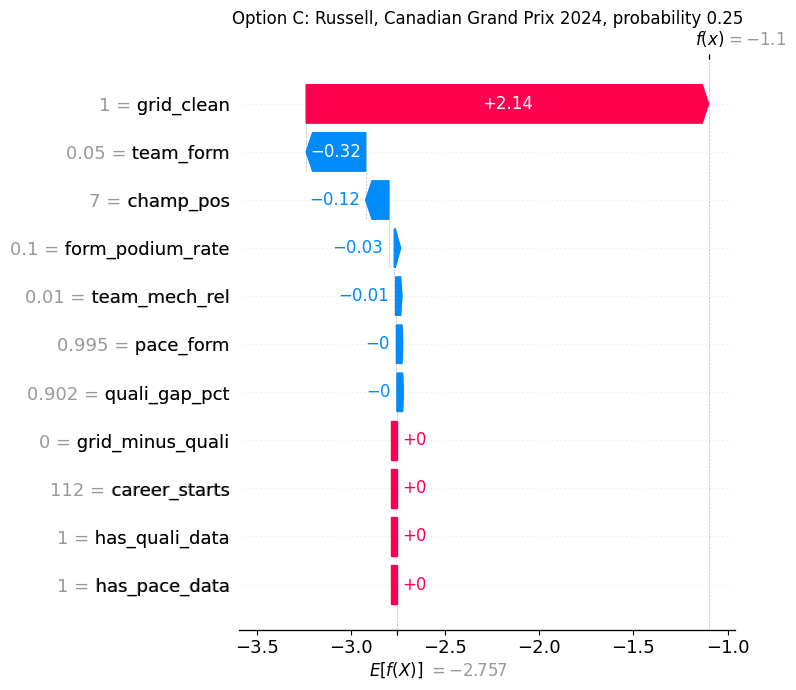

In [347]:
def waterfall(o, i, name, note=''):
    """SHAP waterfall of option o's model for test row i."""
    shap.plots.waterfall(shap_values[o][X_explain[o].index.get_loc(i)], max_display=len(xai_F[o]), show=False)
    plt.title(f'Option {o}: {describe_row(i)}, probability {units[o].loc[i, "probability"]:.2f}{note}', pad=25)
    plt.tight_layout(); savefig(fig_name(name, o)); plt.show()

for o in XAI:
    waterfall(o, pole[o], 'xai_05_waterfall_pole')

**The driver from further back**, for each model.

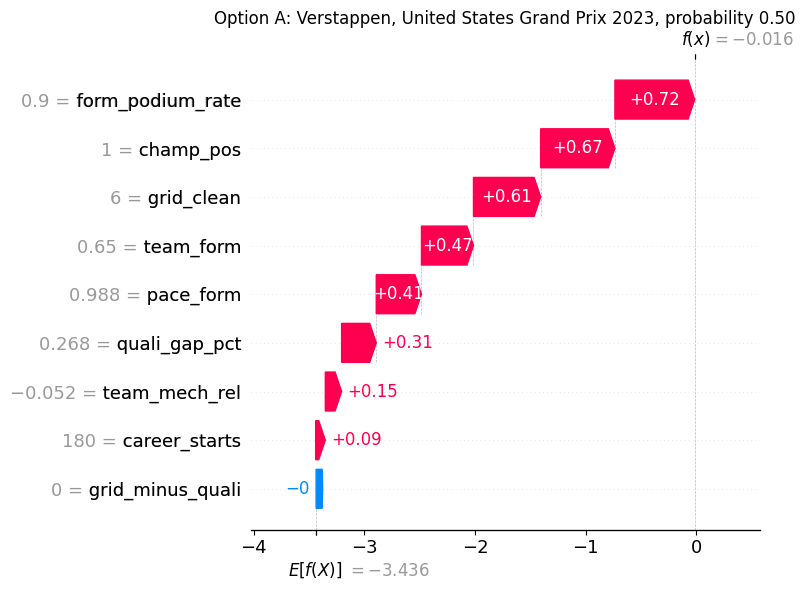

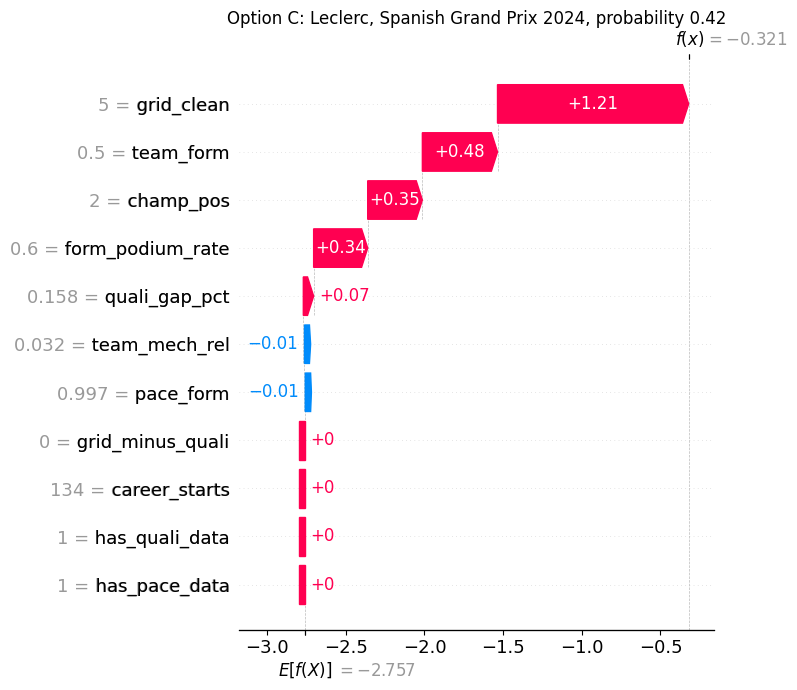

In [348]:
for o in XAI:
    waterfall(o, from_back[o], 'xai_06_waterfall_from_back')

**Reading.**
- **Both models pick the same pole-sitter: Russell, Canada 2024**, who reached the podium. Option A gives him 0.45, option C only 0.25.
  - **Option A:** almost everything comes from the grid (+3.17). The other features together add only +0.06; the largest is his team's weak recent results (team form 0.05, −0.22).
  - **Option C:** the grid adds less (+2.14), and the weak team form costs more (−0.32), together with his 7th place in the championship (−0.12). This is why option C is much less sure about him.
- **Option A's driver from further back: Verstappen, United States 2023, from 6th** (option A 0.50, option C 0.37). He reached the podium.
  - The grid slot is only the 3rd largest push (+0.61). More comes from his form, 9 podiums in his last 10 starts (+0.72), and from leading the championship (+0.67).
  - Every other feature also pushes up: team form (+0.47), pace (+0.41), the qualifying gap (+0.31), reliability (+0.15) and career starts (+0.09). Option A's probability comes from the whole history of the driver and the team.
- **Option C's driver from further back: Leclerc, Spain 2024, from 5th** (option C 0.42, option A 0.41). He did **not** reach the podium.
  - The grid gives the largest push (+1.21), then team form (+0.48), his 2nd place in the championship (+0.35) and his form (+0.34). The qualifying gap adds +0.07, and every other feature 0.01 or less: the four features of 11.2 make the whole prediction.
  - A probability of 0.42 is less than even, so missing the podium is the more likely outcome; both models agree on it.
- **What the global charts mean for one driver:** a pole-sitter's probability comes mostly from the grid, a driver from further back gets it from everything except the grid. Option A uses all its features for this, option C only four.

### A confident prediction that was wrong

Apart from Leclerc, the drivers above reached the podium. Here is the prediction each model was **most sure about** among the drivers who did **not** reach it, chosen by that rule. What happened in the race (from `results` and `status`) is shown only to explain the miss: the models did not have it.

option A: Verstappen, Australian Grand Prix 2024: started P1, probability 0.84 (the other model: 0.62) | finished in position 19 (Brakes)
option C: Verstappen, Austrian Grand Prix 2024: started P1, probability 0.63 (the other model: 0.84) | finished in position 5 (Finished)


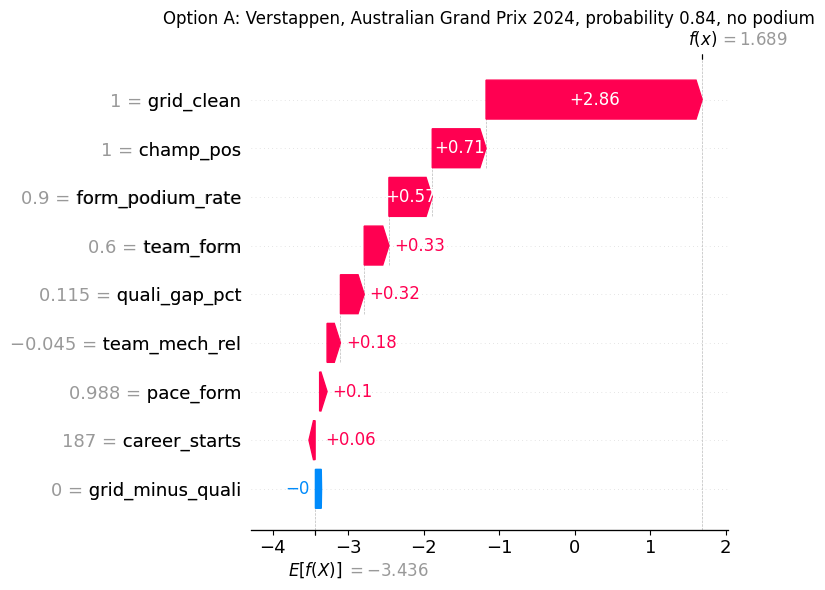

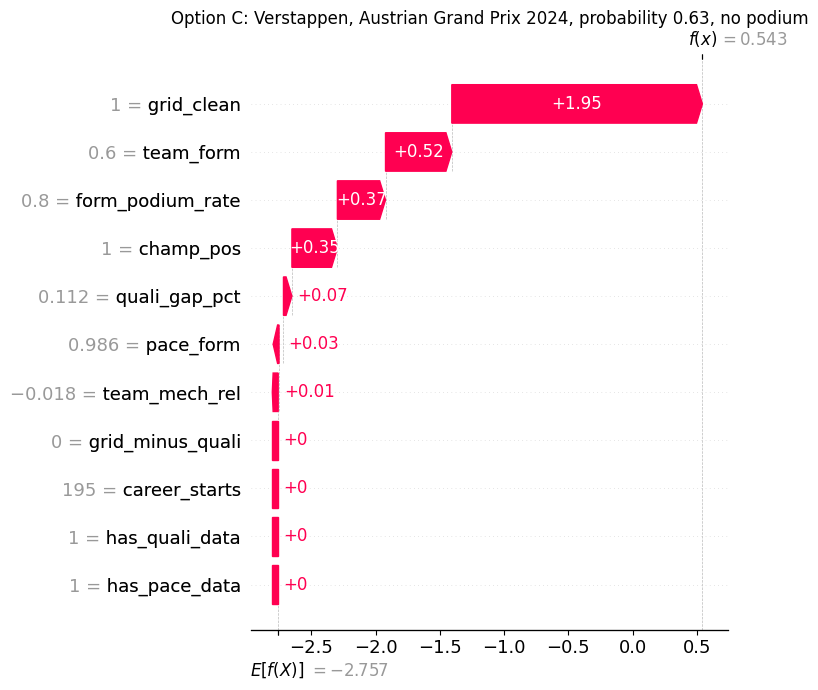

In [349]:
miss = {o: units[o][units[o].podium == 0].probability.idxmax() for o in XAI}   # the most confident prediction that missed the podium
for o in XAI:
    m = units[o].loc[miss[o]]
    outcome = (results_unique.loc[(results_unique.raceId == m.raceId) & (results_unique.driverId == m.driverId), ['positionOrder', 'statusId']]
               .merge(status, on='statusId').iloc[0])
    print(f'option {o}: {describe_row(miss[o])}: started P{int(m.grid_clean)}, probability {m.probability:.2f} '
          f'(the other model: {units["C" if o == "A" else "A"].loc[miss[o], "probability"]:.2f}) | '
          f'finished in position {int(outcome.positionOrder)} ({outcome.status})')
for o in XAI:
    waterfall(o, miss[o], 'xai_10_waterfall_miss', ', no podium')

**Reading.**
- **Option A: Verstappen, Australia 2024, from pole: probability 0.84, but he retired with a brake failure** and was classified 19th (option C gave him 0.62).
  - **Every feature pushes up**, so the explanation looks perfectly sensible: pole position (+2.86), leading the championship (+0.71), podiums in 9 of his last 10 starts (+0.57), team form (+0.33), a small qualifying gap (+0.32) and even a team that broke down less often than the field (+0.18).
  - **The miss comes from something the model cannot know at the cutoff:** a brake failure during the race. None of the features describes the race itself, only what was known the day before.
- **Option C: Verstappen, Austria 2024, from pole: probability 0.63**, and he finished the race 5th. Option A was even more sure (0.84). Again every feature pushes up: pole position (+1.95), team form (+0.52), his form (+0.37) and the championship position (+0.35). Nothing in the features showed that he would lose places in the race.
- **Option C's most confident miss is less confident than option A's** (0.63 against 0.84), because its probabilities are less extreme in general (11.2).
- **A high probability is not a promise.** Option A is well calibrated (11.3): of its predictions above 0.8, 82% reached the podium, so about one in five of them misses. Option C is under-confident: of its predictions between 0.6 and 0.7, 78% reached the podium, so its 0.63 for Verstappen understated his chance. One confident miss is not a sign that a model is wrong; many would be.

## 11.5 The same prediction explained with LIME

**How LIME works.** LIME explains one prediction with a small, simple model that only has to be right **near that driver**:
1. It makes 5,000 made-up drivers similar to the real one, by changing their feature values at random.
2. It asks the model for their probabilities.
3. It fits a straight-line model to them, giving more weight to the made-up drivers closest to the real one.

Each feature becomes a simple condition (for example `grid_clean <= 6`), and its weight says how much that condition raises or lowers the probability. It is applied to the driver from further back of each model (11.4), to compare with SHAP.

**The explainers.** LIME needs each model's training rows (in original units) to know the usual range of each feature, and a function that gives the model's probability for rows in original units. Option C's two extra features are 0 or 1, so LIME treats them as categories.

In [350]:
from lime.lime_tabular import LimeTabularExplainer

def predict_from_units(o):
    """Option o's model as a function of rows in original units: scale them first with the option's scaler (9.5)."""
    return lambda rows: xai_model[o].predict_proba(pd.DataFrame(opt_scaler[o].transform(pd.DataFrame(rows, columns=xai_F[o])), columns=xai_F[o]))

lime_explainer = {}
for o in XAI:
    train_units = opt_capped[o].loc[opt_X[o]['train'][0].index, xai_F[o]].astype(float)
    lime_explainer[o] = LimeTabularExplainer(train_units.values, feature_names=xai_F[o], class_names=['no podium', 'podium'], mode='classification',
                                             categorical_features=[k for k, f in enumerate(xai_F[o]) if f in FLAGS], random_state=0)
    print(f'option {o}: LIME explainer built on the {len(train_units)} training rows ({OPTIONS[o][0]}-{TRAIN[1]})')

option A: LIME explainer built on the 6407 training rows (2003-2018)
option C: LIME explainer built on the 22362 training rows (1950-2018)


**The explanations.** The weight of each condition, and the probability LIME's simple model gives compared with the real model's.

In [351]:
lime_result = {}
for o in XAI:
    i = from_back[o]
    lime_result[o] = lime_explainer[o].explain_instance(X_explain_units[o].loc[i].values, predict_from_units(o), num_features=len(xai_F[o]))
    display(pd.DataFrame(lime_result[o].as_list(), columns=['condition', 'weight']).style.format({'weight': '{:+.3f}'})
            .hide(axis='index').set_caption(f'Option {o}, LIME: {describe_row(i)}'))
    print(f"option {o}: probability from LIME's simple model {lime_result[o].local_pred[0]:.2f} | from the real model {units[o].loc[i, 'probability']:.2f}")

condition,weight
grid_clean <= 6.00,+0.181
form_podium_rate > 0.20,+0.045
champ_pos <= 6.00,+0.044
team_form > 0.25,+0.038
quali_gap_pct <= 0.73,+0.031
pace_form <= 0.99,+0.013
team_mech_rel <= -0.05,+0.009
career_starts > 146.00,+0.008
grid_minus_quali <= 0.00,+0.007


option A: probability from LIME's simple model 0.35 | from the real model 0.50


condition,weight
grid_clean <= 6.00,+0.211
team_form > 0.21,+0.056
champ_pos <= 6.00,+0.033
form_podium_rate > 0.20,+0.033
grid_minus_quali <= 0.00,+0.006
-0.01 < team_mech_rel <= 0.07,-0.003
quali_gap_pct <= 1.53,+0.003
career_starts > 89.00,+0.001
has_pace_data=1,-0.001
pace_form <= 1.00,-0.000


option C: probability from LIME's simple model 0.35 | from the real model 0.42


**Chart.** Green raises the probability, red lowers it.

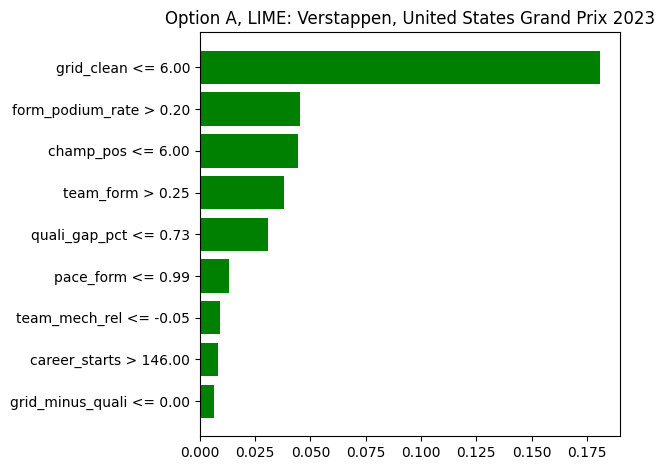

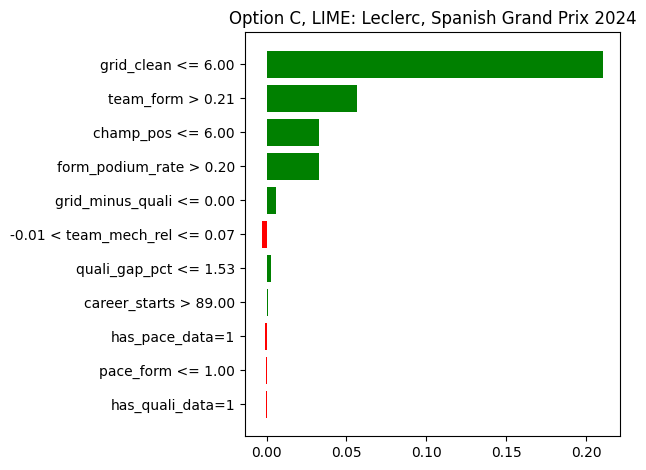

In [352]:
for o in XAI:
    lime_result[o].as_pyplot_figure()
    plt.title(f'Option {o}, LIME: {describe_row(from_back[o])}')
    plt.tight_layout(); savefig(fig_name('xai_07_lime', o)); plt.show()

**Reading.**
- **Option A, Verstappen, United States 2023: LIME agrees with SHAP on the features, but not on their order.** Every condition raises the probability, as in the waterfall (11.4). LIME puts the grid first (`grid_clean <= 6`: +0.181), and then driver form, the championship position and team form (+0.038 to +0.045). SHAP put the grid only 3rd, after driver form and the championship position.
- **Why the sizes differ.** LIME's conditions are broad ("6th or better" covers P1 to P6) and are compared with made-up drivers from all over the grid, so the grid condition separates them most. Its weights are also in probability, while SHAP's contributions are in the model's score (log-odds), so the two sets of numbers cannot be compared directly.
- **Option C, Leclerc, Spain 2024: LIME and SHAP agree on the features and on their order:** the grid (+0.211), team form (+0.056), the championship position (+0.033) and driver form (+0.033). Every other condition, the two extra features included, gets a weight of 0.006 or less, as in SHAP: LIME also finds that option C uses only these four features.
- **LIME is only approximate:** its simple model gives 0.35 for both drivers, while the real models give 0.50 and 0.42. SHAP's contributions add up exactly to the model's score (11.2). LIME also depends on random samples (the seed is fixed here).
- So both methods agree on **which features** explain these two predictions. SHAP is the more exact of the two for a tree model, which is why it is the main method in this section.

## 11.6 A whole race explained

**Why.** The models score every driver on their own: they do not know that each race has exactly three podiums (10.5). Looking at all the drivers of one race shows what this means in practice, and which feature drives each driver's probability.

**Which race.** The race of option A's most confident wrong prediction (11.4), chosen by that rule rather than by hand. Both models are shown for the same race.

In [353]:
race_id = units['A'].loc[miss['A'], 'raceId']
race_idx = units['A'][units['A'].raceId == race_id].sort_values('probability', ascending=False).index

def biggest(r, exclude=()):
    """The feature with the largest push (either direction) in a row of SHAP values, as 'feature +value'."""
    r = r.drop(list(exclude)); f = r.abs().idxmax()
    return f'{f} {r[f]:+.2f}'

race_table = pd.DataFrame({'driver': units['A'].loc[race_idx, 'driverId'].map(surname),
                           'grid': units['A'].loc[race_idx, 'grid_clean'].astype(int),
                           'podium': units['A'].loc[race_idx, 'podium'].astype(bool)})
for o in XAI:
    race_shap = pd.DataFrame(shap_values[o].values[[X_explain[o].index.get_loc(i) for i in race_idx]], columns=xai_F[o], index=race_idx)
    p = units[o].loc[race_idx, 'probability']
    race_table[f'probability, {o}'] = p
    race_table[f'top 3 of {o}'] = p.rank(ascending=False, method='first') <= 3
    race_table[f'biggest push apart from the grid, {o}'] = race_shap.apply(biggest, axis=1, exclude=['grid_clean'])
race_name = f'{race_name_of[race_id]} {int(units["A"].loc[race_idx[0], "year"])}'
display(race_table.style.format({f'probability, {o}': '{:.2f}' for o in XAI}).hide(axis='index')
        .set_caption(f"Every driver of the {race_name}, by option A's probability"))
for o in XAI:
    print(f'option {o}: sum of the probabilities {race_table[f"probability, {o}"].sum():.2f} (a race has exactly 3 podiums) | '
          f'podiums among its top 3: {race_table.loc[race_table[f"top 3 of {o}"], "podium"].sum()}')
print(f'podiums among the top 3 on the grid: {race_table.loc[race_table.grid <= 3, "podium"].sum()}')

driver,grid,podium,"probability, A",top 3 of A,"biggest push apart from the grid, A","probability, C",top 3 of C,"biggest push apart from the grid, C"
Verstappen,1,False,0.84,True,champ_pos +0.71,0.62,True,team_form +0.51
Sainz,2,True,0.60,True,champ_pos +0.35,0.53,True,team_form +0.48
Norris,3,True,0.50,True,form_podium_rate +0.61,0.45,True,team_form +0.47
Leclerc,4,True,0.34,False,team_form +0.44,0.43,False,team_form +0.45
Pérez,6,False,0.26,False,champ_pos +0.66,0.34,False,team_form +0.47
Piastri,5,False,0.25,False,team_form +0.46,0.31,False,team_form +0.43
Russell,7,False,0.09,False,champ_pos +0.43,0.19,False,team_form +0.33
Alonso,10,False,0.04,False,quali_gap_pct +0.24,0.04,False,team_form -0.28
Stroll,9,False,0.03,False,quali_gap_pct +0.30,0.06,False,team_form -0.28
Tsunoda,8,False,0.02,False,quali_gap_pct +0.30,0.08,False,team_form -0.32


option A: sum of the probabilities 3.03 (a race has exactly 3 podiums) | podiums among its top 3: 2
option C: sum of the probabilities 3.24 (a race has exactly 3 podiums) | podiums among its top 3: 2
podiums among the top 3 on the grid: 2


**Chart.** Two bars per driver, in the order of option A's probability. Dark bars reached the podium; the label is the grid slot.

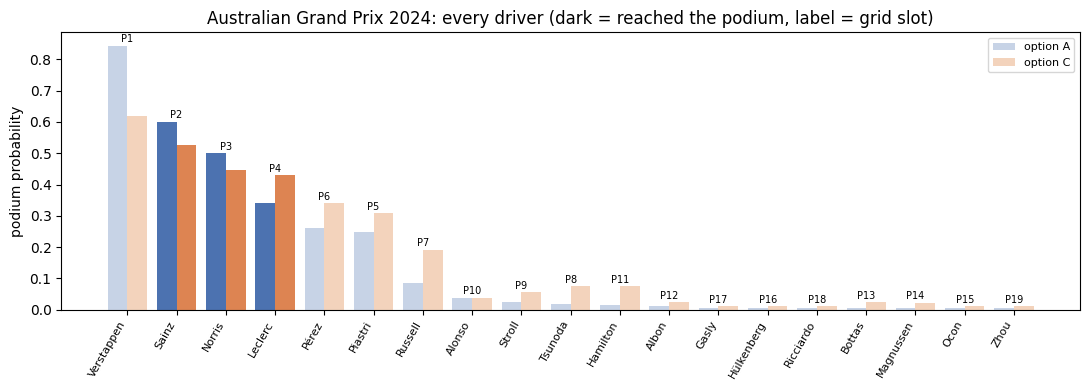

In [354]:
x = np.arange(len(race_table))
fig, ax = plt.subplots(figsize=(11, 4))
for shift, o, colors in [(-0.2, 'A', ('#4C72B0', '#C7D3E6')), (0.2, 'C', ('#DD8452', '#F3D3BC'))]:
    ax.bar(x + shift, race_table[f'probability, {o}'], width=0.4, color=np.where(race_table.podium, *colors), label=f'option {o}')
for k, (p, g) in enumerate(zip(race_table[['probability, A', 'probability, C']].max(axis=1), race_table.grid)):
    ax.text(k, p + 0.01, f'P{g}', ha='center', fontsize=7)                  # the grid slot above each pair of bars
ax.set_xticks(x); ax.set_xticklabels(race_table.driver, rotation=60, ha='right', fontsize=8)
ax.set(ylabel='podium probability', title=f'{race_name}: every driver (dark = reached the podium, label = grid slot)')
ax.legend(fontsize=8); plt.tight_layout(); savefig('xai_11_whole_race'); plt.show()

**Reading.**
- **Both models' top 3 are the top 3 on the grid** (Verstappen P1, Sainz P2, Norris P3), and both get 2 of the 3 podiums right: Verstappen retired, and Leclerc (P4) took his place. Leclerc is the 4th pick of both models (0.34 in A, 0.43 in C).
- **The probabilities add up to 3.03 in option A and 3.24 in option C**, close to 3 here. Nothing forces this: each driver is scored on their own, so in other races the sum can be well above or below 3 (10.5).
- **The grid sets the order, the other features adjust it.**
  - Both models place Pérez (P6) just above Piastri (P5). In option A the reason is his 2nd place in the championship (+0.66); in option C it is Red Bull's team form (+0.47).
  - **In option C, team form is the biggest push apart from the grid for every driver:** up for the top teams (+0.33 to +0.51), down for the others (about −0.3 to −0.4). In option A it is the championship position for most of the front, and the qualifying gap for most of the midfield.
- **Behind P10, the grid decides almost everything.** Option A gives every driver 0.01 or less. Option C gives a little more to drivers of strong teams, such as Hamilton from P11 (0.08, Mercedes' team form +0.50), and 0.03 or less to the others.
- **This is the main limitation in one picture:** the models rank the drivers almost like the grid. They improve the probabilities but rarely change who is in the top 3, which is why they pick the podium little better than the grid (10.9).

## 11.7 What the explanations show, and what they do not

- **They describe the models, not Formula 1.** A feature that is important to a model is **not proof that it causes podium finishes**. It only means that the model relies on it to make predictions.
- **Example:** the championship position is the second most important feature of option A, but leading the championship does not make a driver faster. A fast car and a good driver cause both the good championship position and the podiums; the model cannot see those directly, so it uses the championship position instead.
- **Two models, two explanations.** Options A and C score almost the same on the test (0.717 and 0.704, 10.9), yet option A uses all 9 features with the championship position second, and option C uses 4 of its 11 with team form second (11.2, 11.3). Features that overlap can stand in for each other, so the importance of one of them says more about the model than about the race.
- **A feature the model does not use is not useless either.** Option C ignores the qualifying gap and pace, but option A uses them, and both are strong on their own (7.2, 7.8).
- **The grid is the same:** starting at the front helps, but the grid slot also shows how fast the car was in qualifying. The models cannot separate the two.
- **Overlapping features share their importance.** A feature with little importance can still carry real information that another feature already gives: one at a time, the history features barely matter when shuffled, but together they lower the test PR-AUC by 0.193 in option A and 0.201 in option C (11.1, *Shuffling a whole group at once*).
- **They hold for these models and these seasons** (2022–2024). Another model, or other seasons, could rely on the features differently.

# 12. Inference function

**What it is.** A function that uses one of the two models carried forward (10.6) to predict **one new record**: one driver in one race, at the prediction cutoff (qualifying is over and the grid is set). It is what would be run before a real race. The option is a parameter (`'A'` or `'C'`), and both models are shown for every example.

**What it does, in order** (the same steps as for the test part in 9.2–9.5 and 10.9):
1. **Takes the features of the option** in their original units: the 9 features, and in option C also `has_quali_data` and `has_pace_data` (1 if the race has qualifying times or lap times, as for every race since 2003). Any of the 9 can be missing except `grid_clean` and `career_starts`, which are always known at the cutoff (the grid is set, and career starts are a count, 0 for a rookie); the two extra features are always known.
2. **Fills the missing values** with the rules of 9.2, using the values learned from the option's own training part (`opt_learned[option]`).
3. **Caps extreme values** as in 9.3 (`opt_caps[option]`) and **scales** them as in 9.5 (`opt_scaler[option]`).
4. **Runs the model** (`opt_gb[option]`, as reported in 10.9) and returns the podium probability, a yes/no prediction at the F1 threshold chosen on validation (`opt_gb_threshold[option]`, 10.3), and a table of the values the model actually used.

**One rule needs the race.** A missing `champ_pos` is filled with the worst championship position in the same race + 1 (9.2), so for such a record the function must also be given the worst championship position among the other drivers of the race.

In [355]:
ALWAYS_KNOWN = ['grid_clean', 'career_starts'] + FLAGS                   # known for every driver at the cutoff: no fill rule

def predict_podium(record, option='A', race_worst_champ_pos=None):
    """Podium prediction of the model carried forward in `option` ('A' or 'C') for one driver in one race.

    record: the option's features in original units (a missing one can be None, NaN or left out, except grid_clean,
            career_starts and, in option C, the two extra features), and optionally 'quali_prev_median', the driver's
            median qualifying gap over the previous 10 starts (used to fill quali_gap_pct).
    race_worst_champ_pos: the worst championship position among the other drivers of the race (needed only to fill a missing champ_pos).
    """
    assert option in XAI, f'option must be one of {XAI}'
    feats = OPTIONS[option][1]
    row = pd.DataFrame([{f: record.get(f) for f in feats + ['quali_prev_median']}]).astype(float)
    given = row.loc[0, feats].copy()                                        # the values as they arrived
    missing = [f for f in feats if pd.isna(row.at[0, f])]
    if [f for f in missing if f in ALWAYS_KNOWN]:
        raise ValueError(f'{[f for f in missing if f in ALWAYS_KNOWN]} must be given: they are known for every driver at the cutoff')
    row['raceId'] = 0                                                       # one race: apply_fill groups by race
    if 'champ_pos' in missing:                                              # the 9.2 rule: worst in the race + 1
        if race_worst_champ_pos is None:
            raise ValueError('champ_pos is missing: give race_worst_champ_pos, the worst championship position in the race')
        row.at[0, 'champ_pos'] = race_worst_champ_pos + 1
    used = apply_caps(apply_fill(row, opt_learned[option]), opt_caps[option])   # fill (9.2) and cap (9.3), learned on the option's training part
    X = pd.DataFrame(opt_scaler[option].transform(used[feats]), columns=feats)  # scale (9.5)
    p = float(opt_gb[option].predict_proba(X)[0, 1])
    values = pd.DataFrame({'given': given, 'used by the model': used.loc[0, feats], 'filled': [f in missing for f in feats]})
    return {'option': option, 'probability': p, 'threshold': opt_gb_threshold[option],
            'predicted podium': p >= opt_gb_threshold[option], 'values': values}

def show_predictions(record, title, race_worst_champ_pos=None):
    """Predict one record with both models; show the values given and used, the probabilities and the yes/no answers."""
    res = {o: predict_podium(record, o, race_worst_champ_pos) for o in XAI}
    values = res['C']['values'][['given', 'filled']].join(
        pd.DataFrame({f'used by option {o}': res[o]['values']['used by the model'] for o in XAI}))
    display(values.style.format({c: '{:.3f}' for c in values.columns if c != 'filled'}, na_rep='–').set_caption(title))
    for o, r in res.items():
        print(f"option {o}: podium probability {r['probability']:.2f} | predicted podium: {'yes' if r['predicted podium'] else 'no'} "
              f"(threshold {r['threshold']:.3f}, chosen on validation in 10.3)")
    return res

def record_of(i):
    """A row of the modelling table as a record in original units, before filling, as it would arrive before a race."""
    return opt_data['C'].loc[i, F + FLAGS + ['quali_prev_median']].to_dict()

def check_same(res, i):
    """Does the function give exactly the probability each model gave this test row in 10.9?"""
    k = test_rows.index.get_loc(i)
    print(f"actual result: {'podium' if test_rows.loc[i, 'podium'] else 'no podium'} | same probability as in 10.9: "
          + ', '.join(f'option {o} {np.isclose(r["probability"], xai_prob[o][k])}' for o, r in res.items()))

## 12.1 A complete record

The driver from further back that option A was most sure about (11.4): every feature is known. The last line checks that the function gives exactly the probability each model gave this row in the test part (10.9).

In [356]:
i = from_back['A']
result = show_predictions(record_of(i), f'Complete record: {describe_row(i)}')
check_same(result, i)

,given,filled,used by option A,used by option C
grid_clean,6.000,False,6.000,6.000
grid_minus_quali,0.000,False,0.000,0.000
quali_gap_pct,0.268,False,0.268,0.268
form_podium_rate,0.900,False,0.900,0.900
career_starts,180.000,False,180.000,180.000
champ_pos,1.000,False,1.000,1.000
team_form,0.650,False,0.650,0.650
team_mech_rel,-0.052,False,-0.052,-0.052
pace_form,0.988,False,0.988,0.988
has_quali_data,1.000,False,–,1.000


option A: podium probability 0.50 | predicted podium: yes (threshold 0.345, chosen on validation in 10.3)
option C: podium probability 0.37 | predicted podium: yes (threshold 0.362, chosen on validation in 10.3)
actual result: podium | same probability as in 10.9: option A True, option C True


**Reading.**
- **Nothing was filled:** every feature arrived with a value, so the columns *given* and *used by option A / C* are the same (`filled` is False everywhere). Option A does not use the two extra features (–).
- **Podium probability 0.50 from option A and 0.37 from option C**, both above their thresholds (0.345 and 0.362), so both answer "podium". Verstappen did reach the podium. Option C's answer is only just above its threshold, because its probabilities are less extreme (11.2).
- **"Same probability as in 10.9: True" for both models:** the function gives exactly the probability the notebook computed for this row in the final test, so it repeats the notebook's steps correctly for each option.

## 12.2 A partially-missing record

The test record with the **most missing features**, chosen by that rule. It is given to the function as it would arrive before the race, with the gaps left empty, together with the worst championship position of the other drivers in that race. The check is the same as above.

In [357]:
test_part = opt_data['C'].loc[test_rows.index]
j = test_part[F].isna().sum(axis=1).idxmax()                                # the test record with the most missing features
race_worst = test_part.loc[test_part.raceId == test_part.loc[j, 'raceId'], 'champ_pos'].max()

result = show_predictions(record_of(j), f'Partially-missing record: {describe_row(j)} ({test_part.loc[j, F].isna().sum()} of 9 features missing)',
                          race_worst_champ_pos=race_worst)
check_same(result, j)

,given,filled,used by option A,used by option C
grid_clean,15.000,False,15.000,15.000
grid_minus_quali,0.000,False,0.000,0.000
quali_gap_pct,1.117,False,1.117,1.117
form_podium_rate,–,True,0.000,0.000
career_starts,0.000,False,0.000,0.000
champ_pos,–,True,20.000,20.000
team_form,0.000,False,0.000,0.000
team_mech_rel,0.003,False,0.003,0.003
pace_form,–,True,1.000,1.000
has_quali_data,1.000,False,–,1.000


option A: podium probability 0.01 | predicted podium: no (threshold 0.345, chosen on validation in 10.3)
option C: podium probability 0.01 | predicted podium: no (threshold 0.362, chosen on validation in 10.3)
actual result: no podium | same probability as in 10.9: option A True, option C True


**Reading.**
- **The record:** Zhou at the Bahrain Grand Prix 2022, his **first Formula 1 race**. Three of the 9 features are missing (driver form, championship position and race pace), because none of them exists before a driver's first race.
- **How the gaps were filled** (columns *used by option A / C*, rules of 9.2):
  - `form_podium_rate` → **0**: he has no podium yet;
  - `champ_pos` → **20**: the worst championship position among the other drivers of the race (19) + 1, behind every driver who has a standing. Albon, Magnussen and Hülkenberg, back after a season out, had none either and are also filled with 20;
  - `pace_form` → **1.000**, the training median of each option: he is treated as a typical driver.
- **Podium probability practically 0 (0.01 from both models), so both answer "no podium"** from 15th on the grid. He did not reach the podium.
- **"Same probability as in 10.9: True" for both models:** the filled record gives exactly the notebook's probability for this row.
- **In short:** the function handles every value that can be missing at the cutoff, for both options. Each of those 7 features has a fill rule, learned only from the option's own training part (for a missing championship position it also needs the worst position in the race), so it can predict for rookies and new teams as well as for regular drivers. `grid_clean`, `career_starts` and option C's two extra features are always known before the race, so they need no fill rule, and the function refuses a record without them.